<a href="https://colab.research.google.com/github/Anik00223/3D-planets/blob/main/WasteLens_ConvNeXt_XL_Organized.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WasteLens ConvNeXt-XL Classification - Organized Notebook

This notebook is organized into sections with simple headings.
All original code cells are kept exactly as they were - nothing was changed,
deleted, or reordered.

## Table of Contents

1. [Importing the Tools](#importing-the-tools)
2. [Checking the Dataset](#checking-the-dataset)
3. [Finding OOD Images](#finding-ood-images)
4. [Reviewing OOD Candidates](#reviewing-ood-candidates)
5. [Connecting to Google Drive](#connecting-to-google-drive)
6. [OOD Details and Screening](#ood-details-and-screening)
7. [Checking Data Quality](#checking-data-quality)
8. [Setting Rejection Thresholds](#setting-rejection-thresholds)
9. [Reviewing Preprocessing](#reviewing-preprocessing)
10. [Finding Old Code](#finding-old-code)
11. [More OOD Review](#more-ood-review)
12. [Drive Paths and More OOD](#drive-paths-and-more-ood)
13. [Checking Manifests](#checking-manifests)
14. [More OOD Candidates](#more-ood-candidates)
15. [Testing the Model](#testing-the-model)
16. [Building a Web Demo](#building-a-web-demo)
17. [Manifests, Metrics, and Experiments](#manifests-metrics-and-experiments)
18. [Drive and File Paths](#drive-and-file-paths)
19. [Loading the Model](#loading-the-model)
20. [Checking PyTorch and Settings](#checking-pytorch-and-settings)
21. [Installing Tools](#installing-tools)
22. [Mapping the Dataset](#mapping-the-dataset)
23. [Model and Transforms](#model-and-transforms)
24. [Training Step](#training-step)
25. [Saving Results](#saving-results)
26. [PyTorch and GPU Check](#pytorch-and-gpu-check)
27. [Counting Images](#counting-images)


## 1. Importing the Tools

Import the Python libraries we need for the rest of the notebook.


In [ ]:
import torch
import timm
import os
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cpu
timm: 1.0.30
CUDA: False


## 2. Checking the Dataset

Look at the data files and make sure they are correct: where images are stored,
whether file lists match actual files, and whether anything is missing.


In [ ]:
# FINAL PILOT AUDIT — read-only; no files modified

from pathlib import Path
import json
import pandas as pd

EXP = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

paths = {
    "report": EXP / "pilot_rejection_experiment_report_v2.md",
    "summary": EXP / "pilot_rejection_experiment_summary_v2.json",
    "final_metrics": EXP / "pilot_rejection_experiment_metrics_v2.csv",
    "predictions": EXP / (
        "pilot_saved_rejection_head_predictions_preprocess_v2_"
        "20261024T203753Z.csv"
    ),
    "scoring_summary": EXP / (
        "pilot_saved_rejection_head_summary_preprocess_v2_"
        "20261024T203753Z.json"
    ),
    "manifest": EXP / (
        "pilot_batch_v2_with_ood_heldout_validation_"
        "compost_approved_v6.csv"
    ),
}

print("=== WASTELENS FINAL PILOT AUDIT ===")
missing = [name for name, path in paths.items()
           if not path.is_file() or path.stat().st_size == 0]

for name, path in paths.items():
    ok = path.is_file() and path.stat().st_size > 0
    print(f"{'PASS' if ok else 'FAIL'} | {name}: {path.name}")

if missing:
    print("\nMissing or empty files:", missing)
    print("Audit incomplete. Do not rerun training.")
else:
    summary = json.loads(paths["summary"].read_text(encoding="utf-8"))
    score_summary = json.loads(
        paths["scoring_summary"].read_text(encoding="utf-8")
    )
    predictions = pd.read_csv(paths["predictions"], keep_default_na=False)
    metrics = pd.read_csv(paths["final_metrics"], keep_default_na=False)
    report_text = paths["report"].read_text(encoding="utf-8").lower()

    def norm(value):
        return " ".join(
            str(value).strip().lower().replace("_", " ").split()
        )

    def truth(value):
        return str(value).strip().lower() in {"true", "1", "yes"}

    supported = predictions[
        ~predictions["target_label"].map(norm).isin(
            {"unsupported", "ood", "out of distribution"}
        )
    ]
    ood = predictions[
        predictions["target_label"].map(norm).isin(
            {"unsupported", "ood", "out of distribution"}
        )
    ]

    print("\n--- Counts and integrity ---")
    print("Manifest slots:", len(pd.read_csv(paths["manifest"])))
    print("Predictions:", len(predictions))
    print("Supported predictions:", len(supported))
    print("OOD predictions:", len(ood))

    print("\n--- Safeguards ---")
    print("Weights modified:", summary.get("model_weights_modified"))
    print("Locked test accessed:", summary.get("locked_test_set_accessed"))
    print("Thresholds refit:", summary.get("thresholds_refit_on_pilot"))
    print("Checkpoint hash matches scoring summary:",
          summary.get("backbone_checkpoint_sha256")
          == score_summary.get("backbone_checkpoint_sha256"))

    print("\n--- Threshold metrics ---")
    print(metrics.to_string(index=False))

    print("\n--- Report content checks ---")
    for phrase in [
        "0.015873", "0.004552", "preprocessing",
        "deployment", "independent",
    ]:
        print(f"{'PASS' if phrase in report_text else 'CHECK'} | {phrase}")

    # Expected corrected-pilot results.
    expected = {
        0.015873: (1, 0.25, 3, 1.0, 0.0),
        0.004552: (2, 0.50, 3, 1.0, 0.0),
    }

    required_columns = {
        "threshold", "supported_false_rejections_on_pilot",
        "supported_false_rejection_rate_on_pilot",
        "ood_detected_on_pilot", "ood_recall_on_pilot",
        "ood_false_acceptance_rate_on_pilot",
    }

    print("\n--- Numeric consistency ---")
    if not required_columns.issubset(metrics.columns):
        print("CHECK | Metrics columns differ from expected schema.")
    else:
        for target_threshold, exp_values in expected.items():
            numeric_thresholds = pd.to_numeric(metrics["threshold"])
            matches = metrics[
                (numeric_thresholds - target_threshold).abs() < 0.00001
            ]

            if len(matches) != 1:
                print(f"CHECK | Threshold near {target_threshold} missing/duplicated.")
                continue

            row = matches.iloc[0]
            actual = (
                int(row["supported_false_rejections_on_pilot"]),
                float(row["supported_false_rejection_rate_on_pilot"]),
                int(row["ood_detected_on_pilot"]),
                float(row["ood_recall_on_pilot"]),
                float(row["ood_false_acceptance_rate_on_pilot"]),
            )
            print(
                f"{'PASS' if actual == exp_values else 'CHECK'} | "
                f"threshold {target_threshold}: expected={exp_values}, actual={actual}"
            )

    basic_ok = (
        summary.get("report_version") == 2
        and len(predictions) == 7
        and len(supported) == 4
        and len(ood) == 3
        and summary.get("model_weights_modified") is False
        and summary.get("locked_test_set_accessed") is False
        and summary.get("thresholds_refit_on_pilot") is False
        and summary.get("backbone_checkpoint_sha256")
            == score_summary.get("backbone_checkpoint_sha256")
    )

    print("\n=== AUDIT RESULT ===")
    print("PASS — core pilot artifacts and safeguards verified"
          if basic_ok else
          "CHECK REQUIRED — inspect the output above before marking complete.")
    print("No files were modified.")

=== WASTELENS FINAL PILOT AUDIT ===
PASS | report: pilot_rejection_experiment_report_v2.md
PASS | summary: pilot_rejection_experiment_summary_v2.json
PASS | final_metrics: pilot_rejection_experiment_metrics_v2.csv
PASS | predictions: pilot_saved_rejection_head_predictions_preprocess_v2_20261024T203753Z.csv
PASS | scoring_summary: pilot_saved_rejection_head_summary_preprocess_v2_20261024T203753Z.json
PASS | manifest: pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv

--- Counts and integrity ---
Manifest slots: 26
Predictions: 7
Supported predictions: 4
OOD predictions: 3

--- Safeguards ---
Weights modified: False
Locked test accessed: False
Thresholds refit: False
Checkpoint hash matches scoring summary: True

--- Threshold metrics ---
                       method  prior_calibration_target_false_rejection_rate  threshold  supported_count  supported_correct_classifications_before_rejection  supported_false_rejections_on_pilot  supported_false_rejection_rate_on_pilot  

In [ ]:
# STEP 76 — WasteLens dataset provenance inventory
# Read-only: does not change images, manifests, weights, or thresholds.

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/WasteLens")

if not ROOT.exists():
    raise FileNotFoundError(
        f"WasteLens folder not found: {ROOT}. Check that Google Drive is mounted."
    )

KEYWORDS = (
    "manifest", "split", "dataset", "rejection", "fresh",
    "test", "train", "audit", "feature", "calibration",
    "validation", "benchmark", "prediction"
)

SKIP_DIRS = {
    ".git", "__pycache__", "node_modules",
    "acquired_images_v2", "checkpoints", ".cache"
}

MAX_FILE_SIZE = 15 * 1024 * 1024
MAX_FILES_TO_PRINT = 60

candidates = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue
    if path.suffix.lower() not in {".csv", ".json"}:
        continue
    if any(part in SKIP_DIRS for part in path.parts):
        continue
    if not any(term in path.name.lower() for term in KEYWORDS):
        continue

    try:
        size = path.stat().st_size
        if size <= MAX_FILE_SIZE:
            candidates.append(path)
    except OSError:
        pass

print("=== WASTELENS DATA PROVENANCE INVENTORY ===")
print("Metadata files found:", len(candidates))

for path in sorted(candidates):
    print("\n" + "-" * 88)
    print("FILE:", path.relative_to(ROOT))
    print("SIZE:", f"{path.stat().st_size:,} bytes")

    try:
        if path.suffix.lower() == ".csv":
            df = pd.read_csv(path, keep_default_na=False, low_memory=False)
            print("ROWS:", len(df))
            print("COLUMNS:", ", ".join(map(str, df.columns)))

            for col in df.columns:
                col_lower = str(col).lower()
                if any(term in col_lower for term in (
                    "split", "partition", "subset"
                )):
                    counts = df[col].astype(str).value_counts().head(12)
                    print(f"{col} counts:", counts.to_dict())

                if any(term in col_lower for term in (
                    "target_label", "class_name", "class", "label", "category"
                )):
                    counts = df[col].astype(str).value_counts().head(15)
                    print(f"{col} counts:", counts.to_dict())

            # Show useful provenance column names, not full private paths.
            provenance_cols = [
                col for col in df.columns
                if any(term in str(col).lower() for term in (
                    "sha256", "sha1", "hash", "source_url", "license",
                    "licence", "source_id", "group", "duplicate"
                ))
            ]
            if provenance_cols:
                print("Provenance columns:", provenance_cols)

        else:
            obj = json.loads(path.read_text(encoding="utf-8"))
            if isinstance(obj, dict):
                print("TOP-LEVEL KEYS:", list(obj.keys())[:35])

                for key, value in obj.items():
                    key_lower = str(key).lower()
                    if any(term in key_lower for term in (
                        "count", "split", "dataset", "source",
                        "fresh", "test", "validation", "train",
                        "checkpoint", "feature_dim", "method",
                        "limitations", "threshold"
                    )):
                        rendered = repr(value)
                        print(f"{key}: {rendered[:700]}")
            elif isinstance(obj, list):
                print("JSON LIST LENGTH:", len(obj))
                if obj and isinstance(obj[0], dict):
                    print("FIRST ITEM KEYS:", list(obj[0].keys())[:25])

    except Exception as exc:
        print("Could not inspect this file:", type(exc).__name__, str(exc)[:200])

print("\n=== END OF INVENTORY ===")
print("No files were modified.")

=== WASTELENS DATA PROVENANCE INVENTORY ===
Metadata files found: 66

----------------------------------------------------------------------------------------
FILE: convnext_xl/adaptation_experiment/logs/post_adaptation_fresh_diagnostic.csv
SIZE: 9,064 bytes
ROWS: 131
COLUMNS: relative_path, actual_label, predicted_label, confidence, correct
actual_label counts: {'': 131}
predicted_label counts: {'recyclable': 56, 'organic': 34, 'hazardous': 21, 'general trash': 20}

----------------------------------------------------------------------------------------
FILE: convnext_xl/adaptation_experiment/logs/post_adaptation_test_predictions.csv
SIZE: 116,035 bytes
ROWS: 1233
COLUMNS: relative_path, actual_label, predicted_label, confidence, correct
actual_label counts: {'recyclable': 839, 'organic': 148, 'hazardous': 142, 'general trash': 104}
predicted_label counts: {'recyclable': 829, 'organic': 151, 'hazardous': 149, 'general trash': 104}

-----------------------------------------------------

In [ ]:
# STEP 77 — WasteLens manifest reconciliation and split-leakage audit
# READ-ONLY: never opens locked-test images and never writes any files.

from pathlib import Path
from itertools import combinations
import hashlib
import pandas as pd

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"

MANIFEST_NAMES = [
    "data_acquisition_manifest.csv",
    "data_acquisition_manifest_v1_570.csv",
    "data_acquisition_manifest_v2.csv",
]

if not EXP.is_dir():
    raise FileNotFoundError(
        f"Experiment folder not found: {EXP}\n"
        "Check that Google Drive is mounted."
    )

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def first_col(df, aliases):
    for col in aliases:
        if col in df.columns:
            return col
    return None

def clean(value):
    if pd.isna(value):
        return ""
    return str(value).strip()

def normalize_split(value):
    s = clean(value).lower().replace("-", "_").replace(" ", "_")
    if "locked" in s or s in {"test", "final_test", "heldout_test"}:
        return "locked_test"
    if "threshold" in s or "calibration" in s or s in {
        "val", "validation", "adapt_val", "reject_val"
    }:
        return "threshold_validation"
    if s in {"train", "training", "adapt_train", "reject_train"}:
        return "train"
    return s or "missing_split"

def resolve_dev_path(value, manifest_path):
    """Resolve a development image path without opening its contents."""
    raw = clean(value)
    if not raw:
        return None

    p = Path(raw)
    candidates = [p] if p.is_absolute() else [
        manifest_path.parent / p,
        EXP / p,
        ROOT / p,
    ]

    for candidate in candidates:
        try:
            if candidate.is_file():
                return candidate
        except OSError:
            pass

    return candidates[0]

frames = {}
meta = {}
missing_manifests = []

print("=" * 76)
print("WASTELENS — MANIFEST RECONCILIATION")
print("=" * 76)

for name in MANIFEST_NAMES:
    path = EXP / name
    if not path.is_file():
        missing_manifests.append(name)
        print(f"\nNOT FOUND: {name}")
        continue

    df = pd.read_csv(path, keep_default_na=False, low_memory=False)

    split_col = first_col(df, ["split", "partition", "subset"])
    slot_col = first_col(df, ["slot_id", "sample_id", "id"])
    label_col = first_col(df, ["target_label", "label", "class_name"])
    path_col = first_col(df, ["image_path", "local_path", "file_path", "path"])
    hash_col = first_col(df, ["sha256", "actual_sha256", "file_sha256"])
    group_col = first_col(df, ["source_group_id", "group_id", "source_group"])
    source_col = first_col(df, ["source_url_or_origin", "source_url", "source_page_url"])
    license_col = first_col(df, ["license_or_permission", "license", "licence"])

    if split_col is None:
        raise ValueError(f"{name} has no recognizable split column.")

    split_norm = df[split_col].map(normalize_split)
    frames[name] = df
    meta[name] = {
        "path": path,
        "split_col": split_col,
        "slot_col": slot_col,
        "label_col": label_col,
        "path_col": path_col,
        "hash_col": hash_col,
        "group_col": group_col,
        "source_col": source_col,
        "license_col": license_col,
        "split_norm": split_norm,
    }

    print(f"\n--- {name} ---")
    print("Rows:", len(df))
    print("Manifest SHA-256:", sha256_file(path))
    print("Columns:", len(df.columns))
    print("Split counts:", split_norm.value_counts().to_dict())

    if label_col:
        view = pd.DataFrame({
            "split": split_norm,
            "label": df[label_col].map(clean),
        })
        print("Class counts by split:")
        print(pd.crosstab(view["split"], view["label"]).to_string())

    if slot_col:
        print("Duplicate slot IDs:", int(df[slot_col].map(clean).duplicated().sum()))

    # Only check filesystem availability for training/threshold-validation.
    # Never resolve or probe the paths of locked-test rows.
    dev_mask = split_norm.isin({"train", "threshold_validation"})
    dev = df.loc[dev_mask]
    missing_paths = []

    if path_col:
        for _, row in dev.iterrows():
            resolved = resolve_dev_path(row[path_col], path)
            if resolved is None or not resolved.is_file():
                missing_paths.append(clean(row[slot_col]) if slot_col else "(unknown slot)")

        print("Development/calibration rows checked:", len(dev))
        print("Development/calibration files missing:", len(missing_paths))
        if missing_paths[:12]:
            print("Missing slot IDs (first 12):", missing_paths[:12])
    else:
        print("WARNING: no recognizable image-path column.")

    # Metadata completeness for development/calibration rows only.
    for description, col in [
        ("source URL/origin", source_col),
        ("licence/permission", license_col),
        ("SHA-256", hash_col),
    ]:
        if col:
            blank_count = int(dev[col].map(clean).eq("").sum())
            print(f"Blank {description} fields in development rows:", blank_count)

    print("No locked-test image files were opened or checked.")

# Compare manifests by slot ID and important metadata.
print("\n" + "=" * 76)
print("MANIFEST VERSION COMPARISON")
print("=" * 76)

available_names = [n for n in MANIFEST_NAMES if n in frames]

if len(available_names) >= 2:
    reference_name = available_names[0]
    reference_df = frames[reference_name]
    reference_meta = meta[reference_name]
    ref_slot = reference_meta["slot_col"]

    for other_name in available_names[1:]:
        other_df = frames[other_name]
        other_meta = meta[other_name]
        other_slot = other_meta["slot_col"]

        print(f"\nCompare {reference_name} vs {other_name}")

        if ref_slot is None or other_slot is None:
            print("Cannot compare by slot: a slot-ID column is missing.")
            continue

        a = reference_df.copy()
        b = other_df.copy()
        a["_slot_key"] = a[ref_slot].map(clean)
        b["_slot_key"] = b[other_slot].map(clean)

        print("Slots only in reference:",
              len(set(a["_slot_key"]) - set(b["_slot_key"])))
        print("Slots only in other:",
              len(set(b["_slot_key"]) - set(a["_slot_key"])))
        print("Shared slot IDs:",
              len(set(a["_slot_key"]) & set(b["_slot_key"])))

        if a["_slot_key"].duplicated().any() or b["_slot_key"].duplicated().any():
            print("Field-by-field comparison skipped because slot IDs are duplicated.")
            continue

        comparisons = [
            ("split", reference_meta["split_col"], other_meta["split_col"]),
            ("label", reference_meta["label_col"], other_meta["label_col"]),
            ("image_path", reference_meta["path_col"], other_meta["path_col"]),
            ("sha256", reference_meta["hash_col"], other_meta["hash_col"]),
            ("source_group_id", reference_meta["group_col"], other_meta["group_col"]),
        ]

        joined = a.merge(b, on="_slot_key", how="inner", suffixes=("_ref", "_other"))

        for label, ca, cb in comparisons:
            if not ca or not cb:
                continue
            col_a = ca if ca in joined.columns else f"{ca}_ref"
            col_b = cb if cb in joined.columns else f"{cb}_other"

            if label == "split":
                vals_a = joined[ca].map(normalize_split)
                vals_b = joined[cb].map(normalize_split)
            else:
                vals_a = joined[col_a].map(clean)
                vals_b = joined[col_b].map(clean)

            changed = vals_a.ne(vals_b)
            print(f"Shared slots with different {label}: {int(changed.sum())}")

        print("Same exact manifest bytes:",
              sha256_file(reference_meta["path"]) ==
              sha256_file(other_meta["path"]))

# Detect identifier overlap across splits in each version.
# Hash/path overlap suggests an exact duplicate; group overlap may indicate
# related/source-group leakage and needs interpretation.
print("\n" + "=" * 76)
print("METADATA-LEVEL SPLIT OVERLAP CHECK")
print("=" * 76)

for name in available_names:
    df = frames[name]
    m = meta[name]
    split_norm = m["split_norm"]

    print(f"\n--- {name} ---")

    identifiers = [
        ("SHA-256", m["hash_col"]),
        ("Image path", m["path_col"]),
        ("Source group ID", m["group_col"]),
    ]

    for desc, col in identifiers:
        if not col:
            print(f"{desc}: column not available")
            continue

        work = pd.DataFrame({
            "value": df[col].map(clean),
            "split": split_norm,
            "slot": df[m["slot_col"]].map(clean) if m["slot_col"] else "",
        })
        work = work[work["value"].ne("")]

        cross = (
            work.groupby("value")["split"]
            .agg(lambda values: sorted(set(values)))
        )
        cross = cross[cross.map(len) > 1]

        print(f"{desc} identifiers spanning multiple splits:", len(cross))

        if len(cross):
            samples = []
            for value, splits in cross.head(5).items():
                slots = work.loc[work["value"].eq(value), "slot"].tolist()[:5]
                # Do not print full local image paths.
                shown_value = value if desc != "Image path" else Path(value).name
                samples.append({
                    "identifier": shown_value[:100],
                    "splits": splits,
                    "slot_ids": slots,
                })
            print("Examples:", samples)

    # Duplicate hashes within any single split.
    hash_col = m["hash_col"]
    if hash_col:
        work = pd.DataFrame({
            "hash": df[hash_col].map(clean),
            "split": split_norm,
        })
        work = work[work["hash"].ne("")]
        duplicate_counts = (
            work.groupby(["split", "hash"]).size().reset_index(name="count")
        )
        duplicate_counts = duplicate_counts[duplicate_counts["count"] > 1]
        print("Repeated SHA-256 within a single split:",
              len(duplicate_counts))

print("\n" + "=" * 76)
print("AUDIT COMPLETE — no files written or modified.")
print("No locked-test image contents were read.")
print("Do not train or calibrate on the locked test set.")
print("=" * 76)

WASTELENS — MANIFEST RECONCILIATION

--- data_acquisition_manifest.csv ---
Rows: 570
Manifest SHA-256: f67599cc732456bbed73dcce51a40107fd059c5809c636dc530e271e47bf7a3f
Columns: 12
Split counts: {'train': 265, 'locked_test': 190, 'threshold_validation': 115}
Class counts by split:
label                 general trash  hazardous  organic  recyclable  unsupported
split                                                                           
locked_test                      20         30       30          40           70
threshold_validation             10         20       20          30           35
train                            20         40       40          60          105
Duplicate slot IDs: 0
Development/calibration rows checked: 380
Development/calibration files missing: 380
Missing slot IDs (first 12): ['aluminium_cans_train_001', 'aluminium_cans_train_002', 'aluminium_cans_train_003', 'aluminium_cans_train_004', 'aluminium_cans_train_005', 'aluminium_cans_train_006', 'aluminiu

KeyError: 'split'

In [ ]:
# STEP 77B — Corrected manifest comparison and development-data diagnosis
# READ-ONLY. No training, threshold fitting, or file modifications.

from pathlib import Path
import hashlib
import pandas as pd

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"

P570 = EXP / "data_acquisition_manifest.csv"
P500 = EXP / "data_acquisition_manifest_v2.csv"

for p in [P570, P500]:
    if not p.is_file():
        raise FileNotFoundError(f"Missing manifest: {p}")

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def clean(v):
    return "" if pd.isna(v) else str(v).strip()

def split_name(v):
    s = clean(v).lower().replace("-", "_").replace(" ", "_")
    if "locked" in s or s in {"test", "final_test", "heldout_test"}:
        return "locked_test"
    if "threshold" in s or "calibration" in s or s in {
        "val", "validation", "adapt_val", "reject_val"
    }:
        return "threshold_validation"
    if s in {"train", "training", "adapt_train", "reject_train"}:
        return "train"
    return s or "missing_split"

a = pd.read_csv(P570, keep_default_na=False, low_memory=False)
b = pd.read_csv(P500, keep_default_na=False, low_memory=False)

print("=== MANIFEST IDENTITY ===")
print("570 manifest SHA-256:", sha256_file(P570))
print("500 manifest SHA-256:", sha256_file(P500))
print("570 rows:", len(a), "| 500 rows:", len(b))

required = {
    "slot_id", "split", "label", "image_path",
    "source_url_or_origin", "license_or_permission", "sha256"
}
for name, df in [("570-slot", a), ("500-slot", b)]:
    missing_columns = required - set(df.columns)
    if missing_columns:
        raise KeyError(f"{name} manifest missing columns: {sorted(missing_columns)}")

# Rename columns BEFORE merging to avoid pandas suffix-related KeyErrors.
compare_cols = [
    "split", "label", "image_path", "sha256",
    "source_url_or_origin", "license_or_permission"
]

left = a[["slot_id"] + compare_cols].copy()
right = b[["slot_id"] + compare_cols].copy()

left = left.rename(columns={c: f"{c}_570" for c in compare_cols})
right = right.rename(columns={c: f"{c}_500" for c in compare_cols})

left["slot_id"] = left["slot_id"].map(clean)
right["slot_id"] = right["slot_id"].map(clean)

print("\n=== SLOT-ID COMPARISON ===")
print("Duplicate slot IDs in 570 manifest:", int(left["slot_id"].duplicated().sum()))
print("Duplicate slot IDs in 500 manifest:", int(right["slot_id"].duplicated().sum()))

shared = left.merge(right, on="slot_id", how="inner", validate="one_to_one")
print("Shared slot IDs:", len(shared))
print("Only in 570 manifest:", len(set(left["slot_id"]) - set(right["slot_id"])))
print("Only in 500 manifest:", len(set(right["slot_id"]) - set(left["slot_id"])))

for col in compare_cols:
    x = shared[f"{col}_570"].map(clean)
    y = shared[f"{col}_500"].map(clean)
    changed = x.ne(y)
    print(f"Shared slots with different {col}: {int(changed.sum())}")

# Check availability ONLY for train and threshold-validation rows.
# Do not probe, stat, or open any locked-test image paths.
def inspect_dev_manifest(df, name, manifest_path):
    splits = df["split"].map(split_name)
    dev = df[splits.isin({"train", "threshold_validation"})].copy()

    print(f"\n=== {name}: DEVELOPMENT/CALIBRATION METADATA ===")
    print("Development/calibration rows:", len(dev))
    print("Split counts:", dev["split"].map(split_name).value_counts().to_dict())

    for col, label in [
        ("image_path", "Blank image paths"),
        ("source_url_or_origin", "Blank source fields"),
        ("license_or_permission", "Blank licence fields"),
        ("sha256", "Blank SHA-256 fields"),
    ]:
        print(f"{label}:", int(dev[col].map(clean).eq("").sum()))

    if "verified" in dev.columns:
        print("Verified flag counts:", dev["verified"].map(clean).value_counts().to_dict())

    print("\nFirst 8 development/calibration records:")
    for _, row in dev.head(8).iterrows():
        raw_path = clean(row["image_path"])
        candidates = []

        if raw_path:
            rp = Path(raw_path)
            if rp.is_absolute():
                candidates.append(rp)
            else:
                candidates.extend([
                    manifest_path.parent / rp,
                    EXP / rp,
                    ROOT / rp,
                ])

        # Check only development/calibration paths.
        found = next((p for p in candidates if p.is_file()), None)

        # Only the basename is printed to keep output manageable.
        print({
            "slot_id": clean(row["slot_id"]),
            "split": split_name(row["split"]),
            "label": clean(row["label"]),
            "path_recorded": bool(raw_path),
            "path_basename": Path(raw_path).name if raw_path else "",
            "path_exists_at_checked_locations": found is not None,
            "source_present": bool(clean(row["source_url_or_origin"])),
            "licence_present": bool(clean(row["license_or_permission"])),
            "sha256_present": bool(clean(row["sha256"])),
        })

inspect_dev_manifest(a, "570-slot manifest", P570)
inspect_dev_manifest(b, "500-slot manifest", P500)

print("\n=== DIAGNOSIS COMPLETE ===")
print("No image contents were read.")
print("No locked-test image paths were checked.")
print("No files were modified.")
print("Do not train or calibrate until the missing development data is resolved.")

=== MANIFEST IDENTITY ===
570 manifest SHA-256: f67599cc732456bbed73dcce51a40107fd059c5809c636dc530e271e47bf7a3f
500 manifest SHA-256: 4b1710d7f00cfd84140306f78ed0305c5c646f7eb52d0993dae049b21e80bed5
570 rows: 570 | 500 rows: 500


KeyError: "570-slot manifest missing columns: ['label']"

In [ ]:
# STEP 77C — Corrected WasteLens manifest comparison
# READ-ONLY: no training, no threshold fitting, no changes to files.

from pathlib import Path
import hashlib
import pandas as pd

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"

FILES = {
    "570": EXP / "data_acquisition_manifest.csv",
    "500": EXP / "data_acquisition_manifest_v2.csv",
}

for name, path in FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name}-slot manifest: {path}")

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def clean(value):
    return "" if pd.isna(value) else str(value).strip()

def get_col(df, choices, required=True):
    for col in choices:
        if col in df.columns:
            return col
    if required:
        raise KeyError(
            f"None of {choices} exist. Actual columns: {list(df.columns)}"
        )
    return None

def norm_split(value):
    s = clean(value).lower().replace("-", "_").replace(" ", "_")
    if "locked" in s or s in {"test", "final_test", "heldout_test"}:
        return "locked_test"
    if "threshold" in s or "calibration" in s or s in {
        "val", "validation", "adapt_val", "reject_val"
    }:
        return "threshold_validation"
    if s in {"train", "training", "adapt_train", "reject_train"}:
        return "train"
    return s or "missing_split"

def resolve_dev_path(value, manifest_path):
    raw = clean(value)
    if not raw:
        return None

    p = Path(raw)
    candidates = (
        [p] if p.is_absolute()
        else [manifest_path.parent / p, EXP / p, ROOT / p]
    )

    for candidate in candidates:
        try:
            if candidate.is_file():
                return candidate
        except OSError:
            pass
    return None

data = {}
columns = {}

for name, path in FILES.items():
    df = pd.read_csv(path, keep_default_na=False, low_memory=False)
    columns[name] = {
        "slot": get_col(df, ["slot_id", "sample_id", "id"]),
        "split": get_col(df, ["split", "partition", "subset"]),
        "label": get_col(df, ["target_label", "label", "class_name"]),
        "path": get_col(
            df, ["image_path", "local_path", "file_path", "path"],
            required=False
        ),
        "hash": get_col(
            df, ["sha256", "actual_sha256", "file_sha256"],
            required=False
        ),
        "source": get_col(
            df, ["source_url_or_origin", "source_url", "source_page_url"],
            required=False
        ),
        "license": get_col(
            df, ["license_or_permission", "license", "licence"],
            required=False
        ),
        "group": get_col(
            df, ["source_group_id", "group_id", "source_group"],
            required=False
        ),
    }
    data[name] = df

    print(f"\n=== {name}-SLOT MANIFEST ===")
    print("Path:", path)
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print("SHA-256:", sha256_file(path))

    split_col = columns[name]["split"]
    label_col = columns[name]["label"]
    split_counts = df[split_col].map(norm_split).value_counts().to_dict()
    print("Split counts:", split_counts)
    print("Class counts:")
    print(pd.crosstab(
        df[split_col].map(norm_split),
        df[label_col].map(clean)
    ).to_string())

    # Only inspect train and threshold-validation rows.
    split_series = df[split_col].map(norm_split)
    dev = df[split_series.isin({"train", "threshold_validation"})].copy()
    print("\nDevelopment/calibration rows:", len(dev))

    for key, title in [
        ("path", "Blank image paths"),
        ("source", "Blank source fields"),
        ("license", "Blank licence/permission fields"),
        ("hash", "Blank SHA-256 fields"),
    ]:
        col = columns[name][key]
        if col is None:
            print(f"{title}: column unavailable")
        else:
            print(f"{title}:", int(dev[col].map(clean).eq("").sum()))

    if columns[name]["path"] is None:
        print("Path availability: cannot check; no path column.")
    else:
        path_col = columns[name]["path"]
        found = 0
        absent = 0
        examples = []

        for _, row in dev.iterrows():
            resolved = resolve_dev_path(row[path_col], path)
            if resolved:
                found += 1
            else:
                absent += 1
                if len(examples) < 8:
                    examples.append({
                        "slot": clean(row[columns[name]["slot"]]),
                        "recorded_path": clean(row[path_col])[:180],
                    })

        print("Development/calibration paths found:", found)
        print("Development/calibration paths missing:", absent)
        if examples:
            print("Missing path examples:", examples)

print("\n=== VERSION COMPARISON ===")
a = data["570"]
b = data["500"]
ca = columns["570"]
cb = columns["500"]

# Rename all compared columns before merging, preventing merge suffix errors.
left = pd.DataFrame({"_slot": a[ca["slot"]].map(clean)})
right = pd.DataFrame({"_slot": b[cb["slot"]].map(clean)})

mapping = [
    ("split", "split"),
    ("label", "label"),
    ("path", "path"),
    ("hash", "hash"),
    ("source", "source"),
    ("license", "license"),
    ("group", "group"),
]

for key, _ in mapping:
    col_a, col_b = ca[key], cb[key]
    if col_a:
        left[f"{key}_570"] = a[col_a].map(
            norm_split if key == "split" else clean
        )
    if col_b:
        right[f"{key}_500"] = b[col_b].map(
            norm_split if key == "split" else clean
        )

print("Duplicate slot IDs in 570:", int(left["_slot"].duplicated().sum()))
print("Duplicate slot IDs in 500:", int(right["_slot"].duplicated().sum()))

left_unique = left.drop_duplicates("_slot")
right_unique = right.drop_duplicates("_slot")
shared = left_unique.merge(
    right_unique, on="_slot", how="inner", validate="one_to_one"
)

print("Shared slot IDs:", len(shared))
print("Only in 570:", len(set(left_unique["_slot"]) - set(right_unique["_slot"])))
print("Only in 500:", len(set(right_unique["_slot"]) - set(left_unique["_slot"])))

for key, _ in mapping:
    x, y = f"{key}_570", f"{key}_500"
    if x in shared.columns and y in shared.columns:
        both_present = shared[x].ne("") & shared[y].ne("")
        changed = both_present & shared[x].ne(shared[y])
        print(f"Shared slots with different {key} (both populated):",
              int(changed.sum()))
        print(f"Shared slots with blank {key} in either version:",
              int((~both_present).sum()))

print("\n=== TRAIN / VALIDATION METADATA LEAKAGE CHECK ===")
for name in ["570", "500"]:
    df, c = data[name], columns[name]
    split = df[c["split"]].map(norm_split)
    dev = df.loc[split.isin({"train", "threshold_validation"})].copy()
    dev["_split_norm"] = split.loc[dev.index]

    print(f"\n{name}-slot manifest")
    for key, title in [
        ("hash", "SHA-256"),
        ("path", "Image path"),
        ("group", "Source group"),
    ]:
        col = c[key]
        if col is None:
            print(f"{title}: column unavailable")
            continue

        tmp = pd.DataFrame({
            "value": dev[col].map(clean),
            "split": dev["_split_norm"],
        })
        tmp = tmp[tmp["value"].ne("")]
        spans = tmp.groupby("value")["split"].nunique()
        print(f"{title} identifiers spanning train and validation:",
              int((spans > 1).sum()))

print("\nAUDIT COMPLETE.")
print("No files modified. No locked-test image contents read.")
print("Do not train or calibrate until missing development data is resolved.")


=== 570-SLOT MANIFEST ===
Path: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/data_acquisition_manifest.csv
Rows: 570
Columns: ['slot_id', 'subtype', 'target_label', 'source_type', 'split', 'image_path', 'source_url_or_origin', 'license_or_permission', 'source_group_id', 'sha256', 'verified', 'notes']
SHA-256: f67599cc732456bbed73dcce51a40107fd059c5809c636dc530e271e47bf7a3f
Split counts: {'train': 265, 'locked_test': 190, 'threshold_validation': 115}
Class counts:
target_label          general trash  hazardous  organic  recyclable  unsupported
split                                                                           
locked_test                      20         30       30          40           70
threshold_validation             10         20       20          30           35
train                            20         40       40          60          105

Development/calibration rows: 380
Blank image paths: 380
Blank source fields: 380
Blank licence/permissi

In [ ]:
# STEP 78 — Locate real development data and existing feature artifacts
# Does not open images, train models, or touch locked-test rows.

from pathlib import Path
import json
import pandas as pd

DRIVE = Path("/content/drive/MyDrive")
ROOT = DRIVE / "WasteLens"
CONVNEXT = ROOT / "convnext_xl"
EXP = CONVNEXT / "rejection_experiment"

def show_file_status(path):
    exists = path.is_file()
    size = f"{path.stat().st_size:,} bytes" if exists else "missing"
    print(f"{'FOUND' if exists else 'MISSING'} | {path.name} | {size}")

print("=== 1. EXISTING FEATURE ARTIFACTS ===")
for name in [
    "frozen_features_train.pt",
    "frozen_features_val.pt",
    "frozen_feature_manifest.json",
    "rejection_head.joblib",
]:
    show_file_status(EXP / name)

feature_meta_path = EXP / "frozen_feature_manifest.json"
if feature_meta_path.is_file():
    feature_meta = json.loads(feature_meta_path.read_text(encoding="utf-8"))
    print("Feature dimension:", feature_meta.get("feature_dim"))
    print("Recorded training features:", feature_meta.get("train", {}).get("count"))
    print("Recorded validation features:", feature_meta.get("validation", {}).get("count"))
    print("Backbone SHA-256:", feature_meta.get("backbone_checkpoint_sha256"))

print("\n=== 2. SUPPORTED TRAIN/VALIDATION MANIFEST ===")
split_file = CONVNEXT / "manifests" / "supported_split_seed42.csv"

if not split_file.is_file():
    print("Missing:", split_file)
else:
    df = pd.read_csv(split_file, keep_default_na=False, low_memory=False)
    print("Manifest rows:", len(df))
    print("Columns:", list(df.columns))

    # Strictly exclude the test split. We inspect only train and val metadata.
    dev = df[df["split"].astype(str).str.lower().isin(["train", "val", "validation"])].copy()
    print("Development rows (train/validation only):", len(dev))
    print("Split counts:", dev["split"].value_counts().to_dict())
    print("Class counts:")
    print(pd.crosstab(dev["split"], dev["label"]).to_string())

    rel_col = "relative_path" if "relative_path" in dev.columns else None
    if rel_col is None:
        print("No relative_path column found.")
    else:
        roots = [
            CONVNEXT,
            ROOT,
            DRIVE,
            CONVNEXT / "data",
            CONVNEXT / "dataset",
            ROOT / "data",
            ROOT / "datasets",
        ]

        found_count = 0
        missing_examples = []

        for value in dev[rel_col].astype(str):
            value = value.strip()
            candidates = []
            if value:
                p = Path(value)
                candidates = [p] if p.is_absolute() else [r / p for r in roots]

            found = next((p for p in candidates if p.is_file()), None)
            if found:
                found_count += 1
            elif len(missing_examples) < 10:
                missing_examples.append(value)

        print("Train/validation image paths found:", found_count)
        print("Train/validation image paths not resolved:", len(dev) - found_count)
        print("Example unresolved relative paths:", missing_examples)

print("\n=== 3. CURRENT PILOT IMAGE AVAILABILITY ===")
pilot_manifest = EXP / (
    "pilot_batch_v2_with_ood_heldout_validation_"
    "compost_approved_v6.csv"
)

if not pilot_manifest.is_file():
    print("Missing pilot manifest:", pilot_manifest)
else:
    pilot = pd.read_csv(pilot_manifest, keep_default_na=False)
    # Only check the 19 training-slot paths; do not inspect validation images.
    train = pilot[pilot["split"].astype(str).str.lower().eq("train")]
    existing = 0
    missing = []

    for _, row in train.iterrows():
        image_path = Path(str(row["image_path"]).strip())
        if image_path.is_file():
            existing += 1
        else:
            missing.append(str(row["slot_id"]))

    print("Pilot training slots:", len(train))
    print("Pilot training image files present:", existing)
    print("Pilot training image files missing:", len(missing))
    if missing:
        print("Missing pilot training slots:", missing[:10])

print("\n=== 4. ORIGINAL NOTEBOOK DATASET-ROOT HINTS ===")
notebook_paths = [
    DRIVE / "Colab Notebooks" / "Copy of WasteLens_ConvNeXt_XL_Classification.ipynb",
    DRIVE / "Colab Notebooks" / "WasteLens_ConvNeXt_XL_Classification.ipynb",
]

for notebook_path in notebook_paths:
    if not notebook_path.is_file():
        continue

    print("\nNotebook:", notebook_path.name)
    try:
        nb = json.loads(notebook_path.read_text(encoding="utf-8"))
        printed = 0
        for i, cell in enumerate(nb.get("cells", []), start=1):
            source = cell.get("source", [])
            source = "".join(source) if isinstance(source, list) else str(source)
            for line in source.splitlines():
                low = line.lower()
                if any(term in low for term in (
                    "dataset_root", "dataset_dir", "dataset_path",
                    "data_root", "data_dir"
                )):
                    print(f"  Cell {i}: {line.strip()[:220]}")
                    printed += 1
                    if printed >= 12:
                        break
            if printed >= 12:
                break
        if printed == 0:
            print("No dataset-root variable lines found.")
    except Exception as exc:
        print("Notebook inspection failed:", type(exc).__name__)

print("\n=== END ===")
print("No images opened. No model or manifest files modified.")
print("Locked-test rows were not inspected.")

=== 1. EXISTING FEATURE ARTIFACTS ===
FOUND | frozen_features_train.pt | 24,404,501 bytes
FOUND | frozen_features_val.pt | 5,246,469 bytes
FOUND | frozen_feature_manifest.json | 841 bytes
FOUND | rejection_head.joblib | 66,897 bytes
Feature dimension: 2048
Recorded training features: 5822
Recorded validation features: 1252
Backbone SHA-256: d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33

=== 2. SUPPORTED TRAIN/VALIDATION MANIFEST ===
Manifest rows: 8213
Columns: ['split', 'relative_path', 'label_idx', 'label']
Development rows (train/validation only): 6980
Split counts: {'train': 5749, 'val': 1231}
Class counts:
label  general trash  hazardous  organic  recyclable
split                                               
train            488        662      689        3910
val              105        141      148         837
Train/validation image paths found: 0
Train/validation image paths not resolved: 6980
Example unresolved relative paths: ['garbage_classification/card

In [ ]:
# STEP 79 — Find original dataset root
# Read-only: no model training or file changes.

from pathlib import Path
import json

DRIVE = Path("/content/drive/MyDrive")
ROOT = DRIVE / "WasteLens"

notebooks = [
    DRIVE / "Colab Notebooks/Copy of WasteLens_ConvNeXt_XL_Classification.ipynb",
    DRIVE / "Colab Notebooks/WasteLens_ConvNeXt_XL_Classification.ipynb",
]

print("=== NOTEBOOK DATASET-ROOT CODE ===")

for nb_path in notebooks:
    if not nb_path.is_file():
        continue

    print(f"\nNotebook: {nb_path.name}")
    nb = json.loads(nb_path.read_text(encoding="utf-8"))

    for i, cell in enumerate(nb.get("cells", []), start=1):
        source = cell.get("source", [])
        source = "".join(source) if isinstance(source, list) else str(source)

        if any(token in source for token in (
            "download_dataset", "dataset_root =", "DATASET_ROOT",
            "KAGGLE", "kagglehub"
        )):
            print(f"\n--- Cell {i} ---")
            print(source[:7000])

print("\n=== COMMON DATASET LOCATIONS ===")

candidates = [
    Path("/content/WasteLens-ConvNeXt/data"),
    Path("/content/garbage_classification"),
    Path("/content/garbage-classification"),
    Path("/content/data/garbage_classification"),
    Path("/root/.cache/kagglehub/datasets/mostafaabla/garbage-classification"),
    DRIVE / "garbage_classification",
    DRIVE / "garbage-classification",
    DRIVE / "WasteLens/data",
    DRIVE / "WasteLens/datasets",
    DRIVE / "WasteLens/convnext_xl/data",
    DRIVE / "WasteLens/convnext_xl/dataset",
]

for path in candidates:
    print(
        ("FOUND DIR " if path.is_dir() else "not found ")
        + str(path)
    )
    if path.is_dir():
        try:
            children = sorted(path.iterdir())
            print("  Immediate entries:", len(children))
            print("  Sample names:", [p.name for p in children[:8]])
        except OSError as exc:
            print("  Could not list:", type(exc).__name__)

print("\nDone. No images opened or files modified.")

=== NOTEBOOK DATASET-ROOT CODE ===

Notebook: Copy of WasteLens_ConvNeXt_XL_Classification.ipynb

--- Cell 12 ---
%pip install -q kagglehub

--- Cell 13 ---
from pathlib import Path
import runpy

REPO = Path("/content/WasteLens-ConvNeXt")

# Load the original WasteLens functions without executing its main workflow.
wl = runpy.run_path(
    str(REPO / "src" / "train.py"),
    run_name="wastelens_data_audit"
)

print("Downloading or retrieving the cached original dataset...")

dataset_root = wl["download_dataset"]()
print("Dataset location:", dataset_root)

print("\nScanning and checking the original image counts...")
images = wl["scan_images"](dataset_root)

print("\nApplying the original four-class mapping...")
mapped_images = wl["remap_to_bins"](images)

print("\nReproducing the original seed-42 split...")
splits = wl["stratified_split"](mapped_images)

wl["report_split_sizes"](splits)

print("\n=== SPLIT SUMMARY ===")
for name in ("train", "val", "test"):
    print(f"{name}: {len(spl

In [ ]:
# STEP 80 — Recover supported development data
# Does not open or evaluate locked-test images.
# Does not modify model weights or manifests.

from pathlib import Path
import subprocess
import sys
import pandas as pd

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
MANIFEST = BASE / "manifests/supported_split_seed42.csv"

if not MANIFEST.is_file():
    raise FileNotFoundError(f"Existing split manifest missing: {MANIFEST}")

# Install kagglehub only if it is unavailable.
try:
    import kagglehub
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
        check=True
    )
    import kagglehub

print("Retrieving the original supported dataset...")
print("This may download data if it is not cached in the runtime.")

dataset_root = Path(
    kagglehub.dataset_download("mostafaabla/garbage-classification")
).resolve()

print("\nDataset root returned by kagglehub:", dataset_root)
print("Root exists:", dataset_root.is_dir())

if not dataset_root.is_dir():
    raise FileNotFoundError(f"Dataset root is unavailable: {dataset_root}")

manifest = pd.read_csv(MANIFEST, keep_default_na=False)

required = {"split", "relative_path", "label"}
missing_columns = required - set(manifest.columns)
if missing_columns:
    raise KeyError(f"Manifest columns missing: {sorted(missing_columns)}")

# Important: filter before resolving or checking any image paths.
# Test rows are excluded from all subsequent path operations.
dev = manifest[
    manifest["split"].astype(str).str.lower().isin(["train", "val"])
].copy()

print("\nDevelopment rows:", len(dev))
print("Split counts:", dev["split"].value_counts().to_dict())
print("Class counts:")
print(pd.crosstab(dev["split"], dev["label"]).to_string())

# Try the root returned by kagglehub and a small set of likely parent roots.
candidate_roots = [
    dataset_root,
    dataset_root.parent,
]

# Resolve only training/validation paths.
resolved = []
missing = []

for _, row in dev.iterrows():
    relative_path = str(row["relative_path"]).strip()
    found = None

    if relative_path:
        for candidate_root in candidate_roots:
            candidate = candidate_root / relative_path
            if candidate.is_file():
                found = candidate.resolve()
                break

    if found is None:
        missing.append({
            "split": row["split"],
            "relative_path": relative_path,
            "label": row["label"],
        })
    else:
        resolved.append({
            "split": row["split"],
            "relative_path": relative_path,
            "resolved_path": str(found),
            "label": row["label"],
        })

print("\n=== RECOVERY RESULT ===")
print("Training/validation paths resolved:", len(resolved))
print("Training/validation paths missing:", len(missing))

if missing:
    print("\nExample unresolved development paths:")
    for item in missing[:10]:
        print(item)

if resolved:
    resolved_df = pd.DataFrame(resolved)
    print("\nResolved paths by split:")
    print(resolved_df["split"].value_counts().to_dict())
    print("Resolved paths by class:")
    print(pd.crosstab(
        resolved_df["split"], resolved_df["label"]
    ).to_string())

print("\nNo test rows were resolved or checked.")
print("No images were opened. No files or model weights were modified.")

Retrieving the original supported dataset...
This may download data if it is not cached in the runtime.
Using Colab cache for faster access to the 'garbage-classification' dataset.

Dataset root returned by kagglehub: /kaggle/input/garbage-classification
Root exists: True

Development rows: 6980
Split counts: {'train': 5749, 'val': 1231}
Class counts:
label  general trash  hazardous  organic  recyclable
split                                               
train            488        662      689        3910
val              105        141      148         837

=== RECOVERY RESULT ===
Training/validation paths resolved: 6980
Training/validation paths missing: 0

Resolved paths by split:
{'train': 5749, 'val': 1231}
Resolved paths by class:
label  general trash  hazardous  organic  recyclable
split                                               
train            488        662      689        3910
val              105        141      148         837

No test rows were resolved or checked.

## 3. Finding OOD Images

Search for images that do not belong to any of our waste classes (out-of-distribution).


In [ ]:
# STEP 81 — OOD acquisition-plan and candidate inventory
# READ-ONLY: no downloads, training, threshold changes, or file writes.

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"

plan_path = EXP / "data_acquisition_manifest.csv"

if not plan_path.is_file():
    raise FileNotFoundError(f"Acquisition plan not found: {plan_path}")

plan = pd.read_csv(plan_path, keep_default_na=False, low_memory=False)

print("=" * 72)
print("WASTELENS — OOD ACQUISITION PLAN")
print("=" * 72)
print("Planned slots:", len(plan))
print("Split counts:")
print(plan["split"].value_counts().to_string())

print("\nTarget-label counts by split:")
print(pd.crosstab(plan["split"], plan["target_label"]).to_string())

print("\nSubtype coverage by split:")
if {"subtype", "split"}.issubset(plan.columns):
    print(pd.crosstab(plan["subtype"], plan["split"]).to_string())

print("\nBlank metadata counts:")
for col in [
    "image_path",
    "source_url_or_origin",
    "license_or_permission",
    "source_group_id",
    "sha256",
]:
    if col in plan.columns:
        print(f"{col}: {(plan[col].astype(str).str.strip() == '').sum()}")

print("\n" + "=" * 72)
print("EXISTING CANDIDATE BANKS")
print("=" * 72)

candidate_files = [
    "commons_candidate_licence_dedup_audit_v1.csv",
    "commons_supported_candidate_source_audit_v1.csv",
    "pilot_ood_download_manifest_v3.csv",
    "pilot_ood_staging_quality_audit_v1.csv",
    "pilot_can_glass_download_manifest_fast_v1.csv",
    "pilot_fluorescent_download_manifest_v1.csv",
]

def find_column(df, names):
    for name in names:
        if name in df.columns:
            return name
    return None

for filename in candidate_files:
    path = EXP / filename
    print(f"\n--- {filename} ---")

    if not path.is_file():
        print("Not found")
        continue

    df = pd.read_csv(path, keep_default_na=False, low_memory=False)
    print("Rows:", len(df))

    category_col = find_column(df, [
        "category", "subtype", "target_label", "target", "label"
    ])
    if category_col:
        print("Category/label counts:")
        print(df[category_col].astype(str).value_counts().head(20).to_string())

    for col in [
        "approved_for_dataset",
        "download_authorized",
        "metadata_recheck_status",
        "source_metadata_integrity_pass",
        "audit_status",
        "exact_duplicate",
        "verified",
        "file_integrity_verified",
    ]:
        if col in df.columns:
            print(f"{col} counts:")
            print(df[col].astype(str).value_counts(dropna=False).to_dict())

    split_col = find_column(df, ["split", "proposed_split", "eligible_splits"])
    if split_col:
        print("Split/eligibility counts:")
        print(df[split_col].astype(str).value_counts().head(15).to_dict())

    # Check only paths marked as pilot/train/threshold-validation candidates.
    # Never probe any locked-test paths.
    path_col = find_column(df, [
        "image_path", "proposed_destination", "new_image_path"
    ])
    if path_col:
        check_mask = pd.Series(True, index=df.index)
        if split_col:
            split_values = df[split_col].astype(str).str.lower()
            check_mask &= ~split_values.str.contains("locked_test", regex=False)

        existing = 0
        checked = 0
        for value in df.loc[check_mask, path_col].astype(str):
            value = value.strip()
            if not value:
                continue
            checked += 1
            if Path(value).is_file():
                existing += 1

        print("Non-locked path records checked:", checked)
        print("Existing files at recorded paths:", existing)

print("\nInventory complete. No files modified or downloaded.")
print("No locked-test image contents were inspected.")

WASTELENS — OOD ACQUISITION PLAN
Planned slots: 570
Split counts:
split
train                   265
locked_test             190
threshold_validation    115

Target-label counts by split:
target_label          general trash  hazardous  organic  recyclable  unsupported
split                                                                           
locked_test                      20         30       30          40           70
threshold_validation             10         20       20          30           35
train                            20         40       40          60          105

Subtype coverage by split:
split                locked_test  threshold_validation  train
subtype                                                      
Aluminium cans                10                    10     20
Bicycles                      10                     5     15
Broken glass                  10                    10     20
Button cells                  10                     5     10
Cardboar

In [ ]:
# STEP 82 — Discover fresh WasteLens image candidates
# Candidate discovery only. No images downloaded, no training, no approvals.
# Never reads or opens locked-test image contents.

from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import html
import re
import time

import pandas as pd
import requests

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"

if not EXP.is_dir():
    raise FileNotFoundError(f"Experiment folder missing: {EXP}")

API = "https://commons.wikimedia.org/w/api.php"
RESULTS_PER_QUERY = 15
MIN_DIMENSION = 320

# These are search queries, not automatic image labels.
# A human must verify the actual content and intended WasteLens label.
QUERIES = [
    ("Aluminium cans", "recyclable", "used aluminium cans recycling waste"),
    ("Bicycles", "unsupported", "intact bicycle parked bicycle"),
    ("Broken glass", "recyclable", "broken glass shards glass waste"),
    ("Button cells", "hazardous", "button cell battery"),
    ("Cardboard boxes", "recyclable", "discarded cardboard boxes recycling"),
    ("Compost", "organic", "food scraps vegetable peels compost"),
    ("Compost bins", "organic", "compost bin containing food scraps"),
    ("Computer keyboards", "unsupported", "computer keyboard office equipment"),
    ("Fluorescent lamps", "hazardous", "discarded fluorescent tube lamp waste"),
    ("Food waste", "organic", "food scraps vegetable waste compost"),
    ("Lead-acid batteries", "hazardous", "used lead acid car battery"),
    ("Litter", "general trash", "litter rubbish discarded waste on ground"),
    ("Paper towels", "general trash", "used paper towels waste rubbish"),
    ("Parks", "unsupported", "park landscape green park without litter"),
    ("Plastic bottles", "recyclable", "discarded plastic bottles recycling"),
    ("Shirts", "unsupported", "shirt clothing garment"),
    ("Shoes", "unsupported", "pair of shoes footwear"),
    ("Streets", "unsupported", "street scene road city without litter"),
    ("Toy robots", "unsupported", "toy robot toy figure"),
]

def clean_text(value):
    value = html.unescape(str(value or ""))
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def metadata_value(ext, key):
    return clean_text(ext.get(key, {}).get("value", ""))

def metadata_url(ext, key):
    raw = str(ext.get(key, {}).get("value", "") or "")
    match = re.search(r'href=["\']([^"\']+)', raw, flags=re.I)
    return html.unescape(match.group(1)) if match else clean_text(raw)

def license_screen(license_name):
    """Screen only; this is not final licence approval."""
    s = clean_text(license_name).lower()

    if not s:
        return "missing_license_metadata"

    if "public domain" in s or "cc0" in s:
        return "potentially_eligible_review_required"

    # Require attribution, allow CC BY or CC BY-SA, reject NC/ND variants.
    if ("cc by" in s or "cc-by" in s) and not any(
        x in s for x in ("nc", "noncommercial", "nd", "noderivatives")
    ):
        return "potentially_eligible_review_required"

    return "manual_license_review_required"

# 1. Gather previously recorded file SHA-1 hashes from project metadata CSVs.
# Only CSV metadata is read; image files and locked-test paths are not accessed.
known_sha1 = set()
metadata_csv_count = 0

for csv_path in EXP.rglob("*.csv"):
    name = csv_path.name.lower()

    if not any(word in name for word in (
        "manifest", "candidate", "audit", "pilot", "source"
    )):
        continue

    try:
        df = pd.read_csv(csv_path, keep_default_na=False, low_memory=False)
        metadata_csv_count += 1

        for col in df.columns:
            low = str(col).lower()
            if "sha1" not in low or "sha256" in low:
                continue

            for val in df[col].astype(str):
                value = val.strip().lower()
                if re.fullmatch(r"[0-9a-f]{40}", value):
                    known_sha1.add(value)

    except Exception as exc:
        print(f"Metadata CSV skipped: {csv_path.name} ({type(exc).__name__})")

print("Metadata CSVs inspected:", metadata_csv_count)
print("Previously recorded SHA-1 identifiers:", len(known_sha1))

# 2. Search Commons and retrieve file metadata.
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensResearch/0.1 "
        "(Colab educational computer-vision dataset candidate search)"
    )
})

raw_rows = []
query_errors = []

for index, (subtype, target_label, query) in enumerate(QUERIES, start=1):
    print(f"[{index}/{len(QUERIES)}] Searching: {subtype}")

    params = {
        "action": "query",
        "format": "json",
        "formatversion": 2,
        "generator": "search",
        "gsrsearch": query + " filetype:bitmap",
        "gsrnamespace": 6,
        "gsrlimit": RESULTS_PER_QUERY,
        "prop": "imageinfo",
        "iiprop": "url|size|mime|sha1|extmetadata",
        "iiurlwidth": 512,
        "iiextmetadatafilter": (
            "LicenseShortName|LicenseUrl|Artist|Credit|ImageDescription|"
            "UsageTerms|Attribution|Copyrighted|Restrictions"
        ),
    }

    try:
        response = session.get(API, params=params, timeout=45)
        response.raise_for_status()
        payload = response.json()

        if "error" in payload:
            raise RuntimeError(payload["error"])

        pages = payload.get("query", {}).get("pages", [])

        for page in pages:
            imageinfos = page.get("imageinfo", [])
            if not imageinfos:
                continue

            info = imageinfos[0]
            mime = str(info.get("mime", "")).lower()
            width = int(info.get("width") or 0)
            height = int(info.get("height") or 0)
            sha1 = str(info.get("sha1", "")).lower()

            # Candidate only: usable raster dimensions and image hash required.
            if not mime.startswith("image/") or "svg" in mime:
                continue
            if width < MIN_DIMENSION or height < MIN_DIMENSION:
                continue
            if not re.fullmatch(r"[0-9a-f]{40}", sha1):
                continue

            # Exclude anything already recorded in project provenance metadata.
            if sha1 in known_sha1:
                continue

            ext = info.get("extmetadata", {})
            license_name = metadata_value(ext, "LicenseShortName")
            license_url = metadata_url(ext, "LicenseUrl")
            source_page = info.get("descriptionurl", "")
            direct_url = info.get("url", "")

            if not source_page or not direct_url or not license_name:
                status = "incomplete_metadata_review_required"
            else:
                status = license_screen(license_name)

            raw_rows.append({
                "candidate_id": "",
                "search_subtype": subtype,
                "proposed_target_label": target_label,
                "search_query": query,
                "file_title": page.get("title", ""),
                "source_page_url": source_page,
                "direct_image_url": direct_url,
                "thumbnail_url": info.get("thumburl", ""),
                "mime": mime,
                "width": width,
                "height": height,
                "commons_sha1": sha1,
                "license_short_name": license_name,
                "license_url": license_url,
                "author": metadata_value(ext, "Artist"),
                "credit": metadata_value(ext, "Credit"),
                "description": metadata_value(ext, "ImageDescription"),
                "usage_terms": metadata_value(ext, "UsageTerms"),
                "license_screen_status": status,
                "visual_review": "pending",
                "manual_license_review": "pending",
                "approved_for_dataset": "no",
                "download_authorized": "no",
                "proposed_split": "",
            })

        time.sleep(0.3)

    except Exception as exc:
        query_errors.append({
            "subtype": subtype,
            "query": query,
            "error": f"{type(exc).__name__}: {str(exc)[:240]}",
        })
        print("  Query failed:", type(exc).__name__, str(exc)[:180])

# 3. Deduplicate fresh results across search queries using Commons SHA-1.
df = pd.DataFrame(raw_rows)

if not df.empty:
    grouped = []

    for sha1, group in df.groupby("commons_sha1", sort=False):
        row = group.iloc[0].to_dict()

        categories = list(dict.fromkeys(group["search_subtype"].tolist()))
        labels = list(dict.fromkeys(group["proposed_target_label"].tolist()))
        queries = list(dict.fromkeys(group["search_query"].tolist()))

        row["matched_search_subtypes"] = "; ".join(categories)
        row["matched_proposed_labels"] = "; ".join(labels)
        row["matched_search_queries"] = " || ".join(queries)
        row["duplicate_search_hits"] = int(len(group))
        row["cross_category_match"] = "yes" if len(labels) > 1 else "no"

        if len(labels) > 1:
            row["visual_review"] = "required_cross_category_review"

        grouped.append(row)

    df = pd.DataFrame(grouped)
    df = df.sort_values(
        ["search_subtype", "file_title"],
        kind="stable"
    ).reset_index(drop=True)

    df["candidate_id"] = [
        f"COM-FRESH-{i:04d}" for i in range(1, len(df) + 1)
    ]

# 4. Save under a new versioned filename. Existing files are preserved.
version = 1
while True:
    output = EXP / f"ood_benchmark_candidate_search_v{version}.csv"
    if not output.exists():
        break
    version += 1

columns = [
    "candidate_id", "search_subtype", "proposed_target_label",
    "matched_search_subtypes", "matched_proposed_labels",
    "matched_search_queries", "cross_category_match", "duplicate_search_hits",
    "file_title", "source_page_url", "direct_image_url", "thumbnail_url",
    "mime", "width", "height", "commons_sha1", "license_short_name",
    "license_url", "author", "credit", "description", "usage_terms",
    "license_screen_status", "visual_review", "manual_license_review",
    "approved_for_dataset", "download_authorized", "proposed_split",
]

if df.empty:
    pd.DataFrame(columns=columns).to_csv(output, index=False)
else:
    df = df.reindex(columns=columns)
    df.to_csv(output, index=False)

print("\n" + "=" * 72)
print("OOD CANDIDATE DISCOVERY SUMMARY")
print("=" * 72)
print("Unique new candidate records:", len(df))
print("Candidate CSV:", output)
print("Query errors:", len(query_errors))

if not df.empty:
    print("\nCandidates by subtype:")
    print(df["search_subtype"].value_counts().to_string())

    print("\nLicence screening summary (not final approval):")
    print(df["license_screen_status"].value_counts().to_string())

    print("\nCandidates needing source or licence review:",
          int((df["license_screen_status"] !=
               "potentially_eligible_review_required").sum()))

    print("\nFirst 12 candidate titles:")
    print(df[[
        "candidate_id", "search_subtype", "proposed_target_label",
        "file_title", "license_short_name", "commons_sha1"
    ]].head(12).to_string(index=False))

if query_errors:
    print("\nQuery errors:")
    for item in query_errors:
        print(item)

print("\nSafety:")
print("- Images downloaded: no")
print("- Candidates approved: no")
print("- Training/threshold split assigned: no")
print("- Model weights modified: no")
print("- Locked-test images opened: no")
print("- Existing manifests overwritten: no")

Metadata CSVs inspected: 90
Previously recorded SHA-1 identifiers: 106
[1/19] Searching: Aluminium cans
[2/19] Searching: Bicycles
[3/19] Searching: Broken glass
[4/19] Searching: Button cells
[5/19] Searching: Cardboard boxes
[6/19] Searching: Compost
[7/19] Searching: Compost bins
[8/19] Searching: Computer keyboards
[9/19] Searching: Fluorescent lamps
[10/19] Searching: Food waste
[11/19] Searching: Lead-acid batteries
[12/19] Searching: Litter
[13/19] Searching: Paper towels
[14/19] Searching: Parks
[15/19] Searching: Plastic bottles
[16/19] Searching: Shirts
[17/19] Searching: Shoes
  Query failed: HTTPError 429 Client Error: Too Many Requests for url: https://commons.wikimedia.org/w/api.php?action=query&format=json&formatversion=2&generator=search&gsrsearch=pair+of+shoes+footwear+file
[18/19] Searching: Streets
  Query failed: HTTPError 429 Client Error: Too Many Requests for url: https://commons.wikimedia.org/w/api.php?action=query&format=json&formatversion=2&generator=search&gs

In [ ]:
# STEP 83 — Visual screening contact sheets for candidate OOD images
# Thumbnails are temporary in /content, not added to the dataset or Drive.
# No approval, split assignment, model training, or locked-test access.

from pathlib import Path
import time
import requests
import pandas as pd
from PIL import Image, ImageDraw
from io import BytesIO
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"
CANDIDATES = EXP / "ood_benchmark_candidate_search_v1.csv"

if not CANDIDATES.is_file():
    raise FileNotFoundError(f"Candidate CSV not found: {CANDIDATES}")

df = pd.read_csv(CANDIDATES, keep_default_na=False)

required = {
    "candidate_id", "search_subtype", "proposed_target_label",
    "file_title", "thumbnail_url", "direct_image_url",
    "license_short_name", "approved_for_dataset",
}
missing_cols = required - set(df.columns)
if missing_cols:
    raise KeyError(f"Missing candidate columns: {sorted(missing_cols)}")

# Only preview the proposed OOD candidates. This does not confirm their labels.
ood = df[df["proposed_target_label"].astype(str).str.lower().eq("unsupported")].copy()

print("OOD candidate rows:", len(ood))
print("Subtype counts:")
print(ood["search_subtype"].value_counts().to_string())
print("\nEvery preview remains unapproved.")

if ood.empty:
    raise ValueError("No unsupported candidates found in the candidate CSV.")

CACHE = Path("/content/wastelens_candidate_thumbnail_cache")
CACHE.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensCandidateReview/0.1 (educational dataset visual screening)"
})

tile_w, tile_h = 300, 260
cols, rows_per_sheet = 4, 3
sheet_size = cols * tile_w, rows_per_sheet * tile_h

tiles = []
failures = []

for i, (_, row) in enumerate(ood.iterrows(), start=1):
    cid = str(row["candidate_id"])
    subtype = str(row["search_subtype"])
    title = str(row["file_title"])
    cache_path = CACHE / f"{cid}.jpg"

    image = None

    if cache_path.is_file():
        try:
            image = Image.open(cache_path).convert("RGB")
        except Exception:
            image = None

    url = str(row["thumbnail_url"]).strip()
    if not url:
        url = str(row["direct_image_url"]).strip()

    if image is None and url:
        for attempt in range(3):
            try:
                response = session.get(url, timeout=25)

                if response.status_code == 429:
                    wait = response.headers.get("Retry-After", "")
                    try:
                        wait_seconds = min(max(float(wait), 3), 30)
                    except ValueError:
                        wait_seconds = min(5 * (attempt + 1), 15)
                    print(f"Rate limit for {cid}; waiting {wait_seconds:g}s.")
                    time.sleep(wait_seconds)
                    continue

                response.raise_for_status()
                image = Image.open(BytesIO(response.content)).convert("RGB")
                image.thumbnail((tile_w - 16, 160))
                image.save(cache_path, "JPEG", quality=85)
                time.sleep(1.0)
                break

            except Exception as exc:
                if attempt == 2:
                    failures.append((cid, type(exc).__name__, str(exc)[:120]))
                else:
                    time.sleep(2 * (attempt + 1))

    tile = Image.new("RGB", (tile_w, tile_h), "white")
    draw = ImageDraw.Draw(tile)

    if image is not None:
        image = image.copy()
        image.thumbnail((tile_w - 16, 160))
        x = (tile_w - image.width) // 2
        tile.paste(image, (x, 6))
    else:
        draw.rectangle((8, 8, tile_w - 8, 165), outline="gray")
        draw.text((16, 76), "PREVIEW UNAVAILABLE", fill="black")

    draw.text((8, 174), f"{cid} | {subtype}", fill="black")
    draw.text((8, 192), "NOT APPROVED", fill="red")

    # Wrap the file title into two readable lines.
    words = title.replace("File:", "").split()
    line, line_num = "", 0
    for word in words:
        test = (line + " " + word).strip()
        if len(test) > 39 and line:
            draw.text((8, 210 + line_num * 15), line, fill="black")
            line_num += 1
            line = word
            if line_num >= 2:
                break
        else:
            line = test
    if line and line_num < 2:
        draw.text((8, 210 + line_num * 15), line, fill="black")

    tiles.append((cid, tile))

    if i % 10 == 0:
        print(f"Processed {i}/{len(ood)} candidates.")

# Show contact sheets, 12 candidates per sheet.
for start in range(0, len(tiles), cols * rows_per_sheet):
    batch = tiles[start:start + cols * rows_per_sheet]
    sheet = Image.new("RGB", sheet_size, "#dddddd")

    for j, (cid, tile) in enumerate(batch):
        x = (j % cols) * tile_w
        y = (j // cols) * tile_h
        sheet.paste(tile, (x, y))

    print(f"\nContact sheet {start // (cols * rows_per_sheet) + 1}")
    display(sheet)

print("\n=== PREVIEW SUMMARY ===")
print("Candidates:", len(ood))
print("Thumbnails successfully cached:",
      sum(1 for cid, _ in tiles if (CACHE / f"{cid}.jpg").is_file()))
print("Preview failures:", len(failures))
for failure in failures[:15]:
    print(failure)

print("\nReminder: a visual pass is only one screening step.")
print("Keep approved_for_dataset=no until visual, licence, attribution,")
print("duplicate, source, and final split checks have passed.")
print("No dataset manifest or model weights were modified.")

In [ ]:
# STEP 84 — Export OOD candidate contact sheets for visual review
# Saves new review artifacts only. No downloads or model changes.

from pathlib import Path
from datetime import datetime
from PIL import Image, ImageDraw
import pandas as pd
import zipfile

ROOT = Path("/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment")
CSV = ROOT / "ood_benchmark_candidate_search_v1.csv"
CACHE = Path("/content/wastelens_candidate_thumbnail_cache")

if not CSV.is_file():
    raise FileNotFoundError(f"Candidate CSV missing: {CSV}")

df = pd.read_csv(CSV, keep_default_na=False)
ood = df[
    df["proposed_target_label"].astype(str).str.lower().eq("unsupported")
].copy()

if ood.empty:
    raise ValueError("No unsupported candidate rows found.")

# New versioned directory; never overwrite an existing review folder.
version = 1
while (ROOT / f"ood_candidate_review_v{version}").exists():
    version += 1

OUT = ROOT / f"ood_candidate_review_v{version}"
OUT.mkdir(parents=True, exist_ok=False)

# Review worksheet: everything remains unapproved.
review = ood.copy()
review["visual_review_decision"] = "pending"
review["label_matches_image"] = "pending"
review["duplicate_visual_check"] = "pending"
review["licence_review_decision"] = "pending"
review["final_dataset_approval"] = "no"
review["review_notes"] = ""

review_csv = OUT / "ood_candidate_review_worksheet.csv"
review.to_csv(review_csv, index=False)

# Build legible contact sheets.
W, H = 320, 250
COLS, ROWS = 4, 3
PER_SHEET = COLS * ROWS
SHEET_W, SHEET_H = W * COLS, H * ROWS

sheet_paths = []
thumbnail_present = 0

for sheet_index, start in enumerate(range(0, len(review), PER_SHEET), start=1):
    batch = review.iloc[start:start + PER_SHEET]
    sheet = Image.new("RGB", (SHEET_W, SHEET_H), "white")
    draw = ImageDraw.Draw(sheet)

    for position, (_, row) in enumerate(batch.iterrows()):
        x = (position % COLS) * W
        y = (position // COLS) * H

        candidate_id = str(row["candidate_id"])
        subtype = str(row["search_subtype"])
        title = str(row["file_title"]).replace("File:", "")
        thumb_path = CACHE / f"{candidate_id}.jpg"

        draw.rectangle((x + 3, y + 3, x + W - 3, y + H - 3), outline="gray")

        if thumb_path.is_file():
            try:
                with Image.open(thumb_path) as im:
                    thumb = im.convert("RGB")
                    thumb.thumbnail((W - 20, 145))
                    sheet.paste(
                        thumb,
                        (x + (W - thumb.width) // 2, y + 8)
                    )
                thumbnail_present += 1
            except Exception:
                draw.text((x + 10, y + 65), "Thumbnail unreadable", fill="black")
        else:
            draw.text((x + 10, y + 65), "Thumbnail missing", fill="black")

        draw.text((x + 10, y + 164), candidate_id, fill="black")
        draw.text((x + 10, y + 182), subtype[:42], fill="black")
        draw.text((x + 10, y + 200), "NOT APPROVED", fill="red")

        # Keep title concise to fit in the tile.
        if len(title) > 45:
            title = title[:42] + "..."
        draw.text((x + 10, y + 219), title, fill="black")

    sheet_path = OUT / f"ood_candidate_contact_sheet_{sheet_index:02d}.jpg"
    sheet.save(sheet_path, quality=90)
    sheet_paths.append(sheet_path)

zip_path = ROOT / f"ood_candidate_review_v{version}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(review_csv, arcname=review_csv.name)
    for p in sheet_paths:
        z.write(p, arcname=p.name)

print("Candidate rows for review:", len(review))
print("Cached thumbnails available:", thumbnail_present, "of", len(review))
print("Review worksheet:", review_csv)
print("Contact sheets:")
for p in sheet_paths:
    print(" ", p)
print("ZIP package:", zip_path)
print("\nAll candidates remain unapproved.")
print("No model weights or existing manifests were modified.")

Candidate rows for review: 47
Cached thumbnails available: 46 of 47
Review worksheet: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_v1/ood_candidate_review_worksheet.csv
Contact sheets:
  /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_v1/ood_candidate_contact_sheet_01.jpg
  /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_v1/ood_candidate_contact_sheet_02.jpg
  /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_v1/ood_candidate_contact_sheet_03.jpg
  /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_v1/ood_candidate_contact_sheet_04.jpg
ZIP package: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_v1.zip

All candidates remain unapproved.
No model weights or existing manifests were modified.


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/ood_candidate_review_v1.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 85 — Retry missing OOD candidate categories
# Metadata only: no image downloads, approvals, or model changes.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import html
import re
import time

import pandas as pd
import requests

ROOT = Path("/content/drive/MyDrive/WasteLens")
EXP = ROOT / "convnext_xl" / "rejection_experiment"
OLD = EXP / "ood_benchmark_candidate_search_v1.csv"

if not EXP.is_dir():
    raise FileNotFoundError(f"Missing experiment folder: {EXP}")

def textval(v):
    return re.sub(r"\s+", " ", html.unescape(str(v or ""))).strip()

def extval(ext, key):
    return textval(ext.get(key, {}).get("value", ""))

def exturl(ext, key):
    raw = str(ext.get(key, {}).get("value", "") or "")
    m = re.search(r'href=["\']([^"\']+)', raw, flags=re.I)
    return html.unescape(m.group(1)) if m else textval(raw)

def sha256_file(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Exclude hashes already present in the prior candidate shortlist and
# other project CSV metadata.
known_sha1 = set()

if OLD.is_file():
    old_df = pd.read_csv(OLD, keep_default_na=False)
    if "commons_sha1" in old_df.columns:
        known_sha1.update(
            v.lower().strip() for v in old_df["commons_sha1"].astype(str)
            if re.fullmatch(r"[0-9a-fA-F]{40}", v.strip())
        )

for path in EXP.rglob("*.csv"):
    try:
        name = path.name.lower()
        if not any(k in name for k in ("manifest", "candidate", "audit", "pilot", "source")):
            continue
        df = pd.read_csv(path, keep_default_na=False, low_memory=False)
        for col in df.columns:
            low = str(col).lower()
            if "sha1" not in low or "sha256" in low:
                continue
            known_sha1.update(
                v.lower().strip() for v in df[col].astype(str)
                if re.fullmatch(r"[0-9a-fA-F]{40}", v.strip())
            )
    except Exception:
        pass

queries = [
    ("Shoes", "unsupported", "pair of shoes footwear"),
    ("Streets", "unsupported", "street scene road city without litter"),
    ("Toy robots", "unsupported", "toy robot toy figure"),
]

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLens research candidate discovery/0.2"
})

rows = []
errors = []
stop_after_repeated_429 = False

for i, (subtype, label, query) in enumerate(queries, 1):
    if stop_after_repeated_429:
        errors.append({
            "subtype": subtype,
            "error": "Skipped to respect repeated Wikimedia rate limiting"
        })
        continue

    print(f"[{i}/3] Querying {subtype} with a low request rate...")
    params = {
        "action": "query",
        "format": "json",
        "formatversion": 2,
        "generator": "search",
        "gsrsearch": query + " filetype:bitmap",
        "gsrnamespace": 6,
        "gsrlimit": 8,
        "prop": "imageinfo",
        "iiprop": "url|size|mime|sha1|extmetadata",
        "iiurlwidth": 512,
        "iiextmetadatafilter": (
            "LicenseShortName|LicenseUrl|Artist|Credit|ImageDescription|UsageTerms"
        ),
    }

    success = False

    for attempt in range(2):
        try:
            response = session.get(API := "https://commons.wikimedia.org/w/api.php",
                                   params=params, timeout=45)

            if response.status_code == 429:
                wait_header = response.headers.get("Retry-After", "")
                try:
                    wait = min(max(float(wait_header), 30), 120)
                except ValueError:
                    wait = 60

                print(f"HTTP 429 for {subtype}; pausing {wait:g}s before one retry.")
                if attempt == 0:
                    time.sleep(wait)
                    continue

                errors.append({"subtype": subtype, "error": "HTTP 429 after retry"})
                stop_after_repeated_429 = True
                break

            response.raise_for_status()
            payload = response.json()
            if "error" in payload:
                raise RuntimeError(str(payload["error"]))

            pages = payload.get("query", {}).get("pages", [])

            for page in pages:
                infos = page.get("imageinfo", [])
                if not infos:
                    continue
                info = infos[0]

                mime = str(info.get("mime", "")).lower()
                width = int(info.get("width") or 0)
                height = int(info.get("height") or 0)
                sha1 = str(info.get("sha1", "")).lower()
                ext = info.get("extmetadata", {})

                if not mime.startswith("image/") or "svg" in mime:
                    continue
                if min(width, height) < 320:
                    continue
                if not re.fullmatch(r"[0-9a-f]{40}", sha1):
                    continue
                if sha1 in known_sha1:
                    continue

                license_name = extval(ext, "LicenseShortName")

                if not license_name:
                    license_screen = "missing_license_metadata"
                elif any(token in license_name.lower() for token in ("cc0", "public domain")):
                    license_screen = "potentially_eligible_review_required"
                elif ("cc by" in license_name.lower()
                      or "cc-by" in license_name.lower()) and not any(
                          token in license_name.lower()
                          for token in ("nc", "nd", "noncommercial", "noderivatives")
                      ):
                    license_screen = "potentially_eligible_review_required"
                else:
                    license_screen = "manual_license_review_required"

                rows.append({
                    "search_subtype": subtype,
                    "proposed_target_label": label,
                    "search_query": query,
                    "file_title": page.get("title", ""),
                    "source_page_url": info.get("descriptionurl", ""),
                    "direct_image_url": info.get("url", ""),
                    "thumbnail_url": info.get("thumburl", ""),
                    "mime": mime,
                    "width": width,
                    "height": height,
                    "commons_sha1": sha1,
                    "license_short_name": license_name,
                    "license_url": exturl(ext, "LicenseUrl"),
                    "author": extval(ext, "Artist"),
                    "credit": extval(ext, "Credit"),
                    "description": extval(ext, "ImageDescription"),
                    "usage_terms": extval(ext, "UsageTerms"),
                    "license_screen_status": license_screen,
                    "visual_review": "pending",
                    "approved_for_dataset": "no",
                    "download_authorized": "no",
                    "proposed_split": "",
                })

            print(f"  Returned {len(pages)} search results; candidates retained so far: {len(rows)}")
            success = True
            break

        except Exception as exc:
            if attempt == 1:
                errors.append({
                    "subtype": subtype,
                    "error": f"{type(exc).__name__}: {str(exc)[:180]}"
                })
                print(f"  Failed: {type(exc).__name__}: {str(exc)[:140]}")
            else:
                print(f"  Request problem ({type(exc).__name__}); retrying once after 30s.")
                time.sleep(30)

    if i < len(queries):
        time.sleep(15)

# Save only newly discovered candidates to a distinct file.
version = 1
while (EXP / f"ood_benchmark_candidate_search_retry_v{version}.csv").exists():
    version += 1
out = EXP / f"ood_benchmark_candidate_search_retry_v{version}.csv"

out_df = pd.DataFrame(rows)
if not out_df.empty:
    out_df.insert(
        0, "candidate_id",
        [f"COM-RETRY-{i:04d}" for i in range(1, len(out_df) + 1)]
    )

out_df.to_csv(out, index=False)

print("\n=== RETRY SUMMARY ===")
print("New unique candidate records:", len(out_df))
print("Output:", out)
if not out_df.empty:
    print("\nCandidates by subtype:")
    print(out_df["search_subtype"].value_counts().to_string())
    print("\nPreliminary licence screen:")
    print(out_df["license_screen_status"].value_counts().to_string())

print("\nErrors:", errors)
print("Images downloaded: no")
print("Candidates approved: no")
print("Splits assigned: no")
print("Locked-test images accessed: no")
print("Existing files overwritten: no")

[1/3] Querying Shoes with a low request rate...
  Returned 8 search results; candidates retained so far: 8
[2/3] Querying Streets with a low request rate...
  Returned 0 search results; candidates retained so far: 8
[3/3] Querying Toy robots with a low request rate...
  Returned 4 search results; candidates retained so far: 12

=== RETRY SUMMARY ===
New unique candidate records: 12
Output: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_benchmark_candidate_search_retry_v1.csv

Candidates by subtype:
search_subtype
Shoes         8
Toy robots    4

Preliminary licence screen:
license_screen_status
potentially_eligible_review_required    12

Errors: []
Images downloaded: no
Candidates approved: no
Splits assigned: no
Locked-test images accessed: no
Existing files overwritten: no


Candidates: 12
Categories: {'Shoes': 8, 'Toy robots': 4}
Contact sheet: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_retry_v1/retry_candidates_contact_sheet.jpg
Review worksheet: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_retry_v1/retry_candidate_review_worksheet.csv
ZIP package: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_review_retry_v1.zip
Thumbnail failures: []
All candidates remain unapproved.


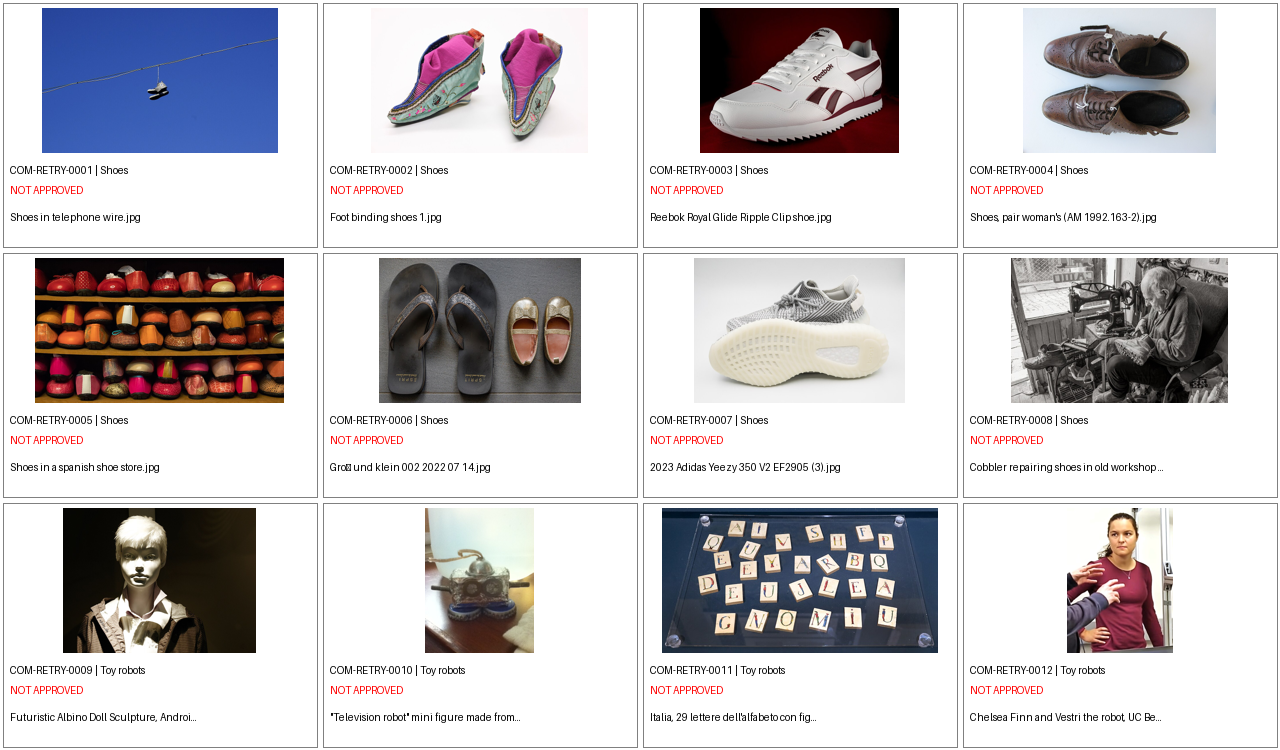

In [ ]:
# STEP 86 — Preview retry candidates
# Thumbnail-only review. No dataset approval or split assignment.

from pathlib import Path
from io import BytesIO
import time
import zipfile
import pandas as pd
import requests

from PIL import Image, ImageDraw
from IPython.display import display

EXP = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
CSV = EXP / "ood_benchmark_candidate_search_retry_v1.csv"

if not CSV.is_file():
    raise FileNotFoundError(f"Candidate CSV not found: {CSV}")

df = pd.read_csv(CSV, keep_default_na=False)

if df.empty:
    raise ValueError("The retry candidate CSV is empty.")

required = {
    "candidate_id", "search_subtype", "file_title",
    "thumbnail_url", "source_page_url", "license_short_name",
    "commons_sha1",
}
missing = required - set(df.columns)
if missing:
    raise KeyError(f"Missing columns: {sorted(missing)}")

# Create a new review folder without overwriting prior artifacts.
version = 1
while (EXP / f"ood_candidate_review_retry_v{version}").exists():
    version += 1

OUT = EXP / f"ood_candidate_review_retry_v{version}"
CACHE = Path("/content/wastelens_retry_thumbnail_cache")
OUT.mkdir(parents=True, exist_ok=False)
CACHE.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensResearch/0.2 (candidate visual review)"
})

W, H = 320, 250
COLS = 4
ROWS = 3
sheet = Image.new("RGB", (W * COLS, H * ROWS), "white")
draw = ImageDraw.Draw(sheet)

failures = []
for i, (_, row) in enumerate(df.iterrows()):
    cid = str(row["candidate_id"])
    subtype = str(row["search_subtype"])
    title = str(row["file_title"]).replace("File:", "")
    thumb_path = CACHE / f"{cid}.jpg"

    image = None
    if thumb_path.is_file():
        try:
            with Image.open(thumb_path) as im:
                image = im.convert("RGB")
        except Exception:
            image = None

    url = str(row["thumbnail_url"]).strip()
    if image is None and url:
        try:
            response = session.get(url, timeout=30)
            response.raise_for_status()
            image = Image.open(BytesIO(response.content)).convert("RGB")
            image.thumbnail((W - 20, 145))
            image.save(thumb_path, "JPEG", quality=85)
            time.sleep(1.5)
        except Exception as exc:
            failures.append((cid, type(exc).__name__, str(exc)[:120]))
            image = None

    x = (i % COLS) * W
    y = (i // COLS) * H

    draw.rectangle((x + 3, y + 3, x + W - 3, y + H - 3), outline="gray")

    if image is not None:
        image.thumbnail((W - 20, 145))
        sheet.paste(image, (x + (W - image.width) // 2, y + 8))
    else:
        draw.text((x + 10, y + 65), "PREVIEW UNAVAILABLE", fill="black")

    draw.text((x + 10, y + 164), f"{cid} | {subtype}", fill="black")
    draw.text((x + 10, y + 184), "NOT APPROVED", fill="red")

    if len(title) > 43:
        title = title[:40] + "..."
    draw.text((x + 10, y + 211), title, fill="black")

sheet_path = OUT / "retry_candidates_contact_sheet.jpg"
sheet.save(sheet_path, quality=90)

worksheet = df.copy()
worksheet["visual_review"] = "pending"
worksheet["label_matches_image"] = "pending"
worksheet["duplicate_review"] = "pending"
worksheet["licence_review"] = "pending"
worksheet["approved_for_dataset"] = "no"
worksheet["download_authorized"] = "no"
worksheet["review_notes"] = ""

worksheet_path = OUT / "retry_candidate_review_worksheet.csv"
worksheet.to_csv(worksheet_path, index=False)

zip_path = EXP / f"ood_candidate_review_retry_v{version}.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    z.write(sheet_path, arcname=sheet_path.name)
    z.write(worksheet_path, arcname=worksheet_path.name)

print("Candidates:", len(df))
print("Categories:", df["search_subtype"].value_counts().to_dict())
print("Contact sheet:", sheet_path)
print("Review worksheet:", worksheet_path)
print("ZIP package:", zip_path)
print("Thumbnail failures:", failures)
print("All candidates remain unapproved.")

display(sheet)

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/ood_candidate_review_retry_v1.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# STEP 88 — Live source and licence metadata audit
# Read-only checks against Commons. Saves a NEW audit CSV only.
# Does not download full images, approve candidates, assign splits, or train.

from pathlib import Path
from datetime import datetime, timezone
import time
import re
import pandas as pd
import requests

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment")
CANDIDATES = EXP / "ood_benchmark_candidate_search_retry_v1.csv"

# Priority visual-review shortlist; not approved for dataset use.
PRIORITY_IDS = [
    "COM-RETRY-0002",
    "COM-RETRY-0003",
    "COM-RETRY-0004",
    "COM-RETRY-0005",
    "COM-RETRY-0006",
    "COM-RETRY-0007",
    "COM-RETRY-0008",
    "COM-RETRY-0010",
]

if not CANDIDATES.is_file():
    raise FileNotFoundError(f"Candidate manifest missing: {CANDIDATES}")

df = pd.read_csv(CANDIDATES, keep_default_na=False)

required = {
    "candidate_id", "search_subtype", "file_title",
    "source_page_url", "commons_sha1", "license_short_name",
    "license_url", "author", "credit",
}
missing_columns = required - set(df.columns)
if missing_columns:
    raise KeyError(f"Missing columns: {sorted(missing_columns)}")

selected = df[df["candidate_id"].isin(PRIORITY_IDS)].copy()

missing_ids = sorted(set(PRIORITY_IDS) - set(selected["candidate_id"]))
if missing_ids:
    raise ValueError(f"Priority candidates not found: {missing_ids}")

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensResearch/0.3 (dataset provenance verification)"
})

def tidy(value):
    return re.sub(r"\s+", " ", str(value or "")).strip()

def ext_value(ext, key):
    return tidy(ext.get(key, {}).get("value", ""))

# One batched metadata request is gentler on the API than separate requests.
titles = "|".join(selected["file_title"].astype(str).tolist())
params = {
    "action": "query",
    "format": "json",
    "formatversion": 2,
    "prop": "imageinfo",
    "titles": titles,
    "iiprop": "url|size|mime|sha1|extmetadata",
    "iiextmetadatafilter": (
        "LicenseShortName|LicenseUrl|Artist|Credit|ImageDescription|"
        "UsageTerms|Copyrighted|Restrictions"
    ),
}

payload = None
for attempt in range(2):
    try:
        response = session.get(API, params=params, timeout=60)

        if response.status_code == 429:
            wait_header = response.headers.get("Retry-After", "")
            try:
                wait = min(max(float(wait_header), 30), 120)
            except ValueError:
                wait = 60

            if attempt == 0:
                print(f"Commons is rate-limiting requests; waiting {wait:g}s.")
                time.sleep(wait)
                continue
            raise RuntimeError("Commons returned HTTP 429 after retry.")

        response.raise_for_status()
        payload = response.json()
        break

    except Exception as exc:
        if attempt == 1:
            raise RuntimeError(
                f"Live metadata request failed: {type(exc).__name__}: {exc}"
            ) from exc
        print("Request failed once; retrying after 20 seconds.")
        time.sleep(20)

if payload is None:
    raise RuntimeError("No metadata response received.")

# Index results by normalized returned file title.
def title_key(title):
    return tidy(title).replace("_", " ").casefold()

live_by_title = {
    title_key(page.get("title", "")): page
    for page in payload.get("query", {}).get("pages", [])
}

results = []

for _, row in selected.iterrows():
    original_title = str(row["file_title"])
    page = live_by_title.get(title_key(original_title))
    info = (page.get("imageinfo") or [{}])[0] if page else {}

    ext = info.get("extmetadata", {}) if info else {}
    current_sha1 = tidy(info.get("sha1", "")).lower()
    expected_sha1 = tidy(row["commons_sha1"]).lower()

    current_license = ext_value(ext, "LicenseShortName")
    current_license_url = ext_value(ext, "LicenseUrl")
    current_author = ext_value(ext, "Artist")
    current_credit = ext_value(ext, "Credit")
    current_description = ext_value(ext, "ImageDescription")

    sha1_format_ok = bool(re.fullmatch(r"[0-9a-f]{40}", current_sha1))
    sha1_matches = bool(
        sha1_format_ok and expected_sha1 and current_sha1 == expected_sha1
    )

    results.append({
        "candidate_id": row["candidate_id"],
        "subtype": row["search_subtype"],
        "file_title_requested": original_title,
        "source_page_url_original": row["source_page_url"],
        "source_page_url_live": (
            tidy(info.get("descriptionurl", "")) if info else ""
        ),
        "source_found_live": bool(page and info),
        "expected_commons_sha1": expected_sha1,
        "live_commons_sha1": current_sha1,
        "sha1_matches": sha1_matches,
        "current_mime": tidy(info.get("mime", "")),
        "current_width": info.get("width", ""),
        "current_height": info.get("height", ""),
        "current_license": current_license,
        "current_license_url": current_license_url,
        "original_license": row["license_short_name"],
        "original_license_url": row["license_url"],
        "license_name_unchanged": bool(
            current_license and current_license == row["license_short_name"]
        ),
        "license_url_unchanged": bool(
            current_license_url and current_license_url == row["license_url"]
        ),
        "current_author": current_author,
        "current_credit": current_credit,
        "current_description": current_description,
        "license_metadata_present": bool(current_license and current_license_url),
        "creator_or_credit_present": bool(current_author or current_credit),
        "visual_review_status": "preliminary_thumbnail_review_only",
        "manual_license_review": "pending",
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "split_assignment": "none",
        "audited_at_utc": datetime.now(timezone.utc).isoformat(),
    })

audit = pd.DataFrame(results)

version = 1
while (EXP / f"ood_priority_candidates_live_metadata_audit_v{version}.csv").exists():
    version += 1

out = EXP / f"ood_priority_candidates_live_metadata_audit_v{version}.csv"
audit.to_csv(out, index=False)

print("\n=== LIVE METADATA AUDIT ===")
print(audit[[
    "candidate_id", "subtype", "source_found_live",
    "sha1_matches", "current_license", "license_metadata_present",
    "creator_or_credit_present", "approved_for_dataset"
]].to_string(index=False))

print("\n=== SUMMARY ===")
print("Candidates checked:", len(audit))
print("Source pages found:", int(audit["source_found_live"].sum()))
print("SHA-1 matches:", int(audit["sha1_matches"].sum()))
print("Licence metadata present:", int(audit["license_metadata_present"].sum()))
print("Creator/credit present:", int(audit["creator_or_credit_present"].sum()))
print("Saved new audit:", out)

print("\nImportant:")
print("- A matching hash proves the source file matches the previously recorded file bytes.")
print("- Licence metadata still requires checking the specific reuse conditions.")
print("- No candidate was approved, downloaded, or assigned a split.")
print("- No model weights or existing manifests were modified.")
print("- No locked-test images were accessed.")


=== LIVE METADATA AUDIT ===
  candidate_id    subtype  source_found_live  sha1_matches current_license  license_metadata_present  creator_or_credit_present approved_for_dataset
COM-RETRY-0002      Shoes               True          True    CC BY-SA 3.0                      True                       True                   no
COM-RETRY-0003      Shoes               True          True    CC BY-SA 4.0                      True                       True                   no
COM-RETRY-0004      Shoes               True          True       CC BY 4.0                      True                       True                   no
COM-RETRY-0005      Shoes               True          True    CC BY-SA 4.0                      True                       True                   no
COM-RETRY-0006      Shoes               True          True    CC BY-SA 4.0                      True                       True                   no
COM-RETRY-0007      Shoes               True          True    CC BY-SA 4.0   

[1/8] COM-RETRY-0002
  PASS | 4368x2912 | hash matches | licence CC BY-SA 3.0
[2/8] COM-RETRY-0003
  PASS | 4600x3344 | hash matches | licence CC BY-SA 4.0
[3/8] COM-RETRY-0004
  PASS | 3264x2448 | hash matches | licence CC BY 4.0
[4/8] COM-RETRY-0005
  FAILED: HTTPError 429 Client Error: Too many requests (f061ab2) for url: https://upload.wikimedia.org/wikipedia/commons/3/3e/Shoes_in_a_spanish_shoe_store.jpg?utm_sourc
[5/8] COM-RETRY-0006
  FAILED: HTTPError 429 Client Error: Too many requests (f061ab2) for url: https://upload.wikimedia.org/wikipedia/commons/0/0f/Gro%C3%9F_und_klein_002_2022_07_14.jpg?utm_
[6/8] COM-RETRY-0007
  PASS | 4706x3236 | hash matches | licence CC BY-SA 4.0
[7/8] COM-RETRY-0008
  FAILED: HTTPError 429 Client Error: Too many requests (f061ab2) for url: https://upload.wikimedia.org/wikipedia/commons/e/e6/Cobbler_repairing_shoes_in_old_workshop_%28
[8/8] COM-RETRY-0010
  FAILED: HTTPError 429 Client Error: Too many requests (f061ab2) for url: https://upload.wiki

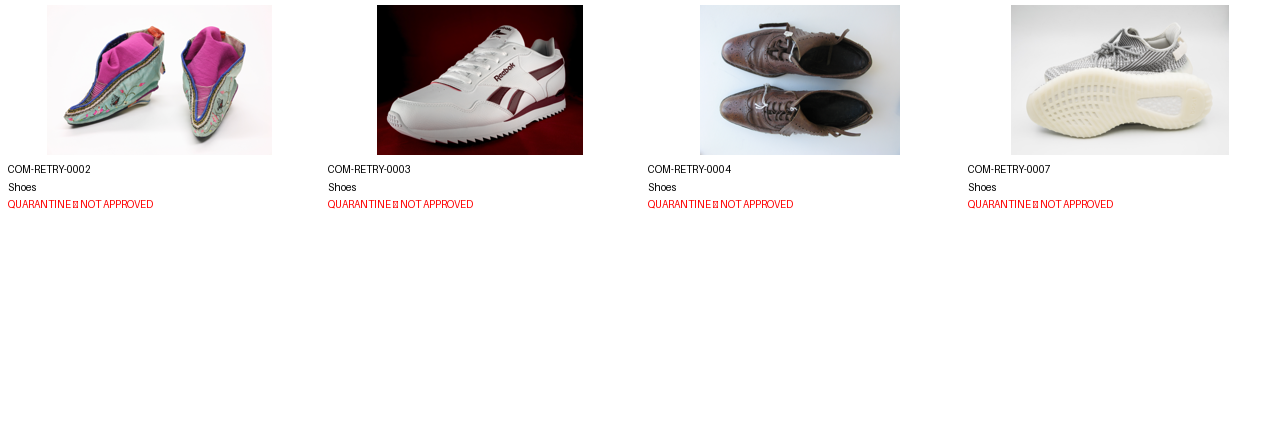


All downloaded files remain quarantined.
Dataset approval: none | Splits assigned: none | Training: none
Model weights modified: no | Locked test accessed: no


In [ ]:
# STEP 89 — Download priority candidates into quarantine
# Verify original file SHA-1, image decoding, and live-source metadata.
# Does not approve candidates, assign splits, train models, or touch locked test.

from pathlib import Path
from io import BytesIO
from datetime import datetime, timezone
from urllib.parse import urlparse, unquote
import hashlib
import time

import pandas as pd
import requests
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment")

CANDIDATE_FILE = EXP / "ood_benchmark_candidate_search_retry_v1.csv"
LIVE_AUDIT_FILE = EXP / "ood_priority_candidates_live_metadata_audit_v1.csv"

PRIORITY_IDS = [
    "COM-RETRY-0002",
    "COM-RETRY-0003",
    "COM-RETRY-0004",
    "COM-RETRY-0005",
    "COM-RETRY-0006",
    "COM-RETRY-0007",
    "COM-RETRY-0008",
    "COM-RETRY-0010",
]

for path in [CANDIDATE_FILE, LIVE_AUDIT_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Required metadata file missing: {path}")

candidates = pd.read_csv(CANDIDATE_FILE, keep_default_na=False)
audit = pd.read_csv(LIVE_AUDIT_FILE, keep_default_na=False)

selected = candidates[candidates["candidate_id"].isin(PRIORITY_IDS)].copy()
live = audit[audit["candidate_id"].isin(PRIORITY_IDS)].copy()

if set(selected["candidate_id"]) != set(PRIORITY_IDS):
    raise ValueError("Candidate CSV does not contain the full requested shortlist.")

if set(live["candidate_id"]) != set(PRIORITY_IDS):
    raise ValueError("Live metadata audit does not contain the full shortlist.")

# Refuse to download any entry that did not pass its source/hash checks.
for _, row in live.iterrows():
    if str(row["source_found_live"]).lower() not in {"true", "1", "yes"}:
        raise ValueError(f"Source not verified: {row['candidate_id']}")
    if str(row["sha1_matches"]).lower() not in {"true", "1", "yes"}:
        raise ValueError(f"Live SHA-1 does not match: {row['candidate_id']}")
    if not str(row["current_license"]).strip():
        raise ValueError(f"Current licence missing: {row['candidate_id']}")

live_by_id = live.set_index("candidate_id").to_dict("index")

# Versioned quarantine folder; existing folders are preserved.
version = 1
while (EXP / f"ood_candidate_quarantine_v{version}").exists():
    version += 1

QUARANTINE = EXP / f"ood_candidate_quarantine_v{version}"
QUARANTINE.mkdir(parents=True, exist_ok=False)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensResearch/0.4 (dataset provenance verification)"
})

def sha1_bytes(data):
    return hashlib.sha1(data).hexdigest()

def choose_extension(url, mime):
    suffix = Path(unquote(urlparse(url).path)).suffix.lower()
    allowed = {".jpg", ".jpeg", ".png", ".webp", ".tif", ".tiff", ".bmp", ".gif"}
    if suffix in allowed:
        return suffix
    return {
        "image/jpeg": ".jpg",
        "image/png": ".png",
        "image/webp": ".webp",
        "image/tiff": ".tiff",
        "image/gif": ".gif",
    }.get(mime.lower(), ".img")

rows = []
preview_tiles = []
failures = []

for i, (_, candidate) in enumerate(selected.iterrows(), start=1):
    cid = str(candidate["candidate_id"])
    source = live_by_id[cid]
    direct_url = str(candidate["direct_image_url"]).strip()
    expected_sha1 = str(candidate["commons_sha1"]).strip().lower()
    live_sha1 = str(source["live_commons_sha1"]).strip().lower()

    receipt = {
        "candidate_id": cid,
        "subtype": candidate["search_subtype"],
        "target_label_proposal": candidate["proposed_target_label"],
        "source_page_url": source["source_page_url_live"],
        "direct_image_url": direct_url,
        "current_license": source["current_license"],
        "license_url": source["current_license_url"],
        "creator": source["current_author"],
        "credit": source["current_credit"],
        "expected_sha1": expected_sha1,
        "live_sha1": live_sha1,
        "download_sha1": "",
        "sha1_matches_expected": False,
        "sha1_matches_live": False,
        "image_decodes": False,
        "width": "",
        "height": "",
        "mime": "",
        "quarantine_path": "",
        "quarantine_status": "pending",
        "approved_for_dataset": "no",
        "split_assignment": "none",
        "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
    }

    print(f"[{i}/{len(selected)}] {cid}")

    try:
        response = session.get(direct_url, timeout=60)
        response.raise_for_status()
        content = response.content

        actual_sha1 = sha1_bytes(content)
        receipt["download_sha1"] = actual_sha1
        receipt["sha1_matches_expected"] = actual_sha1 == expected_sha1
        receipt["sha1_matches_live"] = actual_sha1 == live_sha1
        receipt["mime"] = response.headers.get("Content-Type", "").split(";")[0]

        # If a file differs from the reviewed source bytes, do not save it.
        if not receipt["sha1_matches_expected"] or not receipt["sha1_matches_live"]:
            receipt["quarantine_status"] = "rejected_hash_mismatch"
            failures.append((cid, "Downloaded bytes do not match recorded source hashes."))
            rows.append(receipt)
            time.sleep(2)
            continue

        # Decode verification without recompressing or altering the original bytes.
        with Image.open(BytesIO(content)) as im:
            im.verify()

        with Image.open(BytesIO(content)) as im:
            rgb = ImageOps.exif_transpose(im).convert("RGB")
            width, height = rgb.size
            receipt["width"] = width
            receipt["height"] = height
            receipt["image_decodes"] = width > 0 and height > 0

            if not receipt["image_decodes"]:
                raise ValueError("Invalid image dimensions.")

            ext = choose_extension(direct_url, receipt["mime"])
            destination = QUARANTINE / f"{cid}{ext}"

            # Save the original bytes, not the EXIF-adjusted preview.
            destination.write_bytes(content)
            receipt["quarantine_path"] = str(destination)
            receipt["quarantine_status"] = "downloaded_verified_quarantine"

            rgb.thumbnail((300, 150))
            preview_tiles.append((cid, str(candidate["search_subtype"]), rgb.copy()))

        print(
            f"  PASS | {width}x{height} | "
            f"hash matches | licence {receipt['current_license']}"
        )

    except Exception as exc:
        receipt["quarantine_status"] = "download_or_decode_failed"
        failures.append((cid, f"{type(exc).__name__}: {str(exc)[:200]}"))
        print("  FAILED:", type(exc).__name__, str(exc)[:150])

    rows.append(receipt)
    time.sleep(2)

# Receipt and review contact sheet.
receipt_df = pd.DataFrame(rows)
receipt_path = QUARANTINE / "quarantine_download_receipt.csv"
receipt_df.to_csv(receipt_path, index=False)

W, H, COLS, ROWS_PER_SHEET = 320, 215, 4, 2
sheet = Image.new("RGB", (W * COLS, H * ROWS_PER_SHEET), "white")
draw = ImageDraw.Draw(sheet)

for i, (cid, subtype, image) in enumerate(preview_tiles):
    x = (i % COLS) * W
    y = (i // COLS) * H
    sheet.paste(image, (x + (W - image.width) // 2, y + 5))
    draw.text((x + 8, y + 163), cid, fill="black")
    draw.text((x + 8, y + 181), subtype, fill="black")
    draw.text((x + 8, y + 198), "QUARANTINE — NOT APPROVED", fill="red")

contact_path = QUARANTINE / "priority_full_image_review.jpg"
sheet.save(contact_path, quality=90)

print("\n=== QUARANTINE SUMMARY ===")
print("Candidates:", len(receipt_df))
print("Verified downloads:", int(
    receipt_df["quarantine_status"].eq("downloaded_verified_quarantine").sum()
))
print("Failures:", len(failures))
print("Receipt:", receipt_path)
print("Contact sheet:", contact_path)
print("Quarantine folder:", QUARANTINE)

if failures:
    print("\nFailed candidates:")
    for failure in failures:
        print(failure)

display(sheet)

print("\nAll downloaded files remain quarantined.")
print("Dataset approval: none | Splits assigned: none | Training: none")
print("Model weights modified: no | Locked test accessed: no")

## 4. Reviewing OOD Candidates

Look at the out-of-distribution images we found and check their details.


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/ood_candidate_quarantine_v1/"
    "priority_full_image_review.jpg"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
root.mkdir(parents=True, exist_ok=True)

output_path = root / "ood_visual_review_decisions_v1.csv"

if output_path.exists():
    raise FileExistsError(
        f"{output_path} already exists. "
        "Refusing to overwrite an earlier review."
    )

rows = [
    {
        "candidate_id": "COM-RETRY-0002",
        "category": "Shoes",
        "visual_status": "provisional_pass",
        "dataset_approved": False,
        "split": "unassigned",
        "reason": "Clearly identifiable traditional footwear; "
                  "source, licence and dataset eligibility still need final review."
    },
    {
        "candidate_id": "COM-RETRY-0003",
        "category": "Shoes",
        "visual_status": "provisional_pass",
        "dataset_approved": False,
        "split": "unassigned",
        "reason": "Clearly identifiable sneaker in a product photograph; "
                  "source, licence and dataset eligibility still need final review."
    },
    {
        "candidate_id": "COM-RETRY-0004",
        "category": "Shoes",
        "visual_status": "conditional",
        "dataset_approved": False,
        "split": "unassigned",
        "reason": "Clearly identifiable worn footwear; confirm how potentially "
                  "discarded objects are defined in the OOD benchmark."
    },
    {
        "candidate_id": "COM-RETRY-0007",
        "category": "Shoes",
        "visual_status": "provisional_pass",
        "dataset_approved": False,
        "split": "unassigned",
        "reason": "Clearly identifiable sneaker in a product photograph; "
                  "source, licence and dataset eligibility still need final review."
    },
]

df = pd.DataFrame(rows)
df.to_csv(output_path, index=False)

print(f"Review log created: {output_path}")
print(f"Candidates recorded: {len(df)}")
print(f"Dataset approvals: {df['dataset_approved'].sum()}")
print("\nVisual review:")
print(df[["candidate_id", "visual_status", "dataset_approved", "split"]].to_string(index=False))

Review log created: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_visual_review_decisions_v1.csv
Candidates recorded: 4
Dataset approvals: 0

Visual review:
  candidate_id    visual_status  dataset_approved      split
COM-RETRY-0002 provisional_pass             False unassigned
COM-RETRY-0003 provisional_pass             False unassigned
COM-RETRY-0004      conditional             False unassigned
COM-RETRY-0007 provisional_pass             False unassigned


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

candidate_ids = [
    "COM-RETRY-0002",
    "COM-RETRY-0003",
    "COM-RETRY-0004",
    "COM-RETRY-0007",
]

metadata_path = root / "ood_priority_candidates_live_metadata_audit_v1.csv"
receipt_path = root / "ood_candidate_quarantine_v1" / "quarantine_download_receipt.csv"
review_path = root / "ood_visual_review_decisions_v1.csv"

for path in [metadata_path, receipt_path, review_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required audit file not found: {path}")

metadata = pd.read_csv(metadata_path, dtype=str).fillna("")
receipt = pd.read_csv(receipt_path, dtype=str).fillna("")
review = pd.read_csv(review_path, dtype=str).fillna("")

def find_id_column(df):
    matches = [
        c for c in df.columns
        if c.lower().replace("-", "_").replace(" ", "_") in
        {"candidate_id", "candidate", "candidateid"}
    ]
    if not matches:
        raise ValueError(f"Cannot identify candidate ID column. Columns: {list(df.columns)}")
    return matches[0]

def show_relevant_records(df, label):
    id_col = find_id_column(df)
    subset = df[df[id_col].isin(candidate_ids)].copy()

    print(f"\n{'=' * 18} {label} {'=' * 18}")
    if subset.empty:
        print("No matching candidates found.")
        print("Available columns:", list(df.columns))
        return

    # Show source, licensing, attribution, verification and approval fields.
    keywords = (
        "candidate", "source", "page", "url", "license", "licence",
        "creator", "author", "credit", "attribution", "sha", "hash",
        "match", "status", "approved", "path", "width", "height",
        "download", "error"
    )
    columns = [
        c for c in subset.columns
        if any(word in c.lower() for word in keywords)
    ]

    if not columns:
        columns = list(subset.columns)

    print(subset[columns].to_string(index=False))
    print(f"\nMatching records: {len(subset)}")

show_relevant_records(metadata, "LIVE SOURCE METADATA")
show_relevant_records(receipt, "QUARANTINE DOWNLOAD RECEIPT")
show_relevant_records(review, "VISUAL REVIEW DECISIONS")

print("\nNo approval decisions were changed by this audit cell.")


================== LIVE SOURCE METADATA ==================
  candidate_id                                                          source_page_url_original                                                              source_page_url_live source_found_live                    expected_commons_sha1                        live_commons_sha1 sha1_matches current_width current_height current_license                            current_license_url original_license                           original_license_url license_name_unchanged license_url_unchanged                                                                                         current_author                                                                                                                                                                                                                                                                                                                                                         

In [ ]:
from pathlib import Path
import hashlib
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
quarantine = root / "ood_candidate_quarantine_v1"
output_path = root / "ood_priority_attribution_draft_v1.csv"

if output_path.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing file: {output_path}"
    )

metadata_path = root / "ood_priority_candidates_live_metadata_audit_v1.csv"
receipt_path = quarantine / "quarantine_download_receipt.csv"

metadata = pd.read_csv(metadata_path, dtype=str).fillna("")
receipt = pd.read_csv(receipt_path, dtype=str).fillna("")

ids = [
    "COM-RETRY-0002",
    "COM-RETRY-0003",
    "COM-RETRY-0004",
    "COM-RETRY-0007",
]

titles = {
    "COM-RETRY-0002": "Foot binding shoes 1",
    "COM-RETRY-0003": "Reebok Royal Glide Ripple Clip shoe",
    "COM-RETRY-0004": "Shoes, pair woman's (AM 1992.163-2)",
    "COM-RETRY-0007": "2023 Adidas Yeezy 350 V2 EF2905 (3)",
}

meta_id = "candidate_id"
rows = []

for cid in ids:
    m = metadata.loc[metadata[meta_id] == cid]
    r = receipt.loc[receipt[meta_id] == cid]

    if len(m) != 1 or len(r) != 1:
        raise ValueError(
            f"{cid}: expected exactly one metadata and receipt row; "
            f"found metadata={len(m)}, receipt={len(r)}"
        )

    m = m.iloc[0]
    r = r.iloc[0]

    image_path = Path(r["quarantine_path"])
    if not image_path.is_file():
        raise FileNotFoundError(f"{cid}: missing image: {image_path}")

    actual_sha1 = hashlib.sha1(image_path.read_bytes()).hexdigest()
    expected_sha1 = r["expected_sha1"]
    live_sha1 = r["live_sha1"]

    if not (actual_sha1 == expected_sha1 == live_sha1):
        raise ValueError(
            f"{cid}: SHA-1 mismatch; file remains unverified."
        )

    license_name = m["current_license"]
    license_url = m["current_license_url"]
    source_url = m["source_page_url_live"]

    if not source_url or not license_url or not license_name:
        raise ValueError(f"{cid}: incomplete source or licence metadata.")

    creator = {
        "COM-RETRY-0002": "Daniel Schwen",
        "COM-RETRY-0003": "Petar Milošević",
        "COM-RETRY-0004": (
            "Poulsen is shown in the supplied metadata; "
            "creator/photographer attribution role needs confirmation"
        ),
        "COM-RETRY-0007": "Jacek Halicki",
    }[cid]

    attribution_draft = (
        f'"{titles[cid]}" — {creator}. '
        f"Source: {source_url}. "
        f"Licence: {license_name} ({license_url})."
    )

    rows.append({
        "candidate_id": cid,
        "title": titles[cid],
        "creator_credit_from_audit": creator,
        "source_page_url": source_url,
        "licence": license_name,
        "licence_url": license_url,
        "local_image_path": str(image_path),
        "actual_sha1": actual_sha1,
        "sha1_verified": True,
        "attribution_draft": attribution_draft,
        "manual_attribution_review": (
            "required_creator_role_unclear"
            if cid == "COM-RETRY-0004"
            else "pending"
        ),
        "dataset_approved": False,
        "split": "unassigned",
    })

df = pd.DataFrame(rows)
df.to_csv(output_path, index=False)

print(f"Attribution draft saved: {output_path}")
print(f"Rows recorded: {len(df)}")
print(f"Local file hashes verified: {int(df['sha1_verified'].sum())}/{len(df)}")
print(f"Dataset approvals: {int(df['dataset_approved'].sum())}")
print("\nManual review status:")
print(df[[
    "candidate_id",
    "licence",
    "manual_attribution_review",
    "dataset_approved",
]].to_string(index=False))

Attribution draft saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_priority_attribution_draft_v1.csv
Rows recorded: 4
Local file hashes verified: 4/4
Dataset approvals: 0

Manual review status:
  candidate_id      licence     manual_attribution_review  dataset_approved
COM-RETRY-0002 CC BY-SA 3.0                       pending             False
COM-RETRY-0003 CC BY-SA 4.0                       pending             False
COM-RETRY-0004    CC BY 4.0 required_creator_role_unclear             False
COM-RETRY-0007 CC BY-SA 4.0                       pending             False


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "ood_priority_attribution_draft_v1.csv"
output_path = root / "ood_priority_attribution_draft_v2.csv"

if not source_path.exists():
    raise FileNotFoundError(source_path)

if output_path.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing file: {output_path}"
    )

df = pd.read_csv(source_path, dtype=str).fillna("")

target = df["candidate_id"] == "COM-RETRY-0004"
if target.sum() != 1:
    raise ValueError("Expected exactly one row for COM-RETRY-0004.")

row_index = df.index[target][0]

# Attribute the photograph to Auckland Museum as directed
# by the Wikimedia Commons licence section.
df.loc[row_index, "creator_credit_from_audit"] = (
    "Auckland Museum (required attribution on Commons; "
    "photographer not identified in the supplied record)"
)

df.loc[row_index, "attribution_draft"] = (
    '"Shoes, pair woman\'s (AM 1992.163-2)" — Auckland Museum. '
    "Source: "
    "https://commons.wikimedia.org/wiki/"
    "File:Shoes,_pair_woman%27s_(AM_1992.163-2).jpg. "
    "Licence: CC BY 4.0 "
    "(https://creativecommons.org/licenses/by/4.0/). "
    "No changes made."
)

df.loc[row_index, "manual_attribution_review"] = (
    "museum_credit_identified; final dataset review pending"
)

# This remains an attribution draft, not dataset approval.
df.loc[:, "dataset_approved"] = False
df.loc[:, "split"] = "unassigned"

df.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Candidates: {len(df)}")
print("COM-RETRY-0004 attribution: Auckland Museum")
print(f"Dataset approvals: {int(df['dataset_approved'].sum())}")
print("\nUpdated row:")
print(
    df.loc[
        target,
        [
            "candidate_id",
            "creator_credit_from_audit",
            "manual_attribution_review",
            "dataset_approved",
        ],
    ].to_string(index=False)
)

Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_priority_attribution_draft_v2.csv
Candidates: 4
COM-RETRY-0004 attribution: Auckland Museum
Dataset approvals: 0

Updated row:
  candidate_id                                                                             creator_credit_from_audit                              manual_attribution_review dataset_approved
COM-RETRY-0004 Auckland Museum (required attribution on Commons; photographer not identified in the supplied record) museum_credit_identified; final dataset review pending            False


In [ ]:
from pathlib import Path
import hashlib
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
quarantine = root / "ood_candidate_quarantine_v1"

receipt_path = quarantine / "quarantine_download_receipt.csv"
source_path = root / "ood_priority_attribution_draft_v2.csv"
output_path = root / "ood_priority_attribution_review_v3.csv"

if output_path.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing file: {output_path}"
    )

for path in (receipt_path, source_path):
    if not path.is_file():
        raise FileNotFoundError(path)

receipt = pd.read_csv(receipt_path, dtype=str).fillna("")
df = pd.read_csv(source_path, dtype=str).fillna("")

if df["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs found in attribution draft.")

verified = {
    "COM-RETRY-0002": {
        "title": "Foot binding shoes 1",
        "credit": "Daniel Schwen",
        "license": "CC BY-SA 3.0",
        "license_url": "https://creativecommons.org/licenses/by-sa/3.0/",
        "terms": (
            "Provide appropriate credit and licence link; indicate changes. "
            "If adapted, comply with applicable ShareAlike terms."
        ),
        "note": (
            "Commons also lists GFDL; this draft records CC BY-SA 3.0 "
            "as the selected licence."
        ),
    },
    "COM-RETRY-0003": {
        "title": "Reebok Royal Glide Ripple Clip shoe",
        "credit": "Petar Milošević",
        "license": "CC BY-SA 4.0",
        "license_url": "https://creativecommons.org/licenses/by-sa/4.0/",
        "terms": (
            "Provide appropriate credit and licence link; indicate changes. "
            "If adapted, comply with applicable ShareAlike terms."
        ),
        "note": "Commons page lists Petar Milošević as author.",
    },
    "COM-RETRY-0004": {
        "title": "Shoes, pair woman's (AM 1992.163-2)",
        "credit": "Auckland Museum",
        "license": "CC BY 4.0",
        "license_url": "https://creativecommons.org/licenses/by/4.0/",
        "terms": (
            "Provide appropriate credit and licence link; indicate changes; "
            "do not imply endorsement."
        ),
        "note": (
            "Commons identifies Auckland Museum as the required attribution. "
            "Poulsen appears in the Artist field; source/photographer is "
            "listed as API data."
        ),
    },
    "COM-RETRY-0007": {
        "title": "2023 Adidas Yeezy 350 V2 EF2905 (3)",
        "credit": "Jacek Halicki",
        "license": "CC BY-SA 4.0",
        "license_url": "https://creativecommons.org/licenses/by-sa/4.0/",
        "terms": (
            "Provide appropriate credit and licence link; indicate changes. "
            "If adapted, comply with applicable ShareAlike terms."
        ),
        "note": "Commons page lists Jacek Halicki as author.",
    },
}

receipt_ids = set(receipt["candidate_id"])
draft_ids = set(df["candidate_id"])

if set(verified) != draft_ids.intersection(verified):
    raise ValueError("The attribution draft contains unexpected candidate IDs.")

for cid in verified:
    if cid not in receipt_ids:
        raise ValueError(f"{cid}: missing download receipt.")

new_rows = []

for _, row in df.iterrows():
    cid = row["candidate_id"]

    if cid not in verified:
        new_rows.append(row.to_dict())
        continue

    details = verified[cid]
    r = receipt.loc[receipt["candidate_id"] == cid]

    if len(r) != 1:
        raise ValueError(f"{cid}: expected exactly one download receipt.")

    r = r.iloc[0]
    image_path = Path(r["quarantine_path"])

    if not image_path.is_file():
        raise FileNotFoundError(f"{cid}: missing quarantined image: {image_path}")

    actual_sha1 = hashlib.sha1(image_path.read_bytes()).hexdigest()
    expected_sha1 = r["expected_sha1"]
    live_sha1 = r["live_sha1"]

    if actual_sha1 != expected_sha1 or actual_sha1 != live_sha1:
        raise ValueError(f"{cid}: local/source SHA-1 verification failed.")

    updated = row.to_dict()
    updated.update({
        "title": details["title"],
        "creator_credit_from_audit": details["credit"],
        "licence": details["license"],
        "licence_url": details["license_url"],
        "attribution_draft": (
            f'"{details["title"]}" — {details["credit"]}. '
            f"Source: {r['source_page_url']}. "
            f"Licence: {details['license']} ({details['license_url']}). "
            "Changes to original downloaded image: none."
        ),
        "licence_conditions_summary": details["terms"],
        "source_page_review_note": details["note"],
        "commons_page_reviewed_date": "2026-10-26",
        "local_sha1_reverified": actual_sha1,
        "local_hash_verified": True,
        "dataset_approved": False,
        "split": "unassigned",
        "final_licence_compliance_review": "pending",
        "dataset_eligibility_review": "pending",
    })
    new_rows.append(updated)

out = pd.DataFrame(new_rows)
out.to_csv(output_path, index=False)

print(f"Saved: {output_path}")
print(f"Candidates recorded: {len(out)}")
print(f"Local hashes verified: {int(out['local_hash_verified'].sum())}/4")
print(f"Dataset approvals: {int(out['dataset_approved'].sum())}")
print("\nReview status:")
print(out[[
    "candidate_id",
    "creator_credit_from_audit",
    "licence",
    "final_licence_compliance_review",
    "dataset_approved",
]].to_string(index=False))

Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_priority_attribution_review_v3.csv
Candidates recorded: 4
Local hashes verified: 4/4
Dataset approvals: 0

Review status:
  candidate_id creator_credit_from_audit      licence final_licence_compliance_review  dataset_approved
COM-RETRY-0002             Daniel Schwen CC BY-SA 3.0                         pending             False
COM-RETRY-0003           Petar Milošević CC BY-SA 4.0                         pending             False
COM-RETRY-0004           Auckland Museum    CC BY 4.0                         pending             False
COM-RETRY-0007             Jacek Halicki CC BY-SA 4.0                         pending             False


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source = root / "ood_priority_attribution_review_v3.csv"
output = root / "ood_candidate_composition_review_v1.csv"

if not source.exists():
    raise FileNotFoundError(source)

if output.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing review: {output}"
    )

df = pd.read_csv(source, dtype=str).fillna("")

decisions = {
    "COM-RETRY-0002": {
        "composition_group": "isolated_historic_footwear",
        "shortcut_risk": "medium",
        "benchmark_role": "provisional_candidate",
        "reason": (
            "Distinctive traditional footwear adds object variation, "
            "but the isolated presentation limits scene diversity."
        ),
    },
    "COM-RETRY-0003": {
        "composition_group": "commercial_product_photo",
        "shortcut_risk": "high",
        "benchmark_role": "provisional_candidate",
        "reason": (
            "Isolated branded sneaker on a product-style background; "
            "do not let this visual style dominate OOD examples."
        ),
    },
    "COM-RETRY-0004": {
        "composition_group": "museum_catalogue_photo",
        "shortcut_risk": "medium_high",
        "benchmark_role": "conditional_candidate",
        "reason": (
            "Catalogue-style historical footwear may add object variation, "
            "but provides little contextual-scene diversity."
        ),
    },
    "COM-RETRY-0007": {
        "composition_group": "commercial_product_photo",
        "shortcut_risk": "high",
        "benchmark_role": "provisional_candidate",
        "reason": (
            "Isolated branded sneaker; visually similar presentation to "
            "other product photography could create a shortcut."
        ),
    },
}

if set(df["candidate_id"]) != set(decisions):
    raise ValueError(
        "Candidate IDs do not match the four reviewed images. "
        "Inspect the source rather than silently proceeding."
    )

for col in [
    "composition_group",
    "shortcut_risk",
    "benchmark_role",
    "composition_review_reason",
]:
    df[col] = ""

for idx, row in df.iterrows():
    d = decisions[row["candidate_id"]]
    df.loc[idx, "composition_group"] = d["composition_group"]
    df.loc[idx, "shortcut_risk"] = d["shortcut_risk"]
    df.loc[idx, "benchmark_role"] = d["benchmark_role"]
    df.loc[idx, "composition_review_reason"] = d["reason"]

# Preserve strict quarantine state.
df["dataset_approved"] = "False"
df["split"] = "unassigned"

df.to_csv(output, index=False)

print(f"Saved: {output}")
print(f"Candidates reviewed: {len(df)}")
print("Dataset approvals: 0")
print("\nComposition summary:")
print(
    df.groupby(["composition_group", "shortcut_risk"])
      .size()
      .rename("candidate_count")
      .to_string()
)
print("\nAll candidates remain quarantined.")

Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_candidate_composition_review_v1.csv
Candidates reviewed: 4
Dataset approvals: 0

Composition summary:
composition_group           shortcut_risk
commercial_product_photo    high             2
isolated_historic_footwear  medium           1
museum_catalogue_photo      medium_high      1

All candidates remain quarantined.


In [ ]:
from pathlib import Path
from collections import Counter
from urllib.parse import quote
import html
import re
import time
import requests
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
OUTPUT = ROOT / "ood_scene_diverse_candidate_search_v2.csv"

if OUTPUT.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing file: {OUTPUT}"
    )

ROOT.mkdir(parents=True, exist_ok=True)

SEARCHES = {
    "bicycle_outdoor": "bicycle parked street",
    "computer_electronics": "computer keyboard on desk",
    "clothing_context": "shirt hanging wardrobe",
    "furniture_indoor": "chair in living room",
    "bags_context": "backpack on bench",
    "toy_context": "toy robot on table",
    "books_context": "book on table indoor",
    "sports_equipment": "sports ball outdoor field",
    "musical_instruments": "musical instrument indoors",
    "potted_plants": "houseplant in pot indoors",
}

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensOODResearch/1.0 "
        "(research candidate discovery; contact: project maintainer)"
    )
})

def plain_text(value):
    if not value:
        return ""
    value = re.sub(r"<[^>]*>", " ", str(value))
    return html.unescape(" ".join(value.split()))

def get_metadata(extmetadata, key):
    return plain_text(extmetadata.get(key, {}).get("value", ""))

records = []
seen_pageids = set()
errors = []

for group, query in SEARCHES.items():
    params = {
        "action": "query",
        "format": "json",
        "generator": "search",
        "gsrnamespace": 6,
        "gsrsearch": f"{query} filetype:bitmap",
        "gsrlimit": 12,
        "prop": "imageinfo",
        "iiprop": "url|size|sha1|extmetadata",
        "iiurlwidth": 320,
    }

    result = None

    for attempt in range(4):
        try:
            response = session.get(
                API, params=params, timeout=35
            )

            if response.status_code == 429 or response.status_code >= 500:
                wait = min(15 * (attempt + 1), 60)
                print(
                    f"Temporary HTTP {response.status_code} "
                    f"for {group}; retrying in {wait}s"
                )
                time.sleep(wait)
                continue

            response.raise_for_status()
            result = response.json()
            break

        except Exception as exc:
            if attempt == 3:
                errors.append({
                    "query_group": group,
                    "error": str(exc)[:300],
                })
            else:
                time.sleep(3 * (attempt + 1))

    if result is None:
        print(f"{group}: search failed; continuing.")
        continue

    pages = result.get("query", {}).get("pages", {})
    added = 0

    for page in pages.values():
        pageid = page.get("pageid")
        if pageid is None or pageid in seen_pageids:
            continue

        info_list = page.get("imageinfo", [])
        if not info_list:
            continue

        info = info_list[0]
        ext = info.get("extmetadata", {})

        # Keep discovery broad. Licence and content suitability
        # must be reviewed before any candidate can be approved.
        source_url = info.get("descriptionurl", "")
        image_url = info.get("url", "")
        thumbnail_url = info.get("thumburl", "")

        if not source_url or not image_url:
            continue

        seen_pageids.add(pageid)
        records.append({
            "candidate_id": "",  # assigned after deduplication
            "search_group": group,
            "search_query": query,
            "commons_pageid": pageid,
            "title": page.get("title", ""),
            "source_page_url": source_url,
            "direct_image_url": image_url,
            "thumbnail_url": thumbnail_url,
            "width": info.get("width"),
            "height": info.get("height"),
            "commons_sha1": info.get("sha1", ""),
            "license_name": get_metadata(ext, "LicenseShortName"),
            "license_url": get_metadata(ext, "LicenseUrl"),
            "author": get_metadata(ext, "Artist"),
            "attribution_required": get_metadata(
                ext, "AttributionRequired"
            ),
            "usage_terms": get_metadata(ext, "UsageTerms"),
            "object_description": get_metadata(
                ext, "ImageDescription"
            ),
            "candidate_review_status": "pending",
            "download_status": "not_downloaded",
            "approved_for_dataset": "no",
            "split": "unassigned",
        })
        added += 1

    print(f"{group}: {added} new candidates")
    time.sleep(2)

if not records:
    raise RuntimeError(
        "No candidates were retrieved. Check the network/API output "
        "before retrying; no output file was created."
    )

df = pd.DataFrame(records)
df = df.sort_values(
    ["search_group", "title"]
).reset_index(drop=True)

df["candidate_id"] = [
    f"COM-OOD-V2-{i:04d}" for i in range(1, len(df) + 1)
]

df.to_csv(OUTPUT, index=False)

print("\n" + "=" * 55)
print(f"Saved candidate pool: {OUTPUT}")
print(f"Unique candidates: {len(df)}")
print(f"Different search groups represented: {df['search_group'].nunique()}")
print(f"Missing licence names: {(df['license_name'].str.strip() == '').sum()}")
print(f"Missing licence URLs: {(df['license_url'].str.strip() == '').sum()}")
print(f"Approved for dataset: {(df['approved_for_dataset'] == 'yes').sum()}")
print("\nCandidates by search group:")
print(Counter(df["search_group"]).most_common())
print(f"\nQueries with errors: {len(errors)}")
if errors:
    print(pd.DataFrame(errors).to_string(index=False))

print(
    "\nSafety: search results only. No full images were downloaded, "
    "no dataset splits assigned, no model changed, and no locked-test "
    "images accessed."
)

bicycle_outdoor: 12 new candidates
computer_electronics: 12 new candidates
clothing_context: 1 new candidates
furniture_indoor: 12 new candidates
bags_context: 12 new candidates
toy_context: 7 new candidates
books_context: 12 new candidates
sports_equipment: 12 new candidates
musical_instruments: 12 new candidates
potted_plants: 6 new candidates

Saved candidate pool: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_candidate_search_v2.csv
Unique candidates: 98
Different search groups represented: 10
Missing licence names: 0
Missing licence URLs: 12
Approved for dataset: 0

Candidates by search group:
[('bags_context', 12), ('bicycle_outdoor', 12), ('books_context', 12), ('computer_electronics', 12), ('furniture_indoor', 12), ('musical_instruments', 12), ('sports_equipment', 12), ('toy_context', 7), ('potted_plants', 6), ('clothing_context', 1)]

Queries with errors: 0

Safety: search results only. No full images were downloaded, no dataset splits ass

In [ ]:
from pathlib import Path
import time
import requests
import pandas as pd
from PIL import Image, ImageDraw
from io import BytesIO
from collections import Counter

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

INPUT = ROOT / "ood_scene_diverse_candidate_search_v2.csv"
OUT_DIR = ROOT / "ood_scene_diverse_review_v2"

if not INPUT.exists():
    raise FileNotFoundError(INPUT)

if OUT_DIR.exists():
    raise FileExistsError(
        f"Review directory already exists: {OUT_DIR}. "
        "Refusing to overwrite an earlier review."
    )

OUT_DIR.mkdir(parents=True)

df = pd.read_csv(INPUT, dtype=str).fillna("")

required = {
    "candidate_id", "search_group", "title",
    "thumbnail_url", "license_name", "license_url",
    "commons_sha1", "source_page_url"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {sorted(missing)}")

# Only candidates with licence metadata available enter this preview batch.
eligible = df[
    (df["license_name"].str.strip() != "") &
    (df["license_url"].str.strip() != "") &
    (df["thumbnail_url"].str.strip() != "")
].copy()

# Remove exact-image duplicates when a SHA-1 is available.
has_hash = eligible["commons_sha1"].str.strip() != ""
with_hash = eligible[has_hash].drop_duplicates(
    subset="commons_sha1", keep="first"
)
without_hash = eligible[~has_hash]
eligible = pd.concat([with_hash, without_hash], ignore_index=True)

# Select up to four candidates per category with a fixed, reproducible seed.
selected_parts = []
groups = sorted(eligible["search_group"].unique())

for group_index, group in enumerate(groups):
    group_df = eligible[eligible["search_group"] == group]
    n = min(4, len(group_df))
    if n:
        selected_parts.append(
            group_df.sample(n=n, random_state=2026 + group_index)
        )

if not selected_parts:
    raise RuntimeError(
        "No candidates have both a thumbnail and licence URL."
    )

selected = pd.concat(selected_parts, ignore_index=True)
selected = selected.sort_values(
    ["search_group", "candidate_id"]
).reset_index(drop=True)

# Create a worksheet with explicit pending statuses.
selected["thumbnail_download_status"] = "pending"
selected["visual_review_status"] = "not_reviewed"
selected["licence_review_status"] = "pending"
selected["approved_for_dataset"] = "no"
selected["split"] = "unassigned"

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensOODResearch/1.0 (candidate screening)"
})

previews = []
download_errors = []
rate_limited = False

for idx, row in selected.iterrows():
    cid = row["candidate_id"]
    image = None
    status = "download_failed"

    if rate_limited:
        status = "skipped_after_rate_limit"
    else:
        try:
            response = session.get(
                row["thumbnail_url"],
                timeout=20
            )

            if response.status_code == 429:
                status = "rate_limited"
                rate_limited = True
                download_errors.append((cid, status))
            else:
                response.raise_for_status()
                image = Image.open(
                    BytesIO(response.content)
                ).convert("RGB")
                status = "downloaded_thumbnail_only"

        except Exception as exc:
            download_errors.append((cid, str(exc)[:160]))

    selected.loc[idx, "thumbnail_download_status"] = status

    if image is not None:
        previews.append((row.to_dict(), image))

    # Be gentle with Commons; don't fire rapid requests.
    time.sleep(1.2)

# Save the audit worksheet, including unsuccessful thumbnail requests.
worksheet_path = OUT_DIR / "visual_review_worksheet_v1.csv"
selected.to_csv(worksheet_path, index=False)

# Build a contact sheet with candidate IDs and category labels.
columns = 4
tile_w, tile_h = 300, 245
rows = max(1, (len(previews) + columns - 1) // columns)

sheet = Image.new(
    "RGB",
    (columns * tile_w, rows * tile_h),
    "white"
)
draw = ImageDraw.Draw(sheet)

for i, (record, image) in enumerate(previews):
    x = (i % columns) * tile_w
    y = (i // columns) * tile_h

    image.thumbnail((tile_w - 20, 155))
    px = x + (tile_w - image.width) // 2
    py = y + 5
    sheet.paste(image, (px, py))

    title = str(record["title"])
    if len(title) > 54:
        title = title[:51] + "..."

    label = (
        f'{record["candidate_id"]}\n'
        f'{record["search_group"]}\n'
        f'{title}\n'
        f'Licence: {record["license_name"]}'
    )
    draw.multiline_text(
        (x + 8, y + 166),
        label,
        fill="black",
        spacing=3
    )

contact_path = OUT_DIR / "visual_review_contact_sheet_v1.jpg"
sheet.save(contact_path, quality=90)

print(f"Original candidate pool: {len(df)}")
print(f"Candidates with licence URL and thumbnail: {len(eligible)}")
print(f"Selected for visual review: {len(selected)}")
print(f"Thumbnails downloaded: {len(previews)}")
print(f"Thumbnail request errors: {len(download_errors)}")
print(f"Groups represented: {selected['search_group'].nunique()}")
print(f"\nWorksheet: {worksheet_path}")
print(f"Contact sheet: {contact_path}")
print("\nSelection by group:")
print(selected.groupby("search_group").size().to_string())
print("\nAll candidates remain unapproved; no originals or model weights changed.")

# Download the contact sheet for review in this conversation.
from google.colab import files
files.download(str(contact_path))

Original candidate pool: 98
Candidates with licence URL and thumbnail: 86
Selected for visual review: 37
Thumbnails downloaded: 37
Thumbnail request errors: 0
Groups represented: 10

Worksheet: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_review_v2/visual_review_worksheet_v1.csv
Contact sheet: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_review_v2/visual_review_contact_sheet_v1.jpg

Selection by group:
search_group
bags_context            4
bicycle_outdoor         4
books_context           4
clothing_context        1
computer_electronics    4
furniture_indoor        4
musical_instruments     4
potted_plants           4
sports_equipment        4
toy_context             4

All candidates remain unapproved; no originals or model weights changed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# WASTELENS RECOVERY CHECK — read-only, no training or file changes

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")
experiment = drive_root / "WasteLens/convnext_xl/rejection_experiment"

print("=== DRIVE STATUS ===")
print("/content/drive exists:", Path("/content/drive").exists())
print("MyDrive exists:", drive_root.exists())

if not drive_root.exists():
    print("\nGoogle Drive may not be mounted. Attempting to mount it...")
    from google.colab import drive
    drive.mount("/content/drive")

print("\n=== EXPECTED FOLDER ===")
print("Experiment folder exists:", experiment.is_dir())

if experiment.is_dir():
    files = sorted(p.name for p in experiment.iterdir() if p.is_file())
    print("Files in experiment folder:", len(files))

    print("\nRelevant pilot artifacts:")
    for name in files:
        if "pilot" in name.lower() and any(
            term in name.lower()
            for term in ("report_v2", "summary_v2", "metrics_v2",
                         "preprocess_v2", "compost_approved_v6")
        ):
            print("FOUND:", name)
else:
    parent = drive_root / "WasteLens/convnext_xl"
    print("ConvNeXt folder exists:", parent.is_dir())

    if parent.is_dir():
        print("\nAvailable experiment-related folders:")
        for p in sorted(parent.iterdir()):
            print(("DIR  " if p.is_dir() else "FILE "), p.name)

print("\nDiagnostic finished. No files were modified.")

=== DRIVE STATUS ===
/content/drive exists: False
MyDrive exists: False

Google Drive may not be mounted. Attempting to mount it...
Mounted at /content/drive

=== EXPECTED FOLDER ===
Experiment folder exists: True
Files in experiment folder: 116

Relevant pilot artifacts:
FOUND: pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv
FOUND: pilot_rejection_experiment_metrics_preprocess_v2_20261024T203753Z.csv
FOUND: pilot_rejection_experiment_metrics_v2.csv
FOUND: pilot_rejection_experiment_report_v2.md
FOUND: pilot_rejection_experiment_summary_v2.json
FOUND: pilot_saved_rejection_head_predictions_preprocess_v2_20261024T203753Z.csv
FOUND: pilot_saved_rejection_head_summary_preprocess_v2_20261024T203753Z.json

Diagnostic finished. No files were modified.


In [ ]:
from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

candidate_file = root / "ood_scene_diverse_candidate_search_v2.csv"
review_dir = root / "ood_scene_diverse_review_v2"

print("Candidate CSV exists:", candidate_file.is_file())
print("Review folder exists:", review_dir.is_dir())

if candidate_file.is_file():
    df = pd.read_csv(candidate_file)

    print("Candidate rows:", len(df))
    print("Search groups:", df["search_group"].nunique())
    print("Required columns available:",
          all(c in df.columns for c in [
              "candidate_id",
              "search_group",
              "thumbnail_url",
              "license_name",
              "license_url",
              "source_page_url",
          ]))

    print("\nCandidates per group:")
    print(df.groupby("search_group").size().to_string())

    if review_dir.is_dir():
        print("\nExisting review-folder files:")
        for p in sorted(review_dir.iterdir()):
            print(p.name)
else:
    print("Candidate pool not found. No files were changed.")

Candidate CSV exists: True
Review folder exists: True
Candidate rows: 98
Search groups: 10
Required columns available: True

Candidates per group:
search_group
bags_context            12
bicycle_outdoor         12
books_context           12
clothing_context         1
computer_electronics    12
furniture_indoor        12
musical_instruments     12
potted_plants            6
sports_equipment        12
toy_context              7

Existing review-folder files:
visual_review_contact_sheet_v1.jpg
visual_review_worksheet_v1.csv


In [ ]:
from pathlib import Path
from google.colab import files

review_dir = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/ood_scene_diverse_review_v2"
)

contact_sheet = review_dir / "visual_review_contact_sheet_v1.jpg"

if not contact_sheet.is_file():
    raise FileNotFoundError(
        f"Contact sheet not found: {contact_sheet}"
    )

print(f"Contact sheet size: {contact_sheet.stat().st_size:,} bytes")
files.download(str(contact_sheet))

Contact sheet size: 692,045 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

SOURCE = ROOT / "ood_scene_diverse_candidate_search_v2.csv"
WORKSHEET = (
    ROOT / "ood_scene_diverse_review_v2"
    / "visual_review_worksheet_v1.csv"
)

REVIEW_OUT = ROOT / "ood_scene_diverse_visual_review_decisions_v1.csv"
SHORTLIST_OUT = ROOT / "ood_scene_diverse_visual_shortlist_v1.csv"

for p in (SOURCE, WORKSHEET):
    if not p.is_file():
        raise FileNotFoundError(p)

for p in (REVIEW_OUT, SHORTLIST_OUT):
    if p.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing artifact: {p}"
        )

candidates = pd.read_csv(SOURCE, dtype=str).fillna("")
worksheet = pd.read_csv(WORKSHEET, dtype=str).fillna("")

if candidates["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in the source pool.")

# These are visual judgments from the contact sheet only.
# They do not constitute licence or dataset approval.
decisions = {
    "COM-OOD-V2-0001": ("reject_query_mismatch", "No clearly identifiable bag; people on a bench."),
    "COM-OOD-V2-0003": ("reject_query_mismatch", "Shows a dog rather than a clearly identifiable bag."),
    "COM-OOD-V2-0004": ("reject_query_mismatch", "Person using a laptop; not a clear bag example."),
    "COM-OOD-V2-0012": ("reject_query_mismatch", "Public transit scene; no clearly identifiable bag."),

    "COM-OOD-V2-0014": ("provisional_visual_shortlist", "Bicycle in an outdoor nighttime scene."),
    "COM-OOD-V2-0015": ("provisional_visual_shortlist", "Bicycle secured near a building."),
    "COM-OOD-V2-0018": ("provisional_visual_shortlist", "Bicycle in an outdoor street setting."),
    "COM-OOD-V2-0020": ("provisional_visual_shortlist", "Bicycle and urban wall setting; check full image."),

    "COM-OOD-V2-0026": ("provisional_visual_shortlist", "Person reading a book in a real-world setting."),
    "COM-OOD-V2-0029": ("reject_subject_mismatch", "Historical group photograph; book object is not clear."),
    "COM-OOD-V2-0033": ("provisional_visual_shortlist", "Open book and laptop on a table."),
    "COM-OOD-V2-0035": ("reject_illustration_mismatch", "Appears to be an illustration rather than a real-world scene."),

    "COM-OOD-V2-0037": ("provisional_visual_shortlist", "Clothes hanging in a wardrobe."),

    "COM-OOD-V2-0042": ("duplicate_cluster_hold", "Abstract keyboard zoom image; visually similar to 0046 and 0047."),
    "COM-OOD-V2-0046": ("duplicate_cluster_hold", "Possible near-duplicate keyboard zoom cluster; compare source IDs and hashes."),
    "COM-OOD-V2-0047": ("duplicate_cluster_hold", "Possible near-duplicate keyboard zoom cluster; compare source IDs and hashes."),
    "COM-OOD-V2-0049": ("provisional_visual_shortlist", "Computer desk and keyboard visible."),

    "COM-OOD-V2-0051": ("reject_low_context", "Isolated chair illustration; weak real-world scene diversity."),
    "COM-OOD-V2-0053": ("provisional_visual_shortlist", "Living room with multiple pieces of furniture."),
    "COM-OOD-V2-0058": ("provisional_visual_shortlist", "Distinct living-room interior."),
    "COM-OOD-V2-0061": ("conditional_visual_review", "Historical interior photograph; verify image quality and relevance."),

    "COM-OOD-V2-0066": ("reject_subject_ambiguous", "The relevant musical instrument is not clear in the thumbnail."),
    "COM-OOD-V2-0067": ("provisional_visual_shortlist", "Cello visible in a real-world scene."),
    "COM-OOD-V2-0069": ("reject_query_mismatch", "Appears to show people sleeping in bedding, not musical instruments."),
    "COM-OOD-V2-0073": ("provisional_visual_shortlist", "Musicians performing on stage; provides contextual diversity."),

    "COM-OOD-V2-0074": ("provisional_visual_shortlist", "Plant in a pot; verify exact plant and context at full resolution."),
    "COM-OOD-V2-0076": ("provisional_visual_shortlist", "Large potted houseplant in an indoor setting."),
    "COM-OOD-V2-0078": ("provisional_visual_shortlist", "Potted plants in an indoor setting."),
    "COM-OOD-V2-0079": ("conditional_visual_review", "Indoor potted plant; possible visual redundancy with other plant scenes."),

    "COM-OOD-V2-0080": ("provisional_visual_shortlist", "Outdoor field-hockey scene."),
    "COM-OOD-V2-0081": ("near_redundant_scene_hold", "Another outdoor hockey-field view; assess incremental diversity."),
    "COM-OOD-V2-0082": ("conditional_visual_review", "Sport-related banner or cropped action image; verify actual content."),
    "COM-OOD-V2-0085": ("provisional_visual_shortlist", "Field-hockey game with players in action."),
    "COM-OOD-V2-0092": ("reject_subject_ambiguous", "Person and device are visible, but relevance to sports equipment is unclear."),

    "COM-OOD-V2-0096": ("category_verification_hold", "Large exhibit or machine; not clearly a toy."),
    "COM-OOD-V2-0097": ("category_verification_hold", "Similar exhibition setting to 0096; compare source and scene similarity."),
    "COM-OOD-V2-0098": ("conditional_visual_review", "Robot-like object; do not label as a toy without checking its source and context."),
}

candidate_ids = set(candidates["candidate_id"])
unknown_ids = set(decisions) - candidate_ids
if unknown_ids:
    raise ValueError(
        f"Review decisions reference missing candidate IDs: {sorted(unknown_ids)}"
    )

thumb_status = {}
if "candidate_id" in worksheet.columns:
    status_col = "thumbnail_download_status"
    if status_col in worksheet.columns:
        thumb_status = dict(
            zip(worksheet["candidate_id"], worksheet[status_col])
        )

candidates["thumbnail_download_status"] = (
    candidates["candidate_id"].map(thumb_status).fillna("not_in_review_worksheet")
)

candidates["visual_review_status"] = "not_seen_on_contact_sheet"
candidates["visual_review_reason"] = (
    "No visual judgment recorded from the supplied contact sheet."
)

for idx, row in candidates.iterrows():
    cid = row["candidate_id"]
    if cid in decisions:
        status, reason = decisions[cid]
        candidates.at[idx, "visual_review_status"] = status
        candidates.at[idx, "visual_review_reason"] = reason

# Preserve strict separation: visual screening does not approve dataset inclusion.
candidates["approved_for_dataset"] = "no"
candidates["split"] = "unassigned"

candidates.to_csv(REVIEW_OUT, index=False)

shortlist = candidates[
    candidates["visual_review_status"].isin([
        "provisional_visual_shortlist",
        "conditional_visual_review",
    ])
].copy()

shortlist.to_csv(SHORTLIST_OUT, index=False)

print(f"Full review log saved: {REVIEW_OUT}")
print(f"Shortlist saved: {SHORTLIST_OUT}")
print(f"Total candidates in review log: {len(candidates)}")
print(f"Visually reviewed from contact sheet: {len(decisions)}")
print(f"Not seen on contact sheet: {(candidates['visual_review_status'] == 'not_seen_on_contact_sheet').sum()}")
print(f"Provisional shortlist + conditional: {len(shortlist)}")
print(f"Dataset approvals: {(candidates['approved_for_dataset'] == 'yes').sum()}")

print("\nVisual review status counts:")
print(candidates["visual_review_status"].value_counts().to_string())

print("\nProvisional shortlist by search group:")
print(shortlist.groupby("search_group").size().to_string())

print("\nNo originals downloaded, no splits assigned, and no model weights changed.")

Full review log saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_visual_review_decisions_v1.csv
Shortlist saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_visual_shortlist_v1.csv
Total candidates in review log: 98
Visually reviewed from contact sheet: 37
Not seen on contact sheet: 61
Provisional shortlist + conditional: 21
Dataset approvals: 0

Visual review status counts:
visual_review_status
not_seen_on_contact_sheet       61
provisional_visual_shortlist    17
reject_query_mismatch            5
conditional_visual_review        4
duplicate_cluster_hold           3
reject_subject_ambiguous         2
category_verification_hold       2
reject_low_context               1
reject_illustration_mismatch     1
reject_subject_mismatch          1
near_redundant_scene_hold        1

Provisional shortlist by search group:
search_group
bicycle_outdoor         4
books_context           2
clothing_context        1
com

In [ ]:
from pathlib import Path
from urllib.parse import urlparse
from collections import Counter
import hashlib
import html
import re
import time
import requests
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

SHORTLIST = ROOT / "ood_scene_diverse_visual_shortlist_v1.csv"
POOL = ROOT / "ood_scene_diverse_candidate_search_v2.csv"
OUTPUT = ROOT / "ood_scene_diverse_source_audit_v1.csv"

if not SHORTLIST.is_file():
    raise FileNotFoundError(SHORTLIST)
if not POOL.is_file():
    raise FileNotFoundError(POOL)
if OUTPUT.exists():
    raise FileExistsError(
        f"Refusing to overwrite existing audit: {OUTPUT}"
    )

shortlist = pd.read_csv(SHORTLIST, dtype=str).fillna("")
pool = pd.read_csv(POOL, dtype=str).fillna("")

if shortlist.empty:
    raise ValueError("The visual shortlist is empty.")
if shortlist["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in shortlist.")

# Match shortlist records back to the original search-pool records.
pool_index = pool.set_index("candidate_id", drop=False)
missing_ids = sorted(set(shortlist["candidate_id"]) - set(pool_index.index))
if missing_ids:
    raise ValueError(f"Candidates missing from source pool: {missing_ids}")

shortlist = shortlist.copy()

def clean(value):
    value = re.sub(r"<[^>]*>", " ", str(value or ""))
    return " ".join(html.unescape(value).split())

def norm_title(value):
    return " ".join(str(value or "").replace("_", " ").split()).casefold()

def norm_url(value):
    return str(value or "").strip().rstrip("/").casefold()

def ext_value(extmetadata, key):
    item = extmetadata.get(key, {})
    if isinstance(item, dict):
        return clean(item.get("value", ""))
    return clean(item)

# Wikimedia Commons Imageinfo API.
API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensOODResearch/1.0 "
        "(responsible research candidate metadata audit)"
    )
})

live_records = []
titles = shortlist["title"].tolist()
batch_size = 4
rate_limited = False

for start in range(0, len(titles), batch_size):
    batch = titles[start:start + batch_size]

    if rate_limited:
        for title in batch:
            live_records.append({
                "query_title": title,
                "live_check_status": "not_checked_after_rate_limit",
            })
        continue

    params = {
        "action": "query",
        "format": "json",
        "prop": "imageinfo",
        "titles": "|".join(batch),
        "iiprop": "url|sha1|size|extmetadata",
        "iiextmetadatafilter": (
            "LicenseShortName|LicenseUrl|Artist|Credit|AttributionRequired|"
            "UsageTerms|Copyrighted|ImageDescription"
        ),
        "iiextmetadatalanguage": "en",
    }

    try:
        response = session.get(API, params=params, timeout=35)

        if response.status_code == 429:
            rate_limited = True
            for title in batch:
                live_records.append({
                    "query_title": title,
                    "live_check_status": "rate_limited",
                })
            print(
                "Wikimedia returned HTTP 429. "
                "Stopping further requests to avoid overloading the API."
            )
            time.sleep(2)
            continue

        response.raise_for_status()
        payload = response.json()

        if "query" not in payload:
            raise ValueError(
                f"Unexpected API response: {str(payload)[:300]}"
            )

        pages = payload["query"].get("pages", {}).values()
        page_map = {
            norm_title(page.get("title", "")): page
            for page in pages
        }

        # MediaWiki may normalize spaces/underscores in titles.
        normalization = payload["query"].get("normalized", [])
        title_aliases = {
            norm_title(item.get("from", "")):
            norm_title(item.get("to", ""))
            for item in normalization
        }

        for requested_title in batch:
            key = norm_title(requested_title)
            key = title_aliases.get(key, key)
            page = page_map.get(key)

            if not page or not page.get("imageinfo"):
                live_records.append({
                    "query_title": requested_title,
                    "live_check_status": "source_not_found_or_no_imageinfo",
                })
                continue

            info = page["imageinfo"][0]
            ext = info.get("extmetadata", {})

            live_records.append({
                "query_title": requested_title,
                "live_check_status": "checked",
                "live_page_title": page.get("title", ""),
                "live_source_page_url": info.get("descriptionurl", ""),
                "live_direct_image_url": info.get("url", ""),
                "live_sha1": info.get("sha1", ""),
                "live_width": info.get("width", ""),
                "live_height": info.get("height", ""),
                "live_license_name": ext_value(ext, "LicenseShortName"),
                "live_license_url": ext_value(ext, "LicenseUrl"),
                "live_artist": ext_value(ext, "Artist"),
                "live_credit": ext_value(ext, "Credit"),
                "live_attribution_required": ext_value(
                    ext, "AttributionRequired"
                ),
                "live_usage_terms": ext_value(ext, "UsageTerms"),
                "live_copyrighted": ext_value(ext, "Copyrighted"),
                "live_description": ext_value(ext, "ImageDescription"),
            })

        print(
            f"Checked batch {start // batch_size + 1}: "
            f"{len(batch)} title(s)"
        )

    except Exception as exc:
        print(f"Batch error: {type(exc).__name__}: {exc}")
        for title in batch:
            if not any(
                r.get("query_title") == title
                for r in live_records
            ):
                live_records.append({
                    "query_title": title,
                    "live_check_status": f"request_error: {type(exc).__name__}",
                })

    time.sleep(4)

live_df = pd.DataFrame(live_records)

# Join results back to the shortlist.
audit = shortlist.merge(
    live_df,
    left_on="title",
    right_on="query_title",
    how="left",
    validate="one_to_one",
)

# Compare current metadata against the discovery snapshot.
def comparison(row, original_col, live_col, normalizer):
    old = str(row.get(original_col, "") or "").strip()
    new = str(row.get(live_col, "") or "").strip()
    if not old or not new:
        return "incomplete"
    return "match" if normalizer(old) == normalizer(new) else "mismatch"

audit["sha1_vs_search_pool"] = audit.apply(
    lambda r: comparison(r, "commons_sha1", "live_sha1", norm_title),
    axis=1,
)
audit["license_name_vs_search_pool"] = audit.apply(
    lambda r: comparison(r, "license_name", "live_license_name", norm_title),
    axis=1,
)
audit["license_url_vs_search_pool"] = audit.apply(
    lambda r: comparison(r, "license_url", "live_license_url", norm_url),
    axis=1,
)
audit["source_url_available_live"] = audit["live_source_page_url"].fillna("").str.strip().ne("")
audit["live_license_fields_present"] = (
    audit["live_license_name"].fillna("").str.strip().ne("") &
    audit["live_license_url"].fillna("").str.strip().ne("")
)

# Exact duplicate detection using the live Commons SHA-1.
valid_hashes = audit["live_sha1"].fillna("").str.strip()
hash_counts = Counter(h for h in valid_hashes if h)
audit["live_sha1_duplicate_count_in_shortlist"] = [
    hash_counts.get(h, 0) if h else 0 for h in valid_hashes
]

def overall_status(row):
    if row.get("live_check_status") != "checked":
        return "manual_review_live_check_incomplete"

    comparisons = [
        row.get("sha1_vs_search_pool"),
        row.get("license_name_vs_search_pool"),
        row.get("license_url_vs_search_pool"),
    ]

    if "mismatch" in comparisons:
        return "manual_review_metadata_mismatch"

    if (
        not row.get("source_url_available_live", False)
        or not row.get("live_license_fields_present", False)
        or "incomplete" in comparisons
    ):
        return "manual_review_incomplete_metadata"

    if row.get("live_sha1_duplicate_count_in_shortlist", 0) > 1:
        return "manual_review_exact_duplicate"

    return "metadata_consistent_visual_review_still_required"

audit["source_audit_status"] = audit.apply(overall_status, axis=1)

# Strict quarantine policy: metadata checks cannot approve dataset inclusion.
audit["approved_for_dataset"] = "no"
audit["split"] = "unassigned"

audit.to_csv(OUTPUT, index=False)

print("\n" + "=" * 60)
print(f"Audit saved: {OUTPUT}")
print(f"Shortlist candidates: {len(audit)}")
print(
    "Live metadata checked: "
    f"{(audit['live_check_status'] == 'checked').sum()}"
)
print("Dataset approvals: 0")

print("\nSource audit status:")
print(audit["source_audit_status"].value_counts(dropna=False).to_string())

print("\nSHA-1 comparison:")
print(audit["sha1_vs_search_pool"].value_counts(dropna=False).to_string())

print("\nLicence name comparison:")
print(audit["license_name_vs_search_pool"].value_counts(dropna=False).to_string())

print("\nLicence URL comparison:")
print(audit["license_url_vs_search_pool"].value_counts(dropna=False).to_string())

print("\nManual-review candidates:")
display_cols = [
    "candidate_id",
    "search_group",
    "title",
    "live_check_status",
    "sha1_vs_search_pool",
    "license_name_vs_search_pool",
    "license_url_vs_search_pool",
    "source_audit_status",
]
print(audit[display_cols].to_string(index=False))

print(
    "\nNo original images downloaded. No dataset splits assigned. "
    "No model weights changed. No locked-test data accessed."
)

Checked batch 1: 4 title(s)
Checked batch 2: 4 title(s)
Checked batch 3: 4 title(s)
Checked batch 4: 4 title(s)
Checked batch 5: 4 title(s)
Checked batch 6: 1 title(s)

Audit saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_source_audit_v1.csv
Shortlist candidates: 21
Live metadata checked: 21
Dataset approvals: 0

Source audit status:
source_audit_status
metadata_consistent_visual_review_still_required    21

SHA-1 comparison:
sha1_vs_search_pool
match    21

Licence name comparison:
license_name_vs_search_pool
match    21

Licence URL comparison:
license_url_vs_search_pool
match    21

Manual-review candidates:
   candidate_id         search_group                                                                                                                 title live_check_status sha1_vs_search_pool license_name_vs_search_pool license_url_vs_search_pool                              source_audit_status
COM-OOD-V2-0014      bicycle_outdoor    

In [ ]:
from pathlib import Path
from urllib.parse import urlparse
from io import BytesIO
import hashlib
import time
import requests
import pandas as pd
from PIL import Image

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

AUDIT_PATH = ROOT / "ood_scene_diverse_source_audit_v1.csv"
POOL_PATH = ROOT / "ood_scene_diverse_candidate_search_v2.csv"

OUT_DIR = ROOT / "ood_scene_diverse_full_image_quarantine_v1"
RECEIPT_PATH = ROOT / "ood_scene_diverse_full_image_download_receipt_v1.csv"

if not AUDIT_PATH.is_file() or not POOL_PATH.is_file():
    raise FileNotFoundError("Required source audit or candidate pool is missing.")

if OUT_DIR.exists() or RECEIPT_PATH.exists():
    raise FileExistsError(
        "Quarantine folder or receipt already exists. "
        "Refusing to overwrite any prior download attempt."
    )

audit = pd.read_csv(AUDIT_PATH, dtype=str).fillna("")
pool = pd.read_csv(POOL_PATH, dtype=str).fillna("")

# Diverse sample selected for full-resolution review.
selected_ids = [
    "COM-OOD-V2-0014",  # Bicycle at night
    "COM-OOD-V2-0015",  # Bicycles near a building
    "COM-OOD-V2-0026",  # Person reading
    "COM-OOD-V2-0033",  # Book and laptop
    "COM-OOD-V2-0037",  # Wardrobe / clothing
    "COM-OOD-V2-0049",  # Computer desk
    "COM-OOD-V2-0058",  # Living-room interior
    "COM-OOD-V2-0073",  # Musicians performing
    "COM-OOD-V2-0076",  # Potted plant
    "COM-OOD-V2-0085",  # Field hockey
]

if len(set(selected_ids)) != len(selected_ids):
    raise ValueError("Duplicate IDs in selected batch.")

audit_index = audit.set_index("candidate_id", drop=False)
pool_index = pool.set_index("candidate_id", drop=False)

missing = [
    cid for cid in selected_ids
    if cid not in audit_index.index or cid not in pool_index.index
]
if missing:
    raise ValueError(f"Selected IDs missing from audit/pool: {missing}")

batch = audit_index.loc[selected_ids].reset_index(drop=True)
batch_pool = pool_index.loc[selected_ids].reset_index(drop=True)

# Only download records whose source audit is consistent.
bad = batch[
    batch["source_audit_status"] !=
    "metadata_consistent_visual_review_still_required"
]
if not bad.empty:
    raise ValueError(
        "Some selected candidates are not cleared by the metadata "
        "consistency audit:\n" +
        bad[["candidate_id", "source_audit_status"]].to_string(index=False)
    )

OUT_DIR.mkdir(parents=True)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensOODResearch/1.0 (responsible dataset audit)"
})

receipts = []
rate_limited = False

for i, (_, row) in enumerate(batch.iterrows()):
    cid = row["candidate_id"]
    live_url = str(row["live_direct_image_url"]).strip()
    expected_sha1 = str(row["live_sha1"]).strip().lower()
    pool_sha1 = str(batch_pool.loc[i, "commons_sha1"]).strip().lower()

    record = {
        "candidate_id": cid,
        "title": row["title"],
        "source_page_url": row["live_source_page_url"],
        "licence": row["live_license_name"],
        "licence_url": row["live_license_url"],
        "expected_live_sha1": expected_sha1,
        "expected_pool_sha1": pool_sha1,
        "download_status": "pending",
        "sha1_verified": False,
        "image_decoded": False,
        "dimensions_match": False,
        "dataset_approved": "no",
        "split": "unassigned",
        "local_path": "",
        "actual_sha1": "",
        "width": "",
        "height": "",
        "format": "",
        "error": "",
    }

    if not live_url or not expected_sha1 or not pool_sha1:
        record["download_status"] = "missing_required_metadata"
        receipts.append(record)
        print(f"{cid}: skipped — missing URL/hash")
        continue

    if expected_sha1 != pool_sha1:
        record["download_status"] = "pre_download_hash_mismatch"
        record["error"] = "Live hash differs from discovery snapshot."
        receipts.append(record)
        print(f"{cid}: skipped — source hash mismatch")
        continue

    if rate_limited:
        record["download_status"] = "skipped_after_rate_limit"
        receipts.append(record)
        continue

    try:
        response = session.get(live_url, timeout=40)

        if response.status_code == 429:
            record["download_status"] = "rate_limited"
            record["error"] = (
                "HTTP 429. Remaining downloads stopped; "
                "retry later after a cooldown."
            )
            receipts.append(record)
            rate_limited = True
            print(f"{cid}: rate limited; stopping further downloads")
            break

        response.raise_for_status()
        content = response.content
        actual_sha1 = hashlib.sha1(content).hexdigest()
        record["actual_sha1"] = actual_sha1

        if actual_sha1 != expected_sha1:
            record["download_status"] = "hash_mismatch_not_saved"
            record["error"] = "Downloaded bytes do not match the live SHA-1."
            receipts.append(record)
            print(f"{cid}: hash mismatch; original not saved")
            time.sleep(8)
            continue

        # Validate image decoding without changing the original bytes.
        with Image.open(BytesIO(content)) as im:
            im.verify()

        with Image.open(BytesIO(content)) as im:
            im.load()
            width, height = im.size
            image_format = im.format or ""

        record["image_decoded"] = True
        record["width"] = width
        record["height"] = height
        record["format"] = image_format

        expected_width = str(row.get("live_width", "")).strip()
        expected_height = str(row.get("live_height", "")).strip()

        record["dimensions_match"] = (
            (not expected_width or str(width) == expected_width) and
            (not expected_height or str(height) == expected_height)
        )

        if not record["dimensions_match"]:
            record["download_status"] = "dimension_mismatch_not_saved"
            record["error"] = "Decoded dimensions differ from live metadata."
            receipts.append(record)
            print(f"{cid}: dimension mismatch; original not saved")
            time.sleep(8)
            continue

        suffix = Path(urlparse(live_url).path).suffix.lower()
        if suffix not in {".jpg", ".jpeg", ".png", ".webp", ".tif", ".tiff"}:
            suffix = {
                "JPEG": ".jpg",
                "PNG": ".png",
                "WEBP": ".webp",
                "TIFF": ".tif",
            }.get(image_format.upper(), ".img")

        target = OUT_DIR / f"{cid}{suffix}"

        with target.open("xb") as f:
            f.write(content)

        record["local_path"] = str(target)
        record["sha1_verified"] = True
        record["download_status"] = "downloaded_verified_quarantine"
        receipts.append(record)

        print(
            f"{cid}: verified {width}x{height} "
            f"({len(content):,} bytes)"
        )

    except Exception as exc:
        record["download_status"] = "download_error"
        record["error"] = f"{type(exc).__name__}: {str(exc)[:250]}"
        receipts.append(record)
        print(f"{cid}: download error — {type(exc).__name__}")

    # Be conservative with Wikimedia's original-image server.
    time.sleep(8)

receipt_df = pd.DataFrame(receipts)
receipt_df.to_csv(RECEIPT_PATH, index=False)

print("\n" + "=" * 55)
print(f"Quarantine directory: {OUT_DIR}")
print(f"Receipt saved: {RECEIPT_PATH}")
print(f"Selected candidates: {len(selected_ids)}")
print(f"Receipt rows: {len(receipt_df)}")
print(
    "Successfully downloaded and verified: "
    f"{(receipt_df['download_status'] == 'downloaded_verified_quarantine').sum()}"
)
print(f"Hash-verified rows: {int(receipt_df['sha1_verified'].sum())}")
print("Dataset approvals: 0")
print("\nDownload status:")
print(receipt_df["download_status"].value_counts().to_string())

print(
    "\nNo dataset splits assigned. No model weights changed. "
    "No locked-test data accessed."
)

COM-OOD-V2-0014: rate limited; stopping further downloads

Quarantine directory: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_full_image_quarantine_v1
Receipt saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/ood_scene_diverse_full_image_download_receipt_v1.csv
Selected candidates: 10
Receipt rows: 1
Successfully downloaded and verified: 0
Hash-verified rows: 0
Dataset approvals: 0

Download status:
download_status
rate_limited    1

No dataset splits assigned. No model weights changed. No locked-test data accessed.


## 5. Connecting to Google Drive

Connect to Google Drive so we can read files from it and save results back.


In [ ]:

from pathlib import Path
import pandas as pd

# Mount Google Drive if it is not already mounted.
drive_root = Path("/content/drive/MyDrive")

if not drive_root.exists():
    from google.colab import drive
    drive.mount("/content/drive")

csv_path = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/commons_photo_candidates_v3.csv"
)

if not csv_path.exists():
    raise FileNotFoundError(
        f"Candidate CSV not found: {csv_path}\n"
        "Check that Google Drive is mounted and the path is correct."
    )

candidates = pd.read_csv(csv_path)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 220)

print(f"Candidate file: {csv_path}")
print(f"Total candidates: {len(candidates)}")
print("\nColumns:")
print(candidates.columns.tolist())

print("\nCandidates by category:")
for col in candidates.columns:
    if any(word in col.lower() for word in ["category", "class", "target"]):
        print(candidates[col].value_counts(dropna=False).to_string())

print("\nFull candidate review table:")
display(candidates)


Mounted at /content/drive
Candidate file: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_photo_candidates_v3.csv
Total candidates: 21

Columns:
['candidate_id', 'category', 'search_query', 'file_title', 'source_page_url', 'direct_image_url', 'thumbnail_url', 'license', 'license_url', 'author', 'description', 'width', 'height', 'human_visual_check', 'approved_for_dataset']

Candidates by category:
category
Aluminium cans       8
Broken glass         8
Organic waste        4
Fluorescent lamps    1

Full candidate review table:


,candidate_id,category,search_query,file_title,source_page_url,direct_image_url,thumbnail_url,license,license_url,author,description,width,height,human_visual_check,approved_for_dataset
0,PHOTO_001,Aluminium cans,crushed aluminium cans,File:Crushed cans (9691248780).jpg,https://commons.wikimedia.org/wiki/File:Crushed_cans_(9691248780).jpg,https://upload.wikimedia.org/wikipedia/commons/f/fa/Crushed_cans_%289691248780%29.jpg?utm_source=commons.wikimedia.o...,https://thumb.wikimedia.org/wikipedia/commons/thumb/f/fa/Crushed_cans_%289691248780%29.jpg/500px-Crushed_cans_%28969...,CC BY 2.0,https://creativecommons.org/licenses/by/2.0,"Ruth Hartnup from Vancouver, Canada",Crushed cans,3515,2637,pending,no
1,PHOTO_002,Aluminium cans,crushed aluminium cans,File:USMC-110114-M-2664B-059.jpg,https://commons.wikimedia.org/wiki/File:USMC-110114-M-2664B-059.jpg,https://upload.wikimedia.org/wikipedia/commons/4/4d/USMC-110114-M-2664B-059.jpg?utm_source=commons.wikimedia.org&utm...,https://thumb.wikimedia.org/wikipedia/commons/thumb/4/4d/USMC-110114-M-2664B-059.jpg/500px-USMC-110114-M-2664B-059.j...,Public domain,NaN,Lance Cpl. Miranda Blackburn,"Blocks of crushed, recycled aluminum cans sit at the recycling center during an initial hazardous waste handlers cla...",2304,3456,pending,no
2,PHOTO_003,Aluminium cans,aluminium can litter,File:Ear Spring ejecta - Hamm's beer can (44740971535).jpg,https://commons.wikimedia.org/wiki/File:Ear_Spring_ejecta_-_Hamm%27s_beer_can_(44740971535).jpg,https://upload.wikimedia.org/wikipedia/commons/e/ea/Ear_Spring_ejecta_-_Hamm%27s_beer_can_%2844740971535%29.jpg?utm_...,https://thumb.wikimedia.org/wikipedia/commons/thumb/e/ea/Ear_Spring_ejecta_-_Hamm%27s_beer_can_%2844740971535%29.jpg...,Public domain,NaN,Yellowstone National Park,NPS / Jacob W. Frank,7843,5229,pending,no
3,PHOTO_004,Aluminium cans,aluminum can recycling,File:437th MXS airmen hard at work 120510-F-LR006-012.jpg,https://commons.wikimedia.org/wiki/File:437th_MXS_airmen_hard_at_work_120510-F-LR006-012.jpg,https://upload.wikimedia.org/wikipedia/commons/e/ef/437th_MXS_airmen_hard_at_work_120510-F-LR006-012.jpg?utm_source=...,https://thumb.wikimedia.org/wikipedia/commons/thumb/e/ef/437th_MXS_airmen_hard_at_work_120510-F-LR006-012.jpg/500px-...,Public domain,NaN,Airman 1st Class Dennis Sloan,"Airman 1st Class Tashma Antoine, an aircraft metals apprentice with the 437th Maintenance Squadron out of Joint Base...",4205,2683,pending,no
4,PHOTO_005,Aluminium cans,aluminum can recycling,"File:April 22, 2013 – During the game EPA staff and our Acting Administrator spoke to fans about recycling (86783033...","https://commons.wikimedia.org/wiki/File:April_22,_2013_%E2%80%93_During_the_game_EPA_staff_and_our_Acting_Administra...",https://upload.wikimedia.org/wikipedia/commons/f/f2/April_22%2C_2013_%E2%80%93_During_the_game_EPA_staff_and_our_Act...,https://thumb.wikimedia.org/wikipedia/commons/thumb/f/f2/April_22%2C_2013_%E2%80%93_During_the_game_EPA_staff_and_ou...,Public domain,NaN,USEPA Environmental-Protection-Agency,"The EPA kiosk was full of fun facts. Think one beverage can, can’t make a difference? Think again – recycling just o...",4256,2832,pending,no
5,PHOTO_006,Aluminium cans,aluminum can recycling,File:Box baler at Walmart.jpg,https://commons.wikimedia.org/wiki/File:Box_baler_at_Walmart.jpg,https://upload.wikimedia.org/wikipedia/commons/c/ce/Box_baler_at_Walmart.jpg?utm_source=commons.wikimedia.org&utm_ca...,https://thumb.wikimedia.org/wikipedia/commons/thumb/c/ce/Box_baler_at_Walmart.jpg/500px-Box_baler_at_Walmart.jpg?utm...,CC BY 2.0,https://creativecommons.org/licenses/by/2.0,"Walmart from Bentonville, USA","Walmart and Sam’s Club locations use the super sandwich baling process to recycle 32 different materials, including ...",5616,3744,pending,no
6,PHOTO_007,Aluminium cans,aluminum can recycling,"File:Camp Pendleton's occupants recycle more than 22,000 aluminum cans every three weeks.jpg","https://commons.wikimedia.org/wiki/File:Camp_Pendleton%27s

In [ ]:

from pathlib import Path
import pandas as pd

# 1. Ensure Google Drive is mounted.
drive_root = Path("/content/drive/MyDrive")

if not drive_root.exists():
    from google.colab import drive
    drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive")
if not drive_root.exists():
    raise RuntimeError("Google Drive is not mounted or unavailable.")

root = drive_root / "WasteLens/convnext_xl/rejection_experiment"

# 2. Load existing records, prioritizing reviewed versions.
sources = [
    ("commons_photo_candidates_v3_review3.csv", 9),
    ("commons_gap_candidates_v2_review1.csv", 8),
    ("commons_supported_gap_candidates_v2_review2.csv", 10),
    ("commons_supported_gap_candidates_v2.csv", 7),
    ("commons_supported_gap_candidates_v1_review1.csv", 8),
    ("commons_supported_gap_candidates_v1.csv", 6),
    ("commons_gap_candidates_v1.csv", 5),
]

records = []
missing_files = []

def clean(value):
    if pd.isna(value):
        return ""
    value = str(value).strip()
    return "" if value.lower() in {"nan", "none", "null"} else value

for filename, priority in sources:
    path = root / filename

    if not path.exists():
        missing_files.append(filename)
        continue

    frame = pd.read_csv(path, dtype=str, keep_default_na=False)

    if not {"candidate_id", "category", "file_title"}.issubset(frame.columns):
        print(f"Skipping file with missing required columns: {filename}")
        continue

    for _, row in frame.iterrows():
        category = clean(row.get("category", ""))
        title = clean(row.get("file_title", ""))
        description = clean(row.get("description", ""))

        notes = next(
            (
                clean(row.get(col, ""))
                for col in [
                    "review_notes_v2",
                    "visual_review_notes_v1",
                    "decision_reason_v2",
                    "review_notes",
                    "triage_notes",
                    "notes",
                ]
                if clean(row.get(col, ""))
            ),
            "",
        )

        text = f"{category} {title} {description} {notes}".casefold()

        # Include compost/organic-waste candidates only.
        relevant = (
            "compost" in category.casefold()
            or "organic waste" in category.casefold()
            or any(term in text for term in [
                "compost",
                "food scraps",
                "food waste",
                "vegetable peels",
                "bio-waste",
                "organic material",
                "organic waste",
                "bio seau",
            ])
        )

        if not relevant:
            continue

        records.append({
            "candidate_id": clean(row.get("candidate_id", "")),
            "category": category,
            "file_title": title,
            "description": description,
            "previous_review_notes": notes,
            "license": clean(row.get("license", "")),
            "author": clean(row.get("author", "")),
            "source_page_url": clean(row.get("source_page_url", "")),
            "source_file": filename,
            "_priority": priority,
        })

if not records:
    raise RuntimeError(
        "No compost-related candidates found. Check the saved CSV filenames."
    )

# 3. Keep the highest-priority record for each candidate ID.
screen = pd.DataFrame(records)

if screen["candidate_id"].eq("").any():
    raise ValueError("A candidate record has an empty candidate ID.")

screen = (
    screen.sort_values("_priority", ascending=False)
    .drop_duplicates(subset=["candidate_id"], keep="first")
    .drop(columns="_priority")
    .reset_index(drop=True)
)

# 4. Apply the proposed visual taxonomy screening rule.
def classify(row):
    text = (
        f'{row["file_title"]} {row["description"]} '
        f'{row["previous_review_notes"]}'
    ).casefold()

    if "pig food" in text:
        return (
            "hold_historical_context",
            "Historical pig-food context; suitability for the intended organic target is unconfirmed."
        )

    if any(term in text for term in [
        "workshop", "exhibit", "event",
        "listening to compost"
    ]):
        return (
            "hold_composting_activity_context",
            "Composting activity or event; organic material must be the clear visual target."
        )

    if any(term in text for term in [
        "food scraps", "food waste", "vegetable peels",
        "organic material", "organic waste",
        "bio seau", "compost pile", "compost made"
    ]):
        return (
            "candidate_visible_organic_material",
            "Metadata suggests organic material; confirm visually before approval."
        )

    if any(term in text for term in [
        "compost bin", "compost bins", "compost urbain",
        "bacs à compost", "compost container", "compost caddy"
    ]):
        return (
            "container_contents_unconfirmed",
            "Container is identified, but visible organic contents are not confirmed."
        )

    return (
        "manual_taxonomy_review",
        "Available metadata does not establish whether the image matches the organic target."
    )

screen[["taxonomy_screen_status", "taxonomy_screen_reason"]] = screen.apply(
    lambda row: pd.Series(classify(row)),
    axis=1,
)

# These are screening results, not final image approvals.
screen["taxonomy_rule_status"] = "proposed_for_review"
screen["human_contents_confirmed"] = "no"
screen["approved_for_dataset"] = "no"
screen["download_authorized"] = "no"

output_path = root / "pilot_compost_taxonomy_screen_v1.csv"
screen.to_csv(output_path, index=False)

print("Saved screening report:", output_path)
print("Unique compost/organic candidates:", len(screen))

print("\nScreening status counts:")
print(screen["taxonomy_screen_status"].value_counts().to_string())

print("\nCandidate report:")
display(screen[
    [
        "candidate_id",
        "category",
        "file_title",
        "taxonomy_screen_status",
        "taxonomy_screen_reason",
        "human_contents_confirmed",
    ]
])

print("\nMissing source files:")
print(missing_files if missing_files else "None")

print("\nApproved for dataset:", (screen["approved_for_dataset"] == "yes").sum())
print("Downloads authorized:", (screen["download_authorized"] == "yes").sum())
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved screening report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_compost_taxonomy_screen_v1.csv
Unique compost/organic candidates: 20

Screening status counts:
taxonomy_screen_status
candidate_visible_organic_material    13
hold_historical_context                2
container_contents_unconfirmed         2
manual_taxonomy_review                 2
hold_composting_activity_context       1

Candidate report:


,candidate_id,category,file_title,taxonomy_screen_status,taxonomy_screen_reason,human_contents_confirmed
0,SUP2_004,Compost bins,"File:Pig Food- Women's Voluntary Service Collects Salvaged Kitchen Waste, East Barnet, Hertfordshire, England, 1943 ...",hold_historical_context,Historical pig-food context; suitability for the intended organic target is unconfirmed.,no
1,SUP2_005,Compost bins,"File:Pig Food- Women's Voluntary Service Collects Salvaged Kitchen Waste, East Barnet, Hertfordshire, England, 1943 ...",hold_historical_context,Historical pig-food context; suitability for the intended organic target is unconfirmed.,no
2,SUP2_007,Compost bins,File:DSNY Compost Bin 06.jpg,candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no
3,SUP2_006,Compost bins,File:DSNY Compost Bin 01.jpg,candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no
4,PHOTO_019,Organic waste,File:Biomeiler The Power Of Compost (135280387).jpeg,candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no
5,PHOTO_018,Organic waste,File:Bacs à compost de la métropole grenobloise dans une copropriété.jpg,candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no
6,PHOTO_020,Organic waste,"File:Compost urbain partagé. Si le compost est bio, il ne devrait pas contenir des étiquettes.jpg",candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no
7,PHOTO_021,Organic waste,File:Listening to compost 2023-07-22.jpg,hold_composting_activity_context,Composting activity or event; organic material must be the clear visual target.,no
8,SUP_015,Compost bins,File:Compost made from faeces and kitchen waste (2947143382).jpg,candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no
9,SUP_016,Compost bins,File:Bio seau.jpg,candidate_visible_organic_material,Metadata suggests organic material; confirm visually before approval.,no



Missing source files:
None

Approved for dataset: 0
Downloads authorized: 0
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


## 6. OOD Details and Screening

Look at more details about out-of-distribution images and create contact sheets
for visual review.


In [ ]:

from pathlib import Path
from io import BytesIO
import math
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

screen_path = root / "pilot_compost_taxonomy_screen_v1.csv"
if not screen_path.exists():
    raise FileNotFoundError(f"Screening report missing: {screen_path}")

screen = pd.read_csv(screen_path, dtype=str, keep_default_na=False)

required = {"candidate_id", "file_title", "source_file"}
missing = required - set(screen.columns)
if missing:
    raise ValueError(
        f"Screening report is missing columns: {sorted(missing)}"
    )

# Cache source files to avoid repeatedly reading the same CSV.
source_cache = {}
items = []
lookup_errors = []

for _, candidate in screen.iterrows():
    candidate_id = candidate["candidate_id"]
    source_name = candidate["source_file"]
    source_path = root / source_name

    if not source_path.exists():
        lookup_errors.append(
            (candidate_id, f"Source file missing: {source_name}")
        )
        continue

    if source_name not in source_cache:
        source_cache[source_name] = pd.read_csv(
            source_path, dtype=str, keep_default_na=False
        )

    source = source_cache[source_name]
    matches = source[
        source["candidate_id"].astype(str).eq(candidate_id)
    ]

    if len(matches) != 1:
        lookup_errors.append((
            candidate_id,
            f"Expected one source record, found {len(matches)}"
        ))
        continue

    row = matches.iloc[0]
    thumb_url = str(row.get("thumbnail_url", "")).strip()

    if not thumb_url.startswith("https://"):
        lookup_errors.append((candidate_id, "No valid HTTPS thumbnail URL"))
        continue

    items.append({
        "candidate_id": candidate_id,
        "category": candidate["category"],
        "file_title": candidate["file_title"],
        "description": candidate.get("description", ""),
        "taxonomy_screen_status": candidate.get(
            "taxonomy_screen_status", ""
        ),
        "source_page_url": row.get("source_page_url", ""),
        "thumbnail_url": thumb_url,
    })

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

previews = []
preview_errors = []

for item in items:
    try:
        response = session.get(item["thumbnail_url"], timeout=30)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content))
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail((420, 310))

        previews.append({**item, "image": image})

    except Exception as exc:
        preview_errors.append((item["candidate_id"], str(exc)))

# Display separate category sheets for easier human judgement.
for category in sorted({item["category"] for item in previews}):
    subset = [item for item in previews if item["category"] == category]
    cols = 3
    rows = math.ceil(len(subset) / cols)

    print(f"\n{category}: {len(subset)} images")
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5.2 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, subset):
        ax.imshow(item["image"])
        title = item["file_title"]
        if len(title) > 55:
            title = title[:52] + "..."

        ax.set_title(
            f'{item["candidate_id"]}\n{title}',
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

print("\nScreening report:", screen_path)
print("Candidates resolved:", len(items), "/", len(screen))
print("Thumbnails displayed:", len(previews), "/", len(screen))

if lookup_errors:
    print("\nSource lookup issues:")
    for cid, message in lookup_errors:
        print(f"{cid}: {message}")

if preview_errors:
    print("\nThumbnail loading issues:")
    for cid, message in preview_errors:
        print(f"{cid}: {message}")

print("\nNo full-resolution dataset images downloaded.")
print("No candidate approvals changed.")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "pilot_compost_taxonomy_screen_v1.csv"
output_path = root / "pilot_compost_taxonomy_screen_v2_user_review.csv"

if not source_path.exists():
    raise FileNotFoundError(f"Screening report not found: {source_path}")

screen = pd.read_csv(source_path, dtype=str, keep_default_na=False)

if len(screen) != 20:
    raise ValueError(
        f"Expected 20 screened candidates, but found {len(screen)}. "
        "Check the source report before proceeding."
    )

if screen["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs detected.")

# Record the user's visual review without overwriting the original screening.
screen["user_visual_review"] = "checked_by_user_acceptable"
screen["review_confirmation"] = (
    "User reports that the compost/organic candidate images look acceptable."
)
screen["final_provenance_check"] = "pending"
screen["duplicate_check"] = "pending"
screen["split_assignment"] = "unassigned"

# Do not convert a visual review into automatic dataset approval.
screen["approved_for_dataset"] = "no"
screen["download_authorized"] = "no"

screen.to_csv(output_path, index=False)

print("Saved updated screening report:", output_path)
print("Candidates reviewed by user:", len(screen))
print(
    "Review status counts:\n",
    screen["user_visual_review"].value_counts().to_string()
)
print("Missing candidate IDs:", screen["candidate_id"].isna().sum())
print(
    "Approved for dataset:",
    (screen["approved_for_dataset"] == "yes").sum()
)
print(
    "Downloads authorized:",
    (screen["download_authorized"] == "yes").sum()
)
print("Original screening report modified: no")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved updated screening report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_compost_taxonomy_screen_v2_user_review.csv
Candidates reviewed by user: 20
Review status counts:
 user_visual_review
checked_by_user_acceptable    20
Missing candidate IDs: 0
Approved for dataset: 0
Downloads authorized: 0
Original screening report modified: no
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

screen_path = root / "pilot_compost_taxonomy_screen_v2_user_review.csv"
pilot_path = root / "pilot_batch_v2_with_ood_and_supported_train_v1.csv"
receipt_path = root / "pilot_supported_download_receipt_v1.csv"
output_path = root / "pilot_compost_candidate_slot_plan_v1.csv"

for path in [screen_path, pilot_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

screen = pd.read_csv(screen_path, dtype=str, keep_default_na=False)
pilot = pd.read_csv(pilot_path, dtype=str, keep_default_na=False)

# Proposed candidates and slots.
proposals = [
    {
        "candidate_id": "SUP_016",
        "slot_id": "compost_bins_train_001",
        "split": "train",
        "reason": "Bio-waste container with visible organic material; already staged, provenance recheck required.",
    },
    {
        "candidate_id": "GAP_008",
        "slot_id": "compost_bins_train_002",
        "split": "train",
        "reason": "Food-scraps-compost candidate; verify exact source and licence.",
    },
    {
        "candidate_id": "GAP_014",
        "slot_id": "compost_bins_train_003",
        "split": "train",
        "reason": "Compost bin with compost; verify contents and source metadata.",
    },
    {
        "candidate_id": "PHOTO_020",
        "slot_id": "compost_bins_train_004",
        "split": "train",
        "reason": "Shared urban compost image; verify visible organic material and source metadata.",
    },
    {
        "candidate_id": "GAP_013",
        "slot_id": "compost_bins_threshold_validation_001",
        "split": "threshold_validation",
        "reason": "Compost-pile image proposed as a separate validation example; confirm taxonomy fit.",
    },
]

if screen["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in the screening report.")

if pilot["slot_id"].duplicated().any():
    raise ValueError("Duplicate slot IDs in the pilot manifest.")

screen_by_id = screen.set_index("candidate_id", drop=False)
pilot_by_slot = pilot.set_index("slot_id", drop=False)

# Load candidate source CSVs referenced by the screening report.
source_cache = {}
rows = []

for proposal in proposals:
    cid = proposal["candidate_id"]
    slot_id = proposal["slot_id"]

    if cid not in screen_by_id.index:
        raise ValueError(f"Candidate is missing from screening report: {cid}")

    reviewed = screen_by_id.loc[cid]
    if isinstance(reviewed, pd.DataFrame):
        raise ValueError(f"Multiple screening rows for {cid}")

    if reviewed.get("user_visual_review", "") != "checked_by_user_acceptable":
        raise ValueError(
            f"{cid} does not have the expected user review confirmation."
        )

    source_filename = reviewed.get("source_file", "")
    if not source_filename:
        raise ValueError(f"No source filename recorded for {cid}")

    if source_filename not in source_cache:
        source_path = root / source_filename
        if not source_path.exists():
            raise FileNotFoundError(f"Candidate source file missing: {source_path}")
        source_cache[source_filename] = pd.read_csv(
            source_path, dtype=str, keep_default_na=False
        )

    source = source_cache[source_filename]
    matches = source[source["candidate_id"].astype(str) == cid]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one source record for {cid}; found {len(matches)}"
        )

    record = matches.iloc[0]

    if slot_id not in pilot_by_slot.index:
        raise ValueError(f"Pilot slot missing: {slot_id}")

    pilot_slot = pilot_by_slot.loc[slot_id]
    if str(pilot_slot["split"]) != proposal["split"]:
        raise ValueError(
            f"Split mismatch for {slot_id}: expected {proposal['split']}"
        )
    if str(pilot_slot["target_label"]) != "organic":
        raise ValueError(f"{slot_id} is not labelled organic.")
    if str(pilot_slot["source_type"]) != "supported":
        raise ValueError(f"{slot_id} is not a supported-data slot.")
    if str(pilot_slot.get("image_path", "")).strip():
        raise ValueError(f"{slot_id} is already populated; refusing to overwrite.")

    rows.append({
        "slot_id": slot_id,
        "split": proposal["split"],
        "target_label": "organic",
        "candidate_id": cid,
        "candidate_source_file": source_filename,
        "file_title": record.get("file_title", ""),
        "source_page_url": record.get("source_page_url", ""),
        "direct_image_url": record.get("direct_image_url", ""),
        "license": record.get("license", ""),
        "license_url": record.get("license_url", ""),
        "author": record.get("author", ""),
        "description": record.get("description", ""),
        "recorded_commons_sha1": record.get("commons_sha1", ""),
        "proposed_status": "pending_live_source_and_duplicate_checks",
        "reason": proposal["reason"],
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "image_path": "",
    })

plan = pd.DataFrame(rows)

if len(plan) != 5:
    raise ValueError(f"Expected 5 proposed slots; found {len(plan)}")
if plan["slot_id"].duplicated().any() or plan["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate or slot in compost plan.")

# Report whether any candidate already has a staged file.
if receipt_path.exists():
    receipt = pd.read_csv(receipt_path, dtype=str, keep_default_na=False)
    staged_paths = receipt.set_index("candidate_id")["image_path"].to_dict()
    plan["existing_staged_path"] = plan["candidate_id"].map(
        lambda cid: staged_paths.get(cid, "")
    )
else:
    plan["existing_staged_path"] = ""

plan.to_csv(output_path, index=False)

print("Saved proposed compost plan:", output_path)
display(plan[
    [
        "slot_id", "split", "candidate_id", "file_title",
        "license", "author", "proposed_status", "existing_staged_path"
    ]
])

print("\nProposed training slots:", int((plan["split"] == "train").sum()))
print("Proposed threshold-validation slots:",
      int((plan["split"] == "threshold_validation").sum()))
print("Approved for dataset:", (plan["approved_for_dataset"] == "yes").sum())
print("Downloads authorized:", (plan["download_authorized"] == "yes").sum())
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved proposed compost plan: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_compost_candidate_slot_plan_v1.csv


,slot_id,split,candidate_id,file_title,license,author,proposed_status,existing_staged_path
0,compost_bins_train_001,train,SUP_016,File:Bio seau.jpg,CC0,Benitronne,pending_live_source_and_duplicate_checks,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_001.jpg
1,compost_bins_train_002,train,GAP_008,File:Food-scraps-compost.jpg,CC BY 2.0,Philip Cohen,pending_live_source_and_duplicate_checks,
2,compost_bins_train_003,train,GAP_014,File:Compost bin with compost.jpg,CC BY-SA 4.0,Niwrat,pending_live_source_and_duplicate_checks,
3,compost_bins_train_004,train,PHOTO_020,"File:Compost urbain partagé. Si le compost est bio, il ne devrait pas contenir des étiquettes.jpg",CC BY 4.0,LesDefricheuses,pending_live_source_and_duplicate_checks,
4,compost_bins_threshold_validation_001,threshold_validation,GAP_013,File:Compost pile.JPG,CC0,Ksd5,pending_live_source_and_duplicate_checks,



Proposed training slots: 4
Proposed threshold-validation slots: 1
Approved for dataset: 0
Downloads authorized: 0
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from io import BytesIO
import hashlib
import re
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fftpack import dct
from html import unescape

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

plan_path = root / "pilot_compost_candidate_slot_plan_v1.csv"
receipt_path = root / "pilot_supported_download_receipt_v1.csv"
audit_path = root / "pilot_compost_source_duplicate_audit_v1.csv"
pairs_path = root / "pilot_compost_similarity_pairs_v1.csv"

plan = pd.read_csv(plan_path, dtype=str, keep_default_na=False)
receipt = pd.read_csv(receipt_path, dtype=str, keep_default_na=False)

expected = {
    "SUP_016", "GAP_008", "GAP_014", "PHOTO_020", "GAP_013"
}

if len(plan) != 5 or set(plan["candidate_id"]) != expected:
    raise ValueError("Compost plan must contain the five expected candidates.")

if plan["candidate_id"].duplicated().any() or plan["slot_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs or slots in compost plan.")

# The plan has no 'category' column, so derive it from the candidate's pilot role.
category_by_id = {candidate_id: "Compost bins" for candidate_id in expected}

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

def meta_value(ext, key):
    item = ext.get(key, {})
    return clean(item.get("value", "")) if isinstance(item, dict) else ""

def sha1_bytes(data):
    return hashlib.sha1(data).hexdigest()

def phash(image):
    gray = ImageOps.exif_transpose(image).convert("L").resize((32, 32))
    pixels = np.asarray(gray, dtype=np.float32)
    transformed = dct(
        dct(pixels, axis=0, norm="ortho"),
        axis=1, norm="ortho"
    )
    low = transformed[:8, :8].flatten()
    median = np.median(low[1:])
    value = 0
    for bit in (low > median):
        value = (value << 1) | int(bit)
    return f"{value:016x}"

receipt_by_id = receipt.set_index("candidate_id", drop=False)
results = []
previews = []
errors = []

for _, item in plan.iterrows():
    cid = item["candidate_id"]
    title = item["file_title"]

    try:
        response = session.get(
            "https://commons.wikimedia.org/w/api.php",
            params={
                "action": "query",
                "format": "json",
                "titles": title,
                "prop": "info|imageinfo",
                "inprop": "url",
                "iiprop": "url|sha1|size|extmetadata",
                "iiurlwidth": 650,
            },
            timeout=60,
        )
        response.raise_for_status()
        pages = response.json().get("query", {}).get("pages", {})

        if not pages:
            raise ValueError("Commons returned no page.")

        page = next(iter(pages.values()))
        infos = page.get("imageinfo", [])

        if "missing" in page or not infos:
            raise ValueError("Commons file is missing or has no image metadata.")

        info = infos[0]
        ext = info.get("extmetadata", {})

        live_sha1 = clean(info.get("sha1", "")).lower()
        source_url = clean(page.get("canonicalurl", ""))
        license_name = meta_value(ext, "LicenseShortName")
        license_url = meta_value(ext, "LicenseUrl")
        artist = meta_value(ext, "Artist")
        attribution = (
            artist or meta_value(ext, "Attribution")
            or meta_value(ext, "Credit")
        )
        description = meta_value(ext, "ImageDescription")

        if not all([live_sha1, source_url, license_name, license_url, attribution]):
            raise ValueError("Missing source, hash, licence, or attribution metadata.")

        # Preview only: thumbnail kept in memory, not saved as a dataset image.
        thumbnail_url = info.get("thumburl") or info.get("url")
        thumb_response = session.get(thumbnail_url, timeout=30)
        thumb_response.raise_for_status()
        image_bytes = thumb_response.content

        with Image.open(BytesIO(image_bytes)) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            image.verify()

        with Image.open(BytesIO(image_bytes)) as image:
            preview = ImageOps.exif_transpose(image).convert("RGB")
            perceptual_hash = phash(preview)
            preview.thumbnail((520, 380))

        # SUP_016 already has a staged file. Reuse and verify it.
        staged_path = ""
        staged_sha1 = ""
        staged_match = "not_applicable"

        if cid == "SUP_016":
            if cid not in receipt_by_id.index:
                raise ValueError("SUP_016 has no existing download receipt.")

            receipt_row = receipt_by_id.loc[cid]
            if isinstance(receipt_row, pd.DataFrame):
                raise ValueError("Duplicate receipt rows for SUP_016.")

            staged_path = receipt_row["image_path"]
            staged_file = Path(staged_path)

            if not staged_file.is_file():
                raise FileNotFoundError(
                    f"Previously staged SUP_016 image missing: {staged_file}"
                )

            staged_sha1 = sha1_bytes(staged_file.read_bytes())
            staged_match = staged_sha1 == live_sha1

            if not staged_match:
                raise ValueError(
                    "SUP_016 staged image SHA-1 differs from current Commons metadata."
                )

        results.append({
            "candidate_id": cid,
            "slot_id": item["slot_id"],
            "split": item["split"],
            "category": category_by_id[cid],
            "target_label": item["target_label"],
            "file_title": title,
            "source_page_url": source_url,
            "live_license": license_name,
            "live_license_url": license_url,
            "live_artist": artist,
            "live_attribution": attribution,
            "live_description": description,
            "live_commons_sha1": live_sha1,
            "thumbnail_phash": perceptual_hash,
            "existing_staged_path": staged_path,
            "existing_staged_sha1": staged_sha1,
            "staged_sha1_matches_source": staged_match,
            "source_metadata_status": "metadata_present_provisional",
            "approved_for_dataset": "no",
            "download_authorized": "no",
        })

        previews.append({
            "candidate_id": cid,
            "slot_id": item["slot_id"],
            "split": item["split"],
            "title": title,
            "image": preview,
        })

    except Exception as exc:
        errors.append((cid, str(exc)))

if errors:
    print("Candidates requiring attention:")
    for cid, message in errors:
        print(f"{cid}: {message}")

if len(results) != 5:
    raise RuntimeError(
        f"Only {len(results)}/5 passed source checks. "
        "Do not proceed until errors are resolved."
    )

audit = pd.DataFrame(results)

# Exact duplicate test using current original-file SHA-1 values.
duplicate_hashes = set(
    audit.loc[
        audit["live_commons_sha1"].duplicated(keep=False),
        "live_commons_sha1"
    ]
)
audit["exact_duplicate"] = audit["live_commons_sha1"].isin(duplicate_hashes)

# Pairwise thumbnail perceptual-hash screening.
pair_rows = []
for i in range(len(audit)):
    for j in range(i + 1, len(audit)):
        a = audit.iloc[i]
        b = audit.iloc[j]
        distance = (
            int(a["thumbnail_phash"], 16)
            ^ int(b["thumbnail_phash"], 16)
        ).bit_count()

        pair_rows.append({
            "candidate_a": a["candidate_id"],
            "candidate_b": b["candidate_id"],
            "hamming_distance": distance,
            "exact_duplicate": (
                a["live_commons_sha1"] == b["live_commons_sha1"]
            ),
            "possible_near_duplicate": distance <= 8,
        })

pairs = pd.DataFrame(pair_rows)
audit.to_csv(audit_path, index=False)
pairs.to_csv(pairs_path, index=False)

print("Saved source audit:", audit_path)
print("Saved similarity report:", pairs_path)

print("\nSource and staging checks:")
display(audit[
    [
        "candidate_id", "slot_id", "split", "live_license",
        "live_artist", "live_attribution", "live_commons_sha1",
        "staged_sha1_matches_source", "exact_duplicate"
    ]
])

print("\nPotentially similar pairs:")
flagged = pairs[pairs["possible_near_duplicate"]]
display(flagged if not flagged.empty else pd.DataFrame(
    columns=pairs.columns
))
if flagged.empty:
    print("No pairs crossed the perceptual-hash flag threshold.")

# Display previews for human review.
cols = 2
rows = (len(previews) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 5.5 * rows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for ax in axes:
    ax.axis("off")

for ax, item in zip(axes, previews):
    ax.imshow(item["image"])
    ax.set_title(
        f'{item["candidate_id"]} | {item["slot_id"]}\n{item["split"]}\n'
        f'{item["title"][:60]}',
        fontsize=9
    )

plt.tight_layout()
plt.show()

print("\nCandidates checked:", len(audit), "/ 5")
print("Approved:", (audit["approved_for_dataset"] == "yes").sum())
print("New full-resolution downloads: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
from io import BytesIO
import hashlib
import re
import requests
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
root.mkdir(parents=True, exist_ok=True)

plan_path = root / "pilot_compost_candidate_slot_plan_v1.csv"
audit_path = root / "pilot_compost_source_duplicate_audit_v1.csv"
supported_receipt_path = root / "pilot_supported_download_receipt_v1.csv"

manifest_path = root / "pilot_compost_download_manifest_v1.csv"
receipt_path = root / "pilot_compost_download_receipt_v1.csv"

staging_dir = root / "acquired_images_v2"
staging_dir.mkdir(parents=True, exist_ok=True)

plan = pd.read_csv(plan_path, dtype=str, keep_default_na=False)
audit = pd.read_csv(audit_path, dtype=str, keep_default_na=False)
supported_receipt = pd.read_csv(
    supported_receipt_path, dtype=str, keep_default_na=False
)

expected = {
    "SUP_016", "GAP_008", "GAP_014", "PHOTO_020", "GAP_013"
}
if len(plan) != 5 or set(plan["candidate_id"]) != expected:
    raise ValueError("The plan doesn't contain the exact five expected candidates.")
if plan["candidate_id"].duplicated().any() or plan["slot_id"].duplicated().any():
    raise ValueError("Duplicate candidates or slots found in compost plan.")

audit_by_id = audit.set_index("candidate_id", drop=False)
plan_by_id = plan.set_index("candidate_id", drop=False)
supported_by_id = supported_receipt.set_index("candidate_id", drop=False)

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})
API = "https://commons.wikimedia.org/w/api.php"

def clean(value):
    value = str(value).strip()
    return "" if value.lower() in {"", "nan", "none", "null"} else value

def clean_meta(ext, key):
    item = ext.get(key, {})
    value = item.get("value", "") if isinstance(item, dict) else ""
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def hash_bytes(data, algorithm="sha1"):
    return hashlib.new(algorithm, data).hexdigest()

def hash_file(path, algorithm="sha256"):
    h = hashlib.new(algorithm)
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

jobs = []

# Preflight all source records before downloading any new file.
for _, proposed in plan.iterrows():
    cid = clean(proposed["candidate_id"])

    if cid not in audit_by_id.index:
        raise ValueError(f"Missing source audit record for {cid}.")
    if cid not in plan_by_id.index:
        raise ValueError(f"Missing plan record for {cid}.")

    source_audit = audit_by_id.loc[cid]
    if isinstance(source_audit, pd.DataFrame):
        raise ValueError(f"Duplicate audit records for {cid}.")

    if clean(source_audit["source_metadata_status"]) != "metadata_present_provisional":
        raise ValueError(f"Source metadata is not ready for {cid}.")

    title = clean(source_audit["file_title"])
    source_response = session.get(
        API,
        params={
            "action": "query",
            "format": "json",
            "titles": title,
            "prop": "info|imageinfo",
            "inprop": "url",
            "iiprop": "url|sha1|size|extmetadata",
        },
        timeout=60,
    )
    source_response.raise_for_status()
    pages = source_response.json().get("query", {}).get("pages", {})

    if not pages:
        raise ValueError(f"No current Commons page for {cid}.")

    page = next(iter(pages.values()))
    infos = page.get("imageinfo", [])

    if "missing" in page or not infos:
        raise ValueError(f"Commons file is missing for {cid}.")

    info = infos[0]
    ext = info.get("extmetadata", {})

    live_sha1 = clean(info.get("sha1", "")).lower()
    audited_sha1 = clean(source_audit["live_commons_sha1"]).lower()

    if not live_sha1 or live_sha1 != audited_sha1:
        raise ValueError(f"Current source SHA-1 changed for {cid}; stop for review.")

    live_url = clean(page.get("canonicalurl", ""))
    direct_url = clean(info.get("url", ""))
    license_name = clean_meta(ext, "LicenseShortName")
    license_url = clean_meta(ext, "LicenseUrl")
    artist = clean_meta(ext, "Artist")
    attribution = (
        artist
        or clean_meta(ext, "Attribution")
        or clean_meta(ext, "Credit")
    )
    description = clean_meta(ext, "ImageDescription")

    # Compare current metadata to the earlier audit.
    if license_name != clean(source_audit["live_license"]):
        raise ValueError(f"Licence changed since audit for {cid}.")
    if not all([live_url, direct_url, license_name, license_url, attribution]):
        raise ValueError(f"Missing required source/licence/attribution fields for {cid}.")

    suffix = Path(title.removeprefix("File:")).suffix.lower()
    if suffix not in {".jpg", ".jpeg", ".png", ".webp"}:
        raise ValueError(f"Unexpected image extension for {cid}: {suffix}")

    proposed_row = plan_by_id.loc[cid]
    if cid == "GAP_013" and proposed_row["split"] != "threshold_validation":
        raise ValueError("GAP_013 must remain assigned to threshold validation.")
    if cid != "GAP_013" and proposed_row["split"] != "train":
        raise ValueError(f"{cid} is not assigned to the proposed training split.")

    jobs.append({
        "candidate_id": cid,
        "slot_id": clean(proposed_row["slot_id"]),
        "split": clean(proposed_row["split"]),
        "title": title,
        "source_url": live_url,
        "direct_url": direct_url,
        "expected_sha1": live_sha1,
        "license": license_name,
        "license_url": license_url,
        "artist": artist,
        "attribution": attribution,
        "description": description,
        "destination": staging_dir / (
            clean(proposed_row["slot_id"]) + suffix
        ),
        "existing": cid == "SUP_016",
    })

# Fail early if two proposed candidates point to the same destination or source hash.
if len({str(job["destination"]) for job in jobs}) != len(jobs):
    raise ValueError("Duplicate destination paths in compost plan.")

if len({job["expected_sha1"] for job in jobs}) != len(jobs):
    raise ValueError("Exact duplicate source hashes detected in the compost plan.")

receipts = []
manifest_rows = []

for job in jobs:
    cid = job["candidate_id"]
    destination = job["destination"]

    if job["existing"]:
        if cid not in supported_by_id.index:
            raise ValueError("Existing SUP_016 receipt is missing.")

        old_receipt = supported_by_id.loc[cid]
        if isinstance(old_receipt, pd.DataFrame):
            raise ValueError("Duplicate SUP_016 receipt rows.")

        destination = Path(clean(old_receipt["image_path"]))
        if not destination.is_file():
            raise FileNotFoundError(
                f"Previously staged SUP_016 file is missing: {destination}"
            )

        data = destination.read_bytes()
        if hash_bytes(data) != job["expected_sha1"]:
            raise ValueError("SUP_016 hash no longer matches Commons.")

        with Image.open(BytesIO(data)) as image:
            image.verify()

        result = "reused_existing_hash_verified"

    else:
        # Do not overwrite existing files unless their bytes match exactly.
        if destination.exists():
            data = destination.read_bytes()
            if hash_bytes(data) != job["expected_sha1"]:
                raise ValueError(
                    f"Destination exists with a different hash for {cid}; "
                    "refusing to overwrite."
                )
            result = "already_present_hash_verified"

        else:
            response = session.get(job["direct_url"], timeout=90)
            response.raise_for_status()
            data = response.content

            downloaded_sha1 = hash_bytes(data)
            if downloaded_sha1 != job["expected_sha1"]:
                raise ValueError(
                    f"Downloaded SHA-1 mismatch for {cid}; file not saved."
                )

            with Image.open(BytesIO(data)) as image:
                image.verify()

            temp_path = destination.with_suffix(destination.suffix + ".part")
            try:
                temp_path.write_bytes(data)
                if hash_bytes(temp_path.read_bytes()) != job["expected_sha1"]:
                    raise ValueError(f"Temporary file hash mismatch for {cid}.")
                temp_path.replace(destination)
            finally:
                if temp_path.exists():
                    temp_path.unlink()

            result = "downloaded_hash_and_image_verified"

    # Verify bytes and image decoding from the final path.
    final_bytes = destination.read_bytes()
    actual_sha1 = hash_bytes(final_bytes)
    if actual_sha1 != job["expected_sha1"]:
        raise ValueError(f"Final file SHA-1 mismatch for {cid}.")

    with Image.open(destination) as image:
        image.verify()
    with Image.open(destination) as image:
        width, height = image.size
        image_format = image.format

    actual_sha256 = hash_file(destination, "sha256")
    license_record = (
        f'{job["license"]} | {job["license_url"]} | '
        f'Attribution: {job["attribution"]}'
    )
    if job["artist"]:
        license_record += f' | Artist/creator: {job["artist"]}'

    receipts.append({
        "candidate_id": cid,
        "slot_id": job["slot_id"],
        "split": job["split"],
        "image_path": str(destination),
        "source_page_url": job["source_url"],
        "license": job["license"],
        "license_url": job["license_url"],
        "creator_artist": job["artist"],
        "attribution_credit": job["attribution"],
        "expected_commons_sha1": job["expected_sha1"],
        "actual_sha1": actual_sha1,
        "sha1_match": True,
        "sha256": actual_sha256,
        "image_format": image_format,
        "width": width,
        "height": height,
        "download_result": result,
        "approved_for_dataset": "no",
        "dataset_verified": "no",
    })

    manifest_rows.append({
        "slot_id": job["slot_id"],
        "candidate_id": cid,
        "target_label": "organic",
        "split": job["split"],
        "file_title": job["title"],
        "image_path": str(destination),
        "source_page_url": job["source_url"],
        "license": job["license"],
        "license_url": job["license_url"],
        "creator_artist": job["artist"],
        "attribution_credit": job["attribution"],
        "description": job["description"],
        "expected_commons_sha1": job["expected_sha1"],
        "actual_sha1": actual_sha1,
        "sha256": actual_sha256,
        "width": width,
        "height": height,
        "source_metadata_status": "rechecked_live",
        "approved_for_dataset": "no",
        "download_authorized": "yes",
        "notes": (
            "Staged candidate; final visual taxonomy approval remains required. "
            "Threshold-validation file must not be included in training."
        ),
    })

    print(f"{cid}: {result} | {width}x{height} | SHA-1 verified")

receipt = pd.DataFrame(receipts)
manifest = pd.DataFrame(manifest_rows)

if len(receipt) != 5 or not receipt["sha1_match"].all():
    raise ValueError("Compost receipt failed completeness or SHA-1 validation.")

if set(manifest.loc[manifest["split"] == "threshold_validation", "candidate_id"]) != {"GAP_013"}:
    raise ValueError("Threshold-validation assignment is incorrect.")

receipt.to_csv(receipt_path, index=False)
manifest.to_csv(manifest_path, index=False)

print("\nSaved compost manifest:", manifest_path)
print("Saved compost receipt:", receipt_path)
display(receipt[
    ["candidate_id", "slot_id", "split", "image_path",
     "sha1_match", "sha256", "width", "height", "download_result"]
])

print("\nCandidates staged or reused:", len(receipt))
print("SHA-1 checks passed:", int(receipt["sha1_match"].sum()), "/", len(receipt))
print("Dataset approvals:", (receipt["approved_for_dataset"] == "yes").sum())
print("Threshold-validation candidate:", "GAP_013 — keep out of training")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


SUP_016: reused_existing_hash_verified | 4608x3456 | SHA-1 verified
GAP_008: downloaded_hash_and_image_verified | 4860x2734 | SHA-1 verified
GAP_014: downloaded_hash_and_image_verified | 1468x1956 | SHA-1 verified
PHOTO_020: downloaded_hash_and_image_verified | 4032x3024 | SHA-1 verified
GAP_013: downloaded_hash_and_image_verified | 3264x2448 | SHA-1 verified

Saved compost manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_compost_download_manifest_v1.csv
Saved compost receipt: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_compost_download_receipt_v1.csv


,candidate_id,slot_id,split,image_path,sha1_match,sha256,width,height,download_result
0,SUP_016,compost_bins_train_001,train,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_001.jpg,True,cd39da2de491f80f9d47d66978459299b5800a632696700b53fc36ea0f18e0b2,4608,3456,reused_existing_hash_verified
1,GAP_008,compost_bins_train_002,train,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_002.jpg,True,33670676dc4bb7dd939c449bb910df940272373c40b4d11123be2c08458c9f52,4860,2734,downloaded_hash_and_image_verified
2,GAP_014,compost_bins_train_003,train,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_003.jpg,True,3b2abc99a6f1643c96114563ba4175de6dcb8bd8dd9e987078542b075a03a8f3,1468,1956,downloaded_hash_and_image_verified
3,PHOTO_020,compost_bins_train_004,train,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_004.jpg,True,14d41b05af26b56d1f94b013514d23307242d36a6e7b9de62a9b23f47824e017,4032,3024,downloaded_hash_and_image_verified
4,GAP_013,compost_bins_threshold_validation_001,threshold_validation,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_threshold_validati...,True,463a6004d287110000c6c3490ee1e866781e5137483b6fdf3d99e888cac6a273,3264,2448,downloaded_hash_and_image_verified



Candidates staged or reused: 5
SHA-1 checks passed: 5 / 5
Dataset approvals: 0
Threshold-validation candidate: GAP_013 — keep out of training
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

base_path = root / "pilot_batch_v2_with_ood_and_supported_train_v1.csv"
compost_manifest_path = root / "pilot_compost_download_manifest_v1.csv"
compost_receipt_path = root / "pilot_compost_download_receipt_v1.csv"

output_path = root / "pilot_batch_v2_with_ood_supported_compost_v2.csv"
audit_path = root / "pilot_batch_v2_with_ood_supported_compost_v2_audit.csv"

base = pd.read_csv(base_path, dtype=str, keep_default_na=False)
compost_manifest = pd.read_csv(
    compost_manifest_path, dtype=str, keep_default_na=False
)
receipt = pd.read_csv(
    compost_receipt_path, dtype=str, keep_default_na=False
)

expected_compost = {
    "compost_bins_train_001": ("SUP_016", "train"),
    "compost_bins_train_002": ("GAP_008", "train"),
    "compost_bins_train_003": ("GAP_014", "train"),
    "compost_bins_train_004": ("PHOTO_020", "train"),
    "compost_bins_threshold_validation_001": ("GAP_013", "threshold_validation"),
}

def clean(value):
    value = str(value).strip()
    return "" if value.lower() in {"", "nan", "none", "null"} else value

def hash_file(path, algorithm):
    digest = hashlib.new(algorithm)
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

# Structural checks.
if len(base) != 26 or base["slot_id"].duplicated().any():
    raise ValueError("Base manifest has unexpected row count or duplicate slots.")

if compost_manifest["slot_id"].duplicated().any():
    raise ValueError("Duplicate compost slots in the source manifest.")

if receipt["slot_id"].duplicated().any() or receipt["candidate_id"].duplicated().any():
    raise ValueError("Duplicate compost receipt records.")

if set(compost_manifest["slot_id"]) != set(expected_compost):
    raise ValueError("Compost manifest does not contain the five expected slots.")

if set(receipt["candidate_id"]) != set(expected_compost[slot][0] for slot in expected_compost):
    raise ValueError("Compost receipt does not match expected candidate IDs.")

receipt_by_candidate = receipt.set_index("candidate_id", drop=False)
compost_by_slot = compost_manifest.set_index("slot_id", drop=False)

updated = base.copy()
audit_rows = []

for slot_id, (candidate_id, expected_split) in expected_compost.items():
    row_mask = updated["slot_id"].eq(slot_id)
    if int(row_mask.sum()) != 1:
        raise ValueError(f"Expected exactly one pilot row for {slot_id}.")

    original = updated.loc[row_mask].iloc[0]

    # Only fill a genuinely empty target slot, never overwrite an assignment.
    if clean(original["image_path"]):
        raise ValueError(f"{slot_id} already has an image path; refusing to overwrite.")

    if original["split"] != expected_split:
        raise ValueError(
            f"Split mismatch for {slot_id}: "
            f"expected {expected_split}, found {original['split']}"
        )
    if original["target_label"] != "organic":
        raise ValueError(f"{slot_id} is not labelled organic.")
    if original["source_type"] != "supported":
        raise ValueError(f"{slot_id} is not a supported-data slot.")

    compost_row = compost_by_slot.loc[slot_id]
    receipt_row = receipt_by_candidate.loc[candidate_id]

    if isinstance(compost_row, pd.DataFrame) or isinstance(receipt_row, pd.DataFrame):
        raise ValueError(f"Duplicate source records for {candidate_id}.")

    if clean(compost_row["candidate_id"]) != candidate_id:
        raise ValueError(f"Candidate ID mismatch for {slot_id}.")
    if clean(receipt_row["slot_id"]) != slot_id:
        raise ValueError(f"Receipt slot mismatch for {candidate_id}.")
    if clean(receipt_row["sha1_match"]).lower() != "true":
        raise ValueError(f"Receipt SHA-1 validation failed for {candidate_id}.")

    image_path = Path(clean(compost_row["image_path"]))
    if not image_path.is_file():
        raise FileNotFoundError(f"Staged image missing: {image_path}")

    actual_sha1 = hash_file(image_path, "sha1")
    expected_sha1 = clean(receipt_row["expected_commons_sha1"]).lower()
    if actual_sha1 != expected_sha1:
        raise ValueError(f"On-disk SHA-1 mismatch for {candidate_id}.")

    actual_sha256 = hash_file(image_path, "sha256")
    expected_sha256 = clean(receipt_row["sha256"]).lower()
    if actual_sha256 != expected_sha256:
        raise ValueError(f"On-disk SHA-256 mismatch for {candidate_id}.")

    with Image.open(image_path) as image:
        image.verify()

    source_url = clean(compost_row["source_page_url"])
    license_name = clean(compost_row["license"])
    license_url = clean(compost_row["license_url"])
    attribution = clean(compost_row["attribution_credit"])
    creator = clean(compost_row["creator_artist"])

    if not all([source_url, license_name, license_url, attribution]):
        raise ValueError(f"Incomplete provenance fields for {candidate_id}.")

    license_record = (
        f"{license_name} | {license_url} | Attribution: {attribution}"
    )
    if creator:
        license_record += f" | Artist/creator: {creator}"

    # Populate the row but keep eligibility closed until taxonomy approval.
    updated.loc[row_mask, "image_path"] = str(image_path)
    updated.loc[row_mask, "source_url_or_origin"] = source_url
    updated.loc[row_mask, "license_or_permission"] = license_record
    updated.loc[row_mask, "source_group_id"] = f"commons_file_{candidate_id}"
    updated.loc[row_mask, "sha256"] = actual_sha256
    updated.loc[row_mask, "verified"] = "no"
    updated.loc[row_mask, "notes"] = (
        f"Staged compost candidate {candidate_id}; source metadata and file "
        f"hashes rechecked. User visual review recorded. Organic taxonomy rule "
        f"remains proposed for review; do not use for training until that gate "
        f"is finalized. Split: {expected_split}."
    )

    audit_rows.append({
        "slot_id": slot_id,
        "candidate_id": candidate_id,
        "split": expected_split,
        "target_label": "organic",
        "image_exists": True,
        "sha1_match": True,
        "sha256_match": True,
        "image_decodes": True,
        "source_and_license_present": True,
        "taxonomy_rule_finalized": False,
        "eligible_for_training_now": False,
    })

# Final assertions.
populated = updated["image_path"].str.strip().ne("")
expected_populated = {
    "computer_keyboards_train_001",
    "computer_keyboards_train_002",
    "shirts_train_001",
    "shirts_train_002",
    "toy_robots_train_001",
    "toy_robots_train_002",
    "aluminium_cans_train_001",
    "broken_glass_train_001",
    *expected_compost.keys(),
}

if len(updated) != 26:
    raise ValueError("Unexpected pilot row count.")
if set(updated.loc[populated, "slot_id"]) != expected_populated:
    raise ValueError("The set of populated pilot slots is unexpected.")
if int(populated.sum()) != 13:
    raise ValueError(f"Expected 13 populated slots, found {int(populated.sum())}.")

# Ensure all 20 non-compost rows remain unchanged relative to the previous manifest.
base_by_slot = base.set_index("slot_id", drop=False)
updated_by_slot = updated.set_index("slot_id", drop=False)
for slot_id in set(base["slot_id"]) - set(expected_compost):
    for column in base.columns:
        if base_by_slot.loc[slot_id, column] != updated_by_slot.loc[slot_id, column]:
            raise ValueError(f"Unexpected change to pre-existing row {slot_id}, column {column}")

audit = pd.DataFrame(audit_rows)

updated.to_csv(output_path, index=False)
audit.to_csv(audit_path, index=False)

print("Saved combined manifest:", output_path)
print("Saved compost merge audit:", audit_path)

print("\nCompost assignments:")
display(updated.loc[
    updated["slot_id"].isin(expected_compost),
    [
        "slot_id", "split", "target_label", "image_path",
        "source_url_or_origin", "license_or_permission",
        "sha256", "verified", "notes"
    ]
])

print("\nSummary")
print("Total pilot slots:", len(updated))
print("Populated slots:", int(populated.sum()))
print("Empty slots remaining:", int((~populated).sum()))
print("Existing OOD and supported assignments preserved: yes")
print("GAP_013 split:", updated.loc[
    updated["slot_id"].eq("compost_bins_threshold_validation_001"),
    "split"
].iloc[0])
print("Compost entries eligible for training before taxonomy gate: 0")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved combined manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_supported_compost_v2.csv
Saved compost merge audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_supported_compost_v2_audit.csv

Compost assignments:


,slot_id,split,target_label,image_path,source_url_or_origin,license_or_permission,sha256,verified,notes
15,compost_bins_train_001,train,organic,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_001.jpg,https://commons.wikimedia.org/wiki/File:Bio_seau.jpg,CC0 | http://creativecommons.org/publicdomain/zero/1.0/deed.en | Attribution: Benitronne | Artist/creator: Benitronne,cd39da2de491f80f9d47d66978459299b5800a632696700b53fc36ea0f18e0b2,no,Staged compost candidate SUP_016; source metadata and file hashes rechecked. User visual review recorded. Organic ta...
16,compost_bins_train_002,train,organic,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_002.jpg,https://commons.wikimedia.org/wiki/File:Food-scraps-compost.jpg,CC BY 2.0 | https://creativecommons.org/licenses/by/2.0 | Attribution: Philip Cohen | Artist/creator: Philip Cohen,33670676dc4bb7dd939c449bb910df940272373c40b4d11123be2c08458c9f52,no,Staged compost candidate GAP_008; source metadata and file hashes rechecked. User visual review recorded. Organic ta...
17,compost_bins_train_003,train,organic,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_003.jpg,https://commons.wikimedia.org/wiki/File:Compost_bin_with_compost.jpg,CC BY-SA 4.0 | https://creativecommons.org/licenses/by-sa/4.0 | Attribution: Niwrat | Artist/creator: Niwrat,3b2abc99a6f1643c96114563ba4175de6dcb8bd8dd9e987078542b075a03a8f3,no,Staged compost candidate GAP_014; source metadata and file hashes rechecked. User visual review recorded. Organic ta...
18,compost_bins_train_004,train,organic,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_004.jpg,"https://commons.wikimedia.org/wiki/File:Compost_urbain_partag%C3%A9._Si_le_compost_est_bio,_il_ne_devrait_pas_conten...",CC BY 4.0 | https://creativecommons.org/licenses/by/4.0 | Attribution: LesDefricheuses | Artist/creator: LesDefriche...,14d41b05af26b56d1f94b013514d23307242d36a6e7b9de62a9b23f47824e017,no,Staged compost candidate PHOTO_020; source metadata and file hashes rechecked. User visual review recorded. Organic ...
19,compost_bins_threshold_validation_001,threshold_validation,organic,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_threshold_validati...,https://commons.wikimedia.org/wiki/File:Compost_pile.JPG,CC0 | http://creativecommons.org/publicdomain/zero/1.0/deed.en | Attribution: Ksd5 | Artist/creator: Ksd5,463a6004d287110000c6c3490ee1e866781e5137483b6fdf3d99e888cac6a273,no,Staged compost candidate GAP_013; source metadata and file hashes rechecked. User visual review recorded. Organic ta...



Summary
Total pilot slots: 26
Populated slots: 13
Empty slots remaining: 13
Existing OOD and supported assignments preserved: yes
GAP_013 split: threshold_validation
Compost entries eligible for training before taxonomy gate: 0
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from io import BytesIO
from html import unescape
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
root.mkdir(parents=True, exist_ok=True)

output_path = root / "commons_fluorescent_candidates_v1.csv"

# Exact Commons files identified for review.
file_titles = [
    "File:Lamp waste 20180321.jpg",
    "File:2 fluorescent lamps.jpg",
    "File:Disposal lyuminestsetnyh lamps2.jpg",
    "File:Disposal lyuminestsetnyh lamps5.jpg",
    "File:Fluorescent light Recycle Box.jpg",
    "File:Fluorescent lamp with run mercury.JPG",
]

# Exclude source files and hashes already recorded in past candidate batches.
previous_files = [
    root / "commons_photo_candidates_v3.csv",
    root / "commons_photo_candidates_v3_review3.csv",
    root / "commons_gap_candidates_v1.csv",
    root / "commons_gap_candidates_v2.csv",
    root / "commons_gap_candidates_v2_review1.csv",
    root / "commons_supported_gap_candidates_v1.csv",
    root / "commons_supported_gap_candidates_v1_review1.csv",
    root / "commons_supported_gap_candidates_v2.csv",
    root / "commons_supported_gap_candidates_v2_review1.csv",
    root / "commons_supported_gap_candidates_v2_review2.csv",
    root / "commons_supported_candidate_source_audit_v1.csv",
    root / "commons_candidate_licence_dedup_audit_v1.csv",
]

known_titles = set()
known_hashes = set()

for path in previous_files:
    if not path.exists():
        continue

    old = pd.read_csv(path, dtype=str, keep_default_na=False)

    for column in ["file_title", "title"]:
        if column in old.columns:
            known_titles.update(
                str(v).strip().casefold()
                for v in old[column]
                if str(v).strip()
            )

    for column in [
        "commons_sha1", "live_sha1", "sha1",
        "expected_commons_sha1", "actual_sha1"
    ]:
        if column in old.columns:
            known_hashes.update(
                str(v).strip().casefold()
                for v in old[column]
                if str(v).strip()
            )

API = "https://commons.wikimedia.org/w/api.php"

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

def meta_value(ext, key):
    item = ext.get(key, {})
    if isinstance(item, dict):
        return clean(item.get("value", ""))
    return ""

# Query the exact candidate pages together.
response = session.get(
    API,
    params={
        "action": "query",
        "format": "json",
        "titles": "|".join(file_titles),
        "prop": "info|imageinfo",
        "inprop": "url",
        "iiprop": "url|sha1|size|extmetadata",
        "iiurlwidth": 600,
    },
    timeout=60,
)
response.raise_for_status()

pages = response.json().get("query", {}).get("pages", {})
records = []
previews = []
skipped = []
seen_hashes = set()

# Use the file title returned by Commons to match the original request.
requested = {title.casefold(): title for title in file_titles}

for page in pages.values():
    title = str(page.get("title", "")).strip()
    page_key = title.casefold()

    if "missing" in page:
        skipped.append((title, "File not found on Commons"))
        continue

    if page_key in known_titles:
        skipped.append((title, "Already present in a previous candidate file"))
        continue

    infos = page.get("imageinfo", [])
    if not infos:
        skipped.append((title, "No image metadata returned"))
        continue

    info = infos[0]
    ext = info.get("extmetadata", {})

    live_sha1 = str(info.get("sha1", "")).strip().casefold()
    if not live_sha1:
        skipped.append((title, "Missing Commons SHA-1"))
        continue

    if live_sha1 in known_hashes or live_sha1 in seen_hashes:
        skipped.append((title, "Previously recorded or duplicate source hash"))
        continue

    source_url = str(page.get("canonicalurl", "")).strip()
    direct_url = str(info.get("url", "")).strip()
    thumbnail_url = str(info.get("thumburl", "")).strip()

    record = {
        "candidate_id": f"FLU_{len(records) + 1:03d}",
        "category": "Fluorescent lamps",
        "target_label": "hazardous",
        "file_title": title,
        "source_page_url": source_url,
        "direct_image_url": direct_url,
        "thumbnail_url": thumbnail_url or direct_url,
        "commons_sha1": live_sha1,
        "license": meta_value(ext, "LicenseShortName"),
        "license_url": meta_value(ext, "LicenseUrl"),
        "author": meta_value(ext, "Artist"),
        "attribution": (
            meta_value(ext, "Attribution")
            or meta_value(ext, "Credit")
        ),
        "description": meta_value(ext, "ImageDescription"),
        "width": int(info.get("width", 0)),
        "height": int(info.get("height", 0)),
        "human_visual_check": "pending",
        "proposed_split": "unassigned",
        "approved_for_dataset": "no",
        "download_authorized": "no",
    }

    # Keep the record even if licensing fields need manual follow-up.
    records.append(record)
    seen_hashes.add(live_sha1)

    try:
        thumbnail_response = session.get(
            record["thumbnail_url"], timeout=30
        )
        thumbnail_response.raise_for_status()

        image = Image.open(BytesIO(thumbnail_response.content))
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail((600, 420))

        previews.append({
            "candidate_id": record["candidate_id"],
            "title": title,
            "description": record["description"],
            "license": record["license"],
            "image": image,
        })
    except Exception as exc:
        print(f'Thumbnail issue for {record["candidate_id"]}: {exc}')

if not records:
    raise RuntimeError(
        "No new candidates were available. Inspect the skipped items below."
    )

candidates = pd.DataFrame(records)
candidates.to_csv(output_path, index=False)

print("Saved candidate shortlist:", output_path)
print("Candidates retrieved:", len(candidates))
print("\nSource/licence metadata coverage:")
print("Licence present:", int(candidates["license"].str.strip().ne("").sum()), "/", len(candidates))
print("Licence URL present:", int(candidates["license_url"].str.strip().ne("").sum()), "/", len(candidates))
print("Creator/attribution present:", int(
    (candidates["author"].str.strip().ne("")
     | candidates["attribution"].str.strip().ne("")).sum()
), "/", len(candidates))

display(candidates[
    ["candidate_id", "file_title", "license",
     "author", "width", "height", "description"]
])

# Display previews grouped into a single contact sheet.
if previews:
    cols = 2
    rows = (len(previews) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5.5 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, previews):
        ax.imshow(item["image"])
        title = item["title"]
        if len(title) > 62:
            title = title[:59] + "..."

        ax.set_title(
            f'{item["candidate_id"]}\n{title}\n'
            f'Licence: {item["license"]}',
            fontsize=10,
        )

    plt.tight_layout()
    plt.show()

print("\nSkipped files:")
if skipped:
    for title, reason in skipped:
        print("-", title, ":", reason)
else:
    print("None")

print("\nFull-resolution dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
from io import BytesIO
from urllib.parse import quote
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
source_path = root / "commons_fluorescent_candidates_v1.csv"
output_path = root / "commons_fluorescent_candidates_v2.csv"

if not source_path.exists():
    raise FileNotFoundError(f"Missing shortlist: {source_path}")

old = pd.read_csv(source_path, dtype=str, keep_default_na=False)

if "file_title" not in old.columns:
    raise ValueError("Shortlist does not contain the file_title column.")

new_title = "File:Lampe PC190011.JPG"
if old["file_title"].str.casefold().eq(new_title.casefold()).any():
    raise RuntimeError("The additional candidate is already in the shortlist.")

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

response = session.get(
    "https://commons.wikimedia.org/w/api.php",
    params={
        "action": "query",
        "format": "json",
        "titles": new_title,
        "prop": "info|imageinfo",
        "inprop": "url",
        "iiprop": "url|sha1|size|extmetadata",
        "iiurlwidth": 600,
    },
    timeout=60,
)
response.raise_for_status()

pages = response.json().get("query", {}).get("pages", {})
page = next(iter(pages.values()), {})

if not page or "missing" in page:
    raise RuntimeError("Commons did not return the additional file.")

infos = page.get("imageinfo", [])
if not infos:
    raise RuntimeError("No image metadata was returned.")

info = infos[0]
ext = info.get("extmetadata", {})

def value(key):
    item = ext.get(key, {})
    raw = item.get("value", "") if isinstance(item, dict) else str(item)
    return str(raw).strip()

live_sha1 = str(info.get("sha1", "")).strip().casefold()
if not live_sha1:
    raise RuntimeError("The new candidate has no returned SHA-1.")

existing_hashes = set()
for col in [
    "commons_sha1", "live_sha1", "sha1",
    "expected_commons_sha1", "actual_sha1"
]:
    if col in old.columns:
        existing_hashes.update(
            str(x).strip().casefold()
            for x in old[col]
            if str(x).strip()
        )

if live_sha1 in existing_hashes:
    raise RuntimeError(
        "New candidate has a SHA-1 matching an existing shortlist record. "
        "No output file written."
    )

image_url = str(info.get("url", "")).strip()
thumbnail_url = str(info.get("thumburl", "")).strip()
source_url = str(page.get("canonicalurl", "")).strip()

if not source_url:
    source_url = (
        "https://commons.wikimedia.org/wiki/"
        + quote(str(page.get("title", new_title)).replace(" ", "_"), safe=":_")
    )

new_row = {
    "candidate_id": "FLU_007",
    "category": "Fluorescent lamps",
    "target_label": "hazardous",
    "file_title": str(page.get("title", new_title)),
    "source_page_url": source_url,
    "direct_image_url": image_url,
    "thumbnail_url": thumbnail_url or image_url,
    "commons_sha1": live_sha1,
    "license": value("LicenseShortName"),
    "license_url": value("LicenseUrl"),
    "author": value("Artist"),
    "attribution": value("Attribution") or value("Credit"),
    "description": value("ImageDescription"),
    "width": int(info.get("width", 0)),
    "height": int(info.get("height", 0)),
    "human_visual_check": "pending",
    "proposed_split": "unassigned",
    "approved_for_dataset": "no",
    "download_authorized": "no",
}

if not new_row["license"] or not new_row["license_url"]:
    raise RuntimeError(
        "Licence metadata is incomplete. Candidate not added."
    )

if not new_row["author"] and not new_row["attribution"]:
    raise RuntimeError(
        "Creator/attribution metadata is missing. Candidate not added."
    )

# Preserve every existing candidate record; append only the new one.
new_df = pd.DataFrame([new_row])
for column in old.columns:
    if column not in new_df.columns:
        new_df[column] = ""
for column in new_df.columns:
    if column not in old.columns:
        old[column] = ""

combined = pd.concat(
    [old[new_df.columns], new_df[new_df.columns]],
    ignore_index=True,
)
combined.to_csv(output_path, index=False)

print("Saved expanded shortlist:", output_path)
print("Candidate count:", len(combined))
print("New source SHA-1:", live_sha1)
print("Licence:", new_row["license"])
print("Creator/attribution:", new_row["author"] or new_row["attribution"])
display(combined[
    ["candidate_id", "file_title", "license", "author",
     "width", "height", "description"]
])

# Contact sheet: thumbnails only, not original full-resolution downloads.
preview_rows = []
for _, record in combined.iterrows():
    url = str(record.get("thumbnail_url", "")).strip()
    if not url:
        continue
    try:
        r = session.get(url, timeout=30)
        r.raise_for_status()
        im = Image.open(BytesIO(r.content))
        im = ImageOps.exif_transpose(im).convert("RGB")
        im.thumbnail((600, 420))
        preview_rows.append((record, im))
    except Exception as exc:
        print(
            "Thumbnail unavailable for",
            record.get("candidate_id", ""),
            str(exc)[:160],
        )

if preview_rows:
    cols = 2
    rows = (len(preview_rows) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5.2 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, (record, im) in zip(axes, preview_rows):
        ax.imshow(im)
        ax.set_title(
            f'{record.get("candidate_id", "")}: '
            f'{record.get("file_title", "")}\n'
            f'Licence: {record.get("license", "")}',
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

print("\nFull-resolution images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
from io import BytesIO
import html
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
shortlist_path = root / "commons_fluorescent_candidates_v2.csv"
plan_path = root / "pilot_fluorescent_slot_plan_v1.csv"
sheet_path = root / "commons_fluorescent_review_sheet_v1.png"

if not shortlist_path.exists():
    raise FileNotFoundError(shortlist_path)

df = pd.read_csv(shortlist_path, dtype=str, keep_default_na=False)

required = {"candidate_id", "file_title", "thumbnail_url", "commons_sha1"}
if not required.issubset(df.columns):
    raise ValueError(f"Missing shortlist columns: {required - set(df.columns)}")

if df["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs found; stop for reconciliation.")

proposals = {
    "FLU_001": (
        "fluorescent_lamps_train_001", "train",
        "Proposed: two fluorescent/energy-saving lamps; inspect image"
    ),
    "FLU_002": (
        "fluorescent_lamps_train_002", "train",
        "Proposed: disposal-centre scene; inspect image"
    ),
    "FLU_004": (
        "fluorescent_lamps_train_003", "train",
        "Proposed: lamp described as having lost mercury; inspect image"
    ),
    "FLU_006": (
        "fluorescent_lamps_train_004", "train",
        "Proposed: lamp-waste scene; inspect image contents"
    ),
    "FLU_007": (
        "fluorescent_lamps_threshold_validation_001",
        "threshold_validation",
        "Proposed: compact fluorescent lamp at dumping site; inspect image"
    ),
}

rows = []
for _, r in df.iterrows():
    cid = r["candidate_id"]

    if cid in proposals:
        slot, split, rationale = proposals[cid]
        group = {
            "FLU_001": "lamp_pair",
            "FLU_002": "disposal_centre_series",
            "FLU_004": "mercury_lamp",
            "FLU_006": "lamp_waste_scene",
            "FLU_007": "dumping_site_cfl",
        }[cid]
    elif cid == "FLU_003":
        slot, split = "", "hold"
        rationale = (
            "Same author/location series as FLU_002; do not use both "
            "without reviewing source independence"
        )
        group = "disposal_centre_series"
    elif cid == "FLU_005":
        slot, split = "", "hold"
        rationale = (
            "Recycle-box context may not clearly show a fluorescent lamp "
            "as the image subject"
        )
        group = "recycle_box_context"
    else:
        slot, split = "", "hold"
        rationale = "No proposed role; manual review required"
        group = "unassigned"

    # Remove markup in attribution fields for readable review records.
    def clean_markup(value):
        value = re.sub(r"<[^>]+>", " ", str(value or ""))
        return re.sub(r"\s+", " ", html.unescape(value)).strip()

    author = clean_markup(r.get("author", ""))
    attribution = clean_markup(r.get("attribution", ""))

    rows.append({
        "candidate_id": cid,
        "file_title": r["file_title"],
        "proposed_slot_id": slot,
        "proposed_split": split,
        "target_label": "hazardous",
        "source_group_id": group,
        "license": r.get("license", ""),
        "license_url": r.get("license_url", ""),
        "author_clean": author,
        "attribution_clean": attribution,
        "source_page_url": r.get("source_page_url", ""),
        "commons_sha1": r["commons_sha1"],
        "proposed_rationale": rationale,
        "human_visual_check": "pending",
        "approved_for_dataset": "no",
        "download_authorized": "no",
    })

plan = pd.DataFrame(rows)
plan.to_csv(plan_path, index=False)

print("Saved provisional slot plan:", plan_path)
display(plan[
    ["candidate_id", "proposed_slot_id", "proposed_split",
     "source_group_id", "human_visual_check", "approved_for_dataset"]
])

# Build a contact sheet using thumbnails only.
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

preview_items = []
for _, r in df.iterrows():
    url = str(r["thumbnail_url"]).strip()
    if not url:
        print("No thumbnail URL:", r["candidate_id"])
        continue
    try:
        resp = session.get(url, timeout=30)
        resp.raise_for_status()
        img = Image.open(BytesIO(resp.content))
        img = ImageOps.exif_transpose(img).convert("RGB")
        img.thumbnail((600, 420))
        preview_items.append((r, img))
    except Exception as exc:
        print("Thumbnail failure:", r["candidate_id"], str(exc)[:160])

if not preview_items:
    raise RuntimeError("No thumbnails could be displayed; plan remains provisional.")

ncols = 2
nrows = (len(preview_items) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 5.5 * nrows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for ax in axes:
    ax.axis("off")

for ax, (r, img) in zip(axes, preview_items):
    ax.imshow(img)
    ax.set_title(
        f'{r["candidate_id"]} — {r["file_title"]}\n'
        f'Licence: {r.get("license", "")}',
        fontsize=9,
    )

plt.tight_layout()
fig.savefig(sheet_path, dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

print("\nSaved review sheet:", sheet_path)
print("Full-resolution files downloaded: 0")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")
print("All assignments remain provisional pending visual review.")


In [ ]:

from pathlib import Path
from IPython.display import display
from PIL import Image
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

sheet_path = root / "commons_fluorescent_review_sheet_v1.png"
shortlist_path = root / "commons_fluorescent_candidates_v2.csv"
plan_path = root / "pilot_fluorescent_slot_plan_v1.csv"
output_path = root / "pilot_fluorescent_visual_review_v1.csv"

for path in [sheet_path, shortlist_path, plan_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

candidates = pd.read_csv(
    shortlist_path, dtype=str, keep_default_na=False
)
plan = pd.read_csv(
    plan_path, dtype=str, keep_default_na=False
)

print("Review the image contact sheet carefully:")
display(Image.open(sheet_path))

print("""
For each candidate, inspect its thumbnail above and use:
  accept = the image clearly depicts a fluorescent lamp or fluorescent-lamp waste
  reject = it does not clearly depict the target, or is visually unsuitable
  hold   = uncertain; do not use yet

For FLU_002 and FLU_003, accept at most one for now because both are
from the same disposal-centre series. If both look useful, choose the
clearer and more distinct view.

Visual acceptance is NOT final dataset approval; file-integrity,
licence, and split checks still remain.
""")

candidate_ids = candidates["candidate_id"].tolist()
decisions = {}

for cid in candidate_ids:
    while True:
        answer = input(
            f"{cid} — enter accept / reject / hold: "
        ).strip().lower()

        if answer in {"accept", "reject", "hold"}:
            decisions[cid] = answer
            break

# Avoid selecting both members of the same disposal-centre series.
if (
    decisions.get("FLU_002") == "accept"
    and decisions.get("FLU_003") == "accept"
):
    raise ValueError(
        "Both FLU_002 and FLU_003 were accepted. "
        "Rerun this cell and choose at most one from that series."
    )

planned_slots = {
    "FLU_001": ("fluorescent_lamps_train_001", "train"),
    "FLU_002": ("fluorescent_lamps_train_002", "train"),
    "FLU_003": ("fluorescent_lamps_train_002", "train"),
    "FLU_004": ("fluorescent_lamps_train_003", "train"),
    "FLU_006": ("fluorescent_lamps_train_004", "train"),
    "FLU_007": (
        "fluorescent_lamps_threshold_validation_001",
        "threshold_validation",
    ),
}

# Transfer the second training slot to FLU_003 only when FLU_002
# is not visually accepted and FLU_003 is accepted.
if (
    decisions.get("FLU_002") != "accept"
    and decisions.get("FLU_003") == "accept"
):
    chosen_second = "FLU_003"
else:
    chosen_second = "FLU_002"

records = []
for _, row in candidates.iterrows():
    cid = row["candidate_id"]
    decision = decisions[cid]
    assigned_slot = ""
    assigned_split = "hold"

    if decision == "accept" and cid in planned_slots:
        if cid == "FLU_002" and chosen_second != "FLU_002":
            pass
        elif cid == "FLU_003" and chosen_second != "FLU_003":
            pass
        else:
            assigned_slot, assigned_split = planned_slots[cid]

    records.append({
        "candidate_id": cid,
        "file_title": row["file_title"],
        "source_page_url": row.get("source_page_url", ""),
        "commons_sha1": row.get("commons_sha1", ""),
        "license": row.get("license", ""),
        "license_url": row.get("license_url", ""),
        "creator_or_attribution": (
            row.get("author", "") or row.get("attribution", "")
        ),
        "human_visual_check": decision,
        "proposed_slot_id": assigned_slot,
        "proposed_split": assigned_split,
        "target_label": "hazardous" if assigned_slot else "",
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "next_gate": (
            "verify_source_hash_and_image_integrity"
            if assigned_slot else "hold_for_replacement_or_manual_review"
        ),
    })

review = pd.DataFrame(records)
review.to_csv(output_path, index=False)

print("\nSaved visual review decisions:", output_path)
display(review[
    ["candidate_id", "human_visual_check",
     "proposed_slot_id", "proposed_split",
     "approved_for_dataset"]
])

print("\nVisually accepted:", int((review["human_visual_check"] == "accept").sum()))
print("Visually rejected:", int((review["human_visual_check"] == "reject").sum()))
print("Held for review:", int((review["human_visual_check"] == "hold").sum()))
print("Slots provisionally assigned:", int(review["proposed_slot_id"].ne("").sum()))
print("Full-resolution downloads: 0")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
source_path = root / "commons_fluorescent_candidates_v2.csv"
output_path = root / "pilot_fluorescent_visual_review_v1.csv"

if not source_path.exists():
    raise FileNotFoundError(source_path)

df = pd.read_csv(source_path, dtype=str, keep_default_na=False)

decisions = {
    "FLU_001": {
        "decision": "accept",
        "slot": "fluorescent_lamps_train_001",
        "split": "train",
        "group": "lamp_pair",
        "notes": "Two fluorescent tubes clearly visible.",
    },
    "FLU_002": {
        "decision": "reject",
        "slot": "",
        "split": "hold",
        "group": "disposal_centre_series",
        "notes": "Image shows exterior buildings and cars; no lamps visible.",
    },
    "FLU_003": {
        "decision": "reject",
        "slot": "",
        "split": "hold",
        "group": "disposal_centre_series",
        "notes": "Image shows building exterior and rubble; no lamps visible.",
    },
    "FLU_004": {
        "decision": "accept",
        "slot": "fluorescent_lamps_train_003",
        "split": "train",
        "group": "installed_fluorescent_fixture",
        "notes": (
            "Fluorescent tube clearly visible in fixture; "
            "appears installed, not discarded."
        ),
    },
    "FLU_005": {
        "decision": "accept",
        "slot": "fluorescent_lamps_train_002",
        "split": "train",
        "group": "lamp_recycling_collection",
        "notes": (
            "Recycling collection point and tubes visible; "
            "context-heavy image."
        ),
    },
    "FLU_006": {
        "decision": "accept",
        "slot": "fluorescent_lamps_train_004",
        "split": "train",
        "group": "mixed_lamp_waste",
        "notes": "Basket of lamps; fluorescent tubes and compact bulbs visible.",
    },
    "FLU_007": {
        "decision": "accept",
        "slot": "fluorescent_lamps_threshold_validation_001",
        "split": "threshold_validation",
        "group": "dumping_site_cfl",
        "notes": "Compact fluorescent-style bulb visible in dumping-site scene.",
    },
}

actual_ids = set(df["candidate_id"])
if actual_ids != set(decisions):
    raise ValueError(
        f"Candidate IDs differ. Found: {sorted(actual_ids)}"
    )

rows = []
for _, source in df.iterrows():
    cid = source["candidate_id"]
    item = decisions[cid]
    rows.append({
        "candidate_id": cid,
        "file_title": source["file_title"],
        "source_page_url": source.get("source_page_url", ""),
        "commons_sha1": source.get("commons_sha1", ""),
        "license": source.get("license", ""),
        "license_url": source.get("license_url", ""),
        "author": source.get("author", ""),
        "attribution": source.get("attribution", ""),
        "human_visual_check": item["decision"],
        "proposed_slot_id": item["slot"],
        "proposed_split": item["split"],
        "target_label": "hazardous" if item["slot"] else "",
        "source_group_id": item["group"],
        "visual_review_notes": item["notes"],
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "integrity_check": "pending",
    })

review = pd.DataFrame(rows)

assigned = review[review["proposed_slot_id"].ne("")]
if assigned["proposed_slot_id"].duplicated().any():
    raise ValueError("Duplicate slot assignments detected.")

assert len(assigned[assigned["proposed_split"] == "train"]) == 4
assert len(assigned[assigned["proposed_split"] == "threshold_validation"]) == 1

review.to_csv(output_path, index=False)

print("Saved visual review:", output_path)
display(review[
    ["candidate_id", "human_visual_check",
     "proposed_slot_id", "proposed_split",
     "approved_for_dataset"]
])

print("\nAccepted:", int((review["human_visual_check"] == "accept").sum()))
print("Rejected:", int((review["human_visual_check"] == "reject").sum()))
print("Provisional slots assigned:", len(assigned))
print("Full-resolution downloads performed: 0")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved visual review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_visual_review_v1.csv


,candidate_id,human_visual_check,proposed_slot_id,proposed_split,approved_for_dataset
0,FLU_001,accept,fluorescent_lamps_train_001,train,no
1,FLU_002,reject,,hold,no
2,FLU_003,reject,,hold,no
3,FLU_004,accept,fluorescent_lamps_train_003,train,no
4,FLU_005,accept,fluorescent_lamps_train_002,train,no
5,FLU_006,accept,fluorescent_lamps_train_004,train,no
6,FLU_007,accept,fluorescent_lamps_threshold_validation_001,threshold_validation,no



Accepted: 5
Rejected: 2
Provisional slots assigned: 5
Full-resolution downloads performed: 0
Combined pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from html import unescape
import re
import requests
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

review_path = root / "pilot_fluorescent_visual_review_v1.csv"
shortlist_path = root / "commons_fluorescent_candidates_v2.csv"
audit_path = root / "pilot_fluorescent_source_integrity_audit_v1.csv"

for path in [review_path, shortlist_path]:
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

review = pd.read_csv(review_path, dtype=str, keep_default_na=False)
shortlist = pd.read_csv(shortlist_path, dtype=str, keep_default_na=False)

required_review = {
    "candidate_id", "human_visual_check",
    "proposed_slot_id", "proposed_split"
}
required_source = {
    "candidate_id", "file_title", "commons_sha1",
    "license", "license_url", "source_page_url"
}

if not required_review.issubset(review.columns):
    raise ValueError(
        f"Review CSV is missing columns: {required_review - set(review.columns)}"
    )

if not required_source.issubset(shortlist.columns):
    raise ValueError(
        f"Shortlist CSV is missing columns: {required_source - set(shortlist.columns)}"
    )

if review["candidate_id"].duplicated().any():
    raise ValueError("Review CSV contains duplicate candidate IDs.")

if shortlist["candidate_id"].duplicated().any():
    raise ValueError("Shortlist CSV contains duplicate candidate IDs.")

# Match candidates by ID without merging duplicate column names.
source_by_id = shortlist.set_index("candidate_id", drop=False)

selected = review[
    (review["human_visual_check"] == "accept")
    & (review["proposed_slot_id"].str.strip() != "")
].copy()

if len(selected) != 5:
    raise ValueError(
        f"Expected 5 provisionally assigned candidates; found {len(selected)}."
    )

missing_ids = [
    cid for cid in selected["candidate_id"]
    if cid not in source_by_id.index
]
if missing_ids:
    raise ValueError(f"Candidates missing from source shortlist: {missing_ids}")

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

def meta_value(ext, key):
    item = ext.get(key, {})
    if isinstance(item, dict):
        return clean(item.get("value", ""))
    return clean(item)

# Retrieve live source metadata for the five selected files.
titles = [
    str(source_by_id.loc[cid, "file_title"])
    for cid in selected["candidate_id"]
]

response = session.get(
    API,
    params={
        "action": "query",
        "format": "json",
        "titles": "|".join(titles),
        "prop": "info|imageinfo",
        "inprop": "url",
        "iiprop": "url|sha1|size|mime|extmetadata",
    },
    timeout=60,
)
response.raise_for_status()

data = response.json()
if "error" in data:
    raise RuntimeError(f"Wikimedia Commons API error: {data['error']}")

pages = data.get("query", {}).get("pages", {})
pages_by_title = {
    str(page.get("title", "")).casefold(): page
    for page in pages.values()
}

records = []

for _, chosen in selected.iterrows():
    cid = chosen["candidate_id"]
    source = source_by_id.loc[cid]
    title = str(source["file_title"]).strip()

    page = pages_by_title.get(title.casefold())

    if page is None or "missing" in page:
        records.append({
            "candidate_id": cid,
            "file_title": title,
            "proposed_slot_id": chosen["proposed_slot_id"],
            "source_metadata_integrity_pass": False,
            "audit_status": "FAIL_SOURCE_NOT_FOUND",
            "approved_for_dataset": "no",
            "download_authorized": "no",
        })
        continue

    infos = page.get("imageinfo", [])
    if not infos:
        records.append({
            "candidate_id": cid,
            "file_title": title,
            "proposed_slot_id": chosen["proposed_slot_id"],
            "source_metadata_integrity_pass": False,
            "audit_status": "FAIL_NO_IMAGEINFO",
            "approved_for_dataset": "no",
            "download_authorized": "no",
        })
        continue

    info = infos[0]
    ext = info.get("extmetadata", {})

    expected_sha1 = str(source["commons_sha1"]).strip().lower()
    live_sha1 = str(info.get("sha1", "")).strip().lower()

    expected_license = clean(source["license"]).casefold()
    live_license = meta_value(ext, "LicenseShortName").casefold()
    live_license_url = meta_value(ext, "LicenseUrl")

    creator = meta_value(ext, "Artist")
    attribution = meta_value(ext, "Attribution") or meta_value(ext, "Credit")

    width = int(info.get("width", 0) or 0)
    height = int(info.get("height", 0) or 0)
    mime = str(info.get("mime", "")).strip().lower()

    hash_match = bool(
        expected_sha1 and live_sha1 and expected_sha1 == live_sha1
    )
    license_match = bool(
        expected_license and live_license == expected_license
    )
    attribution_present = bool(creator or attribution)
    dimensions_ok = width >= 800 and height >= 600
    image_mime_ok = mime.startswith("image/")
    source_links_present = bool(
        info.get("url") and page.get("canonicalurl")
    )

    checks = [
        hash_match,
        license_match,
        bool(live_license_url),
        attribution_present,
        dimensions_ok,
        image_mime_ok,
        source_links_present,
    ]

    warning = ""
    if cid == "FLU_004":
        warning = (
            "Review taxonomy: image shows an installed lamp, "
            "not clearly discarded waste."
        )
    elif cid == "FLU_005":
        warning = (
            "Context-heavy collection-point image; verify it matches "
            "the intended hazardous-waste class."
        )
    elif cid == "FLU_006":
        warning = (
            "Mixed lamp types; fluorescent tubes are visible, "
            "but confirm class relevance."
        )

    passed = all(checks)

    records.append({
        "candidate_id": cid,
        "file_title": title,
        "proposed_slot_id": chosen["proposed_slot_id"],
        "proposed_split": chosen["proposed_split"],
        "target_label": chosen.get("target_label", "hazardous"),
        "source_page_url_live": page.get("canonicalurl", ""),
        "expected_sha1": expected_sha1,
        "live_sha1": live_sha1,
        "source_hash_match": hash_match,
        "expected_license": expected_license,
        "live_license": live_license,
        "license_match": license_match,
        "live_license_url": live_license_url,
        "attribution_present": attribution_present,
        "creator": creator,
        "attribution": attribution,
        "width": width,
        "height": height,
        "mime": mime,
        "dimensions_ok": dimensions_ok,
        "image_mime_ok": image_mime_ok,
        "source_links_present": source_links_present,
        "semantic_warning": warning,
        "source_metadata_integrity_pass": passed,
        "audit_status": (
            "PASS_SOURCE_METADATA_ONLY"
            if passed else "FAIL_ONE_OR_MORE_SOURCE_CHECKS"
        ),
        "approved_for_dataset": "no",
        "download_authorized": "no",
    })

audit = pd.DataFrame(records)

# Flag identical live hashes across the selected files.
hashes = audit["live_sha1"].fillna("").str.lower()
counts = hashes[hashes != ""].value_counts()

audit["duplicate_live_sha1"] = hashes.map(
    lambda value: bool(value and counts.get(value, 0) > 1)
)

duplicates = audit["duplicate_live_sha1"]
audit.loc[duplicates, "source_metadata_integrity_pass"] = False
audit.loc[duplicates, "audit_status"] = "FAIL_DUPLICATE_SOURCE_HASH"

audit.to_csv(audit_path, index=False)

print("Saved source integrity audit:", audit_path)
display(audit[[
    "candidate_id", "proposed_slot_id", "proposed_split",
    "source_hash_match", "license_match", "attribution_present",
    "dimensions_ok", "duplicate_live_sha1",
    "source_metadata_integrity_pass", "audit_status",
    "semantic_warning"
]])

print("\nSelected candidates:", len(audit))
print("Source metadata checks passed:",
      int(audit["source_metadata_integrity_pass"].sum()))
print("Distinct nonempty live hashes:",
      int(hashes[hashes != ""].nunique()))
print("Dataset approvals granted: 0")
print("Full-resolution downloads performed: 0")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved source integrity audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_source_integrity_audit_v1.csv


,candidate_id,proposed_slot_id,proposed_split,source_hash_match,license_match,attribution_present,dimensions_ok,duplicate_live_sha1,source_metadata_integrity_pass,audit_status,semantic_warning
0,FLU_001,fluorescent_lamps_train_001,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,
1,FLU_004,fluorescent_lamps_train_003,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,"Review taxonomy: image shows an installed lamp, not clearly discarded waste."
2,FLU_005,fluorescent_lamps_train_002,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,Context-heavy collection-point image; verify it matches the intended hazardous-waste class.
3,FLU_006,fluorescent_lamps_train_004,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,"Mixed lamp types; fluorescent tubes are visible, but confirm class relevance."
4,FLU_007,fluorescent_lamps_threshold_validation_001,threshold_validation,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,



Selected candidates: 5
Source metadata checks passed: 5
Distinct nonempty live hashes: 5
Dataset approvals granted: 0
Full-resolution downloads performed: 0
Combined pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


NEW CANDIDATE — FLU_008


,candidate_id,file_title,description,license,license_url,author,attribution,width,height,commons_sha1
0,FLU_008,File:Pile of Compact Fluorescent Light Bulbs.jpg,A pile of used compact fluorescent light bulbs with G24 base.,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0,Patrick Pelletier,Own work,4128,2322,7908b3c3807d22b1827db00eaa96c5d114a2fd07


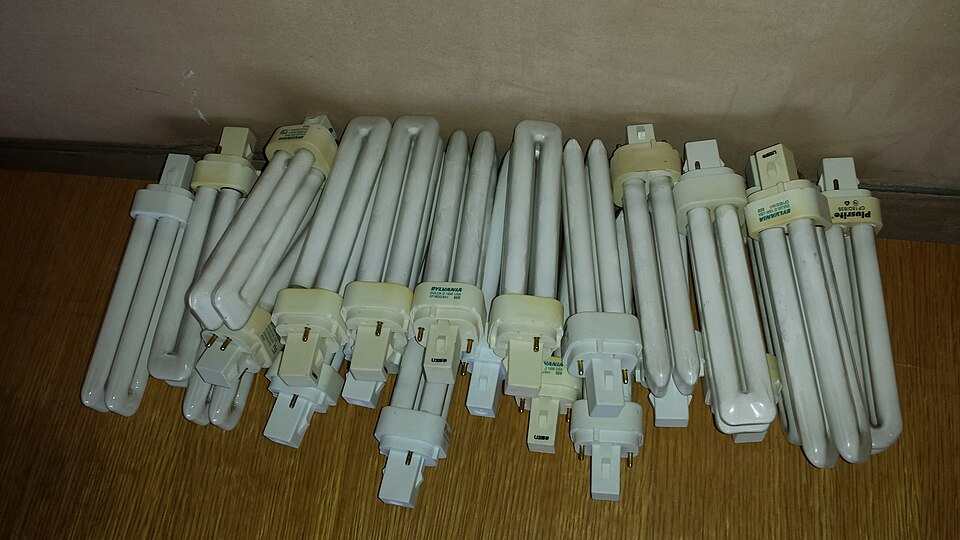


Saved expanded shortlist: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_fluorescent_candidates_v3.csv
Candidate count: 8
Licence metadata present: True
Creator/attribution present: True
Source hash matches existing candidates: False
Full-resolution images downloaded: 0
Prior shortlist overwritten: no
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no

Visual review and source-integrity audit are still required.


In [ ]:

from pathlib import Path
from io import BytesIO
from html import unescape
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

old_path = root / "commons_fluorescent_candidates_v2.csv"
new_path = root / "commons_fluorescent_candidates_v3.csv"

if not old_path.exists():
    raise FileNotFoundError(old_path)

old = pd.read_csv(old_path, dtype=str, keep_default_na=False)

candidate_id = "FLU_008"
title = "File:Pile of Compact Fluorescent Light Bulbs.jpg"

if candidate_id in set(old["candidate_id"]):
    raise ValueError(f"{candidate_id} already exists in the source shortlist.")

if old["file_title"].str.casefold().eq(title.casefold()).any():
    raise ValueError("This Commons file is already in the shortlist.")

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

response = session.get(
    "https://commons.wikimedia.org/w/api.php",
    params={
        "action": "query",
        "format": "json",
        "titles": title,
        "prop": "info|imageinfo",
        "inprop": "url",
        "iiprop": "url|sha1|size|mime|extmetadata",
        "iiurlwidth": 700,
    },
    timeout=60,
)
response.raise_for_status()
data = response.json()

if "error" in data:
    raise RuntimeError(f"Commons API error: {data['error']}")

pages = data.get("query", {}).get("pages", {})
page = next(iter(pages.values()), {})

if not page or "missing" in page:
    raise RuntimeError("The candidate file was not found on Commons.")

infos = page.get("imageinfo", [])
if not infos:
    raise RuntimeError("Commons returned no image information.")

info = infos[0]
ext = info.get("extmetadata", {})

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

def meta(key):
    value = ext.get(key, {})
    return clean(value.get("value", "")) if isinstance(value, dict) else clean(value)

sha1 = str(info.get("sha1", "")).strip().lower()
image_url = str(info.get("url", "")).strip()
thumb_url = str(info.get("thumburl", "")).strip()
source_url = str(page.get("canonicalurl", "")).strip()

if not sha1 or not image_url or not source_url:
    raise RuntimeError("Required source/hash metadata is missing.")

existing_hashes = set()
for col in [
    "commons_sha1", "live_sha1", "sha1",
    "expected_commons_sha1", "actual_sha1"
]:
    if col in old.columns:
        existing_hashes.update(
            str(v).strip().lower()
            for v in old[col]
            if str(v).strip()
        )

if sha1 in existing_hashes:
    raise RuntimeError(
        "This source hash matches an existing candidate. "
        "No new shortlist was written."
    )

row = {
    "candidate_id": candidate_id,
    "category": "Fluorescent lamps",
    "target_label": "hazardous",
    "file_title": str(page.get("title", title)),
    "source_page_url": source_url,
    "direct_image_url": image_url,
    "thumbnail_url": thumb_url or image_url,
    "commons_sha1": sha1,
    "license": meta("LicenseShortName"),
    "license_url": meta("LicenseUrl"),
    "author": meta("Artist"),
    "attribution": meta("Attribution") or meta("Credit"),
    "description": meta("ImageDescription"),
    "width": int(info.get("width", 0) or 0),
    "height": int(info.get("height", 0) or 0),
    "human_visual_check": "pending",
    "proposed_split": "unassigned",
    "approved_for_dataset": "no",
    "download_authorized": "no",
}

# Display current metadata for review before any full-resolution download.
print("NEW CANDIDATE — FLU_008")
display(pd.DataFrame([{
    "candidate_id": row["candidate_id"],
    "file_title": row["file_title"],
    "description": row["description"],
    "license": row["license"],
    "license_url": row["license_url"],
    "author": row["author"],
    "attribution": row["attribution"],
    "width": row["width"],
    "height": row["height"],
    "commons_sha1": row["commons_sha1"],
}]))

# The new file must expose licence and attribution metadata.
if not row["license"] or not row["license_url"]:
    raise RuntimeError(
        "Licence metadata is incomplete. Candidate was not added."
    )
if not (row["author"] or row["attribution"]):
    raise RuntimeError(
        "Creator/attribution is missing. Candidate was not added."
    )

# Download a thumbnail only for visual review.
preview_response = session.get(row["thumbnail_url"], timeout=30)
preview_response.raise_for_status()
image = Image.open(BytesIO(preview_response.content))
image = ImageOps.exif_transpose(image).convert("RGB")
display(image)

# Append to a new shortlist; preserve the old file unchanged.
for col in old.columns:
    if col not in row:
        row[col] = ""
for col in row:
    if col not in old.columns:
        old[col] = ""

combined = pd.concat(
    [old, pd.DataFrame([row])],
    ignore_index=True,
).fillna("")

combined.to_csv(new_path, index=False)

print("\nSaved expanded shortlist:", new_path)
print("Candidate count:", len(combined))
print("Licence metadata present:", bool(row["license"] and row["license_url"]))
print("Creator/attribution present:", bool(row["author"] or row["attribution"]))
print("Source hash matches existing candidates:", False)
print("Full-resolution images downloaded: 0")
print("Prior shortlist overwritten: no")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")
print("\nVisual review and source-integrity audit are still required.")


In [ ]:

from pathlib import Path
import pandas as pd

# ============================================================
# WasteLens — Fluorescent Candidate Visual Review v2
# No interactive input(), no downloads, no model changes.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

SOURCE_FILE = ROOT / "commons_fluorescent_candidates_v3.csv"
PREVIOUS_REVIEW_FILE = ROOT / "pilot_fluorescent_visual_review_v1.csv"
OUTPUT_FILE = ROOT / "pilot_fluorescent_visual_review_v2.csv"

# Your visual decision for the new candidate.
FLU_008_DECISION = "accept"

# 1. Verify required files.
for path in [SOURCE_FILE, PREVIOUS_REVIEW_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

sources = pd.read_csv(
    SOURCE_FILE, dtype=str, keep_default_na=False
)
previous = pd.read_csv(
    PREVIOUS_REVIEW_FILE, dtype=str, keep_default_na=False
)

for col in ["candidate_id", "file_title"]:
    if col not in sources.columns:
        raise ValueError(f"Source shortlist is missing column: {col}")

if "candidate_id" not in previous.columns:
    raise ValueError("Previous review is missing candidate_id.")

if sources["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in source shortlist.")

if previous["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in previous review.")

# 2. Find FLU_008 source metadata.
new_matches = sources.loc[sources["candidate_id"] == "FLU_008"]

if len(new_matches) != 1:
    raise ValueError(
        f"Expected exactly one FLU_008 source record; found {len(new_matches)}."
    )

source = new_matches.iloc[0]

# Keep this consistent with the candidate metadata review.
for col in ["source_page_url", "commons_sha1", "license", "license_url"]:
    if col not in sources.columns or not str(source.get(col, "")).strip():
        raise ValueError(
            f"FLU_008 is missing required source metadata: {col}"
        )

if FLU_008_DECISION not in {"accept", "reject", "hold"}:
    raise ValueError("FLU_008_DECISION must be accept, reject, or hold.")

# 3. Copy the previous review; never overwrite v1.
review = previous.copy()

# Ensure columns needed by the revised review exist.
required_review_columns = [
    "candidate_id",
    "file_title",
    "source_page_url",
    "commons_sha1",
    "license",
    "license_url",
    "author",
    "attribution",
    "human_visual_check",
    "proposed_slot_id",
    "proposed_split",
    "target_label",
    "source_group_id",
    "visual_review_notes",
    "approved_for_dataset",
    "download_authorized",
    "integrity_check",
]

for col in required_review_columns:
    if col not in review.columns:
        review[col] = ""

# 4. Move FLU_004 to hold.
# It depicts an installed fluorescent tube rather than discarded waste.
mask_004 = review["candidate_id"].eq("FLU_004")

if int(mask_004.sum()) != 1:
    raise ValueError(
        f"Expected one FLU_004 review record; found {int(mask_004.sum())}."
    )

review.loc[mask_004, "human_visual_check"] = "hold"
review.loc[mask_004, "proposed_slot_id"] = ""
review.loc[mask_004, "proposed_split"] = "hold"
review.loc[mask_004, "target_label"] = ""
review.loc[mask_004, "visual_review_notes"] = (
    "Held from hazardous-waste training: image depicts an installed "
    "fluorescent lamp fixture, not clearly discarded waste."
)
review.loc[mask_004, "approved_for_dataset"] = "no"
review.loc[mask_004, "download_authorized"] = "no"
review.loc[mask_004, "integrity_check"] = "pending"

# 5. Construct the FLU_008 review record from its saved source metadata.
if (review["candidate_id"] == "FLU_008").any():
    raise ValueError(
        "FLU_008 is already in the previous review. "
        "Stopping to avoid duplicating or silently replacing it."
    )

if FLU_008_DECISION == "accept":
    flu008_slot = "fluorescent_lamps_train_003"
    flu008_split = "train"
    flu008_target = "hazardous"
    flu008_notes = (
        "Visually accepted: the provided preview shows a pile of used "
        "fluorescent-style bulbs. Dataset approval still pending."
    )
else:
    flu008_slot = ""
    flu008_split = "hold"
    flu008_target = ""
    flu008_notes = (
        f"Visual decision recorded as {FLU_008_DECISION}; "
        "not assigned to a dataset slot."
    )

new_record = {
    "candidate_id": "FLU_008",
    "file_title": source.get("file_title", ""),
    "source_page_url": source.get("source_page_url", ""),
    "commons_sha1": source.get("commons_sha1", ""),
    "license": source.get("license", ""),
    "license_url": source.get("license_url", ""),
    "author": source.get("author", ""),
    "attribution": source.get("attribution", ""),
    "human_visual_check": FLU_008_DECISION,
    "proposed_slot_id": flu008_slot,
    "proposed_split": flu008_split,
    "target_label": flu008_target,
    "source_group_id": "used_compact_fluorescent_bulbs",
    "visual_review_notes": flu008_notes,
    "approved_for_dataset": "no",
    "download_authorized": "no",
    "integrity_check": "pending",
}

# Align the new record to the existing review columns.
for col in review.columns:
    if col not in new_record:
        new_record[col] = ""

review = pd.concat(
    [review, pd.DataFrame([new_record])[review.columns]],
    ignore_index=True,
)

# 6. Validate IDs and proposed assignments.
if review["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in revised review.")

assigned = review[review["proposed_slot_id"].str.strip() != ""]

if assigned["proposed_slot_id"].duplicated().any():
    duplicates = assigned.loc[
        assigned["proposed_slot_id"].duplicated(False),
        "proposed_slot_id"
    ].tolist()
    raise ValueError(f"Duplicate slot assignments detected: {duplicates}")

expected_train_slots = {
    "fluorescent_lamps_train_001",
    "fluorescent_lamps_train_002",
    "fluorescent_lamps_train_003",
    "fluorescent_lamps_train_004",
}

actual_train_slots = set(
    assigned.loc[
        assigned["proposed_split"] == "train", "proposed_slot_id"
    ]
)

if FLU_008_DECISION == "accept" and actual_train_slots != expected_train_slots:
    raise ValueError(
        "The four expected training slots are not assigned correctly. "
        f"Found: {sorted(actual_train_slots)}"
    )

# No candidate is finally approved by this review cell.
review["approved_for_dataset"] = "no"
review["download_authorized"] = "no"

# 7. Save a new review file.
review.to_csv(OUTPUT_FILE, index=False)

print("Saved revised visual review:", OUTPUT_FILE)
print("FLU_008 decision:", FLU_008_DECISION)
print("FLU_004 status: hold")

display(
    review[
        [
            "candidate_id",
            "human_visual_check",
            "proposed_slot_id",
            "proposed_split",
            "approved_for_dataset",
            "download_authorized",
        ]
    ].sort_values("candidate_id")
)

print("\nReview records:", len(review))
print(
    "Provisional training slots:",
    int((assigned["proposed_split"] == "train").sum())
)
print(
    "Provisional threshold-validation slots:",
    int((assigned["proposed_split"] == "threshold_validation").sum())
)
print("Dataset approvals: 0")
print("Full-resolution downloads performed: 0")
print("Earlier review v1 overwritten: no")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved revised visual review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_visual_review_v2.csv
FLU_008 decision: accept
FLU_004 status: hold


,candidate_id,human_visual_check,proposed_slot_id,proposed_split,approved_for_dataset,download_authorized
0,FLU_001,accept,fluorescent_lamps_train_001,train,no,no
1,FLU_002,reject,,hold,no,no
2,FLU_003,reject,,hold,no,no
3,FLU_004,hold,,hold,no,no
4,FLU_005,accept,fluorescent_lamps_train_002,train,no,no
5,FLU_006,accept,fluorescent_lamps_train_004,train,no,no
6,FLU_007,accept,fluorescent_lamps_threshold_validation_001,threshold_validation,no,no
7,FLU_008,accept,fluorescent_lamps_train_003,train,no,no



Review records: 8
Provisional training slots: 4
Provisional threshold-validation slots: 1
Dataset approvals: 0
Full-resolution downloads performed: 0
Earlier review v1 overwritten: no
Combined pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from html import unescape
import re
import requests
import pandas as pd

# ============================================================
# WasteLens: fluorescent-lamp source-integrity audit v2
# Metadata only: no full-resolution downloads or model changes.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

REVIEW_FILE = ROOT / "pilot_fluorescent_visual_review_v2.csv"
SHORTLIST_FILE = ROOT / "commons_fluorescent_candidates_v3.csv"
AUDIT_FILE = ROOT / "pilot_fluorescent_source_integrity_audit_v2.csv"

for path in [REVIEW_FILE, SHORTLIST_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Required file is missing: {path}")

review = pd.read_csv(REVIEW_FILE, dtype=str, keep_default_na=False)
sources = pd.read_csv(SHORTLIST_FILE, dtype=str, keep_default_na=False)

required_review = {
    "candidate_id", "human_visual_check",
    "proposed_slot_id", "proposed_split"
}
required_sources = {
    "candidate_id", "file_title", "commons_sha1",
    "license", "license_url", "source_page_url"
}

if not required_review.issubset(review.columns):
    raise ValueError(
        f"Review CSV missing: {required_review - set(review.columns)}"
    )

if not required_sources.issubset(sources.columns):
    raise ValueError(
        f"Shortlist missing: {required_sources - set(sources.columns)}"
    )

if review["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in visual review.")

if sources["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in source shortlist.")

# Only accepted candidates explicitly assigned to pilot slots are audited.
selected = review[
    (review["human_visual_check"] == "accept")
    & (review["proposed_slot_id"].str.strip() != "")
].copy()

expected_train = {
    "fluorescent_lamps_train_001",
    "fluorescent_lamps_train_002",
    "fluorescent_lamps_train_003",
    "fluorescent_lamps_train_004",
}
expected_val = {"fluorescent_lamps_threshold_validation_001"}

actual_train = set(
    selected.loc[
        selected["proposed_split"] == "train", "proposed_slot_id"
    ]
)
actual_val = set(
    selected.loc[
        selected["proposed_split"] == "threshold_validation",
        "proposed_slot_id"
    ]
)

if len(selected) != 5:
    raise ValueError(
        f"Expected 5 assigned candidates, found {len(selected)}."
    )

if actual_train != expected_train or actual_val != expected_val:
    raise ValueError(
        "Proposed slot coverage is incorrect.\n"
        f"Training slots found: {sorted(actual_train)}\n"
        f"Validation slots found: {sorted(actual_val)}"
    )

source_by_id = sources.set_index("candidate_id", drop=False)

missing = [
    cid for cid in selected["candidate_id"]
    if cid not in source_by_id.index
]
if missing:
    raise ValueError(
        f"Selected candidates missing from source shortlist: {missing}"
    )

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

def meta_value(ext, key):
    value = ext.get(key, {})
    if isinstance(value, dict):
        return clean(value.get("value", ""))
    return clean(value)

# Live metadata request to Wikimedia Commons.
API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

request_titles = [
    str(source_by_id.loc[cid, "file_title"]).strip()
    for cid in selected["candidate_id"]
]

response = session.get(
    API,
    params={
        "action": "query",
        "format": "json",
        "titles": "|".join(request_titles),
        "prop": "info|imageinfo",
        "inprop": "url",
        "iiprop": "url|sha1|size|mime|extmetadata",
    },
    timeout=60,
)
response.raise_for_status()

payload = response.json()
if "error" in payload:
    raise RuntimeError(f"Commons API error: {payload['error']}")

pages = payload.get("query", {}).get("pages", {})
pages_by_title = {
    str(page.get("title", "")).casefold(): page
    for page in pages.values()
}

rows = []

for _, assignment in selected.iterrows():
    cid = assignment["candidate_id"]
    source = source_by_id.loc[cid]
    title = str(source["file_title"]).strip()

    page = pages_by_title.get(title.casefold())

    if page is None or "missing" in page:
        rows.append({
            "candidate_id": cid,
            "file_title": title,
            "proposed_slot_id": assignment["proposed_slot_id"],
            "proposed_split": assignment["proposed_split"],
            "source_metadata_integrity_pass": False,
            "audit_status": "FAIL_SOURCE_NOT_FOUND",
            "approved_for_dataset": "no",
            "download_authorized": "no",
        })
        continue

    imageinfo = page.get("imageinfo", [])
    if not imageinfo:
        rows.append({
            "candidate_id": cid,
            "file_title": title,
            "proposed_slot_id": assignment["proposed_slot_id"],
            "proposed_split": assignment["proposed_split"],
            "source_metadata_integrity_pass": False,
            "audit_status": "FAIL_NO_IMAGEINFO",
            "approved_for_dataset": "no",
            "download_authorized": "no",
        })
        continue

    info = imageinfo[0]
    ext = info.get("extmetadata", {})

    expected_sha1 = str(source["commons_sha1"]).strip().lower()
    live_sha1 = str(info.get("sha1", "")).strip().lower()

    expected_license = clean(source["license"]).casefold()
    live_license = meta_value(ext, "LicenseShortName").casefold()
    live_license_url = meta_value(ext, "LicenseUrl")

    creator = meta_value(ext, "Artist")
    attribution = (
        meta_value(ext, "Attribution")
        or meta_value(ext, "Credit")
    )

    width = int(info.get("width", 0) or 0)
    height = int(info.get("height", 0) or 0)
    mime = str(info.get("mime", "")).strip().lower()

    checks = {
        "source_hash_match": bool(
            expected_sha1 and live_sha1 and expected_sha1 == live_sha1
        ),
        "license_match": bool(
            expected_license and live_license == expected_license
        ),
        "live_license_url_present": bool(live_license_url),
        "creator_or_attribution_present": bool(creator or attribution),
        "dimensions_ok": width >= 800 and height >= 600,
        "image_mime_ok": mime.startswith("image/"),
        "source_page_and_image_url_present": bool(
            page.get("canonicalurl") and info.get("url")
        ),
    }

    # Keep visual/taxonomy caveats visible for later review.
    semantic_warning = ""
    if cid == "FLU_005":
        semantic_warning = (
            "Collection-point context; confirm it is appropriate for "
            "the defined hazardous-waste image class."
        )
    elif cid == "FLU_006":
        semantic_warning = (
            "Contains mixed lamp types; fluorescent tubes are visible."
        )
    elif cid == "FLU_007":
        semantic_warning = (
            "Threshold-validation image; keep separate from training."
        )
    elif cid == "FLU_008":
        semantic_warning = (
            "Source describes a pile of used compact fluorescent bulbs."
        )

    rows.append({
        "candidate_id": cid,
        "file_title": title,
        "proposed_slot_id": assignment["proposed_slot_id"],
        "proposed_split": assignment["proposed_split"],
        "target_label": "hazardous",
        "live_source_page": page.get("canonicalurl", ""),
        "expected_sha1": expected_sha1,
        "live_sha1": live_sha1,
        **checks,
        "live_license": live_license,
        "live_license_url": live_license_url,
        "creator": creator,
        "attribution": attribution,
        "width": width,
        "height": height,
        "mime": mime,
        "semantic_warning": semantic_warning,
        "source_metadata_integrity_pass": all(checks.values()),
        "audit_status": (
            "PASS_SOURCE_METADATA_ONLY"
            if all(checks.values())
            else "FAIL_ONE_OR_MORE_SOURCE_CHECKS"
        ),
        "approved_for_dataset": "no",
        "download_authorized": "no",
    })

audit = pd.DataFrame(rows)

# Cross-candidate duplicate hash check.
live_hashes = audit["live_sha1"].fillna("").str.lower()
hash_counts = live_hashes[live_hashes != ""].value_counts()

audit["duplicate_live_sha1"] = live_hashes.map(
    lambda value: bool(value and hash_counts.get(value, 0) > 1)
)

duplicate_mask = audit["duplicate_live_sha1"]
audit.loc[duplicate_mask, "source_metadata_integrity_pass"] = False
audit.loc[duplicate_mask, "audit_status"] = "FAIL_DUPLICATE_SOURCE_HASH"

# Save a new report; prior audit files remain untouched.
audit.to_csv(AUDIT_FILE, index=False)

print("Saved updated source-integrity audit:", AUDIT_FILE)
display(audit[[
    "candidate_id",
    "proposed_slot_id",
    "proposed_split",
    "source_hash_match",
    "license_match",
    "creator_or_attribution_present",
    "dimensions_ok",
    "duplicate_live_sha1",
    "source_metadata_integrity_pass",
    "audit_status",
    "semantic_warning",
]])

print("\nCandidates checked:", len(audit))
print(
    "Source-metadata passes:",
    int(audit["source_metadata_integrity_pass"].sum())
)
print(
    "Distinct nonempty live hashes:",
    int(live_hashes[live_hashes != ""].nunique())
)
print("Dataset approvals granted: 0")
print("Full-resolution images downloaded: 0")
print("Previous audits overwritten: no")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved updated source-integrity audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_source_integrity_audit_v2.csv


,candidate_id,proposed_slot_id,proposed_split,source_hash_match,license_match,creator_or_attribution_present,dimensions_ok,duplicate_live_sha1,source_metadata_integrity_pass,audit_status,semantic_warning
0,FLU_001,fluorescent_lamps_train_001,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,
1,FLU_005,fluorescent_lamps_train_002,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,Collection-point context; confirm it is appropriate for the defined hazardous-waste image class.
2,FLU_006,fluorescent_lamps_train_004,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,Contains mixed lamp types; fluorescent tubes are visible.
3,FLU_007,fluorescent_lamps_threshold_validation_001,threshold_validation,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,Threshold-validation image; keep separate from training.
4,FLU_008,fluorescent_lamps_train_003,train,True,True,True,True,False,True,PASS_SOURCE_METADATA_ONLY,Source describes a pile of used compact fluorescent bulbs.



Candidates checked: 5
Source-metadata passes: 5
Distinct nonempty live hashes: 5
Dataset approvals granted: 0
Full-resolution images downloaded: 0
Previous audits overwritten: no
Combined pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from io import BytesIO
from datetime import datetime, timezone, timedelta
from email.utils import parsedate_to_datetime
import hashlib
import re
import requests
import pandas as pd
from PIL import Image, ImageOps

# ============================================================
# WasteLens: resumable fluorescent-image downloader
# Respects HTTP 429/503 Retry-After and saves progress per file.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
AUDIT_FILE = ROOT / "pilot_fluorescent_source_integrity_audit_v2.csv"
REVIEW_FILE = ROOT / "pilot_fluorescent_visual_review_v2.csv"

STAGING = ROOT / "acquired_images_v2"
PROGRESS_FILE = ROOT / "pilot_fluorescent_download_progress_v1.csv"
MANIFEST_FILE = ROOT / "pilot_fluorescent_download_manifest_v1.csv"
RECEIPT_FILE = ROOT / "pilot_fluorescent_download_receipt_v1.csv"

STAGING.mkdir(parents=True, exist_ok=True)

EXPECTED_IDS = {"FLU_001", "FLU_005", "FLU_006", "FLU_007", "FLU_008"}
API = "https://commons.wikimedia.org/w/api.php"

# Identify the client clearly. Keep requests serial and low-volume.
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensPilotDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    ),
    "Accept-Encoding": "gzip",
})

def utc_now():
    return datetime.now(timezone.utc)

def utc_iso(dt):
    return dt.astimezone(timezone.utc).isoformat()

def parse_retry_after(response):
    """
    Respect Retry-After if supplied; otherwise use a conservative
    backoff. Never retry the rate-limited request immediately.
    """
    value = response.headers.get("Retry-After", "").strip()

    if value:
        if value.isdigit():
            return utc_now() + timedelta(seconds=int(value))
        try:
            parsed = parsedate_to_datetime(value)
            if parsed.tzinfo is None:
                parsed = parsed.replace(tzinfo=timezone.utc)
            return max(parsed.astimezone(timezone.utc), utc_now())
        except (TypeError, ValueError, OverflowError):
            pass

    # Conservative fallback if the server omits an interpretable header.
    return utc_now() + timedelta(seconds=60)

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def meta_value(ext, key):
    val = ext.get(key, {})
    if isinstance(val, dict):
        return clean(val.get("value", ""))
    return clean(val)

def sha1_bytes(data):
    return hashlib.sha1(data).hexdigest().lower()

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest().lower()

def inspect_image(data):
    # Verify and decode without converting or re-encoding source bytes.
    with Image.open(BytesIO(data)) as im:
        im.verify()

    with Image.open(BytesIO(data)) as im:
        im.load()
        fmt = str(im.format or "")
        width, height = im.size
        oriented_size = ImageOps.exif_transpose(im).size

    if width < 800 or height < 600:
        raise ValueError(f"Unexpectedly small source image: {width}x{height}")

    return fmt, width, height, oriented_size

def save_progress(state):
    pd.DataFrame(list(state.values())).to_csv(PROGRESS_FILE, index=False)

def stop_for_error(state, cid, status, message, retry_until=""):
    state[cid]["status"] = status
    state[cid]["last_error"] = str(message)[:1000]
    state[cid]["retry_after_until_utc"] = retry_until
    save_progress(state)

    print(f"\nStopped safely at {cid}: {status}")
    print("Reason:", message)
    if retry_until:
        print("Do not retry before (UTC):", retry_until)
    print("Progress saved:", PROGRESS_FILE)
    print("Successfully staged earlier files have been preserved.")
    print("No final manifest is written until all five images pass.")
    print("Dataset approvals granted: 0")
    print("Model weights changed: no")
    print("Locked test set touched: no")

# 1. Load and validate the approved-for-staging candidate list.
for path in [AUDIT_FILE, REVIEW_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

audit = pd.read_csv(AUDIT_FILE, dtype=str, keep_default_na=False)
review = pd.read_csv(REVIEW_FILE, dtype=str, keep_default_na=False)

if audit["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in source audit.")
if review["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in revised visual review.")

selected = audit[
    audit["candidate_id"].isin(EXPECTED_IDS)
    & audit["audit_status"].eq("PASS_SOURCE_METADATA_ONLY")
    & audit["source_metadata_integrity_pass"].str.casefold().eq("true")
].copy()

if set(selected["candidate_id"]) != EXPECTED_IDS or len(selected) != 5:
    raise ValueError(
        "The expected five candidates do not all have passing source audits."
    )

review_by_id = review.set_index("candidate_id", drop=False)

for _, row in selected.iterrows():
    cid = row["candidate_id"]
    if cid not in review_by_id.index:
        raise ValueError(f"{cid} missing from visual review.")

    rv = review_by_id.loc[cid]
    if rv["human_visual_check"] != "accept":
        raise ValueError(f"{cid} is not visually accepted.")
    if rv["proposed_slot_id"] != row["proposed_slot_id"]:
        raise ValueError(f"Slot mismatch for {cid}.")
    if rv["proposed_split"] != row["proposed_split"]:
        raise ValueError(f"Split mismatch for {cid}.")

if selected["proposed_slot_id"].duplicated().any():
    raise ValueError("Duplicate proposed slot IDs.")

# 2. Load any previous progress. A cooldown must be respected across reruns.
if PROGRESS_FILE.exists():
    previous_progress = pd.read_csv(
        PROGRESS_FILE, dtype=str, keep_default_na=False
    )
else:
    previous_progress = pd.DataFrame()

state = {}

for _, row in selected.iterrows():
    cid = row["candidate_id"]
    previous_row = {}

    if (
        not previous_progress.empty
        and "candidate_id" in previous_progress.columns
    ):
        matches = previous_progress[
            previous_progress["candidate_id"] == cid
        ]
        if len(matches) > 1:
            raise ValueError(f"Duplicate progress records for {cid}.")
        if len(matches) == 1:
            previous_row = matches.iloc[0].to_dict()

    state[cid] = {
        "candidate_id": cid,
        "slot_id": row["proposed_slot_id"],
        "split": row["proposed_split"],
        "source_sha1": str(row["live_sha1"]).strip().lower(),
        "image_path": str(
            STAGING / f'{row["proposed_slot_id"]}.jpg'
        ),
        "status": previous_row.get("status", "PENDING"),
        "actual_sha1": previous_row.get("actual_sha1", ""),
        "sha256": previous_row.get("sha256", ""),
        "file_bytes": previous_row.get("file_bytes", ""),
        "width": previous_row.get("width", ""),
        "height": previous_row.get("height", ""),
        "image_format": previous_row.get("image_format", ""),
        "last_error": previous_row.get("last_error", ""),
        "retry_after_until_utc": previous_row.get(
            "retry_after_until_utc", ""
        ),
    }

# If a previous run was rate-limited, do not send ANY new requests during
# the recorded cooldown.
future_cooldowns = []

for item in state.values():
    raw = item["retry_after_until_utc"]
    if raw:
        try:
            dt = datetime.fromisoformat(raw.replace("Z", "+00:00"))
            if dt.tzinfo is None:
                dt = dt.replace(tzinfo=timezone.utc)
            if dt > utc_now():
                future_cooldowns.append(dt)
        except ValueError:
            pass

if future_cooldowns:
    earliest_allowed = max(future_cooldowns)
    print("Rate-limit cooldown is still active.")
    print("Respect Wikimedia's Retry-After instruction.")
    print("Try again no earlier than (UTC):", utc_iso(earliest_allowed))
    print("No network requests made in this run.")
    print("Existing staged files and progress were left unchanged.")
else:
    # 3. Get current Commons metadata in one batch request.
    titles = selected["file_title"].tolist()

    try:
        response = session.get(
            API,
            params={
                "action": "query",
                "format": "json",
                "titles": "|".join(titles),
                "prop": "info|imageinfo",
                "inprop": "url",
                "iiprop": "url|sha1|size|mime|extmetadata",
            },
            timeout=60,
        )

        if response.status_code in (429, 503):
            retry_until = utc_iso(parse_retry_after(response))
            message = (
                f"Commons API returned HTTP {response.status_code}; "
                f"Retry-After={response.headers.get('Retry-After', 'not supplied')}"
            )
            for cid in state:
                if state[cid]["status"] != "STAGED_VERIFIED":
                    state[cid]["status"] = "RATE_LIMITED"
                    state[cid]["last_error"] = message
                    state[cid]["retry_after_until_utc"] = retry_until
            save_progress(state)
            print(message)
            print("Recorded cooldown (UTC):", retry_until)
            print("No retry attempted in this run.")
        else:
            response.raise_for_status()
            payload = response.json()

            if "error" in payload:
                raise RuntimeError(f"Commons API error: {payload['error']}")

            pages = payload.get("query", {}).get("pages", {})
            pages_by_title = {
                str(page.get("title", "")).casefold(): page
                for page in pages.values()
            }

            metadata_by_id = {}
            stopped = False

            # 4. Process candidates serially. Each passing image is saved
            # immediately so a later failure doesn't discard earlier work.
            for _, row in selected.iterrows():
                cid = row["candidate_id"]
                title = row["file_title"]
                item_state = state[cid]

                page = pages_by_title.get(title.casefold())
                if page is None or "missing" in page:
                    stop_for_error(
                        state, cid, "SOURCE_NOT_FOUND",
                        "Source file not found in current Commons response."
                    )
                    stopped = True
                    break

                infos = page.get("imageinfo", [])
                if not infos:
                    stop_for_error(
                        state, cid, "NO_IMAGEINFO",
                        "Current Commons response contains no image metadata."
                    )
                    stopped = True
                    break

                info = infos[0]
                ext = info.get("extmetadata", {})

                live_sha1 = str(info.get("sha1", "")).strip().lower()
                expected_sha1 = item_state["source_sha1"]
                live_license = meta_value(ext, "LicenseShortName")
                expected_license = str(row["live_license"]).strip()
                license_url = meta_value(ext, "LicenseUrl")
                creator = meta_value(ext, "Artist")
                attribution = (
                    meta_value(ext, "Attribution")
                    or meta_value(ext, "Credit")
                )
                original_url = str(info.get("url", "")).strip()
                source_page = str(page.get("canonicalurl", "")).strip()
                mime = str(info.get("mime", "")).strip().lower()

                if not expected_sha1 or live_sha1 != expected_sha1:
                    stop_for_error(
                        state, cid, "SOURCE_HASH_CHANGED",
                        "Current Commons SHA-1 differs from the passing audit."
                    )
                    stopped = True
                    break

                if live_license.casefold() != expected_license.casefold():
                    stop_for_error(
                        state, cid, "LICENSE_CHANGED",
                        "Current licence label differs from the passing audit."
                    )
                    stopped = True
                    break

                if not license_url or not (creator or attribution):
                    stop_for_error(
                        state, cid, "LICENCE_ATTRIBUTION_INCOMPLETE",
                        "Live licence URL or attribution information is missing."
                    )
                    stopped = True
                    break

                if not original_url or not source_page or not mime.startswith("image/"):
                    stop_for_error(
                        state, cid, "INVALID_SOURCE_METADATA",
                        "Missing original URL, source page, or image MIME type."
                    )
                    stopped = True
                    break

                metadata_by_id[cid] = {
                    "source_page_url": source_page,
                    "license": live_license,
                    "license_url": license_url,
                    "creator": creator,
                    "attribution": attribution,
                    "mime": mime,
                }

                destination = Path(item_state["image_path"])

                # Reuse a staged file only if its hash matches and it decodes.
                if destination.exists():
                    existing_bytes = destination.read_bytes()
                    existing_sha1 = sha1_bytes(existing_bytes)

                    if existing_sha1 != expected_sha1:
                        stop_for_error(
                            state, cid, "EXISTING_FILE_HASH_MISMATCH",
                            f"Refusing to overwrite existing file: {destination}"
                        )
                        stopped = True
                        break

                    try:
                        fmt, width, height, _ = inspect_image(existing_bytes)
                    except Exception as exc:
                        stop_for_error(
                            state, cid, "EXISTING_FILE_DECODE_FAILURE", str(exc)
                        )
                        stopped = True
                        break

                    item_state.update({
                        "status": "STAGED_VERIFIED",
                        "actual_sha1": existing_sha1,
                        "sha256": sha256_bytes(existing_bytes),
                        "file_bytes": len(existing_bytes),
                        "width": width,
                        "height": height,
                        "image_format": fmt,
                        "last_error": "",
                        "retry_after_until_utc": "",
                    })
                    save_progress(state)
                    print(f"{cid}: existing matching file verified.")
                    continue

                # Download one image only. No parallel requests.
                try:
                    download = session.get(
                        original_url,
                        timeout=120,
                        stream=True,
                    )

                    if download.status_code in (429, 503):
                        retry_until = utc_iso(parse_retry_after(download))
                        message = (
                            f"Original-image host returned HTTP "
                            f"{download.status_code}; Retry-After="
                            f"{download.headers.get('Retry-After', 'not supplied')}"
                        )
                        download.close()
                        stop_for_error(
                            state, cid, "RATE_LIMITED",
                            message, retry_until
                        )
                        stopped = True
                        break

                    download.raise_for_status()

                    chunks = []
                    for chunk in download.iter_content(chunk_size=512 * 1024):
                        if chunk:
                            chunks.append(chunk)
                    download.close()
                    image_bytes = b"".join(chunks)

                except requests.RequestException as exc:
                    stop_for_error(
                        state, cid, "DOWNLOAD_FAILED", repr(exc)
                    )
                    stopped = True
                    break

                if not image_bytes:
                    stop_for_error(
                        state, cid, "EMPTY_DOWNLOAD", "The response body was empty."
                    )
                    stopped = True
                    break

                actual_sha1 = sha1_bytes(image_bytes)
                actual_sha256 = sha256_bytes(image_bytes)

                if actual_sha1 != expected_sha1:
                    stop_for_error(
                        state, cid, "DOWNLOADED_HASH_MISMATCH",
                        f"Expected SHA-1 {expected_sha1}, got {actual_sha1}."
                    )
                    stopped = True
                    break

                try:
                    fmt, width, height, _ = inspect_image(image_bytes)
                except Exception as exc:
                    stop_for_error(
                        state, cid, "IMAGE_DECODE_FAILURE", repr(exc)
                    )
                    stopped = True
                    break

                # Atomic write of this one verified source file.
                temp_path = destination.with_suffix(".jpg.part")
                try:
                    temp_path.write_bytes(image_bytes)

                    temp_sha1 = sha1_bytes(temp_path.read_bytes())
                    if temp_sha1 != expected_sha1:
                        raise RuntimeError(
                            "Temporary staged image failed SHA-1 verification."
                        )

                    temp_path.replace(destination)
                except Exception:
                    if temp_path.exists():
                        temp_path.unlink()
                    raise

                item_state.update({
                    "status": "STAGED_VERIFIED",
                    "actual_sha1": actual_sha1,
                    "sha256": actual_sha256,
                    "file_bytes": len(image_bytes),
                    "width": width,
                    "height": height,
                    "image_format": fmt,
                    "last_error": "",
                    "retry_after_until_utc": "",
                })
                save_progress(state)
                print(
                    f"{cid}: staged and verified "
                    f"({width}x{height}; SHA-1 matched)."
                )

            # 5. Write final files only if all five staged assets pass.
            if not stopped and all(
                state[cid]["status"] == "STAGED_VERIFIED"
                for cid in state
            ):
                manifest_rows = []
                receipt_rows = []

                for _, row in selected.iterrows():
                    cid = row["candidate_id"]
                    item = state[cid]
                    md = metadata_by_id[cid]
                    path = Path(item["image_path"])

                    final_bytes = path.read_bytes()
                    final_sha1 = sha1_bytes(final_bytes)
                    final_sha256 = sha256_bytes(final_bytes)
                    fmt, width, height, _ = inspect_image(final_bytes)

                    if final_sha1 != item["source_sha1"]:
                        raise RuntimeError(
                            f"Final file hash mismatch for {cid}."
                        )

                    attribution_text = (
                        md["attribution"] or md["creator"]
                    )

                    manifest_rows.append({
                        "candidate_id": cid,
                        "slot_id": item["slot_id"],
                        "split": item["split"],
                        "target_label": "hazardous",
                        "image_path": str(path),
                        "source_page_url": md["source_page_url"],
                        "license_or_permission": (
                            f'{md["license"]} | {md["license_url"]} | '
                            f'Creator: {md["creator"]} | '
                            f'Attribution: {attribution_text}'
                        ),
                        "source_group_id": cid,
                        "expected_source_sha1": item["source_sha1"],
                        "actual_file_sha1": final_sha1,
                        "sha256": final_sha256,
                        "file_bytes": len(final_bytes),
                        "width": width,
                        "height": height,
                        "image_format": fmt,
                        "mime": md["mime"],
                        "file_integrity_verified": "yes",
                        "staged": "yes",
                        "approved_for_dataset": "no",
                        "training_eligible": "no",
                        "notes": (
                            "Staged and byte-verified. Dataset taxonomy and "
                            "final approval remain pending."
                        ),
                    })

                    receipt_rows.append({
                        "candidate_id": cid,
                        "slot_id": item["slot_id"],
                        "image_path": str(path),
                        "source_sha1": item["source_sha1"],
                        "downloaded_file_sha1": final_sha1,
                        "sha256": final_sha256,
                        "sha1_match": "yes",
                        "image_decode_verified": "yes",
                        "file_bytes": len(final_bytes),
                        "result": "PASS",
                    })

                pd.DataFrame(manifest_rows).to_csv(
                    MANIFEST_FILE, index=False
                )
                pd.DataFrame(receipt_rows).to_csv(
                    RECEIPT_FILE, index=False
                )

                print("\nALL FIVE IMAGE FILES STAGED AND VERIFIED.")
                print("Saved download manifest:", MANIFEST_FILE)
                print("Saved download receipt:", RECEIPT_FILE)

            elif not stopped:
                print(
                    "Some candidates are not yet verified. "
                    "Final manifest not written."
                )

    except requests.RequestException as exc:
        print("\nMetadata/API request failed:", repr(exc))
        print("No immediate retry was attempted.")
        save_progress(state)
        print("Current progress saved:", PROGRESS_FILE)

# 6. Always print the resumable status.
print("\nCURRENT DOWNLOAD PROGRESS")
display(pd.DataFrame(list(state.values()))[
    [
        "candidate_id", "slot_id", "split", "status",
        "image_path", "actual_sha1", "last_error",
        "retry_after_until_utc"
    ]
])

print("\nProgress file:", PROGRESS_FILE)
print("Dataset approvals granted: 0")
print("Training eligibility granted: 0")
print("Combined pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


FLU_001: staged and verified (1800x3200; SHA-1 matched).
FLU_005: staged and verified (4032x3024; SHA-1 matched).
FLU_006: staged and verified (4592x3448; SHA-1 matched).
FLU_007: staged and verified (1210x1600; SHA-1 matched).
FLU_008: staged and verified (4128x2322; SHA-1 matched).

ALL FIVE IMAGE FILES STAGED AND VERIFIED.
Saved download manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_download_manifest_v1.csv
Saved download receipt: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_download_receipt_v1.csv

CURRENT DOWNLOAD PROGRESS


,candidate_id,slot_id,split,status,image_path,actual_sha1,last_error,retry_after_until_utc
0,FLU_001,fluorescent_lamps_train_001,train,STAGED_VERIFIED,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_001.jpg,10413b59a852c64de5b67fb154d605442b8434dc,,
1,FLU_005,fluorescent_lamps_train_002,train,STAGED_VERIFIED,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_002.jpg,a066ca256d2331590a4ae28d6ee22dc70247dced,,
2,FLU_006,fluorescent_lamps_train_004,train,STAGED_VERIFIED,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_004.jpg,fd3fcc40d7ed0359c4c0799b49dd51d5465ac328,,
3,FLU_007,fluorescent_lamps_threshold_validation_001,threshold_validation,STAGED_VERIFIED,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_threshold_val...,facea824710d5cc5b7ecf6ae7e92f9aef037d5b1,,
4,FLU_008,fluorescent_lamps_train_003,train,STAGED_VERIFIED,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_003.jpg,7908b3c3807d22b1827db00eaa96c5d114a2fd07,,



Progress file: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_fluorescent_download_progress_v1.csv
Dataset approvals granted: 0
Training eligibility granted: 0
Combined pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image

# ============================================================
# WasteLens: merge verified fluorescent candidates into a NEW
# combined pilot manifest. Existing files remain unchanged.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

BASE_FILE = ROOT / "pilot_batch_v2_with_ood_supported_compost_v2.csv"
FLU_MANIFEST_FILE = ROOT / "pilot_fluorescent_download_manifest_v1.csv"
FLU_RECEIPT_FILE = ROOT / "pilot_fluorescent_download_receipt_v1.csv"

OUTPUT_FILE = (
    ROOT / "pilot_batch_v2_with_ood_supported_compost_fluorescent_v3.csv"
)
AUDIT_FILE = (
    ROOT / "pilot_batch_v2_with_ood_supported_compost_fluorescent_v3_audit.csv"
)

EXPECTED_SLOTS = {
    "fluorescent_lamps_train_001",
    "fluorescent_lamps_train_002",
    "fluorescent_lamps_train_003",
    "fluorescent_lamps_train_004",
    "fluorescent_lamps_threshold_validation_001",
}

# 1. Verify that all required input files exist.
for path in [BASE_FILE, FLU_MANIFEST_FILE, FLU_RECEIPT_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

base = pd.read_csv(BASE_FILE, dtype=str, keep_default_na=False)
flu = pd.read_csv(FLU_MANIFEST_FILE, dtype=str, keep_default_na=False)
receipt = pd.read_csv(FLU_RECEIPT_FILE, dtype=str, keep_default_na=False)

for frame, name, required in [
    (
        base, "base manifest",
        {"slot_id", "split", "target_label", "image_path"}
    ),
    (
        flu, "fluorescent download manifest",
        {
            "candidate_id", "slot_id", "split", "target_label",
            "image_path", "source_page_url", "license_or_permission",
            "expected_source_sha1", "actual_file_sha1", "sha256",
            "file_integrity_verified", "staged"
        }
    ),
    (
        receipt, "download receipt",
        {
            "candidate_id", "slot_id", "image_path",
            "source_sha1", "downloaded_file_sha1", "sha256",
            "sha1_match", "image_decode_verified", "result"
        }
    ),
]:
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

if base["slot_id"].duplicated().any():
    raise ValueError("Base manifest contains duplicate slot IDs.")

if flu["slot_id"].duplicated().any():
    raise ValueError("Fluorescent manifest contains duplicate slot IDs.")

if flu["candidate_id"].duplicated().any():
    raise ValueError("Fluorescent manifest contains duplicate candidates.")

if set(flu["slot_id"]) != EXPECTED_SLOTS or len(flu) != 5:
    raise ValueError(
        "The fluorescent manifest does not contain exactly the five "
        "expected slots."
    )

# 2. Confirm that all five target slots already exist and are empty.
base_slots = set(base["slot_id"])
missing_slots = EXPECTED_SLOTS - base_slots

if missing_slots:
    raise ValueError(
        f"Target slots are missing from the base manifest: {missing_slots}"
    )

target_mask = base["slot_id"].isin(EXPECTED_SLOTS)
target_rows = base[target_mask].copy()

if len(target_rows) != 5:
    raise ValueError("Expected exactly five target rows in the base manifest.")

for col in ["image_path", "sha256"]:
    if col in base.columns:
        occupied = target_rows[col].fillna("").astype(str).str.strip().ne("")
        if occupied.any():
            raise ValueError(
                f"Refusing to overwrite existing data in target column {col}."
            )

# 3. Validate each download receipt against the staged file.
receipt_by_slot = receipt.set_index("slot_id", drop=False)
flu_by_slot = flu.set_index("slot_id", drop=False)

def file_sha1(path):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest().lower()

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest().lower()

for slot in sorted(EXPECTED_SLOTS):
    row = flu_by_slot.loc[slot]
    rec = receipt_by_slot.loc[slot]

    if isinstance(rec, pd.DataFrame):
        raise ValueError(f"Duplicate receipt rows for slot {slot}.")

    path = Path(row["image_path"])
    if not path.is_file():
        raise FileNotFoundError(f"Staged image is missing: {path}")

    if rec["result"] != "PASS":
        raise ValueError(f"Receipt is not PASS for slot {slot}.")

    if str(rec["sha1_match"]).casefold() != "yes":
        raise ValueError(f"Receipt SHA-1 check failed for slot {slot}.")

    if str(rec["image_decode_verified"]).casefold() != "yes":
        raise ValueError(f"Receipt decode check failed for slot {slot}.")

    expected_sha1 = row["expected_source_sha1"].strip().lower()
    manifest_sha1 = row["actual_file_sha1"].strip().lower()
    receipt_sha1 = rec["downloaded_file_sha1"].strip().lower()
    actual_sha1 = file_sha1(path)

    if not expected_sha1 or actual_sha1 != expected_sha1:
        raise ValueError(f"On-disk SHA-1 differs from Commons for slot {slot}.")

    if manifest_sha1 != actual_sha1 or receipt_sha1 != actual_sha1:
        raise ValueError(
            f"Manifest/receipt/on-disk SHA-1 mismatch for slot {slot}."
        )

    expected_sha256 = row["sha256"].strip().lower()
    receipt_sha256 = rec["sha256"].strip().lower()
    actual_sha256 = file_sha256(path)

    if (
        not expected_sha256
        or actual_sha256 != expected_sha256
        or receipt_sha256 != actual_sha256
    ):
        raise ValueError(f"SHA-256 mismatch for slot {slot}.")

    with Image.open(path) as im:
        im.verify()
    with Image.open(path) as im:
        im.load()
        width, height = im.size

    if width < 800 or height < 600:
        raise ValueError(f"Unexpected image dimensions for slot {slot}.")

    # Split and label must match the existing pilot slot definition.
    original = target_rows[target_rows["slot_id"] == slot].iloc[0]
    if original["split"] != row["split"]:
        raise ValueError(f"Split mismatch for slot {slot}.")
    if original["target_label"] != row["target_label"]:
        raise ValueError(f"Target-label mismatch for slot {slot}.")

# 4. Prepare a new manifest. Keep all existing rows and columns.
merged = base.copy()

# Additional provenance/integrity columns are added without deleting
# any existing columns.
extra_columns = [
    "candidate_id",
    "source_group_id",
    "expected_source_sha1",
    "actual_file_sha1",
    "file_bytes",
    "width",
    "height",
    "image_format",
    "mime",
    "file_integrity_verified",
    "staged",
    "approved_for_dataset",
    "training_eligible",
]

for col in extra_columns:
    if col not in merged.columns:
        merged[col] = ""

audit_rows = []

for _, flu_row in flu.iterrows():
    slot = flu_row["slot_id"]
    match_idx = merged.index[merged["slot_id"] == slot]

    if len(match_idx) != 1:
        raise ValueError(
            f"Expected one combined-manifest row for {slot}; "
            f"found {len(match_idx)}."
        )

    idx = match_idx[0]
    prior_path = merged.at[idx, "image_path"]

    # Map provenance and integrity fields into the new manifest.
    merged.at[idx, "image_path"] = flu_row["image_path"]

    if "source_url_or_origin" in merged.columns:
        merged.at[idx, "source_url_or_origin"] = flu_row["source_page_url"]
    elif "source_page_url" in merged.columns:
        merged.at[idx, "source_page_url"] = flu_row["source_page_url"]
    else:
        merged["source_url_or_origin"] = ""
        merged.at[idx, "source_url_or_origin"] = flu_row["source_page_url"]

    if "license_or_permission" in merged.columns:
        merged.at[idx, "license_or_permission"] = (
            flu_row["license_or_permission"]
        )
    else:
        merged["license_or_permission"] = ""
        merged.at[idx, "license_or_permission"] = (
            flu_row["license_or_permission"]
        )

    if "sha256" in merged.columns:
        merged.at[idx, "sha256"] = flu_row["sha256"]

    # "verified" in this project tracks dataset/taxonomy approval.
    # Keep it NO until the hazardous-waste taxonomy gate is finalized.
    if "verified" in merged.columns:
        merged.at[idx, "verified"] = "no"

    field_map = {
        "candidate_id": "candidate_id",
        "source_group_id": "source_group_id",
        "expected_source_sha1": "expected_source_sha1",
        "actual_file_sha1": "actual_file_sha1",
        "file_bytes": "file_bytes",
        "width": "width",
        "height": "height",
        "image_format": "image_format",
        "mime": "mime",
        "file_integrity_verified": "file_integrity_verified",
        "staged": "staged",
        "approved_for_dataset": "approved_for_dataset",
        "training_eligible": "training_eligible",
    }

    for target_col, source_col in field_map.items():
        merged.at[idx, target_col] = flu_row[source_col]

    merged.at[idx, "approved_for_dataset"] = "no"
    merged.at[idx, "training_eligible"] = "no"

    note = (
        "Image staged and SHA-1/SHA-256 verified. "
        "Dataset/taxonomy approval pending. "
        "Threshold-validation data must remain separate from training."
    )
    if "notes" in merged.columns:
        existing_note = str(merged.at[idx, "notes"]).strip()
        merged.at[idx, "notes"] = (
            f"{existing_note} | {note}" if existing_note else note
        )
    else:
        merged["notes"] = ""
        merged.at[idx, "notes"] = note

    audit_rows.append({
        "slot_id": slot,
        "candidate_id": flu_row["candidate_id"],
        "previous_image_path": prior_path,
        "new_image_path": flu_row["image_path"],
        "split": flu_row["split"],
        "target_label": flu_row["target_label"],
        "sha1_verified": "yes",
        "sha256_verified": "yes",
        "image_decode_verified": "yes",
        "source_metadata_verified": "yes",
        "file_integrity_verified": "yes",
        "approved_for_dataset": "no",
        "training_eligible": "no",
        "merge_status": "PASS_NEW_SLOT_POPULATED",
    })

# 5. Validate the combined result before writing.
if len(merged) != len(base):
    raise ValueError("The row count changed unexpectedly.")

if merged["slot_id"].duplicated().any():
    raise ValueError("Combined manifest contains duplicate slot IDs.")

# Confirm every source candidate is mapped to the expected slot.
for _, row in flu.iterrows():
    check = merged[merged["slot_id"] == row["slot_id"]].iloc[0]
    if check["image_path"] != row["image_path"]:
        raise ValueError(f"Image-path merge validation failed for {row['slot_id']}.")
    if check["sha256"] != row["sha256"]:
        raise ValueError(f"SHA-256 merge validation failed for {row['slot_id']}.")

# Confirm all untouched rows are identical to the base manifest on its
# original columns, preserving the existing OOD/supported/compost entries.
original_columns = list(base.columns)
untouched_slots = set(base.loc[~target_mask, "slot_id"])

before_untouched = (
    base[base["slot_id"].isin(untouched_slots)][original_columns]
    .reset_index(drop=True)
)
after_untouched = (
    merged[merged["slot_id"].isin(untouched_slots)][original_columns]
    .reset_index(drop=True)
)

if not before_untouched.equals(after_untouched):
    raise ValueError(
        "At least one non-target row changed; output was not written."
    )

# Populate the audit for untouched rows too.
for slot in sorted(untouched_slots):
    audit_rows.append({
        "slot_id": slot,
        "candidate_id": "",
        "previous_image_path": base.loc[
            base["slot_id"] == slot, "image_path"
        ].iloc[0],
        "new_image_path": merged.loc[
            merged["slot_id"] == slot, "image_path"
        ].iloc[0],
        "split": merged.loc[
            merged["slot_id"] == slot, "split"
        ].iloc[0],
        "target_label": merged.loc[
            merged["slot_id"] == slot, "target_label"
        ].iloc[0],
        "sha1_verified": "not_applicable",
        "sha256_verified": "not_applicable",
        "image_decode_verified": "not_applicable",
        "source_metadata_verified": "not_applicable",
        "file_integrity_verified": "not_applicable",
        "approved_for_dataset": (
            merged.loc[merged["slot_id"] == slot, "verified"].iloc[0]
            if "verified" in merged.columns else ""
        ),
        "training_eligible": "not_changed",
        "merge_status": "UNCHANGED_FROM_BASE",
    })

merged.to_csv(OUTPUT_FILE, index=False)
pd.DataFrame(audit_rows).to_csv(AUDIT_FILE, index=False)

# 6. Final summary.
populated_count = merged["image_path"].str.strip().ne("").sum()
empty_count = len(merged) - populated_count
flu_target_count = merged["slot_id"].isin(EXPECTED_SLOTS).sum()

print("Saved new combined manifest:", OUTPUT_FILE)
print("Saved merge audit:", AUDIT_FILE)
print("\nFluorescent assignments merged:")
display(
    merged[merged["slot_id"].isin(EXPECTED_SLOTS)][
        [
            "slot_id", "split", "target_label", "image_path",
            "sha256", "file_integrity_verified",
            "verified" if "verified" in merged.columns else "approved_for_dataset",
        ]
    ]
)

print("\nTotal pilot slots:", len(merged))
print("Populated image paths:", int(populated_count))
print("Empty slots remaining:", int(empty_count))
print("Fluorescent slots populated:", int(flu_target_count))
print("All five fluorescent source hashes verified: yes")
print("All five staged images decoded: yes")
print("Untouched rows preserved exactly: yes")
print("Dataset approvals granted by this step: 0")
print("Training eligibility granted by this step: 0")
print("Original combined manifest overwritten: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved new combined manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_supported_compost_fluorescent_v3.csv
Saved merge audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_supported_compost_fluorescent_v3_audit.csv

Fluorescent assignments merged:


,slot_id,split,target_label,image_path,sha256,file_integrity_verified,verified
10,fluorescent_lamps_train_001,train,hazardous,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_001.jpg,bbfa07bd34d929e8839ddb2385051d1279833e22d361749c8d5d1b94861683c9,yes,no
11,fluorescent_lamps_train_002,train,hazardous,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_002.jpg,77145973199303c462c8c64d923847aa80f8388fb64f2b74f4287498d1a59718,yes,no
12,fluorescent_lamps_train_003,train,hazardous,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_003.jpg,fd5375f0e98ed57363150ce67528ac75a743557db9dc06fba3a5ab26be803105,yes,no
13,fluorescent_lamps_train_004,train,hazardous,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_train_004.jpg,3e1708a0b092c080829a1e2747c7e5a378795e49c3dbcf9f8c3de254ee31d373,yes,no
14,fluorescent_lamps_threshold_validation_001,threshold_validation,hazardous,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/fluorescent_lamps_threshold_val...,05aa3af6d3d8b5edcc7f44411b622ef5be8f56eec2a9073dde4b88851e8eb4f5,yes,no



Total pilot slots: 26
Populated image paths: 18
Empty slots remaining: 8
Fluorescent slots populated: 5
All five fluorescent source hashes verified: yes
All five staged images decoded: yes
Untouched rows preserved exactly: yes
Dataset approvals granted by this step: 0
Training eligibility granted by this step: 0
Original combined manifest overwritten: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from io import BytesIO
from urllib.parse import unquote
from datetime import datetime, timezone, timedelta
from email.utils import parsedate_to_datetime
import re
import time
import hashlib
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

# ============================================================
# WasteLens Step 57:
# Aluminium-can + broken-glass candidate discovery.
# Metadata and thumbnails only; no original-resolution downloads.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
OUTPUT = ROOT / "commons_can_glass_candidates_v1.csv"
SKIPPED_OUTPUT = ROOT / "commons_can_glass_candidates_skipped_v1.csv"
CONTACT_SHEET = ROOT / "commons_can_glass_review_sheet_v1.png"
COOLDOWN_FILE = ROOT / "commons_can_glass_retry_after_v1.txt"

if OUTPUT.exists():
    raise FileExistsError(
        f"{OUTPUT} already exists. Refusing to overwrite it."
    )

# Candidate IDs remain stable even if a source is skipped.
candidates = [
    ("CAN_001", "aluminium_cans", "File:Cans recycling.jpg"),
    ("CAN_002", "aluminium_cans", "File:Compressed aluminium cans.jpg"),
    ("CAN_003", "aluminium_cans", "File:Aluminium-can-squeezed-by-hand.jpg"),
    ("CAN_004", "aluminium_cans", "File:Aluminum can shredded by Lake MIchigan.jpg"),
    ("CAN_005", "aluminium_cans", "File:Cans at Sure We Can Aug 2021 4.jpg"),
    ("CAN_006", "aluminium_cans", "File:Cans... (32952295076).jpg"),
    ("CAN_007", "aluminium_cans", "File:Recyclable finnish aluminium can.jpg"),

    ("GLASS_001", "broken_glass", "File:Glass shards.jpg"),
    ("GLASS_002", "broken_glass", "File:Broken Glass (50965125566).jpg"),
    ("GLASS_003", "broken_glass", "File:Crushed glass pieces for glass bead production.jpg"),
    ("GLASS_004", "broken_glass", "File:Broken glas.JPG"),
    ("GLASS_005", "broken_glass", "File:'broken glass.jpg"),
    ("GLASS_006", "broken_glass", "File:Broken glass.jpg"),
    ("GLASS_007", "broken_glass", "File:Broken glass bottles hazardous waste in dispersed quantities ecotoxicological question 04.JPG"),
    ("GLASS_008", "broken_glass", "File:2 zerbrochene Flaschen - Pfandschlupf-7233.jpg"),
]

# Do not proceed during a recorded source cooldown.
if COOLDOWN_FILE.exists():
    raw = COOLDOWN_FILE.read_text(encoding="utf-8").strip()
    try:
        retry_time = datetime.fromisoformat(raw.replace("Z", "+00:00"))
        if retry_time.tzinfo is None:
            retry_time = retry_time.replace(tzinfo=timezone.utc)
        if retry_time > datetime.now(timezone.utc):
            print("Wikimedia cooldown is still active.")
            print("Retry no earlier than (UTC):", retry_time.isoformat())
            print("No network requests were made.")
            raise SystemExit
    except ValueError:
        print("Cooldown file could not be parsed; check it before retrying.")
        raise

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0",
    "Accept-Encoding": "gzip",
})

def title_key(value):
    """Normalize a Commons title or URL for historical duplicate screening."""
    value = unquote(str(value or "")).strip()
    if "/wiki/" in value:
        value = value.split("/wiki/", 1)[1]
    value = value.split("?", 1)[0].split("#", 1)[0]
    value = value.replace("_", " ")
    if value.casefold().startswith("file:"):
        value = value[5:]
    return re.sub(r"\s+", " ", value).strip().casefold()

def clean_html(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unquote(value)).strip()

def meta_value(ext, key):
    item = ext.get(key, {})
    if isinstance(item, dict):
        return clean_html(item.get("value", ""))
    return clean_html(item)

def write_cooldown(response):
    value = response.headers.get("Retry-After", "").strip()
    now = datetime.now(timezone.utc)
    retry = None

    if value.isdigit():
        retry = now + timedelta(seconds=int(value))
    elif value:
        try:
            retry = parsedate_to_datetime(value)
            if retry.tzinfo is None:
                retry = retry.replace(tzinfo=timezone.utc)
            retry = max(retry.astimezone(timezone.utc), now)
        except Exception:
            retry = None

    if retry is None:
        retry = now + timedelta(seconds=60)

    COOLDOWN_FILE.write_text(retry.isoformat(), encoding="utf-8")
    print("Rate limit encountered. No immediate retry will be attempted.")
    print("Retry no earlier than (UTC):", retry.isoformat())

# 1. Search earlier CSV files for titles and known SHA-1 values.
known_titles = set()
known_sha1 = set()
historical_csvs_scanned = 0

title_columns = {
    "file_title", "title", "commons_title",
    "source_file_title", "original_file_title"
}
url_columns = {
    "source_url_or_origin", "source_page_url", "source_url",
    "url", "wiki_url", "original_source_url"
}
sha_columns = {
    "commons_sha1", "live_sha1", "sha1", "source_sha1",
    "expected_source_sha1", "expected_commons_sha1",
    "actual_sha1", "actual_file_sha1"
}

for path in ROOT.glob("*.csv"):
    # Avoid reading this cell's own outputs, if present from manual copies.
    if path.name in {
        OUTPUT.name, SKIPPED_OUTPUT.name,
    }:
        continue

    try:
        old = pd.read_csv(path, dtype=str, keep_default_na=False)
        historical_csvs_scanned += 1
    except Exception:
        continue

    for col in old.columns:
        name = str(col).casefold()

        if name in title_columns:
            for value in old[col]:
                if str(value).strip():
                    known_titles.add(title_key(value))

        if name in url_columns:
            for value in old[col]:
                text_value = str(value).strip()
                if "commons.wikimedia.org/wiki/" in text_value:
                    known_titles.add(title_key(text_value))

        if name in sha_columns or ("sha1" in name and "sha256" not in name):
            for value in old[col]:
                text_value = str(value).strip().casefold()
                if re.fullmatch(r"[0-9a-f]{40}", text_value):
                    known_sha1.add(text_value)

# Protect known previously used supported candidates explicitly too.
known_titles.update({
    title_key("File:Crushed can recycling mounds.jpg"),
    title_key("File:Glass Shards (54639748).jpeg"),
})

# 2. Ask Commons for current metadata in one batch.
requested_titles = [item[2] for item in candidates]

try:
    response = session.get(
        API,
        params={
            "action": "query",
            "format": "json",
            "titles": "|".join(requested_titles),
            "prop": "info|imageinfo",
            "inprop": "url",
            "iiprop": "url|sha1|size|mime|extmetadata",
            "iiurlwidth": 500,
        },
        timeout=60,
    )

    if response.status_code in (429, 503):
        write_cooldown(response)
        print("Candidate discovery stopped before any thumbnail requests.")
        raise SystemExit

    response.raise_for_status()
    payload = response.json()

except requests.RequestException as exc:
    print("Commons metadata request failed:", repr(exc))
    print("No original-resolution images were downloaded.")
    raise SystemExit

if "error" in payload:
    print("Commons returned an API error:", payload["error"])
    raise SystemExit

pages = payload.get("query", {}).get("pages", {})
pages_by_title = {
    title_key(page.get("title", "")): page
    for page in pages.values()
}

# Map normalized and redirected titles back to the returned page.
aliases = {}
for section in ["normalized", "redirects"]:
    for item in payload.get("query", {}).get(section, []):
        aliases[title_key(item.get("from", ""))] = title_key(item.get("to", ""))

def find_page(requested):
    key = title_key(requested)
    visited = set()

    while key in aliases and key not in visited:
        visited.add(key)
        key = aliases[key]

    if key in pages_by_title:
        return pages_by_title[key]

    # Some API responses return normalized title case only.
    for page_key, page in pages_by_title.items():
        if page_key == title_key(requested):
            return page

    return None

records = []
skipped = []
thumbnail_items = []
seen_live_hashes = set()
rate_limited_during_thumbnails = False

# 3. Validate metadata and only fetch small thumbnails for new sources.
for candidate_id, category, requested in candidates:
    page = find_page(requested)

    if page is None or "missing" in page:
        skipped.append({
            "candidate_id": candidate_id,
            "category": category,
            "requested_title": requested,
            "reason": "Commons file not found",
        })
        continue

    actual_title = str(page.get("title", requested))
    current_key = title_key(actual_title)
    infos = page.get("imageinfo", [])

    if not infos:
        skipped.append({
            "candidate_id": candidate_id,
            "category": category,
            "requested_title": requested,
            "reason": "No current imageinfo metadata",
        })
        continue

    info = infos[0]
    ext = info.get("extmetadata", {})

    live_sha1 = str(info.get("sha1", "")).strip().lower()
    license_name = meta_value(ext, "LicenseShortName")
    license_url = meta_value(ext, "LicenseUrl")
    author = meta_value(ext, "Artist")
    attribution = meta_value(ext, "Attribution") or meta_value(ext, "Credit")
    description = meta_value(ext, "ImageDescription")

    if current_key in known_titles:
        skipped.append({
            "candidate_id": candidate_id,
            "category": category,
            "requested_title": requested,
            "reason": "Title is already recorded in a previous experiment CSV",
        })
        continue

    if live_sha1 and live_sha1 in known_sha1:
        skipped.append({
            "candidate_id": candidate_id,
            "category": category,
            "requested_title": requested,
            "reason": "Source SHA-1 matches a previously recorded file",
        })
        continue

    if live_sha1 and live_sha1 in seen_live_hashes:
        skipped.append({
            "candidate_id": candidate_id,
            "category": category,
            "requested_title": requested,
            "reason": "Duplicate source hash within this candidate batch",
        })
        continue

    if not live_sha1:
        skipped.append({
            "candidate_id": candidate_id,
            "category": category,
            "requested_title": requested,
            "reason": "Missing live Commons SHA-1",
        })
        continue

    seen_live_hashes.add(live_sha1)

    thumb_url = str(info.get("thumburl", "")).strip()
    original_url = str(info.get("url", "")).strip()

    record = {
        "candidate_id": candidate_id,
        "category": category,
        "file_title": actual_title,
        "source_page_url": str(page.get("canonicalurl", "")).strip(),
        "thumbnail_url": thumb_url,
        "direct_image_url": original_url,
        "commons_sha1": live_sha1,
        "license": license_name,
        "license_url": license_url,
        "author": author,
        "attribution": attribution,
        "description": description,
        "width": int(info.get("width", 0) or 0),
        "height": int(info.get("height", 0) or 0),
        "mime": str(info.get("mime", "")).strip().lower(),
        "visual_review": "pending",
        "proposed_slot_id": "",
        "proposed_split": "unassigned",
        "approved_for_dataset": "no",
        "download_authorized": "no",
    }
    records.append(record)

    # Serial, low-frequency thumbnail retrieval. Never fetch original files.
    if not thumb_url:
        continue

    try:
        time.sleep(1.5)
        thumb_response = session.get(thumb_url, timeout=30)

        if thumb_response.status_code in (429, 503):
            write_cooldown(thumb_response)
            rate_limited_during_thumbnails = True
            break

        thumb_response.raise_for_status()

        image = Image.open(BytesIO(thumb_response.content))
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail((600, 420))

        thumbnail_items.append({
            "candidate_id": candidate_id,
            "category": category,
            "file_title": actual_title,
            "license": license_name,
            "image": image,
        })

    except requests.RequestException as exc:
        print(f"Thumbnail unavailable for {candidate_id}: {exc}")
    except Exception as exc:
        print(f"Thumbnail could not be decoded for {candidate_id}: {exc}")

# 4. Save candidate and skip reports before rendering.
pd.DataFrame(records).to_csv(OUTPUT, index=False)
pd.DataFrame(
    skipped,
    columns=["candidate_id", "category", "requested_title", "reason"]
).to_csv(SKIPPED_OUTPUT, index=False)

print("Saved candidate shortlist:", OUTPUT)
print("Saved excluded-candidate report:", SKIPPED_OUTPUT)
print("Earlier CSV files scanned:", historical_csvs_scanned)
print("New candidate records:", len(records))
print("Aluminium-can candidates:", sum(r["category"] == "aluminium_cans" for r in records))
print("Broken-glass candidates:", sum(r["category"] == "broken_glass" for r in records))
print("Source licences present:", sum(bool(r["license"] and r["license_url"]) for r in records), "/", len(records))
print("Creator/attribution present:", sum(bool(r["author"] or r["attribution"]) for r in records), "/", len(records))
print("Thumbnails fetched:", len(thumbnail_items))
print("Original-resolution downloads: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")

if skipped:
    print("\nExcluded sources:")
    display(pd.DataFrame(skipped))

if records:
    display(pd.DataFrame(records)[[
        "candidate_id", "category", "file_title",
        "license", "author", "width", "height",
        "description", "commons_sha1"
    ]])

# 5. Render and save a contact sheet, if thumbnails were retrieved.
if thumbnail_items:
    ncols = 2
    nrows = (len(thumbnail_items) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(16, 5.5 * nrows)
    )
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, thumbnail_items):
        ax.imshow(item["image"])
        ax.set_title(
            f'{item["candidate_id"]} — {item["category"]}\n'
            f'{item["file_title"]}\n'
            f'Licence: {item["license"] or "missing metadata"}',
            fontsize=9,
        )

    plt.tight_layout()
    fig.savefig(CONTACT_SHEET, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("\nSaved review sheet:", CONTACT_SHEET)
else:
    print("\nNo thumbnails were retrieved. Use source-page URLs to review candidates.")
    print("Do not retry while a cooldown is active.")

if rate_limited_during_thumbnails:
    print("\nStopped thumbnail requests at the rate limit; no immediate retry.")


In [ ]:

from pathlib import Path
from io import BytesIO
from datetime import datetime, timezone, timedelta
from email.utils import parsedate_to_datetime
import hashlib
import re
import time
import requests
import pandas as pd
from PIL import Image, ImageOps

# ============================================================
# WASTELENS FAST PATH — CAN + BROKEN GLASS
# One cell: review -> live source audit -> resumable downloads
# -> final manifest merge. Existing files are never overwritten.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
BASE_FILE = ROOT / "pilot_batch_v2_with_ood_supported_compost_fluorescent_v3.csv"
CANDIDATE_FILE = ROOT / "commons_can_glass_candidates_v1.csv"

REVIEW_FILE = ROOT / "pilot_can_glass_visual_review_fast_v1.csv"
SOURCE_AUDIT_FILE = ROOT / "pilot_can_glass_source_audit_fast_v1.csv"
PROGRESS_FILE = ROOT / "pilot_can_glass_download_progress_fast_v1.csv"
DOWNLOAD_MANIFEST = ROOT / "pilot_can_glass_download_manifest_fast_v1.csv"
DOWNLOAD_RECEIPT = ROOT / "pilot_can_glass_download_receipt_fast_v1.csv"
FINAL_MANIFEST = ROOT / "pilot_batch_v2_with_ood_supported_compost_fluorescent_can_glass_v4.csv"
MERGE_AUDIT = ROOT / "pilot_batch_v2_with_ood_supported_compost_fluorescent_can_glass_v4_audit.csv"

STAGING = ROOT / "acquired_images_v2"
STAGING.mkdir(parents=True, exist_ok=True)

API = "https://commons.wikimedia.org/w/api.php"

# Decisions based on the contact sheet you uploaded.
# Slot 001 in each class is already populated in the base manifest.
DECISIONS = {
    "CAN_001": ("accept", "aluminium_cans_train_002", "train",
                "Aluminium cans clearly visible in a recycling collection."),
    "CAN_003": ("accept", "aluminium_cans_train_003", "train",
                "Crushed aluminium can clearly visible."),
    "CAN_005": ("reject", "", "hold",
                "Mostly collection bags; individual cans are not clear."),
    "CAN_006": ("accept", "aluminium_cans_train_004", "train",
                "Dense collection of compressed aluminium cans."),
    "CAN_007": ("accept", "aluminium_cans_threshold_validation_001",
                "threshold_validation",
                "Clear aluminium beverage can; product-style rather than waste scene."),
    "GLASS_001": ("accept", "broken_glass_train_002", "train",
                  "Broken drinking glass and shards clearly visible."),
    "GLASS_003": ("accept", "broken_glass_train_003", "train",
                  "Crushed glass fragments clearly visible."),
    "GLASS_004": ("reject", "", "hold",
                  "Image mainly shows a cracked pane; loose broken-glass target is ambiguous."),
    "GLASS_005": ("hold", "", "hold",
                  "Shattered window pane; held for possible future review."),
    "GLASS_007": ("accept", "broken_glass_train_004", "train",
                  "Green glass fragments visible among soil and debris."),
    "GLASS_008": ("accept", "broken_glass_threshold_validation_001",
                  "threshold_validation",
                  "Broken bottle fragments visible on the ground."),
}

EXPECTED_SLOTS = {
    "aluminium_cans_train_002",
    "aluminium_cans_train_003",
    "aluminium_cans_train_004",
    "aluminium_cans_threshold_validation_001",
    "broken_glass_train_002",
    "broken_glass_train_003",
    "broken_glass_train_004",
    "broken_glass_threshold_validation_001",
}
SELECTED_IDS = {
    cid for cid, item in DECISIONS.items() if item[0] == "accept"
}

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def meta_value(ext, key):
    item = ext.get(key, {})
    if isinstance(item, dict):
        return clean(item.get("value", ""))
    return clean(item)

def title_key(value):
    value = str(value or "").strip().replace("_", " ").casefold()
    value = re.sub(r"\s+", " ", value)
    return value

def sha1_bytes(data):
    return hashlib.sha1(data).hexdigest().lower()

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest().lower()

def inspect_image(data):
    with Image.open(BytesIO(data)) as im:
        im.verify()
    with Image.open(BytesIO(data)) as im:
        im.load()
        fmt = str(im.format or "")
        width, height = im.size
        ImageOps.exif_transpose(im)
    if width < 800 or height < 600:
        raise ValueError(f"Unexpected image dimensions: {width}x{height}")
    return fmt, width, height

def save_progress(progress):
    pd.DataFrame(list(progress.values())).to_csv(PROGRESS_FILE, index=False)

def retry_time_from_response(response):
    value = response.headers.get("Retry-After", "").strip()
    now = datetime.now(timezone.utc)
    if value.isdigit():
        return now + timedelta(seconds=int(value))
    if value:
        try:
            dt = parsedate_to_datetime(value)
            if dt.tzinfo is None:
                dt = dt.replace(tzinfo=timezone.utc)
            return max(dt.astimezone(timezone.utc), now)
        except Exception:
            pass
    return now + timedelta(seconds=60)

def stop_rate_limited(progress, response, cid=""):
    until = retry_time_from_response(response).isoformat()
    msg = (
        f"HTTP {response.status_code}; "
        f"Retry-After={response.headers.get('Retry-After', 'not supplied')}"
    )
    for candidate_id, item in progress.items():
        if item["status"] != "STAGED_VERIFIED":
            item["status"] = "RATE_LIMITED"
            item["last_error"] = msg
            item["retry_after_until_utc"] = until
    save_progress(progress)
    print("\nRate limit reached:", msg)
    print("Saved resume progress:", PROGRESS_FILE)
    print("Retry no earlier than (UTC):", until)
    print("Already verified files are preserved; no immediate retry.")
    print("No final merge was performed in this run.")
    print("Model weights changed: no")
    print("Locked test set touched: no")

# 1. Load existing state.
for path in [BASE_FILE, CANDIDATE_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

base = pd.read_csv(BASE_FILE, dtype=str, keep_default_na=False)
candidates = pd.read_csv(CANDIDATE_FILE, dtype=str, keep_default_na=False)

if base["slot_id"].duplicated().any():
    raise ValueError("Base manifest has duplicate slot IDs.")
if candidates["candidate_id"].duplicated().any():
    raise ValueError("Candidate shortlist has duplicate candidate IDs.")

required_candidate_cols = {
    "candidate_id", "category", "file_title", "source_page_url",
    "commons_sha1", "license", "license_url"
}
if not required_candidate_cols.issubset(candidates.columns):
    raise ValueError(
        f"Candidate shortlist missing columns: "
        f"{required_candidate_cols - set(candidates.columns)}"
    )

candidate_by_id = candidates.set_index("candidate_id", drop=False)

if not SELECTED_IDS.issubset(set(candidate_by_id.index)):
    raise ValueError(
        "Some selected candidates aren't in the shortlist: "
        f"{sorted(SELECTED_IDS - set(candidate_by_id.index))}"
    )

# The base must contain all eight slots and they must be empty.
if not EXPECTED_SLOTS.issubset(set(base["slot_id"])):
    raise ValueError(
        f"Base manifest is missing slots: {sorted(EXPECTED_SLOTS - set(base['slot_id']))}"
    )

for col in ["image_path", "sha256"]:
    if col in base.columns:
        rows = base[base["slot_id"].isin(EXPECTED_SLOTS)]
        if rows[col].astype(str).str.strip().ne("").any():
            raise ValueError(
                f"Target slots already contain {col}; refusing to overwrite."
            )

# 2. Record the visual-review decisions in a new review file.
review_rows = []
assignment_info = {}

for cid, (decision, slot, split, notes) in DECISIONS.items():
    source = candidate_by_id.loc[cid]

    if slot:
        base_row = base.loc[base["slot_id"] == slot].iloc[0]
        label = str(base_row["target_label"])
        if str(base_row["split"]) != split:
            raise ValueError(f"Split mismatch for target slot {slot}.")
        assignment_info[cid] = {
            "slot_id": slot,
            "split": split,
            "target_label": label,
        }
    else:
        label = ""

    review_rows.append({
        "candidate_id": cid,
        "category": source["category"],
        "file_title": source["file_title"],
        "source_page_url": source["source_page_url"],
        "commons_sha1": source["commons_sha1"],
        "license": source["license"],
        "license_url": source["license_url"],
        "author": source.get("author", ""),
        "attribution": source.get("attribution", ""),
        "human_visual_check": decision,
        "proposed_slot_id": slot,
        "proposed_split": split,
        "target_label": label,
        "visual_review_notes": notes,
        "approved_for_dataset": "no",
        "download_authorized": "no",
    })

pd.DataFrame(review_rows).to_csv(REVIEW_FILE, index=False)
print("Saved visual review:", REVIEW_FILE)

# 3. Load resumable download progress, including any previous cooldown.
old_progress = {}
if PROGRESS_FILE.exists():
    p_df = pd.read_csv(PROGRESS_FILE, dtype=str, keep_default_na=False)
    if "candidate_id" in p_df.columns:
        for _, p in p_df.iterrows():
            old_progress[p["candidate_id"]] = p.to_dict()

progress = {}
for cid in sorted(SELECTED_IDS):
    source = candidate_by_id.loc[cid]
    slot = assignment_info[cid]["slot_id"]
    old = old_progress.get(cid, {})
    progress[cid] = {
        "candidate_id": cid,
        "slot_id": slot,
        "split": assignment_info[cid]["split"],
        "target_label": assignment_info[cid]["target_label"],
        "file_title": source["file_title"],
        "expected_sha1": str(source["commons_sha1"]).strip().lower(),
        "image_path": str(STAGING / f"{slot}.jpg"),
        "status": old.get("status", "PENDING"),
        "actual_sha1": old.get("actual_sha1", ""),
        "sha256": old.get("sha256", ""),
        "file_bytes": old.get("file_bytes", ""),
        "width": old.get("width", ""),
        "height": old.get("height", ""),
        "image_format": old.get("image_format", ""),
        "last_error": old.get("last_error", ""),
        "retry_after_until_utc": old.get("retry_after_until_utc", ""),
    }

now = datetime.now(timezone.utc)
active_cooldowns = []

for item in progress.values():
    raw = item.get("retry_after_until_utc", "")
    if not raw:
        continue
    try:
        dt = datetime.fromisoformat(raw.replace("Z", "+00:00"))
        if dt.tzinfo is None:
            dt = dt.replace(tzinfo=timezone.utc)
        if dt > now:
            active_cooldowns.append(dt)
    except ValueError:
        pass

if active_cooldowns:
    save_progress(progress)
    print("\nA saved Wikimedia cooldown is still active.")
    print("Do not retry before (UTC):", max(active_cooldowns).isoformat())
    print("No network requests made; rerun this same cell after the cooldown.")
    display(pd.DataFrame(list(progress.values()))[
        ["candidate_id", "slot_id", "status", "image_path", "retry_after_until_utc"]
    ])
    raise SystemExit

# 4. Fetch fresh metadata for the eight selected files in one API request.
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensPilotDatasetReview/1.0",
    "Accept-Encoding": "gzip",
})

titles = [progress[cid]["file_title"] for cid in sorted(SELECTED_IDS)]

try:
    response = session.get(
        API,
        params={
            "action": "query",
            "format": "json",
            "titles": "|".join(titles),
            "prop": "info|imageinfo",
            "inprop": "url",
            "iiprop": "url|sha1|size|mime|extmetadata",
        },
        timeout=60,
    )

    if response.status_code in (429, 503):
        stop_rate_limited(progress, response)
        raise SystemExit

    response.raise_for_status()
    payload = response.json()

except requests.RequestException as exc:
    for item in progress.values():
        if item["status"] != "STAGED_VERIFIED":
            item["status"] = "API_FAILED"
            item["last_error"] = repr(exc)
    save_progress(progress)
    print("Commons metadata request failed:", repr(exc))
    print("Progress saved. Rerun this same cell to resume.")
    raise SystemExit

if "error" in payload:
    raise RuntimeError(f"Commons API error: {payload['error']}")

pages = payload.get("query", {}).get("pages", {})
pages_by_title = {
    title_key(page.get("title", "")): page for page in pages.values()
}
aliases = {}
for key in ["normalized", "redirects"]:
    for entry in payload.get("query", {}).get(key, []):
        aliases[title_key(entry.get("from", ""))] = title_key(entry.get("to", ""))

def find_page(title):
    key = title_key(title)
    seen = set()
    while key in aliases and key not in seen:
        seen.add(key)
        key = aliases[key]
    return pages_by_title.get(key)

# 5. Live source audit before downloads.
live_meta = {}
audit_rows = []

for cid in sorted(SELECTED_IDS):
    source = candidate_by_id.loc[cid]
    item = progress[cid]
    page = find_page(source["file_title"])

    if page is None or "missing" in page:
        audit_rows.append({
            "candidate_id": cid,
            "file_title": source["file_title"],
            "source_metadata_integrity_pass": False,
            "audit_status": "FAIL_SOURCE_NOT_FOUND",
        })
        continue

    infos = page.get("imageinfo", [])
    if not infos:
        audit_rows.append({
            "candidate_id": cid,
            "file_title": source["file_title"],
            "source_metadata_integrity_pass": False,
            "audit_status": "FAIL_NO_IMAGEINFO",
        })
        continue

    info = infos[0]
    ext = info.get("extmetadata", {})

    expected_sha1 = str(source["commons_sha1"]).strip().lower()
    live_sha1 = str(info.get("sha1", "")).strip().lower()
    expected_license = clean(source["license"]).casefold()
    live_license = meta_value(ext, "LicenseShortName").casefold()
    license_url = meta_value(ext, "LicenseUrl")
    creator = meta_value(ext, "Artist")
    attribution = meta_value(ext, "Attribution") or meta_value(ext, "Credit")
    width = int(info.get("width", 0) or 0)
    height = int(info.get("height", 0) or 0)
    mime = str(info.get("mime", "")).strip().lower()
    image_url = str(info.get("url", "")).strip()
    page_url = str(page.get("canonicalurl", "")).strip()

    checks = {
        "source_hash_match": bool(expected_sha1 and live_sha1 == expected_sha1),
        "license_match": bool(expected_license and live_license == expected_license),
        "license_url_present": bool(license_url),
        "attribution_present": bool(creator or attribution),
        "dimensions_ok": width >= 800 and height >= 600,
        "image_mime_ok": mime.startswith("image/"),
        "source_urls_present": bool(image_url and page_url),
    }
    passed = all(checks.values())

    audit_rows.append({
        "candidate_id": cid,
        "file_title": source["file_title"],
        "slot_id": item["slot_id"],
        "split": item["split"],
        "expected_sha1": expected_sha1,
        "live_sha1": live_sha1,
        **checks,
        "live_license": live_license,
        "live_license_url": license_url,
        "creator": creator,
        "attribution": attribution,
        "width": width,
        "height": height,
        "mime": mime,
        "source_metadata_integrity_pass": passed,
        "audit_status": "PASS_SOURCE_METADATA_ONLY" if passed else "FAIL_SOURCE_CHECK",
        "approved_for_dataset": "no",
        "download_authorized": "no",
    })

    if passed:
        live_meta[cid] = {
            "image_url": image_url,
            "source_page_url": page_url,
            "license": meta_value(ext, "LicenseShortName"),
            "license_url": license_url,
            "creator": creator,
            "attribution": attribution,
            "mime": mime,
            "width": width,
            "height": height,
        }

audit_df = pd.DataFrame(audit_rows)

# Reject repeated live source hashes across the eight selected candidates.
seen = audit_df.loc[
    audit_df.get("live_sha1", pd.Series(dtype=str)).astype(str).ne(""),
    "live_sha1"
].astype(str).str.lower()
duplicates = set(seen[seen.duplicated(keep=False)])

if duplicates:
    audit_df.loc[
        audit_df["live_sha1"].astype(str).str.lower().isin(duplicates),
        ["source_metadata_integrity_pass", "audit_status"]
    ] = [False, "FAIL_DUPLICATE_SOURCE_SHA1"]

audit_df.to_csv(SOURCE_AUDIT_FILE, index=False)
print("Saved live source audit:", SOURCE_AUDIT_FILE)

if (
    len(audit_df) != 8
    or not audit_df["source_metadata_integrity_pass"].astype(str).str.lower().eq("true").all()
):
    display(audit_df)
    print("\nAt least one source failed. No new images will be downloaded.")
    print("Review the audit before continuing.")
    raise SystemExit

if len(duplicates):
    raise RuntimeError("Duplicate live source hashes detected; refusing download.")

# 6. Download sequentially, verify, and save each file immediately.
stopped = False

for cid in sorted(SELECTED_IDS):
    item = progress[cid]
    destination = Path(item["image_path"])
    expected_sha1 = item["expected_sha1"]

    # Reuse only an existing file whose contents match the live expected hash.
    if destination.exists():
        existing = destination.read_bytes()
        if sha1_bytes(existing) != expected_sha1:
            item["status"] = "EXISTING_FILE_HASH_MISMATCH"
            item["last_error"] = "Refusing to overwrite a file with a different hash."
            save_progress(progress)
            print(f"{cid}: existing file failed hash check; stopped.")
            stopped = True
            break

        fmt, width, height = inspect_image(existing)
        item.update({
            "status": "STAGED_VERIFIED",
            "actual_sha1": sha1_bytes(existing),
            "sha256": sha256_bytes(existing),
            "file_bytes": len(existing),
            "width": width,
            "height": height,
            "image_format": fmt,
            "last_error": "",
            "retry_after_until_utc": "",
        })
        save_progress(progress)
        print(f"{cid}: already staged; hash and decoding verified.")
        continue

    # Space requests out to reduce rate-limit risk.
    time.sleep(2)

    try:
        download = session.get(
            live_meta[cid]["image_url"],
            timeout=120,
            stream=True,
        )

        if download.status_code in (429, 503):
            stop_rate_limited(progress, download, cid)
            download.close()
            stopped = True
            break

        download.raise_for_status()
        chunks = []
        for chunk in download.iter_content(chunk_size=512 * 1024):
            if chunk:
                chunks.append(chunk)
        download.close()
        data = b"".join(chunks)

    except requests.RequestException as exc:
        item["status"] = "DOWNLOAD_FAILED"
        item["last_error"] = repr(exc)
        save_progress(progress)
        print(f"{cid}: download failed:", repr(exc))
        print("Rerun this same cell to resume after checking any rate limit.")
        stopped = True
        break

    if not data:
        item["status"] = "EMPTY_DOWNLOAD"
        item["last_error"] = "Downloaded response was empty."
        save_progress(progress)
        print(f"{cid}: empty file; stopped.")
        stopped = True
        break

    actual_sha1 = sha1_bytes(data)
    if actual_sha1 != expected_sha1:
        item["status"] = "DOWNLOADED_HASH_MISMATCH"
        item["last_error"] = (
            f"Expected {expected_sha1}; downloaded {actual_sha1}."
        )
        save_progress(progress)
        print(f"{cid}: SHA-1 mismatch; stopped without staging the file.")
        stopped = True
        break

    try:
        fmt, width, height = inspect_image(data)
    except Exception as exc:
        item["status"] = "IMAGE_DECODE_FAILURE"
        item["last_error"] = repr(exc)
        save_progress(progress)
        print(f"{cid}: image did not decode correctly; stopped.")
        stopped = True
        break

    tmp = destination.with_suffix(".jpg.part")
    try:
        tmp.write_bytes(data)
        if sha1_bytes(tmp.read_bytes()) != expected_sha1:
            raise RuntimeError("Temporary file hash mismatch.")
        tmp.replace(destination)
    finally:
        if tmp.exists():
            tmp.unlink()

    item.update({
        "status": "STAGED_VERIFIED",
        "actual_sha1": actual_sha1,
        "sha256": sha256_bytes(data),
        "file_bytes": len(data),
        "width": width,
        "height": height,
        "image_format": fmt,
        "last_error": "",
        "retry_after_until_utc": "",
    })
    save_progress(progress)
    print(f"{cid}: staged and verified ({width}x{height}; SHA-1 matched).")

if stopped or not all(
    progress[cid]["status"] == "STAGED_VERIFIED"
    for cid in progress
):
    save_progress(progress)
    print("\nDownload stage is incomplete. No combined-manifest merge performed.")
    print("Progress:", PROGRESS_FILE)
    display(pd.DataFrame(list(progress.values()))[
        ["candidate_id", "slot_id", "status", "image_path",
         "actual_sha1", "retry_after_until_utc", "last_error"]
    ])
    raise SystemExit

# 7. Create staged-file manifest and receipt.
download_rows = []
receipt_rows = []

for cid in sorted(SELECTED_IDS):
    item = progress[cid]
    meta = live_meta[cid]
    path = Path(item["image_path"])
    data = path.read_bytes()

    if sha1_bytes(data) != item["expected_sha1"]:
        raise RuntimeError(f"Final disk SHA-1 mismatch for {cid}.")

    fmt, width, height = inspect_image(data)
    sha256 = sha256_bytes(data)

    slot = item["slot_id"]
    group = cid
    download_rows.append({
        "candidate_id": cid,
        "slot_id": slot,
        "split": item["split"],
        "target_label": item["target_label"],
        "image_path": str(path),
        "source_page_url": meta["source_page_url"],
        "license_or_permission": (
            f'{meta["license"]} | {meta["license_url"]} | '
            f'Creator: {meta["creator"]} | '
            f'Attribution: {meta["attribution"] or meta["creator"]}'
        ),
        "source_group_id": group,
        "expected_source_sha1": item["expected_sha1"],
        "actual_file_sha1": sha1_bytes(data),
        "sha256": sha256,
        "file_bytes": len(data),
        "width": width,
        "height": height,
        "image_format": fmt,
        "mime": meta["mime"],
        "file_integrity_verified": "yes",
        "staged": "yes",
        "approved_for_dataset": "no",
        "training_eligible": "no",
        "notes": "Staged and hash-verified. Dataset approval remains pending.",
    })
    receipt_rows.append({
        "candidate_id": cid,
        "slot_id": slot,
        "image_path": str(path),
        "source_sha1": item["expected_sha1"],
        "downloaded_file_sha1": sha1_bytes(data),
        "sha256": sha256,
        "sha1_match": "yes",
        "image_decode_verified": "yes",
        "result": "PASS",
    })

dl_manifest = pd.DataFrame(download_rows)
dl_receipt = pd.DataFrame(receipt_rows)
dl_manifest.to_csv(DOWNLOAD_MANIFEST, index=False)
dl_receipt.to_csv(DOWNLOAD_RECEIPT, index=False)

# 8. Merge into a NEW combined manifest. Preserve every other row.
merged = base.copy()

for col in [
    "candidate_id", "source_group_id", "expected_source_sha1",
    "actual_file_sha1", "file_bytes", "width", "height",
    "image_format", "mime", "file_integrity_verified",
    "staged", "approved_for_dataset", "training_eligible"
]:
    if col not in merged.columns:
        merged[col] = ""

if "source_url_or_origin" not in merged.columns:
    merged["source_url_or_origin"] = ""
if "license_or_permission" not in merged.columns:
    merged["license_or_permission"] = ""
if "sha256" not in merged.columns:
    merged["sha256"] = ""
if "verified" not in merged.columns:
    merged["verified"] = "no"
if "notes" not in merged.columns:
    merged["notes"] = ""

merge_audit_rows = []
original_columns = list(base.columns)
target_mask = base["slot_id"].isin(EXPECTED_SLOTS)
untouched_slots = set(base.loc[~target_mask, "slot_id"])

for _, row in dl_manifest.iterrows():
    slot = row["slot_id"]
    indices = merged.index[merged["slot_id"] == slot]
    if len(indices) != 1:
        raise ValueError(f"Expected exactly one target slot for {slot}.")
    idx = indices[0]

    if str(merged.at[idx, "image_path"]).strip():
        raise ValueError(f"Target slot is already populated: {slot}")

    merged.at[idx, "image_path"] = row["image_path"]
    merged.at[idx, "source_url_or_origin"] = row["source_page_url"]
    merged.at[idx, "license_or_permission"] = row["license_or_permission"]
    merged.at[idx, "sha256"] = row["sha256"]
    merged.at[idx, "verified"] = "no"
    merged.at[idx, "candidate_id"] = row["candidate_id"]
    merged.at[idx, "source_group_id"] = row["source_group_id"]
    merged.at[idx, "expected_source_sha1"] = row["expected_source_sha1"]
    merged.at[idx, "actual_file_sha1"] = row["actual_file_sha1"]
    merged.at[idx, "file_bytes"] = row["file_bytes"]
    merged.at[idx, "width"] = row["width"]
    merged.at[idx, "height"] = row["height"]
    merged.at[idx, "image_format"] = row["image_format"]
    merged.at[idx, "mime"] = row["mime"]
    merged.at[idx, "file_integrity_verified"] = "yes"
    merged.at[idx, "staged"] = "yes"
    merged.at[idx, "approved_for_dataset"] = "no"
    merged.at[idx, "training_eligible"] = "no"

    note = (
        "Source licence/hash and file integrity verified; "
        "dataset approval still pending. Threshold-validation stays separate."
    )
    existing_note = str(merged.at[idx, "notes"]).strip()
    merged.at[idx, "notes"] = (
        f"{existing_note} | {note}" if existing_note else note
    )

    merge_audit_rows.append({
        "slot_id": slot,
        "candidate_id": row["candidate_id"],
        "split": row["split"],
        "target_label": row["target_label"],
        "previous_image_path": "",
        "new_image_path": row["image_path"],
        "sha1_verified": "yes",
        "sha256_verified": "yes",
        "image_decode_verified": "yes",
        "source_metadata_verified": "yes",
        "approved_for_dataset": "no",
        "training_eligible": "no",
        "merge_status": "PASS_NEW_SLOT_POPULATED",
    })

# Confirm all non-target rows are unchanged on the original columns.
before = (
    base[~target_mask][original_columns]
    .reset_index(drop=True)
)
after = (
    merged[merged["slot_id"].isin(untouched_slots)][original_columns]
    .reset_index(drop=True)
)
if not before.equals(after):
    raise RuntimeError("A non-target row changed; refusing final save.")

if merged["slot_id"].duplicated().any():
    raise ValueError("Duplicate slot IDs in proposed merged manifest.")

if len(merged) != len(base):
    raise ValueError("The number of pilot slots unexpectedly changed.")

for slot in EXPECTED_SLOTS:
    row = merged[merged["slot_id"] == slot].iloc[0]
    if not Path(row["image_path"]).is_file():
        raise FileNotFoundError(f"Final staged image missing for {slot}.")
    if row["file_integrity_verified"] != "yes":
        raise ValueError(f"File-integrity flag not set for {slot}.")
    if row["verified"] != "no" or row["training_eligible"] != "no":
        raise ValueError(f"Approval flags should remain pending for {slot}.")

for slot in sorted(untouched_slots):
    merge_audit_rows.append({
        "slot_id": slot,
        "candidate_id": "",
        "split": merged.loc[merged["slot_id"] == slot, "split"].iloc[0],
        "target_label": merged.loc[
            merged["slot_id"] == slot, "target_label"
        ].iloc[0],
        "previous_image_path": base.loc[
            base["slot_id"] == slot, "image_path"
        ].iloc[0],
        "new_image_path": merged.loc[
            merged["slot_id"] == slot, "image_path"
        ].iloc[0],
        "sha1_verified": "not_applicable",
        "sha256_verified": "not_applicable",
        "image_decode_verified": "not_applicable",
        "source_metadata_verified": "not_applicable",
        "approved_for_dataset": (
            merged.loc[merged["slot_id"] == slot, "verified"].iloc[0]
        ),
        "training_eligible": "not_changed",
        "merge_status": "UNCHANGED_FROM_BASE",
    })

merged.to_csv(FINAL_MANIFEST, index=False)
pd.DataFrame(merge_audit_rows).to_csv(MERGE_AUDIT, index=False)

populated = int(merged["image_path"].astype(str).str.strip().ne("").sum())

print("\nFAST PATH COMPLETED")
print("Saved visual review:", REVIEW_FILE)
print("Saved source audit:", SOURCE_AUDIT_FILE)
print("Saved download manifest:", DOWNLOAD_MANIFEST)
print("Saved download receipt:", DOWNLOAD_RECEIPT)
print("Saved combined manifest:", FINAL_MANIFEST)
print("Saved merge audit:", MERGE_AUDIT)
display(merged[merged["slot_id"].isin(EXPECTED_SLOTS)][[
    "slot_id", "split", "target_label", "image_path", "sha256",
    "file_integrity_verified", "verified", "training_eligible"
]])

print("\nTotal pilot slots:", len(merged))
print("Populated image paths:", populated)
print("Empty slots remaining:", len(merged) - populated)
print("Eight new images hash- and decode-verified: yes")
print("All non-target rows preserved: yes")
print("Original combined manifest overwritten: no")
print("Dataset approvals granted by this cell: 0")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved visual review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_can_glass_visual_review_fast_v1.csv
Saved live source audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_can_glass_source_audit_fast_v1.csv
CAN_001: already staged; hash and decoding verified.
CAN_003: already staged; hash and decoding verified.
CAN_006: already staged; hash and decoding verified.
CAN_007: already staged; hash and decoding verified.
GLASS_001: already staged; hash and decoding verified.
GLASS_003: already staged; hash and decoding verified.
GLASS_007: staged and verified (3148x2781; SHA-1 matched).
GLASS_008: staged and verified (2411x1808; SHA-1 matched).

FAST PATH COMPLETED
Saved visual review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_can_glass_visual_review_fast_v1.csv
Saved source audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_can_glass_source_audit_fast_v1.csv
Saved download manifes

,slot_id,split,target_label,image_path,sha256,file_integrity_verified,verified,training_eligible
1,aluminium_cans_train_002,train,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/aluminium_cans_train_002.jpg,e2669823564470acb4dbf540edbd481f45a90a84a75cc146783bd3346c2c1e15,yes,no,no
2,aluminium_cans_train_003,train,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/aluminium_cans_train_003.jpg,6723dd1d117ace7b914fefbde49930fe28a4ba8c4ba36ab80710a7d1bfefe6ea,yes,no,no
3,aluminium_cans_train_004,train,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/aluminium_cans_train_004.jpg,25f9ef251e4257da1fd9b1e0bcdca06877f7162f8fe0ca4f89db6678ef1455a1,yes,no,no
4,aluminium_cans_threshold_validation_001,threshold_validation,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/aluminium_cans_threshold_valida...,a02c1dacb58e56f6aed29e526fb7c5a566b94567d06b9fac402e0463588cb34f,yes,no,no
6,broken_glass_train_002,train,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/broken_glass_train_002.jpg,950d2c0ea1b72837c0e19f887826848dbc1c6d4b8e23e291b69fe3ecdc4cd1ed,yes,no,no
7,broken_glass_train_003,train,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/broken_glass_train_003.jpg,f810ad6fc5741071d23ee30571ade60fcbd32299a019dc68ea8f044554760022,yes,no,no
8,broken_glass_train_004,train,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/broken_glass_train_004.jpg,28a9af82de7d30b7a79cdd14ea472228080a9c070f559a60679696109d7d03e7,yes,no,no
9,broken_glass_threshold_validation_001,threshold_validation,recyclable,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/broken_glass_threshold_validati...,38b09818db2145acbd835324466abb96dadfeeb689e64edd889ec9803a66b0df,yes,no,no



Total pilot slots: 26
Populated image paths: 26
Empty slots remaining: 0
Eight new images hash- and decode-verified: yes
All non-target rows preserved: yes
Original combined manifest overwritten: no
Dataset approvals granted by this cell: 0
Model weights changed: no
Locked test set touched: no


## 7. Checking Data Quality

Verify that dataset files, hashes, and categories are correct.


In [ ]:

from pathlib import Path
import hashlib
import re
import pandas as pd
from PIL import Image

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

MANIFEST = ROOT / (
    "pilot_batch_v2_with_ood_supported_compost_fluorescent_"
    "can_glass_v4.csv"
)
REPORT = ROOT / "pilot_full_manifest_integrity_audit_v1.csv"

if not MANIFEST.exists():
    raise FileNotFoundError(f"Combined manifest not found: {MANIFEST}")

df = pd.read_csv(MANIFEST, dtype=str, keep_default_na=False)

required = {"slot_id", "split", "target_label", "image_path", "sha256"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Manifest is missing required columns: {missing}")

if len(df) != 26:
    raise ValueError(f"Expected 26 slots, found {len(df)}.")
if df["slot_id"].duplicated().any():
    raise ValueError("Duplicate slot IDs found.")

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest().lower()

results = []

for _, row in df.iterrows():
    slot = row["slot_id"]
    raw_path = row["image_path"].strip()
    expected = row["sha256"].strip().lower()

    record = {
        "slot_id": slot,
        "split": row["split"],
        "target_label": row["target_label"],
        "image_path": raw_path,
        "file_exists": False,
        "expected_sha256_present": bool(
            re.fullmatch(r"[0-9a-f]{64}", expected)
        ),
        "sha256_match": False,
        "image_decode_ok": False,
        "source_url_present": False,
        "license_record_present": False,
        "split_safe": True,
        "actual_sha256": "",
        "width": "",
        "height": "",
        "status": "FAIL",
        "issue": "",
    }

    issues = []

    if not raw_path:
        issues.append("missing_image_path")
    else:
        path = Path(raw_path)
        record["file_exists"] = path.is_file()

        if not path.is_file():
            issues.append("file_not_found")
        else:
            try:
                actual = sha256_file(path)
                record["actual_sha256"] = actual

                if not record["expected_sha256_present"]:
                    issues.append("missing_or_invalid_expected_sha256")
                elif actual != expected:
                    issues.append("sha256_mismatch")
                else:
                    record["sha256_match"] = True

                try:
                    with Image.open(path) as im:
                        im.verify()
                    with Image.open(path) as im:
                        im.load()
                        record["width"], record["height"] = im.size
                    record["image_decode_ok"] = True
                except Exception as exc:
                    issues.append("image_decode_failed:" + str(exc)[:120])

            except Exception as exc:
                issues.append("file_read_failed:" + str(exc)[:120])

    source_url = (
        row.get("source_url_or_origin", "")
        or row.get("source_page_url", "")
    ).strip()

    license_record = row.get("license_or_permission", "").strip()

    record["source_url_present"] = source_url.startswith("http")
    record["license_record_present"] = bool(license_record)

    if not record["source_url_present"]:
        issues.append("missing_source_url")
    if not record["license_record_present"]:
        issues.append("missing_license_record")

    split = row["split"].strip()

    if split not in {"train", "threshold_validation"}:
        record["split_safe"] = False
        issues.append("unexpected_split:" + split)

    eligible = row.get("training_eligible", "").strip().lower()
    if split == "threshold_validation" and eligible in {"yes", "true", "1"}:
        record["split_safe"] = False
        issues.append("threshold_validation_marked_training_eligible")

    record["status"] = "PASS" if not issues else "FAIL"
    record["issue"] = "; ".join(issues)
    results.append(record)

report = pd.DataFrame(results)

# Detect identical SHA-256 content in more than one slot.
valid_hashes = report.loc[
    report["actual_sha256"].str.fullmatch(r"[0-9a-f]{64}"),
    "actual_sha256"
]
duplicate_hashes = set(
    valid_hashes[valid_hashes.duplicated(keep=False)]
)

if duplicate_hashes:
    mask = report["actual_sha256"].isin(duplicate_hashes)
    report.loc[mask, "status"] = "FAIL"
    report.loc[mask, "issue"] = report.loc[mask, "issue"].apply(
        lambda value: (
            value + "; duplicate_sha256"
            if value else "duplicate_sha256"
        )
    )

report.to_csv(REPORT, index=False)

print("Saved full-manifest audit:", REPORT)
display(report[[
    "slot_id", "split", "file_exists", "sha256_match",
    "image_decode_ok", "source_url_present",
    "license_record_present", "split_safe", "status", "issue"
]])

print("\nTotal slots:", len(report))
print("Audit passes:", int((report["status"] == "PASS").sum()))
print("Audit failures:", int((report["status"] == "FAIL").sum()))
print("Unique verified SHA-256 values:", int(
    report.loc[report["sha256_match"], "actual_sha256"].nunique()
))
print("Duplicate SHA-256 hashes:", len(duplicate_hashes))
print("Combined manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved full-manifest audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_full_manifest_integrity_audit_v1.csv


,slot_id,split,file_exists,sha256_match,image_decode_ok,source_url_present,license_record_present,split_safe,status,issue
0,aluminium_cans_train_001,train,True,True,True,True,True,True,PASS,
1,aluminium_cans_train_002,train,True,True,True,True,True,True,PASS,
2,aluminium_cans_train_003,train,True,True,True,True,True,True,PASS,
3,aluminium_cans_train_004,train,True,True,True,True,True,True,PASS,
4,aluminium_cans_threshold_validation_001,threshold_validation,True,True,True,True,True,True,PASS,
5,broken_glass_train_001,train,True,True,True,True,True,True,PASS,
6,broken_glass_train_002,train,True,True,True,True,True,True,PASS,
7,broken_glass_train_003,train,True,True,True,True,True,True,PASS,
8,broken_glass_train_004,train,True,True,True,True,True,True,PASS,
9,broken_glass_threshold_validation_001,threshold_validation,True,True,True,True,True,True,PASS,



Total slots: 26
Audit passes: 26
Audit failures: 0
Unique verified SHA-256 values: 26
Duplicate SHA-256 hashes: 0
Combined manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

MANIFEST_FILE = ROOT / (
    "pilot_batch_v2_with_ood_supported_compost_fluorescent_"
    "can_glass_v4.csv"
)
INTEGRITY_FILE = ROOT / "pilot_full_manifest_integrity_audit_v1.csv"
TAXONOMY_FILE = ROOT / "pilot_taxonomy_alignment_decision_v1.csv"

SPLIT_REPORT = ROOT / "pilot_dataset_split_readiness_v1.csv"
GATE_REPORT = ROOT / "pilot_dataset_gate_readiness_v1.csv"

for path in [MANIFEST_FILE, INTEGRITY_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Required file missing: {path}")

df = pd.read_csv(MANIFEST_FILE, dtype=str, keep_default_na=False)
integrity = pd.read_csv(INTEGRITY_FILE, dtype=str, keep_default_na=False)

if len(df) != 26 or df["slot_id"].duplicated().any():
    raise ValueError("Manifest must have 26 unique pilot slots.")

# Assign each slot to its pilot subtype using its stable slot_id prefix.
prefixes = [
    "aluminium_cans",
    "broken_glass",
    "fluorescent_lamps",
    "compost_bins",
    "computer_keyboards",
    "shirts",
    "toy_robots",
]

def get_subtype(slot_id):
    slot_id = str(slot_id)
    for prefix in prefixes:
        if slot_id.startswith(prefix + "_"):
            return prefix
    return "unmapped"

df["subtype"] = df["slot_id"].map(get_subtype)

if (df["subtype"] == "unmapped").any():
    print("Warning: Some slots have unrecognized prefixes:")
    print(df.loc[df["subtype"] == "unmapped", "slot_id"].tolist())

# 1. Split readiness by subtype.
split_report = (
    df.groupby(["subtype", "split"], dropna=False)
      .size()
      .unstack(fill_value=0)
      .reset_index()
)

for split in ["train", "threshold_validation"]:
    if split not in split_report.columns:
        split_report[split] = 0

split_report["total"] = (
    split_report["train"] + split_report["threshold_validation"]
)
split_report.to_csv(SPLIT_REPORT, index=False)

# 2. Check previously saved file-integrity results.
if "slot_id" not in integrity.columns or "status" not in integrity.columns:
    raise ValueError("Integrity report is missing slot_id or status.")

failed_integrity = integrity[integrity["status"] != "PASS"]
integrity_pass_count = int((integrity["status"] == "PASS").sum())

ood_subtypes = {"computer_keyboards", "shirts", "toy_robots"}
ood = df[df["subtype"].isin(ood_subtypes)]
ood_train = int((ood["split"] == "train").sum())
ood_validation = int((ood["split"] == "threshold_validation").sum())

# Check that all three OOD groups have examples in each split.
ood_coverage = []
for subtype in sorted(ood_subtypes):
    group = ood[ood["subtype"] == subtype]
    train_count = int((group["split"] == "train").sum())
    val_count = int((group["split"] == "threshold_validation").sum())

    ood_coverage.append({
        "subtype": subtype,
        "train_count": train_count,
        "threshold_validation_count": val_count,
        "has_held_out_ood_example": val_count > 0,
    })

ood_coverage_df = pd.DataFrame(ood_coverage)

# 3. Read the formal compost taxonomy gate, if present.
taxonomy_status = "MISSING_TAXONOMY_DECISION_FILE"
taxonomy_details = ""

if TAXONOMY_FILE.exists():
    taxonomy = pd.read_csv(
        TAXONOMY_FILE, dtype=str, keep_default_na=False
    )

    if "decision_status" in taxonomy.columns:
        statuses = sorted({
            value.strip()
            for value in taxonomy["decision_status"]
            if value.strip()
        })
        taxonomy_status = (
            "; ".join(statuses) if statuses
            else "DECISION_STATUS_EMPTY"
        )
    else:
        taxonomy_status = "DECISION_STATUS_COLUMN_MISSING"

    taxonomy_details = (
        f"{len(taxonomy)} taxonomy decision record(s); "
        f"columns: {', '.join(taxonomy.columns)}"
    )

taxonomy_gate_pass = (
    taxonomy_status.casefold() in {"approved", "finalized", "accepted"}
)

# 4. Inspect approval flags without changing them.
verified_values = (
    df["verified"].value_counts(dropna=False).to_dict()
    if "verified" in df.columns else {}
)
training_eligibility_values = (
    df["training_eligible"].value_counts(dropna=False).to_dict()
    if "training_eligible" in df.columns else {}
)

gates = [
    {
        "gate": "pilot_slot_count",
        "status": "PASS" if len(df) == 26 else "FAIL",
        "detail": f"{len(df)} slots; expected 26",
    },
    {
        "gate": "saved_file_integrity_audit",
        "status": "PASS" if len(failed_integrity) == 0 and integrity_pass_count == 26 else "FAIL",
        "detail": (
            f"{integrity_pass_count}/26 passed; "
            f"{len(failed_integrity)} reported failures"
        ),
    },
    {
        "gate": "ood_threshold_validation_coverage",
        "status": "PASS" if ood_validation > 0 else "BLOCKED",
        "detail": (
            f"{ood_train} OOD training images and "
            f"{ood_validation} OOD threshold-validation images"
        ),
    },
    {
        "gate": "all_three_ood_subtypes_held_out",
        "status": (
            "PASS"
            if ood_coverage_df["has_held_out_ood_example"].all()
            else "BLOCKED"
        ),
        "detail": "; ".join(
            f'{row["subtype"]}: train={row["train_count"]}, '
            f'validation={row["threshold_validation_count"]}'
            for _, row in ood_coverage_df.iterrows()
        ),
    },
    {
        "gate": "compost_taxonomy_decision",
        "status": "PASS" if taxonomy_gate_pass else "BLOCKED",
        "detail": f"{taxonomy_status}. {taxonomy_details}",
    },
]

gate_report = pd.DataFrame(gates)
gate_report.to_csv(GATE_REPORT, index=False)

print("Saved split report:", SPLIT_REPORT)
print("Saved gate report:", GATE_REPORT)

print("\nSPLIT DISTRIBUTION")
display(split_report)

print("\nOOD VALIDATION COVERAGE")
display(ood_coverage_df)

print("\nEXPERIMENT GATES")
display(gate_report)

print("\nExisting verified flag counts:", verified_values)
print("Existing training_eligible flag counts:", training_eligibility_values)
print("\nManifest modified: no")
print("Dataset files modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved split report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_dataset_split_readiness_v1.csv
Saved gate report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_dataset_gate_readiness_v1.csv

SPLIT DISTRIBUTION


split,subtype,threshold_validation,train,total
0,aluminium_cans,1,4,5
1,broken_glass,1,4,5
2,compost_bins,1,4,5
3,computer_keyboards,0,2,2
4,fluorescent_lamps,1,4,5
5,shirts,0,2,2
6,toy_robots,0,2,2



OOD VALIDATION COVERAGE


,subtype,train_count,threshold_validation_count,has_held_out_ood_example
0,computer_keyboards,2,0,False
1,shirts,2,0,False
2,toy_robots,2,0,False



EXPERIMENT GATES


,gate,status,detail
0,pilot_slot_count,PASS,26 slots; expected 26
1,saved_file_integrity_audit,PASS,26/26 passed; 0 reported failures
2,ood_threshold_validation_coverage,BLOCKED,6 OOD training images and 0 OOD threshold-validation images
3,all_three_ood_subtypes_held_out,BLOCKED,"computer_keyboards: train=2, validation=0; shirts: train=2, validation=0; toy_robots: train=2, validation=0"
4,compost_taxonomy_decision,BLOCKED,"proposed_for_review. 1 taxonomy decision record(s); columns: pilot_subtype, existing_target_label, proposed_visual_t..."



Existing verified flag counts: {'no': 18, 'yes': 8}
Existing training_eligible flag counts: {'': 13, 'no': 13}

Manifest modified: no
Dataset files modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

BASE = ROOT / (
    "pilot_batch_v2_with_ood_supported_compost_fluorescent_"
    "can_glass_v4.csv"
)
OUTPUT = ROOT / (
    "pilot_batch_v2_with_ood_heldout_validation_v5.csv"
)
AUDIT = ROOT / "pilot_ood_heldout_validation_v5_audit.csv"

if not BASE.exists():
    raise FileNotFoundError(BASE)
if OUTPUT.exists() or AUDIT.exists():
    raise FileExistsError(
        "v5 output already exists. Refusing to overwrite; use a new version name."
    )

df = pd.read_csv(BASE, dtype=str, keep_default_na=False)
original = df.copy(deep=True)

# Hold out the second example in each OOD subtype.
moves = {
    "computer_keyboards_train_002":
        "computer_keyboards_threshold_validation_001",
    "shirts_train_002":
        "shirts_threshold_validation_001",
    "toy_robots_train_002":
        "toy_robots_threshold_validation_001",
}

if len(df) != 26 or df["slot_id"].duplicated().any():
    raise ValueError("Expected 26 rows with unique slot IDs.")

for old_slot, new_slot in moves.items():
    if (df["slot_id"] == old_slot).sum() != 1:
        raise ValueError(f"Expected exactly one row for {old_slot}.")
    if new_slot in set(df["slot_id"]):
        raise ValueError(f"New slot already exists: {new_slot}")

changes = []

for old_slot, new_slot in moves.items():
    idx = df.index[df["slot_id"] == old_slot][0]
    old_split = df.at[idx, "split"]
    if old_split != "train":
        raise ValueError(f"{old_slot} was not in train split.")

    df.at[idx, "slot_id"] = new_slot
    df.at[idx, "split"] = "threshold_validation"

    if "notes" in df.columns:
        note = (
            "Held out for exploratory OOD threshold validation; "
            "not for training."
        )
        existing = df.at[idx, "notes"].strip()
        df.at[idx, "notes"] = f"{existing} | {note}" if existing else note

    changes.append({
        "previous_slot_id": old_slot,
        "new_slot_id": new_slot,
        "old_split": old_split,
        "new_split": "threshold_validation",
        "image_path": df.at[idx, "image_path"],
        "action": "MOVE_EXISTING_FILE_TO_HELD_OUT_SPLIT",
    })

# Integrity and structural checks.
if len(df) != 26 or df["slot_id"].duplicated().any():
    raise ValueError("Row count or slot uniqueness check failed.")

if df["image_path"].str.strip().eq("").any():
    raise ValueError("Some image paths are empty.")

for subtype, train_slot, val_slot in [
    ("computer_keyboards", "computer_keyboards_train_001",
     "computer_keyboards_threshold_validation_001"),
    ("shirts", "shirts_train_001", "shirts_threshold_validation_001"),
    ("toy_robots", "toy_robots_train_001", "toy_robots_threshold_validation_001"),
]:
    if not (df["slot_id"] == train_slot).any():
        raise ValueError(f"Missing training slot: {train_slot}")
    val = df[df["slot_id"] == val_slot]
    if len(val) != 1 or val.iloc[0]["split"] != "threshold_validation":
        raise ValueError(f"Invalid held-out slot: {val_slot}")

# Existing files, target labels, source records and hashes must remain
# unchanged. Only the three slot IDs, splits and notes may change.
allowed_changed = {"slot_id", "split", "notes"}
for col in original.columns:
    if col in allowed_changed:
        continue
    if not df[col].equals(original[col]):
        raise ValueError(f"Unexpected changes detected in column {col}.")

# Verify every subtype has one OOD training and one held-out example.
coverage = []
for subtype in ["computer_keyboards", "shirts", "toy_robots"]:
    rows = df[df["slot_id"].str.startswith(subtype + "_")]
    coverage.append({
        "subtype": subtype,
        "train_count": int((rows["split"] == "train").sum()),
        "threshold_validation_count": int(
            (rows["split"] == "threshold_validation").sum()
        ),
    })

coverage_df = pd.DataFrame(coverage)
if not (
    (coverage_df["train_count"] == 1).all()
    and (coverage_df["threshold_validation_count"] == 1).all()
):
    raise ValueError("OOD split coverage does not match the proposed design.")

df.to_csv(OUTPUT, index=False)
pd.DataFrame(changes).to_csv(AUDIT, index=False)

print("Saved new manifest:", OUTPUT)
print("Saved split-change audit:", AUDIT)
display(coverage_df)
display(df[df["slot_id"].str.contains(
    "computer_keyboards|shirts|toy_robots", regex=True
)][["slot_id", "split", "target_label", "image_path"]])

print("\nTotal slots:", len(df))
print("Held-out OOD examples:", int(
    (df["split"] == "threshold_validation").sum()
    - 5  # existing supported-class threshold-validation slots
))
print("Existing image files changed: no")
print("Existing v4 manifest overwritten: no")
print("Model weights changed: no")
print("Locked test set touched: no")
print(
    "\nIMPORTANT: Compost taxonomy is still unresolved. "
    "Do not begin final training until that gate is explicitly approved."
)


Saved new manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_heldout_validation_v5.csv
Saved split-change audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_heldout_validation_v5_audit.csv


,subtype,train_count,threshold_validation_count
0,computer_keyboards,1,1
1,shirts,1,1
2,toy_robots,1,1


,slot_id,split,target_label,image_path
20,computer_keyboards_train_001,train,unsupported,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_001.jpg
21,computer_keyboards_threshold_validation_001,threshold_validation,unsupported,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_002.jpg
22,shirts_train_001,train,unsupported,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_001.jpg
23,shirts_threshold_validation_001,threshold_validation,unsupported,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_002.jpg
24,toy_robots_train_001,train,unsupported,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_001.jpg
25,toy_robots_threshold_validation_001,threshold_validation,unsupported,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_002.jpg



Total slots: 26
Held-out OOD examples: 2
Existing image files changed: no
Existing v4 manifest overwritten: no
Model weights changed: no
Locked test set touched: no

IMPORTANT: Compost taxonomy is still unresolved. Do not begin final training until that gate is explicitly approved.


In [ ]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import pandas as pd
from PIL import Image

# ============================================================
# WasteLens: taxonomy approval + final pilot readiness
# Creates versioned outputs; does not train or change weights.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

BASE = ROOT / "pilot_batch_v2_with_ood_heldout_validation_v5.csv"
TAXONOMY_V1 = ROOT / "pilot_taxonomy_alignment_decision_v1.csv"
COMPOST_PLAN = ROOT / "pilot_compost_candidate_slot_plan_v1.csv"
COMPOST_REVIEW = ROOT / "pilot_compost_taxonomy_screen_v2_user_review.csv"

FLU_REVIEW = ROOT / "pilot_fluorescent_visual_review_v2.csv"
FLU_AUDIT = ROOT / "pilot_fluorescent_source_integrity_audit_v2.csv"
CAN_GLASS_REVIEW = ROOT / "pilot_can_glass_visual_review_fast_v1.csv"
CAN_GLASS_AUDIT = ROOT / "pilot_can_glass_source_audit_fast_v1.csv"

TAXONOMY_V2 = ROOT / "pilot_taxonomy_alignment_decision_v2.csv"
FINAL_MANIFEST = ROOT / (
    "pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv"
)
INTEGRITY_REPORT = ROOT / "pilot_full_manifest_integrity_audit_v2.csv"
GATE_REPORT = ROOT / "pilot_dataset_gate_readiness_v2.csv"

required_files = [
    BASE, TAXONOMY_V1, COMPOST_PLAN, COMPOST_REVIEW,
    FLU_REVIEW, FLU_AUDIT, CAN_GLASS_REVIEW, CAN_GLASS_AUDIT
]
for path in required_files:
    if not path.exists():
        raise FileNotFoundError(f"Required input missing: {path}")

for path in [TAXONOMY_V2, FINAL_MANIFEST, INTEGRITY_REPORT, GATE_REPORT]:
    if path.exists():
        raise FileExistsError(
            f"Output already exists; refusing to overwrite: {path}"
        )

RULE = (
    "Accept an image for the organic target only when food scraps, "
    "vegetable peels, or other compostable organic material are clearly "
    "visible. A compost bin may appear, but the bin alone is not "
    "sufficient evidence."
)
APPROVED_AT = datetime.now(timezone.utc).isoformat()

# 1. Verify the compost candidate-slot plan.
plan = pd.read_csv(COMPOST_PLAN, dtype=str, keep_default_na=False)
if not {"candidate_id", "slot_id", "split"}.issubset(plan.columns):
    raise ValueError("Compost slot plan is missing required columns.")

expected_compost = {
    "SUP_016": ("compost_bins_train_001", "train"),
    "GAP_008": ("compost_bins_train_002", "train"),
    "GAP_014": ("compost_bins_train_003", "train"),
    "PHOTO_020": ("compost_bins_train_004", "train"),
    "GAP_013": (
        "compost_bins_threshold_validation_001",
        "threshold_validation",
    ),
}

for cid, (slot, split) in expected_compost.items():
    matches = plan[plan["candidate_id"] == cid]
    if len(matches) != 1:
        raise ValueError(f"Expected one planned record for {cid}.")
    if matches.iloc[0]["slot_id"] != slot:
        raise ValueError(f"Unexpected slot assignment for {cid}.")
    if matches.iloc[0]["split"] != split:
        raise ValueError(f"Unexpected split for {cid}.")

# 2. Confirm all five selected compost candidates have recorded user review.
user_review = pd.read_csv(
    COMPOST_REVIEW, dtype=str, keep_default_na=False
)
if not {"candidate_id", "user_visual_review"}.issubset(user_review.columns):
    raise ValueError(
        "Compost user-review file does not have expected columns."
    )

for cid in expected_compost:
    matches = user_review[user_review["candidate_id"] == cid]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one user-review record for compost candidate {cid}."
        )
    value = matches.iloc[0]["user_visual_review"].strip().casefold()
    if "acceptable" not in value:
        raise ValueError(
            f"{cid} is not recorded as visually acceptable: {value}"
        )

# 3. Record the explicit taxonomy approval in a new decision file.
taxonomy = pd.read_csv(
    TAXONOMY_V1, dtype=str, keep_default_na=False
)
if "pilot_subtype" not in taxonomy.columns:
    raise ValueError("Taxonomy decision file is missing pilot_subtype.")

if "decision_status" not in taxonomy.columns:
    taxonomy["decision_status"] = ""

compost_rows = taxonomy[
    taxonomy["pilot_subtype"].astype(str).str.casefold().str.contains("compost")
]
if len(compost_rows) != 1:
    raise ValueError(
        f"Expected exactly one compost taxonomy row, found {len(compost_rows)}."
    )

tax_idx = compost_rows.index[0]
taxonomy.at[tax_idx, "decision_status"] = "approved"

taxonomy["approved_visual_taxonomy_rule"] = (
    taxonomy.get("approved_visual_taxonomy_rule", "")
    if "approved_visual_taxonomy_rule" in taxonomy.columns
    else ""
)
taxonomy.at[tax_idx, "approved_visual_taxonomy_rule"] = RULE

for col in ["approval_basis", "approval_recorded_at_utc"]:
    if col not in taxonomy.columns:
        taxonomy[col] = ""

taxonomy.at[tax_idx, "approval_basis"] = (
    "Explicit user approval in conversation; the five selected compost "
    "candidates have recorded user visual-review acceptance."
)
taxonomy.at[tax_idx, "approval_recorded_at_utc"] = APPROVED_AT

# 4. Load the current manifest and confirm review/source audits for the
# newly acquired fluorescent, aluminium and broken-glass images.
df = pd.read_csv(BASE, dtype=str, keep_default_na=False)

if len(df) != 26 or df["slot_id"].duplicated().any():
    raise ValueError("Expected 26 unique pilot slots.")

def require_accepted_review(path, expected_ids):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    required = {"candidate_id", "human_visual_check", "proposed_slot_id"}
    if not required.issubset(frame.columns):
        raise ValueError(f"Review file schema unexpected: {path.name}")

    for cid in expected_ids:
        matches = frame[frame["candidate_id"] == cid]
        if len(matches) != 1:
            raise ValueError(
                f"Expected one visual-review record for {cid} in {path.name}."
            )
        row = matches.iloc[0]
        if row["human_visual_check"].strip().casefold() != "accept":
            raise ValueError(f"{cid} is not visually accepted.")
        if not row["proposed_slot_id"].strip():
            raise ValueError(f"{cid} has no proposed slot.")

flu_ids = {"FLU_001", "FLU_005", "FLU_006", "FLU_007", "FLU_008"}
can_glass_ids = {
    "CAN_001", "CAN_003", "CAN_006", "CAN_007",
    "GLASS_001", "GLASS_003", "GLASS_007", "GLASS_008"
}

require_accepted_review(FLU_REVIEW, flu_ids)
require_accepted_review(CAN_GLASS_REVIEW, can_glass_ids)

def require_source_audit(path, expected_ids):
    frame = pd.read_csv(path, dtype=str, keep_default_na=False)
    if not {"candidate_id", "source_metadata_integrity_pass"}.issubset(frame.columns):
        raise ValueError(f"Source audit schema unexpected: {path.name}")

    for cid in expected_ids:
        rows = frame[frame["candidate_id"] == cid]
        if len(rows) != 1:
            raise ValueError(f"Expected one source audit record for {cid}.")
        if rows.iloc[0]["source_metadata_integrity_pass"].strip().casefold() != "true":
            raise ValueError(f"Source metadata audit failed for {cid}.")

require_source_audit(FLU_AUDIT, flu_ids)
require_source_audit(CAN_GLASS_AUDIT, can_glass_ids)

# 5. Perform a fresh full-manifest hash, decode, provenance and split audit.
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest().lower()

expected_labels = {
    "aluminium_cans": "recyclable",
    "broken_glass": "recyclable",
    "fluorescent_lamps": "hazardous",
    "compost_bins": "organic",
    "computer_keyboards": "unsupported",
    "shirts": "unsupported",
    "toy_robots": "unsupported",
}

def subtype_of(slot):
    for prefix in expected_labels:
        if str(slot).startswith(prefix + "_"):
            return prefix
    return None

if not {"image_path", "sha256", "split", "target_label"}.issubset(df.columns):
    raise ValueError("Manifest missing a required integrity or split column.")

source_col = (
    "source_url_or_origin"
    if "source_url_or_origin" in df.columns else "source_page_url"
)
if source_col not in df.columns:
    raise ValueError("Manifest has no source-URL column.")
if "license_or_permission" not in df.columns:
    raise ValueError("Manifest has no licence record column.")

audit_rows = []
for _, row in df.iterrows():
    slot = row["slot_id"]
    path = Path(row["image_path"])
    expected_hash = row["sha256"].strip().lower()
    subtype = subtype_of(slot)
    issues = []

    if subtype is None:
        issues.append("unrecognized_subtype")

    label_ok = subtype is not None and row["target_label"] == expected_labels[subtype]
    if not label_ok:
        issues.append("target_label_mismatch")

    split_ok = row["split"] in {"train", "threshold_validation"}
    if not split_ok:
        issues.append("unexpected_split")

    file_exists = path.is_file()
    if not file_exists:
        issues.append("file_missing")
        actual_hash = ""
        decoded = False
        width = height = ""
    else:
        actual_hash = sha256_file(path)
        if actual_hash != expected_hash:
            issues.append("sha256_mismatch")

        try:
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                im.load()
                width, height = im.size
            decoded = True
        except Exception as exc:
            decoded = False
            width = height = ""
            issues.append("decode_failure:" + str(exc)[:120])

    source_ok = str(row[source_col]).strip().startswith("http")
    license_ok = bool(str(row["license_or_permission"]).strip())
    if not source_ok:
        issues.append("missing_source_url")
    if not license_ok:
        issues.append("missing_license_record")

    audit_rows.append({
        "slot_id": slot,
        "subtype": subtype or "",
        "split": row["split"],
        "target_label": row["target_label"],
        "file_exists": file_exists,
        "sha256_match": bool(file_exists and actual_hash == expected_hash),
        "image_decode_ok": decoded,
        "source_url_present": source_ok,
        "license_record_present": license_ok,
        "label_mapping_ok": label_ok,
        "split_ok": split_ok,
        "actual_sha256": actual_hash,
        "width": width,
        "height": height,
        "status": "PASS" if not issues else "FAIL",
        "issues": "; ".join(issues),
    })

integrity = pd.DataFrame(audit_rows)

nonempty_hashes = integrity.loc[
    integrity["actual_sha256"].astype(str).str.fullmatch(r"[0-9a-f]{64}"),
    "actual_sha256"
]
dups = set(nonempty_hashes[nonempty_hashes.duplicated(keep=False)])

if dups:
    integrity.loc[
        integrity["actual_sha256"].isin(dups),
        ["status", "issues"]
    ] = ["FAIL", "duplicate_sha256"]

if len(integrity) != 26 or not integrity["status"].eq("PASS").all():
    print("Integrity audit did not pass. No approved manifest was written.")
    print("Rows to inspect:")
    print(integrity[integrity["status"] != "PASS"].to_string(index=False))
    raise RuntimeError("Resolve integrity failures before approval.")

if len(dups):
    raise RuntimeError("Duplicate SHA-256 detected.")

# Confirm the supported-class split layout and held-out OOD layout.
for subtype in [
    "aluminium_cans", "broken_glass",
    "fluorescent_lamps", "compost_bins"
]:
    subset = df[df["slot_id"].str.startswith(subtype + "_")]
    if len(subset) != 5:
        raise ValueError(f"Expected 5 slots for {subtype}.")
    if int((subset["split"] == "train").sum()) != 4:
        raise ValueError(f"Expected 4 training slots for {subtype}.")
    if int((subset["split"] == "threshold_validation").sum()) != 1:
        raise ValueError(f"Expected 1 held-out slot for {subtype}.")

for subtype in ["computer_keyboards", "shirts", "toy_robots"]:
    subset = df[df["slot_id"].str.startswith(subtype + "_")]
    if len(subset) != 2:
        raise ValueError(f"Expected 2 slots for {subtype}.")
    if int((subset["split"] == "train").sum()) != 1:
        raise ValueError(f"Expected 1 training OOD image for {subtype}.")
    if int((subset["split"] == "threshold_validation").sum()) != 1:
        raise ValueError(f"Expected 1 held-out OOD image for {subtype}.")

# 6. Apply the final approval flags only after all checks pass.
# Validation items are approved for evaluation, NEVER for model fitting.
if "verified" not in df.columns:
    df["verified"] = ""
if "approved_for_dataset" not in df.columns:
    df["approved_for_dataset"] = ""
if "training_eligible" not in df.columns:
    df["training_eligible"] = ""
if "dataset_approval_basis" not in df.columns:
    df["dataset_approval_basis"] = ""
if "notes" not in df.columns:
    df["notes"] = ""

for idx, row in df.iterrows():
    df.at[idx, "verified"] = "yes"
    df.at[idx, "approved_for_dataset"] = "yes"
    df.at[idx, "training_eligible"] = (
        "yes" if row["split"] == "train" else "no"
    )
    df.at[idx, "dataset_approval_basis"] = (
        "Current full-manifest integrity/source/licence checks passed; "
        "visual-review records passed; compost taxonomy rule formally approved."
    )

# Keep validation records labelled as held out.
for idx, row in df.iterrows():
    if row["split"] == "threshold_validation":
        suffix = "Held-out validation only; never use for model fitting."
        old_note = str(df.at[idx, "notes"]).strip()
        if suffix not in old_note:
            df.at[idx, "notes"] = f"{old_note} | {suffix}" if old_note else suffix

# Record taxonomy approval, full integrity audit and final manifest.
taxonomy.to_csv(TAXONOMY_V2, index=False)
integrity.to_csv(INTEGRITY_REPORT, index=False)
df.to_csv(FINAL_MANIFEST, index=False)

gates = pd.DataFrame([
    {"gate": "user_approved_compost_taxonomy_rule", "status": "PASS",
     "detail": "Explicit approval recorded in taxonomy decision v2."},
    {"gate": "compost_visual_review", "status": "PASS",
     "detail": "All five selected compost candidates have recorded user acceptance."},
    {"gate": "full_manifest_integrity", "status": "PASS",
     "detail": "All 26 files exist, SHA-256 matched and images decoded."},
    {"gate": "source_and_licence_records", "status": "PASS",
     "detail": "All 26 manifest rows have source URLs and licence records."},
    {"gate": "duplicate_file_hashes", "status": "PASS",
     "detail": "No duplicate SHA-256 hashes detected."},
    {"gate": "held_out_ood_coverage", "status": "PASS",
     "detail": "Keyboard, shirt and toy-robot groups each have train and validation examples."},
    {"gate": "training_validation_separation", "status": "PASS",
     "detail": "Training eligibility yes only for train split; all validation rows marked no."},
    {"gate": "model_evaluation", "status": "NOT_RUN",
     "detail": "No model weights changed; controlled experiment is the next step."},
])
gates.to_csv(GATE_REPORT, index=False)

print("Saved approved taxonomy decision:", TAXONOMY_V2)
print("Saved refreshed integrity audit:", INTEGRITY_REPORT)
print("Saved experiment-ready manifest:", FINAL_MANIFEST)
print("Saved gate report:", GATE_REPORT)

display(gates)
display(df.groupby(["split", "target_label"]).size().rename("count").reset_index())

print("\nTotal slots:", len(df))
print("Files with verified integrity:", int(integrity["status"].eq("PASS").sum()))
print("Distinct SHA-256 hashes:", int(integrity["actual_sha256"].nunique()))
print("Training-eligible rows:", int(df["training_eligible"].eq("yes").sum()))
print("Held-out evaluation rows:", int((df["split"] == "threshold_validation").sum()))
print("All non-test pilot rows checked: yes")
print("Previous manifests overwritten: no")
print("Model weights changed: no")
print("Locked test set touched: no")
print("\nNOTE: This is a small exploratory pilot, not a statistically conclusive OOD benchmark.")


Saved approved taxonomy decision: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_taxonomy_alignment_decision_v2.csv
Saved refreshed integrity audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_full_manifest_integrity_audit_v2.csv
Saved experiment-ready manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv
Saved gate report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_dataset_gate_readiness_v2.csv


,gate,status,detail
0,user_approved_compost_taxonomy_rule,PASS,Explicit approval recorded in taxonomy decision v2.
1,compost_visual_review,PASS,All five selected compost candidates have recorded user acceptance.
2,full_manifest_integrity,PASS,"All 26 files exist, SHA-256 matched and images decoded."
3,source_and_licence_records,PASS,All 26 manifest rows have source URLs and licence records.
4,duplicate_file_hashes,PASS,No duplicate SHA-256 hashes detected.
5,held_out_ood_coverage,PASS,"Keyboard, shirt and toy-robot groups each have train and validation examples."
6,training_validation_separation,PASS,Training eligibility yes only for train split; all validation rows marked no.
7,model_evaluation,NOT_RUN,No model weights changed; controlled experiment is the next step.


,split,target_label,count
0,threshold_validation,hazardous,1
1,threshold_validation,organic,1
2,threshold_validation,recyclable,2
3,threshold_validation,unsupported,3
4,train,hazardous,4
5,train,organic,4
6,train,recyclable,8
7,train,unsupported,3



Total slots: 26
Files with verified integrity: 26
Distinct SHA-256 hashes: 26
Training-eligible rows: 19
Held-out evaluation rows: 7
All non-test pilot rows checked: yes
Previous manifests overwritten: no
Model weights changed: no
Locked test set touched: no

NOTE: This is a small exploratory pilot, not a statistically conclusive OOD benchmark.


In [ ]:

from pathlib import Path
import os

CONTENT = Path("/content")
DRIVE_PROJECT = Path("/content/drive/MyDrive/WasteLens")

SKIP_DIRS = {
    ".git", "__pycache__", "node_modules", ".venv",
    "venv", "site-packages", ".cache"
}

CHECKPOINT_NAMES = {
    "convnext_xl_best.pt",
    "convnext_xl_best.pth",
    "best_model.pt",
    "best_model.pth",
}

def scan_tree(root, search_checkpoints=True, max_results=60):
    repo_candidates = []
    checkpoints = []
    python_files = []
    dirs_seen = 0

    if not root.exists():
        return repo_candidates, checkpoints, python_files

    for current, dirs, files in os.walk(root):
        current_path = Path(current)

        # Do not descend into large dependency/cache folders.
        dirs[:] = [
            d for d in dirs
            if d not in SKIP_DIRS
            and not d.startswith(".ipynb_checkpoints")
        ]

        # Avoid searching the mounted Drive twice when scanning /content.
        if root == CONTENT and current_path == Path("/content/drive"):
            dirs[:] = []
            continue

        dirs_seen += 1
        names = set(files)

        if (
            "requirements.txt" in names
            and any(
                ("convnext" in f.lower() or "model" in f.lower())
                for f in files
            )
        ):
            repo_candidates.append(str(current_path))

        for filename in files:
            low = filename.lower()

            if search_checkpoints and (
                filename in CHECKPOINT_NAMES
                or (
                    low.endswith((".pt", ".pth", ".ckpt", ".safetensors"))
                    and ("convnext" in low or "best" in low)
                )
            ):
                checkpoints.append(str(current_path / filename))

            if filename.endswith(".py") and any(
                key in low
                for key in (
                    "train", "eval", "infer", "predict",
                    "model", "dataset", "reject", "ood"
                )
            ):
                python_files.append(str(current_path / filename))

        if dirs_seen >= 30000:
            print(f"Search limit reached under {root}")
            break

        if (
            len(checkpoints) >= max_results
            and len(repo_candidates) >= max_results
        ):
            break

    return repo_candidates, checkpoints, python_files

print("=" * 65)
print("WASTELENS FILE RECOVERY")
print("=" * 65)

print("\n[1] Colab runtime")
print("Current directory:", Path.cwd())
print("Drive mounted:", Path("/content/drive/MyDrive").exists())

print("\nTop-level /content entries:")
for p in sorted(CONTENT.iterdir()) if CONTENT.exists() else []:
    print(("DIR  " if p.is_dir() else "FILE "), p)

print("\n[2] WasteLens Drive entries")
if DRIVE_PROJECT.exists():
    for p in sorted(DRIVE_PROJECT.iterdir()):
        print(("DIR  " if p.is_dir() else "FILE "), p)
else:
    print("WasteLens folder not found at:", DRIVE_PROJECT)

print("\n[3] Search local Colab files")
local_repos, local_checkpoints, local_scripts = scan_tree(CONTENT)

print("Repository candidates:", local_repos[:20])
print("Checkpoint candidates:", local_checkpoints[:30])
print("Relevant scripts:", local_scripts[:25])

print("\n[4] Search WasteLens Drive project")
drive_repos, drive_checkpoints, drive_scripts = scan_tree(DRIVE_PROJECT)

print("Repository candidates:", drive_repos[:30])
print("Checkpoint candidates:", drive_checkpoints[:40])
print("Relevant scripts:", drive_scripts[:40])

print("\n[5] Recovery summary")
if local_checkpoints or drive_checkpoints:
    print("Checkpoint found. Do not retrain yet; inspect its architecture and loader.")
else:
    print("No matching checkpoint found in the searched locations.")

if local_repos or drive_repos or local_scripts or drive_scripts:
    print("Some project code was found. We can reconnect it to the manifest.")
else:
    print("No matching project code found in the searched locations.")

print("\nManifest remains at:")
print(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/"
    "pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv"
)

print("Files changed: no")
print("Model weights changed: no")
print("Locked test set touched: no")


WASTELENS FILE RECOVERY

[1] Colab runtime
Current directory: /content
Drive mounted: True

Top-level /content entries:
DIR   /content/.config
DIR   /content/drive
DIR   /content/sample_data

[2] WasteLens Drive entries
DIR   /content/drive/MyDrive/WasteLens/convnext_xl
DIR   /content/drive/MyDrive/WasteLens/iteration12
DIR   /content/drive/MyDrive/WasteLens/models
FILE  /content/drive/MyDrive/WasteLens/training_log.csv

[3] Search local Colab files
Repository candidates: []
Checkpoint candidates: []
Relevant scripts: []

[4] Search WasteLens Drive project
Repository candidates: []
Checkpoint candidates: ['/content/drive/MyDrive/WasteLens/convnext_xl/checkpoints/convnext_xl_best.pt', '/content/drive/MyDrive/WasteLens/convnext_xl/checkpoints/convnext_xl_last.pt', '/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/checkpoints/adaptation_best.pt']
Relevant scripts: []

[5] Recovery summary
Checkpoint found. Do not retrain yet; inspect its architecture and loader.
No match

In [ ]:

from pathlib import Path
import json
import re
import torch

ROOTS = [
    Path("/content/drive/MyDrive/WasteLens/convnext_xl"),
    Path("/content/drive/MyDrive/WasteLens/iteration12"),
    Path("/content/drive/MyDrive/WasteLens/models"),
]

CHECKPOINT = (
    Path("/content/drive/MyDrive/WasteLens/convnext_xl/checkpoints/")
    / "convnext_xl_best.pt"
)

SKIP_DIRS = {
    ".git", "__pycache__", "node_modules", ".venv", "venv",
    "site-packages", ".cache"
}

PATTERNS = re.compile(
    r"convnext|timm\.create_model|create_model\(|"
    r"state_dict|load_state_dict|weights.transforms|"
    r"Normalize\(|mean\s*=|std\s*=|"
    r"class_names|num_classes|image_size|input_size|"
    r"interpolation|threshold|ood|reject",
    re.IGNORECASE,
)

print("=" * 68)
print("WASTELENS — CHECKPOINT AND PIPELINE RECOVERY")
print("=" * 68)

# 1. Inventory source/config/notebook files.
print("\n[1] Project source and notebook inventory")

candidate_files = []
for root in ROOTS:
    if not root.exists():
        print("Missing folder:", root)
        continue

    for current, dirs, files in __import__("os").walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in SKIP_DIRS and not d.startswith(".ipynb_checkpoints")
        ]

        folder = Path(current)
        for filename in files:
            path = folder / filename
            suffix = path.suffix.lower()

            if suffix in {
                ".py", ".ipynb", ".yaml", ".yml", ".json",
                ".toml", ".txt", ".md", ".cfg", ".ini"
            }:
                candidate_files.append(path)

for path in candidate_files[:150]:
    print(path)

print("Files found:", len(candidate_files))

# 2. Search source files and notebook code for architecture/preprocessing clues.
print("\n[2] Relevant code/config excerpts")
excerpt_count = 0

for path in candidate_files:
    try:
        if path.suffix.lower() == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            chunks = []

            for cell in notebook.get("cells", []):
                if cell.get("cell_type") != "code":
                    continue
                source = cell.get("source", [])
                if isinstance(source, list):
                    source = "".join(source)
                chunks.append(source)

            text = "\n".join(chunks)
        else:
            text = path.read_text(encoding="utf-8", errors="ignore")

        lines = text.splitlines()
        hits = [
            (i + 1, line.strip()[:220])
            for i, line in enumerate(lines)
            if PATTERNS.search(line)
        ]

        if hits:
            print(f"\n--- {path} ---")
            for line_no, line in hits[:12]:
                print(f"{line_no}: {line}")
            excerpt_count += 1

        if excerpt_count >= 20:
            print("\nExcerpt limit reached.")
            break

    except Exception as exc:
        print("Could not inspect:", path, repr(exc)[:160])

# 3. Safely inspect the checkpoint without loading a model or executing
# arbitrary checkpoint pickle code.
print("\n[3] Checkpoint metadata")

if not CHECKPOINT.is_file():
    print("Checkpoint missing:", CHECKPOINT)
else:
    print("Checkpoint:", CHECKPOINT)
    print("Size (MB):", round(CHECKPOINT.stat().st_size / (1024 ** 2), 2))

    try:
        checkpoint = torch.load(
            CHECKPOINT,
            map_location="cpu",
            weights_only=True,
        )

        print("Loaded with weights_only=True")
        print("Top-level type:", type(checkpoint).__name__)

        if isinstance(checkpoint, dict):
            print("Top-level keys:", list(checkpoint.keys())[:60])

            metadata_keys = [
                "epoch", "best_epoch", "best_val_acc", "val_acc",
                "accuracy", "num_classes", "class_names", "classes",
                "model_name", "architecture", "arch", "input_size",
                "image_size", "mean", "std", "pretrained",
            ]

            for key in metadata_keys:
                if key in checkpoint:
                    value = checkpoint[key]
                    if isinstance(value, torch.Tensor) and value.numel() > 30:
                        value = f"Tensor shape={tuple(value.shape)}"
                    print(f"{key}: {value}")

            state_keys = [
                "model_state_dict", "state_dict", "model",
                "model_weights", "weights"
            ]
            state = None
            state_name = None

            for key in state_keys:
                if isinstance(checkpoint.get(key), dict):
                    state = checkpoint[key]
                    state_name = key
                    break

            if state is None:
                # Sometimes the checkpoint itself is a state dictionary.
                if checkpoint and all(
                    isinstance(k, str) for k in checkpoint.keys()
                ) and any(isinstance(v, torch.Tensor) for v in checkpoint.values()):
                    state = checkpoint
                    state_name = "checkpoint_root"

            if state is not None:
                print(f"\nState dictionary detected: {state_name}")
                print("Parameter entries:", len(state))

                print("First 35 parameter names and shapes:")
                for key, value in list(state.items())[:35]:
                    shape = (
                        tuple(value.shape)
                        if isinstance(value, torch.Tensor)
                        else type(value).__name__
                    )
                    print(f"  {key}: {shape}")
            else:
                print("No obvious state dictionary found in top-level keys.")

    except Exception as exc:
        print("Safe checkpoint inspection failed:", repr(exc))
        print(
            "Do not load the checkpoint with unrestricted pickle loading "
            "just to bypass this error."
        )

# 4. Check whether torchvision and timm are available.
print("\n[4] Model-library versions")

try:
    import torchvision
    print("torchvision:", torchvision.__version__)
except Exception as exc:
    print("torchvision import problem:", repr(exc))

try:
    import timm
    print("timm:", timm.__version__)
except Exception:
    print("timm is not installed or could not be imported.")

print("\n[5] Safety summary")
print("Files modified: no")
print("Checkpoint weights modified: no")
print("Model training started: no")
print("Locked test set accessed: no")


WASTELENS — CHECKPOINT AND PIPELINE RECOVERY

[1] Project source and notebook inventory
/content/drive/MyDrive/WasteLens/convnext_xl/RESUME_TOMORROW.md
/content/drive/MyDrive/WasteLens/convnext_xl/logs/training_history.json
/content/drive/MyDrive/WasteLens/convnext_xl/logs/test_metrics.json
/content/drive/MyDrive/WasteLens/convnext_xl/logs/fresh_set_convnext_diagnostic.json
/content/drive/MyDrive/WasteLens/convnext_xl/logs/baseline_before_adaptation.json
/content/drive/MyDrive/WasteLens/convnext_xl/manifests/supported_split_seed42_summary.json
/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/adaptation_protocol.json
/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/logs/adaptation_best_metrics.json
/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/logs/adaptation_history.json
/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/logs/post_adaptation_summary.json
/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_expe

In [ ]:

from pathlib import Path
from datetime import datetime, timezone
import json
import re
import hashlib

import pandas as pd
import torch
import timm
from PIL import Image
from timm.data import resolve_model_data_config, create_transform

# ============================================================
# WasteLens Step 66 — Exploratory baseline inference
# Existing checkpoint only; no training or weight modifications.
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl"
)
EXP = ROOT / "rejection_experiment"

CHECKPOINT = ROOT / "checkpoints" / "convnext_xl_best.pt"
MANIFEST = EXP / (
    "pilot_batch_v2_with_ood_heldout_validation_"
    "compost_approved_v6.csv"
)

METADATA_FILES = [
    ROOT / "logs" / "test_metrics.json",
    ROOT / "logs" / "baseline_before_adaptation.json",
    ROOT / "logs" / "training_history.json",
    ROOT / "adaptation_experiment" / "logs" / "adaptation_best_metrics.json",
]

for p in [CHECKPOINT, MANIFEST]:
    if not p.is_file():
        raise FileNotFoundError(f"Required file not found: {p}")

# 1. Find class order and any saved normalization values in project metadata.
metadata = []
for path in METADATA_FILES:
    if path.exists():
        try:
            metadata.append((path, json.loads(
                path.read_text(encoding="utf-8")
            )))
        except Exception as exc:
            print("Metadata file could not be read:", path, repr(exc))

def find_class_names(obj):
    if isinstance(obj, dict):
        for key in ("class_names", "classes", "idx_to_class", "labels"):
            value = obj.get(key)
            if (
                isinstance(value, list)
                and len(value) == 4
                and all(isinstance(x, str) for x in value)
            ):
                return value

        value = obj.get("class_to_idx")
        if isinstance(value, dict) and len(value) == 4:
            try:
                ordered = sorted(value.items(), key=lambda item: int(item[1]))
                names = [str(k) for k, _ in ordered]
                if all(isinstance(k, str) for k, _ in ordered):
                    return names
            except Exception:
                pass

        for value in obj.values():
            found = find_class_names(value)
            if found:
                return found

    elif isinstance(obj, list):
        for value in obj:
            found = find_class_names(value)
            if found:
                return found

    return None

def find_triplet(obj, wanted_key):
    if isinstance(obj, dict):
        for key, value in obj.items():
            if str(key).lower() == wanted_key:
                if (
                    isinstance(value, (list, tuple))
                    and len(value) == 3
                ):
                    try:
                        result = [float(x) for x in value]
                        if all(0.0 <= x <= 1.0 for x in result):
                            return result
                    except (TypeError, ValueError):
                        pass

        for value in obj.values():
            found = find_triplet(value, wanted_key)
            if found is not None:
                return found

    elif isinstance(obj, list):
        for value in obj:
            found = find_triplet(value, wanted_key)
            if found is not None:
                return found

    return None

class_names = None
mean = None
std = None
metadata_source = ""

for path, obj in metadata:
    candidate_names = find_class_names(obj)
    if candidate_names and class_names is None:
        class_names = candidate_names
        metadata_source = str(path)

    if mean is None:
        mean = find_triplet(obj, "mean")
    if std is None:
        std = find_triplet(obj, "std")

if class_names is None:
    print("Could not recover the original four-class order from saved metadata.")
    for path, obj in metadata:
        if isinstance(obj, dict):
            print(path.name, "top-level keys:", list(obj.keys())[:40])
    raise RuntimeError(
        "Stopped safely rather than guessing the classifier's class order."
    )

# 2. Read the manifest and select only the held-out pilot validation split.
manifest = pd.read_csv(MANIFEST, dtype=str, keep_default_na=False)

required = {"slot_id", "split", "target_label", "image_path"}
missing = required - set(manifest.columns)
if missing:
    raise ValueError(f"Manifest missing columns: {missing}")

if manifest["slot_id"].duplicated().any():
    raise ValueError("Manifest has duplicate slot IDs.")

validation = manifest[
    manifest["split"].str.strip().eq("threshold_validation")
].copy()

if len(validation) != 7:
    raise ValueError(
        f"Expected 7 pilot validation images; found {len(validation)}."
    )

if validation["slot_id"].str.contains("locked_test", case=False).any():
    raise RuntimeError("Unexpected locked-test reference in validation slots.")

for _, row in validation.iterrows():
    if not Path(row["image_path"]).is_file():
        raise FileNotFoundError(
            f'Validation image missing: {row["image_path"]}'
        )

print("Validation images:", len(validation))
print("Class order from:", metadata_source)
print("Classifier class order:", class_names)

# 3. Recreate the timm ConvNeXt-XL classifier and load the exact state dict.
print("\nCreating model: convnext_xlarge")
print("timm version:", timm.__version__)
print("PyTorch version:", torch.__version__)

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu",
    weights_only=True,
)

if isinstance(checkpoint, dict) and any(
    key in checkpoint
    for key in ("state_dict", "model_state_dict", "model")
):
    for key in ("state_dict", "model_state_dict", "model"):
        if isinstance(checkpoint.get(key), dict):
            checkpoint = checkpoint[key]
            break

if not isinstance(checkpoint, dict):
    raise TypeError("Checkpoint did not contain a state dictionary.")

model = timm.create_model(
    "convnext_xlarge",
    pretrained=False,
    num_classes=4,
)

# Strict loading is intentional: no missing/unexpected parameter keys allowed.
load_result = model.load_state_dict(checkpoint, strict=True)
print("Strict checkpoint load:", load_result)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device).eval()
print("Inference device:", device)

# 4. Use the model's documented timm evaluation transform at 384 x 384.
# If project logs include mean/std, use those; otherwise use timm defaults.
data_config = resolve_model_data_config(model)
data_config["input_size"] = (3, 384, 384)

if mean is not None:
    data_config["mean"] = mean
if std is not None:
    data_config["std"] = std

transform = create_transform(**data_config, is_training=False)

print("Input size:", data_config["input_size"])
print("Normalization mean:", data_config.get("mean"))
print("Normalization std:", data_config.get("std"))
print("Evaluation transform:", transform)

if mean is None or std is None:
    print(
        "NOTE: Exact training normalization was not found in inspected logs. "
        "This run uses timm's default model evaluation normalization."
    )

# 5. Run baseline inference. The model has no native OOD/reject output.
results = []

def normalize_label(value):
    return re.sub(r"\s+", " ", str(value).strip().lower().replace("_", " "))

known_class_lookup = {
    normalize_label(name): name for name in class_names
}
# Handle common naming variants without changing the model's output order.
for alias, canonical in [
    ("general trash", "trash"),
    ("general waste", "trash"),
    ("trash", "general trash"),
]:
    if normalize_label(canonical) in known_class_lookup:
        known_class_lookup[normalize_label(alias)] = known_class_lookup[
            normalize_label(canonical)
        ]

with torch.inference_mode():
    for _, row in validation.iterrows():
        path = Path(row["image_path"])
        target = row["target_label"].strip()
        image = Image.open(path).convert("RGB")
        x = transform(image).unsqueeze(0).to(device)

        logits = model(x)
        if logits.ndim != 2 or logits.shape != (1, 4):
            raise RuntimeError(
                f"Unexpected model output shape for {row['slot_id']}: "
                f"{tuple(logits.shape)}"
            )

        probabilities = torch.softmax(logits.float(), dim=1)[0].cpu()
        pred_idx = int(probabilities.argmax().item())
        predicted = class_names[pred_idx]
        msp = float(probabilities.max().item())

        target_key = normalize_label(target)
        predicted_key = normalize_label(predicted)

        # Only mark correctness for supported-label validation images.
        if target_key == "unsupported":
            supported_correct = None
            supported_label_mapped = False
        else:
            target_canonical = known_class_lookup.get(target_key)
            predicted_canonical = known_class_lookup.get(predicted_key)

            supported_label_mapped = target_canonical is not None
            if supported_label_mapped and predicted_canonical is not None:
                supported_correct = (
                    target_canonical == predicted_canonical
                )
            else:
                supported_correct = None

        item = {
            "slot_id": row["slot_id"],
            "split": row["split"],
            "target_label": target,
            "image_path": str(path),
            "predicted_class": predicted,
            "max_softmax_probability": msp,
            "supported_label_mapped": supported_label_mapped,
            "supported_correct": supported_correct,
            "native_ood_rejection": False,
        }

        for i, name in enumerate(class_names):
            item[f"probability_{name}"] = float(probabilities[i].item())

        results.append(item)

predictions = pd.DataFrame(results)

supported = predictions[
    predictions["target_label"].str.strip().str.lower().ne("unsupported")
]
ood = predictions[
    predictions["target_label"].str.strip().str.lower().eq("unsupported")
]

mapped_supported = supported[
    supported["supported_correct"].notna()
].copy()

supported_accuracy = (
    float(mapped_supported["supported_correct"].astype(bool).mean())
    if len(mapped_supported) else None
)

# 6. Produce an exploratory threshold sweep, without selecting a final threshold.
# Rule only for this diagnostic: reject when max softmax probability < t.
threshold_rows = []

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    support_reject = supported[
        supported["max_softmax_probability"] < threshold
    ]
    ood_reject = ood[
        ood["max_softmax_probability"] < threshold
    ]

    threshold_rows.append({
        "diagnostic_threshold": threshold,
        "rule": "reject if max_softmax_probability < threshold",
        "supported_validation_count": len(supported),
        "supported_false_rejections": len(support_reject),
        "supported_false_rejection_rate": (
            len(support_reject) / len(supported) if len(supported) else None
        ),
        "ood_validation_count": len(ood),
        "ood_detected": len(ood_reject),
        "ood_recall": len(ood_reject) / len(ood) if len(ood) else None,
        "ood_false_accepts": len(ood) - len(ood_reject),
        "ood_false_acceptance_rate": (
            (len(ood) - len(ood_reject)) / len(ood) if len(ood) else None
        ),
        "selected_as_final_threshold": False,
    })

threshold_report = pd.DataFrame(threshold_rows)

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
PREDICTIONS_OUT = EXP / f"pilot_baseline_predictions_{stamp}.csv"
THRESHOLDS_OUT = EXP / f"pilot_msp_threshold_diagnostic_{stamp}.csv"
SUMMARY_OUT = EXP / f"pilot_baseline_summary_{stamp}.json"

predictions.to_csv(PREDICTIONS_OUT, index=False)
threshold_report.to_csv(THRESHOLDS_OUT, index=False)

summary = {
    "experiment": "WasteLens ConvNeXt-XL pilot baseline inference",
    "checkpoint": str(CHECKPOINT),
    "checkpoint_sha256": hashlib.sha256(CHECKPOINT.read_bytes()).hexdigest(),
    "manifest": str(MANIFEST),
    "class_order": class_names,
    "class_order_metadata_source": metadata_source,
    "input_size": [3, 384, 384],
    "normalization_mean": data_config.get("mean"),
    "normalization_std": data_config.get("std"),
    "normalization_exactly_recovered_from_logs": bool(
        mean is not None and std is not None
    ),
    "model_has_native_ood_rejection_head": False,
    "validation_total": len(predictions),
    "supported_validation_count": len(supported),
    "supported_accuracy_on_mappable_labels": supported_accuracy,
    "supported_accuracy_count_mapped": len(mapped_supported),
    "ood_validation_count": len(ood),
    "ood_predictions_are_class_only_diagnostics": True,
    "threshold_sweep": "Exploratory only; no final threshold selected.",
    "small_sample_warning": (
        "Only four supported and three OOD validation images. "
        "Results are exploratory and not statistically conclusive."
    ),
    "model_weights_modified": False,
    "locked_test_set_accessed": False,
    "predictions_file": str(PREDICTIONS_OUT),
    "threshold_diagnostic_file": str(THRESHOLDS_OUT),
}

SUMMARY_OUT.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\nSaved prediction report:", PREDICTIONS_OUT)
print("Saved threshold diagnostic:", THRESHOLDS_OUT)
print("Saved summary:", SUMMARY_OUT)

print("\nBASELINE PREDICTIONS")
display(predictions[[
    "slot_id", "target_label", "predicted_class",
    "max_softmax_probability", "supported_correct"
]])

print("\nSUPPORTED VALIDATION SUMMARY")
print("Supported images:", len(supported))
print("Supported labels mapped:", len(mapped_supported))
print("Accuracy on mapped supported images:", supported_accuracy)

print("\nOOD VALIDATION SUMMARY")
print("OOD images:", len(ood))
if len(ood):
    print("Mean OOD max-softmax confidence:",
          float(ood["max_softmax_probability"].mean()))
    print("All three are assigned a supported class by the raw classifier: yes")
    print("This is expected because the classifier has no native reject output.")

print("\nEXPLORATORY MSP THRESHOLD SWEEP")
display(threshold_report)

print("\nModel weights modified: no")
print("Locked test set accessed: no")
print("No final rejection threshold selected: yes")


Validation images: 7
Class order from: /content/drive/MyDrive/WasteLens/convnext_xl/logs/test_metrics.json
Classifier class order: ['recyclable', 'organic', 'hazardous', 'general trash']

Creating model: convnext_xlarge
timm version: 1.0.30
PyTorch version: 2.11.0+cpu
Strict checkpoint load: <All keys matched successfully>
Inference device: cpu
Input size: (3, 384, 384)
Normalization mean: (0.485, 0.456, 0.406)
Normalization std: (0.229, 0.224, 0.225)
Evaluation transform: Compose(
    Resize(size=438, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(384, 384))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)
NOTE: Exact training normalization was not found in inspected logs. This run uses timm's default model evaluation normalization.

Saved prediction report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_baseline_predictions_20261024T200045Z.csv
Saved threshold diagnost

,slot_id,target_label,predicted_class,max_softmax_probability,supported_correct
0,aluminium_cans_threshold_validation_001,recyclable,recyclable,0.978304,True
1,broken_glass_threshold_validation_001,recyclable,recyclable,0.993166,True
2,fluorescent_lamps_threshold_validation_001,hazardous,recyclable,0.978023,False
3,compost_bins_threshold_validation_001,organic,recyclable,0.752655,False
4,computer_keyboards_threshold_validation_001,unsupported,recyclable,0.562752,None
5,shirts_threshold_validation_001,unsupported,recyclable,0.928334,None
6,toy_robots_threshold_validation_001,unsupported,recyclable,0.654915,None



SUPPORTED VALIDATION SUMMARY
Supported images: 4
Supported labels mapped: 4
Accuracy on mapped supported images: 0.5

OOD VALIDATION SUMMARY
OOD images: 3
Mean OOD max-softmax confidence: 0.7153336008389791
All three are assigned a supported class by the raw classifier: yes
This is expected because the classifier has no native reject output.

EXPLORATORY MSP THRESHOLD SWEEP


,diagnostic_threshold,rule,supported_validation_count,supported_false_rejections,supported_false_rejection_rate,ood_validation_count,ood_detected,ood_recall,ood_false_accepts,ood_false_acceptance_rate,selected_as_final_threshold
0,0.5,reject if max_softmax_probability < threshold,4,0,0.00,3,0,0.000000,3,1.000000,False
1,0.6,reject if max_softmax_probability < threshold,4,0,0.00,3,1,0.333333,2,0.666667,False
2,0.7,reject if max_softmax_probability < threshold,4,0,0.00,3,2,0.666667,1,0.333333,False
3,0.8,reject if max_softmax_probability < threshold,4,1,0.25,3,2,0.666667,1,0.333333,False
4,0.9,reject if max_softmax_probability < threshold,4,1,0.25,3,2,0.666667,1,0.333333,False



Model weights modified: no
Locked test set accessed: no
No final rejection threshold selected: yes


In [ ]:

from pathlib import Path
import json
import os

ROOT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl"
)
EXP = ROOT / "rejection_experiment"

REPORTS = [
    EXP / "frozen_feature_manifest.json",
    EXP / "rejection_head_evaluation.json",
    EXP / "rejection_threshold_calibration.json",
    EXP / "fresh_rejection_stress_test.json",
    EXP / "rejection_split_seed42_summary.json",
    EXP / "fresh_rejection_error_audit.json",
]

print("=" * 68)
print("WASTELENS — EXISTING REJECTION-HEAD RECOVERY")
print("=" * 68)

# 1. Print saved rejection experiment summaries.
for path in REPORTS:
    print(f"\n--- {path.name} ---")

    if not path.exists():
        print("Not found.")
        continue

    try:
        obj = json.loads(path.read_text(encoding="utf-8"))
        print(json.dumps(obj, indent=2)[:9000])
    except Exception as exc:
        print("Could not read JSON:", repr(exc))

# 2. Inventory relevant files without opening large model/data artifacts.
extensions = {
    ".pt", ".pth", ".joblib", ".pkl", ".pickle",
    ".npy", ".npz", ".csv", ".json", ".safetensors"
}
keywords = (
    "reject", "ood", "feature", "frozen", "logistic",
    "head", "threshold", "calibrat", "predict"
)
skip_dirs = {
    ".git", "__pycache__", ".venv", "venv",
    "node_modules", "site-packages"
}

found = []

for current, dirs, files in os.walk(EXP):
    dirs[:] = [d for d in dirs if d not in skip_dirs]

    for filename in files:
        path = Path(current) / filename
        low = filename.lower()

        if path.suffix.lower() in extensions and any(
            key in low for key in keywords
        ):
            found.append({
                "file": str(path),
                "size_mb": round(path.stat().st_size / (1024 ** 2), 3),
                "extension": path.suffix.lower(),
            })

print("\n--- Existing rejection/feature artifacts ---")
if found:
    for item in sorted(found, key=lambda x: x["file"]):
        print(
            f'{item["size_mb"]:>9} MB | '
            f'{item["extension"]:<12} | {item["file"]}'
        )
else:
    print("No matching rejection-head or feature artifact filenames found.")

# 3. Show whether there is a separate model/config directory.
print("\n--- Top-level experiment directories ---")
for base in [EXP, ROOT / "models", ROOT / "checkpoints"]:
    if base.exists():
        print(f"\n{base}")
        for p in sorted(base.iterdir()):
            marker = "DIR " if p.is_dir() else "FILE"
            size = (
                f" ({p.stat().st_size / (1024 ** 2):.1f} MB)"
                if p.is_file() else ""
            )
            print(f"  {marker} {p.name}{size}")

print("\nNo files modified.")
print("No model weights loaded for training or changed.")
print("Locked test set untouched.")


WASTELENS — EXISTING REJECTION-HEAD RECOVERY

--- frozen_feature_manifest.json ---
{
  "method": "Frozen ConvNeXt-XL pre-logits features",
  "feature_dim": 2048,
  "input_size": "384x384",
  "backbone_checkpoint_sha256": "d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33",
  "train": {
    "count": 5822,
    "shape": [
      5822,
      2048
    ],
    "positive_count": 25,
    "bytes": 24404501
  },
  "validation": {
    "count": 1252,
    "shape": [
      1252,
      2048
    ],
    "positive_count": 9,
    "bytes": 5246469
  },
  "fresh_131_set_used": false,
  "intended_use": "Exploratory binary rejection-head experiment",
  "limitations": [
    "Only 25 unsupported training images and 9 unsupported validation images.",
    "The adaptation checkpoint was selected using the small supported adaptation validation set.",
    "These results alone cannot demonstrate robust open-set detection."
  ]
}

--- rejection_head_evaluation.json ---
{
  "experiment": "Frozen ConvNeXt-

## 8. Setting Rejection Thresholds

Decide when the model should say I do not know instead of guessing a class.


In [ ]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re

import joblib
import numpy as np
import pandas as pd
import torch
import timm
from PIL import Image
from timm.data import resolve_model_data_config, create_transform

# ============================================================
# WasteLens Step 68 — Reuse the saved rejection head
# No training, no threshold fitting on pilot data, no test access.
# ============================================================

ROOT = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
EXP = ROOT / "rejection_experiment"

MANIFEST = EXP / (
    "pilot_batch_v2_with_ood_heldout_validation_"
    "compost_approved_v6.csv"
)
FEATURE_META = EXP / "frozen_feature_manifest.json"
HEAD_FILE = EXP / "rejection_head.joblib"
CALIBRATION_FILE = EXP / "rejection_threshold_calibration.json"

BASE_CHECKPOINT = ROOT / "checkpoints" / "convnext_xl_best.pt"
ADAPTED_CHECKPOINT = (
    ROOT / "adaptation_experiment" / "checkpoints" / "adaptation_best.pt"
)
BASELINE_SUMMARY = (
    EXP / "pilot_baseline_summary_20261024T200045Z.json"
)

for path in [MANIFEST, FEATURE_META, HEAD_FILE, CALIBRATION_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Required artifact missing: {path}")

feature_meta = json.loads(FEATURE_META.read_text(encoding="utf-8"))
calibration = json.loads(CALIBRATION_FILE.read_text(encoding="utf-8"))

expected_backbone_sha = str(
    feature_meta.get("backbone_checkpoint_sha256", "")
).strip().lower()

if not re.fullmatch(r"[0-9a-f]{64}", expected_backbone_sha):
    raise ValueError("Frozen-feature manifest has no valid backbone SHA-256.")

expected_feature_dim = int(feature_meta.get("feature_dim", 0))
expected_input_size = str(feature_meta.get("input_size", "384x384"))

if expected_feature_dim != 2048:
    raise ValueError(
        f"Expected saved head feature_dim=2048, found {expected_feature_dim}."
    )

# 1. Use the prior baseline checksum to identify the matching checkpoint.
# If it does not match, hash the adaptation checkpoint to test compatibility.
recorded_base_sha = ""
if BASELINE_SUMMARY.exists():
    baseline_meta = json.loads(
        BASELINE_SUMMARY.read_text(encoding="utf-8")
    )
    recorded_base_sha = str(
        baseline_meta.get("checkpoint_sha256", "")
    ).strip().lower()

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest().lower()

chosen_checkpoint = None
chosen_sha = None

if recorded_base_sha == expected_backbone_sha and BASE_CHECKPOINT.is_file():
    print("Saved baseline checksum matches the rejection-head backbone.")
    print("Verifying current baseline checkpoint file...")
    current_sha = sha256_file(BASE_CHECKPOINT)

    if current_sha == expected_backbone_sha:
        chosen_checkpoint = BASE_CHECKPOINT
        chosen_sha = current_sha

if chosen_checkpoint is None and ADAPTED_CHECKPOINT.is_file():
    print("Checking the adaptation checkpoint against the saved feature fingerprint...")
    adapted_sha = sha256_file(ADAPTED_CHECKPOINT)

    if adapted_sha == expected_backbone_sha:
        chosen_checkpoint = ADAPTED_CHECKPOINT
        chosen_sha = adapted_sha

if chosen_checkpoint is None:
    # If an earlier baseline report fingerprint matches, verify it directly.
    if BASE_CHECKPOINT.is_file() and recorded_base_sha == expected_backbone_sha:
        # This branch only occurs if the current file differed from its saved fingerprint.
        raise RuntimeError(
            "The baseline file no longer matches the checksum recorded by "
            "the prior evaluation. Stop and inspect the checkpoint."
        )

    raise RuntimeError(
        "No available checkpoint matches the frozen-feature backbone SHA-256.\n"
        f"Expected: {expected_backbone_sha}\n"
        "No rejection scores were generated. Do not substitute a different "
        "checkpoint without reproducing the feature pipeline."
    )

print("\nMatching checkpoint:", chosen_checkpoint)
print("Verified SHA-256:", chosen_sha)

# 2. Load the saved binary rejection head and validate its feature dimension.
# joblib loads a serialized Python estimator; this file should be the project's
# own trusted artifact.
head = joblib.load(HEAD_FILE)

if not hasattr(head, "predict_proba") or not hasattr(head, "classes_"):
    raise TypeError("Saved rejection head does not expose predict_proba/classes_.")

head_dim = getattr(head, "n_features_in_", None)
if head_dim is None and hasattr(head, "named_steps"):
    last_step = list(head.named_steps.values())[-1]
    head_dim = getattr(last_step, "n_features_in_", None)

if head_dim is not None and int(head_dim) != expected_feature_dim:
    raise ValueError(
        f"Head input dimension {head_dim} does not match "
        f"saved feature dimension {expected_feature_dim}."
    )

classes = list(head.classes_)
print("Rejection-head type:", type(head).__name__)
print("Head classes:", classes)
print("Head input dimension:", head_dim)

# Identify the positive / unsupported class. Fail closed if ambiguous.
positive_index = None

for index, label in enumerate(classes):
    text = str(label).strip().lower()
    if any(word in text for word in ("unsupported", "out_of_distribution", "ood", "outlier")):
        positive_index = index
        break

if positive_index is None:
    numeric = []
    for label in classes:
        try:
            numeric.append(int(label))
        except (ValueError, TypeError):
            numeric = []
            break

    # Existing frozen-feature metadata records unsupported examples as positives.
    if len(classes) == 2 and set(numeric) == {0, 1}:
        positive_index = numeric.index(1)

if positive_index is None:
    raise RuntimeError(
        f"Cannot safely infer which class means OOD from classes_={classes}. "
        "No scores were generated."
    )

positive_label = classes[positive_index]
print("OOD probability class:", positive_label)

# 3. Read only the seven held-out pilot images.
manifest = pd.read_csv(MANIFEST, dtype=str, keep_default_na=False)

required = {"slot_id", "split", "target_label", "image_path"}
missing = required - set(manifest.columns)
if missing:
    raise ValueError(f"Pilot manifest missing columns: {missing}")

validation = manifest[
    manifest["split"].str.strip().eq("threshold_validation")
].copy()

if len(validation) != 7:
    raise ValueError(
        f"Expected exactly 7 pilot held-out images; found {len(validation)}."
    )

if validation["slot_id"].str.contains("locked_test", case=False).any():
    raise RuntimeError("Locked-test row detected. Refusing evaluation.")

for _, row in validation.iterrows():
    if not Path(row["image_path"]).is_file():
        raise FileNotFoundError(f'Missing image: {row["image_path"]}')

# 4. Recreate the exact backbone architecture with the matching checkpoint.
checkpoint_state = torch.load(
    chosen_checkpoint,
    map_location="cpu",
    weights_only=True,
)

if isinstance(checkpoint_state, dict):
    for key in ("state_dict", "model_state_dict", "model"):
        if isinstance(checkpoint_state.get(key), dict):
            checkpoint_state = checkpoint_state[key]
            break

model = timm.create_model(
    "convnext_xlarge",
    pretrained=False,
    num_classes=4,
)

model.load_state_dict(checkpoint_state, strict=True)
model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model device:", device)
print("Model loaded with strict checkpoint matching: yes")

# 5. Match the recorded 384x384 feature input size.
# Exact original train-time mean/std were not found in the inspected metadata,
# so use the timm model's evaluation transform and record this limitation.
cfg = resolve_model_data_config(model)
cfg["input_size"] = (3, 384, 384)
transform = create_transform(**cfg, is_training=False)

print("Input size:", cfg["input_size"])
print("Preprocessing:", transform)
print(
    "Warning: exact saved feature-extraction mean/std were not present in "
    "the feature manifest. Results are diagnostic unless this transform "
    "matches the original feature-generation pipeline."
)

# 6. Extract frozen pre-logits features and score using the saved head.
class_names = [
    "recyclable", "organic", "hazardous", "general trash"
]

def normalize_label(value):
    return re.sub(
        r"\s+", " ",
        str(value).strip().lower().replace("_", " ")
    )

calibration_methods = calibration.get("methods", {})
head_calibration = calibration_methods.get("logistic_rejection_head", [])

if isinstance(head_calibration, dict):
    head_calibration = list(head_calibration.values())

thresholds = {}
for record in head_calibration:
    try:
        target_far = float(record["target_false_rejection_rate"])
        threshold = float(record["threshold"])
        thresholds[target_far] = threshold
    except (KeyError, TypeError, ValueError):
        continue

if 0.0 not in thresholds:
    raise ValueError(
        "No saved logistic rejection-head threshold for target FAR 0.0 "
        "was found in calibration metadata."
    )

# These thresholds were selected before this pilot and are not refitted here.
far0_threshold = thresholds[0.0]
far005_threshold = thresholds.get(0.005)

results = []

with torch.inference_mode():
    for _, row in validation.iterrows():
        image = Image.open(row["image_path"]).convert("RGB")
        tensor = transform(image).unsqueeze(0).to(device)

        feature_map = model.forward_features(tensor)
        pre_logits = model.forward_head(feature_map, pre_logits=True)

        if pre_logits.ndim != 2 or pre_logits.shape[1] != expected_feature_dim:
            raise ValueError(
                f'Unexpected feature shape for {row["slot_id"]}: '
                f"{tuple(pre_logits.shape)}"
            )

        logits = model.forward_head(feature_map, pre_logits=False)
        probabilities = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()

        feature_array = pre_logits.float().cpu().numpy()
        if not np.isfinite(feature_array).all():
            raise ValueError(f'Non-finite features for {row["slot_id"]}.')

        ood_probability = float(
            head.predict_proba(feature_array)[0, positive_index]
        )

        predicted_class = class_names[int(np.argmax(probabilities))]
        max_softmax = float(np.max(probabilities))
        target = row["target_label"].strip()
        is_ood = normalize_label(target) == "unsupported"

        if is_ood:
            correct = None
        else:
            correct = normalize_label(predicted_class) == normalize_label(target)

        results.append({
            "slot_id": row["slot_id"],
            "target_label": target,
            "predicted_class": predicted_class,
            "supported_correct": correct,
            "max_softmax_probability": max_softmax,
            "ood_probability_from_saved_head": ood_probability,
            "reject_at_precalibrated_far0": ood_probability >= far0_threshold,
            "reject_at_precalibrated_far005": (
                ood_probability >= far005_threshold
                if far005_threshold is not None else None
            ),
            "is_ood_ground_truth": is_ood,
        })

predictions = pd.DataFrame(results)

# 7. Diagnostic metrics. Do not tune the thresholds on these seven images.
supported = predictions[~predictions["is_ood_ground_truth"]]
ood = predictions[predictions["is_ood_ground_truth"]]

def metrics_for(flag):
    supported_rejected = int(supported[flag].astype(bool).sum())
    ood_detected = int(ood[flag].astype(bool).sum())

    return {
        "threshold_source": (
            "previous saved calibration; not refit on this pilot"
        ),
        "rejection_threshold": (
            far0_threshold if flag == "reject_at_precalibrated_far0"
            else far005_threshold
        ),
        "supported_validation_count": len(supported),
        "supported_false_rejections": supported_rejected,
        "supported_false_rejection_rate": (
            supported_rejected / len(supported) if len(supported) else None
        ),
        "ood_validation_count": len(ood),
        "ood_detected": ood_detected,
        "ood_recall": ood_detected / len(ood) if len(ood) else None,
        "ood_false_acceptance_rate": (
            (len(ood) - ood_detected) / len(ood) if len(ood) else None
        ),
        "interpretation": "Exploratory only; pilot has just 4 supported and 3 OOD images.",
    }

summary = {
    "experiment": "Existing rejection-head on new WasteLens pilot",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "checkpoint": str(chosen_checkpoint),
    "backbone_sha256": chosen_sha,
    "expected_backbone_sha256": expected_backbone_sha,
    "backbone_match_verified": chosen_sha == expected_backbone_sha,
    "head_file": str(HEAD_FILE),
    "head_classes": [str(c) for c in classes],
    "positive_ood_class": str(positive_label),
    "feature_dim": expected_feature_dim,
    "input_size": "384x384",
    "exact_original_preprocessing_recovered": False,
    "pilot_validation_total": len(predictions),
    "supported_validation_count": len(supported),
    "ood_validation_count": len(ood),
    "precalibrated_target_far_0": metrics_for("reject_at_precalibrated_far0"),
    "precalibrated_target_far_005": (
        metrics_for("reject_at_precalibrated_far005")
        if far005_threshold is not None else None
    ),
    "thresholds_refit_on_pilot": False,
    "model_weights_modified": False,
    "locked_test_set_accessed": False,
    "limitations": [
        "Only seven held-out pilot examples.",
        "Original feature-extraction normalization was not recovered.",
        "Thresholds are prior experimental thresholds, not deployment recommendations.",
        "Prior rejection-head validation and fresh stress-test data were small.",
    ],
}

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
PRED_OUT = EXP / f"pilot_saved_rejection_head_predictions_{stamp}.csv"
SUMMARY_OUT = EXP / f"pilot_saved_rejection_head_summary_{stamp}.json"

predictions.to_csv(PRED_OUT, index=False)
SUMMARY_OUT.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\nSaved pilot rejection-head predictions:", PRED_OUT)
print("Saved summary:", SUMMARY_OUT)

print("\nPILOT SCORES")
display(predictions)

print("\nPREVIOUS-CALIBRATION THRESHOLD DIAGNOSTICS")
display(pd.DataFrame([
    metrics_for("reject_at_precalibrated_far0"),
    *(
        [metrics_for("reject_at_precalibrated_far005")]
        if far005_threshold is not None else []
    )
]))

print("\nModel weights modified: no")
print("New model training performed: no")
print("Thresholds refit on pilot: no")
print("Locked test set accessed: no")


Checking the adaptation checkpoint against the saved feature fingerprint...

Matching checkpoint: /content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/checkpoints/adaptation_best.pt
Verified SHA-256: d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33
Rejection-head type: Pipeline
Head classes: [np.int64(0), np.int64(1)]
Head input dimension: 2048
OOD probability class: 1
Model device: cpu
Model loaded with strict checkpoint matching: yes
Input size: (3, 384, 384)
Preprocessing: Compose(
    Resize(size=438, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(384, 384))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)

Saved pilot rejection-head predictions: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_saved_rejection_head_predictions_20261024T201121Z.csv
Saved summary: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_saved_

,slot_id,target_label,predicted_class,supported_correct,max_softmax_probability,ood_probability_from_saved_head,reject_at_precalibrated_far0,reject_at_precalibrated_far005,is_ood_ground_truth
0,aluminium_cans_threshold_validation_001,recyclable,recyclable,True,0.805743,0.018175,True,True,False
1,broken_glass_threshold_validation_001,recyclable,recyclable,True,0.744964,0.006360,False,True,False
2,fluorescent_lamps_threshold_validation_001,hazardous,recyclable,False,0.503296,0.007225,False,True,False
3,compost_bins_threshold_validation_001,organic,organic,True,0.811527,0.000032,False,False,False
4,computer_keyboards_threshold_validation_001,unsupported,general trash,None,0.332631,0.999996,True,True,True
5,shirts_threshold_validation_001,unsupported,recyclable,None,0.595058,0.996710,True,True,True
6,toy_robots_threshold_validation_001,unsupported,general trash,None,0.453699,0.999766,True,True,True



PREVIOUS-CALIBRATION THRESHOLD DIAGNOSTICS


,threshold_source,rejection_threshold,supported_validation_count,supported_false_rejections,supported_false_rejection_rate,ood_validation_count,ood_detected,ood_recall,ood_false_acceptance_rate,interpretation
0,previous saved calibration; not refit on this pilot,0.015873,4,1,0.25,3,3,1.0,0.0,Exploratory only; pilot has just 4 supported and 3 OOD images.
1,previous saved calibration; not refit on this pilot,0.004552,4,3,0.75,3,3,1.0,0.0,Exploratory only; pilot has just 4 supported and 3 OOD images.



Model weights modified: no
New model training performed: no
Thresholds refit on pilot: no
Locked test set accessed: no


## 9. Reviewing Preprocessing

Check how images are prepared before being fed into the model.


In [ ]:

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
EXP = ROOT / "rejection_experiment"

MANIFEST = EXP / (
    "pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv"
)
INTEGRITY = EXP / "pilot_full_manifest_integrity_audit_v2.csv"
BASELINE_PRED = EXP / "pilot_baseline_predictions_20261024T200045Z.csv"
HEAD_PRED = EXP / "pilot_saved_rejection_head_predictions_20261024T201121Z.csv"
HEAD_SUMMARY = EXP / "pilot_saved_rejection_head_summary_20261024T201121Z.json"
CALIBRATION = EXP / "rejection_threshold_calibration.json"

REPORT_MD = EXP / "pilot_rejection_experiment_report_v1.md"
REPORT_CSV = EXP / "pilot_rejection_experiment_metrics_v1.csv"
REPORT_JSON = EXP / "pilot_rejection_experiment_summary_v1.json"

inputs = [MANIFEST, INTEGRITY, BASELINE_PRED, HEAD_PRED, HEAD_SUMMARY, CALIBRATION]
for path in inputs:
    if not path.is_file():
        raise FileNotFoundError(f"Required experiment artifact missing: {path}")

outputs = [REPORT_MD, REPORT_CSV, REPORT_JSON]
for path in outputs:
    if path.exists():
        raise FileExistsError(
            f"Report already exists; refusing to overwrite: {path}"
        )

manifest = pd.read_csv(MANIFEST, dtype=str, keep_default_na=False)
integrity = pd.read_csv(INTEGRITY, dtype=str, keep_default_na=False)
baseline = pd.read_csv(BASELINE_PRED, dtype=str, keep_default_na=False)
head_pred = pd.read_csv(HEAD_PRED, dtype=str, keep_default_na=False)
head_summary = json.loads(HEAD_SUMMARY.read_text(encoding="utf-8"))
calibration = json.loads(CALIBRATION.read_text(encoding="utf-8"))

def to_bool(value):
    if isinstance(value, bool):
        return value
    return str(value).strip().lower() in {"true", "1", "yes"}

def normalize_label(value):
    return " ".join(str(value).strip().lower().replace("_", " ").split())

# Audit the stored dataset-level integrity results.
integrity_pass = int(integrity["status"].eq("PASS").sum())
integrity_fail = int(integrity["status"].ne("PASS").sum())

if len(manifest) != 26 or integrity_pass != 26 or integrity_fail != 0:
    raise ValueError(
        "The saved manifest/integrity report no longer matches the "
        "expected 26-slot all-pass result."
    )

# Compute baseline accuracy only on mapped supported pilot examples.
baseline_supported = baseline[
    baseline["target_label"].map(normalize_label).ne("unsupported")
].copy()
baseline_supported["correct_bool"] = baseline_supported[
    "supported_correct"
].map(to_bool)

baseline_accuracy = (
    float(baseline_supported["correct_bool"].mean())
    if len(baseline_supported) else None
)

# Existing saved-head predictions from the adaptation-matched backbone.
supported = head_pred[
    head_pred["target_label"].map(normalize_label).ne("unsupported")
].copy()
ood = head_pred[
    head_pred["target_label"].map(normalize_label).eq("unsupported")
].copy()

supported["correct_bool"] = supported["supported_correct"].map(
    lambda value: (
        None if str(value).strip().lower() in {"", "none", "nan"}
        else to_bool(value)
    )
)
mapped_supported = supported[supported["correct_bool"].notna()].copy()

head_accuracy = (
    float(mapped_supported["correct_bool"].astype(bool).mean())
    if len(mapped_supported) else None
)

# The thresholds come from the previously saved calibration file.
calibration_records = calibration.get("methods", {}).get(
    "logistic_rejection_head", []
)
if isinstance(calibration_records, dict):
    calibration_records = list(calibration_records.values())

threshold_by_far = {}
for item in calibration_records:
    try:
        threshold_by_far[float(item["target_false_rejection_rate"])] = float(
            item["threshold"]
        )
    except (KeyError, TypeError, ValueError):
        pass

required_targets = [0.0, 0.005]
for target in required_targets:
    if target not in threshold_by_far:
        raise ValueError(
            f"Saved calibration has no rejection-head threshold for {target}."
        )

ood_scores = pd.to_numeric(
    ood["ood_probability_from_saved_head"], errors="raise"
)
supported_scores = pd.to_numeric(
    supported["ood_probability_from_saved_head"], errors="raise"
)

metrics = []

for target_far in required_targets:
    threshold = threshold_by_far[target_far]
    supported_rejected = int((supported_scores >= threshold).sum())
    ood_detected = int((ood_scores >= threshold).sum())

    metrics.append({
        "method": "saved_logistic_rejection_head",
        "prior_calibration_target_false_rejection_rate": target_far,
        "threshold": threshold,
        "supported_count": len(supported),
        "supported_correct_classifications_before_rejection": (
            int(mapped_supported["correct_bool"].astype(bool).sum())
            if len(mapped_supported) else None
        ),
        "supported_false_rejections_on_pilot": supported_rejected,
        "supported_false_rejection_rate_on_pilot": (
            supported_rejected / len(supported) if len(supported) else None
        ),
        "ood_count": len(ood),
        "ood_detected_on_pilot": ood_detected,
        "ood_recall_on_pilot": (
            ood_detected / len(ood) if len(ood) else None
        ),
        "ood_false_acceptance_rate_on_pilot": (
            (len(ood) - ood_detected) / len(ood) if len(ood) else None
        ),
        "threshold_refit_on_pilot": False,
        "deployment_recommendation": "not established",
    })

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(REPORT_CSV, index=False)

# Gather exact checkpoint / preprocessing notes from the saved-head run.
checkpoint = head_summary.get("checkpoint", "")
checkpoint_hash = head_summary.get("backbone_sha256", "")
preprocessing_recovered = bool(
    head_summary.get("exact_original_preprocessing_recovered", False)
)

summary = {
    "report": "WasteLens ConvNeXt-XL pilot rejection experiment",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "manifest": str(MANIFEST),
    "pilot_slots": len(manifest),
    "file_integrity_pass": integrity_pass,
    "file_integrity_fail": integrity_fail,
    "baseline_checkpoint_predictions": {
        "validation_count": len(baseline),
        "supported_validation_count": len(baseline_supported),
        "supported_accuracy": baseline_accuracy,
        "note": (
            "Uses the original convnext_xl_best.pt checkpoint. "
            "Do not directly compare with adaptation-backed rejection-head "
            "accuracy as if they were the same checkpoint."
        ),
    },
    "saved_rejection_head_predictions": {
        "backbone_checkpoint": checkpoint,
        "backbone_sha256": checkpoint_hash,
        "supported_count": len(supported),
        "supported_accuracy_on_pilot": head_accuracy,
        "ood_count": len(ood),
        "mean_ood_score": (
            float(ood_scores.mean()) if len(ood_scores) else None
        ),
        "threshold_metrics_csv": str(REPORT_CSV),
        "thresholds_refit_on_pilot": False,
    },
    "exact_original_preprocessing_recovered": preprocessing_recovered,
    "interpretation": (
        "Exploratory pilot only. The saved rejection head rejected all three "
        "held-out OOD examples under both prior thresholds, but falsely "
        "rejected one or three of four supported images, respectively. "
        "Do not interpret zero pilot OOD false accepts as a general guarantee."
    ),
    "limitations": [
        "Only seven held-out pilot images: four supported and three OOD.",
        "Exact original frozen-feature preprocessing has not been confirmed.",
        "The baseline classifier and rejection-head scoring used different "
        "backbone checkpoints; their accuracy figures are not directly paired.",
        "Thresholds were carried over from an earlier experiment and were not "
        "refitted on the pilot.",
        "A dedicated independent OOD benchmark is still needed.",
    ],
    "model_weights_modified": False,
    "locked_test_set_accessed": False,
    "production_rejection_claim": False,
}

REPORT_JSON.write_text(json.dumps(summary, indent=2), encoding="utf-8")

lines = [
    "# WasteLens ConvNeXt-XL — Pilot Rejection Experiment",
    "",
    f"Generated (UTC): {summary['generated_at_utc']}",
    "",
    "## Dataset integrity",
    f"- Pilot slots: {len(manifest)}",
    f"- Files passing stored integrity audit: {integrity_pass}/26",
    f"- Integrity failures: {integrity_fail}",
    "- Locked test set accessed: no",
    "",
    "## Baseline classifier",
    f"- Held-out pilot images: {len(baseline)}",
    f"- Supported-image accuracy: "
    f"{baseline_accuracy:.3f}" if baseline_accuracy is not None
    else "- Supported-image accuracy: unavailable",
    "- This used `convnext_xl_best.pt`, without a native OOD rejection head.",
    "",
    "## Existing rejection head",
    f"- Backbone checkpoint: `{checkpoint}`",
    f"- Verified backbone SHA-256: `{checkpoint_hash}`",
    f"- Supported validation examples: {len(supported)}",
    f"- OOD validation examples: {len(ood)}",
    f"- Supported-class accuracy on this small pilot: "
    f"{head_accuracy:.3f}" if head_accuracy is not None
    else "- Supported-class accuracy: unavailable",
    "",
    "### Threshold diagnostics",
    metrics_df.to_markdown(index=False),
    "",
    "## Interpretation",
    "The existing logistic rejection head rejected all three held-out OOD "
    "examples at both previously calibrated thresholds. At the threshold "
    "previously calibrated for zero supported false rejections, it also "
    "rejected one of four supported examples. At the stricter threshold, "
    "it rejected three of four supported examples.",
    "",
    "This is a small exploratory pilot, not a statistically reliable estimate "
    "of arbitrary-OOD detection. The original preprocessing used to generate "
    "the frozen features has not yet been exactly verified. The thresholds "
    "were not refit on this pilot.",
    "",
    "## Limitations and next actions",
    "- Recover and confirm the original frozen-feature preprocessing.",
    "- Evaluate on a larger independent supported/OOD validation set.",
    "- Do not deploy the threshold as a guaranteed rejection rule.",
    "- Model weights were not modified during this evaluation.",
    "- The locked test set remains untouched.",
    "",
    "## Output files",
    f"- Predictions: `pilot_saved_rejection_head_predictions_20261024T201121Z.csv`",
    f"- Summary JSON: `{REPORT_JSON.name}`",
    f"- Threshold metrics CSV: `{REPORT_CSV.name}`",
]

REPORT_MD.write_text("\n".join(lines), encoding="utf-8")

print("Saved final pilot report:", REPORT_MD)
print("Saved summary JSON:", REPORT_JSON)
print("Saved threshold metrics:", REPORT_CSV)

print("\nThreshold metrics")
display(metrics_df)

print("\nSummary")
print(json.dumps(summary, indent=2))

print("\nExisting model weights modified: no")
print("Dataset manifest modified: no")
print("Locked test set accessed: no")
print("Production rejection claim made: no")


Saved final pilot report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_rejection_experiment_report_v1.md
Saved summary JSON: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_rejection_experiment_summary_v1.json
Saved threshold metrics: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_rejection_experiment_metrics_v1.csv

Threshold metrics


,method,prior_calibration_target_false_rejection_rate,threshold,supported_count,supported_correct_classifications_before_rejection,supported_false_rejections_on_pilot,supported_false_rejection_rate_on_pilot,ood_count,ood_detected_on_pilot,ood_recall_on_pilot,ood_false_acceptance_rate_on_pilot,threshold_refit_on_pilot,deployment_recommendation
0,saved_logistic_rejection_head,0.000,0.015873,4,3,1,0.25,3,3,1.0,0.0,False,not established
1,saved_logistic_rejection_head,0.005,0.004552,4,3,3,0.75,3,3,1.0,0.0,False,not established



Summary
{
  "report": "WasteLens ConvNeXt-XL pilot rejection experiment",
  "generated_at_utc": "2026-10-24T20:15:05.135553+00:00",
  "manifest": "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_heldout_validation_compost_approved_v6.csv",
  "pilot_slots": 26,
  "file_integrity_pass": 26,
  "file_integrity_fail": 0,
  "baseline_checkpoint_predictions": {
    "validation_count": 7,
    "supported_validation_count": 4,
    "supported_accuracy": 0.5,
    "note": "Uses the original convnext_xl_best.pt checkpoint. Do not directly compare with adaptation-backed rejection-head accuracy as if they were the same checkpoint."
  },
  "saved_rejection_head_predictions": {
    "backbone_checkpoint": "/content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/checkpoints/adaptation_best.pt",
    "backbone_sha256": "d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33",
    "supported_count": 4,
    "supported_accuracy_on_pilot": 0.75,
  

In [ ]:
# STEP 70 — Read-only search for original preprocessing configuration
# Does not modify model weights, manifests, or dataset files.

from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/WasteLens")
TERMS = (
    "frozen_features",
    "pre_logits",
    "CenterCrop",
    "Resize(",
    "Normalize(",
    "transforms.Compose",
    "interpolation",
    "ImageNet",
    "feature extraction",
)

SKIP_DIRS = {
    ".git", "node_modules", "__pycache__",
    "acquired_images_v2", "checkpoints",
}
MAX_FILE_BYTES = 12 * 1024 * 1024
MAX_MATCHES = 100

if not ROOT.exists():
    raise FileNotFoundError(f"WasteLens Drive folder not found: {ROOT}")

files = []
for path in ROOT.rglob("*"):
    if not path.is_file():
        continue
    if any(part in SKIP_DIRS for part in path.parts):
        continue
    if path.suffix.lower() not in {".py", ".ipynb", ".json", ".yaml", ".yml"}:
        continue
    try:
        if path.stat().st_size <= MAX_FILE_BYTES:
            files.append(path)
    except OSError:
        pass

print(f"Project source/config files inspected: {len(files)}")
matches = []

for path in files:
    try:
        if path.suffix.lower() == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            records = []
            for cell_no, cell in enumerate(notebook.get("cells", [])):
                if cell.get("cell_type") != "code":
                    continue
                source = "".join(cell.get("source", []))
                for line_no, line in enumerate(source.splitlines(), 1):
                    if any(term.lower() in line.lower() for term in TERMS):
                        records.append(
                            (f"cell {cell_no + 1}, line {line_no}", line.strip())
                        )
        else:
            text = path.read_text(encoding="utf-8", errors="replace")
            records = [
                (f"line {line_no}", line.strip())
                for line_no, line in enumerate(text.splitlines(), 1)
                if any(term.lower() in line.lower() for term in TERMS)
            ]

        for location, line in records:
            if line:
                matches.append((str(path), location, line))
    except Exception as exc:
        print(f"Skipped unreadable file: {path.name} ({type(exc).__name__})")

print(f"\nMatching source lines: {len(matches)}")
for path, location, line in matches[:MAX_MATCHES]:
    print(f"\nFILE: {path}\n{location}: {line[:300]}")

if not matches:
    print(
        "\nNo matching preprocessing references found. "
        "This does not prove the original configuration is unavailable; "
        "it may exist in another notebook, repository, or training log."
    )
elif len(matches) > MAX_MATCHES:
    print(f"\nOutput capped at {MAX_MATCHES} matches.")

Project source/config files inspected: 25

Matching source lines: 0

No matching preprocessing references found. This does not prove the original configuration is unavailable; it may exist in another notebook, repository, or training log.


In [ ]:
# STEP 71 — Broader read-only preprocessing provenance audit
# No model weights, dataset files, or manifests are modified.

from pathlib import Path
import json
import re

ROOT = Path("/content/drive/MyDrive/WasteLens")
OLD_REPO = Path("/content/WasteLens-ConvNeXt")

EXTENSIONS = {
    ".py", ".ipynb", ".md", ".txt", ".log", ".csv",
    ".json", ".yaml", ".yml", ".toml", ".cfg", ".ini", ".sh"
}
SKIP_DIRS = {
    ".git", "__pycache__", "node_modules",
    "acquired_images_v2", "checkpoints"
}
MAX_BYTES = 20 * 1024 * 1024
MAX_MATCHES = 120

patterns = [
    re.compile(p, re.IGNORECASE)
    for p in [
        r"preprocess",
        r"transform",
        r"interpolation",
        r"crop_pct",
        r"input_size",
        r"image_size",
        r"img_size",
        r"CenterCrop",
        r"Resize\s*\(",
        r"Normalize\s*\(",
        r"create_transform",
        r"resolve_model_data_config",
        r"timm\.data",
        r"frozen.feature",
        r"feature.extraction",
        r"ImageNet",
        r"\bmean\s*[:=]",
        r"\bstd\s*[:=]",
        r"bicubic",
        r"rescale",
    ]
]

if not ROOT.exists():
    raise FileNotFoundError(f"Drive project folder not found: {ROOT}")

print("Project folder:", ROOT)
print("Old runtime repository exists:", OLD_REPO.exists())

files = []
for p in ROOT.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in EXTENSIONS:
        continue
    if any(part in SKIP_DIRS for part in p.parts):
        continue
    try:
        if p.stat().st_size <= MAX_BYTES:
            files.append(p)
    except OSError:
        continue

print("Readable project files selected:", len(files))

# First show filenames that may be provenance-related.
name_hits = [
    p for p in files
    if any(k in p.name.lower() for k in (
        "preprocess", "transform", "feature", "train",
        "config", "model", "experiment", "notebook"
    ))
]
print("\n--- Potentially relevant filenames ---")
for p in name_hits[:80]:
    print(p)

matches = []

def scan_text(path, text, source_label):
    for line_no, line in enumerate(text.splitlines(), start=1):
        if any(pattern.search(line) for pattern in patterns):
            cleaned = line.strip()
            if cleaned:
                matches.append(
                    (str(path), source_label, line_no, cleaned[:350])
                )

for path in files:
    try:
        if path.suffix.lower() == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            for cell_no, cell in enumerate(notebook.get("cells", []), start=1):
                source = cell.get("source", [])
                source = "".join(source) if isinstance(source, list) else str(source)
                if source:
                    scan_text(path, source, f"cell {cell_no} source")

                # Saved notebook outputs may preserve config or training logs.
                for output_no, output in enumerate(cell.get("outputs", []), start=1):
                    data = output.get("data", {})
                    text_parts = []
                    for mime in ("text/plain", "text/markdown"):
                        value = data.get(mime)
                        if value:
                            text_parts.append(
                                "".join(value) if isinstance(value, list) else str(value)
                            )
                    value = output.get("text")
                    if value:
                        text_parts.append(
                            "".join(value) if isinstance(value, list) else str(value)
                        )
                    if text_parts:
                        scan_text(
                            path,
                            "\n".join(text_parts),
                            f"cell {cell_no} output {output_no}"
                        )
        else:
            scan_text(
                path,
                path.read_text(encoding="utf-8", errors="replace"),
                "file"
            )
    except Exception as exc:
        print(f"Skipped unreadable file {path.name}: {type(exc).__name__}")

print(f"\n--- Matches found: {len(matches)} ---")
for path, source_label, line_no, line in matches[:MAX_MATCHES]:
    print(f"\nFILE: {path}\n{source_label}, line {line_no}: {line}")

if not matches:
    print(
        "No matching lines found in the expanded text-artifact search. "
        "The original preprocessing remains unverified."
    )
elif len(matches) > MAX_MATCHES:
    print(f"\nOutput capped at {MAX_MATCHES} matches.")

Project folder: /content/drive/MyDrive/WasteLens
Old runtime repository exists: False
Readable project files selected: 131

--- Potentially relevant filenames ---
/content/drive/MyDrive/WasteLens/training_log.csv
/content/drive/MyDrive/WasteLens/convnext_xl/logs/training_history.csv
/content/drive/MyDrive/WasteLens/convnext_xl/logs/training_history.json
/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/frozen_feature_manifest.json
/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_train_v3.csv
/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_train_v3_audit.csv
/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_and_supported_train_v1.csv
/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_rejection_experiment_metrics_v1.csv
/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_rejection_experiment_summary_v1.json
/co

## 10. Finding Old Code

Look for previous model code and results that were saved on Google Drive.


In [ ]:
# STEP 72 — Search Google Drive for alternate ConvNeXt source copies
# Read-only: no model weights, datasets, or manifests are changed.

from pathlib import Path
import json
import re

DRIVE = Path("/content/drive/MyDrive")
PROJECT = DRIVE / "WasteLens"

SOURCE_EXTS = {".ipynb", ".py", ".md", ".txt", ".json", ".yaml", ".yml"}
ARCHIVE_EXTS = {".zip", ".tar", ".gz", ".7z"}
MAX_FILE_BYTES = 15 * 1024 * 1024
MAX_FILES = 10000

# Strong source-identification terms, not generic "resize"/"normalize" alone.
CORE_PATTERNS = [
    re.compile(pattern, re.IGNORECASE)
    for pattern in [
        r"convnext[_\- ]?xlarge",
        r"convnext[_\- ]?xl",
        r"timm\.create_model",
        r"resolve_model_data_config",
        r"create_transform",
        r"pretrained_cfg",
        r"frozen_features_(train|val)",
        r"feature_manifest",
    ]
]

PREPROCESS_PATTERNS = [
    re.compile(pattern, re.IGNORECASE)
    for pattern in [
        r"transforms\.Compose",
        r"Resize\s*\(",
        r"CenterCrop\s*\(",
        r"RandomResizedCrop\s*\(",
        r"Normalize\s*\(",
        r"interpolation\s*=",
        r"mean\s*=\s*\(",
        r"std\s*=\s*\(",
        r"preprocess_input",
    ]
]

if not DRIVE.exists():
    raise FileNotFoundError("Google Drive is not mounted at the expected path.")

source_files = []
archive_files = []

for path in DRIVE.rglob("*"):
    if not path.is_file():
        continue

    # Avoid repeatedly scanning the project already examined.
    try:
        path.relative_to(PROJECT)
        continue
    except ValueError:
        pass

    suffix = path.suffix.lower()
    if suffix not in SOURCE_EXTS | ARCHIVE_EXTS:
        continue

    if any(part in {".git", "node_modules", "__pycache__"}
           for part in path.parts):
        continue

    try:
        size = path.stat().st_size
    except OSError:
        continue

    if suffix in ARCHIVE_EXTS:
        archive_files.append((str(path), size))
    elif size <= MAX_FILE_BYTES:
        source_files.append(path)

    if len(source_files) + len(archive_files) >= MAX_FILES:
        print("Search file cap reached:", MAX_FILES)
        break

print("Source/config files outside WasteLens:", len(source_files))
print("Archives outside WasteLens:", len(archive_files))

hits = []
for path in source_files:
    try:
        if path.suffix.lower() == ".ipynb":
            notebook = json.loads(path.read_text(encoding="utf-8"))
            parts = []
            for cell in notebook.get("cells", []):
                source = cell.get("source", [])
                parts.append(
                    "".join(source) if isinstance(source, list) else str(source)
                )
                for output in cell.get("outputs", []):
                    text_value = output.get("text", [])
                    if text_value:
                        parts.append(
                            "".join(text_value)
                            if isinstance(text_value, list)
                            else str(text_value)
                        )
                    data = output.get("data", {})
                    for mime in ("text/plain", "text/markdown"):
                        value = data.get(mime)
                        if value:
                            parts.append(
                                "".join(value)
                                if isinstance(value, list)
                                else str(value)
                            )
            content = "\n".join(parts)
        else:
            content = path.read_text(encoding="utf-8", errors="replace")

        core_lines = []
        preprocess_lines = []
        for line_no, line in enumerate(content.splitlines(), start=1):
            if any(p.search(line) for p in CORE_PATTERNS):
                core_lines.append((line_no, line.strip()[:250]))
            if any(p.search(line) for p in PREPROCESS_PATTERNS):
                preprocess_lines.append((line_no, line.strip()[:250]))

        if core_lines or (
            path.suffix.lower() in {".ipynb", ".py"}
            and preprocess_lines
            and any(term in str(path).lower()
                    for term in ("train", "model", "convnext", "waste"))
        ):
            hits.append((str(path), core_lines[:15], preprocess_lines[:20]))

    except Exception as exc:
        print(f"Skipped {path.name}: {type(exc).__name__}")

print("\n--- Potential alternate source files ---")
if not hits:
    print("No matching source files found outside the WasteLens folder.")
else:
    for filename, core, prep in hits:
        print(f"\nFILE: {filename}")
        if core:
            print("  ConvNeXt/model identifiers:")
            for line_no, line in core:
                print(f"    L{line_no}: {line}")
        if prep:
            print("  Possible preprocessing references:")
            for line_no, line in prep:
                print(f"    L{line_no}: {line}")

print("\n--- Archive filenames to inspect if needed ---")
for filename, size in archive_files[:100]:
    print(f"{filename} ({size:,} bytes)")

if not hits:
    print(
        "\nNo external source copy was identified by this search. "
        "That still does not prove the original code is unrecoverable."
    )

Source/config files outside WasteLens: 9
Archives outside WasteLens: 0

--- Potential alternate source files ---

FILE: /content/drive/MyDrive/Colab Notebooks/Copy of WasteLens_ConvNeXt_XL_Classification.ipynb
  ConvNeXt/model identifiers:
    L25: EXP_DIR = "/content/drive/MyDrive/WasteLens/convnext_xl"
    L33: Experiment directory: /content/drive/MyDrive/WasteLens/convnext_xl
    L44: model = timm.create_model(
    L45: "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    L132: WasteLens_ConvNeXt_XL_Classification.ipynb
    L362: convnext_xl/
    L1036: DRIVE_ROOT = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
    L1083: "experiment": "WasteLens ConvNeXt-XL",
    L1102: /content/drive/MyDrive/WasteLens/convnext_xl/manifests/supported_split_seed42.csv
    L1103: /content/drive/MyDrive/WasteLens/convnext_xl/manifests/supported_split_seed42_summary.json
    L1131: model = timm.create_model(
    L1132: "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    L1137: data_cfg = 

In [ ]:
# STEP 73 — Inspect recovered ConvNeXt training and feature-extraction code
# Read-only. Does not alter notebooks, weights, manifests, or datasets.

from pathlib import Path
import json
import re

NOTEBOOKS = [
    Path("/content/drive/MyDrive/Colab Notebooks/Copy of WasteLens_ConvNeXt_XL_Classification.ipynb"),
    Path("/content/drive/MyDrive/Colab Notebooks/WasteLens_ConvNeXt_XL_Classification.ipynb"),
]

PATTERNS = [
    ("model configuration", r"resolve_model_data_config|create_model|pretrained_cfg"),
    ("training/evaluation transforms", r"train_transform|eval_transform|val_transform|Normalize|CenterCrop|RandomResizedCrop"),
    ("feature extraction", r"frozen_features|pre_logits|feature_manifest|extract.*feature|feature.*extract"),
    ("checkpoint/loading", r"load_state_dict|convnext_xl_best|adaptation_best|torch\.load"),
]

for nb_path in NOTEBOOKS:
    print("\n" + "=" * 100)
    print("NOTEBOOK:", nb_path)
    print("Exists:", nb_path.exists())

    if not nb_path.exists():
        continue

    try:
        notebook = json.loads(nb_path.read_text(encoding="utf-8"))
    except Exception as exc:
        print("Could not read notebook:", repr(exc))
        continue

    cells = notebook.get("cells", [])
    print("Notebook cells:", len(cells))

    for label, pattern in PATTERNS:
        regex = re.compile(pattern, re.IGNORECASE)
        selected = []

        for idx, cell in enumerate(cells):
            source = cell.get("source", [])
            source = "".join(source) if isinstance(source, list) else str(source)

            matching_lines = [
                (line_no, line.rstrip())
                for line_no, line in enumerate(source.splitlines(), start=1)
                if regex.search(line)
            ]

            if matching_lines:
                selected.append((idx, cell.get("cell_type"), source, matching_lines))

        print(f"\n--- {label}: {len(selected)} matching cells ---")

        for idx, cell_type, source, matching_lines in selected[:8]:
            print(f"\n[CELL {idx + 1} | {cell_type}]")
            lines = source.splitlines()

            # Print complete cells when reasonably small; otherwise print
            # context around matching lines.
            if len(lines) <= 100:
                print("\n".join(lines))
            else:
                shown = set()
                for line_no, _ in matching_lines[:12]:
                    for k in range(max(1, line_no - 5), min(len(lines), line_no + 8) + 1):
                        shown.add(k)
                previous = 0
                for line_no in sorted(shown):
                    if previous and line_no > previous + 1:
                        print("    ...")
                    print(f"{line_no:4}: {lines[line_no - 1]}")
                    previous = line_no

        if len(selected) > 8:
            print(f"\nOutput capped: {len(selected) - 8} additional matching cells omitted.")

print("\nInspection complete. No files or model artifacts were changed.")


NOTEBOOK: /content/drive/MyDrive/Colab Notebooks/Copy of WasteLens_ConvNeXt_XL_Classification.ipynb
Exists: True
Notebook cells: 25

--- model configuration: 5 matching cells ---

[CELL 4 | code]
import torch
import timm
import gc

gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda")

model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())

print(f"Total parameters: {total_params:,}")
print("Device:", device)

[CELL 15 | code]
  20: assert torch.cuda.is_available(), "GPU is not available."
  21: 
  22: device = torch.device("cuda")
  23: 
  24: # Fresh pretrained backbone and freshly initialized four-class head.
  25: model = timm.create_model(
  26:     "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
  27:     pretrained=True,
  28:     num_classes=4,
  29: ).to(device)
  30: 
  31: data_cfg = timm.data.resolve_mo

In [ ]:
# STEP 74 — Re-score pilot using recovered historical feature preprocessing
# Read-only to model/data inputs. Writes only new v2 diagnostic output files.

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import re

import joblib
import numpy as np
import pandas as pd
import torch
import timm
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

ROOT = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
EXP = ROOT / "rejection_experiment"

MANIFEST = EXP / (
    "pilot_batch_v2_with_ood_heldout_validation_"
    "compost_approved_v6.csv"
)
FEATURE_META = EXP / "frozen_feature_manifest.json"
CHECKPOINT = ROOT / "adaptation_experiment/checkpoints/adaptation_best.pt"
HEAD_FILE = EXP / "rejection_head.joblib"

for required in [MANIFEST, FEATURE_META, CHECKPOINT, HEAD_FILE]:
    if not required.is_file():
        raise FileNotFoundError(f"Required file missing: {required}")

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

# 1. Verify that the backbone matches the saved rejection-head feature manifest.
feature_meta = json.loads(FEATURE_META.read_text(encoding="utf-8"))
actual_hash = sha256_file(CHECKPOINT)
expected_hash = feature_meta.get("backbone_checkpoint_sha256")

if not expected_hash or actual_hash != expected_hash:
    raise RuntimeError(
        "Backbone checkpoint hash does not match the saved feature manifest.\n"
        f"Expected: {expected_hash}\nActual:   {actual_hash}\n"
        "Stop; do not score this pilot with a mismatched backbone."
    )

print("Checkpoint SHA-256 matches feature manifest:", actual_hash)
print("Recorded feature dimension:", feature_meta.get("feature_dim"))

# 2. Load the exact checkpoint architecture without pretrained-weight downloads.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = timm.create_model(
    "convnext_xlarge",
    pretrained=False,
    num_classes=4,
)

state = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
if isinstance(state, dict):
    for key in ("state_dict", "model_state_dict", "model"):
        if isinstance(state.get(key), dict):
            state = state[key]
            break

model.load_state_dict(state, strict=True)
model = model.to(device).eval()
del state

print("Strict checkpoint loading: PASS")
print("Inference device:", device)

# 3. Recover the original feature-extraction preprocessing from notebook cell 95:
# Resize((384, 384), bicubic) -> ToTensor -> ImageNet normalization.
transform = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])
print("Historical feature transform:", transform)

# 4. Load only the pilot validation split.
manifest = pd.read_csv(MANIFEST, keep_default_na=False)

def find_column(df, candidates):
    for name in candidates:
        if name in df.columns:
            return name
    raise KeyError(
        f"Could not find any of {candidates}; actual columns: {list(df.columns)}"
    )

split_col = find_column(manifest, ["split"])
label_col = find_column(manifest, ["target_label", "label", "class_name"])
slot_col = find_column(manifest, ["slot_id", "sample_id", "id"])

path_candidates = [
    "image_path", "local_path", "file_path", "filepath", "path", "image"
]
path_col = None

for candidate in path_candidates:
    if candidate not in manifest.columns:
        continue
    values = manifest[candidate].astype(str).str.strip()
    if any(Path(v).is_file() for v in values if v):
        path_col = candidate
        break

if path_col is None:
    raise KeyError(
        "Could not find a manifest path column pointing to existing images. "
        f"Columns: {list(manifest.columns)}"
    )

split_values = manifest[split_col].astype(str).str.strip().str.lower()
validation = manifest[
    split_values.str.contains("valid", regex=False) |
    split_values.isin(["val", "validation"])
].copy()

if len(validation) != 7:
    raise ValueError(
        f"Expected exactly 7 held-out validation images; found {len(validation)}. "
        f"Split values present: {sorted(set(split_values))}"
    )

for value in validation[path_col].astype(str):
    if not Path(value).is_file():
        raise FileNotFoundError(f"Validation image missing: {value}")

print(f"Validation images selected: {len(validation)}")
print("Path column:", path_col, "| Label column:", label_col)

# 5. Load the saved classifier head. Positive class 1 means unsupported/OOD.
head = joblib.load(HEAD_FILE)
classes = list(head.classes_)
if 1 not in classes:
    raise ValueError(f"Expected OOD class 1 in rejection head; got {classes}")
positive_index = classes.index(1)

class_names = ["recyclable", "organic", "hazardous", "general trash"]

def normalize_label(value):
    return re.sub(r"\s+", " ", str(value).strip().lower().replace("_", " "))

results = []

with torch.inference_mode():
    for _, row in validation.iterrows():
        image_path = Path(str(row[path_col]))
        with Image.open(image_path) as im:
            image = im.convert("RGB")
            tensor = transform(image).unsqueeze(0).to(device)

        feature_map = model.forward_features(tensor)
        pre_logits = model.forward_head(feature_map, pre_logits=True)
        logits = model.forward_head(feature_map, pre_logits=False)

        if pre_logits.ndim != 2 or pre_logits.shape[1] != 2048:
            raise ValueError(
                f"Unexpected feature shape for {row[slot_col]}: "
                f"{tuple(pre_logits.shape)}"
            )

        feature_array = pre_logits.float().cpu().numpy()
        if not np.isfinite(feature_array).all():
            raise ValueError(f"Non-finite feature values for {row[slot_col]}")

        probabilities = torch.softmax(logits.float(), dim=1)[0].cpu().numpy()
        predicted_class = class_names[int(np.argmax(probabilities))]
        ood_probability = float(
            head.predict_proba(feature_array)[0, positive_index]
        )

        target = str(row[label_col]).strip()
        is_ood = normalize_label(target) in {"unsupported", "ood", "out of distribution"}
        correct = (
            None if is_ood
            else normalize_label(predicted_class) == normalize_label(target)
        )

        results.append({
            "slot_id": str(row[slot_col]),
            "target_label": target,
            "image_path": str(image_path),
            "predicted_class": predicted_class,
            "supported_correct": correct,
            "max_softmax_probability": float(np.max(probabilities)),
            "ood_probability_from_saved_head": ood_probability,
            "is_ood": is_ood,
            "checkpoint_sha256": actual_hash,
            "preprocessing": "resize_384x384_bicubic_imagenet_normalization",
        })

predictions = pd.DataFrame(results)

# 6. Reapply the previously calibrated thresholds unchanged.
# These thresholds are inherited from prior calibration, not fitted on this pilot.
thresholds = [
    {
        "prior_calibration_target_false_rejection_rate": 0.0,
        "threshold": 0.015872863257734477,
    },
    {
        "prior_calibration_target_false_rejection_rate": 0.005,
        "threshold": 0.004551542415145428,
    },
]

supported = predictions[~predictions["is_ood"]].copy()
ood = predictions[predictions["is_ood"]].copy()

metric_rows = []
for item in thresholds:
    threshold = item["threshold"]
    supported_rejected = (
        supported["ood_probability_from_saved_head"] >= threshold
    )
    ood_detected = (
        ood["ood_probability_from_saved_head"] >= threshold
    )

    metric_rows.append({
        "method": "saved_logistic_rejection_head",
        "prior_calibration_target_false_rejection_rate":
            item["prior_calibration_target_false_rejection_rate"],
        "threshold": threshold,
        "supported_count": int(len(supported)),
        "supported_correct_classifications_before_rejection":
            int(supported["supported_correct"].fillna(False).astype(bool).sum()),
        "supported_false_rejections_on_pilot": int(supported_rejected.sum()),
        "supported_false_rejection_rate_on_pilot":
            float(supported_rejected.mean()) if len(supported) else None,
        "ood_count": int(len(ood)),
        "ood_detected_on_pilot": int(ood_detected.sum()),
        "ood_recall_on_pilot":
            float(ood_detected.mean()) if len(ood) else None,
        "ood_false_acceptance_rate_on_pilot":
            float((~ood_detected).mean()) if len(ood) else None,
        "threshold_refit_on_pilot": False,
        "deployment_recommendation": "not established",
    })

metrics = pd.DataFrame(metric_rows)

# 7. Write uniquely timestamped v2 outputs; retain all v1 files unchanged.
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
PRED_OUT = EXP / f"pilot_saved_rejection_head_predictions_preprocess_v2_{stamp}.csv"
METRIC_OUT = EXP / f"pilot_rejection_experiment_metrics_preprocess_v2_{stamp}.csv"
SUMMARY_OUT = EXP / f"pilot_saved_rejection_head_summary_preprocess_v2_{stamp}.json"

predictions.to_csv(PRED_OUT, index=False)
metrics.to_csv(METRIC_OUT, index=False)

summary = {
    "experiment": "WasteLens ConvNeXt-XL pilot rejection experiment",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "manifest": str(MANIFEST),
    "feature_manifest": str(FEATURE_META),
    "backbone_checkpoint": str(CHECKPOINT),
    "backbone_checkpoint_sha256": actual_hash,
    "preprocessing_source": (
        "Recovered notebook WasteLens_ConvNeXt_XL_Classification.ipynb, "
        "cell 95 feature-extraction pipeline"
    ),
    "preprocessing": {
        "resize": [384, 384],
        "interpolation": "bicubic",
        "to_tensor": True,
        "normalization_mean": [0.485, 0.456, 0.406],
        "normalization_std": [0.229, 0.224, 0.225],
        "center_crop": False,
    },
    "validation_count": int(len(predictions)),
    "supported_count": int(len(supported)),
    "supported_correct_classifications_before_rejection":
        int(supported["supported_correct"].fillna(False).astype(bool).sum()),
    "ood_count": int(len(ood)),
    "mean_ood_score": float(ood["ood_probability_from_saved_head"].mean())
        if len(ood) else None,
    "thresholds_refit_on_pilot": False,
    "model_weights_modified": False,
    "locked_test_set_accessed": False,
    "prediction_file": str(PRED_OUT),
    "threshold_metrics_file": str(METRIC_OUT),
    "interpretation": (
        "Exploratory re-scoring using the recovered historical feature "
        "preprocessing. Only seven validation images are present; pilot "
        "metrics do not establish general OOD detection or deployment readiness."
    ),
}
SUMMARY_OUT.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("\n=== RECOVERED-PREPROCESSING PILOT RESULTS ===")
print(predictions[[
    "slot_id", "target_label", "predicted_class",
    "supported_correct", "ood_probability_from_saved_head"
]].to_string(index=False))
print("\n=== INHERITED-THRESHOLD METRICS ===")
print(metrics.to_string(index=False))
print("\nSaved predictions:", PRED_OUT)
print("Saved metrics:", METRIC_OUT)
print("Saved summary:", SUMMARY_OUT)
print("\nWeights modified: no | Locked test accessed: no | Thresholds refit: no")

Checkpoint SHA-256 matches feature manifest: d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33
Recorded feature dimension: 2048
Strict checkpoint loading: PASS
Inference device: cpu
Historical feature transform: Compose(
    Resize(size=(384, 384), interpolation=bicubic, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
Validation images selected: 7
Path column: image_path | Label column: target_label

=== RECOVERED-PREPROCESSING PILOT RESULTS ===
                                    slot_id target_label predicted_class supported_correct  ood_probability_from_saved_head
    aluminium_cans_threshold_validation_001   recyclable      recyclable              True                         0.017355
      broken_glass_threshold_validation_001   recyclable      recyclable              True                         0.006869
 fluorescent_lamps_threshold_validation_001    hazardous      recyclable             False    

/tmp/ipykernel_1635/4167616174.py:242: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  int(supported["supported_correct"].fillna(False).astype(bool).sum()),
/tmp/ipykernel_1635/4167616174.py:242: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  int(supported["supported_correct"].fillna(False).astype(bool).sum()),
/tmp/ipykernel_1635/4167616174.py:289: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `

In [ ]:
# STEP 75 — Finalize the corrected-preprocessing pilot report (v2)
# Reads existing artifacts and writes new versioned report files only.

from pathlib import Path
from datetime import datetime, timezone
import json
import math
import pandas as pd

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment")

MANIFEST = EXP / (
    "pilot_batch_v2_with_ood_heldout_validation_"
    "compost_approved_v6.csv"
)
AUDIT = EXP / "pilot_full_manifest_integrity_audit_v2.csv"
BASELINE = EXP / "pilot_baseline_predictions_20261024T200045Z.csv"
PREDICTIONS = EXP / (
    "pilot_saved_rejection_head_predictions_preprocess_v2_"
    "20261024T203753Z.csv"
)
METRICS = EXP / (
    "pilot_rejection_experiment_metrics_preprocess_v2_"
    "20261024T203753Z.csv"
)
PREDICTION_SUMMARY = EXP / (
    "pilot_saved_rejection_head_summary_preprocess_v2_"
    "20261024T203753Z.json"
)

OUT_REPORT = EXP / "pilot_rejection_experiment_report_v2.md"
OUT_SUMMARY = EXP / "pilot_rejection_experiment_summary_v2.json"
OUT_METRICS = EXP / "pilot_rejection_experiment_metrics_v2.csv"

# Protect every existing artifact from accidental overwrite.
for output_path in [OUT_REPORT, OUT_SUMMARY, OUT_METRICS]:
    if output_path.exists():
        raise FileExistsError(
            f"{output_path} already exists. Preserve it and create a new "
            "versioned filename rather than overwriting it."
        )

for required in [
    MANIFEST, AUDIT, BASELINE, PREDICTIONS, METRICS, PREDICTION_SUMMARY
]:
    if not required.is_file():
        raise FileNotFoundError(f"Required artifact missing: {required}")

manifest = pd.read_csv(MANIFEST, keep_default_na=False)
audit = pd.read_csv(AUDIT, keep_default_na=False)
baseline = pd.read_csv(BASELINE, keep_default_na=False)
pred = pd.read_csv(PREDICTIONS, keep_default_na=False)
metrics = pd.read_csv(METRICS, keep_default_na=False)
pred_summary = json.loads(PREDICTION_SUMMARY.read_text(encoding="utf-8"))

def as_bool(value):
    if isinstance(value, bool):
        return value
    if value is None:
        return False
    if isinstance(value, float) and math.isnan(value):
        return False
    return str(value).strip().lower() in {"true", "1", "yes"}

def normalized(value):
    return " ".join(str(value).strip().lower().replace("_", " ").split())

# Integrity audit checks.
if "status" not in audit.columns:
    raise KeyError(f"Unexpected audit columns: {list(audit.columns)}")

integrity_pass = int(audit["status"].astype(str).str.upper().eq("PASS").sum())
integrity_fail = int(len(audit) - integrity_pass)

if len(manifest) != 26 or integrity_pass != 26 or integrity_fail != 0:
    raise ValueError(
        f"Unexpected integrity result: manifest={len(manifest)}, "
        f"pass={integrity_pass}, fail={integrity_fail}. Stop and investigate."
    )

# Verify the expected seven scored validation images.
if len(pred) != 7:
    raise ValueError(f"Expected 7 pilot validation predictions; found {len(pred)}")

supported = pred[
    ~pred["target_label"].map(normalized).isin(
        {"unsupported", "ood", "out of distribution"}
    )
].copy()
ood = pred[
    pred["target_label"].map(normalized).isin(
        {"unsupported", "ood", "out of distribution"}
    )
].copy()

if len(supported) != 4 or len(ood) != 3:
    raise ValueError(
        f"Expected 4 supported and 3 OOD rows; got {len(supported)} "
        f"supported and {len(ood)} OOD."
    )

supported_correct = sum(as_bool(v) for v in supported["supported_correct"])
supported_accuracy = supported_correct / len(supported)

# Find metrics by their unchanged inherited threshold-calibration target.
metrics["prior_target_num"] = pd.to_numeric(
    metrics["prior_calibration_target_false_rejection_rate"], errors="raise"
)
metrics["threshold_num"] = pd.to_numeric(metrics["threshold"], errors="raise")

def get_metric_row(target):
    rows = metrics[
        (metrics["prior_target_num"] - target).abs() < 1e-9
    ]
    if len(rows) != 1:
        raise ValueError(
            f"Expected one metrics row for prior target {target}; found {len(rows)}"
        )
    return rows.iloc[0]

row_0 = get_metric_row(0.0)
row_005 = get_metric_row(0.005)

# Confirm thresholds were not recalibrated on this pilot.
if "threshold_refit_on_pilot" in metrics.columns:
    if any(as_bool(v) for v in metrics["threshold_refit_on_pilot"]):
        raise ValueError("Metrics unexpectedly indicate pilot threshold refitting.")

if pred_summary.get("thresholds_refit_on_pilot") is not False:
    raise ValueError("Prediction summary does not confirm thresholds were not refit.")

def fmt_rate(value):
    return f"{float(value):.1%}"

report_lines = [
    "# WasteLens ConvNeXt-XL Pilot Rejection Experiment — v2",
    "",
    f"Generated UTC: {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Executive result",
    "",
    "The pilot was re-scored using the historical feature-extraction "
    "preprocessing recovered from the saved ConvNeXt training notebook.",
    "The run used the adaptation-matched backbone checkpoint and the saved "
    "logistic rejection head. No pilot threshold fitting or model training "
    "was performed.",
    "",
    "The saved rejection head rejected all three held-out unsupported images "
    "at both inherited thresholds. At the 0.015873 threshold, it falsely "
    "rejected one of four supported images; at 0.004552, it falsely rejected "
    "two of four supported images. This is an exploratory result on a very "
    "small pilot, not evidence of deployment readiness.",
    "",
    "## Dataset and integrity",
    "",
    f"- Pilot manifest rows: {len(manifest)}",
    f"- Integrity audit passed: {integrity_pass}",
    f"- Integrity audit failed: {integrity_fail}",
    f"- Scored pilot validation images: {len(pred)}",
    f"- Supported validation images: {len(supported)}",
    f"- Unsupported/OOD validation images: {len(ood)}",
    "",
    "## Preprocessing recovered from the feature-extraction notebook",
    "",
    "- Resize directly to 384 × 384 using bicubic interpolation.",
    "- Convert to tensor.",
    "- Normalize with mean `[0.485, 0.456, 0.406]`.",
    "- Normalize with standard deviation `[0.229, 0.224, 0.225]`.",
    "- No center crop in this recovered feature-extraction transform.",
    "",
    "Source: `WasteLens_ConvNeXt_XL_Classification.ipynb`, feature-extraction "
    "cell 95. This differs from the earlier pilot run's 438-pixel resize "
    "followed by a 384 × 384 center crop.",
    "",
    "## Pilot classification result",
    "",
    f"- Supported images classified correctly before rejection: "
    f"{supported_correct}/{len(supported)} ({fmt_rate(supported_accuracy)}).",
    "- The fluorescent-lamp validation image was classified as recyclable "
    "instead of hazardous; its OOD score was very low.",
    "",
    "## Inherited threshold results",
    "",
    "| Prior calibration target | Threshold | Supported false rejections | Supported false-rejection rate | OOD detected | OOD recall | OOD false-acceptance rate |",
    "|---:|---:|---:|---:|---:|---:|---:|",
]

for target, row in [(0.0, row_0), (0.005, row_005)]:
    report_lines.append(
        f"| {target:.3f} | {float(row['threshold']):.6f} "
        f"| {int(row['supported_false_rejections_on_pilot'])}/"
        f"{int(row['supported_count'])} "
        f"| {fmt_rate(row['supported_false_rejection_rate_on_pilot'])} "
        f"| {int(row['ood_detected_on_pilot'])}/{int(row['ood_count'])} "
        f"| {fmt_rate(row['ood_recall_on_pilot'])} "
        f"| {fmt_rate(row['ood_false_acceptance_rate_on_pilot'])} |"
    )

report_lines += [
    "",
    "Thresholds were carried over unchanged from an earlier calibration. "
    "The calibration target is historical metadata, not a guarantee that the "
    "same false-rejection rate will be achieved on this pilot.",
    "",
    "## Individual pilot predictions",
    "",
    "| Slot | Target | Predicted class | Correct supported class | OOD score |",
    "|---|---|---|---|---:|",
]

for _, r in pred.iterrows():
    correct_value = r["supported_correct"]
    if str(correct_value).strip().lower() in {"", "none", "nan"}:
        correct_display = "N/A (OOD)"
    else:
        correct_display = "Yes" if as_bool(correct_value) else "No"

    report_lines.append(
        f"| {r['slot_id']} | {r['target_label']} | {r['predicted_class']} "
        f"| {correct_display} | "
        f"{float(r['ood_probability_from_saved_head']):.6f} |"
    )

report_lines += [
    "",
    "## Limitations and safeguards",
    "",
    "- Only four supported and three unsupported images were evaluated.",
    "- Zero OOD false accepts among three images is not a general guarantee.",
    "- The supported false-rejection trade-off is high at both tested thresholds.",
    "- The original classifier baseline and the adaptation-backed rejection "
    "head use different backbone checkpoints; their accuracy figures are not "
    "a direct paired comparison.",
    "- The pilot must not be reused to fit a threshold and then reported as "
    "independent evaluation.",
    "- A dedicated independent OOD benchmark and broader supported-image "
    "validation are still needed.",
    "",
    "## Safeguards",
    "",
    "- Model weights modified: **No**.",
    "- Dataset manifest modified by this scoring run: **No**.",
    "- Locked test set accessed: **No**.",
    "- Thresholds refit on pilot: **No**.",
    "- Production rejection claim: **Not established**.",
    "",
    "## Artifacts",
    "",
    f"- Manifest: `{MANIFEST}`",
    f"- Checkpoint SHA-256: `{pred_summary['backbone_checkpoint_sha256']}`",
    f"- Corrected predictions: `{PREDICTIONS}`",
    f"- Corrected threshold metrics source: `{METRICS}`",
    f"- Scoring summary: `{PREDICTION_SUMMARY}`",
    f"- Consolidated v2 metrics: `{OUT_METRICS}`",
    "",
    "## Conclusion",
    "",
    "The recovered preprocessing changes the empirical false-rejection "
    "trade-off relative to the earlier diagnostic run. The saved head separates "
    "the three pilot OOD examples at both inherited thresholds, but the sample "
    "is too small and the supported false-rejection rate too high to justify "
    "deployment. Preserve this v2 report as the corrected-preprocessing pilot "
    "record and continue only with independent evaluation.",
    "",
]

OUT_REPORT.write_text("\n".join(report_lines), encoding="utf-8")
metrics.drop(columns=["prior_target_num", "threshold_num"], errors="ignore").to_csv(
    OUT_METRICS, index=False
)

summary = {
    "experiment": "WasteLens ConvNeXt-XL pilot rejection experiment",
    "report_version": 2,
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "manifest": str(MANIFEST),
    "pilot_slots": int(len(manifest)),
    "file_integrity_pass": integrity_pass,
    "file_integrity_fail": integrity_fail,
    "scored_validation_images": int(len(pred)),
    "supported_count": int(len(supported)),
    "supported_correct_before_rejection": int(supported_correct),
    "supported_accuracy_before_rejection": float(supported_accuracy),
    "ood_count": int(len(ood)),
    "backbone_checkpoint": pred_summary.get("backbone_checkpoint"),
    "backbone_checkpoint_sha256": pred_summary.get("backbone_checkpoint_sha256"),
    "preprocessing": {
        "source": (
            "WasteLens_ConvNeXt_XL_Classification.ipynb, "
            "feature-extraction cell 95"
        ),
        "resize": [384, 384],
        "interpolation": "bicubic",
        "to_tensor": True,
        "mean": [0.485, 0.456, 0.406],
        "std": [0.229, 0.224, 0.225],
        "center_crop": False,
    },
    "threshold_metrics": [
        {
            "prior_calibration_target_false_rejection_rate": target,
            "threshold": float(row["threshold"]),
            "supported_false_rejections": int(row["supported_false_rejections_on_pilot"]),
            "supported_false_rejection_rate": float(row["supported_false_rejection_rate_on_pilot"]),
            "ood_detected": int(row["ood_detected_on_pilot"]),
            "ood_recall": float(row["ood_recall_on_pilot"]),
            "ood_false_acceptance_rate": float(row["ood_false_acceptance_rate_on_pilot"]),
        }
        for target, row in [(0.0, row_0), (0.005, row_005)]
    ],
    "thresholds_refit_on_pilot": False,
    "model_weights_modified": False,
    "locked_test_set_accessed": False,
    "production_rejection_claim": False,
    "limitations": [
        "Only four supported and three OOD validation examples.",
        "False rejection of supported inputs is high.",
        "Zero OOD false accepts on three examples is not a general guarantee.",
        "Independent OOD benchmark and broader supported validation are required.",
    ],
    "report": str(OUT_REPORT),
    "metrics": str(OUT_METRICS),
    "prediction_file": str(PREDICTIONS),
}

OUT_SUMMARY.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved corrected pilot report:", OUT_REPORT)
print("Saved corrected summary JSON:", OUT_SUMMARY)
print("Saved versioned metrics:", OUT_METRICS)
print("\nThreshold metrics:")
print(metrics.drop(columns=["prior_target_num", "threshold_num"], errors="ignore").to_string(index=False))
print(
    "\nIntegrity:",
    f"{integrity_pass}/26 passed;",
    f"{integrity_fail} failed.",
)
print(
    "Model weights modified: no | Dataset manifest modified: no | "
    "Locked test set accessed: no | Thresholds refit: no"
)

FileExistsError: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_rejection_experiment_report_v2.md already exists. Preserve it and create a new versioned filename rather than overwriting it.

In [ ]:
from pathlib import Path
import json

folder = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)

print("Drive folder exists:", folder.exists())

if not folder.exists():
    print("ERROR: Google Drive may not be mounted.")
else:
    names = [
        "pilot_rejection_experiment_report_v2.md",
        "pilot_rejection_experiment_summary_v2.json",
        "pilot_rejection_experiment_metrics_v2.csv",
    ]

    for name in names:
        path = folder / name
        print(f"\n{name}: {'FOUND' if path.is_file() else 'MISSING'}")

        if path.is_file():
            print("Size:", path.stat().st_size, "bytes")

    summary_path = folder / "pilot_rejection_experiment_summary_v2.json"

    if summary_path.is_file():
        try:
            summary = json.loads(
                summary_path.read_text(encoding="utf-8")
            )
            print("\n--- SUMMARY CHECK ---")
            print("Report version:", summary.get("report_version"))
            print("Supported images:", summary.get("supported_count"))
            print("OOD images:", summary.get("ood_count"))
            print("Weights modified:", summary.get("model_weights_modified"))
            print("Locked test accessed:", summary.get("locked_test_set_accessed"))
        except Exception as error:
            print("Summary JSON error:", repr(error))

    print("\nFile check complete. Nothing was modified.")

Drive folder exists: True

pilot_rejection_experiment_report_v2.md: FOUND
Size: 5144 bytes

pilot_rejection_experiment_summary_v2.json: FOUND
Size: 2578 bytes

pilot_rejection_experiment_metrics_v2.csv: FOUND
Size: 541 bytes

--- SUMMARY CHECK ---
Report version: 2
Supported images: 4
OOD images: 3
Weights modified: False
Locked test accessed: False

File check complete. Nothing was modified.


In [ ]:
# STEP 75A — Inspect existing v2 report artifacts (read-only)

from pathlib import Path
import json
import pandas as pd

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment")

files = {
    "Report": EXP / "pilot_rejection_experiment_report_v2.md",
    "Summary": EXP / "pilot_rejection_experiment_summary_v2.json",
    "Metrics": EXP / "pilot_rejection_experiment_metrics_v2.csv",
}

print("=== EXISTING V2 ARTIFACT CHECK ===")

for name, path in files.items():
    print(f"\n{name}: {path.name}")
    print("Exists:", path.is_file())

    if path.is_file():
        stat = path.stat()
        print("Size:", f"{stat.st_size:,} bytes")
        print("Modified:", __import__("datetime").datetime.fromtimestamp(
            stat.st_mtime
        ).isoformat(timespec="seconds"))

report_path = files["Report"]
if report_path.is_file():
    report = report_path.read_text(encoding="utf-8")
    print("\n=== REPORT CONTENT CHECK ===")
    for term in [
        "384 × 384",
        "0.015873",
        "0.004552",
        "Production rejection claim",
    ]:
        print(f"{term!r} present:", term.lower() in report.lower())

summary_path = files["Summary"]
if summary_path.is_file():
    print("\n=== SUMMARY CONTENT CHECK ===")
    try:
        summary = json.loads(summary_path.read_text(encoding="utf-8"))
        print("Report version:", summary.get("report_version"))
        print("Supported count:", summary.get("supported_count"))
        print("OOD count:", summary.get("ood_count"))
        print("Weights modified:", summary.get("model_weights_modified"))
        print("Locked test accessed:", summary.get("locked_test_set_accessed"))
        print("Thresholds refit:", summary.get("thresholds_refit_on_pilot"))
        print("Preprocessing:", summary.get("preprocessing"))
    except Exception as exc:
        print("Summary JSON needs investigation:", repr(exc))

metrics_path = files["Metrics"]
if metrics_path.is_file():
    print("\n=== METRICS CONTENT CHECK ===")
    try:
        df = pd.read_csv(metrics_path)
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print(df.to_string(index=False))
    except Exception as exc:
        print("Metrics CSV needs investigation:", repr(exc))

print("\nInspection complete. No files were modified.")

=== EXISTING V2 ARTIFACT CHECK ===

Report: pilot_rejection_experiment_report_v2.md
Exists: True
Size: 5,144 bytes
Modified: 2026-10-24T20:40:10

Summary: pilot_rejection_experiment_summary_v2.json
Exists: True
Size: 2,578 bytes
Modified: 2026-10-24T20:40:10

Metrics: pilot_rejection_experiment_metrics_v2.csv
Exists: True
Size: 541 bytes
Modified: 2026-10-24T20:40:10

=== REPORT CONTENT CHECK ===
'384 × 384' present: True
'0.015873' present: True
'0.004552' present: True
'Production rejection claim' present: True

=== SUMMARY CONTENT CHECK ===
Report version: 2
Supported count: 4
OOD count: 3
Weights modified: False
Locked test accessed: False
Thresholds refit: False
Preprocessing: {'source': 'WasteLens_ConvNeXt_XL_Classification.ipynb, feature-extraction cell 95', 'resize': [384, 384], 'interpolation': 'bicubic', 'to_tensor': True, 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225], 'center_crop': False}

=== METRICS CONTENT CHECK ===
Rows: 2
Columns: ['method', 'prior_calibr

## 11. More OOD Review

Keep checking out-of-distribution images and their metadata details.


In [ ]:

from pathlib import Path
from io import BytesIO
import math
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

csv_path = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment/commons_photo_candidates_v3.csv"
)
if "candidates" not in globals():
    candidates = pd.read_csv(csv_path)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

previews = []
failed = []

for _, row in candidates.iterrows():
    candidate_id = str(row["candidate_id"])
    url = row.get("thumbnail_url")

    try:
        if pd.isna(url) or not str(url).startswith("https://"):
            raise ValueError("No valid thumbnail URL")

        response = session.get(str(url), timeout=20)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content)).convert("RGB")
        img.thumbnail((360, 260))

        previews.append({
            "id": candidate_id,
            "category": str(row["category"]),
            "title": str(row["file_title"]),
            "image": img
        })

    except Exception as exc:
        failed.append((candidate_id, str(exc)))

cols = 3
rows = math.ceil(len(previews) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(18, 5.5 * rows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for ax in axes:
    ax.axis("off")

for ax, item in zip(axes, previews):
    ax.imshow(item["image"])
    title = item["title"]
    if len(title) > 58:
        title = title[:55] + "..."
    ax.set_title(
        f'{item["id"]} | {item["category"]}\n{title}',
        fontsize=9
    )

plt.tight_layout()
plt.show()

print(f"Previewed successfully: {len(previews)}/{len(candidates)}")
if failed:
    print("\nFailed previews:")
    for candidate_id, reason in failed:
        print(f"{candidate_id}: {reason}")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "commons_photo_candidates_v3.csv"
output_path = root / "commons_photo_candidates_v3_review1.csv"

if "candidates" not in globals():
    candidates = pd.read_csv(source_path)

review1 = candidates.copy()

provisional_pass = {"PHOTO_001", "PHOTO_003", "PHOTO_010"}
hold = {"PHOTO_002", "PHOTO_019", "PHOTO_020"}

notes = {
    "PHOTO_001": "Crushed aluminium cans visible; densely packed scene. Provisional visual pass.",
    "PHOTO_002": "Compressed can bales in a dark industrial scene; hold for closer review.",
    "PHOTO_003": "Aluminium cans clearly identifiable. Provisional visual pass.",
    "PHOTO_004": "Metal shavings rather than aluminium-can waste.",
    "PHOTO_005": "Recycling-awareness kiosk; target cans not clearly visible.",
    "PHOTO_006": "Retail warehouse/baler scene; target item not clearly identifiable.",
    "PHOTO_007": "Mixed waste and cardboard dominate; poor category specificity.",
    "PHOTO_008": "Multiple labelled recycling bins create competing class cues.",
    "PHOTO_009": "Historical glass artefacts; poor match for everyday waste imagery.",
    "PHOTO_010": "Broken window-glass shards clearly visible outdoors. Provisional visual pass.",
    "PHOTO_011": "Fire scene; broken glass not clearly identifiable.",
    "PHOTO_012": "Scenic view through a grid; no clearly identifiable glass waste.",
    "PHOTO_013": "Historical artefact; not representative of ordinary broken-glass waste.",
    "PHOTO_014": "Historical bottle fragment; poor match for everyday waste imagery.",
    "PHOTO_015": "Historical glass fragments; poor match for everyday waste imagery.",
    "PHOTO_016": "Historical wine-bottle shards; poor match for everyday waste imagery.",
    "PHOTO_017": "Fluorescent tube appears installed and illuminated, not visibly broken.",
    "PHOTO_018": "Compost bins visible, but organic waste itself is not clearly visible.",
    "PHOTO_019": "Thumbnail insufficient to confirm that organic material is prominent.",
    "PHOTO_020": "Possible organic scraps; inspect full-resolution image before deciding.",
    "PHOTO_021": "Compost event/workshop, not a clear organic-waste example.",
}

def review_status(candidate_id):
    if candidate_id in provisional_pass:
        return "provisional_visual_pass"
    if candidate_id in hold:
        return "hold_visual_review"
    return "reject_visual_mismatch"

review1["human_visual_check"] = review1["candidate_id"].map(review_status)
review1["review_notes"] = (
    review1["candidate_id"].map(notes).fillna("Needs manual review.")
)

# No image has passed final dataset approval yet.
review1["approved_for_dataset"] = "no"

review1.to_csv(output_path, index=False)

print("Review file saved:", output_path)
print("\nReview status counts:")
print(review1["human_visual_check"].value_counts().to_string())

print("\nCurrent shortlist:")
display(
    review1.loc[
        review1["human_visual_check"].isin(
            ["provisional_visual_pass", "hold_visual_review"]
        ),
        ["candidate_id", "category", "file_title",
         "human_visual_check", "review_notes"]
    ]
)

print("\nApproved for dataset:", (review1["approved_for_dataset"] == "yes").sum())
print("Full-resolution images downloaded: 0")
print("Model weights changed: no")


Review file saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_photo_candidates_v3_review1.csv

Review status counts:
human_visual_check
reject_visual_mismatch     15
provisional_visual_pass     3
hold_visual_review          3

Current shortlist:


,candidate_id,category,file_title,human_visual_check,review_notes
0,PHOTO_001,Aluminium cans,File:Crushed cans (9691248780).jpg,provisional_visual_pass,Crushed aluminium cans visible; densely packed scene. Provisional visual pass.
1,PHOTO_002,Aluminium cans,File:USMC-110114-M-2664B-059.jpg,hold_visual_review,Compressed can bales in a dark industrial scene; hold for closer review.
2,PHOTO_003,Aluminium cans,File:Ear Spring ejecta - Hamm's beer can (44740971535).jpg,provisional_visual_pass,Aluminium cans clearly identifiable. Provisional visual pass.
9,PHOTO_010,Broken glass,File:Bjorn11.JPG,provisional_visual_pass,Broken window-glass shards clearly visible outdoors. Provisional visual pass.
18,PHOTO_019,Organic waste,File:Biomeiler The Power Of Compost (135280387).jpeg,hold_visual_review,Thumbnail insufficient to confirm that organic material is prominent.
19,PHOTO_020,Organic waste,"File:Compost urbain partagé. Si le compost est bio, il ne devrait pas contenir des étiquettes.jpg",hold_visual_review,Possible organic scraps; inspect full-resolution image before deciding.



Approved for dataset: 0
Full-resolution images downloaded: 0
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
from html import unescape
import re
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
review_path = root / "commons_photo_candidates_v3_review1.csv"

review = pd.read_csv(review_path)

shortlist_ids = [
    "PHOTO_001", "PHOTO_002", "PHOTO_003",
    "PHOTO_010", "PHOTO_019", "PHOTO_020"
]
shortlist = review[review["candidate_id"].isin(shortlist_ids)].copy()

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0 "
                  "(https://github.com/Anik00223/WasteLens)"
})

def plain_text(value):
    if not value:
        return ""
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

inspected = []
errors = []

for _, row in shortlist.iterrows():
    cid = row["candidate_id"]
    title = str(row["file_title"])

    try:
        api_response = session.get(
            "https://commons.wikimedia.org/w/api.php",
            params={
                "action": "query",
                "titles": title,
                "prop": "imageinfo",
                "iiprop": "url|size|extmetadata",
                "format": "json"
            },
            timeout=30
        )
        api_response.raise_for_status()
        payload = api_response.json()

        pages = payload["query"]["pages"].values()
        page = next(iter(pages))
        info = page["imageinfo"][0]
        meta = info.get("extmetadata", {})

        original_url = info["url"]
        image_response = session.get(original_url, timeout=60)
        image_response.raise_for_status()

        img = Image.open(BytesIO(image_response.content))
        img = ImageOps.exif_transpose(img).convert("RGB")
        original_size = img.size

        inspected.append({
            "candidate_id": cid,
            "category": row["category"],
            "title": title,
            "source_page": row["source_page_url"],
            "author": plain_text(meta.get("Artist", {}).get("value", "")),
            "license": plain_text(meta.get("LicenseShortName", {}).get("value", "")),
            "license_url": plain_text(meta.get("LicenseUrl", {}).get("value", "")),
            "description": plain_text(meta.get("ImageDescription", {}).get("value", "")),
            "width": original_size[0],
            "height": original_size[1],
            "bytes_fetched": len(image_response.content),
            "image": img
        })

    except Exception as exc:
        errors.append((cid, str(exc)))

# Display images for visual inspection, without saving them to the dataset.
ncols = 2
nrows = (len(inspected) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 6 * nrows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for ax in axes:
    ax.axis("off")

for ax, item in zip(axes, inspected):
    preview = item["image"].copy()
    preview.thumbnail((1100, 850))
    ax.imshow(preview)
    ax.set_title(
        f'{item["candidate_id"]} | {item["category"]}\n'
        f'{item["width"]} × {item["height"]}',
        fontsize=11
    )

plt.tight_layout()
plt.show()

print("\nWIKIMEDIA COMMONS METADATA")
for item in inspected:
    print(f'\n{item["candidate_id"]}: {item["title"]}')
    print(f'Author: {item["author"] or "Not found in API metadata"}')
    print(f'Licence: {item["license"] or "Not found in API metadata"}')
    print(f'Licence URL: {item["license_url"] or "Not found"}')
    print(f'Description: {item["description"][:350] or "Not found"}')
    print(f'Source: {item["source_page"]}')
    print(f'Original dimensions: {item["width"]} × {item["height"]}')

if errors:
    print("\nFETCH ERRORS")
    for cid, error in errors:
        print(f"{cid}: {error}")

print("\nDataset files modified: no")
print("Model weights changed: no")
print(f"Successfully inspected: {len(inspected)}/{len(shortlist)}")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "commons_photo_candidates_v3_review1.csv"
review2_path = root / "commons_photo_candidates_v3_review2.csv"
attribution_path = root / "commons_candidate_attribution_preflight.csv"

review2 = pd.read_csv(source_path)

decisions = {
    "PHOTO_001": (
        "candidate_train_pending_final_checks",
        "Crushed aluminium cans are clearly visible; retain for training review."
    ),
    "PHOTO_002": (
        "hold_visual_review",
        "Compressed can bales; less representative of individual waste items."
    ),
    "PHOTO_003": (
        "candidate_edge_case_pending_final_checks",
        "Can is identifiable, but unusual mineral coating makes this an edge case."
    ),
    "PHOTO_010": (
        "candidate_train_pending_taxonomy_check",
        "Broken glass is visible; archaeological setting requires a suitability check."
    ),
    "PHOTO_019": (
        "reject_for_current_batch",
        "Composting-system context is not a sufficiently clear waste-item example."
    ),
    "PHOTO_020": (
        "hold_taxonomy_alignment",
        "Confirm the target is organic waste rather than specifically compost bins."
    ),
}

reason_map = {key: value[1] for key, value in decisions.items()}
status_map = {key: value[0] for key, value in decisions.items()}

review2["review_decision_v2"] = review2["candidate_id"].map(status_map)
review2["decision_reason_v2"] = review2["candidate_id"].map(reason_map)
review2["download_authorized"] = "no"
review2["approved_for_dataset"] = "no"

review2.to_csv(review2_path, index=False)

# Provenance preflight for the three potential training candidates.
candidate_ids = ["PHOTO_001", "PHOTO_003", "PHOTO_010"]
manifest = review2[
    review2["candidate_id"].isin(candidate_ids)
][
    [
        "candidate_id",
        "category",
        "file_title",
        "source_page_url",
        "author",
        "license",
        "license_url",
        "description",
        "width",
        "height",
    ]
].copy()

manifest["proposed_use"] = manifest["candidate_id"].map({
    "PHOTO_001": "Training candidate — crushed aluminium cans",
    "PHOTO_003": "Training edge-case candidate — mineral-coated can",
    "PHOTO_010": "Training candidate — broken glass, pending taxonomy check",
})
manifest["required_attribution_check"] = manifest["license"].map(
    lambda value: (
        "Preserve creator, source URL, licence URL; record modifications"
        if isinstance(value, str) and value.startswith("CC BY")
        else "Preserve creator and source URL; retain licence evidence"
    )
)
manifest["approved_for_dataset"] = "no"
manifest["download_authorized"] = "no"

manifest.to_csv(attribution_path, index=False)

print("Saved review:", review2_path)
print("Saved attribution preflight:", attribution_path)
print("\nDecision counts:")
print(review2["review_decision_v2"].value_counts(dropna=False).to_string())

print("\nPotential training candidates — none approved yet:")
display(manifest[
    ["candidate_id", "category", "license", "proposed_use",
     "approved_for_dataset", "download_authorized"]
])

print("\nImages copied into dataset: 0")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_photo_candidates_v3_review2.csv
Saved attribution preflight: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_candidate_attribution_preflight.csv

Decision counts:
review_decision_v2
NaN                                         15
hold_visual_review                           1
candidate_train_pending_final_checks         1
candidate_edge_case_pending_final_checks     1
candidate_train_pending_taxonomy_check       1
reject_for_current_batch                     1
hold_taxonomy_alignment                      1

Potential training candidates — none approved yet:


,candidate_id,category,license,proposed_use,approved_for_dataset,download_authorized
0,PHOTO_001,Aluminium cans,CC BY 2.0,Training candidate — crushed aluminium cans,no,no
2,PHOTO_003,Aluminium cans,Public domain,Training edge-case candidate — mineral-coated can,no,no
9,PHOTO_010,Broken glass,CC0,"Training candidate — broken glass, pending taxonomy check",no,no



Images copied into dataset: 0
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

review1_path = root / "commons_photo_candidates_v3_review1.csv"
review2_path = root / "commons_photo_candidates_v3_review2.csv"
review3_path = root / "commons_photo_candidates_v3_review3.csv"

review1 = pd.read_csv(review1_path)
review3 = pd.read_csv(review2_path)

previous = review1.set_index("candidate_id")

missing_mask = review3["review_decision_v2"].isna()

# Carry forward round-one decisions for candidates not reassessed in round two.
review3.loc[missing_mask, "review_decision_v2"] = (
    review3.loc[missing_mask, "candidate_id"]
    .map(previous["human_visual_check"])
)

# Preserve the original review reasons for those unchanged candidates.
reason_mask = review3["decision_reason_v2"].isna()
review3.loc[reason_mask, "decision_reason_v2"] = (
    review3.loc[reason_mask, "candidate_id"]
    .map(previous["review_notes"])
)

review3["decision_round"] = "round2_shortlist_review"
review3.loc[missing_mask, "decision_round"] = "round1_carried_forward"

# No candidate is approved or authorized for download yet.
review3["approved_for_dataset"] = "no"
review3["download_authorized"] = "no"

assert len(review3) == 21, "Unexpected candidate count."
assert review3["review_decision_v2"].notna().all(), "Some decisions are still missing."
assert review3["candidate_id"].is_unique, "Duplicate candidate IDs found."

review3.to_csv(review3_path, index=False)

print("Saved complete review:", review3_path)
print("\nComplete decision counts:")
print(review3["review_decision_v2"].value_counts().to_string())

print("\nMissing decisions:", review3["review_decision_v2"].isna().sum())
print("Approved:", (review3["approved_for_dataset"] == "yes").sum())
print("Authorized for download:", (review3["download_authorized"] == "yes").sum())
print("Images downloaded: 0")
print("Model weights changed: no")


Saved complete review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_photo_candidates_v3_review3.csv

Complete decision counts:
review_decision_v2
reject_visual_mismatch                      15
hold_visual_review                           1
candidate_train_pending_final_checks         1
candidate_edge_case_pending_final_checks     1
candidate_train_pending_taxonomy_check       1
reject_for_current_batch                     1
hold_taxonomy_alignment                      1

Missing decisions: 0
Approved: 0
Authorized for download: 0
Images downloaded: 0
Model weights changed: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

pilot_path = root / "pilot_batch_v2.csv"
review_path = root / "commons_photo_candidates_v3_review3.csv"

for path in [pilot_path, review_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required file not found: {path}")

pilot = pd.read_csv(pilot_path)
review = pd.read_csv(review_path)

print("PILOT MANIFEST")
print("Path:", pilot_path)
print("Rows:", len(pilot))
print("Columns:", pilot.columns.tolist())
display(pilot)

print("\nREVIEWED CANDIDATES")
summary_cols = [
    col for col in [
        "candidate_id", "category", "file_title",
        "review_decision_v2", "decision_reason_v2",
        "license", "author", "approved_for_dataset"
    ]
    if col in review.columns
]
display(review[summary_cols])

print("\nNo files modified. No downloads performed.")


PILOT MANIFEST
Path: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2.csv
Rows: 26
Columns: ['slot_id', 'subtype', 'target_label', 'source_type', 'split', 'image_path', 'source_url_or_origin', 'license_or_permission', 'source_group_id', 'sha256', 'verified', 'notes']


,slot_id,subtype,target_label,source_type,split,image_path,source_url_or_origin,license_or_permission,source_group_id,sha256,verified,notes
0,aluminium_cans_train_001,Aluminium cans,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
1,aluminium_cans_train_002,Aluminium cans,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
2,aluminium_cans_train_003,Aluminium cans,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
3,aluminium_cans_train_004,Aluminium cans,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
4,aluminium_cans_threshold_validation_001,Aluminium cans,recyclable,supported,threshold_validation,NaN,NaN,NaN,NaN,NaN,no,NaN
5,broken_glass_train_001,Broken glass,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
6,broken_glass_train_002,Broken glass,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
7,broken_glass_train_003,Broken glass,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
8,broken_glass_train_004,Broken glass,recyclable,supported,train,NaN,NaN,NaN,NaN,NaN,no,NaN
9,broken_glass_threshold_validation_001,Broken glass,recyclable,supported,threshold_validation,NaN,NaN,NaN,NaN,NaN,no,NaN



REVIEWED CANDIDATES


,candidate_id,category,file_title,review_decision_v2,decision_reason_v2,license,author,approved_for_dataset
0,PHOTO_001,Aluminium cans,File:Crushed cans (9691248780).jpg,candidate_train_pending_final_checks,Crushed aluminium cans are clearly visible; retain for training review.,CC BY 2.0,"Ruth Hartnup from Vancouver, Canada",no
1,PHOTO_002,Aluminium cans,File:USMC-110114-M-2664B-059.jpg,hold_visual_review,Compressed can bales; less representative of individual waste items.,Public domain,Lance Cpl. Miranda Blackburn,no
2,PHOTO_003,Aluminium cans,File:Ear Spring ejecta - Hamm's beer can (44740971535).jpg,candidate_edge_case_pending_final_checks,"Can is identifiable, but unusual mineral coating makes this an edge case.",Public domain,Yellowstone National Park,no
3,PHOTO_004,Aluminium cans,File:437th MXS airmen hard at work 120510-F-LR006-012.jpg,reject_visual_mismatch,Metal shavings rather than aluminium-can waste.,Public domain,Airman 1st Class Dennis Sloan,no
4,PHOTO_005,Aluminium cans,"File:April 22, 2013 – During the game EPA staff and our Acting Administrator spoke to fans about recycling (86783033...",reject_visual_mismatch,Recycling-awareness kiosk; target cans not clearly visible.,Public domain,USEPA Environmental-Protection-Agency,no
5,PHOTO_006,Aluminium cans,File:Box baler at Walmart.jpg,reject_visual_mismatch,Retail warehouse/baler scene; target item not clearly identifiable.,CC BY 2.0,"Walmart from Bentonville, USA",no
6,PHOTO_007,Aluminium cans,"File:Camp Pendleton's occupants recycle more than 22,000 aluminum cans every three weeks.jpg",reject_visual_mismatch,Mixed waste and cardboard dominate; poor category specificity.,Public domain,NaN,no
7,PHOTO_008,Aluminium cans,File:Colorful Recycling Containers for Trash.jpg,reject_visual_mismatch,Multiple labelled recycling bins create competing class cues.,CC BY 2.0,epSos .de,no
8,PHOTO_009,Broken glass,File:A fragment of Post Medieval drinking glass or goblet with lead alloy repair dating to the 17th-18th century. (F...,reject_visual_mismatch,Historical glass artefacts; poor match for everyday waste imagery.,CC BY 2.0,"The Portable Antiquities Scheme, Stuart Wyatt, 2017-06-06 12:41:42",no
9,PHOTO_010,Broken glass,File:Bjorn11.JPG,candidate_train_pending_taxonomy_check,Broken glass is visible; archaeological setting requires a suitability check.,CC0,Stamboliyski,no



No files modified. No downloads performed.


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

pilot_path = root / "pilot_batch_v2.csv"
review_path = root / "commons_photo_candidates_v3_review3.csv"
output_path = root / "pilot_gap_report_v1.csv"

pilot = pd.read_csv(pilot_path)
review = pd.read_csv(review_path)

# Map pilot subtypes to candidate-search categories.
category_map = {
    "Aluminium cans": ["Aluminium cans"],
    "Broken glass": ["Broken glass"],
    "Fluorescent lamps": ["Fluorescent lamps"],
    "Compost bins": ["Organic waste"],
    "Computer keyboards": [],
    "Shirts": [],
    "Toy robots": [],
}

provisional_statuses = {
    "candidate_train_pending_final_checks",
    "candidate_edge_case_pending_final_checks",
    "candidate_train_pending_taxonomy_check",
}

rows = []

for subtype, group in pilot.groupby("subtype", sort=False):
    cats = category_map.get(subtype, [])
    matching = review[review["category"].isin(cats)] if cats else review.iloc[0:0]

    rows.append({
        "subtype": subtype,
        "target_label": ", ".join(group["target_label"].dropna().unique()),
        "source_type": ", ".join(group["source_type"].dropna().unique()),
        "required_slots": len(group),
        "train_slots": int((group["split"] == "train").sum()),
        "threshold_validation_slots": int(
            (group["split"] == "threshold_validation").sum()
        ),
        "metadata_candidates_found": len(matching),
        "provisional_candidates": int(
            matching["review_decision_v2"].isin(provisional_statuses).sum()
        ),
        "held_candidates": int(
            matching["review_decision_v2"].astype(str).str.startswith("hold").sum()
        ),
        "approved_candidates": int(
            (matching["approved_for_dataset"].astype(str).str.lower() == "yes").sum()
        ),
        "gap_or_warning": (
            "TAXONOMY CHECK: subtype is Compost bins but target is organic; "
            "confirm the visible target is organic material."
            if subtype == "Compost bins"
            else (
                "No candidates found in the current review file; search this subtype."
                if len(matching) == 0
                else (
                    "No approved candidates yet; inspect and verify shortlist."
                    if (matching["approved_for_dataset"].astype(str).str.lower() == "yes").sum() == 0
                    else "Review remaining slots and split allocation."
                )
            )
        )
    })

gap_report = pd.DataFrame(rows)
gap_report.to_csv(output_path, index=False)

print("Saved gap report:", output_path)
print("Total pilot slots:", len(pilot))
print("Slots with verified image paths:", int(pilot["image_path"].notna().sum()))
print("Slots marked verified:", int(
    pilot["verified"].astype(str).str.lower().eq("yes").sum()
))
print("\nGap report:")
display(gap_report)

print("\nNo images downloaded.")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved gap report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_gap_report_v1.csv
Total pilot slots: 26
Slots with verified image paths: 0
Slots marked verified: 0

Gap report:


,subtype,target_label,source_type,required_slots,train_slots,threshold_validation_slots,metadata_candidates_found,provisional_candidates,held_candidates,approved_candidates,gap_or_warning
0,Aluminium cans,recyclable,supported,5,4,1,8,2,1,0,No approved candidates yet; inspect and verify shortlist.
1,Broken glass,recyclable,supported,5,4,1,8,1,0,0,No approved candidates yet; inspect and verify shortlist.
2,Fluorescent lamps,hazardous,supported,5,4,1,1,0,0,0,No approved candidates yet; inspect and verify shortlist.
3,Compost bins,organic,supported,5,4,1,4,0,1,0,TAXONOMY CHECK: subtype is Compost bins but target is organic; confirm the visible target is organic material.
4,Computer keyboards,unsupported,ood,2,2,0,0,0,0,0,No candidates found in the current review file; search this subtype.
5,Shirts,unsupported,ood,2,2,0,0,0,0,0,No candidates found in the current review file; search this subtype.
6,Toy robots,unsupported,ood,2,2,0,0,0,0,0,No candidates found in the current review file; search this subtype.



No images downloaded.
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
from html import unescape
import re
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
output_path = root / "commons_gap_candidates_v1.csv"

API = "https://commons.wikimedia.org/w/api.php"

searches = [
    {
        "query": "broken fluorescent lamp",
        "category": "Fluorescent lamps",
        "target_label": "hazardous",
        "source_type": "supported",
        "eligible_splits": "train;threshold_validation",
    },
    {
        "query": "broken fluorescent tube",
        "category": "Fluorescent lamps",
        "target_label": "hazardous",
        "source_type": "supported",
        "eligible_splits": "train;threshold_validation",
    },
    {
        "query": "compost bin food scraps",
        "category": "Compost bins",
        "target_label": "organic",
        "source_type": "supported",
        "eligible_splits": "train;threshold_validation",
    },
    {
        "query": "food scraps compost",
        "category": "Compost bins",
        "target_label": "organic",
        "source_type": "supported",
        "eligible_splits": "train;threshold_validation",
    },
    {
        "query": "computer keyboard",
        "category": "Computer keyboards",
        "target_label": "unsupported",
        "source_type": "ood",
        "eligible_splits": "train",
    },
    {
        "query": "shirt garment",
        "category": "Shirts",
        "target_label": "unsupported",
        "source_type": "ood",
        "eligible_splits": "train",
    },
    {
        "query": "toy robot",
        "category": "Toy robots",
        "target_label": "unsupported",
        "source_type": "ood",
        "eligible_splits": "train",
    },
]

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean_meta(metadata, key):
    value = metadata.get(key, {})
    if isinstance(value, dict):
        value = value.get("value", "")
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

rows = []
seen_pageids = set()
errors = []

# Retrieve up to five candidates per search query.
for spec in searches:
    accepted = 0
    print("Searching:", spec["query"])

    try:
        response = session.get(
            API,
            params={
                "action": "query",
                "format": "json",
                "generator": "search",
                "gsrsearch": f'filetype:bitmap {spec["query"]}',
                "gsrnamespace": 6,
                "gsrlimit": 50,
                "prop": "imageinfo",
                "iiprop": "url|size|extmetadata",
                "iiurlwidth": 500,
            },
            timeout=45,
        )
        response.raise_for_status()
        payload = response.json()
        pages = payload.get("query", {}).get("pages", {})
        ordered_pages = sorted(
            pages.values(), key=lambda page: page.get("index", 9999)
        )

        for page in ordered_pages:
            if accepted >= 5:
                break

            pageid = page.get("pageid")
            if pageid in seen_pageids:
                continue

            title = page.get("title", "")
            extension = title.rsplit(".", 1)[-1].lower()

            # Keep raster photos; exclude SVGs and other formats.
            if extension not in {"jpg", "jpeg", "png", "webp"}:
                continue

            imageinfo = page.get("imageinfo", [])
            if not imageinfo:
                continue

            info = imageinfo[0]
            width = int(info.get("width", 0))
            height = int(info.get("height", 0))

            if width < 400 or height < 300:
                continue

            metadata = info.get("extmetadata", {})
            source_url = page.get(
                "canonicalurl",
                "https://commons.wikimedia.org/wiki/"
                + requests.utils.quote(title.replace(" ", "_"), safe=":_()"),
            )

            rows.append({
                "candidate_id": f"GAP_{len(rows) + 1:03d}",
                "category": spec["category"],
                "target_label": spec["target_label"],
                "source_type": spec["source_type"],
                "eligible_splits": spec["eligible_splits"],
                "search_query": spec["query"],
                "file_title": title,
                "source_page_url": source_url,
                "direct_image_url": info.get("url", ""),
                "thumbnail_url": info.get("thumburl", info.get("url", "")),
                "license": clean_meta(metadata, "LicenseShortName"),
                "license_url": clean_meta(metadata, "LicenseUrl"),
                "author": clean_meta(metadata, "Artist"),
                "description": clean_meta(metadata, "ImageDescription"),
                "width": width,
                "height": height,
                "commons_page_id": pageid,
                "human_visual_check": "pending",
                "approved_for_dataset": "no",
                "download_authorized": "no",
            })

            seen_pageids.add(pageid)
            accepted += 1

    except Exception as exc:
        errors.append((spec["query"], str(exc)))

    print(f"  Candidates added: {accepted}")
    time.sleep(0.3)

candidates = pd.DataFrame(rows)

if candidates.empty:
    raise RuntimeError(
        "No raster candidates were found. Check the connection/API errors "
        "printed above before retrying."
    )

candidates.to_csv(output_path, index=False)

print("\nSaved candidate metadata:", output_path)
print("Unique candidates:", len(candidates))
print("\nCounts by requested category:")
print(candidates.groupby("category").size().to_string())
print("\nLicence coverage:")
print("With licence metadata:", int(candidates["license"].fillna("").ne("").sum()))
print("Missing licence metadata:", int(candidates["license"].fillna("").eq("").sum()))
print("\nAll candidates remain unapproved.")
display(candidates[
    ["candidate_id", "category", "file_title",
     "license", "author", "width", "height"]
])

if errors:
    print("\nSearch errors:")
    for query, error in errors:
        print(f"{query}: {error}")

# Display thumbnails in memory for human review. No dataset files are written.
preview_items = []
preview_errors = []

for _, row in candidates.iterrows():
    try:
        thumb_url = row["thumbnail_url"]
        if not isinstance(thumb_url, str) or not thumb_url.startswith("https://"):
            raise ValueError("No valid thumbnail URL")

        image_response = session.get(thumb_url, timeout=25)
        image_response.raise_for_status()

        image = Image.open(BytesIO(image_response.content))
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail((360, 260))

        preview_items.append({
            "id": row["candidate_id"],
            "category": row["category"],
            "title": row["file_title"],
            "image": image,
        })

    except Exception as exc:
        preview_errors.append((row["candidate_id"], str(exc)))

if preview_items:
    columns = 3
    row_count = (len(preview_items) + columns - 1) // columns
    fig, axes = plt.subplots(
        row_count, columns,
        figsize=(18, 4.8 * row_count)
    )
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, preview_items):
        ax.imshow(item["image"])
        title = item["title"]
        if len(title) > 52:
            title = title[:49] + "..."
        ax.set_title(
            f'{item["id"]} | {item["category"]}\n{title}',
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

print("\nPreviewed:", len(preview_items), "/", len(candidates))
if preview_errors:
    print("Preview errors:")
    for candidate_id, error in preview_errors:
        print(f"{candidate_id}: {error}")

print("\nFull-resolution dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


In [ ]:

from pathlib import Path
from io import BytesIO
import math
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
csv_path = root / "commons_gap_candidates_v1.csv"
gap_candidates = pd.read_csv(csv_path)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

selected_categories = [
    "Fluorescent lamps",
    "Compost bins",
    "Computer keyboards",
    "Shirts",
    "Toy robots",
]

for category in selected_categories:
    subset = gap_candidates[
        gap_candidates["category"] == category
    ].reset_index(drop=True)

    if subset.empty:
        print(f"No candidates for: {category}")
        continue

    print(f"\n{category}: {len(subset)} candidates")

    previews = []
    for _, row in subset.iterrows():
        try:
            response = session.get(
                str(row["thumbnail_url"]), timeout=25
            )
            response.raise_for_status()

            img = Image.open(BytesIO(response.content))
            img = ImageOps.exif_transpose(img).convert("RGB")
            img.thumbnail((650, 460))

            previews.append((row, img))
        except Exception as exc:
            print(f'{row["candidate_id"]}: preview failed: {exc}')

    columns = 2
    row_count = math.ceil(len(previews) / columns)
    fig, axes = plt.subplots(
        row_count, columns,
        figsize=(14, 5.5 * row_count)
    )
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, (row, img) in zip(axes, previews):
        ax.imshow(img)

        title = str(row["file_title"])
        if len(title) > 65:
            title = title[:62] + "..."

        ax.set_title(
            f'{row["candidate_id"]} | {category}\n{title}\n'
            f'Licence: {row["license"]}',
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

print("\nPreview-only inspection complete.")
print("Full-resolution dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


In [ ]:

from pathlib import Path
import time
import requests
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

gap_path = root / "commons_gap_candidates_v1.csv"
old_path = root / "commons_photo_candidates_v3_review3.csv"
output_path = root / "commons_candidate_licence_dedup_audit_v1.csv"

gap = pd.read_csv(gap_path)
old = pd.read_csv(old_path)

gap["candidate_source"] = "gap_search"
old["candidate_source"] = "original_search"

combined = pd.concat([old, gap], ignore_index=True, sort=False)
combined["candidate_id"] = combined["candidate_id"].astype(str)

# User confirmed they visually checked the new category sheets.
combined["user_visual_review"] = "not_confirmed_in_this_step"
combined.loc[
    combined["candidate_source"] == "gap_search",
    "user_visual_review"
] = "user_checked_acceptable"

combined["approved_for_dataset"] = "no"
combined["download_authorized"] = "no"

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

# Remove missing titles and query current metadata in batches.
titles = combined["file_title"].dropna().astype(str).unique().tolist()
metadata_by_title = {}

for start in range(0, len(titles), 40):
    batch = titles[start:start + 40]

    response = session.get(
        API,
        params={
            "action": "query",
            "format": "json",
            "titles": "|".join(batch),
            "prop": "imageinfo",
            "iiprop": "sha1|size|extmetadata",
        },
        timeout=60,
    )
    response.raise_for_status()
    payload = response.json()

    for page in payload.get("query", {}).get("pages", {}).values():
        page_title = page.get("title", "")
        infos = page.get("imageinfo", [])
        if not infos:
            metadata_by_title[page_title] = {"api_error": "No imageinfo returned"}
            continue

        info = infos[0]
        ext = info.get("extmetadata", {})

        def meta_value(key):
            item = ext.get(key, {})
            return str(item.get("value", "")).strip() if isinstance(item, dict) else ""

        metadata_by_title[page_title] = {
            "commons_sha1": info.get("sha1", ""),
            "current_width": info.get("width"),
            "current_height": info.get("height"),
            "current_license": meta_value("LicenseShortName"),
            "current_license_url": meta_value("LicenseUrl"),
            "current_author": meta_value("Artist"),
            "current_description": meta_value("ImageDescription"),
            "current_source_page": page.get("canonicalurl", ""),
        }

    time.sleep(0.2)

audit = combined.copy()

fields = [
    "commons_sha1",
    "current_width",
    "current_height",
    "current_license",
    "current_license_url",
    "current_author",
    "current_description",
    "current_source_page",
]

for field in fields:
    audit[field] = audit["file_title"].map(
        lambda title: metadata_by_title.get(str(title), {}).get(field, "")
    )

audit["metadata_recheck_status"] = audit["file_title"].map(
    lambda title: (
        "verified_from_live_api"
        if metadata_by_title.get(str(title), {}).get("commons_sha1")
        else "needs_manual_check"
    )
)

# Exact duplicate check across both candidate batches.
valid_hashes = audit["commons_sha1"].fillna("").astype(str)
valid_hashes = valid_hashes[valid_hashes.ne("")]

duplicate_hashes = set(
    valid_hashes[valid_hashes.duplicated(keep=False)].tolist()
)
audit["exact_duplicate_sha1"] = audit["commons_sha1"].isin(duplicate_hashes)

audit["attribution_status"] = "needs_review"

has_license = audit["current_license"].fillna("").str.strip().ne("")
has_author = audit["current_author"].fillna("").str.strip().ne("")

audit.loc[has_license & has_author, "attribution_status"] = (
    "licence_and_creator_metadata_present"
)
audit.loc[has_license & ~has_author, "attribution_status"] = (
    "creator_metadata_missing"
)
audit.loc[~has_license, "attribution_status"] = "licence_metadata_missing"

# Flag records that need human attention.
audit["audit_notes"] = ""
audit.loc[
    audit["exact_duplicate_sha1"],
    "audit_notes"
] = "Exact duplicate exists within candidate pool; do not use twice."

audit.loc[
    audit["metadata_recheck_status"] != "verified_from_live_api",
    "audit_notes"
] = (
    audit["audit_notes"].astype(str)
    + " Live API metadata needs manual check."
)

audit.to_csv(output_path, index=False)

print("Saved audit:", output_path)
print("Total records:", len(audit))
print("\nLive metadata status:")
print(audit["metadata_recheck_status"].value_counts().to_string())

print("\nAttribution status:")
print(audit["attribution_status"].value_counts().to_string())

print("\nExact duplicate records:")
display(audit.loc[
    audit["exact_duplicate_sha1"],
    ["candidate_id", "candidate_source", "category", "file_title",
     "commons_sha1", "current_license", "current_author"]
])

print("\nRecords needing creator/licence review:")
display(audit.loc[
    audit["attribution_status"] != "licence_and_creator_metadata_present",
    ["candidate_id", "category", "file_title", "current_license",
     "current_author", "attribution_status"]
])

print("\nApproved for dataset:", (audit["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (audit["download_authorized"] == "yes").sum())
print("Dataset images downloaded: 0")
print("Model weights changed: no")
print("Pilot manifest modified: no")


Saved audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_candidate_licence_dedup_audit_v1.csv
Total records: 53

Live metadata status:
metadata_recheck_status
verified_from_live_api    53

Attribution status:
attribution_status
licence_and_creator_metadata_present    51
creator_metadata_missing                 2

Exact duplicate records:


,candidate_id,candidate_source,category,file_title,commons_sha1,current_license,current_author
16,PHOTO_017,original_search,Fluorescent lamps,File:LRoehre geschaedigt.jpg,a3f949c85bed7ab8d0eda480a98a67b0c7a6601f,Public domain,Fox85
25,GAP_005,gap_search,Fluorescent lamps,File:LRoehre geschaedigt.jpg,a3f949c85bed7ab8d0eda480a98a67b0c7a6601f,Public domain,Fox85



Records needing creator/licence review:


,candidate_id,category,file_title,current_license,current_author,attribution_status
6,PHOTO_007,Aluminium cans,"File:Camp Pendleton's occupants recycle more than 22,000 aluminum cans every three weeks.jpg",Public domain,,creator_metadata_missing
47,GAP_027,Shirts,File:Blue Business Shirt.jpg,CC BY-SA 3.0,,creator_metadata_missing



Approved for dataset: 0
Download authorized: 0
Dataset images downloaded: 0
Model weights changed: no
Pilot manifest modified: no


## 12. Drive Paths and More OOD

Set up Drive paths, then keep searching for out-of-distribution images.


In [ ]:
from google.colab import drive
from pathlib import Path
import torch
import timm
import json

# Mount persistent storage
drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")

BEST_WEIGHTS = BASE / "checkpoints/convnext_xl_best.pt"
LAST_CHECKPOINT = BASE / "checkpoints/convnext_xl_last.pt"
HISTORY_FILE = BASE / "logs/training_history.json"
MANIFEST = BASE / "manifests/supported_split_seed42.csv"

print("=== ENVIRONMENT ===")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

print("\n=== SAVED ARTIFACTS ===")

for name, path in [
    ("Best model weights", BEST_WEIGHTS),
    ("Latest checkpoint", LAST_CHECKPOINT),
    ("Training history", HISTORY_FILE),
    ("Dataset split manifest", MANIFEST),
]:
    exists = path.is_file() and path.stat().st_size > 0
    print(f"{'✅' if exists else '❌'} {name}: {exists}")

assert torch.cuda.is_available(), "Reconnect a GPU runtime before proceeding."
assert BEST_WEIGHTS.is_file(), "Best model weights are missing."
assert MANIFEST.is_file(), "Dataset manifest is missing."

history = json.loads(HISTORY_FILE.read_text())
best = max(history, key=lambda row: row["val_macro_f1"])

print("\n=== BEST VALIDATION CHECKPOINT ===")
print("Epoch:", best["epoch"])
print(f"Validation accuracy: {best['val_accuracy']:.4%}")
print(f"Validation macro-F1: {best['val_macro_f1']:.4f}")

print("\n✅ Environment and key artifacts verified.")

Mounted at /content/drive
=== ENVIRONMENT ===
PyTorch: 2.11.0+cu130
CUDA: 13.0
GPU available: True
GPU: Tesla T4
VRAM: 14.56 GB

=== SAVED ARTIFACTS ===
✅ Best model weights: True
✅ Latest checkpoint: True
✅ Training history: True
✅ Dataset split manifest: True

=== BEST VALIDATION CHECKPOINT ===
Epoch: 2
Validation accuracy: 99.7563%
Validation macro-F1: 0.9967

✅ Environment and key artifacts verified.


In [ ]:

from pathlib import Path
import time
import requests
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
audit_path = root / "commons_candidate_licence_dedup_audit_v1.csv"
output_path = root / "commons_gap_candidates_v2.csv"

audit = pd.read_csv(audit_path)

queries = [
    ("Aluminium cans", "recyclable", "supported", "crushed aluminium cans waste"),
    ("Aluminium cans", "recyclable", "supported", "aluminium can litter"),
    ("Broken glass", "recyclable", "supported", "broken bottle glass shards waste"),
    ("Broken glass", "recyclable", "supported", "broken glass shards on ground"),
    ("Fluorescent lamps", "hazardous", "supported", "discarded fluorescent tube lamp"),
    ("Fluorescent lamps", "hazardous", "supported", "broken fluorescent tube waste"),
    ("Compost bins", "organic", "supported", "food scraps visible inside compost bin"),
    ("Compost bins", "organic", "supported", "food waste scraps compost close up"),
    ("Shirts", "unsupported", "ood", "plain shirt on hanger"),
    ("Shirts", "unsupported", "ood", "folded t shirt clothing"),
]

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean_meta(ext, key):
    item = ext.get(key, {})
    value = item.get("value", "") if isinstance(item, dict) else ""
    import re
    from html import unescape
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

seen_titles = set(audit["file_title"].dropna().astype(str))
seen_hashes = set(
    audit["commons_sha1"].dropna().astype(str)
) - {""}

new_rows = []
seen_new_titles = set()
seen_new_hashes = set()
errors = []

for category, target_label, source_type, query in queries:
    print("Searching:", query)
    added = 0

    try:
        response = session.get(
            API,
            params={
                "action": "query",
                "format": "json",
                "generator": "search",
                "gsrsearch": f"filetype:bitmap {query}",
                "gsrnamespace": 6,
                "gsrlimit": 50,
                "prop": "imageinfo",
                "iiprop": "url|sha1|size|extmetadata",
                "iiurlwidth": 500,
            },
            timeout=60,
        )
        response.raise_for_status()
        payload = response.json()

        pages = payload.get("query", {}).get("pages", {})
        ordered = sorted(
            pages.values(),
            key=lambda page: page.get("index", 9999)
        )

        for page in ordered:
            if added >= 4:
                break

            title = page.get("title", "")
            infos = page.get("imageinfo", [])
            if not infos:
                continue

            info = infos[0]
            ext = title.rsplit(".", 1)[-1].lower()
            if ext not in {"jpg", "jpeg", "png", "webp"}:
                continue

            width = int(info.get("width", 0))
            height = int(info.get("height", 0))
            if width < 400 or height < 300:
                continue

            sha1 = str(info.get("sha1", ""))
            if title in seen_titles or title in seen_new_titles:
                continue
            if sha1 and (
                sha1 in seen_hashes or sha1 in seen_new_hashes
            ):
                continue

            extmeta = info.get("extmetadata", {})
            page_url = page.get(
                "canonicalurl",
                "https://commons.wikimedia.org/wiki/"
                + requests.utils.quote(title.replace(" ", "_"), safe=":_()")
            )

            record = {
                "candidate_id": f"NEXT_{len(new_rows) + 1:03d}",
                "category": category,
                "target_label": target_label,
                "source_type": source_type,
                "search_query": query,
                "file_title": title,
                "source_page_url": page_url,
                "direct_image_url": info.get("url", ""),
                "thumbnail_url": info.get("thumburl", info.get("url", "")),
                "commons_sha1": sha1,
                "license": clean_meta(extmeta, "LicenseShortName"),
                "license_url": clean_meta(extmeta, "LicenseUrl"),
                "author": clean_meta(extmeta, "Artist"),
                "description": clean_meta(extmeta, "ImageDescription"),
                "width": width,
                "height": height,
                "human_visual_check": "pending",
                "approved_for_dataset": "no",
                "download_authorized": "no",
            }

            new_rows.append(record)
            seen_new_titles.add(title)
            if sha1:
                seen_new_hashes.add(sha1)
            added += 1

    except Exception as exc:
        errors.append((query, str(exc)))

    print("  New candidates:", added)
    time.sleep(0.25)

if not new_rows:
    print("\nNo new unique candidates found.")
    print("Check any errors below before retrying.")
else:
    new_candidates = pd.DataFrame(new_rows)
    new_candidates.to_csv(output_path, index=False)

    print("\nSaved:", output_path)
    print("Unique new candidates:", len(new_candidates))
    print("\nCandidates by category:")
    print(new_candidates.groupby("category").size().to_string())
    print("\nLicence metadata present:",
          int(new_candidates["license"].fillna("").str.strip().ne("").sum()),
          "/", len(new_candidates))
    print("\nCreator metadata present:",
          int(new_candidates["author"].fillna("").str.strip().ne("").sum()),
          "/", len(new_candidates))
    display(new_candidates[
        ["candidate_id", "category", "file_title", "license",
         "author", "width", "height"]
    ])

if errors:
    print("\nSearch errors:")
    for query, error in errors:
        print(query, ":", error)

print("\nExisting audit file modified: no")
print("Pilot manifest modified: no")
print("Dataset images downloaded: 0")
print("Model weights changed: no")


Searching: crushed aluminium cans waste
  New candidates: 0
Searching: aluminium can litter
  New candidates: 4
Searching: broken bottle glass shards waste
  New candidates: 1
Searching: broken glass shards on ground
  New candidates: 3
Searching: discarded fluorescent tube lamp
  New candidates: 0
Searching: broken fluorescent tube waste
  New candidates: 0
Searching: food scraps visible inside compost bin
  New candidates: 0
Searching: food waste scraps compost close up
  New candidates: 0
Searching: plain shirt on hanger
  New candidates: 0
Searching: folded t shirt clothing
  New candidates: 4

Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_gap_candidates_v2.csv
Unique new candidates: 12

Candidates by category:
category
Aluminium cans    4
Broken glass      4
Shirts            4

Licence metadata present: 12 / 12

Creator metadata present: 9 / 12


,candidate_id,category,file_title,license,author,width,height
0,NEXT_001,Aluminium cans,File:Aluminum can shredded by Lake MIchigan.jpg,CC0,Visviva,4016,3008
1,NEXT_002,Aluminium cans,File:Pfandsammlung in Kanada.jpg,CC BY-SA 4.0,Stubenviech,3024,4032
2,NEXT_003,Aluminium cans,"File:Commercial waste bins rubbish Lordship Lane Tottenham, London, England 3.jpg",CC BY-SA 4.0,Acabashi,3969,2233
3,NEXT_004,Aluminium cans,"File:Building materials boneyard, Crouch End, London.jpg",CC BY-SA 4.0,Acabashi,4608,3456
4,NEXT_005,Broken glass,File:Etang de Saclay le 12 octobre 2010 - 14.jpg,CC BY-SA 3.0,Lionel Allorge,3888,2592
5,NEXT_006,Broken glass,"File:Anglo-Saxon brooch, The Hanney brooch cleaned and conserved (FindID 390813).jpg",CC BY-SA 2.0,"All rights reserved, Ian.R Cartwright Oxford University",800,800
6,NEXT_007,Broken glass,"File:West Hanney, Anglo-Saxon Kentish composite disc brooch (FindID 390813).jpg",CC BY-SA 2.0,"None, Anni Byard, 2009-10-16 11:26:55",1785,1712
7,NEXT_008,Broken glass,"File:Early-medieval grave, West Hanney female burial (FindID 390813).jpg",CC BY-SA 4.0,"Oxfordshire County Council, Anni Byard, 2011-10-27 11:44:47",1281,1620
8,NEXT_009,Shirts,File:T-Shirt folding skills (4111373509).jpg,CC BY 2.0,Christian Heilmann,3072,2304
9,NEXT_010,Shirts,"File:Shirt, dress (AM 2015.38.9-1).jpg",CC BY 4.0,,3456,5184



Existing audit file modified: no
Pilot manifest modified: no
Dataset images downloaded: 0
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
import math
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
csv_path = root / "commons_gap_candidates_v2.csv"
candidates_v2 = pd.read_csv(csv_path)

session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

for category, group in candidates_v2.groupby("category", sort=False):
    print(f"\n{category}: {len(group)} candidates")
    previews = []

    for _, item in group.iterrows():
        try:
            url = item["thumbnail_url"]
            response = session.get(str(url), timeout=25)
            response.raise_for_status()

            image = Image.open(BytesIO(response.content))
            image = ImageOps.exif_transpose(image).convert("RGB")
            image.thumbnail((650, 450))

            previews.append((item, image))
        except Exception as exc:
            print(f'{item["candidate_id"]}: preview failed: {exc}')

    if not previews:
        continue

    cols = 2
    rows = math.ceil(len(previews) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5.5 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, (item, image) in zip(axes, previews):
        ax.imshow(image)
        filename = str(item["file_title"])
        if len(filename) > 65:
            filename = filename[:62] + "..."

        ax.set_title(
            f'{item["candidate_id"]} | {item["category"]}\n'
            f'{filename}\n'
            f'Licence: {item["license"]}',
            fontsize=10
        )

    plt.tight_layout()
    plt.show()

print("\nFull-resolution dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
source_path = root / "commons_gap_candidates_v2.csv"
output_path = root / "commons_gap_candidates_v2_review1.csv"

candidates = pd.read_csv(source_path)

decisions = {
    "NEXT_001": (
        "hold_class_clarity",
        "Crushed can-like material visible, but mixed with beach debris."
    ),
    "NEXT_002": (
        "reject_visual_mismatch",
        "Recycling bin and lettering dominate rather than individual cans."
    ),
    "NEXT_003": (
        "reject_visual_mismatch",
        "Mixed waste and multiple bins create ambiguous class cues."
    ),
    "NEXT_004": (
        "reject_visual_mismatch",
        "Building materials and bulky waste, not identifiable aluminium cans."
    ),
    "NEXT_005": (
        "hold_verify_material",
        "Shard-like debris visible; verify source description confirms glass."
    ),
    "NEXT_006": (
        "reject_visual_mismatch",
        "Archaeological brooch; not ordinary broken-glass waste."
    ),
    "NEXT_007": (
        "reject_visual_mismatch",
        "Archaeological brooch; not ordinary broken-glass waste."
    ),
    "NEXT_008": (
        "reject_visual_mismatch",
        "Archaeological grave scene; target glass waste is not evident."
    ),
    "NEXT_009": (
        "candidate_ood_train_pending_final_checks",
        "Several shirts visible; review background cues and attribution."
    ),
    "NEXT_010": (
        "candidate_ood_train_pending_creator_verification",
        "Standalone shirt is clear; creator metadata needs resolution."
    ),
    "NEXT_011": (
        "hold_related_image_family",
        "Close-up from a related shirt image family; avoid redundant examples."
    ),
    "NEXT_012": (
        "hold_related_image_family",
        "Alternate view from a related shirt image family; check provenance."
    ),
}

decision_map = {k: v[0] for k, v in decisions.items()}
notes_map = {k: v[1] for k, v in decisions.items()}

candidates["visual_review_status"] = candidates["candidate_id"].map(decision_map)
candidates["visual_review_notes"] = candidates["candidate_id"].map(notes_map)
candidates["related_image_group"] = ""
candidates.loc[
    candidates["candidate_id"].isin(["NEXT_010", "NEXT_011", "NEXT_012"]),
    "related_image_group"
] = "shirt_dress_related_views_pending_provenance"

candidates["approved_for_dataset"] = "no"
candidates["download_authorized"] = "no"

assert candidates["visual_review_status"].notna().all()
assert len(candidates) == 12

candidates.to_csv(output_path, index=False)

print("Saved:", output_path)
print("\nVisual decision counts:")
print(candidates["visual_review_status"].value_counts().to_string())

print("\nPromising OOD candidates (not approved):")
display(candidates.loc[
    candidates["visual_review_status"].str.startswith("candidate_"),
    ["candidate_id", "category", "file_title", "license", "author",
     "visual_review_status", "visual_review_notes"]
])

print("\nAny missing decisions:", candidates["visual_review_status"].isna().sum())
print("Approved for dataset:", (candidates["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (candidates["download_authorized"] == "yes").sum())
print("Dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_gap_candidates_v2_review1.csv

Visual decision counts:
visual_review_status
reject_visual_mismatch                              6
hold_related_image_family                           2
hold_class_clarity                                  1
hold_verify_material                                1
candidate_ood_train_pending_final_checks            1
candidate_ood_train_pending_creator_verification    1

Promising OOD candidates (not approved):


,candidate_id,category,file_title,license,author,visual_review_status,visual_review_notes
8,NEXT_009,Shirts,File:T-Shirt folding skills (4111373509).jpg,CC BY 2.0,Christian Heilmann,candidate_ood_train_pending_final_checks,Several shirts visible; review background cues and attribution.
9,NEXT_010,Shirts,"File:Shirt, dress (AM 2015.38.9-1).jpg",CC BY 4.0,NaN,candidate_ood_train_pending_creator_verification,Standalone shirt is clear; creator metadata needs resolution.



Any missing decisions: 0
Approved for dataset: 0
Download authorized: 0
Dataset images downloaded: 0
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

pilot_path = root / "pilot_batch_v2.csv"
gap_v1_path = root / "commons_gap_candidates_v1.csv"
gap_v2_path = root / "commons_gap_candidates_v2_review1.csv"
plan_path = root / "pilot_ood_candidate_slot_plan_v1.csv"

pilot = pd.read_csv(pilot_path)
gap_v1 = pd.read_csv(gap_v1_path)
gap_v2 = pd.read_csv(gap_v2_path)

# Candidate assignments are proposed only, never automatic approvals.
proposals = {
    "computer_keyboards_train_001": {
        "candidate_id": "GAP_020",
        "source": "gap_v1",
        "status": "candidate_pending_final_checks",
        "notes": "QWERTY keyboard; verify final image/source record."
    },
    "computer_keyboards_train_002": {
        "candidate_id": "GAP_019",
        "source": "gap_v1",
        "status": "candidate_pending_final_checks",
        "notes": "Backlit keyboard; distinct file from GAP_020."
    },
    "shirts_train_001": {
        "candidate_id": "NEXT_009",
        "source": "gap_v2",
        "status": "candidate_pending_final_checks",
        "notes": "Shirts in a shop setting; check background cues."
    },
    "shirts_train_002": {
        "candidate_id": "NEXT_010",
        "source": "gap_v2",
        "status": "hold_creator_verification",
        "notes": "Standalone shirt; creator metadata was blank in the audit."
    },
    "toy_robots_train_001": {
        "candidate_id": "GAP_028",
        "source": "gap_v1",
        "status": "candidate_pending_final_checks",
        "notes": "Toy robot; check visual suitability and distinct source."
    },
    "toy_robots_train_002": {
        "candidate_id": "GAP_030",
        "source": "gap_v1",
        "status": "candidate_pending_final_checks",
        "notes": "Different toy-robot file; check similarity before use."
    },
}

def locate_candidate(candidate_id, source):
    df = gap_v1 if source == "gap_v1" else gap_v2
    rows = df[df["candidate_id"].astype(str) == candidate_id]
    if len(rows) != 1:
        raise ValueError(
            f"Expected one record for {candidate_id} in {source}; "
            f"found {len(rows)}."
        )
    return rows.iloc[0]

slot_lookup = pilot.set_index("slot_id")
plan_rows = []

for slot_id, proposal in proposals.items():
    if slot_id not in slot_lookup.index:
        raise ValueError(f"Pilot slot not found: {slot_id}")

    slot = slot_lookup.loc[slot_id]
    candidate = locate_candidate(
        proposal["candidate_id"], proposal["source"]
    )

    plan_rows.append({
        "slot_id": slot_id,
        "subtype": slot["subtype"],
        "target_label": slot["target_label"],
        "split": slot["split"],
        "candidate_id": proposal["candidate_id"],
        "candidate_source_file": (
            gap_v1_path.name
            if proposal["source"] == "gap_v1"
            else gap_v2_path.name
        ),
        "file_title": candidate.get("file_title", ""),
        "source_page_url": candidate.get("source_page_url", ""),
        "license": candidate.get("license", ""),
        "license_url": candidate.get("license_url", ""),
        "author": candidate.get("author", ""),
        "commons_sha1": candidate.get("commons_sha1", ""),
        "proposed_status": proposal["status"],
        "notes": proposal["notes"],
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "verified": "no",
        "image_path": "",
    })

plan = pd.DataFrame(plan_rows)

assert len(plan) == 6
assert plan["slot_id"].is_unique
assert (plan["approved_for_dataset"] == "no").all()
assert (plan["download_authorized"] == "no").all()

plan.to_csv(plan_path, index=False)

print("Saved provisional slot plan:", plan_path)
print("\nProposed OOD slot assignments:")
display(plan[
    ["slot_id", "candidate_id", "file_title", "license",
     "author", "proposed_status"]
])

print("\nSlots planned:", len(plan))
print("Approved candidates:", (plan["approved_for_dataset"] == "yes").sum())
print("Downloads authorized:", (plan["download_authorized"] == "yes").sum())
print("Images downloaded: 0")
print("Original pilot manifest modified: no")
print("Model weights changed: no")


Saved provisional slot plan: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_candidate_slot_plan_v1.csv

Proposed OOD slot assignments:


,slot_id,candidate_id,file_title,license,author,proposed_status
0,computer_keyboards_train_001,GAP_020,File:QWERTY keyboard.jpg,CC BY-SA 3.0,MichaelMaggs,candidate_pending_final_checks
1,computer_keyboards_train_002,GAP_019,File:Backlit keyboard.jpg,CC BY-SA 4.0,Colin,candidate_pending_final_checks
2,shirts_train_001,NEXT_009,File:T-Shirt folding skills (4111373509).jpg,CC BY 2.0,Christian Heilmann,candidate_pending_final_checks
3,shirts_train_002,NEXT_010,"File:Shirt, dress (AM 2015.38.9-1).jpg",CC BY 4.0,NaN,hold_creator_verification
4,toy_robots_train_001,GAP_028,"File:Ha Ha Toys, Planet Robot, Blue, Main Street Toys Exclusive, Double Dose.jpg",CC BY-SA 3.0,D J Shin,candidate_pending_final_checks
5,toy_robots_train_002,GAP_030,"File:Toy Robot, large.jpg",CC BY-SA 2.0,GeorgeRexTA [at gmail [dot] com],candidate_pending_final_checks



Slots planned: 6
Approved candidates: 0
Downloads authorized: 0
Images downloaded: 0
Original pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import requests
import pandas as pd
from html import unescape
import re

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

files_to_check = [
    "File:Shirt, dress (AM 2015.38.9-1).jpg",
    "File:Shirt, dress (AM 2015.38.9-2).jpg",
    "File:Shirt, dress (AM 2015.38.9-3).jpg",
    "File:Shirt, dress (AM 2015.38.9-4).jpg",
]

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

response = session.get(
    API,
    params={
        "action": "query",
        "format": "json",
        "titles": "|".join(files_to_check),
        "prop": "imageinfo",
        "iiprop": "url|size|sha1|extmetadata",
    },
    timeout=60,
)
response.raise_for_status()
payload = response.json()

def clean(value):
    if not value:
        return ""
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

rows = []

for page in payload.get("query", {}).get("pages", {}).values():
    infos = page.get("imageinfo", [])
    if not infos:
        rows.append({
            "file_title": page.get("title", ""),
            "page_status": "missing_or_no_imageinfo",
        })
        continue

    info = infos[0]
    ext = info.get("extmetadata", {})

    def field(name):
        item = ext.get(name, {})
        if isinstance(item, dict):
            return clean(item.get("value", ""))
        return ""

    rows.append({
        "file_title": page.get("title", ""),
        "page_status": "found",
        "source_page_url": page.get("canonicalurl", ""),
        "commons_sha1": info.get("sha1", ""),
        "width": info.get("width"),
        "height": info.get("height"),
        "author_artist": field("Artist"),
        "attribution": field("Attribution"),
        "credit": field("Credit"),
        "license": field("LicenseShortName"),
        "license_url": field("LicenseUrl"),
        "permission_notes": field("Permission"),
        "description": field("ImageDescription"),
    })

evidence = pd.DataFrame(rows)
output_path = root / "shirt_attribution_verification_v1.csv"
evidence.to_csv(output_path, index=False)

print("Saved source evidence:", output_path)
for _, row in evidence.iterrows():
    print("\n" + "=" * 70)
    print("File:", row.get("file_title", ""))
    for col in [
        "page_status", "author_artist", "attribution", "credit",
        "license", "license_url", "source_page_url",
        "commons_sha1", "permission_notes", "description",
    ]:
        value = row.get(col, "")
        if pd.notna(value) and str(value).strip():
            print(f"{col}: {value}")

print("\nImportant: sibling-file metadata is comparison evidence only.")
print("No author field was changed in the candidate plan.")
print("Downloads authorized: 0")
print("Model weights changed: no")


Saved source evidence: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/shirt_attribution_verification_v1.csv

File: File:Shirt, dress (AM 2015.38.9-1).jpg
page_status: found
attribution: Auckland Museum
credit: API data Catalogue record Photo
license: CC BY 4.0
license_url: https://creativecommons.org/licenses/by/4.0
commons_sha1: 3846c1ffe6d6fba540ea0ad300761dc660939128
permission_notes: This image has been released as "CCBY" by Auckland Museum. For details refer to the Commons project page .
description: Dress shirt Belonged to Captain Thomas Cappel Tilly descrption- dress shirt, no label, bibbed, fine (machine lace) border on bib, doubled fold back cuffs, named "T C Tilly - 1 - 62" below bib where cummerbund goes, handwritten script, possible rust and water stains

File: File:Shirt, dress (AM 2015.38.9-2).jpg
page_status: found
attribution: Auckland Museum
credit: API data Catalogue record Photo
license: CC BY 4.0
license_url: https://creativecommons.org/licenses/b

In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

plan_path = root / "pilot_ood_candidate_slot_plan_v1.csv"
evidence_path = root / "shirt_attribution_verification_v1.csv"
output_path = root / "pilot_ood_candidate_slot_plan_v2.csv"

plan = pd.read_csv(plan_path)
evidence = pd.read_csv(evidence_path)

plan["attribution_credit"] = plan["author"].fillna("")
plan["creator_field_status"] = "Creator metadata recorded; recheck before download"
plan["related_image_group"] = ""
plan["attribution_verification"] = "pending"

shirt_row = evidence[
    evidence["file_title"].astype(str).str.endswith(
        "Shirt, dress (AM 2015.38.9-1).jpg"
    )
]

if len(shirt_row) != 1:
    raise ValueError(
        "Could not identify exactly one Commons evidence row for NEXT_010."
    )

shirt = shirt_row.iloc[0]
mask = plan["candidate_id"].astype(str) == "NEXT_010"

if int(mask.sum()) != 1:
    raise ValueError("NEXT_010 should appear exactly once in the slot plan.")

if str(shirt.get("license", "")).strip() != "CC BY 4.0":
    raise ValueError("Unexpected licence in exact Commons evidence.")

credit = str(shirt.get("attribution", "")).strip()
source_url = str(shirt.get("source_page_url", "")).strip()
license_url = str(shirt.get("license_url", "")).strip()

if not credit or not source_url or not license_url:
    raise ValueError("Required credit or source/licence URL is missing.")

plan.loc[mask, "attribution_credit"] = credit
plan.loc[mask, "creator_field_status"] = (
    "Individual creator not listed in Artist field; "
    "Commons attribution field identifies Auckland Museum."
)
plan.loc[mask, "attribution_verification"] = (
    "Exact file metadata checked; CC BY 4.0."
)
plan.loc[mask, "license"] = "CC BY 4.0"
plan.loc[mask, "license_url"] = license_url
plan.loc[mask, "source_page_url"] = source_url
plan.loc[mask, "related_image_group"] = (
    "Auckland Museum AM 2015.38.9 dress shirt; "
    "other numbered files depict the same object."
)
plan.loc[mask, "proposed_status"] = "candidate_pending_final_checks"
plan.loc[mask, "notes"] = (
    "Attribution credit verified as Auckland Museum. "
    "Do not claim an individual creator. Use at most one view of this "
    "museum object across the dataset."
)

plan["approved_for_dataset"] = "no"
plan["download_authorized"] = "no"
plan["verified"] = "no"
plan["image_path"] = ""

assert len(plan) == 6
assert plan["slot_id"].is_unique
assert (plan["approved_for_dataset"] == "no").all()
assert (plan["download_authorized"] == "no").all()

plan.to_csv(output_path, index=False)

print("Saved corrected plan:", output_path)
print("\nShirt slot provenance:")
display(plan.loc[
    plan["candidate_id"].isin(["NEXT_009", "NEXT_010"]),
    [
        "slot_id", "candidate_id", "file_title",
        "attribution_credit", "creator_field_status",
        "license", "proposed_status", "related_image_group"
    ]
])

print("\nAll six slots retained:", len(plan))
print("Approved:", (plan["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (plan["download_authorized"] == "yes").sum())
print("Images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved corrected plan: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_candidate_slot_plan_v2.csv

Shirt slot provenance:


,slot_id,candidate_id,file_title,attribution_credit,creator_field_status,license,proposed_status,related_image_group
2,shirts_train_001,NEXT_009,File:T-Shirt folding skills (4111373509).jpg,Christian Heilmann,Creator metadata recorded; recheck before download,CC BY 2.0,candidate_pending_final_checks,
3,shirts_train_002,NEXT_010,"File:Shirt, dress (AM 2015.38.9-1).jpg",Auckland Museum,Individual creator not listed in Artist field; Commons attribution field identifies Auckland Museum.,CC BY 4.0,candidate_pending_final_checks,Auckland Museum AM 2015.38.9 dress shirt; other numbered files depict the same object.



All six slots retained: 6
Approved: 0
Download authorized: 0
Images downloaded: 0
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import time
import requests
import pandas as pd
from html import unescape
import re

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

plan_path = root / "pilot_ood_candidate_slot_plan_v2.csv"
gap_v1_path = root / "commons_gap_candidates_v1.csv"
gap_v2_path = root / "commons_gap_candidates_v2_review1.csv"
output_path = root / "pilot_ood_source_verification_v1.csv"

plan = pd.read_csv(plan_path)
gap_v1 = pd.read_csv(gap_v1_path)
gap_v2 = pd.read_csv(gap_v2_path)

# Expected source files for each planned OOD candidate.
source_files = {
    "GAP_019": gap_v1_path,
    "GAP_020": gap_v1_path,
    "GAP_028": gap_v1_path,
    "GAP_030": gap_v1_path,
    "NEXT_009": gap_v2_path,
    "NEXT_010": gap_v2_path,
}

source_frames = {
    gap_v1_path: gap_v1,
    gap_v2_path: gap_v2,
}

rows = []

for _, slot in plan.iterrows():
    candidate_id = str(slot["candidate_id"])
    if candidate_id not in source_files:
        raise ValueError(f"Unexpected candidate in plan: {candidate_id}")

    frame = source_frames[source_files[candidate_id]]
    matches = frame[frame["candidate_id"].astype(str) == candidate_id]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one source record for {candidate_id}; "
            f"found {len(matches)}."
        )

    source = matches.iloc[0]
    rows.append({
        "slot_id": slot["slot_id"],
        "candidate_id": candidate_id,
        "category": slot["subtype"],
        "file_title": source["file_title"],
        "recorded_source_url": source.get("source_page_url", ""),
        "recorded_license": source.get("license", ""),
        "recorded_license_url": source.get("license_url", ""),
        "recorded_author": source.get("author", ""),
        "recorded_sha1": source.get("commons_sha1", ""),
        "approved_for_dataset": "no",
        "download_authorized": "no",
    })

audit = pd.DataFrame(rows)

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean(value):
    if not value:
        return ""
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

titles = audit["file_title"].dropna().astype(str).unique().tolist()
response = session.get(
    API,
    params={
        "action": "query",
        "format": "json",
        "titles": "|".join(titles),
        "prop": "imageinfo",
        "iiprop": "url|sha1|size|extmetadata",
    },
    timeout=60,
)
response.raise_for_status()
payload = response.json()

live_records = {}

for page in payload.get("query", {}).get("pages", {}).values():
    infos = page.get("imageinfo", [])
    title = page.get("title", "")

    if not infos:
        live_records[title] = {"page_status": "missing_or_no_imageinfo"}
        continue

    info = infos[0]
    ext = info.get("extmetadata", {})

    def meta(field):
        item = ext.get(field, {})
        return clean(item.get("value", "")) if isinstance(item, dict) else ""

    live_records[title] = {
        "page_status": "found",
        "live_sha1": info.get("sha1", ""),
        "live_width": info.get("width"),
        "live_height": info.get("height"),
        "live_license": meta("LicenseShortName"),
        "live_license_url": meta("LicenseUrl"),
        "live_author_artist": meta("Artist"),
        "live_attribution": meta("Attribution"),
        "live_credit": meta("Credit"),
        "live_source_url": page.get("canonicalurl", ""),
        "live_description": meta("ImageDescription"),
    }

live_fields = [
    "page_status", "live_sha1", "live_width", "live_height",
    "live_license", "live_license_url", "live_author_artist",
    "live_attribution", "live_credit", "live_source_url",
    "live_description",
]

for field in live_fields:
    audit[field] = audit["file_title"].map(
        lambda title: live_records.get(str(title), {}).get(field, "")
    )

audit["sha1_matches_record"] = (
    audit["recorded_sha1"].fillna("").astype(str)
    == audit["live_sha1"].fillna("").astype(str)
)
audit.loc[
    audit["recorded_sha1"].fillna("").astype(str).eq(""),
    "sha1_matches_record"
] = False

audit["license_matches_record"] = (
    audit["recorded_license"].fillna("").astype(str).str.strip()
    == audit["live_license"].fillna("").astype(str).str.strip()
)

audit["attribution_evidence_present"] = (
    audit["live_author_artist"].fillna("").astype(str).str.strip().ne("")
    | audit["live_attribution"].fillna("").astype(str).str.strip().ne("")
    | audit["live_credit"].fillna("").astype(str).str.strip().ne("")
)

valid_sha = audit["live_sha1"].fillna("").astype(str)
dup_hashes = set(valid_sha[valid_sha.ne("") & valid_sha.duplicated(keep=False)])
audit["exact_duplicate_in_plan"] = audit["live_sha1"].isin(dup_hashes)

audit["source_check_status"] = "needs_manual_review"
audit.loc[
    audit["page_status"].eq("found")
    & audit["live_license"].fillna("").astype(str).str.strip().ne("")
    & audit["attribution_evidence_present"]
    & audit["license_matches_record"]
    & audit["sha1_matches_record"]
    & ~audit["exact_duplicate_in_plan"],
    "source_check_status"
] = "metadata_consistent_provisional"

audit.loc[
    audit["exact_duplicate_in_plan"],
    "source_check_status"
] = "hold_exact_duplicate"

audit.loc[
    ~audit["attribution_evidence_present"],
    "source_check_status"
] = "hold_missing_attribution_evidence"

audit.to_csv(output_path, index=False)

print("Saved source audit:", output_path)
print("\nSource-check status:")
print(audit["source_check_status"].value_counts().to_string())

print("\nCandidate-by-candidate report:")
display(audit[
    [
        "slot_id", "candidate_id", "file_title",
        "live_license", "live_author_artist",
        "live_attribution", "live_sha1",
        "sha1_matches_record", "license_matches_record",
        "exact_duplicate_in_plan", "source_check_status"
    ]
])

print("\nApproved:", (audit["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (audit["download_authorized"] == "yes").sum())
print("Full-resolution dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved source audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_source_verification_v1.csv

Source-check status:
source_check_status
needs_manual_review                4
metadata_consistent_provisional    2

Candidate-by-candidate report:


,slot_id,candidate_id,file_title,live_license,live_author_artist,live_attribution,live_sha1,sha1_matches_record,license_matches_record,exact_duplicate_in_plan,source_check_status
0,computer_keyboards_train_001,GAP_020,File:QWERTY keyboard.jpg,CC BY-SA 3.0,MichaelMaggs,,24f9a36c44fbb543603c733bf7736dac53a00f90,False,True,False,needs_manual_review
1,computer_keyboards_train_002,GAP_019,File:Backlit keyboard.jpg,CC BY-SA 4.0,Colin,© User:Colin / Wikimedia Commons,17e96ac9071c5b39227547a9d1a3e1147ef426bd,False,True,False,needs_manual_review
2,shirts_train_001,NEXT_009,File:T-Shirt folding skills (4111373509).jpg,CC BY 2.0,Christian Heilmann,,093b5615e6ad0bf8b48b9ddf2c8a8f89b49b8fce,True,True,False,metadata_consistent_provisional
3,shirts_train_002,NEXT_010,"File:Shirt, dress (AM 2015.38.9-1).jpg",CC BY 4.0,,Auckland Museum,3846c1ffe6d6fba540ea0ad300761dc660939128,True,True,False,metadata_consistent_provisional
4,toy_robots_train_001,GAP_028,"File:Ha Ha Toys, Planet Robot, Blue, Main Street Toys Exclusive, Double Dose.jpg",CC BY-SA 3.0,D J Shin,,7b92fdc3188396538ca75ac6de2abce000019714,False,True,False,needs_manual_review
5,toy_robots_train_002,GAP_030,"File:Toy Robot, large.jpg",CC BY-SA 2.0,GeorgeRexTA [at gmail [dot] com],,9d57abd3fc8546ce56a056747997b6047b5912e3,False,True,False,needs_manual_review



Approved: 0
Download authorized: 0
Full-resolution dataset images downloaded: 0
Pilot manifest modified: no
Model weights changed: no


## 13. Checking Manifests

Make sure the file lists (manifests) and audit records are correct and complete.


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

input_path = root / "pilot_ood_source_verification_v1.csv"
output_path = root / "pilot_ood_source_verification_v2.csv"

audit = pd.read_csv(input_path)

def normalized_text(series):
    return series.fillna("").astype(str).str.strip()

recorded_hash = normalized_text(audit["recorded_sha1"])
live_hash = normalized_text(audit["live_sha1"])

# Distinguish an unavailable historical hash from a real mismatch.
audit["historical_hash_status"] = "not_recorded_in_previous_candidate_file"

has_old_hash = recorded_hash.ne("")
audit.loc[has_old_hash, "historical_hash_status"] = "hash_mismatch"
audit.loc[
    has_old_hash & recorded_hash.eq(live_hash),
    "historical_hash_status"
] = "hash_matches_previous_record"

audit.loc[
    has_old_hash & recorded_hash.ne(live_hash),
    "historical_hash_status"
] = "genuine_hash_mismatch"

# Recompute attribution evidence using the live Commons metadata fields.
has_artist = normalized_text(audit["live_author_artist"]).ne("")
has_attribution = normalized_text(audit["live_attribution"]).ne("")
has_credit = normalized_text(audit["live_credit"]).ne("")

audit["attribution_evidence_present"] = (
    has_artist | has_attribution | has_credit
)

page_found = normalized_text(audit["page_status"]).eq("found")
has_live_hash = live_hash.ne("")
has_live_license = normalized_text(audit["live_license"]).ne("")
license_matches = (
    normalized_text(audit["recorded_license"])
    == normalized_text(audit["live_license"])
)
is_duplicate = audit["exact_duplicate_in_plan"].fillna(False).astype(bool)

audit["source_check_status_v2"] = "needs_manual_review"

consistent = (
    page_found
    & has_live_hash
    & has_live_license
    & license_matches
    & audit["attribution_evidence_present"]
    & ~is_duplicate
    & ~audit["historical_hash_status"].eq("genuine_hash_mismatch")
)

audit.loc[
    consistent, "source_check_status_v2"
] = "metadata_consistent_provisional"

audit.loc[
    audit["historical_hash_status"].eq("genuine_hash_mismatch"),
    "source_check_status_v2"
] = "hold_genuine_hash_mismatch"

audit.loc[
    is_duplicate, "source_check_status_v2"
] = "hold_exact_duplicate"

audit["approved_for_dataset"] = "no"
audit["download_authorized"] = "no"

audit.to_csv(output_path, index=False)

print("Saved corrected audit:", output_path)

print("\nHistorical hash status:")
print(audit["historical_hash_status"].value_counts().to_string())

print("\nCorrected source-check status:")
print(audit["source_check_status_v2"].value_counts().to_string())

print("\nCandidate report:")
display(audit[
    [
        "slot_id",
        "candidate_id",
        "file_title",
        "live_license",
        "live_author_artist",
        "live_attribution",
        "historical_hash_status",
        "source_check_status_v2",
    ]
])

print("\nApproved:", (audit["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (audit["download_authorized"] == "yes").sum())
print("Images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved corrected audit: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_source_verification_v2.csv

Historical hash status:
historical_hash_status
not_recorded_in_previous_candidate_file    4
hash_matches_previous_record               2

Corrected source-check status:
source_check_status_v2
metadata_consistent_provisional    6

Candidate report:


,slot_id,candidate_id,file_title,live_license,live_author_artist,live_attribution,historical_hash_status,source_check_status_v2
0,computer_keyboards_train_001,GAP_020,File:QWERTY keyboard.jpg,CC BY-SA 3.0,MichaelMaggs,NaN,not_recorded_in_previous_candidate_file,metadata_consistent_provisional
1,computer_keyboards_train_002,GAP_019,File:Backlit keyboard.jpg,CC BY-SA 4.0,Colin,© User:Colin / Wikimedia Commons,not_recorded_in_previous_candidate_file,metadata_consistent_provisional
2,shirts_train_001,NEXT_009,File:T-Shirt folding skills (4111373509).jpg,CC BY 2.0,Christian Heilmann,NaN,hash_matches_previous_record,metadata_consistent_provisional
3,shirts_train_002,NEXT_010,"File:Shirt, dress (AM 2015.38.9-1).jpg",CC BY 4.0,NaN,Auckland Museum,hash_matches_previous_record,metadata_consistent_provisional
4,toy_robots_train_001,GAP_028,"File:Ha Ha Toys, Planet Robot, Blue, Main Street Toys Exclusive, Double Dose.jpg",CC BY-SA 3.0,D J Shin,NaN,not_recorded_in_previous_candidate_file,metadata_consistent_provisional
5,toy_robots_train_002,GAP_030,"File:Toy Robot, large.jpg",CC BY-SA 2.0,GeorgeRexTA [at gmail [dot] com],NaN,not_recorded_in_previous_candidate_file,metadata_consistent_provisional



Approved: 0
Download authorized: 0
Images downloaded: 0
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

plan_path = root / "pilot_ood_candidate_slot_plan_v2.csv"
audit_path = root / "pilot_ood_source_verification_v2.csv"
gap_v1_path = root / "commons_gap_candidates_v1.csv"
gap_v2_path = root / "commons_gap_candidates_v2_review1.csv"
output_path = root / "pilot_ood_download_manifest_v1.csv"

plan = pd.read_csv(plan_path)
audit = pd.read_csv(audit_path)
gap_v1 = pd.read_csv(gap_v1_path)
gap_v2 = pd.read_csv(gap_v2_path)

# Locate the original candidate record to retrieve its direct image URL.
candidate_tables = {
    "GAP_019": gap_v1,
    "GAP_020": gap_v1,
    "GAP_028": gap_v1,
    "GAP_030": gap_v1,
    "NEXT_009": gap_v2,
    "NEXT_010": gap_v2,
}

expected_slots = {
    "computer_keyboards_train_001",
    "computer_keyboards_train_002",
    "shirts_train_001",
    "shirts_train_002",
    "toy_robots_train_001",
    "toy_robots_train_002",
}

if set(plan["slot_id"].astype(str)) != expected_slots:
    raise ValueError("The planned OOD slot set differs from the expected six slots.")

if plan["candidate_id"].astype(str).duplicated().any():
    raise ValueError("A candidate is assigned to multiple slots.")

verified = audit.set_index("candidate_id", drop=False)
records = []

destination_root = root / "acquired_images_v2"

for _, slot in plan.iterrows():
    candidate_id = str(slot["candidate_id"])

    if candidate_id not in verified.index:
        raise ValueError(f"No source verification record for {candidate_id}.")

    source_check = verified.loc[candidate_id]
    if isinstance(source_check, pd.DataFrame):
        raise ValueError(f"Duplicate audit records for {candidate_id}.")

    if source_check["source_check_status_v2"] != "metadata_consistent_provisional":
        raise ValueError(f"{candidate_id} has not passed the metadata check.")

    source_df = candidate_tables.get(candidate_id)
    if source_df is None:
        raise ValueError(f"No candidate source table for {candidate_id}.")

    matches = source_df[
        source_df["candidate_id"].astype(str) == candidate_id
    ]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one source row for {candidate_id}, found {len(matches)}."
        )

    source = matches.iloc[0]
    direct_url = str(source.get("direct_image_url", "")).strip()
    if not direct_url.startswith("https://"):
        raise ValueError(f"Missing valid HTTPS image URL for {candidate_id}.")

    title = str(source_check["file_title"])
    filename = title.removeprefix("File:").replace("/", "_")
    suffix = Path(filename).suffix.lower()

    if suffix not in {".jpg", ".jpeg", ".png", ".webp"}:
        raise ValueError(f"Unexpected image file extension for {candidate_id}: {suffix}")

    author = str(source_check.get("live_author_artist", "") or "").strip()
    attribution = str(source_check.get("live_attribution", "") or "").strip()
    credit = str(source_check.get("live_credit", "") or "").strip()
    attribution_text = author or attribution or credit

    license_name = str(source_check.get("live_license", "") or "").strip()
    license_url = str(source_check.get("live_license_url", "") or "").strip()
    expected_sha1 = str(source_check.get("live_sha1", "") or "").strip()

    if not license_name or not license_url or not expected_sha1:
        raise ValueError(f"Incomplete current metadata for {candidate_id}.")
    if not attribution_text:
        raise ValueError(f"No creator/attribution evidence for {candidate_id}.")

    records.append({
        "slot_id": slot["slot_id"],
        "subtype": slot["subtype"],
        "target_label": slot["target_label"],
        "split": slot["split"],
        "candidate_id": candidate_id,
        "file_title": title,
        "source_page_url": source_check["live_source_url"],
        "direct_image_url": direct_url,
        "license": license_name,
        "license_url": license_url,
        "creator_artist": author,
        "attribution_credit": attribution_text,
        "credit_note": credit,
        "expected_commons_sha1": expected_sha1,
        "proposed_destination": str(
            destination_root / f'{slot["slot_id"]}{suffix}'
        ),
        "source_check_status": source_check["source_check_status_v2"],
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "verified": "no",
        "notes": (
            "Provisional OOD training candidate. Check file hash after download, "
            "retain licence attribution, and complete final dataset review."
        ),
    })

manifest = pd.DataFrame(records)

assert len(manifest) == 6
assert manifest["slot_id"].is_unique
assert manifest["candidate_id"].is_unique
assert manifest["expected_commons_sha1"].str.len().gt(0).all()
assert (manifest["approved_for_dataset"] == "no").all()
assert (manifest["download_authorized"] == "no").all()

manifest.to_csv(output_path, index=False)

print("Saved download manifest:", output_path)
print("\nProposed destinations:")
display(manifest[
    [
        "slot_id", "candidate_id", "file_title",
        "license", "attribution_credit",
        "expected_commons_sha1", "proposed_destination"
    ]
])

print("\nManifest entries:", len(manifest))
print("Metadata-consistent source entries:",
      int(manifest["source_check_status"].eq(
          "metadata_consistent_provisional"
      ).sum()))
print("Approved for dataset:", (manifest["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (manifest["download_authorized"] == "yes").sum())
print("Images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved download manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_download_manifest_v1.csv

Proposed destinations:


,slot_id,candidate_id,file_title,license,attribution_credit,expected_commons_sha1,proposed_destination
0,computer_keyboards_train_001,GAP_020,File:QWERTY keyboard.jpg,CC BY-SA 3.0,MichaelMaggs,24f9a36c44fbb543603c733bf7736dac53a00f90,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_001.jpg
1,computer_keyboards_train_002,GAP_019,File:Backlit keyboard.jpg,CC BY-SA 4.0,Colin,17e96ac9071c5b39227547a9d1a3e1147ef426bd,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_002.jpg
2,shirts_train_001,NEXT_009,File:T-Shirt folding skills (4111373509).jpg,CC BY 2.0,Christian Heilmann,093b5615e6ad0bf8b48b9ddf2c8a8f89b49b8fce,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_001.jpg
3,shirts_train_002,NEXT_010,"File:Shirt, dress (AM 2015.38.9-1).jpg",CC BY 4.0,nan,3846c1ffe6d6fba540ea0ad300761dc660939128,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_002.jpg
4,toy_robots_train_001,GAP_028,"File:Ha Ha Toys, Planet Robot, Blue, Main Street Toys Exclusive, Double Dose.jpg",CC BY-SA 3.0,D J Shin,7b92fdc3188396538ca75ac6de2abce000019714,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_001.jpg
5,toy_robots_train_002,GAP_030,"File:Toy Robot, large.jpg",CC BY-SA 2.0,GeorgeRexTA [at gmail [dot] com],9d57abd3fc8546ce56a056747997b6047b5912e3,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_002.jpg



Manifest entries: 6
Metadata-consistent source entries: 6
Approved for dataset: 0
Download authorized: 0
Images downloaded: 0
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

manifest_path = root / "pilot_ood_download_manifest_v1.csv"
audit_path = root / "pilot_ood_source_verification_v2.csv"
output_path = root / "pilot_ood_download_manifest_v2.csv"

manifest = pd.read_csv(manifest_path)
audit = pd.read_csv(audit_path)

if manifest["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in download manifest.")

audit = audit.set_index("candidate_id", drop=False)

def text_value(value):
    if pd.isna(value):
        return ""
    value = str(value).strip()
    return "" if value.lower() in {"nan", "none", "null"} else value

for idx, row in manifest.iterrows():
    cid = text_value(row["candidate_id"])

    if cid not in audit.index:
        raise ValueError(f"Missing source audit record for {cid}.")

    source = audit.loc[cid]
    if isinstance(source, pd.DataFrame):
        raise ValueError(f"Multiple source audit records for {cid}.")

    if text_value(source["source_check_status_v2"]) != "metadata_consistent_provisional":
        raise ValueError(f"Source metadata check not passed for {cid}.")

    # Keep creator/artist separate from the attribution credit.
    artist = text_value(source["live_author_artist"])
    attribution = text_value(source["live_attribution"])
    credit = text_value(source["live_credit"])

    attribution_credit = artist or attribution or credit
    if not attribution_credit:
        raise ValueError(f"No attribution evidence available for {cid}.")

    manifest.at[idx, "creator_artist"] = artist
    manifest.at[idx, "attribution_credit"] = attribution_credit
    manifest.at[idx, "credit_note"] = credit
    manifest.at[idx, "license"] = text_value(source["live_license"])
    manifest.at[idx, "license_url"] = text_value(source["live_license_url"])
    manifest.at[idx, "source_page_url"] = text_value(source["live_source_url"])
    manifest.at[idx, "expected_commons_sha1"] = text_value(source["live_sha1"])

# Explicit check for the Auckland Museum image.
museum = manifest[manifest["candidate_id"].astype(str) == "NEXT_010"]
if len(museum) != 1:
    raise ValueError("Expected exactly one NEXT_010 row.")

museum_row = museum.iloc[0]
if museum_row["attribution_credit"] != "Auckland Museum":
    raise ValueError(
        f"Unexpected NEXT_010 attribution: {museum_row['attribution_credit']!r}"
    )
if museum_row["license"] != "CC BY 4.0":
    raise ValueError("NEXT_010 licence did not match expected CC BY 4.0.")

# Maintain the approval and safety gates.
manifest["approved_for_dataset"] = "no"
manifest["download_authorized"] = "no"
manifest["verified"] = "no"

assert len(manifest) == 6
assert manifest["slot_id"].is_unique
assert manifest["candidate_id"].is_unique
assert manifest["attribution_credit"].fillna("").str.strip().ne("").all()
assert manifest["expected_commons_sha1"].fillna("").str.strip().ne("").all()

manifest.to_csv(output_path, index=False)

print("Saved corrected manifest:", output_path)
print("\nAttribution and licence check:")
display(manifest[
    ["slot_id", "candidate_id", "creator_artist",
     "attribution_credit", "license", "license_url"]
])

print("\nRows:", len(manifest))
print("Missing attribution credits:",
      int(manifest["attribution_credit"].fillna("").str.strip().eq("").sum()))
print("Approved for dataset:",
      int(manifest["approved_for_dataset"].eq("yes").sum()))
print("Download authorized:",
      int(manifest["download_authorized"].eq("yes").sum()))
print("Images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved corrected manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_download_manifest_v2.csv

Attribution and licence check:


/tmp/ipykernel_1166/4114249528.py:54: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  manifest.at[idx, "source_page_url"] = text_value(source["live_source_url"])


,slot_id,candidate_id,creator_artist,attribution_credit,license,license_url
0,computer_keyboards_train_001,GAP_020,MichaelMaggs,MichaelMaggs,CC BY-SA 3.0,https://creativecommons.org/licenses/by-sa/3.0
1,computer_keyboards_train_002,GAP_019,Colin,Colin,CC BY-SA 4.0,https://creativecommons.org/licenses/by-sa/4.0
2,shirts_train_001,NEXT_009,Christian Heilmann,Christian Heilmann,CC BY 2.0,https://creativecommons.org/licenses/by/2.0
3,shirts_train_002,NEXT_010,,Auckland Museum,CC BY 4.0,https://creativecommons.org/licenses/by/4.0
4,toy_robots_train_001,GAP_028,D J Shin,D J Shin,CC BY-SA 3.0,https://creativecommons.org/licenses/by-sa/3.0
5,toy_robots_train_002,GAP_030,GeorgeRexTA [at gmail [dot] com],GeorgeRexTA [at gmail [dot] com],CC BY-SA 2.0,https://creativecommons.org/licenses/by-sa/2.0



Rows: 6
Missing attribution credits: 0
Approved for dataset: 0
Download authorized: 0
Images downloaded: 0
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
import hashlib
import requests
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

manifest_path = root / "pilot_ood_download_manifest_v2.csv"
audit_path = root / "pilot_ood_source_verification_v2.csv"
gap_v1_path = root / "commons_gap_candidates_v1.csv"
gap_v2_path = root / "commons_gap_candidates_v2_review1.csv"

output_manifest_path = root / "pilot_ood_download_manifest_v3.csv"
receipt_path = root / "pilot_ood_download_receipt_v1.csv"
staging_dir = root / "acquired_images_v2"

# Load as strings to prevent pandas float/string assignment warnings.
manifest = pd.read_csv(manifest_path, dtype=str, keep_default_na=False)
audit = pd.read_csv(audit_path, dtype=str, keep_default_na=False)
gap_v1 = pd.read_csv(gap_v1_path, dtype=str, keep_default_na=False)
gap_v2 = pd.read_csv(gap_v2_path, dtype=str, keep_default_na=False)

candidate_tables = {
    "GAP_019": gap_v1,
    "GAP_020": gap_v1,
    "GAP_028": gap_v1,
    "GAP_030": gap_v1,
    "NEXT_009": gap_v2,
    "NEXT_010": gap_v2,
}

expected_ids = {
    "GAP_019", "GAP_020", "GAP_028", "GAP_030",
    "NEXT_009", "NEXT_010",
}

if set(manifest["candidate_id"]) != expected_ids:
    raise ValueError("Manifest candidate IDs do not match the six expected records.")
if manifest["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate assignments in the manifest.")
if manifest["slot_id"].duplicated().any():
    raise ValueError("Duplicate slot IDs in the manifest.")

audit = audit.set_index("candidate_id", drop=False)
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def sha1_bytes(data):
    return hashlib.sha1(data).hexdigest()

# Preflight all six before downloading anything.
jobs = []

for _, row in manifest.iterrows():
    cid = row["candidate_id"]

    if cid not in audit.index:
        raise ValueError(f"Missing current source audit record: {cid}")

    a = audit.loc[cid]
    if isinstance(a, pd.DataFrame):
        raise ValueError(f"Multiple source audit records: {cid}")

    if a["source_check_status_v2"] != "metadata_consistent_provisional":
        raise ValueError(f"Source audit not passed: {cid}")

    expected_sha1 = a["live_sha1"].strip().lower()
    if len(expected_sha1) != 40 or any(
        ch not in "0123456789abcdef" for ch in expected_sha1
    ):
        raise ValueError(f"Invalid Commons SHA-1 for {cid}: {expected_sha1!r}")

    if not row["license"].strip() or not row["license_url"].startswith("https://"):
        raise ValueError(f"Licence information incomplete for {cid}")

    if not row["attribution_credit"].strip():
        raise ValueError(f"Attribution missing for {cid}")

    table = candidate_tables[cid]
    found = table[table["candidate_id"] == cid]
    if len(found) != 1:
        raise ValueError(f"Expected one candidate record for {cid}")

    source_record = found.iloc[0]
    image_url = source_record["direct_image_url"].strip()
    source_page = source_record["source_page_url"].strip()

    if not image_url.startswith("https://"):
        raise ValueError(f"No valid HTTPS download URL for {cid}")
    if not source_page.startswith("https://commons.wikimedia.org/wiki/"):
        raise ValueError(f"No valid Commons source page URL for {cid}")

    destination = Path(row["proposed_destination"]).resolve()
    if destination.parent != staging_dir.resolve():
        raise ValueError(f"Destination falls outside staging folder for {cid}")

    if destination.suffix.lower() not in {".jpg", ".jpeg", ".png", ".webp"}:
        raise ValueError(f"Unsupported file extension for {cid}")

    jobs.append({
        "candidate_id": cid,
        "slot_id": row["slot_id"],
        "url": image_url,
        "source_page": source_page,
        "expected_sha1": expected_sha1,
        "destination": destination,
        "license": row["license"],
        "license_url": row["license_url"],
        "attribution_credit": row["attribution_credit"],
        "creator_artist": row["creator_artist"],
    })

all_hashes = [job["expected_sha1"] for job in jobs]
if len(all_hashes) != len(set(all_hashes)):
    raise ValueError("Duplicate source image hashes detected in the six jobs.")

# Download only after the whole manifest passes preflight.
staging_dir.mkdir(parents=True, exist_ok=True)
receipts = []

for job in jobs:
    destination = job["destination"]
    cid = job["candidate_id"]

    if destination.exists():
        data = destination.read_bytes()
        actual_sha1 = sha1_bytes(data)
        if actual_sha1 != job["expected_sha1"]:
            raise ValueError(
                f"Existing destination hash differs for {cid}; "
                "not overwriting it."
            )
        action = "already_present_hash_verified"
    else:
        response = session.get(job["url"], timeout=90)
        response.raise_for_status()
        data = response.content

        actual_sha1 = sha1_bytes(data)
        if actual_sha1 != job["expected_sha1"]:
            raise ValueError(
                f"Downloaded SHA-1 mismatch for {cid}: "
                f"expected {job['expected_sha1']}, got {actual_sha1}. "
                "File not saved."
            )

        # Verify that the file is a decodable image before persisting it.
        with Image.open(BytesIO(data)) as image:
            image_format = image.format
            image_size = image.size
            image.verify()

        temp_path = destination.with_suffix(destination.suffix + ".part")
        try:
            temp_path.write_bytes(data)
            # Recheck bytes from disk before final rename.
            if sha1_bytes(temp_path.read_bytes()) != job["expected_sha1"]:
                raise ValueError(f"Disk-write hash mismatch for {cid}")
            temp_path.replace(destination)
        finally:
            if temp_path.exists():
                temp_path.unlink()

        action = "downloaded_hash_and_image_verified"

    # Verify that the destination opens after it is persisted.
    with Image.open(destination) as image:
        image_format = image.format
        image_size = image.size
        image.verify()

    receipts.append({
        "candidate_id": cid,
        "slot_id": job["slot_id"],
        "image_path": str(destination),
        "source_page_url": job["source_page"],
        "license": job["license"],
        "license_url": job["license_url"],
        "creator_artist": job["creator_artist"],
        "attribution_credit": job["attribution_credit"],
        "expected_commons_sha1": job["expected_sha1"],
        "actual_sha1": sha1_bytes(destination.read_bytes()),
        "sha1_match": sha1_bytes(destination.read_bytes()) == job["expected_sha1"],
        "image_format": image_format,
        "width": image_size[0],
        "height": image_size[1],
        "download_result": action,
        "approved_for_dataset": "no",
        "dataset_verified": "no",
    })

    print(f'{cid}: {action} | {image_size[0]}x{image_size[1]}')

receipt = pd.DataFrame(receipts)
receipt.to_csv(receipt_path, index=False)

# Update provenance manifest without marking dataset approval.
manifest["download_authorized"] = "yes"
manifest["approved_for_dataset"] = "no"
manifest["verified"] = "no"

receipt_map = receipt.set_index("candidate_id")
manifest["actual_sha1"] = manifest["candidate_id"].map(
    receipt_map["actual_sha1"]
)
manifest["download_result"] = manifest["candidate_id"].map(
    receipt_map["download_result"]
)
manifest["image_path"] = manifest["candidate_id"].map(
    receipt_map["image_path"]
)

manifest.to_csv(output_manifest_path, index=False)

assert len(receipt) == 6
assert receipt["sha1_match"].all()
assert receipt["image_path"].map(lambda p: Path(p).is_file()).all()

print("\nSaved updated manifest:", output_manifest_path)
print("Saved download receipt:", receipt_path)
print("\nVerified downloads:")
display(receipt[
    ["candidate_id", "slot_id", "image_path", "actual_sha1",
     "sha1_match", "image_format", "width", "height", "download_result"]
])

print("\nSuccessful hash checks:", int(receipt["sha1_match"].sum()), "/", len(receipt))
print("Approved for dataset:", (receipt["approved_for_dataset"] == "yes").sum())
print("Pilot manifest modified: no")
print("Model weights changed: no")


GAP_020: downloaded_hash_and_image_verified | 3504x2336
GAP_019: downloaded_hash_and_image_verified | 4357x2451
NEXT_009: downloaded_hash_and_image_verified | 3072x2304
NEXT_010: downloaded_hash_and_image_verified | 3456x5184
GAP_028: downloaded_hash_and_image_verified | 3000x4000
GAP_030: downloaded_hash_and_image_verified | 2856x4296

Saved updated manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_download_manifest_v3.csv
Saved download receipt: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_ood_download_receipt_v1.csv

Verified downloads:


,candidate_id,slot_id,image_path,actual_sha1,sha1_match,image_format,width,height,download_result
0,GAP_020,computer_keyboards_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_001.jpg,24f9a36c44fbb543603c733bf7736dac53a00f90,True,JPEG,3504,2336,downloaded_hash_and_image_verified
1,GAP_019,computer_keyboards_train_002,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_002.jpg,17e96ac9071c5b39227547a9d1a3e1147ef426bd,True,JPEG,4357,2451,downloaded_hash_and_image_verified
2,NEXT_009,shirts_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_001.jpg,093b5615e6ad0bf8b48b9ddf2c8a8f89b49b8fce,True,JPEG,3072,2304,downloaded_hash_and_image_verified
3,NEXT_010,shirts_train_002,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_002.jpg,3846c1ffe6d6fba540ea0ad300761dc660939128,True,JPEG,3456,5184,downloaded_hash_and_image_verified
4,GAP_028,toy_robots_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_001.jpg,7b92fdc3188396538ca75ac6de2abce000019714,True,JPEG,3000,4000,downloaded_hash_and_image_verified
5,GAP_030,toy_robots_train_002,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_002.jpg,9d57abd3fc8546ce56a056747997b6047b5912e3,True,JPEG,2856,4296,downloaded_hash_and_image_verified



Successful hash checks: 6 / 6
Approved for dataset: 0
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
import hashlib
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fftpack import dct

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
receipt_path = root / "pilot_ood_download_receipt_v1.csv"
audit_path = root / "pilot_ood_staging_quality_audit_v1.csv"
pairs_path = root / "pilot_ood_pair_similarity_v1.csv"

receipt = pd.read_csv(receipt_path, dtype=str, keep_default_na=False)

if len(receipt) != 6:
    raise ValueError(f"Expected 6 staged images, found {len(receipt)}.")

def sha1_file(path):
    digest = hashlib.sha1()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def perceptual_hash(image):
    gray = ImageOps.exif_transpose(image).convert("L").resize((32, 32))
    pixels = np.asarray(gray, dtype=np.float32)
    transformed = dct(
        dct(pixels, axis=0, norm="ortho"),
        axis=1,
        norm="ortho"
    )
    low = transformed[:8, :8].flatten()
    median = np.median(low[1:])  # Exclude the DC coefficient.
    bits = low > median

    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return f"{value:016x}"

records = []
preview_items = []

for _, row in receipt.iterrows():
    path = Path(row["image_path"])
    if not path.is_file():
        raise FileNotFoundError(f"Staged image is missing: {path}")

    actual_sha = sha1_file(path)
    expected_sha = row["expected_commons_sha1"].strip().lower()

    if actual_sha != expected_sha:
        raise ValueError(
            f"SHA-1 mismatch for {row['candidate_id']}: "
            f"expected {expected_sha}, got {actual_sha}"
        )

    # Decode and verify the image from disk.
    with Image.open(path) as im:
        im.verify()

    with Image.open(path) as im:
        image = ImageOps.exif_transpose(im).convert("RGB")
        width, height = image.size
        phash = perceptual_hash(image)

        thumb = image.copy()
        thumb.thumbnail((600, 450))

    preview_items.append({
        "candidate_id": row["candidate_id"],
        "slot_id": row["slot_id"],
        "image": thumb
    })

    records.append({
        "candidate_id": row["candidate_id"],
        "slot_id": row["slot_id"],
        "image_path": str(path),
        "sha1_expected": expected_sha,
        "sha1_actual": actual_sha,
        "sha1_match": actual_sha == expected_sha,
        "width": width,
        "height": height,
        "perceptual_hash": phash,
        "dataset_approval": "pending",
    })

quality = pd.DataFrame(records)

# Compare each image pair by perceptual-hash Hamming distance.
pair_records = []

for a, b in itertools.combinations(records, 2):
    ha = int(a["perceptual_hash"], 16)
    hb = int(b["perceptual_hash"], 16)
    distance = (ha ^ hb).bit_count()

    pair_records.append({
        "candidate_a": a["candidate_id"],
        "candidate_b": b["candidate_id"],
        "phash_hamming_distance": distance,
        "possible_near_duplicate": distance <= 8,
        "interpretation": (
            "Inspect pair visually; low distance can indicate similarity"
            if distance <= 8
            else "No strong perceptual-hash similarity flag"
        )
    })

pairs = pd.DataFrame(pair_records)

quality.to_csv(audit_path, index=False)
pairs.to_csv(pairs_path, index=False)

# Display all staged candidates for one final inspection.
cols = 2
rows = (len(preview_items) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(14, 5.5 * rows))
axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

for ax in axes:
    ax.axis("off")

for ax, item in zip(axes, preview_items):
    ax.imshow(item["image"])
    ax.set_title(
        f'{item["candidate_id"]} | {item["slot_id"]}',
        fontsize=10
    )

plt.tight_layout()
plt.show()

print("Saved image audit:", audit_path)
print("Saved pairwise similarity report:", pairs_path)
print("\nStaged-image integrity:")
display(quality[
    ["candidate_id", "slot_id", "width", "height",
     "sha1_match", "perceptual_hash"]
])

print("\nPotentially similar image pairs (visual inspection required):")
if pairs["possible_near_duplicate"].any():
    display(pairs[pairs["possible_near_duplicate"]].sort_values(
        "phash_hamming_distance"
    ))
else:
    print("No image pairs crossed the perceptual-hash flag threshold.")

print("\nVerified SHA-1 hashes:", int(quality["sha1_match"].sum()), "/", len(quality))
print("Images staged:", len(quality))
print("Images approved for dataset:", 0)
print("Pilot manifest modified: no")
print("Model weights changed: no")


In [ ]:

from pathlib import Path
from urllib.parse import quote
import hashlib
import requests
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

pilot_path = root / "pilot_batch_v2.csv"
receipt_path = root / "pilot_ood_download_receipt_v1.csv"
audit_path = root / "pilot_ood_source_verification_v2.csv"
output_path = root / "pilot_batch_v2_with_ood_train_v3.csv"

pilot = pd.read_csv(pilot_path, dtype=str, keep_default_na=False)
receipt = pd.read_csv(receipt_path, dtype=str, keep_default_na=False)
audit = pd.read_csv(audit_path, dtype=str, keep_default_na=False)

expected_slots = {
    "computer_keyboards_train_001",
    "computer_keyboards_train_002",
    "shirts_train_001",
    "shirts_train_002",
    "toy_robots_train_001",
    "toy_robots_train_002",
}

if len(receipt) != 6 or set(receipt["slot_id"]) != expected_slots:
    raise ValueError("Receipt does not match the six expected OOD training slots.")
if receipt["slot_id"].duplicated().any():
    raise ValueError("Duplicate slot IDs found in receipt.")
if receipt["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs found in receipt.")

audit_by_id = audit.set_index("candidate_id", drop=False)
receipt_by_slot = receipt.set_index("slot_id", drop=False)
updated = pilot.copy()

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def sha1_file(path):
    digest = hashlib.sha1()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def clean(value):
    value = str(value).strip()
    return "" if value.lower() in {"", "nan", "none", "null"} else value

def get_canonical_commons_url(file_title):
    # Request page information explicitly so canonicalurl is returned.
    response = session.get(
        "https://commons.wikimedia.org/w/api.php",
        params={
            "action": "query",
            "format": "json",
            "titles": file_title,
            "prop": "info",
            "inprop": "url",
        },
        timeout=45,
    )
    response.raise_for_status()

    pages = response.json().get("query", {}).get("pages", {})
    if not pages:
        raise ValueError(f"No Commons page returned for {file_title}")

    page = next(iter(pages.values()))
    if "missing" in page:
        raise ValueError(f"Commons file not found: {file_title}")

    # Prefer the canonical URL supplied by the API.
    canonical_url = clean(page.get("canonicalurl", ""))
    if canonical_url.startswith("https://commons.wikimedia.org/wiki/"):
        return canonical_url

    # Fallback is constructed from the exact title returned by Commons.
    returned_title = clean(page.get("title", file_title))
    return (
        "https://commons.wikimedia.org/wiki/"
        + quote(returned_title.replace(" ", "_"), safe=":/()_-.,!")
    )

# Build source-page URLs and validate every proposed assignment before writing.
for slot_id in sorted(expected_slots):
    row_mask = updated["slot_id"].eq(slot_id)
    if int(row_mask.sum()) != 1:
        raise ValueError(f"Expected exactly one pilot row for {slot_id}.")

    original = updated.loc[row_mask].iloc[0]

    if original["split"] != "train":
        raise ValueError(f"{slot_id} is not a training slot.")
    if original["target_label"] != "unsupported" or original["source_type"] != "ood":
        raise ValueError(f"{slot_id} is not labelled as unsupported OOD.")
    if clean(original["image_path"]):
        raise ValueError(
            f"{slot_id} already contains an image path. "
            "Refusing to overwrite it."
        )

    receipt_row = receipt_by_slot.loc[slot_id]
    candidate_id = receipt_row["candidate_id"]

    if candidate_id not in audit_by_id.index:
        raise ValueError(f"Missing source verification record for {candidate_id}.")

    source_row = audit_by_id.loc[candidate_id]
    if isinstance(source_row, pd.DataFrame):
        raise ValueError(f"Duplicate source verification rows for {candidate_id}.")

    if source_row["source_check_status_v2"] != "metadata_consistent_provisional":
        raise ValueError(f"Source check did not pass for {candidate_id}.")

    title = clean(source_row["file_title"])
    source_url = get_canonical_commons_url(title)

    image_path = Path(receipt_row["image_path"])
    if not image_path.is_file():
        raise FileNotFoundError(f"Staged image missing: {image_path}")

    expected_sha1 = clean(receipt_row["expected_commons_sha1"]).lower()
    actual_sha1 = sha1_file(image_path)

    if actual_sha1 != expected_sha1:
        raise ValueError(f"SHA-1 mismatch for {candidate_id}.")

    with Image.open(image_path) as image:
        image.verify()

    license_name = clean(source_row["live_license"])
    license_url = clean(source_row["live_license_url"])
    creator = clean(source_row["live_author_artist"])
    attribution = (
        creator
        or clean(source_row["live_attribution"])
        or clean(source_row["live_credit"])
    )

    missing = [
        name for name, value in {
            "licence name": license_name,
            "licence URL": license_url,
            "attribution/credit": attribution,
            "source URL": source_url,
        }.items() if not value
    ]
    if missing:
        raise ValueError(
            f"{candidate_id}: required fields still missing: {', '.join(missing)}"
        )

    license_record = (
        f"{license_name} | {license_url} | Attribution: {attribution}"
    )
    if creator:
        license_record += f" | Artist/creator: {creator}"

    updated.loc[row_mask, "image_path"] = str(image_path)
    updated.loc[row_mask, "source_url_or_origin"] = source_url
    updated.loc[row_mask, "license_or_permission"] = license_record
    updated.loc[row_mask, "source_group_id"] = f"commons_file_{candidate_id}"
    updated.loc[row_mask, "sha256"] = sha256_file(image_path)
    updated.loc[row_mask, "verified"] = "yes"
    updated.loc[row_mask, "notes"] = (
        f"Provisional OOD pilot training assignment. Candidate: {candidate_id}. "
        "Commons SHA-1 verified; SHA-256 recorded. Preserve attribution and "
        "licence terms. Final dataset review remains required."
    )

populated = updated["image_path"].str.strip().ne("")
if int(populated.sum()) != 6:
    raise ValueError(f"Expected 6 populated paths, found {int(populated.sum())}.")
if set(updated.loc[populated, "slot_id"]) != expected_slots:
    raise ValueError("Unexpected pilot rows have been populated.")

# Save to a new version only after all checks succeed.
updated.to_csv(output_path, index=False)

print("Saved new manifest:", output_path)
print("\nAssigned OOD slots:")
display(updated.loc[
    updated["slot_id"].isin(expected_slots),
    [
        "slot_id", "image_path", "source_url_or_origin",
        "license_or_permission", "sha256", "verified"
    ]
])

print("\nTotal pilot slots:", len(updated))
print("Populated OOD training slots:", int(populated.sum()))
print("Remaining empty slots:", int((~populated).sum()))
print("Original pilot manifest modified: no")
print("Model weights changed: no")


Saved new manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_train_v3.csv

Assigned OOD slots:


,slot_id,image_path,source_url_or_origin,license_or_permission,sha256,verified
20,computer_keyboards_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_001.jpg,https://commons.wikimedia.org/wiki/File:QWERTY_keyboard.jpg,CC BY-SA 3.0 | https://creativecommons.org/licenses/by-sa/3.0 | Attribution: MichaelMaggs | Artist/creator: MichaelM...,da65933afd1d582e0ffe7fe0f8237ad38540b4ce22a91c2870a9c398d6d073d7,yes
21,computer_keyboards_train_002,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/computer_keyboards_train_002.jpg,https://commons.wikimedia.org/wiki/File:Backlit_keyboard.jpg,CC BY-SA 4.0 | https://creativecommons.org/licenses/by-sa/4.0 | Attribution: Colin | Artist/creator: Colin,bc2c7c2aec116364436217441c07e0b256a0a6bca998b0c0606217e15bce9f6e,yes
22,shirts_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_001.jpg,https://commons.wikimedia.org/wiki/File:T-Shirt_folding_skills_(4111373509).jpg,CC BY 2.0 | https://creativecommons.org/licenses/by/2.0 | Attribution: Christian Heilmann | Artist/creator: Christia...,250affd1ffcb6a1a9657e9e6c9b2322bf8c0c90848ce21c1b6833caa564a8fc3,yes
23,shirts_train_002,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/shirts_train_002.jpg,"https://commons.wikimedia.org/wiki/File:Shirt,_dress_(AM_2015.38.9-1).jpg",CC BY 4.0 | https://creativecommons.org/licenses/by/4.0 | Attribution: Auckland Museum,ac2853c4d4c73831fc38801645ee028e96723622e52f89d412893973f5582e66,yes
24,toy_robots_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_001.jpg,"https://commons.wikimedia.org/wiki/File:Ha_Ha_Toys,_Planet_Robot,_Blue,_Main_Street_Toys_Exclusive,_Double_Dose.jpg",CC BY-SA 3.0 | https://creativecommons.org/licenses/by-sa/3.0 | Attribution: D J Shin | Artist/creator: D J Shin,31d9741bc3a729b0acc48e7c4486372241b189a145e6d228f82b7deb7b1397a7,yes
25,toy_robots_train_002,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/toy_robots_train_002.jpg,"https://commons.wikimedia.org/wiki/File:Toy_Robot,_large.jpg",CC BY-SA 2.0 | https://creativecommons.org/licenses/by-sa/2.0 | Attribution: GeorgeRexTA [at gmail [dot] com] | Arti...,5dd95799b911c806c868ebdbbfdb23e781969e096bda024ab0646843207a5b81,yes



Total pilot slots: 26
Populated OOD training slots: 6
Remaining empty slots: 20
Original pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

original_path = root / "pilot_batch_v2.csv"
updated_path = root / "pilot_batch_v2_with_ood_train_v3.csv"
receipt_path = root / "pilot_ood_download_receipt_v1.csv"

report_path = root / "pilot_batch_v2_with_ood_train_v3_audit.csv"

original = pd.read_csv(original_path, dtype=str, keep_default_na=False)
updated = pd.read_csv(updated_path, dtype=str, keep_default_na=False)
receipt = pd.read_csv(receipt_path, dtype=str, keep_default_na=False)

ood_slots = {
    "computer_keyboards_train_001",
    "computer_keyboards_train_002",
    "shirts_train_001",
    "shirts_train_002",
    "toy_robots_train_001",
    "toy_robots_train_002",
}

if len(original) != 26 or len(updated) != 26:
    raise ValueError("Expected exactly 26 rows in both manifests.")

if original["slot_id"].duplicated().any() or updated["slot_id"].duplicated().any():
    raise ValueError("Duplicate slot IDs detected.")

if set(original["slot_id"]) != set(updated["slot_id"]):
    raise ValueError("The original and updated manifests have different slot IDs.")

def sha1_file(path):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# 1. Check that all non-OOD rows remain identical to the original.
orig_by_slot = original.set_index("slot_id", drop=False)
new_by_slot = updated.set_index("slot_id", drop=False)

original_columns = list(original.columns)
unchanged_slots = sorted(set(original["slot_id"]) - ood_slots)

unchanged_rows_match = True
changed_non_ood_slots = []

for slot_id in unchanged_slots:
    for column in original_columns:
        if orig_by_slot.loc[slot_id, column] != new_by_slot.loc[slot_id, column]:
            unchanged_rows_match = False
            changed_non_ood_slots.append((slot_id, column))

if not unchanged_rows_match:
    raise ValueError(
        "Unexpected change in a non-OOD pilot row: "
        + repr(changed_non_ood_slots[:10])
    )

# 2. Make sure the only filled rows are the six intended OOD training slots.
populated = updated["image_path"].str.strip().ne("")
populated_slots = set(updated.loc[populated, "slot_id"])

if populated_slots != ood_slots:
    raise ValueError(
        f"Unexpected populated slot set: {sorted(populated_slots)}"
    )

if int(populated.sum()) != 6:
    raise ValueError(f"Expected 6 populated rows, found {int(populated.sum())}.")

receipt_by_slot = receipt.set_index("slot_id", drop=False)
audit_rows = []

for slot_id in sorted(ood_slots):
    row = new_by_slot.loc[slot_id]

    if row["split"] != "train":
        raise ValueError(f"{slot_id} is not in train split.")
    if row["target_label"] != "unsupported" or row["source_type"] != "ood":
        raise ValueError(f"{slot_id} has an incorrect target/source type.")
    if row["verified"].strip().lower() != "yes":
        raise ValueError(f"{slot_id} is not marked verified.")

    for field in ["image_path", "source_url_or_origin", "license_or_permission", "sha256"]:
        if not row[field].strip():
            raise ValueError(f"{slot_id} is missing {field}.")

    path = Path(row["image_path"])
    if not path.is_file():
        raise FileNotFoundError(f"Staged image missing: {path}")

    if slot_id not in receipt_by_slot.index:
        raise ValueError(f"No download receipt entry for {slot_id}.")

    receipt_row = receipt_by_slot.loc[slot_id]
    if isinstance(receipt_row, pd.DataFrame):
        raise ValueError(f"Duplicate receipt entries for {slot_id}.")

    actual_sha1 = sha1_file(path)
    actual_sha256 = sha256_file(path)

    expected_sha1 = receipt_row["expected_commons_sha1"].strip().lower()
    expected_receipt_sha1 = receipt_row["actual_sha1"].strip().lower()
    expected_sha256 = row["sha256"].strip().lower()

    if actual_sha1 != expected_sha1 or actual_sha1 != expected_receipt_sha1:
        raise ValueError(f"SHA-1 receipt validation failed for {slot_id}.")
    if actual_sha256 != expected_sha256:
        raise ValueError(f"SHA-256 validation failed for {slot_id}.")

    with Image.open(path) as image:
        image.verify()

    audit_rows.append({
        "slot_id": slot_id,
        "target_label": row["target_label"],
        "source_type": row["source_type"],
        "split": row["split"],
        "file_exists": True,
        "sha1_matches_receipt": True,
        "sha256_matches_manifest": True,
        "image_decodes": True,
        "source_url_present": True,
        "license_attribution_present": True,
        "verified_flag": row["verified"],
        "dataset_model_performance_validated": "no",
    })

audit = pd.DataFrame(audit_rows)
audit.to_csv(report_path, index=False)

print("AUDIT PASSED")
print("Saved audit report:", report_path)
print("\nChecks:")
print("All 20 non-OOD rows unchanged:", unchanged_rows_match)
print("Only intended 6 rows populated:", populated_slots == ood_slots)
print("SHA-1 checks passed:", int(audit["sha1_matches_receipt"].sum()), "/", len(audit))
print("SHA-256 checks passed:", int(audit["sha256_matches_manifest"].sum()), "/", len(audit))
print("Images decode successfully:", int(audit["image_decodes"].sum()), "/", len(audit))
print("Source and licence fields present:", int(
    (audit["source_url_present"] & audit["license_attribution_present"]).sum()
), "/", len(audit))
print("Remaining empty pilot slots:", int((~populated).sum()))
print("Model weights changed: no")
display(audit)


AUDIT PASSED
Saved audit report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_train_v3_audit.csv

Checks:
All 20 non-OOD rows unchanged: True
Only intended 6 rows populated: True
SHA-1 checks passed: 6 / 6
SHA-256 checks passed: 6 / 6
Images decode successfully: 6 / 6
Source and licence fields present: 6 / 6
Remaining empty pilot slots: 20
Model weights changed: no


,slot_id,target_label,source_type,split,file_exists,sha1_matches_receipt,sha256_matches_manifest,image_decodes,source_url_present,license_attribution_present,verified_flag,dataset_model_performance_validated
0,computer_keyboards_train_001,unsupported,ood,train,True,True,True,True,True,True,yes,no
1,computer_keyboards_train_002,unsupported,ood,train,True,True,True,True,True,True,yes,no
2,shirts_train_001,unsupported,ood,train,True,True,True,True,True,True,yes,no
3,shirts_train_002,unsupported,ood,train,True,True,True,True,True,True,yes,no
4,toy_robots_train_001,unsupported,ood,train,True,True,True,True,True,True,yes,no
5,toy_robots_train_002,unsupported,ood,train,True,True,True,True,True,True,yes,no


## 14. More OOD Candidates

Continue reviewing more images that might not belong to our waste classes.


In [ ]:

from pathlib import Path
from io import BytesIO
from html import unescape
import re
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
output_path = root / "commons_supported_gap_candidates_v1.csv"

# Exclude everything already considered, including previously rejected files.
previous_files = [
    root / "commons_photo_candidates_v3.csv",
    root / "commons_photo_candidates_v3_review3.csv",
    root / "commons_gap_candidates_v1.csv",
    root / "commons_gap_candidates_v2.csv",
    root / "commons_gap_candidates_v2_review1.csv",
    root / "commons_candidate_licence_dedup_audit_v1.csv",
]

known_titles = set()
known_hashes = set()

for path in previous_files:
    if not path.exists():
        continue

    frame = pd.read_csv(path, dtype=str, keep_default_na=False)

    for column in ["file_title", "title"]:
        if column in frame.columns:
            known_titles.update(
                str(value).strip().casefold()
                for value in frame[column]
                if str(value).strip()
            )

    for column in ["commons_sha1", "live_sha1"]:
        if column in frame.columns:
            known_hashes.update(
                str(value).strip().casefold()
                for value in frame[column]
                if str(value).strip()
            )

searches = [
    ("Aluminium cans", "recyclable", "aluminium can litter"),
    ("Aluminium cans", "recyclable", "crushed aluminium cans"),
    ("Aluminium cans", "recyclable", "empty soda can litter"),
    ("Aluminium cans", "recyclable", "aluminum beverage can waste"),

    ("Broken glass", "recyclable", "broken glass shards on ground"),
    ("Broken glass", "recyclable", "broken bottle glass shards"),
    ("Broken glass", "recyclable", "shattered glass bottle waste"),
    ("Broken glass", "recyclable", "broken window glass pieces"),

    ("Fluorescent lamps", "hazardous", "broken fluorescent tube waste"),
    ("Fluorescent lamps", "hazardous", "discarded fluorescent lamp"),
    ("Fluorescent lamps", "hazardous", "broken fluorescent bulb disposal"),
    ("Fluorescent lamps", "hazardous", "damaged fluorescent tube"),

    ("Compost bins", "organic", "compost bin food scraps visible"),
    ("Compost bins", "organic", "vegetable scraps in compost bin"),
    ("Compost bins", "organic", "kitchen food waste compost"),
    ("Compost bins", "organic", "organic food scraps compost close up"),
]

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean_meta(metadata, key):
    value = metadata.get(key, {})
    if isinstance(value, dict):
        value = value.get("value", "")
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

new_rows = []
seen_new_titles = set()
seen_new_hashes = set()
category_counts = {}
errors = []

# Aim for variety across search phrases, with a maximum of eight per category.
for category, target_label, query in searches:
    if category_counts.get(category, 0) >= 8:
        continue

    per_query_added = 0
    print("Searching:", query)

    try:
        response = session.get(
            API,
            params={
                "action": "query",
                "format": "json",
                "generator": "search",
                "gsrsearch": f"filetype:bitmap {query}",
                "gsrnamespace": 6,
                "gsrlimit": 50,
                "prop": "info|imageinfo",
                "inprop": "url",
                "iiprop": "url|sha1|size|extmetadata",
                "iiurlwidth": 500,
            },
            timeout=60,
        )
        response.raise_for_status()
        payload = response.json()

        pages = payload.get("query", {}).get("pages", {})
        ordered_pages = sorted(
            pages.values(), key=lambda page: page.get("index", 9999)
        )

        for page in ordered_pages:
            if per_query_added >= 2:
                break
            if category_counts.get(category, 0) >= 8:
                break

            title = str(page.get("title", "")).strip()
            title_key = title.casefold()

            infos = page.get("imageinfo", [])
            if not title or not infos:
                continue

            info = infos[0]
            ext = title.rsplit(".", 1)[-1].lower()

            if ext not in {"jpg", "jpeg", "png", "webp"}:
                continue

            width = int(info.get("width", 0))
            height = int(info.get("height", 0))
            if width < 400 or height < 300:
                continue

            sha1 = str(info.get("sha1", "")).strip().casefold()

            if title_key in known_titles or title_key in seen_new_titles:
                continue
            if sha1 and (
                sha1 in known_hashes or sha1 in seen_new_hashes
            ):
                continue

            metadata = info.get("extmetadata", {})
            source_url = str(page.get("canonicalurl", "")).strip()

            if not source_url:
                source_url = (
                    "https://commons.wikimedia.org/wiki/"
                    + requests.utils.quote(
                        title.replace(" ", "_"),
                        safe=":_()!,-."
                    )
                )

            candidate_id = f"SUP_{len(new_rows) + 1:03d}"

            new_rows.append({
                "candidate_id": candidate_id,
                "category": category,
                "target_label": target_label,
                "search_query": query,
                "file_title": title,
                "source_page_url": source_url,
                "direct_image_url": info.get("url", ""),
                "thumbnail_url": info.get("thumburl", info.get("url", "")),
                "commons_sha1": sha1,
                "license": clean_meta(metadata, "LicenseShortName"),
                "license_url": clean_meta(metadata, "LicenseUrl"),
                "author": clean_meta(metadata, "Artist"),
                "description": clean_meta(metadata, "ImageDescription"),
                "width": width,
                "height": height,
                "human_visual_check": "pending",
                "approved_for_dataset": "no",
                "download_authorized": "no",
                "proposed_split": "unassigned",
            })

            seen_new_titles.add(title_key)
            if sha1:
                seen_new_hashes.add(sha1)
            per_query_added += 1
            category_counts[category] = category_counts.get(category, 0) + 1

    except Exception as exc:
        errors.append((query, str(exc)))

    print("  New candidates:", per_query_added)
    time.sleep(0.2)

if not new_rows:
    print("\nNo new candidates found. Check the errors or broaden the searches.")
else:
    new_candidates = pd.DataFrame(new_rows)
    new_candidates.to_csv(output_path, index=False)

    print("\nSaved candidate file:", output_path)
    print("New unique candidates:", len(new_candidates))
    print("\nCandidates by category:")
    print(new_candidates.groupby("category").size().to_string())

    print("\nLicence metadata present:",
          int(new_candidates["license"].fillna("").str.strip().ne("").sum()),
          "/", len(new_candidates))
    print("Creator metadata present:",
          int(new_candidates["author"].fillna("").str.strip().ne("").sum()),
          "/", len(new_candidates))

    display(new_candidates[
        ["candidate_id", "category", "file_title",
         "license", "author", "width", "height"]
    ])

    # Download small thumbnails into memory only; no files are saved.
    preview_items = []
    preview_errors = []

    for _, row in new_candidates.iterrows():
        try:
            response = session.get(row["thumbnail_url"], timeout=25)
            response.raise_for_status()

            image = Image.open(BytesIO(response.content))
            image = ImageOps.exif_transpose(image).convert("RGB")
            image.thumbnail((420, 300))

            preview_items.append({
                "candidate_id": row["candidate_id"],
                "category": row["category"],
                "title": row["file_title"],
                "image": image,
            })
        except Exception as exc:
            preview_errors.append((row["candidate_id"], str(exc)))

    if preview_items:
        columns = 3
        rows = (len(preview_items) + columns - 1) // columns
        fig, axes = plt.subplots(
            rows, columns,
            figsize=(18, 5.2 * rows)
        )
        axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

        for ax in axes:
            ax.axis("off")

        for ax, item in zip(axes, preview_items):
            ax.imshow(item["image"])
            title = item["title"]
            if len(title) > 52:
                title = title[:49] + "..."
            ax.set_title(
                f'{item["candidate_id"]} | {item["category"]}\n{title}',
                fontsize=9
            )

        plt.tight_layout()
        plt.show()

    print("\nPreviewed:", len(preview_items), "/", len(new_candidates))
    if preview_errors:
        print("Preview errors:")
        for candidate_id, error in preview_errors:
            print(candidate_id, error)

if errors:
    print("\nSearch errors:")
    for query, error in errors:
        print(query, ":", error)

print("\nCandidate files saved: yes" if new_rows else "\nCandidate file not created.")
print("Full-resolution dataset images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "commons_supported_gap_candidates_v1.csv"
output_path = root / "commons_supported_gap_candidates_v1_review1.csv"

if not source_path.exists():
    raise FileNotFoundError(f"Candidate file not found: {source_path}")

candidates = pd.read_csv(source_path, dtype=str, keep_default_na=False)

decisions = {
    "SUP_001": (
        "reject_visual_mismatch",
        "Boat scene; aluminium-can target is not evident."
    ),
    "SUP_002": (
        "reject_visual_mismatch",
        "House landscape; aluminium-can target is not evident."
    ),
    "SUP_003": (
        "candidate_train_pending_final_checks",
        "Crushed aluminium-can bales are clearly visible; check similarity and source details."
    ),
    "SUP_004": (
        "hold_related_image_family",
        "Appears to be a crop of SUP_003; compare hashes and perceptual similarity before use."
    ),
    "SUP_005": (
        "reject_visual_mismatch",
        "Galaxy/astronomy image; unrelated to aluminium cans."
    ),
    "SUP_006": (
        "reject_visual_mismatch",
        "Galaxy/astronomy image; unrelated to aluminium cans."
    ),
    "SUP_007": (
        "reject_visual_mismatch",
        "Waste container scene; individual aluminium cans are not a clear target."
    ),
    "SUP_008": (
        "reject_visual_mismatch",
        "Recycling boxes and labels dominate the image."
    ),
    "SUP_009": (
        "candidate_train_pending_final_checks",
        "Broken glass shards are clearly visible on the ground; verify source and licence."
    ),
    "SUP_010": (
        "hold_visual_review",
        "Provided screenshot cuts off most of the image; inspect full thumbnail."
    ),
    "SUP_011": (
        "hold_taxonomy_and_similarity_review",
        "Shattered glass remains in a window; check suitability for the intended waste subtype."
    ),
    "SUP_012": (
        "hold_related_image_family",
        "Similar shattered-window image to SUP_011; assess near-duplicate risk."
    ),
    "SUP_013": (
        "reject_visual_mismatch",
        "UV degradation test chamber, not a fluorescent-lamp waste example."
    ),
    "SUP_014": (
        "reject_visual_mismatch",
        "Archaeological artefact; unrelated to fluorescent-lamp waste."
    ),
    "SUP_015": (
        "hold_taxonomy_alignment",
        "Compost material is visible, but confirm suitability for the Compost bins pilot subtype."
    ),
    "SUP_016": (
        "candidate_train_pending_final_checks",
        "Food scraps are visible in a bio-waste container; check source details and taxonomy alignment."
    ),
}

# Unseen candidates, if any, remain pending rather than being rejected.
candidates["visual_review_status_v1"] = "pending_not_reviewed_in_screenshot"
candidates["visual_review_notes_v1"] = (
    "No decision made: not identifiable in the provided screenshots."
)

for candidate_id, (status, note) in decisions.items():
    mask = candidates["candidate_id"].astype(str).eq(candidate_id)
    if int(mask.sum()) == 1:
        candidates.loc[mask, "visual_review_status_v1"] = status
        candidates.loc[mask, "visual_review_notes_v1"] = note
    elif int(mask.sum()) > 1:
        raise ValueError(f"Duplicate candidate ID: {candidate_id}")
    else:
        print(f"Note: {candidate_id} was not present in the candidate CSV.")

candidates["approved_for_dataset"] = "no"
candidates["download_authorized"] = "no"

candidates.to_csv(output_path, index=False)

print("Saved review:", output_path)
print("\nVisual-review status counts:")
print(candidates["visual_review_status_v1"].value_counts().to_string())

print("\nCandidates for further review:")
display(candidates.loc[
    candidates["visual_review_status_v1"].str.startswith(
        ("candidate_", "hold_")
    ),
    [
        "candidate_id", "category", "file_title",
        "visual_review_status_v1", "visual_review_notes_v1"
    ]
])

print("\nCandidate records:", len(candidates))
print("Approved:", (candidates["approved_for_dataset"] == "yes").sum())
print("Download authorized:", (candidates["download_authorized"] == "yes").sum())
print("Original candidate file modified: no")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_supported_gap_candidates_v1_review1.csv

Visual-review status counts:
visual_review_status_v1
reject_visual_mismatch                  8
candidate_train_pending_final_checks    3
hold_related_image_family               2
hold_visual_review                      1
hold_taxonomy_and_similarity_review     1
hold_taxonomy_alignment                 1

Candidates for further review:


,candidate_id,category,file_title,visual_review_status_v1,visual_review_notes_v1
2,SUP_003,Aluminium cans,File:Crushed can recycling mounds.jpg,candidate_train_pending_final_checks,Crushed aluminium-can bales are clearly visible; check similarity and source details.
3,SUP_004,Aluminium cans,File:Crushed can recycling mounds (cropped).jpg,hold_related_image_family,Appears to be a crop of SUP_003; compare hashes and perceptual similarity before use.
8,SUP_009,Broken glass,File:Glass Shards (54639748).jpeg,candidate_train_pending_final_checks,Broken glass shards are clearly visible on the ground; verify source and licence.
9,SUP_010,Broken glass,File:Gruenes und gruene Dinge 001 2014 03 14.jpg,hold_visual_review,Provided screenshot cuts off most of the image; inspect full thumbnail.
10,SUP_011,Broken glass,File:Shattered laminated glass in broken window in railway tram train carriage Cracks fragments pieces create visual...,hold_taxonomy_and_similarity_review,Shattered glass remains in a window; check suitability for the intended waste subtype.
11,SUP_012,Broken glass,File:Shattered laminated glass in broken window in railway tram train carriage Cracks fragments pieces create visual...,hold_related_image_family,Similar shattered-window image to SUP_011; assess near-duplicate risk.
14,SUP_015,Compost bins,File:Compost made from faeces and kitchen waste (2947143382).jpg,hold_taxonomy_alignment,"Compost material is visible, but confirm suitability for the Compost bins pilot subtype."
15,SUP_016,Compost bins,File:Bio seau.jpg,candidate_train_pending_final_checks,Food scraps are visible in a bio-waste container; check source details and taxonomy alignment.



Candidate records: 16
Approved: 0
Download authorized: 0
Original candidate file modified: no
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
import hashlib
import re
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fftpack import dct
from html import unescape

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "commons_supported_gap_candidates_v1_review1.csv"
audit_path = root / "commons_supported_candidate_source_audit_v1.csv"
pair_path = root / "commons_supported_candidate_similarity_v1.csv"

candidates = pd.read_csv(source_path, dtype=str, keep_default_na=False)

focus_ids = [
    "SUP_003", "SUP_004", "SUP_009", "SUP_010",
    "SUP_011", "SUP_012", "SUP_015", "SUP_016"
]
focus = candidates[candidates["candidate_id"].isin(focus_ids)].copy()

missing_ids = sorted(set(focus_ids) - set(focus["candidate_id"]))
if missing_ids:
    raise ValueError(f"Candidate IDs missing from review file: {missing_ids}")

if focus["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs found.")

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean(value):
    value = re.sub(r"<br\s*/?>", " ", str(value or ""), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

def meta_value(ext, key):
    item = ext.get(key, {})
    if isinstance(item, dict):
        return clean(item.get("value", ""))
    return ""

def perceptual_hash(image):
    gray = ImageOps.exif_transpose(image).convert("L").resize((32, 32))
    pixels = np.asarray(gray, dtype=np.float32)
    transformed = dct(
        dct(pixels, axis=0, norm="ortho"),
        axis=1, norm="ortho"
    )
    low = transformed[:8, :8].flatten()
    median = np.median(low[1:])
    bits = low > median
    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return f"{value:016x}"

records = []
preview_items = []
errors = []

for _, row in focus.iterrows():
    cid = row["candidate_id"]
    title = row["file_title"]

    try:
        response = session.get(
            "https://commons.wikimedia.org/w/api.php",
            params={
                "action": "query",
                "format": "json",
                "titles": title,
                "prop": "info|imageinfo",
                "inprop": "url",
                "iiprop": "url|sha1|size|extmetadata",
                "iiurlwidth": 700,
            },
            timeout=45,
        )
        response.raise_for_status()

        pages = response.json().get("query", {}).get("pages", {})
        page = next(iter(pages.values()))
        infos = page.get("imageinfo", [])

        if not infos or "missing" in page:
            raise ValueError("Commons page or image metadata was not returned.")

        info = infos[0]
        ext = info.get("extmetadata", {})

        source_url = clean(page.get("canonicalurl", ""))
        if not source_url.startswith("https://commons.wikimedia.org/wiki/"):
            raise ValueError("Canonical Commons source URL is missing.")

        license_name = meta_value(ext, "LicenseShortName")
        license_url = meta_value(ext, "LicenseUrl")
        author = meta_value(ext, "Artist")
        attribution = meta_value(ext, "Attribution")
        credit = meta_value(ext, "Credit")
        description = meta_value(ext, "ImageDescription")

        thumb_url = info.get("thumburl") or row.get("thumbnail_url", "")
        thumb_response = session.get(thumb_url, timeout=30)
        thumb_response.raise_for_status()

        image = Image.open(BytesIO(thumb_response.content))
        image = ImageOps.exif_transpose(image).convert("RGB")
        phash = perceptual_hash(image)

        # Keep a preview in memory only.
        display_image = image.copy()
        display_image.thumbnail((650, 450))
        preview_items.append({
            "candidate_id": cid,
            "category": row["category"],
            "title": title,
            "image": display_image,
        })

        old_sha1 = clean(row.get("commons_sha1", "")).lower()
        live_sha1 = clean(info.get("sha1", "")).lower()

        records.append({
            "candidate_id": cid,
            "category": row["category"],
            "file_title": title,
            "previous_source_url": row.get("source_page_url", ""),
            "live_source_url": source_url,
            "previous_license": row.get("license", ""),
            "live_license": license_name,
            "live_license_url": license_url,
            "live_author_artist": author,
            "live_attribution": attribution,
            "live_credit": credit,
            "live_description": description,
            "live_sha1": live_sha1,
            "previous_sha1": old_sha1,
            "previous_sha1_available": bool(old_sha1),
            "sha1_matches_previous": (
                live_sha1 == old_sha1 if old_sha1 else "not_available"
            ),
            "width": info.get("width"),
            "height": info.get("height"),
            "perceptual_hash": phash,
            "metadata_present": bool(
                source_url and license_name and license_url
                and (author or attribution or credit)
            ),
            "approved_for_dataset": "no",
            "download_authorized": "no",
        })

    except Exception as exc:
        errors.append((cid, str(exc)))

audit = pd.DataFrame(records)

if not audit.empty:
    # Exact duplicate screen using current Commons SHA-1 values.
    duplicate_sha = set(
        audit.loc[
            audit["live_sha1"].astype(str).ne("")
            & audit["live_sha1"].duplicated(keep=False),
            "live_sha1"
        ]
    )
    audit["exact_duplicate"] = audit["live_sha1"].isin(duplicate_sha)

    pairs = []
    for i in range(len(audit)):
        for j in range(i + 1, len(audit)):
            a = audit.iloc[i]
            b = audit.iloc[j]

            ha = int(a["perceptual_hash"], 16)
            hb = int(b["perceptual_hash"], 16)
            distance = (ha ^ hb).bit_count()

            pairs.append({
                "candidate_a": a["candidate_id"],
                "candidate_b": b["candidate_id"],
                "category_a": a["category"],
                "category_b": b["category"],
                "phash_hamming_distance": distance,
                "possible_near_duplicate": distance <= 8,
                "exact_duplicate": (
                    a["live_sha1"] == b["live_sha1"]
                    and bool(a["live_sha1"])
                ),
                "review_note": (
                    "Inspect pair visually; pHash is a screening signal only."
                    if distance <= 8 else
                    "No strong pHash similarity flag."
                )
            })

    pair_report = pd.DataFrame(pairs)
    audit.to_csv(audit_path, index=False)
    pair_report.to_csv(pair_path, index=False)

    # Larger grid to re-inspect SUP_010 and related pairs.
    cols = 2
    rows = (len(preview_items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5.5 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, preview_items):
        ax.imshow(item["image"])
        ax.set_title(
            f'{item["candidate_id"]} | {item["category"]}\n'
            f'{item["title"][:65]}',
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

    print("Saved source audit:", audit_path)
    print("Saved pair report:", pair_path)

    print("\nCurrent source metadata status:")
    print("Records fetched:", len(audit), "/", len(focus))
    print("Records with licence and attribution evidence:",
          int(audit["metadata_present"].sum()), "/", len(audit))

    print("\nExact duplicate records:")
    display(audit.loc[
        audit["exact_duplicate"],
        ["candidate_id", "file_title", "live_sha1"]
    ])

    print("\nPairs flagged for visual similarity review:")
    display(
        pair_report[pair_report["possible_near_duplicate"]]
        .sort_values("phash_hamming_distance")
    )

    print("\nSource metadata summary:")
    display(audit[
        ["candidate_id", "category", "live_license",
         "live_author_artist", "live_attribution", "live_sha1",
         "metadata_present"]
    ])

if errors:
    print("\nItems needing retry or manual review:")
    for cid, error in errors:
        print(f"{cid}: {error}")

print("\nApproved for dataset: 0")
print("Full-resolution dataset images downloaded by this cell: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

review_path = root / "commons_supported_gap_candidates_v1_review1.csv"
audit_path = root / "commons_supported_candidate_source_audit_v1.csv"
output_path = root / "pilot_supported_candidate_slot_plan_v1.csv"

review = pd.read_csv(review_path, dtype=str, keep_default_na=False)
source_audit = pd.read_csv(audit_path, dtype=str, keep_default_na=False)

proposals = {
    "SUP_003": {
        "slot_id": "aluminium_cans_train_001",
        "status": "candidate_pending_final_checks",
        "reason": "Crushed aluminium-can material visible; use only one of the likely crop-related pair."
    },
    "SUP_009": {
        "slot_id": "broken_glass_train_001",
        "status": "candidate_pending_final_checks",
        "reason": "Broken glass shards visible on the ground; verify image suitability and licence details."
    },
    "SUP_016": {
        "slot_id": "compost_bins_train_001",
        "status": "candidate_pending_taxonomy_check",
        "reason": "Food scraps visible in a bio-waste container; confirm contents, not just container, match target label."
    },
}

review_by_id = review.set_index("candidate_id", drop=False)
audit_by_id = source_audit.set_index("candidate_id", drop=False)

rows = []

for candidate_id, proposal in proposals.items():
    if candidate_id not in review_by_id.index or candidate_id not in audit_by_id.index:
        raise ValueError(f"Missing review/source record for {candidate_id}.")

    candidate = review_by_id.loc[candidate_id]
    source = audit_by_id.loc[candidate_id]

    if isinstance(candidate, pd.DataFrame) or isinstance(source, pd.DataFrame):
        raise ValueError(f"Duplicate candidate records for {candidate_id}.")

    if source["metadata_present"] != "True":
        raise ValueError(f"Source metadata check failed for {candidate_id}.")

    rows.append({
        "proposed_slot_id": proposal["slot_id"],
        "candidate_id": candidate_id,
        "category": candidate["category"],
        "file_title": candidate["file_title"],
        "source_page_url": source["live_source_url"],
        "license": source["live_license"],
        "license_url": source["live_license_url"],
        "creator_artist": source["live_author_artist"],
        "attribution": (
            source["live_author_artist"]
            or source["live_attribution"]
            or source["live_credit"]
        ),
        "commons_sha1": source["live_sha1"],
        "proposed_status": proposal["status"],
        "reason": proposal["reason"],
        "approved_for_dataset": "no",
        "download_authorized": "no",
        "split": "train",
    })

plan = pd.DataFrame(rows)

if plan["candidate_id"].duplicated().any():
    raise ValueError("A candidate has been assigned more than once.")
if plan["proposed_slot_id"].duplicated().any():
    raise ValueError("Duplicate proposed slots.")

plan.to_csv(output_path, index=False)

print("Saved supported shortlist:", output_path)
display(plan[
    ["proposed_slot_id", "candidate_id", "category",
     "license", "creator_artist", "proposed_status", "reason"]
])

print("\nProposed training candidates:", len(plan))
print("Approved for dataset:", (plan["approved_for_dataset"] == "yes").sum())
print("Downloads authorized:", (plan["download_authorized"] == "yes").sum())
print("Existing pilot manifest modified: no")
print("Model weights changed: no")


Saved supported shortlist: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_supported_candidate_slot_plan_v1.csv


,proposed_slot_id,candidate_id,category,license,creator_artist,proposed_status,reason
0,aluminium_cans_train_001,SUP_003,Aluminium cans,CC BY-SA 2.0,Oregon State University,candidate_pending_final_checks,Crushed aluminium-can material visible; use only one of the likely crop-related pair.
1,broken_glass_train_001,SUP_009,Broken glass,CC BY-SA 3.0,Corentin Monmasson,candidate_pending_final_checks,Broken glass shards visible on the ground; verify image suitability and licence details.
2,compost_bins_train_001,SUP_016,Compost bins,CC0,Benitronne,candidate_pending_taxonomy_check,"Food scraps visible in a bio-waste container; confirm contents, not just container, match target label."



Proposed training candidates: 3
Approved for dataset: 0
Downloads authorized: 0
Existing pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
from io import BytesIO
import hashlib
import re
import requests
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

plan_path = root / "pilot_supported_candidate_slot_plan_v1.csv"
candidate_path = root / "commons_supported_gap_candidates_v1.csv"
audit_path = root / "commons_supported_candidate_source_audit_v1.csv"

staging_dir = root / "acquired_images_v2"
manifest_path = root / "pilot_supported_download_manifest_v1.csv"
receipt_path = root / "pilot_supported_download_receipt_v1.csv"

plan = pd.read_csv(plan_path, dtype=str, keep_default_na=False)
candidates = pd.read_csv(candidate_path, dtype=str, keep_default_na=False)
audit = pd.read_csv(audit_path, dtype=str, keep_default_na=False)

expected_ids = {"SUP_003", "SUP_009", "SUP_016"}
if set(plan["candidate_id"]) != expected_ids or len(plan) != 3:
    raise ValueError("Expected exactly SUP_003, SUP_009 and SUP_016.")
if plan["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in shortlist.")
if plan["proposed_slot_id"].duplicated().any():
    raise ValueError("Duplicate proposed slots.")

candidate_by_id = candidates.set_index("candidate_id", drop=False)
audit_by_id = audit.set_index("candidate_id", drop=False)

session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

API = "https://commons.wikimedia.org/w/api.php"

def clean(value):
    value = str(value).strip()
    return "" if value.lower() in {"", "nan", "none", "null"} else value

def clean_meta(ext, key):
    item = ext.get(key, {})
    value = item.get("value", "") if isinstance(item, dict) else ""
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def sha1_bytes(data):
    return hashlib.sha1(data).hexdigest()

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

# First retrieve and validate the current source metadata for all three.
jobs = []

for _, proposed in plan.iterrows():
    cid = clean(proposed["candidate_id"])
    if cid not in candidate_by_id.index or cid not in audit_by_id.index:
        raise ValueError(f"Missing candidate or source audit record: {cid}")

    candidate = candidate_by_id.loc[cid]
    source_audit = audit_by_id.loc[cid]

    if isinstance(candidate, pd.DataFrame) or isinstance(source_audit, pd.DataFrame):
        raise ValueError(f"Duplicate source records for {cid}")

    if clean(source_audit.get("metadata_present", "")).lower() != "true":
        raise ValueError(f"Source metadata check failed for {cid}")

    title = clean(candidate["file_title"])
    response = session.get(
        API,
        params={
            "action": "query",
            "format": "json",
            "titles": title,
            "prop": "info|imageinfo",
            "inprop": "url",
            "iiprop": "url|sha1|size|extmetadata",
        },
        timeout=60,
    )
    response.raise_for_status()
    pages = response.json().get("query", {}).get("pages", {})

    if not pages:
        raise ValueError(f"No current Commons page returned for {cid}")

    page = next(iter(pages.values()))
    infos = page.get("imageinfo", [])
    if "missing" in page or not infos:
        raise ValueError(f"Commons file unavailable for {cid}")

    info = infos[0]
    ext = info.get("extmetadata", {})
    live_sha1 = clean(info.get("sha1", "")).lower()
    expected_audit_sha1 = clean(source_audit.get("live_sha1", "")).lower()

    if not live_sha1 or live_sha1 != expected_audit_sha1:
        raise ValueError(
            f"Current Commons SHA-1 does not match prior audit for {cid}"
        )

    source_url = clean(page.get("canonicalurl", ""))
    direct_url = clean(info.get("url", ""))
    license_name = clean_meta(ext, "LicenseShortName")
    license_url = clean_meta(ext, "LicenseUrl")
    artist = clean_meta(ext, "Artist")
    attribution = artist or clean_meta(ext, "Attribution") or clean_meta(ext, "Credit")
    description = clean_meta(ext, "ImageDescription")

    missing = [
        field for field, value in {
            "source URL": source_url,
            "direct image URL": direct_url,
            "licence": license_name,
            "licence URL": license_url,
            "attribution/credit": attribution,
        }.items() if not value
    ]
    if missing:
        raise ValueError(f"{cid}: incomplete current metadata: {missing}")

    if not source_url.startswith("https://commons.wikimedia.org/wiki/"):
        raise ValueError(f"Unexpected Commons source URL for {cid}")
    if not direct_url.startswith("https://"):
        raise ValueError(f"Unexpected image URL for {cid}")

    suffix = Path(title.removeprefix("File:")).suffix.lower()
    if suffix not in {".jpg", ".jpeg", ".png", ".webp"}:
        raise ValueError(f"Unsupported image extension for {cid}: {suffix}")

    destination = staging_dir / f'{proposed["proposed_slot_id"]}{suffix}'

    jobs.append({
        "candidate_id": cid,
        "slot_id": clean(proposed["proposed_slot_id"]),
        "category": clean(proposed["category"]),
        "title": title,
        "source_url": source_url,
        "direct_url": direct_url,
        "expected_sha1": live_sha1,
        "license": license_name,
        "license_url": license_url,
        "artist": artist,
        "attribution": attribution,
        "description": description,
        "destination": destination,
        "status": clean(proposed["proposed_status"]),
        "reason": clean(proposed["reason"]),
    })

# Only proceed once all three current source records pass preflight.
staging_dir.mkdir(parents=True, exist_ok=True)
receipts = []
manifest_rows = []

for job in jobs:
    destination = job["destination"]
    cid = job["candidate_id"]

    if destination.exists():
        data = destination.read_bytes()
        actual_sha1 = sha1_bytes(data)
        if actual_sha1 != job["expected_sha1"]:
            raise ValueError(
                f"Destination exists with a different hash for {cid}; "
                "refusing to overwrite."
            )
        download_result = "already_present_hash_verified"
    else:
        response = session.get(job["direct_url"], timeout=90)
        response.raise_for_status()
        data = response.content

        actual_sha1 = sha1_bytes(data)
        if actual_sha1 != job["expected_sha1"]:
            raise ValueError(
                f"Downloaded hash mismatch for {cid}; image was not saved."
            )

        with Image.open(BytesIO(data)) as image:
            image.verify()

        temp_path = destination.with_suffix(destination.suffix + ".part")
        try:
            temp_path.write_bytes(data)
            if sha1_bytes(temp_path.read_bytes()) != job["expected_sha1"]:
                raise ValueError(f"Temporary file hash mismatch for {cid}")
            temp_path.replace(destination)
        finally:
            if temp_path.exists():
                temp_path.unlink()

        download_result = "downloaded_hash_and_image_verified"

    # Verify the persisted file.
    if sha1_bytes(destination.read_bytes()) != job["expected_sha1"]:
        raise ValueError(f"Persisted file SHA-1 mismatch for {cid}")

    with Image.open(destination) as image:
        image.verify()
    with Image.open(destination) as image:
        width, height = image.size
        image_format = image.format

    sha256 = sha256_file(destination)
    license_record = (
        f'{job["license"]} | {job["license_url"]} | '
        f'Attribution: {job["attribution"]}'
    )
    if job["artist"]:
        license_record += f' | Artist/creator: {job["artist"]}'

    receipts.append({
        "candidate_id": cid,
        "slot_id": job["slot_id"],
        "image_path": str(destination),
        "source_page_url": job["source_url"],
        "license": job["license"],
        "license_url": job["license_url"],
        "creator_artist": job["artist"],
        "attribution_credit": job["attribution"],
        "expected_commons_sha1": job["expected_sha1"],
        "actual_sha1": sha1_bytes(destination.read_bytes()),
        "sha1_match": True,
        "sha256": sha256,
        "image_format": image_format,
        "width": width,
        "height": height,
        "download_result": download_result,
        "approved_for_dataset": "no",
        "dataset_verified": "no",
    })

    manifest_rows.append({
        "proposed_slot_id": job["slot_id"],
        "candidate_id": cid,
        "category": job["category"],
        "file_title": job["title"],
        "image_path": str(destination),
        "source_page_url": job["source_url"],
        "license": job["license"],
        "license_url": job["license_url"],
        "creator_artist": job["artist"],
        "attribution_credit": job["attribution"],
        "description": job["description"],
        "commons_sha1": job["expected_sha1"],
        "sha256": sha256,
        "width": width,
        "height": height,
        "proposed_split": "train",
        "proposed_status": job["status"],
        "reason": job["reason"],
        "approved_for_dataset": "no",
        "download_authorized": "yes",
    })

    print(
        f'{cid}: {download_result} | '
        f'{width}x{height} | SHA-1 verified'
    )

receipt = pd.DataFrame(receipts)
manifest = pd.DataFrame(manifest_rows)

assert len(receipt) == 3
assert receipt["sha1_match"].all()
assert receipt["image_path"].map(lambda p: Path(p).is_file()).all()
assert len(manifest) == 3
assert manifest["proposed_slot_id"].is_unique

receipt.to_csv(receipt_path, index=False)
manifest.to_csv(manifest_path, index=False)

print("\nSaved supported manifest:", manifest_path)
print("Saved supported receipt:", receipt_path)
display(receipt[
    ["candidate_id", "slot_id", "image_path", "sha1_match",
     "sha256", "image_format", "width", "height", "download_result"]
])

print("\nImages staged:", len(receipt))
print("Approved for dataset:", (receipt["approved_for_dataset"] == "yes").sum())
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


SUP_003: downloaded_hash_and_image_verified | 1984x1488 | SHA-1 verified
SUP_009: downloaded_hash_and_image_verified | 2048x1365 | SHA-1 verified
SUP_016: downloaded_hash_and_image_verified | 4608x3456 | SHA-1 verified

Saved supported manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_supported_download_manifest_v1.csv
Saved supported receipt: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_supported_download_receipt_v1.csv


,candidate_id,slot_id,image_path,sha1_match,sha256,image_format,width,height,download_result
0,SUP_003,aluminium_cans_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/aluminium_cans_train_001.jpg,True,c576af2ed5b7c62f107c6eb7ef578ac1cacd993393eb22670cb69b861c160e30,JPEG,1984,1488,downloaded_hash_and_image_verified
1,SUP_009,broken_glass_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/broken_glass_train_001.jpeg,True,4a60100d97b0305b1c218829150b0b5cf63c29c7c03e2b2a512918e0446423d4,JPEG,2048,1365,downloaded_hash_and_image_verified
2,SUP_016,compost_bins_train_001,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/compost_bins_train_001.jpg,True,cd39da2de491f80f9d47d66978459299b5800a632696700b53fc36ea0f18e0b2,JPEG,4608,3456,downloaded_hash_and_image_verified



Images staged: 3
Approved for dataset: 0
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

base_path = root / "pilot_batch_v2_with_ood_train_v3.csv"
receipt_path = root / "pilot_supported_download_receipt_v1.csv"
plan_path = root / "pilot_supported_candidate_slot_plan_v1.csv"
output_path = root / "pilot_batch_v2_with_ood_and_supported_train_v1.csv"

base = pd.read_csv(base_path, dtype=str, keep_default_na=False)
receipt = pd.read_csv(receipt_path, dtype=str, keep_default_na=False)
plan = pd.read_csv(plan_path, dtype=str, keep_default_na=False)

assignments = {
    "SUP_003": "aluminium_cans_train_001",
    "SUP_009": "broken_glass_train_001",
}

def clean(value):
    value = str(value).strip()
    return "" if value.lower() in {"", "nan", "none", "null"} else value

def hash_file(path, algorithm):
    h = hashlib.new(algorithm)
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

# Validate current manifest before adding any new entries.
if len(base) != 26 or base["slot_id"].duplicated().any():
    raise ValueError("Base pilot manifest has unexpected rows or duplicate slots.")

receipt_by_id = receipt.set_index("candidate_id", drop=False)
plan_by_id = plan.set_index("candidate_id", drop=False)

updated = base.copy()

for candidate_id, slot_id in assignments.items():
    if candidate_id not in receipt_by_id.index or candidate_id not in plan_by_id.index:
        raise ValueError(f"Missing supported receipt or plan for {candidate_id}.")

    rec = receipt_by_id.loc[candidate_id]
    proposal = plan_by_id.loc[candidate_id]

    if isinstance(rec, pd.DataFrame) or isinstance(proposal, pd.DataFrame):
        raise ValueError(f"Duplicate records for {candidate_id}.")

    slot_rows = updated[updated["slot_id"] == slot_id]
    if len(slot_rows) != 1:
        raise ValueError(f"Expected one pilot row for {slot_id}.")

    original = slot_rows.iloc[0]
    if clean(original["image_path"]):
        raise ValueError(f"{slot_id} already has an image path; refusing to overwrite.")

    if original["split"] != "train":
        raise ValueError(f"{slot_id} is not a training slot.")
    if original["source_type"] != "supported":
        raise ValueError(f"{slot_id} is not marked as supported.")
    if original["target_label"] != "recyclable":
        raise ValueError(f"{slot_id} has an unexpected target label.")

    if clean(rec["slot_id"]) != slot_id:
        raise ValueError(f"Receipt slot mismatch for {candidate_id}.")
    if clean(rec["sha1_match"]).lower() != "true":
        raise ValueError(f"Receipt SHA-1 check failed for {candidate_id}.")

    path = Path(clean(rec["image_path"]))
    if not path.is_file():
        raise FileNotFoundError(f"Staged image missing: {path}")

    expected_sha1 = clean(rec["expected_commons_sha1"]).lower()
    actual_sha1 = hash_file(path, "sha1")
    if actual_sha1 != expected_sha1:
        raise ValueError(f"SHA-1 mismatch on disk for {candidate_id}.")

    actual_sha256 = hash_file(path, "sha256")
    if actual_sha256 != clean(rec["sha256"]).lower():
        raise ValueError(f"SHA-256 mismatch on disk for {candidate_id}.")

    with Image.open(path) as image:
        image.verify()

    source_url = clean(rec["source_page_url"])
    license_name = clean(rec["license"])
    license_url = clean(rec["license_url"])
    attribution = clean(rec["attribution_credit"])
    creator = clean(rec["creator_artist"])

    if not all([source_url, license_name, license_url, attribution]):
        raise ValueError(f"Missing provenance details for {candidate_id}.")

    license_record = (
        f"{license_name} | {license_url} | Attribution: {attribution}"
    )
    if creator:
        license_record += f" | Artist/creator: {creator}"

    mask = updated["slot_id"].eq(slot_id)
    updated.loc[mask, "image_path"] = str(path)
    updated.loc[mask, "source_url_or_origin"] = source_url
    updated.loc[mask, "license_or_permission"] = license_record
    updated.loc[mask, "source_group_id"] = f"commons_file_{candidate_id}"
    updated.loc[mask, "sha256"] = actual_sha256
    updated.loc[mask, "verified"] = "yes"
    updated.loc[mask, "notes"] = (
        f"Provisional supported training candidate {candidate_id}. "
        "Source metadata and file hashes verified; full model-performance "
        "validation has not been performed."
    )

populated = updated["image_path"].str.strip().ne("")
expected_populated = {
    "computer_keyboards_train_001",
    "computer_keyboards_train_002",
    "shirts_train_001",
    "shirts_train_002",
    "toy_robots_train_001",
    "toy_robots_train_002",
    "aluminium_cans_train_001",
    "broken_glass_train_001",
}

if len(updated) != 26:
    raise ValueError("Pilot row count changed unexpectedly.")
if set(updated.loc[populated, "slot_id"]) != expected_populated:
    raise ValueError("Unexpected populated pilot slots.")
if int(populated.sum()) != 8:
    raise ValueError(f"Expected 8 populated slots; found {int(populated.sum())}.")

# Save only after every validation succeeds.
updated.to_csv(output_path, index=False)

print("Saved combined manifest:", output_path)
print("\nNewly assigned supported slots:")
display(updated.loc[
    updated["slot_id"].isin(assignments.values()),
    [
        "slot_id", "target_label", "split", "image_path",
        "source_url_or_origin", "license_or_permission",
        "sha256", "verified"
    ]
])

print("\nManifest integrity:")
print("Total slots:", len(updated))
print("Populated slots:", int(populated.sum()))
print("Empty slots remaining:", int((~populated).sum()))
print("Six existing OOD rows preserved: yes")
print("Compost candidate SUP_016 assigned: no — taxonomy hold")
print("Original pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Saved combined manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2_with_ood_and_supported_train_v1.csv

Newly assigned supported slots:


,slot_id,target_label,split,image_path,source_url_or_origin,license_or_permission,sha256,verified
0,aluminium_cans_train_001,recyclable,train,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/aluminium_cans_train_001.jpg,https://commons.wikimedia.org/wiki/File:Crushed_can_recycling_mounds.jpg,CC BY-SA 2.0 | https://creativecommons.org/licenses/by-sa/2.0 | Attribution: Oregon State University | Artist/creato...,c576af2ed5b7c62f107c6eb7ef578ac1cacd993393eb22670cb69b861c160e30,yes
5,broken_glass_train_001,recyclable,train,/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2/broken_glass_train_001.jpeg,https://commons.wikimedia.org/wiki/File:Glass_Shards_(54639748).jpeg,CC BY-SA 3.0 | https://creativecommons.org/licenses/by-sa/3.0 | Attribution: Corentin Monmasson | Artist/creator: Co...,4a60100d97b0305b1c218829150b0b5cf63c29c7c03e2b2a512918e0446423d4,yes



Manifest integrity:
Total slots: 26
Populated slots: 8
Empty slots remaining: 18
Six existing OOD rows preserved: yes
Compost candidate SUP_016 assigned: no — taxonomy hold
Original pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


Searching: crushed beverage can litter
  New candidates: 1
Searching: empty aluminium can on ground
  New candidates: 0
Searching: aluminum beverage cans discarded
  New candidates: 0
Searching: crushed soda can close up
  New candidates: 0
Searching: broken bottle glass shards pavement
  New candidates: 0
Searching: broken glass bottle pieces on ground
  New candidates: 2
Searching: shattered glass bottle waste
  New candidates: 0
Searching: broken window glass shards waste
  New candidates: 0
Searching: discarded fluorescent tubes waste
  New candidates: 0
Searching: broken fluorescent tube disposal
  New candidates: 0
Searching: fluorescent lamps at recycling centre
  New candidates: 0
Searching: damaged fluorescent tube lamp
  New candidates: 0
Searching: compact fluorescent lamp disposal
  New candidates: 0
Searching: kitchen compost caddy food scraps
  New candidates: 0
Searching: vegetable peels in compost container
  New candidates: 0
Searching: food scraps in kitchen waste bin

,candidate_id,category,file_title,license,author,width,height
0,SUP2_001,Aluminium cans,File:Crushed McDonald's cup in tire track.jpg,CC0,Visviva,3008,4016
1,SUP2_002,Broken glass,File:Raid at an illegal distillery on 65th Ave...,Public domain,Webster & Stevens,802,1000
2,SUP2_003,Broken glass,File:Silverdale Hoard items with lead containe...,CC BY-SA 2.0,"The British Museum, Ian Richardson, 2012-06-15...",3888,2592
3,SUP2_004,Compost bins,File:Pig Food- Women's Voluntary Service Colle...,Public domain,"Joysmith Eric?, Ministry of Information Photo ...",1748,1824
4,SUP2_005,Compost bins,File:Pig Food- Women's Voluntary Service Colle...,Public domain,"Joysmith Eric?, Ministry of Information Photo ...",768,800
5,SUP2_006,Compost bins,File:DSNY Compost Bin 01.jpg,CC BY-SA 4.0,Tdorante10,3000,2250
6,SUP2_007,Compost bins,File:DSNY Compost Bin 06.jpg,CC BY-SA 4.0,Tdorante10,3864,5152


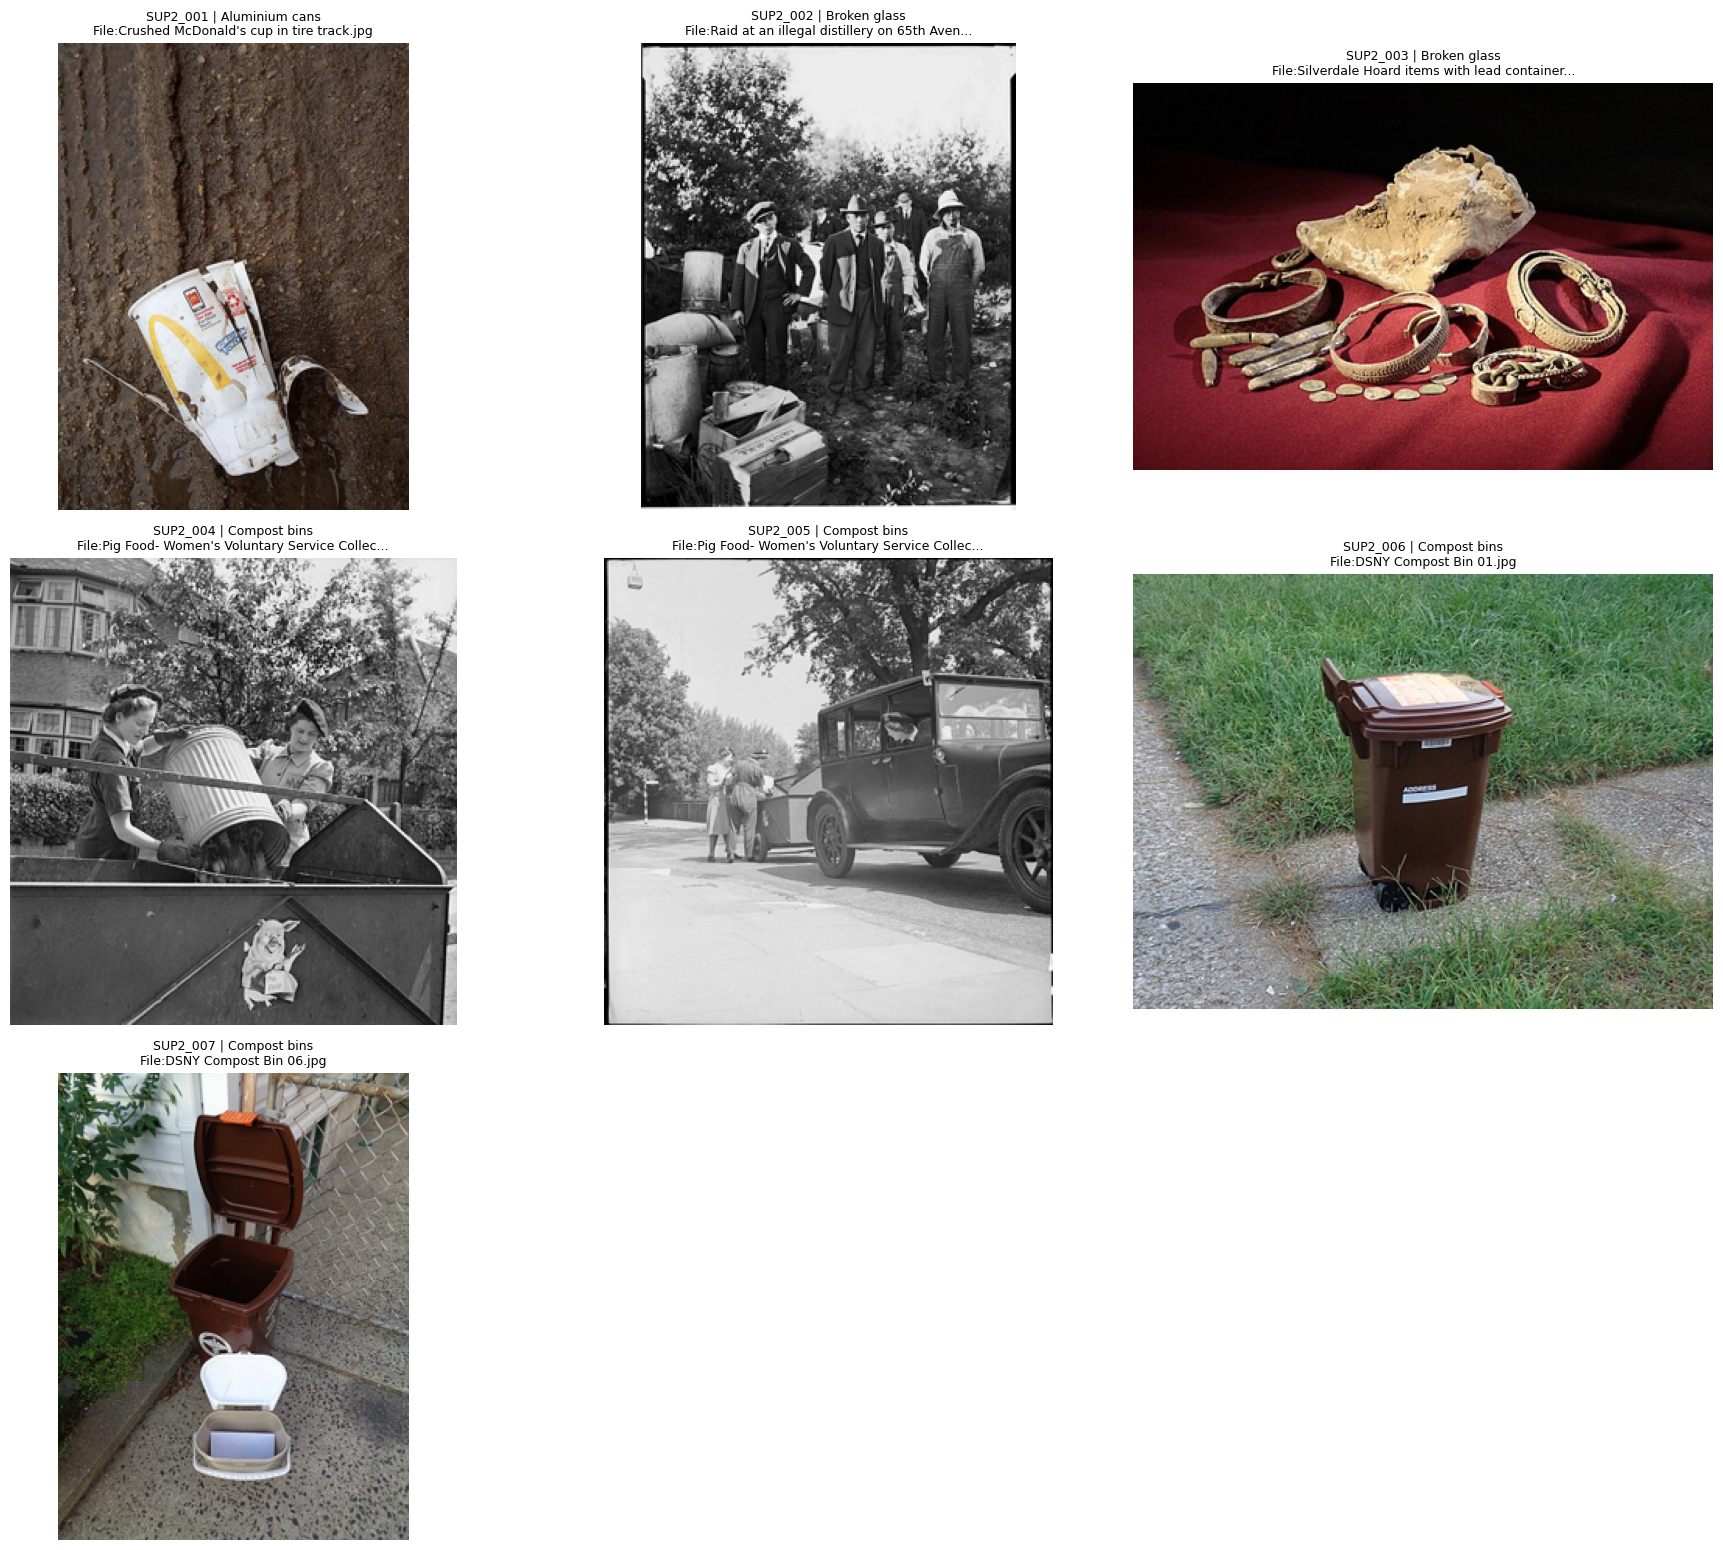


Thumbnails previewed: 7 / 7

Full-resolution images downloaded: 0
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
from io import BytesIO
from html import unescape
import re
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
output_path = root / "commons_supported_gap_candidates_v2.csv"

# Load prior candidate and audit files to avoid repeating old results.
prior_files = [
    root / "commons_photo_candidates_v3.csv",
    root / "commons_photo_candidates_v3_review3.csv",
    root / "commons_gap_candidates_v1.csv",
    root / "commons_gap_candidates_v2.csv",
    root / "commons_gap_candidates_v2_review1.csv",
    root / "commons_candidate_licence_dedup_audit_v1.csv",
    root / "commons_supported_gap_candidates_v1.csv",
    root / "commons_supported_gap_candidates_v1_review1.csv",
    root / "commons_supported_candidate_source_audit_v1.csv",
]

known_titles = set()
known_hashes = set()

for path in prior_files:
    if not path.exists():
        continue

    frame = pd.read_csv(path, dtype=str, keep_default_na=False)

    for col in ["file_title", "title"]:
        if col in frame.columns:
            known_titles.update(
                str(v).strip().casefold()
                for v in frame[col]
                if str(v).strip()
            )

    for col in [
        "commons_sha1", "live_sha1", "sha1",
        "expected_commons_sha1", "actual_sha1"
    ]:
        if col in frame.columns:
            known_hashes.update(
                str(v).strip().casefold()
                for v in frame[col]
                if str(v).strip()
            )

searches = [
    ("Aluminium cans", "recyclable", "crushed beverage can litter"),
    ("Aluminium cans", "recyclable", "empty aluminium can on ground"),
    ("Aluminium cans", "recyclable", "aluminum beverage cans discarded"),
    ("Aluminium cans", "recyclable", "crushed soda can close up"),

    ("Broken glass", "recyclable", "broken bottle glass shards pavement"),
    ("Broken glass", "recyclable", "broken glass bottle pieces on ground"),
    ("Broken glass", "recyclable", "shattered glass bottle waste"),
    ("Broken glass", "recyclable", "broken window glass shards waste"),

    ("Fluorescent lamps", "hazardous", "discarded fluorescent tubes waste"),
    ("Fluorescent lamps", "hazardous", "broken fluorescent tube disposal"),
    ("Fluorescent lamps", "hazardous", "fluorescent lamps at recycling centre"),
    ("Fluorescent lamps", "hazardous", "damaged fluorescent tube lamp"),
    ("Fluorescent lamps", "hazardous", "compact fluorescent lamp disposal"),

    ("Compost bins", "organic", "kitchen compost caddy food scraps"),
    ("Compost bins", "organic", "vegetable peels in compost container"),
    ("Compost bins", "organic", "food scraps in kitchen waste bin"),
    ("Compost bins", "organic", "organic waste bin with visible food"),
    ("Compost bins", "organic", "compost bin with food scraps"),
]

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers.update({
    "User-Agent": (
        "WasteLensEducationalDatasetReview/1.0 "
        "(https://github.com/Anik00223/WasteLens)"
    )
})

def clean_meta(ext, key):
    value = ext.get(key, {})
    if isinstance(value, dict):
        value = value.get("value", "")
    value = re.sub(r"<br\s*/?>", " ", str(value), flags=re.I)
    value = re.sub(r"<[^>]+>", " ", value)
    return re.sub(r"\s+", " ", unescape(value)).strip()

new_rows = []
seen_titles = set()
seen_hashes = set()
counts = {}
errors = []

# Cap each category to keep the review batch manageable.
for category, target_label, query in searches:
    if counts.get(category, 0) >= 8:
        continue

    added = 0
    print("Searching:", query)

    try:
        response = session.get(
            API,
            params={
                "action": "query",
                "format": "json",
                "generator": "search",
                "gsrsearch": f"filetype:bitmap {query}",
                "gsrnamespace": 6,
                "gsrlimit": 50,
                "prop": "info|imageinfo",
                "inprop": "url",
                "iiprop": "url|sha1|size|extmetadata",
                "iiurlwidth": 500,
            },
            timeout=60,
        )
        response.raise_for_status()
        pages = response.json().get("query", {}).get("pages", {})
        pages = sorted(
            pages.values(),
            key=lambda page: page.get("index", 9999)
        )

        for page in pages:
            if added >= 2 or counts.get(category, 0) >= 8:
                break

            title = str(page.get("title", "")).strip()
            if not title or title.casefold() in known_titles | seen_titles:
                continue

            infos = page.get("imageinfo", [])
            if not infos:
                continue

            info = infos[0]
            extension = title.rsplit(".", 1)[-1].lower()

            if extension not in {"jpg", "jpeg", "png", "webp"}:
                continue

            width = int(info.get("width", 0))
            height = int(info.get("height", 0))

            # Filter out tiny thumbnails and low-resolution files.
            if width < 600 or height < 400:
                continue

            sha1 = str(info.get("sha1", "")).strip().casefold()
            if sha1 and (
                sha1 in known_hashes or sha1 in seen_hashes
            ):
                continue

            extmeta = info.get("extmetadata", {})
            canonical_url = str(page.get("canonicalurl", "")).strip()

            row = {
                "candidate_id": f"SUP2_{len(new_rows) + 1:03d}",
                "category": category,
                "target_label": target_label,
                "search_query": query,
                "file_title": title,
                "source_page_url": canonical_url,
                "direct_image_url": info.get("url", ""),
                "thumbnail_url": info.get("thumburl", info.get("url", "")),
                "commons_sha1": sha1,
                "license": clean_meta(extmeta, "LicenseShortName"),
                "license_url": clean_meta(extmeta, "LicenseUrl"),
                "author": clean_meta(extmeta, "Artist"),
                "description": clean_meta(extmeta, "ImageDescription"),
                "width": width,
                "height": height,
                "human_visual_check": "pending",
                "approved_for_dataset": "no",
                "download_authorized": "no",
                "proposed_split": "unassigned",
            }

            new_rows.append(row)
            seen_titles.add(title.casefold())
            if sha1:
                seen_hashes.add(sha1)
            counts[category] = counts.get(category, 0) + 1
            added += 1

    except Exception as exc:
        errors.append((query, str(exc)))

    print("  New candidates:", added)
    time.sleep(0.2)

if not new_rows:
    print("\nNo new candidates found; inspect the search errors below.")
else:
    candidates = pd.DataFrame(new_rows)
    candidates.to_csv(output_path, index=False)

    print("\nSaved candidates:", output_path)
    print("New candidates:", len(candidates))
    print("\nCounts by category:")
    print(candidates.groupby("category").size().to_string())
    print("\nLicence metadata present:",
          int(candidates["license"].fillna("").str.strip().ne("").sum()),
          "/", len(candidates))
    print("\nCreator metadata present:",
          int(candidates["author"].fillna("").str.strip().ne("").sum()),
          "/", len(candidates))

    display(candidates[
        ["candidate_id", "category", "file_title",
         "license", "author", "width", "height"]
    ])

    # Thumbnail-only review, kept in memory.
    previews = []
    preview_errors = []

    for _, row in candidates.iterrows():
        try:
            r = session.get(row["thumbnail_url"], timeout=25)
            r.raise_for_status()
            image = Image.open(BytesIO(r.content))
            image = ImageOps.exif_transpose(image).convert("RGB")
            image.thumbnail((420, 300))

            previews.append((
                row["candidate_id"],
                row["category"],
                row["file_title"],
                image,
            ))
        except Exception as exc:
            preview_errors.append((row["candidate_id"], str(exc)))

    if previews:
        cols = 3
        nrows = (len(previews) + cols - 1) // cols
        fig, axes = plt.subplots(
            nrows, cols,
            figsize=(18, 5.2 * nrows)
        )
        axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

        for ax in axes:
            ax.axis("off")

        for ax, (cid, category, title, image) in zip(axes, previews):
            ax.imshow(image)
            short_title = title if len(title) < 50 else title[:47] + "..."
            ax.set_title(f"{cid} | {category}\n{short_title}", fontsize=9)

        plt.tight_layout()
        plt.show()

    print("\nThumbnails previewed:", len(previews), "/", len(candidates))
    if preview_errors:
        print("Preview errors:")
        for cid, error in preview_errors:
            print(cid, error)

if errors:
    print("\nSearch errors:")
    for query, error in errors:
        print(query, ":", error)

print("\nFull-resolution images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
from io import BytesIO
import math
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# 1. Check the Drive mount and reconnect if needed.
drive_root = Path("/content/drive/MyDrive")

if not drive_root.exists():
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)

drive_root = Path("/content/drive/MyDrive")
if not drive_root.exists():
    raise RuntimeError(
        "Google Drive is still unavailable. Check the Colab Drive mount "
        "before continuing."
    )

# 2. Recreate the output directory.
root = drive_root / "WasteLens/convnext_xl/rejection_experiment"
root.mkdir(parents=True, exist_ok=True)
output_path = root / "commons_supported_gap_candidates_v2.csv"

# 3. Reuse search results already in memory; don't repeat the API searches.
if "new_rows" not in globals() or not new_rows:
    raise RuntimeError(
        "The previous search results are not in memory. "
        "After confirming Drive is mounted, rerun the supported-candidate "
        "search cell with root.mkdir(parents=True, exist_ok=True) before to_csv."
    )

candidates = pd.DataFrame(new_rows)

if candidates["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in the search results.")

# Save the candidate metadata first.
candidates.to_csv(output_path, index=False)

print("Saved candidate metadata:", output_path)
print("Candidate records saved:", len(candidates))
print("\nCounts by category:")
print(candidates.groupby("category").size().to_string())
display(candidates[
    ["candidate_id", "category", "file_title",
     "license", "author", "width", "height"]
])

# 4. Re-display thumbnails in memory only.
session = requests.Session()
session.headers.update({
    "User-Agent": "WasteLensEducationalDatasetReview/1.0"
})

preview_items = []
preview_errors = []

for _, row in candidates.iterrows():
    try:
        url = str(row["thumbnail_url"])
        if not url.startswith("https://"):
            raise ValueError("Invalid thumbnail URL")

        response = session.get(url, timeout=25)
        response.raise_for_status()

        image = Image.open(BytesIO(response.content))
        image = ImageOps.exif_transpose(image).convert("RGB")
        image.thumbnail((420, 300))

        preview_items.append({
            "candidate_id": row["candidate_id"],
            "category": row["category"],
            "title": row["file_title"],
            "image": image,
        })
    except Exception as exc:
        preview_errors.append((row["candidate_id"], str(exc)))

if preview_items:
    cols = 3
    rows = math.ceil(len(preview_items) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(18, 5 * rows))
    axes = list(axes.flat) if hasattr(axes, "flat") else [axes]

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, preview_items):
        ax.imshow(item["image"])
        title = str(item["title"])
        if len(title) > 55:
            title = title[:52] + "..."
        ax.set_title(
            f'{item["candidate_id"]} | {item["category"]}\n{title}',
            fontsize=9
        )

    plt.tight_layout()
    plt.show()

print("\nPreviewed:", len(preview_items), "/", len(candidates))

if preview_errors:
    print("Preview errors:")
    for candidate_id, error in preview_errors:
        print(candidate_id, error)

print("\nFull-resolution images downloaded: 0")
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "commons_supported_gap_candidates_v2.csv"
output_path = root / "commons_supported_gap_candidates_v2_review1.csv"

if not source_path.exists():
    raise FileNotFoundError(f"Candidate file missing: {source_path}")

candidates = pd.read_csv(source_path, dtype=str, keep_default_na=False)

decisions = {
    "SUP2_001": (
        "reject_metadata_mismatch",
        "Filename identifies a McDonald's cup, not an aluminium can."
    ),
    "SUP2_002": (
        "hold_visual_material_check",
        "Distillery raid scene; verify whether broken glass is clearly visible."
    ),
    "SUP2_003": (
        "reject_context_mismatch",
        "Archaeological hoard; unsuitable for ordinary broken-glass waste without a compelling visual reason."
    ),
    "SUP2_004": (
        "reject_metadata_mismatch",
        "UV degradation test chamber, not a fluorescent-lamp waste example."
    ),
    "SUP2_005": (
        "hold_taxonomy_alignment",
        "Pig-food historical context; check visible contents and intended category."
    ),
    "SUP2_006": (
        "hold_taxonomy_alignment",
        "Pig-food historical context; verify image relationship to SUP2_005 and label suitability."
    ),
    "SUP2_007": (
        "candidate_taxonomy_review",
        "Food scraps/compost subject; confirm actual visible material and suitability for the pilot subtype."
    ),
    "SUP2_008": (
        "hold_visual_contents_check",
        "Compost bin; inspect whether organic material is clearly visible."
    ),
}

candidates["triage_status"] = "pending_manual_review"
candidates["triage_notes"] = (
    "No decision assigned; candidate ID was not in the expected review list."
)

for candidate_id, (status, note) in decisions.items():
    mask = candidates["candidate_id"].astype(str).eq(candidate_id)

    if int(mask.sum()) == 1:
        candidates.loc[mask, "triage_status"] = status
        candidates.loc[mask, "triage_notes"] = note
    elif int(mask.sum()) > 1:
        raise ValueError(f"Duplicate candidate ID: {candidate_id}")
    else:
        print(f"Candidate not found: {candidate_id}")

candidates["approved_for_dataset"] = "no"
candidates["download_authorized"] = "no"

candidates.to_csv(output_path, index=False)

print("Saved triage report:", output_path)
print("\nTriage counts:")
print(candidates["triage_status"].value_counts().to_string())

display(candidates[
    ["candidate_id", "category", "file_title",
     "triage_status", "triage_notes"]
])

print("\nCandidate records:", len(candidates))
print("Approved:", (candidates["approved_for_dataset"] == "yes").sum())
print("Downloads authorized:", (candidates["download_authorized"] == "yes").sum())
print("Pilot manifest modified: no")
print("Model weights changed: no")
print("Locked test set touched: no")


Candidate not found: SUP2_008
Saved triage report: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_supported_gap_candidates_v2_review1.csv

Triage counts:
triage_status
reject_metadata_mismatch      2
hold_taxonomy_alignment       2
hold_visual_material_check    1
reject_context_mismatch       1
candidate_taxonomy_review     1


,candidate_id,category,file_title,triage_status,triage_notes
0,SUP2_001,Aluminium cans,File:Crushed McDonald's cup in tire track.jpg,reject_metadata_mismatch,"Filename identifies a McDonald's cup, not an a..."
1,SUP2_002,Broken glass,File:Raid at an illegal distillery on 65th Ave...,hold_visual_material_check,Distillery raid scene; verify whether broken g...
2,SUP2_003,Broken glass,File:Silverdale Hoard items with lead containe...,reject_context_mismatch,Archaeological hoard; unsuitable for ordinary ...
3,SUP2_004,Compost bins,File:Pig Food- Women's Voluntary Service Colle...,reject_metadata_mismatch,"UV degradation test chamber, not a fluorescent..."
4,SUP2_005,Compost bins,File:Pig Food- Women's Voluntary Service Colle...,hold_taxonomy_alignment,Pig-food historical context; check visible con...
5,SUP2_006,Compost bins,File:DSNY Compost Bin 01.jpg,hold_taxonomy_alignment,Pig-food historical context; verify image rela...
6,SUP2_007,Compost bins,File:DSNY Compost Bin 06.jpg,candidate_taxonomy_review,Food scraps/compost subject; confirm actual vi...



Candidate records: 7
Approved: 0
Downloads authorized: 0
Pilot manifest modified: no
Model weights changed: no
Locked test set touched: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

candidate_path = root / "commons_supported_gap_candidates_v2.csv"
review_path = root / "commons_supported_gap_candidates_v2_review1.csv"

if not candidate_path.exists():
    raise FileNotFoundError(f"Saved candidate file missing: {candidate_path}")

candidates = pd.read_csv(candidate_path, dtype=str, keep_default_na=False)

print("AUTHORITATIVE SAVED CANDIDATE FILE")
print("Path:", candidate_path)
print("Number of rows:", len(candidates))
print("Columns:", candidates.columns.tolist())

required = ["candidate_id", "category", "file_title"]
missing = [c for c in required if c not in candidates.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

print("\nActual candidate ID-to-filename mapping:")
display(
    candidates[
        [
            c for c in [
                "candidate_id", "category", "search_query",
                "file_title", "license", "author", "commons_sha1"
            ] if c in candidates.columns
        ]
    ]
)

print("\nCandidate ID duplicates:")
print(candidates.loc[
    candidates["candidate_id"].duplicated(keep=False),
    ["candidate_id", "file_title"]
].to_string(index=False) or "None")

print("\nFilename duplicates:")
duplicates = candidates[
    candidates["file_title"].str.casefold().duplicated(keep=False)
]
print(
    duplicates[["candidate_id", "file_title"]].to_string(index=False)
    if not duplicates.empty else "None"
)

if review_path.exists():
    review = pd.read_csv(review_path, dtype=str, keep_default_na=False)

    candidate_ids = set(candidates["candidate_id"])
    review_ids = set(review["candidate_id"])

    print("\nReview-file reconciliation:")
    print("Review rows:", len(review))
    print("Candidate IDs missing from review:", sorted(candidate_ids - review_ids))
    print("Unexpected IDs in review:", sorted(review_ids - candidate_ids))

    joined = candidates[
        ["candidate_id", "category", "file_title"]
    ].merge(
        review[[
            c for c in [
                "candidate_id", "category", "file_title", "triage_status"
            ] if c in review.columns
        ]],
        on="candidate_id",
        how="outer",
        suffixes=("_candidate", "_review"),
        indicator=True
    )

    if "file_title_candidate" in joined.columns:
        joined["filename_matches"] = (
            joined["file_title_candidate"] == joined["file_title_review"]
        )

        print("\nRows where the filename changed under the same ID:")
        display(joined.loc[
            joined["_merge"].eq("both") & ~joined["filename_matches"],
            [
                "candidate_id", "file_title_candidate",
                "file_title_review", "triage_status"
            ]
        ])
else:
    print("\nNo review file exists yet.")

print("\nNo files modified.")
print("Pilot manifest modified: no")
print("Model weights changed: no")


AUTHORITATIVE SAVED CANDIDATE FILE
Path: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_supported_gap_candidates_v2.csv
Number of rows: 7
Columns: ['candidate_id', 'category', 'target_label', 'search_query', 'file_title', 'source_page_url', 'direct_image_url', 'thumbnail_url', 'commons_sha1', 'license', 'license_url', 'author', 'description', 'width', 'height', 'human_visual_check', 'approved_for_dataset', 'download_authorized', 'proposed_split']

Actual candidate ID-to-filename mapping:


,candidate_id,category,search_query,file_title,license,author,commons_sha1
0,SUP2_001,Aluminium cans,crushed beverage can litter,File:Crushed McDonald's cup in tire track.jpg,CC0,Visviva,a07ca2e61fe8b5256e03f8851eae5b29e62c3044
1,SUP2_002,Broken glass,broken glass bottle pieces on ground,File:Raid at an illegal distillery on 65th Ave...,Public domain,Webster & Stevens,c6dfc2e6b0857ad3360b1f5a3c987c7d1973f4f4
2,SUP2_003,Broken glass,broken glass bottle pieces on ground,File:Silverdale Hoard items with lead containe...,CC BY-SA 2.0,"The British Museum, Ian Richardson, 2012-06-15...",afa0e64c8cf30506607047a6ee61f05554b66f95
3,SUP2_004,Compost bins,food scraps in kitchen waste bin,File:Pig Food- Women's Voluntary Service Colle...,Public domain,"Joysmith Eric?, Ministry of Information Photo ...",d80320c6f6da31a31b74c438722a964c2550dcec
4,SUP2_005,Compost bins,food scraps in kitchen waste bin,File:Pig Food- Women's Voluntary Service Colle...,Public domain,"Joysmith Eric?, Ministry of Information Photo ...",0b182fe68450034c82d714ed036d881cb77dbe12
5,SUP2_006,Compost bins,compost bin with food scraps,File:DSNY Compost Bin 01.jpg,CC BY-SA 4.0,Tdorante10,e66e8b29661cf6172263ffa988c8f62024633957
6,SUP2_007,Compost bins,compost bin with food scraps,File:DSNY Compost Bin 06.jpg,CC BY-SA 4.0,Tdorante10,bd0c56393c05ac4353142f4c65efb220a8cb5a85



Candidate ID duplicates:
Empty DataFrame
Columns: [candidate_id, file_title]
Index: []

Filename duplicates:
None

Review-file reconciliation:
Review rows: 7
Candidate IDs missing from review: []
Unexpected IDs in review: []

Rows where the filename changed under the same ID:


,candidate_id,file_title_candidate,file_title_review,triage_status



No files modified.
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)

source_path = root / "commons_supported_gap_candidates_v2.csv"
output_path = root / "commons_supported_gap_candidates_v2_review2.csv"

candidates = pd.read_csv(source_path, dtype=str, keep_default_na=False)

decisions = {
    "SUP2_001": (
        "reject_metadata_mismatch",
        "Filename identifies a crushed McDonald's cup, not an aluminium can."
    ),
    "SUP2_002": (
        "hold_visual_material_check",
        "Verify that broken glass is clearly visible in the distillery-raid scene."
    ),
    "SUP2_003": (
        "reject_context_mismatch",
        "Archaeological hoard; not a suitable example of ordinary broken-glass waste for this batch."
    ),
    "SUP2_004": (
        "hold_taxonomy_alignment",
        "Pig-food historical context does not clearly match the compost-bin subtype."
    ),
    "SUP2_005": (
        "hold_taxonomy_alignment",
        "Pig-food historical context; inspect the actual image before deciding its suitability."
    ),
    "SUP2_006": (
        "hold_visual_contents_check",
        "Compost bin; confirm that the intended organic material is clearly visible."
    ),
    "SUP2_007": (
        "hold_visual_contents_check",
        "Compost bin; confirm that organic contents are visible and the image is not redundant with SUP2_006."
    ),
}

if candidates["candidate_id"].duplicated().any():
    raise ValueError("Duplicate candidate IDs in the authoritative CSV.")

if set(candidates["candidate_id"]) != set(decisions):
    raise ValueError(
        "Candidate ID set differs from the reviewed seven IDs. "
        "Inspect the source CSV before making further decisions."
    )

candidates["review_status_v2"] = candidates["candidate_id"].map(
    lambda cid: decisions[cid][0]
)
candidates["review_notes_v2"] = candidates["candidate_id"].map(
    lambda cid: decisions[cid][1]
)

candidates["approved_for_dataset"] = "no"
candidates["download_authorized"] = "no"

candidates.to_csv(output_path, index=False)

# Confirm every decision remains attached to its authoritative filename.
check = candidates[["candidate_id", "file_title", "review_status_v2"]]
assert len(check) == 7
assert check["candidate_id"].is_unique
assert check["review_status_v2"].notna().all()

print("Saved corrected review:", output_path)
print("\nCorrected candidate mapping:")
display(check)

print("\nDecision counts:")
print(candidates["review_status_v2"].value_counts().to_string())

print("\nMissing decisions:", candidates["review_status_v2"].isna().sum())
print("Approved:", (candidates["approved_for_dataset"] == "yes").sum())
print("Downloads authorized:", (candidates["download_authorized"] == "yes").sum())
print("Original candidate CSV modified: no")
print("Pilot manifest modified: no")
print("Model weights changed: no")


Saved corrected review: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_supported_gap_candidates_v2_review2.csv

Corrected candidate mapping:


,candidate_id,file_title,review_status_v2
0,SUP2_001,File:Crushed McDonald's cup in tire track.jpg,reject_metadata_mismatch
1,SUP2_002,File:Raid at an illegal distillery on 65th Ave...,hold_visual_material_check
2,SUP2_003,File:Silverdale Hoard items with lead containe...,reject_context_mismatch
3,SUP2_004,File:Pig Food- Women's Voluntary Service Colle...,hold_taxonomy_alignment
4,SUP2_005,File:Pig Food- Women's Voluntary Service Colle...,hold_taxonomy_alignment
5,SUP2_006,File:DSNY Compost Bin 01.jpg,hold_visual_contents_check
6,SUP2_007,File:DSNY Compost Bin 06.jpg,hold_visual_contents_check



Decision counts:
review_status_v2
hold_visual_contents_check    2
hold_taxonomy_alignment       2
reject_metadata_mismatch      1
reject_context_mismatch       1
hold_visual_material_check    1

Missing decisions: 0
Approved: 0
Downloads authorized: 0
Original candidate CSV modified: no
Pilot manifest modified: no
Model weights changed: no


In [ ]:

from pathlib import Path
import pandas as pd

root = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "rejection_experiment"
)
output_path = root / "pilot_taxonomy_alignment_decision_v1.csv"

decision = pd.DataFrame([{
    "pilot_subtype": "Compost bins",
    "existing_target_label": "organic",
    "proposed_visual_target": (
        "Food scraps, vegetable peels, or compostable organic material "
        "clearly visible; a bin may be present but must not be the sole cue."
    ),
    "empty_bin_acceptable": "no",
    "bin_label_only_acceptable": "no",
    "organic_contents_must_be_visible": "yes",
    "model_class_changed": "no",
    "locked_test_set_touched": "no",
    "decision_status": "proposed_for_review",
    "notes": (
        "This records a proposed visual-label rule; it does not change "
        "the pilot manifest or approve any candidate images."
    )
}])

decision.to_csv(output_path, index=False)

print("Saved taxonomy decision:", output_path)
display(decision)

print("\nExisting pilot manifest modified: no")
print("Existing candidate decisions modified: no")
print("Images downloaded: 0")
print("Model weights changed: no")


Saved taxonomy decision: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_taxonomy_alignment_decision_v1.csv


,pilot_subtype,existing_target_label,proposed_visual_target,empty_bin_acceptable,bin_label_only_acceptable,organic_contents_must_be_visible,model_class_changed,locked_test_set_touched,decision_status,notes
0,Compost bins,organic,"Food scraps, vegetable peels, or compostable o...",no,no,yes,no,no,proposed_for_review,This records a proposed visual-label rule; it ...



Existing pilot manifest modified: no
Existing candidate decisions modified: no
Images downloaded: 0
Model weights changed: no


## 15. Testing the Model

Cell 111 runs the final test evaluation on the held-out test set.
Cell 112 checks the repository and installed packages.


In [ ]:
# ============================================================
# WASTELENS CONVNEXT-XL — FINAL TEST EVALUATION
# Loads best validation checkpoint; performs no training.
# ============================================================

import csv
import json
import subprocess
import sys
from pathlib import Path

import torch
import torch.nn.functional as F
import timm

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# ------------------------------------------------------------
# 1. Verify environment and files
# ------------------------------------------------------------

assert torch.cuda.is_available(), (
    "GPU unavailable. Reconnect a T4 runtime first."
)

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
BEST_WEIGHTS = BASE / "checkpoints/convnext_xl_best.pt"
MANIFEST_PATH = BASE / "manifests/supported_split_seed42.csv"
SUMMARY_PATH = BASE / "manifests/supported_split_seed42_summary.json"
LOG_DIR = BASE / "logs"

LOG_DIR.mkdir(parents=True, exist_ok=True)

for path in (BEST_WEIGHTS, MANIFEST_PATH, SUMMARY_PATH):
    assert path.is_file() and path.stat().st_size > 0, (
        f"Missing or empty file: {path}"
    )

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. Retrieve original dataset
# ------------------------------------------------------------

try:
    import kagglehub
except ImportError:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
        check=True,
    )
    import kagglehub

dataset_root = Path(
    kagglehub.dataset_download("mostafaabla/garbage-classification")
).resolve()

print("Dataset root:", dataset_root)

# ------------------------------------------------------------
# 3. Load manifest BEFORE validating split counts
# ------------------------------------------------------------

with SUMMARY_PATH.open(encoding="utf-8") as f:
    summary = json.load(f)

CLASS_NAMES = summary["class_order"]

assert CLASS_NAMES == [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
], f"Unexpected class order: {CLASS_NAMES}"

with MANIFEST_PATH.open(
    newline="",
    encoding="utf-8",
) as f:
    rows = list(csv.DictReader(f))

expected_counts = {
    "train": 5749,
    "val": 1231,
    "test": 1233,
}

for split, expected in expected_counts.items():
    actual = sum(row["split"] == split for row in rows)

    assert actual == expected, (
        f"{split}: found {actual}, expected {expected}"
    )

# Confirm there are no duplicate image paths across splits.
split_paths = {
    split: {
        row["relative_path"]
        for row in rows
        if row["split"] == split
    }
    for split in expected_counts
}

assert not (split_paths["train"] & split_paths["val"])
assert not (split_paths["train"] & split_paths["test"])
assert not (split_paths["val"] & split_paths["test"])

test_rows = [row for row in rows if row["split"] == "test"]

assert len(test_rows) == 1233

# Verify test files actually exist.
missing = [
    row["relative_path"]
    for row in test_rows
    if not (dataset_root / row["relative_path"]).is_file()
]

if missing:
    raise FileNotFoundError(
        f"{len(missing)} test files are missing. "
        f"Examples: {missing[:5]}"
    )

print("Manifest verified.")
print("Class order:", CLASS_NAMES)
print("Independent test images:", len(test_rows))
print("Train/validation/test overlap: none")

# ------------------------------------------------------------
# 4. Recreate the evaluation preprocessing
# Same evaluation settings used in the training notebook.
# ------------------------------------------------------------

image_size = 384

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

eval_transform = transforms.Compose([
    transforms.Resize(
        (image_size, image_size),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])


class WasteTestDataset(Dataset):
    def __init__(self, records, root, transform):
        self.records = records
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        row = self.records[index]
        path = self.root / row["relative_path"]

        with Image.open(path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return image, int(row["label_idx"]), row["relative_path"]


test_dataset = WasteTestDataset(
    test_rows,
    dataset_root,
    eval_transform,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Test batches:", len(test_loader))

# ------------------------------------------------------------
# 5. Load best validation checkpoint
# ------------------------------------------------------------

MODEL_NAME = "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384"

model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    BEST_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)

model.load_state_dict(state, strict=True)
del state

model = model.to(device)
model.eval()

print(
    "Parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}",
)
print("Best checkpoint loaded.")
print("Training mode:", model.training)

# ------------------------------------------------------------
# 6. Evaluate untouched test set — no gradients or updates
# ------------------------------------------------------------

targets = []
predictions = []
confidences = []
prediction_paths = []

total_loss = 0.0
total_images = 0

with torch.inference_mode():
    for batch_idx, (images, labels, paths) in enumerate(
        test_loader,
        start=1,
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            logits = model(images)
            loss = F.cross_entropy(
                logits,
                labels,
                reduction="sum",
            )

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)

        total_loss += loss.item()
        total_images += labels.size(0)

        targets.extend(labels.cpu().tolist())
        predictions.extend(predicted.cpu().tolist())
        confidences.extend(confidence.cpu().tolist())
        prediction_paths.extend(paths)

        if batch_idx % 25 == 0 or batch_idx == len(test_loader):
            print(
                f"Evaluated {total_images}/{len(test_dataset)} images"
            )

assert total_images == 1233

accuracy = accuracy_score(targets, predictions)

macro_f1 = f1_score(
    targets,
    predictions,
    average="macro",
    zero_division=0,
)

weighted_f1 = f1_score(
    targets,
    predictions,
    average="weighted",
    zero_division=0,
)

report = classification_report(
    targets,
    predictions,
    labels=list(range(4)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

cm = confusion_matrix(
    targets,
    predictions,
    labels=list(range(4)),
)

# ------------------------------------------------------------
# 7. Save evaluation results to Google Drive
# ------------------------------------------------------------

results = {
    "model": "ConvNeXt-XL",
    "parameters": sum(p.numel() for p in model.parameters()),
    "input_size": "384x384",
    "checkpoint": str(BEST_WEIGHTS),
    "checkpoint_selection": "best validation macro-F1",
    "test_images": total_images,
    "test_loss": total_loss / total_images,
    "test_accuracy": float(accuracy),
    "test_macro_f1": float(macro_f1),
    "test_weighted_f1": float(weighted_f1),
    "class_names": CLASS_NAMES,
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
}

metrics_path = LOG_DIR / "test_metrics.json"

metrics_path.write_text(
    json.dumps(results, indent=2),
    encoding="utf-8",
)

cm_path = LOG_DIR / "confusion_matrix.csv"

with cm_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Actual / Predicted"] + CLASS_NAMES)

    for name, matrix_row in zip(CLASS_NAMES, cm):
        writer.writerow([name] + matrix_row.tolist())

pred_path = LOG_DIR / "test_predictions.csv"

with pred_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow([
        "relative_path",
        "actual_label",
        "predicted_label",
        "confidence",
    ])

    for path, actual, pred, conf in zip(
        prediction_paths,
        targets,
        predictions,
        confidences,
    ):
        writer.writerow([
            path,
            CLASS_NAMES[actual],
            CLASS_NAMES[pred],
            f"{conf:.6f}",
        ])

# ------------------------------------------------------------
# 8. Print report
# ------------------------------------------------------------

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test images:      {total_images}")
print(f"Test loss:        {total_loss / total_images:.5f}")
print(f"Test accuracy:    {accuracy:.4%}")
print(f"Test macro-F1:    {macro_f1:.4f}")
print(f"Test weighted-F1: {weighted_f1:.4f}")

print("\n========== PER-CLASS REPORT ==========")

print(classification_report(
    targets,
    predictions,
    labels=list(range(4)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

print("========== CONFUSION MATRIX ==========")
print("Rows = actual; columns = predicted")
print(cm)

print("\nSaved evaluation files:")
print(metrics_path)
print(cm_path)
print(pred_path)

print("\n✅ Independent test evaluation completed.")

GPU: Tesla T4
Using Colab cache for faster access to the 'garbage-classification' dataset.
Dataset root: /kaggle/input/garbage-classification
Manifest verified.
Class order: ['recyclable', 'organic', 'hazardous', 'general trash']
Independent test images: 1233
Train/validation/test overlap: none
Test batches: 155


config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

Parameters: 348,156,164
Best checkpoint loaded.
Training mode: False
Evaluated 200/1233 images
Evaluated 400/1233 images
Evaluated 600/1233 images
Evaluated 800/1233 images
Evaluated 1000/1233 images
Evaluated 1200/1233 images
Evaluated 1233/1233 images

========== FINAL TEST RESULTS ==========
Test images:      1233
Test loss:        0.01082
Test accuracy:    99.6756%
Test macro-F1:    0.9945
Test weighted-F1: 0.9968

========== PER-CLASS REPORT ==========
               precision    recall  f1-score   support

   recyclable       1.00      1.00      1.00       839
      organic       0.99      1.00      1.00       148
    hazardous       0.99      0.99      0.99       142
general trash       1.00      0.98      0.99       104

     accuracy                           1.00      1233
    macro avg       1.00      0.99      0.99      1233
 weighted avg       1.00      1.00      1.00      1233

========== CONFUSION MATRIX ==========
Rows = actual; columns = predicted
[[838   1   0   0]
 [

In [ ]:
from pathlib import Path
import json
import re

REPO = Path("/content/WasteLens-ConvNeXt")

print("========== PROJECT STRUCTURE ==========")

for folder in ["src", "web", "models", "tests"]:
    path = REPO / folder
    if path.exists():
        print(f"\n{folder}/")
        for item in sorted(path.iterdir()):
            print("  ", item.name + ("/" if item.is_dir() else ""))

print("\n========== PACKAGE CONFIGURATION ==========")

package_path = REPO / "package.json"

if package_path.exists():
    package = json.loads(package_path.read_text(encoding="utf-8"))
    print(json.dumps({
        "scripts": package.get("scripts", {}),
        "dependencies": package.get("dependencies", {}),
    }, indent=2))

print("\n========== CURRENT INFERENCE REFERENCES ==========")

patterns = re.compile(
    r"tf\.loadLayersModel|loadGraphModel|model\.predict|"
    r"model\.json|mobilenet|predict\(|/api/|express\(|"
    r"create_app|FastAPI|Flask",
    re.IGNORECASE,
)

extensions = {".js", ".jsx", ".ts", ".tsx", ".py", ".html"}

for folder_name in ["src", "web"]:
    folder = REPO / folder_name
    if not folder.exists():
        continue

    for path in sorted(folder.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue
        if "node_modules" in path.parts:
            continue

        try:
            lines = path.read_text(
                encoding="utf-8", errors="replace"
            ).splitlines()
        except OSError:
            continue

        matches = [
            (i, line.strip())
            for i, line in enumerate(lines, 1)
            if patterns.search(line)
        ]

        if matches:
            print(f"\n--- {path.relative_to(REPO)} ---")
            for line_no, line in matches[:12]:
                print(f"{line_no}: {line[:220]}")

========== PROJECT STRUCTURE ==========

src/
   backup_iter12.py
   browser_preprocess_probe.js
   build_adaptation_set.py
   build_fresh_set.py
   build_iter12_notebook.py
   eval_adaptation.py
   eval_fresh_realworld.py
   eval_head_adaptation.py
   eval_rejection.py
   evaluate.py
   export_tfjs.py
   find_uncertain_fixture.py
   fixed_budget_gate.py
   iter12_preflight.py
   iteration10_baseline_error_tax.py
   iteration8_report.py
   make_parity_inputs.py
   make_scratch_ui.py
   materialize_manifest.py
   ood_research.py
   package_head12_evidence.py
   preprocess_compare.py
   product_test_outputs.py
   restore_teacher_ckpt.py
   select_varc_checkpoint.py
   test_decision_logic.js
   train.py
   train_adaptation.py
   train_distill_adaptation.py
   train_head_adaptation.py
   train_rejection.py
   train_rejection_frozen.py
   train_rejection_variantc.py
   ui_clickthrough.js
   validate_realworld.py
   validate_reject_in_browser.js

web/
   index.html
   model/

models/
   chec

## 16. Building a Web Demo

Create a simple website and API so you can try the model in a browser.


In [ ]:
from pathlib import Path
import subprocess
import sys

REPO = Path("/content/WasteLens-ConvNeXt")
assert REPO.exists(), "Restore the GitHub repository first."

api_code = r'''
import io
import os
from contextlib import asynccontextmanager
from pathlib import Path

import torch
import timm

from PIL import Image, UnidentifiedImageError
from fastapi import FastAPI, File, HTTPException, UploadFile
from torchvision import transforms
from torchvision.transforms import InterpolationMode


CLASS_NAMES = [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]

MODEL_NAME = "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384"

DEFAULT_WEIGHTS = (
    "/content/drive/MyDrive/WasteLens/"
    "convnext_xl/checkpoints/convnext_xl_best.pt"
)

WEIGHTS_PATH = Path(
    os.environ.get("WASTELENS_CONVNEXT_WEIGHTS", DEFAULT_WEIGHTS)
)

MAX_UPLOAD_BYTES = 12 * 1024 * 1024
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def make_transform():
    return transforms.Compose([
        transforms.Resize(
            (384, 384),
            interpolation=InterpolationMode.BICUBIC,
        ),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
        ),
    ])


@asynccontextmanager
async def lifespan(app: FastAPI):
    if not WEIGHTS_PATH.is_file():
        raise RuntimeError(
            f"ConvNeXt checkpoint not found: {WEIGHTS_PATH}. "
            "Set WASTELENS_CONVNEXT_WEIGHTS to its location."
        )

    model = timm.create_model(
        MODEL_NAME,
        pretrained=False,
        num_classes=4,
    )

    state = torch.load(
        WEIGHTS_PATH,
        map_location="cpu",
        weights_only=True,
    )
    model.load_state_dict(state, strict=True)
    del state

    model.to(DEVICE)
    model.eval()

    app.state.model = model
    app.state.transform = make_transform()

    print(f"ConvNeXt-XL loaded on {DEVICE}")
    print(f"Checkpoint: {WEIGHTS_PATH}")

    yield

    app.state.model = None


app = FastAPI(
    title="WasteLens ConvNeXt-XL API",
    version="1.0.0",
    description=(
        "Four-class image classification. "
        "Unsupported-input rejection is not implemented in this model."
    ),
    lifespan=lifespan,
)


@app.get("/health")
def health():
    return {
        "status": "ok",
        "model": "ConvNeXt-XL",
        "device": str(DEVICE),
        "classes": CLASS_NAMES,
        "unsupported_input_rejection": False,
    }


@app.post("/api/predict")
async def predict(file: UploadFile = File(...)):
    data = await file.read(MAX_UPLOAD_BYTES + 1)

    if not data:
        raise HTTPException(status_code=400, detail="Uploaded file is empty.")

    if len(data) > MAX_UPLOAD_BYTES:
        raise HTTPException(
            status_code=413,
            detail="Image exceeds the 12 MiB upload limit.",
        )

    try:
        with Image.open(io.BytesIO(data)) as image:
            image = image.convert("RGB")
            tensor = app.state.transform(image).unsqueeze(0)
    except (UnidentifiedImageError, OSError, ValueError):
        raise HTTPException(
            status_code=400,
            detail="File is not a valid supported image.",
        )

    tensor = tensor.to(DEVICE)

    with torch.inference_mode():
        if DEVICE.type == "cuda":
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):
                logits = app.state.model(tensor)
        else:
            logits = app.state.model(tensor)

        probabilities = torch.softmax(logits.float(), dim=1)[0].cpu()

    scores = {
        label: round(float(probabilities[i]), 6)
        for i, label in enumerate(CLASS_NAMES)
    }

    top_idx = int(probabilities.argmax())

    return {
        "predicted_class": CLASS_NAMES[top_idx],
        "confidence": round(float(probabilities[top_idx]), 6),
        "probabilities": scores,
        "model": "ConvNeXt-XL",
        "input_size": "384x384",
        "unsupported_input_rejection": {
            "available": False,
            "message": (
                "This classifier always selects one of four classes. "
                "It does not currently reject unfamiliar inputs."
            ),
        },
    }
'''

api_path = REPO / "src" / "convnext_api.py"
api_path.write_text(api_code, encoding="utf-8")

# Install the API runtime dependencies without upgrading PyTorch.
subprocess.run(
    [
        sys.executable, "-m", "pip", "install", "-q",
        "fastapi", "uvicorn", "python-multipart",
    ],
    check=True,
)

# Check syntax before starting the server.
subprocess.run(
    [sys.executable, "-m", "py_compile", str(api_path)],
    check=True,
)

print("✅ API file created:", api_path)
print("✅ Python syntax check passed.")
print("Production web/index.html was not modified.")

✅ API file created: /content/WasteLens-ConvNeXt/src/convnext_api.py
✅ Python syntax check passed.
Production web/index.html was not modified.


In [ ]:
import os
import subprocess
import sys
import time
import requests

REPO = "/content/WasteLens-ConvNeXt"
WEIGHTS = (
    "/content/drive/MyDrive/WasteLens/"
    "convnext_xl/checkpoints/convnext_xl_best.pt"
)

assert os.path.isfile(WEIGHTS), "Best model checkpoint is missing."

# Avoid starting duplicate test servers.
if "convnext_api_process" in globals():
    if convnext_api_process.poll() is None:
        convnext_api_process.terminate()
        convnext_api_process.wait(timeout=10)

env = os.environ.copy()
env["WASTELENS_CONVNEXT_WEIGHTS"] = WEIGHTS

convnext_api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "src.convnext_api:app",
        "--host", "127.0.0.1",
        "--port", "8000",
    ],
    cwd=REPO,
    env=env,
    stdout=subprocess.DEVNULL,
    stderr=subprocess.STDOUT,
)

for attempt in range(60):
    if convnext_api_process.poll() is not None:
        raise RuntimeError(
            f"API exited with code {convnext_api_process.returncode}. "
            "Check the server startup logs."
        )

    try:
        response = requests.get(
            "http://127.0.0.1:8000/health",
            timeout=2,
        )
        if response.status_code == 200:
            print("✅ API is running")
            print(response.json())
            break
    except requests.RequestException:
        pass

    time.sleep(2)
else:
    raise TimeoutError(
        "API did not become ready. Check GPU memory and checkpoint path."
    )

✅ API is running
{'status': 'ok', 'model': 'ConvNeXt-XL', 'device': 'cuda', 'classes': ['recyclable', 'organic', 'hazardous', 'general trash'], 'unsupported_input_rejection': False}


In [ ]:
import requests
from pathlib import Path
import json

API_URL = "http://127.0.0.1:8000"

# Confirm the API is healthy.
health = requests.get(f"{API_URL}/health", timeout=10)
health.raise_for_status()
print("✅ Health check:", health.json()["status"])

# Use one held-out image for an integration smoke test.
test_image = Path(dataset_root) / test_rows[0]["relative_path"]
assert test_image.is_file(), f"Image not found: {test_image}"

with test_image.open("rb") as image_file:
    response = requests.post(
        f"{API_URL}/api/predict",
        files={
            "file": (
                test_image.name,
                image_file,
                "application/octet-stream",
            )
        },
        timeout=120,
    )

print("\nHTTP status:", response.status_code)
response.raise_for_status()

result = response.json()
print(json.dumps(result, indent=2))

# Validate the response structure.
assert result["model"] == "ConvNeXt-XL"
assert result["predicted_class"] in [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]
assert len(result["probabilities"]) == 4

probability_sum = sum(result["probabilities"].values())

assert abs(probability_sum - 1.0) < 0.001, (
    f"Probabilities do not sum to 1: {probability_sum}"
)

print("\n✅ Real-image API inference passed.")
print("Predicted class:", result["predicted_class"])
print(f"Confidence: {result['confidence']:.2%}")
print(f"Probability sum: {probability_sum:.6f}")

✅ Health check: ok

HTTP status: 200
{
  "predicted_class": "recyclable",
  "confidence": 0.999728,
  "probabilities": {
    "recyclable": 0.999728,
    "organic": 0.000126,
    "hazardous": 0.000103,
    "general trash": 4.4e-05
  },
  "model": "ConvNeXt-XL",
  "input_size": "384x384",
  "unsupported_input_rejection": {
    "available": false,
    "message": "This classifier always selects one of four classes. It does not currently reject unfamiliar inputs."
  }
}

✅ Real-image API inference passed.
Predicted class: recyclable
Confidence: 99.97%
Probability sum: 1.000001


In [ ]:
import requests
from pathlib import Path

API_URL = "http://127.0.0.1:8000"
CLASS_NAMES = [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]

# 1. Compare API prediction with the known label.
row = test_rows[0]
image_path = Path(dataset_root) / row["relative_path"]
true_label = CLASS_NAMES[int(row["label_idx"])]

with image_path.open("rb") as f:
    response = requests.post(
        f"{API_URL}/api/predict",
        files={"file": (image_path.name, f, "application/octet-stream")},
        timeout=120,
    )

response.raise_for_status()
result = response.json()

print("=== KNOWN-LABEL TEST ===")
print("Actual:", true_label)
print("Predicted:", result["predicted_class"])
print("Correct:", result["predicted_class"] == true_label)
print(f"Confidence: {result['confidence']:.4%}")

# 2. Ensure a non-image upload is rejected.
bad_response = requests.post(
    f"{API_URL}/api/predict",
    files={
        "file": (
            "not_an_image.png",
            b"this is not a valid image",
            "image/png",
        )
    },
    timeout=30,
)

print("\n=== INVALID-FILE TEST ===")
print("HTTP status:", bad_response.status_code)
print("Response:", bad_response.text)

assert bad_response.status_code == 400, (
    "Expected HTTP 400 for an invalid image upload."
)

print("\n✅ Known-label comparison and invalid-file rejection tested.")

=== KNOWN-LABEL TEST ===
Actual: recyclable
Predicted: recyclable
Correct: True
Confidence: 99.9728%

=== INVALID-FILE TEST ===
HTTP status: 400
Response: {"detail":"File is not a valid supported image."}

✅ Known-label comparison and invalid-file rejection tested.


In [ ]:
from pathlib import Path

REPO = Path("/content/WasteLens-ConvNeXt")
WEB = REPO / "web"
API_FILE = REPO / "src" / "convnext_api.py"

WEB.mkdir(parents=True, exist_ok=True)

html = r"""<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>WasteLens | ConvNeXt-XL Demo</title>
<style>
:root {
  color-scheme: dark;
  --bg:#101512; --panel:#19211c; --line:#303c34;
  --text:#edf5ed; --muted:#a5b5a9; --accent:#a4f071;
}
* { box-sizing:border-box }
body {
  margin:0; background:var(--bg); color:var(--text);
  font-family:Inter,system-ui,-apple-system,sans-serif;
}
main { width:min(920px,92%); margin:50px auto }
header { margin-bottom:28px }
.eyebrow { color:var(--accent); font-size:12px; letter-spacing:2px }
h1 { font-size:clamp(32px,6vw,54px); margin:12px 0 }
p { color:var(--muted); line-height:1.65 }
.layout { display:grid; grid-template-columns:1fr 1fr; gap:18px }
.card {
  padding:24px; border:1px solid var(--line);
  background:var(--panel); border-radius:20px;
}
.drop {
  min-height:270px; border:1px dashed #607165; border-radius:15px;
  display:flex; flex-direction:column; align-items:center;
  justify-content:center; gap:12px; padding:20px; text-align:center;
}
.drop.drag { border-color:var(--accent); background:#26342a }
button,.choose {
  background:var(--accent); color:#10200d; border:0; border-radius:10px;
  padding:12px 17px; font-weight:750; cursor:pointer;
}
button:disabled { opacity:.5; cursor:wait }
input[type=file] { display:none }
#preview { max-width:100%; max-height:220px; border-radius:12px; display:none }
.result { margin-top:16px }
.big { font-size:26px; font-weight:750; margin:6px 0 }
.barline { margin:15px 0 }
.barhead { display:flex; justify-content:space-between; gap:10px; font-size:14px }
.track { height:7px; margin-top:7px; border-radius:10px; background:#354139; overflow:hidden }
.fill { height:100%; background:var(--accent); width:0 }
.note { font-size:12px; color:var(--muted); margin-top:20px }
#status { min-height:24px; margin-top:12px; font-size:14px }
.warning { color:#f6c978 }
@media(max-width:700px) { .layout { grid-template-columns:1fr } main { margin:28px auto } }
</style>
</head>
<body>
<main>
<header>
  <div class="eyebrow">WASTELENS / EXPERIMENTAL CLASSIFIER</div>
  <h1>Give waste a<br>second look.</h1>
  <p>Upload an image to test the ConvNeXt-XL image classifier.</p>
</header>

<div class="layout">
<section class="card">
  <h2 style="margin-top:0">01 / Choose an image</h2>
  <div class="drop" id="drop">
    <div style="font-size:34px">＋</div>
    <div><strong>Drop an image here</strong><br>
    <span style="color:var(--muted)">or choose a file from your device</span></div>
    <label class="choose" for="file">Choose image</label>
    <input id="file" type="file" accept="image/jpeg,image/png,image/webp">
    <img id="preview" alt="Selected image preview">
    <div id="filename" style="font-size:12px;color:var(--muted)"></div>
  </div>
  <button id="classify" style="width:100%;margin-top:16px" disabled>
    Classify image →
  </button>
  <div id="status" role="status" aria-live="polite"></div>
</section>

<section class="card">
  <h2 style="margin-top:0">02 / Prediction</h2>
  <div style="color:var(--muted);font-size:12px">PREDICTED CATEGORY</div>
  <div class="big" id="predicted">Awaiting image</div>
  <div id="confidence" style="color:var(--muted)">—</div>
  <div class="result" id="probabilities"></div>
  <p class="note warning">Experimental: this model always chooses one of four classes.
  It does not currently reject unfamiliar or non-waste inputs. Confidence is not
  a guarantee of correctness.</p>
</section>
</div>

<p class="note">ConvNeXt-XL · 384 × 384 RGB · Four-class image classification</p>
</main>

<script>
const fileInput = document.getElementById('file');
const drop = document.getElementById('drop');
const preview = document.getElementById('preview');
const filename = document.getElementById('filename');
const classify = document.getElementById('classify');
const statusBox = document.getElementById('status');
const predicted = document.getElementById('predicted');
const confidence = document.getElementById('confidence');
const probabilities = document.getElementById('probabilities');

let selectedFile = null;

function setFile(file) {
  if (!file) return;
  const allowed = ['image/jpeg', 'image/png', 'image/webp'];
  if (!allowed.includes(file.type)) {
    statusBox.textContent = 'Choose a JPEG, PNG, or WebP image.';
    return;
  }
  selectedFile = file;
  preview.src = URL.createObjectURL(file);
  preview.style.display = 'block';
  filename.textContent = file.name;
  classify.disabled = false;
  statusBox.textContent = '';
  predicted.textContent = 'Ready to classify';
  confidence.textContent = '—';
  probabilities.replaceChildren();
}

fileInput.addEventListener('change', () => setFile(fileInput.files[0]));

drop.addEventListener('dragover', event => {
  event.preventDefault();
  drop.classList.add('drag');
});
drop.addEventListener('dragleave', () => drop.classList.remove('drag'));
drop.addEventListener('drop', event => {
  event.preventDefault();
  drop.classList.remove('drag');
  setFile(event.dataTransfer.files[0]);
});

classify.addEventListener('click', async () => {
  if (!selectedFile) return;

  classify.disabled = true;
  statusBox.textContent = 'Running model inference…';
  predicted.textContent = 'Analysing';
  confidence.textContent = 'Please wait';
  probabilities.replaceChildren();

  try {
    const body = new FormData();
    body.append('file', selectedFile);

    const response = await fetch('/api/predict', {
      method: 'POST',
      body
    });

    const result = await response.json();
    if (!response.ok) throw new Error(result.detail || 'Inference failed');

    predicted.textContent = result.predicted_class;
    confidence.textContent =
      (result.confidence * 100).toFixed(2) + '% softmax confidence';

    for (const [label, score] of Object.entries(result.probabilities)) {
      const line = document.createElement('div');
      line.className = 'barline';

      const head = document.createElement('div');
      head.className = 'barhead';

      const name = document.createElement('span');
      name.textContent = label;

      const pct = document.createElement('span');
      pct.textContent = (score * 100).toFixed(2) + '%';

      head.append(name, pct);

      const track = document.createElement('div');
      track.className = 'track';

      const fill = document.createElement('div');
      fill.className = 'fill';
      fill.style.width = Math.max(0, Math.min(100, score * 100)) + '%';

      track.appendChild(fill);
      line.append(head, track);
      probabilities.appendChild(line);
    }

    statusBox.textContent = 'Classification complete.';
  } catch (error) {
    statusBox.textContent = 'Error: ' + error.message;
  } finally {
    classify.disabled = false;
  }
});
</script>
</body>
</html>
"""

demo_path = WEB / "convnext_demo.html"
demo_path.write_text(html, encoding="utf-8")

source = API_FILE.read_text(encoding="utf-8")

if "def convnext_demo_page" not in source:
    source = source.replace(
        "from fastapi import FastAPI, File, HTTPException, UploadFile",
        "from fastapi import FastAPI, File, HTTPException, UploadFile\n"
        "from fastapi.responses import FileResponse",
    )

    source += r'''

@app.get("/demo", include_in_schema=False)
def convnext_demo_page():
    demo_file = (
        Path(__file__).resolve().parents[1]
        / "web"
        / "convnext_demo.html"
    )
    if not demo_file.is_file():
        raise HTTPException(status_code=404, detail="Demo page not found.")
    return FileResponse(demo_file, media_type="text/html")
'''
    API_FILE.write_text(source, encoding="utf-8")

import py_compile
py_compile.compile(str(API_FILE), doraise=True)

print("✅ Demo page created:", demo_path)
print("✅ API now includes GET /demo")
print("✅ Syntax check passed")
print("✅ Existing web/index.html remains unchanged")

✅ Demo page created: /content/WasteLens-ConvNeXt/web/convnext_demo.html
✅ API now includes GET /demo
✅ Syntax check passed
✅ Existing web/index.html remains unchanged


In [ ]:
import os
import sys
import time
import subprocess
import requests
from pathlib import Path

REPO = Path("/content/WasteLens-ConvNeXt")
WEIGHTS = Path(
    "/content/drive/MyDrive/WasteLens/"
    "convnext_xl/checkpoints/convnext_xl_best.pt"
)

assert WEIGHTS.is_file(), "Best model checkpoint not found."
assert (REPO / "web/convnext_demo.html").is_file(), "Demo page missing."

# Stop the previous API process, if it is still running.
if "convnext_api_process" in globals():
    if convnext_api_process.poll() is None:
        convnext_api_process.terminate()
        convnext_api_process.wait(timeout=20)

log_path = Path("/content/convnext_api.log")
log_file = log_path.open("w")

env = os.environ.copy()
env["WASTELENS_CONVNEXT_WEIGHTS"] = str(WEIGHTS)

convnext_api_process = subprocess.Popen(
    [
        sys.executable, "-m", "uvicorn",
        "src.convnext_api:app",
        "--host", "0.0.0.0",
        "--port", "8000",
    ],
    cwd=str(REPO),
    env=env,
    stdout=log_file,
    stderr=subprocess.STDOUT,
)

for _ in range(90):
    if convnext_api_process.poll() is not None:
        break

    try:
        health = requests.get(
            "http://127.0.0.1:8000/health", timeout=3
        )
        demo = requests.get(
            "http://127.0.0.1:8000/demo", timeout=3
        )

        if health.status_code == 200 and demo.status_code == 200:
            print("✅ API health:", health.json()["status"])
            print("✅ Demo page HTTP:", demo.status_code)
            print("✅ Demo page size:", len(demo.content), "bytes")
            break
    except requests.RequestException:
        pass

    time.sleep(2)
else:
    print(log_path.read_text(errors="replace")[-5000:])
    raise RuntimeError("API did not start correctly.")

log_file.close()

✅ API health: ok
✅ Demo page HTTP: 200
✅ Demo page size: 6833 bytes


In [ ]:
from google.colab import output
from IPython.display import HTML, display

demo_url = output.eval_js(
    "google.colab.kernel.proxyPort(8000)"
).rstrip("/")

print("Demo URL:", demo_url + "/demo")

display(HTML(
    f'<a href="{demo_url}/demo" target="_blank">'
    '<strong>Open WasteLens ConvNeXt-XL Demo ↗</strong></a>'
))

Demo URL: https://8000-gpu-t4-s-usw1b3-6tpactjmgqea-b.us-west1.prod.r.colab.dev/demo


## 17. Manifests, Metrics, and Experiments

Work with file lists (manifests), compute evaluation metrics, and review
experiment results.


In [ ]:
import csv
import json
import requests
from pathlib import Path
from collections import Counter, defaultdict
from sklearn.metrics import accuracy_score, f1_score, classification_report

BASE = Path("/content/drive/MyDrive/WasteLens")
REPO = Path("/content/WasteLens-ConvNeXt")

MANIFEST_PATH = REPO / "docs/rejection_experiment/fresh_set_manifest.json"
IMAGE_DIR = BASE / "iteration12/datasets/fresh_set"
OUT_DIR = BASE / "convnext_xl/logs"
OUT_DIR.mkdir(parents=True, exist_ok=True)

API = "http://127.0.0.1:8000"
CLASSES = ["recyclable", "organic", "hazardous", "general trash"]

assert requests.get(f"{API}/health", timeout=10).status_code == 200
assert MANIFEST_PATH.is_file(), f"Manifest missing: {MANIFEST_PATH}"
assert IMAGE_DIR.is_dir(), f"Fresh-image directory missing: {IMAGE_DIR}"

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
entries = manifest["entries"]
print("Manifest images:", len(entries))

missing = [
    e.get("local_name", "")
    for e in entries
    if not (IMAGE_DIR / e.get("local_name", "")).is_file()
]
assert not missing, f"Missing {len(missing)} images. Examples: {missing[:5]}"

rows = []

for i, entry in enumerate(entries, start=1):
    image_path = IMAGE_DIR / entry["local_name"]

    with image_path.open("rb") as f:
        response = requests.post(
            f"{API}/api/predict",
            files={"file": (image_path.name, f, "application/octet-stream")},
            timeout=120,
        )

    response.raise_for_status()
    pred = response.json()

    group = entry["group"]
    actual = {
        "supported-organic": "organic",
        "supported-recyclable": "recyclable",
        "supported-hazardous": "hazardous",
        "supported-general": "general trash",
    }.get(group)

    rows.append({
        "file": entry["local_name"],
        "group": group,
        "actual_label": actual or "",
        "predicted_label": pred["predicted_class"],
        "confidence": pred["confidence"],
        "correct": (
            pred["predicted_class"] == actual
            if actual else ""
        ),
    })

    if i % 20 == 0 or i == len(entries):
        print(f"Evaluated {i}/{len(entries)}")

# Evaluate only rows with known supported-class ground truth.
supported = [r for r in rows if r["actual_label"] in CLASSES]
ood = [r for r in rows if r["group"].startswith("ood-")]
ambiguous = [r for r in rows if r["group"] == "ambiguous"]
multi = [r for r in rows if r["group"] == "multi-object"]

print("\n========== SUPPORTED FRESH IMAGES ==========")

if supported:
    y_true = [r["actual_label"] for r in supported]
    y_pred = [r["predicted_label"] for r in supported]

    print("Count:", len(supported))
    print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%}")
    print(f"Macro-F1: {f1_score(y_true, y_pred, labels=CLASSES, average='macro', zero_division=0):.4f}")
    print(classification_report(
        y_true, y_pred, labels=CLASSES, target_names=CLASSES,
        zero_division=0
    ))

print("\n========== UNFAMILIAR / AMBIGUOUS INPUTS ==========")

for name, subset in [
    ("OOD", ood),
    ("Ambiguous", ambiguous),
    ("Multi-object", multi),
]:
    if not subset:
        print(f"{name}: no entries found")
        continue

    predictions = Counter(r["predicted_label"] for r in subset)
    avg_conf = sum(r["confidence"] for r in subset) / len(subset)
    high_conf = sum(r["confidence"] >= 0.95 for r in subset)

    print(f"\n{name}: {len(subset)} images")
    print(f"Mean softmax confidence: {avg_conf:.2%}")
    print(f"Confidence >=95%: {high_conf}/{len(subset)}")
    print("Predictions:", dict(predictions))

# Persist per-image evidence for review.
csv_path = OUT_DIR / "fresh_set_convnext_diagnostic.csv"
with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

summary_path = OUT_DIR / "fresh_set_convnext_diagnostic.json"
summary_path.write_text(json.dumps({
    "model": "ConvNeXt-XL",
    "fresh_images": len(rows),
    "supported_images": len(supported),
    "ood_images": len(ood),
    "ambiguous_images": len(ambiguous),
    "multi_object_images": len(multi),
    "supported_accuracy": (
        float(accuracy_score(
            [r["actual_label"] for r in supported],
            [r["predicted_label"] for r in supported]
        )) if supported else None
    ),
    "supported_macro_f1": (
        float(f1_score(
            [r["actual_label"] for r in supported],
            [r["predicted_label"] for r in supported],
            labels=CLASSES, average="macro", zero_division=0
        )) if supported else None
    ),
    "interpretation": (
        "OOD and ambiguous confidence values are diagnostic only; "
        "this four-class model has no rejection head."
    ),
}, indent=2), encoding="utf-8")

print("\nSaved per-image results:", csv_path)
print("Saved summary:", summary_path)
print("\n✅ Fresh-set diagnostic complete.")

Manifest images: 131
Evaluated 20/131
Evaluated 40/131
Evaluated 60/131
Evaluated 80/131
Evaluated 100/131
Evaluated 120/131
Evaluated 131/131

========== SUPPORTED FRESH IMAGES ==========
Count: 63
Accuracy: 49.21%
Macro-F1: 0.3867
               precision    recall  f1-score   support

   recyclable       0.40      0.95      0.56        21
      organic       1.00      0.25      0.40        16
    hazardous       0.78      0.47      0.58        15
general trash       0.00      0.00      0.00        11

     accuracy                           0.49        63
    macro avg       0.54      0.42      0.39        63
 weighted avg       0.57      0.49      0.43        63


========== UNFAMILIAR / AMBIGUOUS INPUTS ==========

OOD: 43 images
Mean softmax confidence: 77.71%
Confidence >=95%: 8/43
Predictions: {'recyclable': 41, 'general trash': 1, 'organic': 1}

Ambiguous: 10 images
Mean softmax confidence: 93.07%
Confidence >=95%: 6/10
Predictions: {'recyclable': 10}

Multi-object: 15 images


In [ ]:
import csv
from pathlib import Path
from collections import Counter, defaultdict
from sklearn.metrics import confusion_matrix, classification_report

RESULTS = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/"
    "logs/fresh_set_convnext_diagnostic.csv"
)

assert RESULTS.is_file(), f"Results file not found: {RESULTS}"

with RESULTS.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

print("Total audited images:", len(rows))

# Group-level prediction distribution
groups = defaultdict(list)

for row in rows:
    groups[row["group"]].append(row)

print("\n========== PREDICTIONS BY GROUP ==========")

for group, items in sorted(groups.items()):
    distribution = Counter(r["predicted_label"] for r in items)
    mean_conf = sum(float(r["confidence"]) for r in items) / len(items)

    print(f"\n{group}: {len(items)} images")
    print("Predictions:", dict(distribution))
    print(f"Mean confidence: {mean_conf:.2%}")

# Supported-class confusion matrix
class_names = [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]

supported = [r for r in rows if r["actual_label"] in class_names]

if supported:
    y_true = [r["actual_label"] for r in supported]
    y_pred = [r["predicted_label"] for r in supported]

    print("\n========== FRESH SUPPORTED CONFUSION MATRIX ==========")
    print("Class order:", class_names)
    print(confusion_matrix(y_true, y_pred, labels=class_names))

    print("\n========== SUPPORTED ERRORS ==========")
    errors = [r for r in supported if r["correct"].lower() == "false"]

    errors.sort(key=lambda r: float(r["confidence"]), reverse=True)

    for row in errors[:15]:
        print(
            f'{row["file"]} | actual={row["actual_label"]} | '
            f'predicted={row["predicted_label"]} | '
            f'confidence={float(row["confidence"]):.2%}'
        )

print("\nAudit complete. No model weights were changed.")

Total audited images: 131

========== PREDICTIONS BY GROUP ==========

ambiguous: 10 images
Predictions: {'recyclable': 10}
Mean confidence: 93.07%

multi-object: 15 images
Predictions: {'recyclable': 15}
Mean confidence: 94.02%

ood-clothes: 8 images
Predictions: {'recyclable': 8}
Mean confidence: 92.96%

ood-objects: 15 images
Predictions: {'recyclable': 15}
Mean confidence: 70.37%

ood-scenes: 12 images
Predictions: {'recyclable': 11, 'organic': 1}
Mean confidence: 75.80%

ood-shoes: 8 images
Predictions: {'recyclable': 7, 'general trash': 1}
Mean confidence: 79.09%

supported-general: 11 images
Predictions: {'recyclable': 11}
Mean confidence: 89.63%

supported-hazardous: 15 images
Predictions: {'hazardous': 7, 'recyclable': 8}
Mean confidence: 84.80%

supported-organic: 16 images
Predictions: {'recyclable': 11, 'organic': 4, 'hazardous': 1}
Mean confidence: 74.75%

supported-recyclable: 21 images
Predictions: {'recyclable': 20, 'hazardous': 1}
Mean confidence: 90.74%

========== FR

In [ ]:
import json
from pathlib import Path
from collections import Counter, defaultdict

BASE = Path("/content/drive/MyDrive/WasteLens")
REPO = Path("/content/WasteLens-ConvNeXt")

manifest_path = (
    REPO / "docs/rejection_experiment/adaptation_set_manifest.json"
)
image_dir = BASE / "iteration12/datasets/adaptation_set"

assert manifest_path.is_file(), f"Manifest not found: {manifest_path}"
assert image_dir.is_dir(), f"Dataset directory not found: {image_dir}"

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
entries = manifest["entries"]

print("=== ADAPTATION DATASET AUDIT ===")
print("Manifest images:", len(entries))
print("Existing files:", sum(
    (image_dir / e["local_name"]).is_file() for e in entries
))
print("Dataset groups:", manifest.get("counts_by_group"))

print("\n=== ACTUAL LABELS BY GROUP ===")

group_labels = defaultdict(Counter)

for entry in entries:
    group = entry.get("group", "unknown")
    label = entry.get("label", "unknown")
    group_labels[group][label] += 1

for group, counts in sorted(group_labels.items()):
    print(f"\n{group} — {sum(counts.values())} images")
    for label, count in sorted(counts.items()):
        print(f"  {label}: {count}")

print("\n=== FIRST 10 ENTRIES ===")
for entry in entries[:10]:
    print({
        "group": entry.get("group"),
        "label": entry.get("label"),
        "category": entry.get("category"),
        "file": entry.get("local_name"),
    })

=== ADAPTATION DATASET AUDIT ===
Manifest images: 94
Existing files: 94
Dataset groups: {'adapt-supported': 60, 'adapt-ood': 28, 'adapt-multi': 6}

=== ACTUAL LABELS BY GROUP ===

adapt-multi — 6 images
  unsupported: 6

adapt-ood — 28 images
  unsupported: 28

adapt-supported — 60 images
  general trash: 16
  hazardous: 12
  organic: 16
  recyclable: 16

=== FIRST 10 ENTRIES ===
{'group': 'adapt-supported', 'label': 'organic', 'category': 'Category:Food waste', 'file': 'adapt-supported__Food_waste__00.jpg'}
{'group': 'adapt-supported', 'label': 'organic', 'category': 'Category:Food waste', 'file': 'adapt-supported__Food_waste__01.jpg'}
{'group': 'adapt-supported', 'label': 'organic', 'category': 'Category:Food waste', 'file': 'adapt-supported__Food_waste__02.jpg'}
{'group': 'adapt-supported', 'label': 'organic', 'category': 'Category:Food waste', 'file': 'adapt-supported__Food_waste__03.jpg'}
{'group': 'adapt-supported', 'label': 'organic', 'category': 'Category:Food waste', 'file': '

In [ ]:
import hashlib
import json
import csv
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

REPO = Path("/content/WasteLens-ConvNeXt")
BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"

ADAPT_MANIFEST = (
    REPO / "docs/rejection_experiment/adaptation_set_manifest.json"
)
ADAPT_DIR = BASE / "iteration12/datasets/adaptation_set"
BEST_WEIGHTS = EXP / "checkpoints/convnext_xl_best.pt"
OUT_DIR = EXP / "manifests"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]

assert ADAPT_MANIFEST.is_file()
assert BEST_WEIGHTS.is_file()
assert ADAPT_DIR.is_dir()

# 1. Verify every adaptation image against its manifest.
manifest = json.loads(ADAPT_MANIFEST.read_text(encoding="utf-8"))
entries = manifest["entries"]

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

verified = []

for entry in entries:
    path = ADAPT_DIR / entry["local_name"]

    if not path.is_file():
        raise FileNotFoundError(path)

    if path.stat().st_size != entry["bytes"]:
        raise ValueError(f"Size mismatch: {path.name}")

    if sha256_file(path) != entry["sha256"]:
        raise ValueError(f"SHA256 mismatch: {path.name}")

    verified.append(entry)

print(f"✅ Adaptation images verified: {len(verified)}/{len(entries)}")

# 2. Build a reproducible split for supported adaptation images.
supported = [
    e for e in verified
    if e["group"] == "adapt-supported"
]

assert len(supported) == 60

for entry in supported:
    assert entry["label"] in CLASS_NAMES, entry["label"]

adapt_train, adapt_val = train_test_split(
    supported,
    test_size=0.20,
    random_state=42,
    stratify=[e["label"] for e in supported],
)

# 3. Save a manifest without moving or duplicating any images.
split_rows = []

for split_name, split_entries in [
    ("adapt_train", adapt_train),
    ("adapt_val", adapt_val),
]:
    for entry in split_entries:
        split_rows.append({
            "split": split_name,
            "relative_path": entry["local_name"],
            "label": entry["label"],
            "sha256": entry["sha256"],
        })

split_path = OUT_DIR / "adaptation_supported_split_seed42.csv"

with split_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "split",
            "relative_path",
            "label",
            "sha256",
        ],
    )
    writer.writeheader()
    writer.writerows(split_rows)

# 4. Fingerprint the original baseline checkpoint.
checkpoint_sha256 = sha256_file(BEST_WEIGHTS)

baseline_metadata = {
    "model": "ConvNeXt-XL",
    "parameters": 348156164,
    "input_size": "384x384",
    "checkpoint": str(BEST_WEIGHTS),
    "checkpoint_sha256": checkpoint_sha256,
    "best_epoch": 2,
    "validation_accuracy": 0.997563,
    "validation_macro_f1": 0.9966776802141869,
    "adaptation_split_seed": 42,
    "adaptation_train_count": len(adapt_train),
    "adaptation_validation_count": len(adapt_val),
    "fresh_set_used_for_training": False,
}

metadata_path = EXP / "logs/baseline_before_adaptation.json"
metadata_path.parent.mkdir(parents=True, exist_ok=True)
metadata_path.write_text(
    json.dumps(baseline_metadata, indent=2),
    encoding="utf-8",
)

print("\n=== ADAPTATION SPLIT ===")
print("Training:", len(adapt_train))
print("Validation:", len(adapt_val))
print("Training counts:", dict(Counter(e["label"] for e in adapt_train)))
print("Validation counts:", dict(Counter(e["label"] for e in adapt_val)))

print("\n=== BASELINE LOCKED ===")
print("Checkpoint SHA256:", checkpoint_sha256)
print("Split manifest:", split_path)
print("Baseline metadata:", metadata_path)
print("✅ No model weights were changed.")

✅ Adaptation images verified: 94/94

=== ADAPTATION SPLIT ===
Training: 48
Validation: 12
Training counts: {'recyclable': 13, 'general trash': 13, 'organic': 13, 'hazardous': 9}
Validation counts: {'general trash': 3, 'recyclable': 3, 'organic': 3, 'hazardous': 3}

=== BASELINE LOCKED ===
Checkpoint SHA256: 29e7139ca342056c5754052bdd885eb2f316ee408b41c31860ce674fae57d93f
Split manifest: /content/drive/MyDrive/WasteLens/convnext_xl/manifests/adaptation_supported_split_seed42.csv
Baseline metadata: /content/drive/MyDrive/WasteLens/convnext_xl/logs/baseline_before_adaptation.json
✅ No model weights were changed.


In [ ]:
import gc
import hashlib
import json
import subprocess
from pathlib import Path

import torch
import timm

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
BEST_WEIGHTS = BASE / "checkpoints/convnext_xl_best.pt"
BASELINE_META = BASE / "logs/baseline_before_adaptation.json"

# 1. Stop the temporary demo API to free GPU memory.
p = globals().get("convnext_api_process")

if p is not None and p.poll() is None:
    p.terminate()
    p.wait(timeout=20)
    print("✅ Temporary demo API stopped.")
else:
    print("Demo API is not running in this kernel.")

# 2. Confirm baseline checkpoint integrity.
def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

meta = json.loads(BASELINE_META.read_text(encoding="utf-8"))
actual_hash = sha256_file(BEST_WEIGHTS)

assert actual_hash == meta["checkpoint_sha256"], (
    "Baseline checkpoint hash mismatch. Stop before training."
)

print("✅ Baseline checkpoint SHA-256 verified:")
print(actual_hash)

# 3. Load the baseline for architecture inspection only.
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

inspection_model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    BEST_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
inspection_model.load_state_dict(state, strict=True)
del state

print("\n=== MODEL MODULE NAMES ===")
for name, module in inspection_model.named_children():
    print(f"{name}: {type(module).__name__}")

print("\n=== PARAMETER GROUPS ===")
from collections import Counter

groups = Counter(
    name.split(".")[0]
    for name, _ in inspection_model.named_parameters()
)
for name, count in groups.items():
    print(f"{name}: {count:,} parameter tensors")

print("\n✅ Inspection complete. No model weights were changed.")

✅ Temporary demo API stopped.
✅ Baseline checkpoint SHA-256 verified:
29e7139ca342056c5754052bdd885eb2f316ee408b41c31860ce674fae57d93f

=== MODEL MODULE NAMES ===
stem: Sequential
stages: Sequential
norm_pre: Identity
head: NormMlpClassifierHead

=== PARAMETER GROUPS ===
stem: 4 parameter tensors
stages: 336 parameter tensors
head: 4 parameter tensors

✅ Inspection complete. No model weights were changed.


In [ ]:
import gc
import csv
import json
import hashlib
from pathlib import Path
from collections import Counter

import torch
import timm
from PIL import Image
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode

assert torch.cuda.is_available(), "Reconnect a T4 GPU first."

REPO = Path("/content/WasteLens-ConvNeXt")
BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"

BEST_WEIGHTS = EXP / "checkpoints/convnext_xl_best.pt"
BASELINE_META = EXP / "logs/baseline_before_adaptation.json"
ORIGINAL_MANIFEST = EXP / "manifests/supported_split_seed42.csv"
ADAPT_SPLIT = EXP / "manifests/adaptation_supported_split_seed42.csv"
ADAPT_DIR = BASE / "iteration12/datasets/adaptation_set"

OUT_DIR = EXP / "adaptation_experiment"
CKPT_DIR = OUT_DIR / "checkpoints"
LOG_DIR = OUT_DIR / "logs"

CKPT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "recyclable", "organic", "hazardous", "general trash"
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

MODEL_NAME = "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384"
BATCH_SIZE = 8
ADAPT_REPEAT = 12
EPOCHS = 3

# Conservative learning rates for the experiment.
STAGE_LR = 1e-6
HEAD_LR = 1e-5
WEIGHT_DECAY = 0.01

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# 1. Confirm the baseline has not changed.
metadata = json.loads(BASELINE_META.read_text(encoding="utf-8"))
baseline_hash = sha256_file(BEST_WEIGHTS)

assert baseline_hash == metadata["checkpoint_sha256"], (
    "Baseline checkpoint hash mismatch. Stop here."
)

# 2. Retrieve the original images and read saved split manifests.
import kagglehub

dataset_root = Path(
    kagglehub.dataset_download("mostafaabla/garbage-classification")
).resolve()

with ORIGINAL_MANIFEST.open(newline="", encoding="utf-8") as f:
    original_rows = list(csv.DictReader(f))

with ADAPT_SPLIT.open(newline="", encoding="utf-8") as f:
    adapt_rows = list(csv.DictReader(f))

original_train = [r for r in original_rows if r["split"] == "train"]
original_val = [r for r in original_rows if r["split"] == "val"]
original_test = [r for r in original_rows if r["split"] == "test"]

adapt_train = [r for r in adapt_rows if r["split"] == "adapt_train"]
adapt_val = [r for r in adapt_rows if r["split"] == "adapt_val"]

assert (len(original_train), len(original_val), len(original_test)) == (
    5749, 1231, 1233
)
assert (len(adapt_train), len(adapt_val)) == (48, 12)

# All data paths must exist before we construct a loader.
for row in original_rows:
    path = dataset_root / row["relative_path"]
    assert path.is_file(), f"Missing original image: {path}"

for row in adapt_rows:
    path = ADAPT_DIR / row["relative_path"]
    assert path.is_file(), f"Missing adaptation image: {path}"

# Verify the independent adaptation split has valid labels.
assert all(r["label"] in CLASS_TO_IDX for r in adapt_rows)

# 3. Preprocessing consistent with the ConvNeXt training setup.
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        384,
        scale=(0.8, 1.0),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

class WasteRows(Dataset):
    def __init__(self, rows, root, transform, label_field, path_field):
        self.rows = rows
        self.root = Path(root)
        self.transform = transform
        self.label_field = label_field
        self.path_field = path_field

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        row = self.rows[i]
        path = self.root / row[self.path_field]

        with Image.open(path) as im:
            image = self.transform(im.convert("RGB"))

        raw_label = row[self.label_field]
        label = (
            int(raw_label)
            if self.label_field == "label_idx"
            else CLASS_TO_IDX[raw_label]
        )
        return image, label

class RepeatedDataset(Dataset):
    """Repeat only the adaptation training set; never repeat validation data."""
    def __init__(self, dataset, repeats):
        self.dataset = dataset
        self.repeats = repeats

    def __len__(self):
        return len(self.dataset) * self.repeats

    def __getitem__(self, i):
        return self.dataset[i % len(self.dataset)]

original_train_ds = WasteRows(
    original_train, dataset_root, train_transform,
    "label_idx", "relative_path"
)
original_val_ds = WasteRows(
    original_val, dataset_root, eval_transform,
    "label_idx", "relative_path"
)
adapt_train_ds = WasteRows(
    adapt_train, ADAPT_DIR, train_transform,
    "label", "relative_path"
)
adapt_val_ds = WasteRows(
    adapt_val, ADAPT_DIR, eval_transform,
    "label", "relative_path"
)

combined_train_ds = ConcatDataset([
    original_train_ds,
    RepeatedDataset(adapt_train_ds, ADAPT_REPEAT),
])

train_loader = DataLoader(
    combined_train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)
original_val_loader = DataLoader(
    original_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)
adapt_val_loader = DataLoader(
    adapt_val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

# 4. Load the original checkpoint, then unfreeze only the last stage and head.
gc.collect()
torch.cuda.empty_cache()

if "model" in globals():
    del model
if "inspection_model" in globals():
    del inspection_model

model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    BEST_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(state, strict=True)
del state

for p in model.parameters():
    p.requires_grad = False

for p in model.stages[3].parameters():
    p.requires_grad = True

for p in model.head.parameters():
    p.requires_grad = True

model = model.cuda()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())

assert trainable > 0 and trainable < total

protocol = {
    "experiment": "ConvNeXt-XL supported-domain adaptation",
    "baseline_sha256": baseline_hash,
    "trainable_layers": ["stages.3", "head"],
    "frozen_layers": ["stem", "stages.0", "stages.1", "stages.2"],
    "original_train_images": len(original_train),
    "adaptation_train_images": len(adapt_train),
    "adaptation_repeat_factor": ADAPT_REPEAT,
    "original_validation_images": len(original_val),
    "adaptation_validation_images": len(adapt_val),
    "fresh_set_used_for_training_or_checkpoint_selection": False,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "stage_learning_rate": STAGE_LR,
    "head_learning_rate": HEAD_LR,
    "weight_decay": WEIGHT_DECAY,
    "selection_rule": (
        "Select highest adaptation-validation macro-F1 among epochs "
        "whose original-validation accuracy is >= baseline minus 0.5 "
        "percentage points and macro-F1 is >= baseline minus 0.005. "
        "If no epoch meets both gates, retain the baseline."
    ),
    "baseline_validation_accuracy": metadata["validation_accuracy"],
    "baseline_validation_macro_f1": metadata["validation_macro_f1"],
}

protocol_path = OUT_DIR / "adaptation_protocol.json"
protocol_path.write_text(json.dumps(protocol, indent=2), encoding="utf-8")

print("✅ Baseline checkpoint verified.")
print("Total parameters:", f"{total:,}")
print("Trainable parameters:", f"{trainable:,}")
print("Trainable layers: stages[3] + head")
print("Frozen layers: stem + stages[0:3]")
print("Combined training images per epoch:", len(combined_train_ds))
print("Training batches:", len(train_loader))
print("Original validation images:", len(original_val_ds))
print("Adaptation validation images:", len(adapt_val_ds))
print("Protocol saved:", protocol_path)
print("✅ Preparation complete. No optimizer step was performed.")

Using Colab cache for faster access to the 'garbage-classification' dataset.
✅ Baseline checkpoint verified.
Total parameters: 348,156,164
Trainable parameters: 109,424,644
Trainable layers: stages[3] + head
Frozen layers: stem + stages[0:3]
Combined training images per epoch: 6325
Training batches: 791
Original validation images: 1231
Adaptation validation images: 12
Protocol saved: /content/drive/MyDrive/WasteLens/convnext_xl/adaptation_experiment/adaptation_protocol.json
✅ Preparation complete. No optimizer step was performed.


In [ ]:
import gc
import csv
import json
import shutil
from pathlib import Path

import numpy as np
import torch
import timm

from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader

# ============================================================
# 1. Configuration and safety checks
# ============================================================

assert torch.cuda.is_available(), "Reconnect a T4 GPU first."

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
EXP = BASE / "adaptation_experiment"
CKPT_DIR = EXP / "checkpoints"
LOG_DIR = EXP / "logs"

CKPT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

BASELINE_WEIGHTS = BASE / "checkpoints/convnext_xl_best.pt"
BASELINE_META = BASE / "logs/baseline_before_adaptation.json"

LAST_CKPT = CKPT_DIR / "adaptation_last.pt"
BEST_CKPT = CKPT_DIR / "adaptation_best.pt"
HISTORY_JSON = LOG_DIR / "adaptation_history.json"
HISTORY_CSV = LOG_DIR / "adaptation_history.csv"
BEST_META = LOG_DIR / "adaptation_best_metrics.json"

MODEL_NAME = "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384"
CLASS_NAMES = ["recyclable", "organic", "hazardous", "general trash"]

EPOCHS = 3
STAGE_LR = 1e-6
HEAD_LR = 1e-5
WEIGHT_DECAY = 0.01

DEVICE = torch.device("cuda")

assert BASELINE_WEIGHTS.is_file()
assert BASELINE_META.is_file()
assert len(original_train_ds) == 5749
assert len(original_val_ds) == 1231
assert len(adapt_train_ds) == 48
assert len(adapt_val_ds) == 12

# ============================================================
# 2. Verify that the immutable baseline has not changed
# ============================================================

def sha256_file(path):
    import hashlib
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

baseline_metadata = json.loads(
    BASELINE_META.read_text(encoding="utf-8")
)

baseline_hash = sha256_file(BASELINE_WEIGHTS)

assert baseline_hash == baseline_metadata["checkpoint_sha256"], (
    "Baseline checksum mismatch. Stop before training."
)

print("✅ Baseline checksum verified:", baseline_hash)

# ============================================================
# 3. Always start from the original best checkpoint
# ============================================================

if "model" in globals():
    del model
if "optimizer" in globals():
    del optimizer
if "scheduler" in globals():
    del scheduler
if "scaler" in globals():
    del scaler

gc.collect()
torch.cuda.empty_cache()

model = timm.create_model(
    MODEL_NAME,
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    BASELINE_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(state, strict=True)
del state

for p in model.parameters():
    p.requires_grad = False

for p in model.stages[3].parameters():
    p.requires_grad = True

for p in model.head.parameters():
    p.requires_grad = True

model = model.to(DEVICE)

trainable_params = [
    p for p in model.parameters() if p.requires_grad
]

assert trainable_params
assert all(
    p.requires_grad
    for p in list(model.stages[3].parameters())
    + list(model.head.parameters())
)
assert not any(p.requires_grad for p in model.stem.parameters())
assert not any(
    p.requires_grad
    for i in range(3)
    for p in model.stages[i].parameters()
)

print("Total parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in trainable_params):,}")

optimizer = torch.optim.AdamW(
    [
        {"params": list(model.stages[3].parameters()), "lr": STAGE_LR},
        {"params": list(model.head.parameters()), "lr": HEAD_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS
)

scaler = torch.amp.GradScaler("cuda")

# Keep the same class weighting used by the initial ConvNeXt training.
class_weights = torch.tensor(
    [0.36758312, 2.08599419, 2.17107251, 2.94518443],
    dtype=torch.float32,
    device=DEVICE,
)
criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

# ============================================================
# 4. Checkpoint and history helpers
# ============================================================

def atomic_save_drive(obj, destination):
    """Stage locally, copy to Drive, then atomically replace the file."""
    destination = Path(destination)
    local_tmp = Path("/content") / (
        destination.stem + "_staging" + destination.suffix
    )
    drive_tmp = destination.with_name(destination.name + ".tmp")

    try:
        torch.save(obj, local_tmp)
        shutil.copyfile(local_tmp, drive_tmp)
        drive_tmp.replace(destination)
    finally:
        if local_tmp.exists():
            local_tmp.unlink()
        if drive_tmp.exists():
            drive_tmp.unlink()

def save_history(history):
    HISTORY_JSON.write_text(
        json.dumps(history, indent=2),
        encoding="utf-8",
    )
    if history:
        with HISTORY_CSV.open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
            writer.writeheader()
            writer.writerows(history)

def evaluate_loader(loader):
    model.eval()
    loss_sum = 0.0
    count = 0
    targets, preds = [], []

    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            loss_sum += loss.item() * labels.size(0)
            count += labels.size(0)
            targets.extend(labels.cpu().tolist())
            preds.extend(logits.argmax(dim=1).cpu().tolist())

    return {
        "loss": loss_sum / count,
        "accuracy": float(accuracy_score(targets, preds)),
        "macro_f1": float(f1_score(
            targets,
            preds,
            labels=list(range(4)),
            average="macro",
            zero_division=0,
        )),
    }

# ============================================================
# 5. Resume only from a completed-epoch checkpoint
# ============================================================

history = []
start_epoch = 0
best_adapt_f1 = -1.0
best_epoch = None

if LAST_CKPT.exists():
    print("Found a previous adaptation checkpoint; attempting resume.")

    checkpoint = torch.load(
        LAST_CKPT,
        map_location="cpu",
        weights_only=False,
    )

    assert checkpoint["baseline_sha256"] == baseline_hash, (
        "Resume checkpoint was produced from a different baseline."
    )
    assert checkpoint["epochs_planned"] == EPOCHS
    assert checkpoint["stage_lr"] == STAGE_LR
    assert checkpoint["head_lr"] == HEAD_LR

    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

    history = checkpoint["history"]
    start_epoch = checkpoint["epoch_completed"]
    best_adapt_f1 = checkpoint["best_adapt_f1"]
    best_epoch = checkpoint["best_epoch"]

    del checkpoint
    gc.collect()
    torch.cuda.empty_cache()

    print("Resuming from completed epoch:", start_epoch)

else:
    print("Starting from the original best baseline checkpoint.")

# Explicit selection safeguards from the saved protocol.
MIN_ORIGINAL_ACC = (
    baseline_metadata["validation_accuracy"] - 0.005
)
MIN_ORIGINAL_F1 = (
    baseline_metadata["validation_macro_f1"] - 0.005
)

print(f"Original validation accuracy floor: {MIN_ORIGINAL_ACC:.4%}")
print(f"Original validation macro-F1 floor: {MIN_ORIGINAL_F1:.4f}")
print("Adaptation validation set:", len(adapt_val_ds), "images")

# ============================================================
# 6. Train and evaluate each epoch
# ============================================================

for epoch_idx in range(start_epoch, EPOCHS):
    epoch_num = epoch_idx + 1
    model.train()

    running_loss = 0.0
    count = 0
    train_targets, train_preds = [], []

    torch.cuda.reset_peak_memory_stats()

    print(f"\n========== EPOCH {epoch_num}/{EPOCHS} ==========")

    for batch_idx, (images, labels) in enumerate(
        train_loader, start=1
    ):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            logits = model(images)
            loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss in epoch {epoch_num}, batch {batch_idx}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(trainable_params, max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        count += batch_size

        train_targets.extend(labels.detach().cpu().tolist())
        train_preds.extend(logits.detach().argmax(1).cpu().tolist())

        if batch_idx % 100 == 0 or batch_idx == len(train_loader):
            print(
                f"Epoch {epoch_num} | Batch {batch_idx}/{len(train_loader)}"
                f" | Loss {loss.item():.4f}"
                f" | Peak VRAM "
                f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
            )

        del images, labels, logits, loss

    train_metrics = {
        "loss": running_loss / count,
        "accuracy": float(accuracy_score(train_targets, train_preds)),
        "macro_f1": float(f1_score(
            train_targets,
            train_preds,
            labels=list(range(4)),
            average="macro",
            zero_division=0,
        )),
    }

    # Evaluate original and adaptation validation data separately.
    original_metrics = evaluate_loader(original_val_loader)
    adapt_metrics = evaluate_loader(adapt_val_loader)

    original_gate_pass = (
        original_metrics["accuracy"] >= MIN_ORIGINAL_ACC
        and original_metrics["macro_f1"] >= MIN_ORIGINAL_F1
    )

    row = {
        "epoch": epoch_num,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "original_val_loss": original_metrics["loss"],
        "original_val_accuracy": original_metrics["accuracy"],
        "original_val_macro_f1": original_metrics["macro_f1"],
        "adapt_val_loss": adapt_metrics["loss"],
        "adapt_val_accuracy": adapt_metrics["accuracy"],
        "adapt_val_macro_f1": adapt_metrics["macro_f1"],
        "original_gate_pass": original_gate_pass,
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1024**3,
    }

    history.append(row)

    eligible = original_gate_pass
    is_best = eligible and adapt_metrics["macro_f1"] > best_adapt_f1

    if is_best:
        best_adapt_f1 = adapt_metrics["macro_f1"]
        best_epoch = epoch_num

        # Separate adaptation weights; baseline stays untouched.
        atomic_save_drive(model.state_dict(), BEST_CKPT)

        BEST_META.write_text(
            json.dumps({
                "selected_epoch": epoch_num,
                "baseline_sha256": baseline_hash,
                "original_validation": original_metrics,
                "adaptation_validation": adapt_metrics,
                "selection_rule": "adaptation macro-F1 among original-gate passes",
                "adaptation_validation_images": len(adapt_val_ds),
                "warning": (
                    "Only 12 adaptation validation images; estimates are noisy."
                ),
            }, indent=2),
            encoding="utf-8",
        )

        print("✅ Eligible adaptation checkpoint saved.")

    scheduler.step()

    # Save completed-epoch recovery checkpoint to Drive.
    full_checkpoint = {
        "epoch_completed": epoch_num,
        "epochs_planned": EPOCHS,
        "baseline_sha256": baseline_hash,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_adapt_f1": best_adapt_f1,
        "best_epoch": best_epoch,
        "stage_lr": STAGE_LR,
        "head_lr": HEAD_LR,
    }

    atomic_save_drive(full_checkpoint, LAST_CKPT)
    save_history(history)

    print(f"\nEpoch {epoch_num} summary")
    print(f"Train accuracy:              {train_metrics['accuracy']:.4%}")
    print(f"Original validation accuracy:{original_metrics['accuracy']:.4%}")
    print(f"Original validation macro-F1: {original_metrics['macro_f1']:.4f}")
    print(f"Adaptation validation acc:   {adapt_metrics['accuracy']:.4%}")
    print(f"Adaptation validation F1:    {adapt_metrics['macro_f1']:.4f}")
    print("Original performance gate:", "PASS" if original_gate_pass else "FAIL")
    print("✅ Completed-epoch checkpoint and history saved.")

    del full_checkpoint
    gc.collect()
    torch.cuda.empty_cache()

print("\n========== ADAPTATION RUN FINISHED ==========")
print("Completed epochs:", len(history))
print("Best eligible adaptation epoch:", best_epoch)
print("Best eligible adaptation macro-F1:", best_adapt_f1)
print("Best adaptation checkpoint:", BEST_CKPT if BEST_CKPT.exists() else "None")
print("Recovery checkpoint:", LAST_CKPT)
print("History:", HISTORY_JSON)

if not BEST_CKPT.exists():
    print(
        "\nNo epoch passed the original-validation safeguards. "
        "Keep using the original baseline checkpoint."
    )

✅ Baseline checksum verified: 29e7139ca342056c5754052bdd885eb2f316ee408b41c31860ce674fae57d93f
Total parameters: 348,156,164
Trainable parameters: 109,424,644
Starting from the original best baseline checkpoint.
Original validation accuracy floor: 99.2563%
Original validation macro-F1 floor: 0.9917
Adaptation validation set: 12 images

========== EPOCH 1/3 ==========
Epoch 1 | Batch 100/791 | Loss 0.0050 | Peak VRAM 2.96 GB
Epoch 1 | Batch 200/791 | Loss 0.1936 | Peak VRAM 2.96 GB
Epoch 1 | Batch 300/791 | Loss 0.7268 | Peak VRAM 2.96 GB
Epoch 1 | Batch 400/791 | Loss 0.0071 | Peak VRAM 2.96 GB
Epoch 1 | Batch 500/791 | Loss 0.0343 | Peak VRAM 2.96 GB
Epoch 1 | Batch 600/791 | Loss 0.0917 | Peak VRAM 2.96 GB
Epoch 1 | Batch 700/791 | Loss 0.4592 | Peak VRAM 2.96 GB
Epoch 1 | Batch 791/791 | Loss 0.0009 | Peak VRAM 2.96 GB
✅ Eligible adaptation checkpoint saved.

Epoch 1 summary
Train accuracy:              96.2372%
Original validation accuracy:99.6751%
Original validation macro-F1: 0.9

In [ ]:
import csv
import json
from pathlib import Path
from collections import Counter

import torch
import timm
import kagglehub

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from sklearn.metrics import accuracy_score, f1_score

# --------------------------------------------------
# Paths
# --------------------------------------------------

REPO = Path("/content/WasteLens-ConvNeXt")
BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"
ADAPT_EXP = EXP / "adaptation_experiment"

ADAPT_WEIGHTS = ADAPT_EXP / "checkpoints/adaptation_best.pt"
ORIGINAL_MANIFEST = EXP / "manifests/supported_split_seed42.csv"
ORIGINAL_SUMMARY = EXP / "manifests/supported_split_seed42_summary.json"
BASELINE_TEST_METRICS = EXP / "logs/test_metrics.json"
BASELINE_TEST_PREDS = EXP / "logs/test_predictions.csv"
BASELINE_FRESH_PREDS = EXP / "logs/fresh_set_convnext_diagnostic.csv"

FRESH_MANIFEST = REPO / "docs/rejection_experiment/fresh_set_manifest.json"
FRESH_DIR = BASE / "iteration12/datasets/fresh_set"

OUT = ADAPT_EXP / "logs"
OUT.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available()
assert ADAPT_WEIGHTS.is_file()

with ORIGINAL_SUMMARY.open(encoding="utf-8") as f:
    summary = json.load(f)

CLASSES = summary["class_order"]
assert CLASSES == ["recyclable", "organic", "hazardous", "general trash"]

dataset_root = Path(
    kagglehub.dataset_download("mostafaabla/garbage-classification")
).resolve()

with ORIGINAL_MANIFEST.open(newline="", encoding="utf-8") as f:
    original_rows = list(csv.DictReader(f))

test_rows = [r for r in original_rows if r["split"] == "test"]
assert len(test_rows) == 1233

with FRESH_MANIFEST.open(encoding="utf-8") as f:
    fresh_manifest = json.load(f)

fresh_entries = fresh_manifest["entries"]
assert len(fresh_entries) == 131

# --------------------------------------------------
# Exact deterministic inference preprocessing
# --------------------------------------------------

transform = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

class ImageRows(Dataset):
    def __init__(self, records, root, path_key, label_key=None):
        self.records = records
        self.root = Path(root)
        self.path_key = path_key
        self.label_key = label_key

    def __len__(self):
        return len(self.records)

    def __getitem__(self, i):
        r = self.records[i]
        rel = r[self.path_key]
        path = self.root / rel

        with Image.open(path) as im:
            x = transform(im.convert("RGB"))

        label = int(r[self.label_key]) if self.label_key else -1
        return x, label, rel

test_loader = DataLoader(
    ImageRows(
        test_rows, dataset_root,
        path_key="relative_path", label_key="label_idx"
    ),
    batch_size=8, shuffle=False, num_workers=2, pin_memory=True
)

for e in fresh_entries:
    assert (FRESH_DIR / e["local_name"]).is_file(), e["local_name"]

fresh_loader = DataLoader(
    ImageRows(
        fresh_entries, FRESH_DIR, path_key="local_name"
    ),
    batch_size=8, shuffle=False, num_workers=2, pin_memory=True
)

# --------------------------------------------------
# Load the selected adapted checkpoint
# --------------------------------------------------

device = torch.device("cuda")
model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    ADAPT_WEIGHTS, map_location="cpu", weights_only=True
)
model.load_state_dict(state, strict=True)
del state
model = model.to(device).eval()

def predict_loader(loader, total):
    results = []

    with torch.inference_mode():
        for i, (images, labels, names) in enumerate(loader, start=1):
            images = images.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)

            probs = torch.softmax(logits.float(), dim=1)
            conf, pred = probs.max(dim=1)

            for j in range(len(names)):
                actual = int(labels[j])
                results.append({
                    "relative_path": names[j],
                    "actual_label": CLASSES[actual] if actual >= 0 else "",
                    "predicted_label": CLASSES[int(pred[j])],
                    "confidence": float(conf[j]),
                    "correct": (
                        CLASSES[int(pred[j])] == CLASSES[actual]
                        if actual >= 0 else ""
                    ),
                })

            if i % 25 == 0 or len(results) == total:
                print(f"Evaluated {len(results)}/{total}")

    assert len(results) == total
    return results

print("=== ADAPTED MODEL: ORIGINAL TEST SET ===")
test_results = predict_loader(test_loader, 1233)

y_true = [r["actual_label"] for r in test_results]
y_pred = [r["predicted_label"] for r in test_results]

test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(
    y_true, y_pred, labels=CLASSES,
    average="macro", zero_division=0
)

print(f"Adapted test accuracy: {test_acc:.4%}")
print(f"Adapted test macro-F1: {test_f1:.4f}")

if BASELINE_TEST_METRICS.is_file():
    baseline_test = json.loads(
        BASELINE_TEST_METRICS.read_text(encoding="utf-8")
    )
    print(f"Baseline test accuracy: {baseline_test['test_accuracy']:.4%}")
    print(f"Baseline test macro-F1: {baseline_test['test_macro_f1']:.4f}")
    print(
        "Accuracy change (percentage points):",
        round((test_acc - baseline_test["test_accuracy"]) * 100, 4)
    )
    print(
        "Macro-F1 change:",
        round(test_f1 - baseline_test["test_macro_f1"], 5)
    )

print("\n=== ADAPTED MODEL: FRESH DIAGNOSTIC SET ===")
fresh_results = predict_loader(fresh_loader, 131)

# Compare only where baseline predictions and known supported labels exist.
baseline_fresh = {}
if BASELINE_FRESH_PREDS.is_file():
    with BASELINE_FRESH_PREDS.open(newline="", encoding="utf-8") as f:
        baseline_fresh = {
            r["file"]: r for r in csv.DictReader(f)
        }

fresh_by_name = {e["local_name"]: e for e in fresh_entries}
supported = [
    r for r in fresh_results
    if fresh_by_name[r["relative_path"]]["group"].startswith("supported-")
]

known = [r for r in supported if r["actual_label"] in CLASSES]
if known:
    fresh_acc = accuracy_score(
        [r["actual_label"] for r in known],
        [r["predicted_label"] for r in known],
    )
    fresh_f1 = f1_score(
        [r["actual_label"] for r in known],
        [r["predicted_label"] for r in known],
        labels=CLASSES, average="macro", zero_division=0,
    )
    print("Supported fresh count:", len(known))
    print(f"Adapted supported accuracy: {fresh_acc:.2%}")
    print(f"Adapted supported macro-F1: {fresh_f1:.4f}")

    improvements = regressions = unchanged = 0
    for r in known:
        old = baseline_fresh.get(Path(r["relative_path"]).name)
        if not old:
            continue
        old_correct = old["predicted_label"] == r["actual_label"]
        new_correct = r["predicted_label"] == r["actual_label"]

        if not old_correct and new_correct:
            improvements += 1
        elif old_correct and not new_correct:
            regressions += 1
        elif old_correct and new_correct:
            unchanged += 1

    print("Baseline errors corrected:", improvements)
    print("Previously correct predictions now wrong:", regressions)
    print("Correct in both:", unchanged)

# Fresh/OOD predictions remain diagnostic only—no rejection head.
groups = {}
for r in fresh_results:
    group = fresh_by_name[r["relative_path"]]["group"]
    groups.setdefault(group, []).append(r)

print("\nFresh predictions by group:")
for group, items in sorted(groups.items()):
    distribution = Counter(x["predicted_label"] for x in items)
    average_conf = sum(x["confidence"] for x in items) / len(items)
    print(
        f"{group}: n={len(items)}, "
        f"mean confidence={average_conf:.2%}, "
        f"predictions={dict(distribution)}"
    )

# Save post-adaptation evidence to Drive.
test_path = OUT / "post_adaptation_test_predictions.csv"
with test_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(test_results[0].keys()))
    writer.writeheader()
    writer.writerows(test_results)

fresh_path = OUT / "post_adaptation_fresh_diagnostic.csv"
with fresh_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(fresh_results[0].keys()))
    writer.writeheader()
    writer.writerows(fresh_results)

summary_result = {
    "checkpoint": str(ADAPT_WEIGHTS),
    "original_test_images": len(test_results),
    "adapted_test_accuracy": float(test_acc),
    "adapted_test_macro_f1": float(test_f1),
    "fresh_images": len(fresh_results),
    "fresh_supported_images": len(known),
    "fresh_diagnostic_is_confirmatory": False,
    "note": (
        "The fresh set was previously inspected to motivate the experiment. "
        "These results are paired exploratory diagnostics; the four-class "
        "model does not perform OOD rejection."
    ),
}
(OUT / "post_adaptation_summary.json").write_text(
    json.dumps(summary_result, indent=2),
    encoding="utf-8",
)

print("\nSaved post-adaptation evaluation under:", OUT)
print("✅ Comparison complete. Neither checkpoint was modified.")

Using Colab cache for faster access to the 'garbage-classification' dataset.
=== ADAPTED MODEL: ORIGINAL TEST SET ===
Evaluated 200/1233
Evaluated 400/1233
Evaluated 600/1233
Evaluated 800/1233
Evaluated 1000/1233
Evaluated 1200/1233
Evaluated 1233/1233
Adapted test accuracy: 99.1079%
Adapted test macro-F1: 0.9876
Baseline test accuracy: 99.6756%
Baseline test macro-F1: 0.9945
Accuracy change (percentage points): -0.5677
Macro-F1 change: -0.00695

=== ADAPTED MODEL: FRESH DIAGNOSTIC SET ===
Evaluated 131/131

Fresh predictions by group:
ambiguous: n=10, mean confidence=72.32%, predictions={'recyclable': 6, 'organic': 3, 'general trash': 1}
multi-object: n=15, mean confidence=67.27%, predictions={'general trash': 2, 'recyclable': 12, 'hazardous': 1}
ood-clothes: n=8, mean confidence=67.72%, predictions={'recyclable': 6, 'general trash': 1, 'organic': 1}
ood-objects: n=15, mean confidence=45.94%, predictions={'general trash': 3, 'organic': 6, 'recyclable': 2, 'hazardous': 4}
ood-scenes: 

In [ ]:
import csv
import json
from pathlib import Path
from collections import Counter, defaultdict

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

BASE = Path("/content/drive/MyDrive/WasteLens")
REPO = Path("/content/WasteLens-ConvNeXt")
EXP = BASE / "convnext_xl"
ADAPT_EXP = EXP / "adaptation_experiment"

CLASSES = [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]

manifest_path = REPO / "docs/rejection_experiment/fresh_set_manifest.json"
baseline_path = EXP / "logs/fresh_set_convnext_diagnostic.csv"
adapted_path = ADAPT_EXP / "logs/post_adaptation_fresh_diagnostic.csv"
out_dir = ADAPT_EXP / "logs"

with manifest_path.open(encoding="utf-8") as f:
    manifest = json.load(f)

with baseline_path.open(newline="", encoding="utf-8") as f:
    baseline_rows = list(csv.DictReader(f))

with adapted_path.open(newline="", encoding="utf-8") as f:
    adapted_rows = list(csv.DictReader(f))

# Ground-truth labels for the supported fresh groups.
group_to_label = {
    "supported-recyclable": "recyclable",
    "supported-organic": "organic",
    "supported-hazardous": "hazardous",
    "supported-general": "general trash",
}

ground_truth = {
    e["local_name"]: group_to_label.get(e["group"])
    for e in manifest["entries"]
}

baseline_by_file = {
    r["file"]: r for r in baseline_rows
}
adapted_by_file = {
    Path(r["relative_path"]).name: r for r in adapted_rows
}

assert len(ground_truth) == 131
assert len(baseline_by_file) == 131
assert len(adapted_by_file) == 131

supported_files = [
    name for name, label in ground_truth.items()
    if label in CLASSES
]
assert len(supported_files) == 63

def calculate_metrics(prediction_map, files):
    actual = [ground_truth[name] for name in files]
    predicted = [prediction_map[name]["predicted_label"] for name in files]

    return {
        "count": len(files),
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual, predicted,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            actual, predicted, labels=CLASSES
        ).tolist(),
        "report": classification_report(
            actual, predicted,
            labels=CLASSES,
            target_names=CLASSES,
            output_dict=True,
            zero_division=0,
        ),
        "actual": actual,
        "predicted": predicted,
    }

baseline = calculate_metrics(baseline_by_file, supported_files)
adapted = calculate_metrics(adapted_by_file, supported_files)

# Paired comparison: identify corrected and newly introduced errors.
corrected = []
regressed = []
both_correct = []
both_wrong = []

for name in supported_files:
    actual = ground_truth[name]
    old_pred = baseline_by_file[name]["predicted_label"]
    new_pred = adapted_by_file[name]["predicted_label"]

    old_ok = old_pred == actual
    new_ok = new_pred == actual

    item = {
        "file": name,
        "actual": actual,
        "baseline_prediction": old_pred,
        "adapted_prediction": new_pred,
    }

    if not old_ok and new_ok:
        corrected.append(item)
    elif old_ok and not new_ok:
        regressed.append(item)
    elif old_ok and new_ok:
        both_correct.append(item)
    else:
        both_wrong.append(item)

print("========== VERIFIED FRESH SUPPORTED COMPARISON ==========")
print("Supported images:", len(supported_files))
print(f"Baseline accuracy: {baseline['accuracy']:.2%}")
print(f"Adapted accuracy:  {adapted['accuracy']:.2%}")
print(f"Baseline macro-F1: {baseline['macro_f1']:.4f}")
print(f"Adapted macro-F1:  {adapted['macro_f1']:.4f}")
print(f"Accuracy change:   {(adapted['accuracy'] - baseline['accuracy']) * 100:+.2f} percentage points")
print(f"Macro-F1 change:   {adapted['macro_f1'] - baseline['macro_f1']:+.4f}")

print("\nCorrected by adaptation:", len(corrected))
print("Regressed after adaptation:", len(regressed))
print("Correct in both:", len(both_correct))
print("Wrong in both:", len(both_wrong))

print("\nAdapted confusion matrix (rows=actual, columns=predicted):")
print(adapted["confusion_matrix"])

print("\nAdapted per-class metrics:")
for cls in CLASSES:
    m = adapted["report"][cls]
    print(
        f"{cls}: precision={m['precision']:.3f}, "
        f"recall={m['recall']:.3f}, "
        f"F1={m['f1-score']:.3f}, support={m['support']}"
    )

print("\nSample corrected predictions:")
for item in corrected[:10]:
    print(item)

print("\nSample regressions:")
for item in regressed[:10]:
    print(item)

# Save verified comparison evidence.
out_dir.mkdir(parents=True, exist_ok=True)

comparison = {
    "fresh_supported_count": len(supported_files),
    "baseline_accuracy": float(baseline["accuracy"]),
    "adapted_accuracy": float(adapted["accuracy"]),
    "baseline_macro_f1": float(baseline["macro_f1"]),
    "adapted_macro_f1": float(adapted["macro_f1"]),
    "accuracy_change_pp": float(
        (adapted["accuracy"] - baseline["accuracy"]) * 100
    ),
    "macro_f1_change": float(
        adapted["macro_f1"] - baseline["macro_f1"]
    ),
    "corrected_count": len(corrected),
    "regressed_count": len(regressed),
    "both_correct_count": len(both_correct),
    "both_wrong_count": len(both_wrong),
    "class_names": CLASSES,
    "baseline_confusion_matrix": baseline["confusion_matrix"],
    "adapted_confusion_matrix": adapted["confusion_matrix"],
    "adapted_classification_report": adapted["report"],
    "corrected_examples": corrected,
    "regressed_examples": regressed,
    "selection_status": (
        "Diagnostic comparison only; not an untouched confirmatory benchmark."
    ),
}

result_path = out_dir / "verified_fresh_comparison.json"
result_path.write_text(
    json.dumps(comparison, indent=2),
    encoding="utf-8",
)

print("\n✅ Verified comparison saved:", result_path)

========== VERIFIED FRESH SUPPORTED COMPARISON ==========
Supported images: 63
Baseline accuracy: 49.21%
Adapted accuracy:  68.25%
Baseline macro-F1: 0.3867
Adapted macro-F1:  0.6643
Accuracy change:   +19.05 percentage points
Macro-F1 change:   +0.2776

Corrected by adaptation: 17
Regressed after adaptation: 5
Correct in both: 26
Wrong in both: 15

Adapted confusion matrix (rows=actual, columns=predicted):
[[15, 3, 2, 1], [3, 12, 0, 1], [3, 0, 12, 0], [5, 0, 2, 4]]

Adapted per-class metrics:
recyclable: precision=0.577, recall=0.714, F1=0.638, support=21.0
organic: precision=0.800, recall=0.750, F1=0.774, support=16.0
hazardous: precision=0.750, recall=0.800, F1=0.774, support=15.0
general trash: precision=0.667, recall=0.364, F1=0.471, support=11.0

Sample corrected predictions:
{'file': 'supported-organic__Compost__00.jpg', 'actual': 'organic', 'baseline_prediction': 'recyclable', 'adapted_prediction': 'organic'}
{'file': 'supported-organic__Compost__03.jpg', 'actual': 'organic', '

In [ ]:
import csv
import json
from pathlib import Path
from collections import Counter, defaultdict

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

BASE = Path("/content/drive/MyDrive/WasteLens")
REPO = Path("/content/WasteLens-ConvNeXt")
EXP = BASE / "convnext_xl"
ADAPT_EXP = EXP / "adaptation_experiment"

CLASSES = [
    "recyclable",
    "organic",
    "hazardous",
    "general trash",
]

manifest_path = REPO / "docs/rejection_experiment/fresh_set_manifest.json"
baseline_path = EXP / "logs/fresh_set_convnext_diagnostic.csv"
adapted_path = ADAPT_EXP / "logs/post_adaptation_fresh_diagnostic.csv"
out_dir = ADAPT_EXP / "logs"

with manifest_path.open(encoding="utf-8") as f:
    manifest = json.load(f)

with baseline_path.open(newline="", encoding="utf-8") as f:
    baseline_rows = list(csv.DictReader(f))

with adapted_path.open(newline="", encoding="utf-8") as f:
    adapted_rows = list(csv.DictReader(f))

# Ground-truth labels for the supported fresh groups.
group_to_label = {
    "supported-recyclable": "recyclable",
    "supported-organic": "organic",
    "supported-hazardous": "hazardous",
    "supported-general": "general trash",
}

ground_truth = {
    e["local_name"]: group_to_label.get(e["group"])
    for e in manifest["entries"]
}

baseline_by_file = {
    r["file"]: r for r in baseline_rows
}
adapted_by_file = {
    Path(r["relative_path"]).name: r for r in adapted_rows
}

assert len(ground_truth) == 131
assert len(baseline_by_file) == 131
assert len(adapted_by_file) == 131

supported_files = [
    name for name, label in ground_truth.items()
    if label in CLASSES
]
assert len(supported_files) == 63

def calculate_metrics(prediction_map, files):
    actual = [ground_truth[name] for name in files]
    predicted = [prediction_map[name]["predicted_label"] for name in files]

    return {
        "count": len(files),
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(
            actual, predicted,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            actual, predicted, labels=CLASSES
        ).tolist(),
        "report": classification_report(
            actual, predicted,
            labels=CLASSES,
            target_names=CLASSES,
            output_dict=True,
            zero_division=0,
        ),
        "actual": actual,
        "predicted": predicted,
    }

baseline = calculate_metrics(baseline_by_file, supported_files)
adapted = calculate_metrics(adapted_by_file, supported_files)

# Paired comparison: identify corrected and newly introduced errors.
corrected = []
regressed = []
both_correct = []
both_wrong = []

for name in supported_files:
    actual = ground_truth[name]
    old_pred = baseline_by_file[name]["predicted_label"]
    new_pred = adapted_by_file[name]["predicted_label"]

    old_ok = old_pred == actual
    new_ok = new_pred == actual

    item = {
        "file": name,
        "actual": actual,
        "baseline_prediction": old_pred,
        "adapted_prediction": new_pred,
    }

    if not old_ok and new_ok:
        corrected.append(item)
    elif old_ok and not new_ok:
        regressed.append(item)
    elif old_ok and new_ok:
        both_correct.append(item)
    else:
        both_wrong.append(item)

print("========== VERIFIED FRESH SUPPORTED COMPARISON ==========")
print("Supported images:", len(supported_files))
print(f"Baseline accuracy: {baseline['accuracy']:.2%}")
print(f"Adapted accuracy:  {adapted['accuracy']:.2%}")
print(f"Baseline macro-F1: {baseline['macro_f1']:.4f}")
print(f"Adapted macro-F1:  {adapted['macro_f1']:.4f}")
print(f"Accuracy change:   {(adapted['accuracy'] - baseline['accuracy']) * 100:+.2f} percentage points")
print(f"Macro-F1 change:   {adapted['macro_f1'] - baseline['macro_f1']:+.4f}")

print("\nCorrected by adaptation:", len(corrected))
print("Regressed after adaptation:", len(regressed))
print("Correct in both:", len(both_correct))
print("Wrong in both:", len(both_wrong))

print("\nAdapted confusion matrix (rows=actual, columns=predicted):")
print(adapted["confusion_matrix"])

print("\nAdapted per-class metrics:")
for cls in CLASSES:
    m = adapted["report"][cls]
    print(
        f"{cls}: precision={m['precision']:.3f}, "
        f"recall={m['recall']:.3f}, "
        f"F1={m['f1-score']:.3f}, support={m['support']}"
    )

print("\nSample corrected predictions:")
for item in corrected[:10]:
    print(item)

print("\nSample regressions:")
for item in regressed[:10]:
    print(item)

# Save verified comparison evidence.
out_dir.mkdir(parents=True, exist_ok=True)

comparison = {
    "fresh_supported_count": len(supported_files),
    "baseline_accuracy": float(baseline["accuracy"]),
    "adapted_accuracy": float(adapted["accuracy"]),
    "baseline_macro_f1": float(baseline["macro_f1"]),
    "adapted_macro_f1": float(adapted["macro_f1"]),
    "accuracy_change_pp": float(
        (adapted["accuracy"] - baseline["accuracy"]) * 100
    ),
    "macro_f1_change": float(
        adapted["macro_f1"] - baseline["macro_f1"]
    ),
    "corrected_count": len(corrected),
    "regressed_count": len(regressed),
    "both_correct_count": len(both_correct),
    "both_wrong_count": len(both_wrong),
    "class_names": CLASSES,
    "baseline_confusion_matrix": baseline["confusion_matrix"],
    "adapted_confusion_matrix": adapted["confusion_matrix"],
    "adapted_classification_report": adapted["report"],
    "corrected_examples": corrected,
    "regressed_examples": regressed,
    "selection_status": (
        "Diagnostic comparison only; not an untouched confirmatory benchmark."
    ),
}

result_path = out_dir / "verified_fresh_comparison.json"
result_path.write_text(
    json.dumps(comparison, indent=2),
    encoding="utf-8",
)

print("\n✅ Verified comparison saved:", result_path)

========== VERIFIED FRESH SUPPORTED COMPARISON ==========
Supported images: 63
Baseline accuracy: 49.21%
Adapted accuracy:  68.25%
Baseline macro-F1: 0.3867
Adapted macro-F1:  0.6643
Accuracy change:   +19.05 percentage points
Macro-F1 change:   +0.2776

Corrected by adaptation: 17
Regressed after adaptation: 5
Correct in both: 26
Wrong in both: 15

Adapted confusion matrix (rows=actual, columns=predicted):
[[15, 3, 2, 1], [3, 12, 0, 1], [3, 0, 12, 0], [5, 0, 2, 4]]

Adapted per-class metrics:
recyclable: precision=0.577, recall=0.714, F1=0.638, support=21.0
organic: precision=0.800, recall=0.750, F1=0.774, support=16.0
hazardous: precision=0.750, recall=0.800, F1=0.774, support=15.0
general trash: precision=0.667, recall=0.364, F1=0.471, support=11.0

Sample corrected predictions:
{'file': 'supported-organic__Compost__00.jpg', 'actual': 'organic', 'baseline_prediction': 'recyclable', 'adapted_prediction': 'organic'}
{'file': 'supported-organic__Compost__03.jpg', 'actual': 'organic', '

In [ ]:
import csv
import json
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split

REPO = Path("/content/WasteLens-ConvNeXt")
BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"
OUT = EXP / "rejection_experiment"
OUT.mkdir(parents=True, exist_ok=True)

manifest_path = (
    REPO / "docs/rejection_experiment/adaptation_set_manifest.json"
)
split_path = EXP / "manifests/adaptation_supported_split_seed42.csv"

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
entries = manifest["entries"]

with split_path.open(newline="", encoding="utf-8") as f:
    supported_rows = list(csv.DictReader(f))

# Keep the previously defined supported split.
rows = [
    {
        "split": r["split"],
        "file": r["relative_path"],
        "label": r["label"],
        "group": "adapt-supported",
        "reject_target": 0,
    }
    for r in supported_rows
]

# Unsupported samples were not used in classifier adaptation training.
unsupported = [
    e for e in entries
    if e["group"] in {"adapt-ood", "adapt-multi"}
]

assert len(unsupported) == 34
assert all(e["label"] == "unsupported" for e in unsupported)

# Hold out 25%, keeping the two source groups represented in both splits.
ood_train, ood_val = train_test_split(
    unsupported,
    test_size=0.25,
    random_state=42,
    stratify=[e["group"] for e in unsupported],
)

for split_name, samples in [
    ("reject_train", ood_train),
    ("reject_val", ood_val),
]:
    for e in samples:
        rows.append({
            "split": split_name,
            "file": e["local_name"],
            "label": "unsupported",
            "group": e["group"],
            "reject_target": 1,
        })

# Save explicit provenance and counts.
out_csv = OUT / "rejection_split_seed42.csv"
with out_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["split", "file", "label", "group", "reject_target"],
    )
    writer.writeheader()
    writer.writerows(rows)

counts = Counter((r["split"], r["label"]) for r in rows)

summary = {
    "seed": 42,
    "supported_split_source": str(split_path),
    "unsupported_split_source": str(manifest_path),
    "supported_train": 48,
    "supported_validation": 12,
    "unsupported_train": len(ood_train),
    "unsupported_validation": len(ood_val),
    "fresh_131_set_used_for_training_or_selection": False,
    "purpose": "Exploratory reject-head training split",
    "limitation": (
        "Small unsupported dataset; this split supports a prototype only, "
        "not a claim of robust open-set detection."
    ),
    "counts": {
        f"{split}|{label}": count
        for (split, label), count in sorted(counts.items())
    },
}

out_json = OUT / "rejection_split_seed42_summary.json"
out_json.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("=== REJECTION DATA SPLIT ===")
print("Supported train:", 48)
print("Supported validation:", 12)
print("Unsupported train:", len(ood_train))
print("Unsupported validation:", len(ood_val))
print("\nSaved:", out_csv)
print("Saved:", out_json)
print("\n✅ Split prepared. No model weights changed.")

=== REJECTION DATA SPLIT ===
Supported train: 48
Supported validation: 12
Unsupported train: 25
Unsupported validation: 9

Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/rejection_split_seed42.csv
Saved: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/rejection_split_seed42_summary.json

✅ Split prepared. No model weights changed.


In [ ]:
import gc
import torch
import timm
from pathlib import Path
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

assert torch.cuda.is_available(), "Reconnect a T4 GPU first."

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
REPO = Path("/content/WasteLens-ConvNeXt")

ADAPTED_WEIGHTS = (
    BASE / "adaptation_experiment/checkpoints/adaptation_best.pt"
)
ADAPT_DIR = Path(
    "/content/drive/MyDrive/WasteLens/iteration12/datasets/adaptation_set"
)

assert ADAPTED_WEIGHTS.is_file(), (
    f"Missing adapted checkpoint: {ADAPTED_WEIGHTS}"
)

# Recreate the adapted classification model from its saved checkpoint.
gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda")

feature_model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    ADAPTED_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
feature_model.load_state_dict(state, strict=True)
del state

feature_model = feature_model.to(device).eval()

# Match the deterministic ConvNeXt preprocessing used for evaluation.
feature_transform = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Use a known supported adaptation image to check feature extraction.
manifest_path = (
    REPO / "docs/rejection_experiment/adaptation_set_manifest.json"
)

import json
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

sample = next(
    e for e in manifest["entries"]
    if e["group"] == "adapt-supported"
)

sample_path = ADAPT_DIR / sample["local_name"]

with Image.open(sample_path) as image:
    x = feature_transform(image.convert("RGB")).unsqueeze(0).to(device)

with torch.inference_mode():
    with torch.autocast(device_type="cuda", dtype=torch.float16):
        features = feature_model.forward_head(
            feature_model.forward_features(x),
            pre_logits=True,
        )
        class_logits = feature_model(x)

print("GPU:", torch.cuda.get_device_name(0))
print("Feature shape:", tuple(features.shape))
print("Classification output:", tuple(class_logits.shape))
print("Features finite:", bool(torch.isfinite(features).all()))
print("Classifier output finite:", bool(torch.isfinite(class_logits).all()))

assert features.ndim == 2 and features.shape[0] == 1
assert class_logits.shape == (1, 4)
assert torch.isfinite(features).all()
assert torch.isfinite(class_logits).all()

print("\n✅ Feature extraction smoke test passed.")
print("No model weights were changed.")

GPU: Tesla T4
Feature shape: (1, 2048)
Classification output: (1, 4)
Features finite: True
Classifier output finite: True

✅ Feature extraction smoke test passed.
No model weights were changed.


In [ ]:
import csv
import json
import hashlib
import shutil
import gc
from pathlib import Path

import torch
import timm

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

assert torch.cuda.is_available(), "Reconnect the T4 GPU first."

REPO = Path("/content/WasteLens-ConvNeXt")
BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"
ADAPT_DIR = BASE / "iteration12/datasets/adaptation_set"
DATASET_DIR = Path(
    __import__("kagglehub").dataset_download(
        "mostafaabla/garbage-classification"
    )
).resolve()

ADAPTED_WEIGHTS = (
    EXP / "adaptation_experiment/checkpoints/adaptation_best.pt"
)
ORIGINAL_MANIFEST = EXP / "manifests/supported_split_seed42.csv"
ADAPT_MANIFEST = EXP / "manifests/adaptation_supported_split_seed42.csv"
REJECT_MANIFEST = EXP / "rejection_experiment/rejection_split_seed42.csv"

OUT = EXP / "rejection_experiment"
OUT.mkdir(parents=True, exist_ok=True)

TRAIN_FEATURES = OUT / "frozen_features_train.pt"
VAL_FEATURES = OUT / "frozen_features_val.pt"
FEATURE_INFO = OUT / "frozen_feature_manifest.json"

for path in [
    ADAPTED_WEIGHTS,
    ORIGINAL_MANIFEST,
    ADAPT_MANIFEST,
    REJECT_MANIFEST,
]:
    assert path.is_file() and path.stat().st_size > 0, (
        f"Required file missing: {path}"
    )

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

transform = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Build records. All feature extraction uses deterministic preprocessing.
train_records = []
val_records = []

# Original supported samples.
with ORIGINAL_MANIFEST.open(newline="", encoding="utf-8") as f:
    original_rows = list(csv.DictReader(f))

for row in original_rows:
    if row["split"] == "train":
        split_records = train_records
        split_name = "original_train"
    elif row["split"] == "val":
        split_records = val_records
        split_name = "original_val"
    else:
        continue  # Never use original test images for fitting or selection.

    split_records.append({
        "path": DATASET_DIR / row["relative_path"],
        "target": 0,
        "item_id": f"{split_name}:{row['relative_path']}",
        "group": "supported-original",
    })

# Supported adaptation images; preserve their fixed train/validation split.
with ADAPT_MANIFEST.open(newline="", encoding="utf-8") as f:
    supported_rows = list(csv.DictReader(f))

for row in supported_rows:
    if row["split"] == "adapt_train":
        split_records = train_records
    elif row["split"] == "adapt_val":
        split_records = val_records
    else:
        raise ValueError(f"Unexpected adaptation split: {row['split']}")

    split_records.append({
        "path": ADAPT_DIR / row["relative_path"],
        "target": 0,
        "item_id": f"{row['split']}:{row['relative_path']}",
        "group": "supported-adaptation",
    })

# Unsupported samples only, following the rejection split manifest.
with REJECT_MANIFEST.open(newline="", encoding="utf-8") as f:
    rejection_rows = list(csv.DictReader(f))

for row in rejection_rows:
    if row["label"] != "unsupported":
        continue

    if row["split"] == "reject_train":
        split_records = train_records
    elif row["split"] == "reject_val":
        split_records = val_records
    else:
        raise ValueError(f"Unexpected rejection split: {row['split']}")

    split_records.append({
        "path": ADAPT_DIR / row["file"],
        "target": 1,
        "item_id": f"{row['split']}:{row['file']}",
        "group": row["group"],
    })

assert sum(r["target"] == 1 for r in train_records) == 25
assert sum(r["target"] == 1 for r in val_records) == 9
assert sum(r["group"] == "supported-original" for r in train_records) == 5749
assert sum(r["group"] == "supported-adaptation" for r in train_records) == 48
assert sum(r["group"] == "supported-original" for r in val_records) == 1231
assert sum(r["group"] == "supported-adaptation" for r in val_records) == 12

# Validate files and ensure no duplicated record IDs within each split.
for split_name, records in [
    ("train", train_records),
    ("val", val_records),
]:
    assert len({r["item_id"] for r in records}) == len(records)

    missing = [str(r["path"]) for r in records if not r["path"].is_file()]
    assert not missing, (
        f"{split_name}: {len(missing)} files missing. Examples: {missing[:3]}"
    )

class FeatureInputDataset(Dataset):
    def __init__(self, records, transform):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        row = self.records[idx]
        with Image.open(row["path"]) as im:
            image = self.transform(im.convert("RGB"))

        return image, row["target"], row["item_id"], row["group"]

train_loader = DataLoader(
    FeatureInputDataset(train_records, transform),
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)
val_loader = DataLoader(
    FeatureInputDataset(val_records, transform),
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

# Load the adapted checkpoint only as a frozen feature extractor.
gc.collect()
torch.cuda.empty_cache()

feature_model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    ADAPTED_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
feature_model.load_state_dict(state, strict=True)
del state

feature_model = feature_model.to("cuda").eval()

for parameter in feature_model.parameters():
    parameter.requires_grad = False

def extract_features(loader, destination):
    all_features = []
    all_targets = []
    all_metadata = []
    processed = 0

    with torch.inference_mode():
        for batch_idx, (images, targets, item_ids, groups) in enumerate(
            loader, start=1
        ):
            images = images.to("cuda", non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
            ):
                fmap = feature_model.forward_features(images)
                features = feature_model.forward_head(
                    fmap,
                    pre_logits=True,
                )

            assert features.ndim == 2 and features.shape[1] == 2048
            assert torch.isfinite(features).all()

            all_features.append(features.float().cpu().to(torch.float16))
            all_targets.extend(targets.tolist())

            for item_id, group in zip(item_ids, groups):
                all_metadata.append({
                    "item_id": item_id,
                    "group": group,
                })

            processed += len(targets)

            if batch_idx % 100 == 0 or batch_idx == len(loader):
                print(
                    f"{destination.stem}: "
                    f"{processed}/{len(loader.dataset)} images"
                )

    payload = {
        "features": torch.cat(all_features, dim=0).contiguous(),
        "targets": torch.tensor(all_targets, dtype=torch.float32),
        "metadata": all_metadata,
        "feature_dim": 2048,
        "backbone_checkpoint_sha256": sha256_file(ADAPTED_WEIGHTS),
    }

    # Stage in local disk, then replace the Drive file.
    local_tmp = Path("/content") / f"{destination.stem}_staging.pt"
    drive_tmp = destination.with_name(destination.name + ".tmp")

    try:
        torch.save(payload, local_tmp)
        shutil.copyfile(local_tmp, drive_tmp)
        drive_tmp.replace(destination)
    finally:
        if local_tmp.exists():
            local_tmp.unlink()
        if drive_tmp.exists():
            drive_tmp.unlink()

    return {
        "count": len(payload["targets"]),
        "shape": tuple(payload["features"].shape),
        "positive_count": int(payload["targets"].sum().item()),
        "bytes": destination.stat().st_size,
    }

print("Training records:", len(train_records))
print("Validation records:", len(val_records))
print("Fresh evaluation set used: no")
print("\nExtracting training features...")
train_info = extract_features(train_loader, TRAIN_FEATURES)

print("\nExtracting validation features...")
val_info = extract_features(val_loader, VAL_FEATURES)

info = {
    "method": "Frozen ConvNeXt-XL pre-logits features",
    "feature_dim": 2048,
    "input_size": "384x384",
    "backbone_checkpoint_sha256": sha256_file(ADAPTED_WEIGHTS),
    "train": train_info,
    "validation": val_info,
    "fresh_131_set_used": False,
    "intended_use": "Exploratory binary rejection-head experiment",
    "limitations": [
        "Only 25 unsupported training images and 9 unsupported validation images.",
        "The adaptation checkpoint was selected using the small supported adaptation validation set.",
        "These results alone cannot demonstrate robust open-set detection."
    ],
}
FEATURE_INFO.write_text(json.dumps(info, indent=2), encoding="utf-8")

print("\n=== FEATURE EXTRACTION COMPLETE ===")
print(json.dumps(info, indent=2))
print("Train feature file:", TRAIN_FEATURES)
print("Validation feature file:", VAL_FEATURES)
print("Manifest:", FEATURE_INFO)

# Free the GPU; the next step trains only a small head.
del feature_model
gc.collect()
torch.cuda.empty_cache()

print("\n✅ Frozen features saved to Drive. No ConvNeXt weights were updated.")

Using Colab cache for faster access to the 'garbage-classification' dataset.
Training records: 5822
Validation records: 1252
Fresh evaluation set used: no

Extracting training features...
frozen_features_train: 800/5822 images
frozen_features_train: 1600/5822 images
frozen_features_train: 2400/5822 images
frozen_features_train: 3200/5822 images
frozen_features_train: 4000/5822 images
frozen_features_train: 4800/5822 images
frozen_features_train: 5600/5822 images
frozen_features_train: 5822/5822 images

Extracting validation features...
frozen_features_val: 800/1252 images
frozen_features_val: 1252/1252 images

=== FEATURE EXTRACTION COMPLETE ===
{
  "method": "Frozen ConvNeXt-XL pre-logits features",
  "feature_dim": 2048,
  "input_size": "384x384",
  "backbone_checkpoint_sha256": "d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33",
  "train": {
    "count": 5822,
    "shape": [
      5822,
      2048
    ],
    "positive_count": 25,
    "bytes": 24404501
  },
  "validat

In [ ]:
import csv
import json
import gc
import hashlib
from pathlib import Path

import numpy as np
import torch
import timm
import joblib

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    confusion_matrix,
    balanced_accuracy_score,
    precision_score,
    recall_score,
)

assert torch.cuda.is_available(), "T4 GPU is not available."

BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"
OUT = EXP / "rejection_experiment"

TRAIN_FILE = OUT / "frozen_features_train.pt"
VAL_FILE = OUT / "frozen_features_val.pt"
ADAPTED_WEIGHTS = (
    EXP / "adaptation_experiment/checkpoints/adaptation_best.pt"
)

HEAD_FILE = OUT / "rejection_head.joblib"
RESULT_FILE = OUT / "rejection_head_evaluation.json"
PREDICTIONS_FILE = OUT / "rejection_head_validation_predictions.csv"

for path in [TRAIN_FILE, VAL_FILE, ADAPTED_WEIGHTS]:
    assert path.is_file() and path.stat().st_size > 0, (
        f"Required file missing: {path}"
    )

# Load only the already-extracted features.
train_data = torch.load(
    TRAIN_FILE, map_location="cpu", weights_only=False
)
val_data = torch.load(
    VAL_FILE, map_location="cpu", weights_only=False
)

X_train = train_data["features"].float().numpy()
y_train = train_data["targets"].numpy().astype(np.int64)

X_val = val_data["features"].float().numpy()
y_val = val_data["targets"].numpy().astype(np.int64)
val_metadata = val_data["metadata"]

assert X_train.shape == (5822, 2048), X_train.shape
assert X_val.shape == (1252, 2048), X_val.shape
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert len(val_metadata) == len(y_val)

assert np.sum(y_train == 1) == 25
assert np.sum(y_val == 1) == 9

print("Training feature shape:", X_train.shape)
print("Validation feature shape:", X_val.shape)
print("Training counts — supported / unsupported:",
      int(np.sum(y_train == 0)), int(np.sum(y_train == 1)))
print("Validation counts — supported / unsupported:",
      int(np.sum(y_val == 0)), int(np.sum(y_val == 1)))

# Pre-registered simple model: scaling + regularized logistic regression.
# The held-out validation set is not used to fit the model.
rejection_head = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        max_iter=3000,
        random_state=42,
    )),
])

print("\nTraining logistic rejection head...")
rejection_head.fit(X_train, y_train)

head_scores = rejection_head.predict_proba(X_val)[:, 1]
assert np.isfinite(head_scores).all()

# Reconstruct validation image paths so we can compute the baseline
# max-softmax rejection score using the same frozen adapted checkpoint.
import kagglehub

DATASET_DIR = Path(
    kagglehub.dataset_download("mostafaabla/garbage-classification")
).resolve()
ADAPT_DIR = BASE / "iteration12/datasets/adaptation_set"

def resolve_validation_path(item_id):
    prefix, relative_path = item_id.split(":", 1)

    if prefix == "original_val":
        return DATASET_DIR / relative_path

    if prefix in ("adapt_val", "reject_val"):
        return ADAPT_DIR / relative_path

    raise ValueError(f"Unexpected validation item ID: {item_id}")

val_paths = [
    resolve_validation_path(row["item_id"])
    for row in val_metadata
]

missing = [str(p) for p in val_paths if not p.is_file()]
assert not missing, (
    f"Missing {len(missing)} validation images. Examples: {missing[:5]}"
)

image_transform = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Load the exact same frozen model checkpoint used for feature extraction.
model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=False,
    num_classes=4,
)
state = torch.load(
    ADAPTED_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(state, strict=True)
del state

model = model.cuda().eval()
for parameter in model.parameters():
    parameter.requires_grad = False

max_softmax_confidence = []

print("\nScoring validation images with the original 4-class classifier...")
with torch.inference_mode():
    for start in range(0, len(val_paths), 8):
        batch_paths = val_paths[start:start + 8]
        batch_images = []

        for path in batch_paths:
            with Image.open(path) as image:
                batch_images.append(image_transform(image.convert("RGB")))

        images = torch.stack(batch_images).cuda()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)

        assert logits.shape == (len(batch_paths), 4)
        assert torch.isfinite(logits).all()

        confidence = torch.softmax(logits.float(), dim=1).max(dim=1).values
        max_softmax_confidence.extend(confidence.cpu().tolist())

        if start + len(batch_paths) == len(val_paths):
            print(f"Scored {len(val_paths)}/{len(val_paths)} validation images")

del model
gc.collect()
torch.cuda.empty_cache()

max_softmax_confidence = np.asarray(max_softmax_confidence)
assert len(max_softmax_confidence) == len(y_val)

# Higher score always means "more likely unsupported".
baseline_ood_scores = 1.0 - max_softmax_confidence

def evaluate_ranking(scores, labels):
    fpr, tpr, thresholds = roc_curve(labels, scores)
    eligible = np.flatnonzero(tpr >= 0.95)

    return {
        "roc_auc": float(roc_auc_score(labels, scores)),
        "average_precision": float(average_precision_score(labels, scores)),
        "fpr_at_95pct_tpr": (
            float(fpr[eligible[0]]) if len(eligible) else None
        ),
    }

head_ranking = evaluate_ranking(head_scores, y_val)
baseline_ranking = evaluate_ranking(baseline_ood_scores, y_val)

# The 0.5 threshold is reported only as a diagnostic, not a deployed cutoff.
diagnostic_threshold = 0.5
head_predictions = (head_scores >= diagnostic_threshold).astype(np.int64)

head_threshold_metrics = {
    "diagnostic_threshold": diagnostic_threshold,
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, head_predictions)
    ),
    "unsupported_recall": float(
        recall_score(y_val, head_predictions, pos_label=1, zero_division=0)
    ),
    "supported_false_rejection_rate": float(
        np.mean(head_predictions[y_val == 0] == 1)
    ),
    "unsupported_precision": float(
        precision_score(y_val, head_predictions, pos_label=1, zero_division=0)
    ),
    "confusion_matrix_rows_actual_cols_predicted": confusion_matrix(
        y_val, head_predictions, labels=[0, 1]
    ).tolist(),
}

baseline_predictions = (baseline_ood_scores >= 0.5).astype(np.int64)
baseline_threshold_metrics = {
    "diagnostic_rule": "reject if maximum softmax confidence < 0.5",
    "balanced_accuracy": float(
        balanced_accuracy_score(y_val, baseline_predictions)
    ),
    "unsupported_recall": float(
        recall_score(y_val, baseline_predictions, pos_label=1, zero_division=0)
    ),
    "supported_false_rejection_rate": float(
        np.mean(baseline_predictions[y_val == 0] == 1)
    ),
    "confusion_matrix_rows_actual_cols_predicted": confusion_matrix(
        y_val, baseline_predictions, labels=[0, 1]
    ).tolist(),
}

# Group diagnostics: useful for finding where the head fails.
group_summary = {}
for group in sorted({row["group"] for row in val_metadata}):
    idx = np.array([
        row["group"] == group for row in val_metadata
    ])

    group_summary[group] = {
        "count": int(idx.sum()),
        "unsupported_count": int(np.sum(y_val[idx] == 1)),
        "mean_rejection_head_score": float(np.mean(head_scores[idx])),
        "mean_max_softmax_confidence": float(
            np.mean(max_softmax_confidence[idx])
        ),
    }

# Save the fitted head and per-image predictions.
joblib.dump(rejection_head, HEAD_FILE)

with PREDICTIONS_FILE.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "item_id", "group", "actual_unsupported",
            "rejection_head_score", "max_softmax_confidence",
            "max_softmax_ood_score",
        ],
    )
    writer.writeheader()

    for i, metadata in enumerate(val_metadata):
        writer.writerow({
            "item_id": metadata["item_id"],
            "group": metadata["group"],
            "actual_unsupported": int(y_val[i]),
            "rejection_head_score": float(head_scores[i]),
            "max_softmax_confidence": float(max_softmax_confidence[i]),
            "max_softmax_ood_score": float(baseline_ood_scores[i]),
        })

results = {
    "experiment": "Frozen ConvNeXt-XL feature-based binary rejection",
    "feature_dim": 2048,
    "training_count": int(len(y_train)),
    "training_supported_count": int(np.sum(y_train == 0)),
    "training_unsupported_count": int(np.sum(y_train == 1)),
    "validation_count": int(len(y_val)),
    "validation_supported_count": int(np.sum(y_val == 0)),
    "validation_unsupported_count": int(np.sum(y_val == 1)),
    "fresh_131_set_used_for_training_or_selection": False,
    "backbone_checkpoint_sha256": train_data[
        "backbone_checkpoint_sha256"
    ],
    "rejection_head": {
        "model": "StandardScaler + LogisticRegression",
        "class_weight": "balanced",
        "C": 1.0,
        "ranking_metrics": head_ranking,
        "diagnostic_threshold_metrics": head_threshold_metrics,
    },
    "max_softmax_baseline": {
        "ranking_metrics": baseline_ranking,
        "diagnostic_threshold_metrics": baseline_threshold_metrics,
    },
    "validation_group_summary": group_summary,
    "caution": [
        "Only 9 unsupported validation examples; every example materially affects metrics.",
        "The logistic probability is not assumed to be calibrated.",
        "Threshold 0.5 is diagnostic only and not a deployment recommendation.",
        "This validation does not establish general arbitrary-OOD detection.",
    ],
}

RESULT_FILE.write_text(json.dumps(results, indent=2), encoding="utf-8")

print("\n========== REJECTION HEAD RESULTS ==========")
print(json.dumps(results, indent=2))
print("\nSaved rejection head:", HEAD_FILE)
print("Saved validation predictions:", PREDICTIONS_FILE)
print("Saved evaluation JSON:", RESULT_FILE)
print("\n✅ Evaluation complete. ConvNeXt weights were not updated.")

Training feature shape: (5822, 2048)
Validation feature shape: (1252, 2048)
Training counts — supported / unsupported: 5797 25
Validation counts — supported / unsupported: 1243 9

Training logistic rejection head...
Using Colab cache for faster access to the 'garbage-classification' dataset.

Scoring validation images with the original 4-class classifier...
Scored 1252/1252 validation images

========== REJECTION HEAD RESULTS ==========
{
  "experiment": "Frozen ConvNeXt-XL feature-based binary rejection",
  "feature_dim": 2048,
  "training_count": 5822,
  "training_supported_count": 5797,
  "training_unsupported_count": 25,
  "validation_count": 1252,
  "validation_supported_count": 1243,
  "validation_unsupported_count": 9,
  "fresh_131_set_used_for_training_or_selection": false,
  "backbone_checkpoint_sha256": "d8d781486a147e7929c5d812c2e2de6e58d59e2cccd9b787b35ed822678d9e33",
  "rejection_head": {
    "model": "StandardScaler + LogisticRegression",
    "class_weight": "balanced",
 

In [ ]:
import csv
import json
import math
from pathlib import Path

import numpy as np

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
OUT = EXP / "rejection_experiment"

PREDICTIONS_FILE = OUT / "rejection_head_validation_predictions.csv"
RESULTS_FILE = OUT / "rejection_threshold_calibration.json"
DETAIL_FILE = OUT / "rejection_threshold_calibration.csv"

assert PREDICTIONS_FILE.is_file(), (
    f"Missing validation predictions: {PREDICTIONS_FILE}"
)

with PREDICTIONS_FILE.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

assert len(rows) == 1252, f"Expected 1252 rows, found {len(rows)}"

labels = np.array(
    [int(r["actual_unsupported"]) for r in rows],
    dtype=np.int64,
)

scores = {
    "logistic_rejection_head": np.array(
        [float(r["rejection_head_score"]) for r in rows],
        dtype=np.float64,
    ),
    "max_softmax_baseline": np.array(
        [float(r["max_softmax_ood_score"]) for r in rows],
        dtype=np.float64,
    ),
}

assert np.sum(labels == 0) == 1243
assert np.sum(labels == 1) == 9

for name, values in scores.items():
    assert np.isfinite(values).all(), f"Non-finite scores in {name}"

target_false_rejection_rates = [0.0, 0.005, 0.01, 0.02]
results = {
    "validation_count": len(rows),
    "supported_count": int(np.sum(labels == 0)),
    "unsupported_count": int(np.sum(labels == 1)),
    "threshold_rule": "Reject when OOD score >= selected threshold",
    "calibration": (
        "Thresholds determined from supported validation scores only; "
        "unsupported examples are used only to report diagnostic recall."
    ),
    "fresh_131_set_used": False,
    "methods": {},
}
detail_rows = []

for method_name, method_scores in scores.items():
    supported_scores = np.sort(method_scores[labels == 0])
    unsupported_scores = method_scores[labels == 1]
    method_results = []

    for target_far in target_false_rejection_rates:
        allowed_false_rejections = math.floor(
            target_far * len(supported_scores)
        )

        # Choose the lowest threshold that allows no more than the
        # permitted number of supported examples to be rejected.
        boundary_index = len(supported_scores) - allowed_false_rejections - 1
        threshold = np.nextafter(
            supported_scores[boundary_index],
            np.inf,
        )

        rejected = method_scores >= threshold
        actual_far = float(np.mean(rejected[labels == 0]))
        unsupported_recall = float(np.mean(rejected[labels == 1]))
        true_rejected = int(np.sum(rejected & (labels == 1)))
        false_rejected = int(np.sum(rejected & (labels == 0)))

        result = {
            "target_false_rejection_rate": target_far,
            "threshold": float(threshold),
            "supported_false_rejections": false_rejected,
            "supported_false_rejection_rate": actual_far,
            "unsupported_detected": true_rejected,
            "unsupported_total": int(np.sum(labels == 1)),
            "unsupported_recall": unsupported_recall,
            "unsupported_missed": int(np.sum((~rejected) & (labels == 1))),
        }
        method_results.append(result)

        for idx, row in enumerate(rows):
            detail_rows.append({
                "method": method_name,
                "target_false_rejection_rate": target_far,
                "threshold": float(threshold),
                "item_id": row["item_id"],
                "group": row["group"],
                "actual_unsupported": int(labels[idx]),
                "score": float(method_scores[idx]),
                "rejected": bool(rejected[idx]),
            })

    results["methods"][method_name] = method_results

RESULTS_FILE.write_text(json.dumps(results, indent=2), encoding="utf-8")

with DETAIL_FILE.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(detail_rows[0].keys()))
    writer.writeheader()
    writer.writerows(detail_rows)

print("========== THRESHOLD CALIBRATION ==========")
for method_name, method_results in results["methods"].items():
    print(f"\n{method_name}")
    for r in method_results:
        print(
            f"Target FAR={r['target_false_rejection_rate']:.1%} | "
            f"threshold={r['threshold']:.8g} | "
            f"actual FAR={r['supported_false_rejection_rate']:.2%} "
            f"({r['supported_false_rejections']}/1243) | "
            f"OOD recall={r['unsupported_recall']:.1%} "
            f"({r['unsupported_detected']}/9)"
        )

print("\nSaved summary:", RESULTS_FILE)
print("Saved per-image diagnostics:", DETAIL_FILE)
print("\n✅ Threshold calibration complete. No training or weight changes.")

========== THRESHOLD CALIBRATION ==========

logistic_rejection_head
Target FAR=0.0% | threshold=0.015872863 | actual FAR=0.00% (0/1243) | OOD recall=77.8% (7/9)
Target FAR=0.5% | threshold=0.0045515424 | actual FAR=0.48% (6/1243) | OOD recall=88.9% (8/9)
Target FAR=1.0% | threshold=0.0030024204 | actual FAR=0.97% (12/1243) | OOD recall=88.9% (8/9)
Target FAR=2.0% | threshold=0.0017739579 | actual FAR=1.93% (24/1243) | OOD recall=100.0% (9/9)

max_softmax_baseline
Target FAR=0.0% | threshold=0.65323251 | actual FAR=0.00% (0/1243) | OOD recall=22.2% (2/9)
Target FAR=0.5% | threshold=0.33609927 | actual FAR=0.48% (6/1243) | OOD recall=88.9% (8/9)
Target FAR=1.0% | threshold=0.24079472 | actual FAR=0.97% (12/1243) | OOD recall=88.9% (8/9)
Target FAR=2.0% | threshold=0.15287912 | actual FAR=1.93% (24/1243) | OOD recall=88.9% (8/9)

Saved summary: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/rejection_threshold_calibration.json
Saved per-image diagnostics: /content/driv

In [ ]:
from pathlib import Path
import csv

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl")

candidates = [
    EXP / "logs/fresh_set_convnext_diagnostic.csv",
    EXP / "logs/fresh_set_convnext_diagnostic.json",
]

for path in candidates:
    print(f"\n{'=' * 65}")
    print("File:", path)
    print("Exists:", path.is_file())

    if not path.is_file():
        continue

    print("Size:", f"{path.stat().st_size:,} bytes")

    if path.suffix == ".csv":
        with path.open(newline="", encoding="utf-8") as f:
            reader = csv.DictReader(f)
            print("CSV columns:", reader.fieldnames)
            for i, row in enumerate(reader):
                if i >= 3:
                    break
                print(f"Example row {i + 1}:", row)

    elif path.suffix == ".json":
        print(path.read_text(encoding="utf-8")[:5000])

print("\nOther fresh-set files:")
for path in sorted(EXP.rglob("*fresh*")):
    if path.is_file():
        print(path)


File: /content/drive/MyDrive/WasteLens/convnext_xl/logs/fresh_set_convnext_diagnostic.csv
Exists: True
Size: 10,672 bytes
CSV columns: ['file', 'group', 'actual_label', 'predicted_label', 'confidence', 'correct']
Example row 1: {'file': 'supported-organic__Compost__00.jpg', 'group': 'supported-organic', 'actual_label': 'organic', 'predicted_label': 'recyclable', 'confidence': '0.440059', 'correct': 'False'}
Example row 2: {'file': 'supported-organic__Compost__01.jpg', 'group': 'supported-organic', 'actual_label': 'organic', 'predicted_label': 'recyclable', 'confidence': '0.88023', 'correct': 'False'}
Example row 3: {'file': 'supported-organic__Compost__02.jpg', 'group': 'supported-organic', 'actual_label': 'organic', 'predicted_label': 'organic', 'confidence': '0.521241', 'correct': 'True'}

File: /content/drive/MyDrive/WasteLens/convnext_xl/logs/fresh_set_convnext_diagnostic.json
Exists: True
Size: 366 bytes
{
  "model": "ConvNeXt-XL",
  "fresh_images": 131,
  "supported_images": 63,

In [ ]:
import os
import csv
import json
import hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import timm
import joblib

from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# ---------------------------------------------------------
# 1. Paths and integrity checks
# ---------------------------------------------------------
BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"
OUT = EXP / "rejection_experiment"

FRESH_CSV = EXP / "logs/fresh_set_convnext_diagnostic.csv"
HEAD_FILE = OUT / "rejection_head.joblib"
CALIBRATION_FILE = OUT / "rejection_threshold_calibration.json"
FEATURE_MANIFEST = OUT / "frozen_feature_manifest.json"

ADAPTED_WEIGHTS = (
    EXP / "adaptation_experiment/checkpoints/adaptation_best.pt"
)

OUTPUT_JSON = OUT / "fresh_rejection_stress_test.json"
OUTPUT_CSV = OUT / "fresh_rejection_stress_test.csv"

for p in [
    FRESH_CSV,
    HEAD_FILE,
    CALIBRATION_FILE,
    FEATURE_MANIFEST,
    ADAPTED_WEIGHTS,
]:
    assert p.is_file() and p.stat().st_size > 0, f"Missing: {p}"

assert torch.cuda.is_available(), "Reconnect the T4 GPU first."

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

checkpoint_sha = sha256_file(ADAPTED_WEIGHTS)
feature_manifest = json.loads(
    FEATURE_MANIFEST.read_text(encoding="utf-8")
)

assert checkpoint_sha == feature_manifest["backbone_checkpoint_sha256"], (
    "Checkpoint mismatch: the rejection head's feature checkpoint "
    "does not match the current adapted checkpoint."
)

# Load filenames and group labels only.
# The old predicted labels and confidences will NOT be reused.
with FRESH_CSV.open(newline="", encoding="utf-8") as f:
    fresh_rows = list(csv.DictReader(f))

assert len(fresh_rows) == 131, f"Expected 131 images, got {len(fresh_rows)}"

file_names = [row["file"] for row in fresh_rows]
assert len(set(file_names)) == len(file_names), "Duplicate manifest filenames."

group_counts = Counter(row["group"] for row in fresh_rows)
print("Fresh image count:", len(fresh_rows))
print("Groups:", dict(sorted(group_counts.items())))

supported_count = sum(
    row["group"].startswith("supported-") for row in fresh_rows
)
ood_count = sum(row["group"].startswith("ood-") for row in fresh_rows)
ambiguous_count = sum(row["group"] == "ambiguous" for row in fresh_rows)
multi_count = sum(row["group"] == "multi-object" for row in fresh_rows)

assert (supported_count, ood_count, ambiguous_count, multi_count) == (
    63, 43, 10, 15
), "Unexpected group counts; inspect the manifest before proceeding."

# ---------------------------------------------------------
# 2. Resolve actual image paths
# ---------------------------------------------------------
candidate_roots = [
    BASE / "iteration12/datasets/fresh_set",
    BASE / "convnext_xl/datasets/fresh_set",
    BASE / "fresh_set",
    BASE / "fresh_dataset",
    EXP / "fresh_set",
    Path("/content/fresh_set"),
    Path("/content/data/fresh_set"),
    Path("/content/WasteLens-ConvNeXt/data/fresh_set"),
]

image_paths = {}
resolved_root = None

for root in candidate_roots:
    if root.is_dir() and all((root / name).is_file() for name in file_names):
        image_paths = {name: root / name for name in file_names}
        resolved_root = root
        break

if not image_paths:
    search_roots = [
        BASE,
        Path("/content/WasteLens-ConvNeXt"),
        Path("/content/data"),
    ]
    requested = set(file_names)
    matches = {name: [] for name in file_names}
    skip_dirs = {
        ".git", ".cache", "__pycache__", "node_modules",
        ".venv", "venv", "checkpoints",
    }

    visited = set()
    for search_root in search_roots:
        if not search_root.is_dir():
            continue

        for root, dirs, files in os.walk(search_root):
            root_path = Path(root)

            # Avoid traversing the same tree more than once.
            try:
                real_path = root_path.resolve()
            except OSError:
                real_path = root_path

            if real_path in visited:
                dirs[:] = []
                continue
            visited.add(real_path)

            dirs[:] = [d for d in dirs if d not in skip_dirs]
            for name in requested.intersection(files):
                matches[name].append(root_path / name)

    missing = [name for name, paths in matches.items() if not paths]
    if missing:
        raise FileNotFoundError(
            f"Could not find {len(missing)} fresh images. "
            f"Examples: {missing[:10]}. "
            "Locate the fresh-set directory and add it to candidate_roots."
        )

    # Prefer the folder containing the largest number of manifest images.
    parent_counts = Counter(
        path.parent
        for paths in matches.values()
        for path in paths
    )
    parent_counts = Counter({
        parent: sum(
            any(candidate.parent == parent for candidate in paths)
            for paths in matches.values()
        )
        for parent in parent_counts
    })

    preferred_parent, coverage = parent_counts.most_common(1)[0]

    for name, paths in matches.items():
        same_parent = [p for p in paths if p.parent == preferred_parent]
        image_paths[name] = same_parent[0] if same_parent else paths[0]

    resolved_root = preferred_parent
    print(
        "Note: image root was located through filename search; "
        f"best common folder contains {coverage}/{len(file_names)} images."
    )

assert all(p.is_file() for p in image_paths.values())
print("Resolved image directory:", resolved_root)

# ---------------------------------------------------------
# 3. Load saved head and calibration thresholds
# ---------------------------------------------------------
head = joblib.load(HEAD_FILE)
calibration = json.loads(
    CALIBRATION_FILE.read_text(encoding="utf-8")
)

target_fars = [0.0, 0.005, 0.01, 0.02]
thresholds = {}

for method_name in [
    "logistic_rejection_head",
    "max_softmax_baseline",
]:
    entries = calibration["methods"][method_name]
    thresholds[method_name] = {}

    for target_far in target_fars:
        entry = next(
            e for e in entries
            if abs(e["target_false_rejection_rate"] - target_far) < 1e-12
        )
        thresholds[method_name][target_far] = float(entry["threshold"])

print("\nCalibrated thresholds loaded:")
print(json.dumps(
    {
        method: {
            f"{far:.1%}": threshold
            for far, threshold in method_thresholds.items()
        }
        for method, method_thresholds in thresholds.items()
    },
    indent=2,
))

# ---------------------------------------------------------
# 4. Load the exact adapted checkpoint
# ---------------------------------------------------------
model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=False,
    num_classes=4,
)

state = torch.load(
    ADAPTED_WEIGHTS,
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(state, strict=True)
del state

model = model.cuda().eval()
for parameter in model.parameters():
    parameter.requires_grad = False

preprocess = transforms.Compose([
    transforms.Resize(
        (384, 384),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# ---------------------------------------------------------
# 5. Run fresh images through the adapted model
# ---------------------------------------------------------
head_scores = []
max_softmax_confidences = []
class_predictions = []

batch_size = 8

with torch.inference_mode():
    for start in range(0, len(fresh_rows), batch_size):
        batch_rows = fresh_rows[start:start + batch_size]
        batch_images = []

        for row in batch_rows:
            path = image_paths[row["file"]]
            with Image.open(path) as im:
                batch_images.append(preprocess(im.convert("RGB")))

        images = torch.stack(batch_images).cuda()

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            feature_map = model.forward_features(images)
            features = model.forward_head(
                feature_map,
                pre_logits=True,
            )
            logits = model(images)

        assert features.shape == (len(batch_rows), 2048)
        assert torch.isfinite(features).all()
        assert torch.isfinite(logits).all()

        feature_array = features.float().cpu().numpy()
        scores = head.predict_proba(feature_array)[:, 1]
        probabilities = torch.softmax(logits.float(), dim=1)
        confidences, predictions = probabilities.max(dim=1)

        head_scores.extend(scores.tolist())
        max_softmax_confidences.extend(confidences.cpu().tolist())
        class_predictions.extend(predictions.cpu().tolist())

        print(
            f"Processed {min(start + len(batch_rows), len(fresh_rows))}"
            f"/{len(fresh_rows)}"
        )

del model
torch.cuda.empty_cache()

head_scores = np.asarray(head_scores, dtype=np.float64)
max_softmax_confidences = np.asarray(
    max_softmax_confidences, dtype=np.float64
)
baseline_ood_scores = 1.0 - max_softmax_confidences

assert len(head_scores) == 131
assert np.isfinite(head_scores).all()
assert np.isfinite(baseline_ood_scores).all()

# ---------------------------------------------------------
# 6. Compare at identical validation-calibrated thresholds
# ---------------------------------------------------------
groups = np.asarray([row["group"] for row in fresh_rows])
supported_mask = np.asarray([
    group.startswith("supported-") for group in groups
])
ood_mask = np.asarray([
    group.startswith("ood-") for group in groups
])
ambiguous_mask = groups == "ambiguous"
multi_mask = groups == "multi-object"
unfamiliar_mask = ~supported_mask

def safe_rate(numerator, denominator):
    return float(numerator / denominator) if denominator else None

methods = {
    "logistic_rejection_head": head_scores,
    "max_softmax_baseline": baseline_ood_scores,
}

summary = {
    "experiment": "131-image fresh-set rejection stress test",
    "checkpoint_sha256": checkpoint_sha,
    "total": len(fresh_rows),
    "supported": supported_count,
    "ood": ood_count,
    "ambiguous": ambiguous_count,
    "multi_object": multi_count,
    "fresh_set_used_for_training_or_threshold_selection": False,
    "fresh_set_was_examined_in_prior_diagnostics": True,
    "interpretation": (
        "Stress test only, not an independent untouched benchmark. "
        "Ambiguous and multi-object detection rates are reported separately "
        "because their rejection policy may differ from conventional OOD."
    ),
    "methods": {},
    "group_details": {},
}

prediction_rows = []

for method_name, method_scores in methods.items():
    method_summary = {}

    for target_far in target_fars:
        threshold = thresholds[method_name][target_far]
        rejected = method_scores >= threshold

        method_summary[f"target_far_{target_far:.3f}"] = {
            "validation_target_far": target_far,
            "threshold": float(threshold),
            "fresh_supported_false_rejections": int(
                np.sum(rejected & supported_mask)
            ),
            "fresh_supported_false_rejection_rate": safe_rate(
                np.sum(rejected & supported_mask),
                np.sum(supported_mask),
            ),
            "ood_detected": int(np.sum(rejected & ood_mask)),
            "ood_total": int(np.sum(ood_mask)),
            "ood_recall": safe_rate(
                np.sum(rejected & ood_mask),
                np.sum(ood_mask),
            ),
            "ambiguous_rejected": int(np.sum(rejected & ambiguous_mask)),
            "ambiguous_total": int(np.sum(ambiguous_mask)),
            "ambiguous_rejection_rate": safe_rate(
                np.sum(rejected & ambiguous_mask),
                np.sum(ambiguous_mask),
            ),
            "multi_object_rejected": int(np.sum(rejected & multi_mask)),
            "multi_object_total": int(np.sum(multi_mask)),
            "multi_object_rejection_rate": safe_rate(
                np.sum(rejected & multi_mask),
                np.sum(multi_mask),
            ),
            "all_non_supported_groups_rejected": int(
                np.sum(rejected & unfamiliar_mask)
            ),
            "all_non_supported_groups_total": int(
                np.sum(unfamiliar_mask)
            ),
            "all_non_supported_groups_rejection_rate": safe_rate(
                np.sum(rejected & unfamiliar_mask),
                np.sum(unfamiliar_mask),
            ),
        }

    summary["methods"][method_name] = method_summary

for group in sorted(set(groups)):
    mask = groups == group
    summary["group_details"][group] = {
        "count": int(np.sum(mask)),
        "mean_rejection_head_score": float(np.mean(head_scores[mask])),
        "mean_max_softmax_confidence": float(
            np.mean(max_softmax_confidences[mask])
        ),
    }

for idx, row in enumerate(fresh_rows):
    item = {
        "file": row["file"],
        "group": row["group"],
        "actual_label": row["actual_label"],
        "adapted_predicted_class_index": int(class_predictions[idx]),
        "adapted_max_softmax_confidence": float(
            max_softmax_confidences[idx]
        ),
        "max_softmax_ood_score": float(baseline_ood_scores[idx]),
        "logistic_rejection_score": float(head_scores[idx]),
    }

    for method_name, method_scores in methods.items():
        for target_far in target_fars:
            threshold = thresholds[method_name][target_far]
            key = f"{method_name}_reject_at_{target_far:.3f}"
            item[key] = bool(method_scores[idx] >= threshold)

    prediction_rows.append(item)

OUTPUT_JSON.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

with OUTPUT_CSV.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(prediction_rows[0].keys()),
    )
    writer.writeheader()
    writer.writerows(prediction_rows)

print("\n========== FRESH REJECTION STRESS TEST ==========")
for method_name, method_results in summary["methods"].items():
    print(f"\n{method_name}")
    for target_far in target_fars:
        r = method_results[f"target_far_{target_far:.3f}"]
        print(
            f"Validation FAR {target_far:.1%} | "
            f"Fresh supported false rejections: "
            f"{r['fresh_supported_false_rejections']}/63 | "
            f"OOD detected: {r['ood_detected']}/43 "
            f"({r['ood_recall']:.1%}) | "
            f"Ambiguous rejected: "
            f"{r['ambiguous_rejected']}/10 | "
            f"Multi-object rejected: "
            f"{r['multi_object_rejected']}/15"
        )

print("\nGroup-level mean scores:")
for group, stats in summary["group_details"].items():
    print(
        f"{group:24s} n={stats['count']:2d} | "
        f"head={stats['mean_rejection_head_score']:.4f} | "
        f"max-softmax confidence="
        f"{stats['mean_max_softmax_confidence']:.4f}"
    )

print("\nSaved JSON:", OUTPUT_JSON)
print("Saved predictions:", OUTPUT_CSV)
print("\n✅ Stress test completed; no model weights were changed.")

Fresh image count: 131
Groups: {'ambiguous': 10, 'multi-object': 15, 'ood-clothes': 8, 'ood-objects': 15, 'ood-scenes': 12, 'ood-shoes': 8, 'supported-general': 11, 'supported-hazardous': 15, 'supported-organic': 16, 'supported-recyclable': 21}
Resolved image directory: /content/drive/MyDrive/WasteLens/iteration12/datasets/fresh_set

Calibrated thresholds loaded:
{
  "logistic_rejection_head": {
    "0.0%": 0.015872863257734477,
    "0.5%": 0.004551542415145428,
    "1.0%": 0.0030024203612227665,
    "2.0%": 0.0017739579494635595
  },
  "max_softmax_baseline": {
    "0.0%": 0.653232514858246,
    "0.5%": 0.33609926700592047,
    "1.0%": 0.24079471826553348,
    "2.0%": 0.1528791189193726
  }
}
Processed 8/131
Processed 16/131
Processed 24/131
Processed 32/131
Processed 40/131
Processed 48/131
Processed 56/131
Processed 64/131
Processed 72/131
Processed 80/131
Processed 88/131
Processed 96/131
Processed 104/131
Processed 112/131
Processed 120/131
Processed 128/131
Processed 131/131

===

In [ ]:
import csv
import json
from pathlib import Path
from collections import Counter

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
OUT = EXP / "rejection_experiment"

PREDICTIONS = OUT / "fresh_rejection_stress_test.csv"
AUDIT_CSV = OUT / "fresh_rejection_error_audit.csv"
AUDIT_JSON = OUT / "fresh_rejection_error_audit.json"

assert PREDICTIONS.is_file(), f"Missing file: {PREDICTIONS}"

with PREDICTIONS.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

assert len(rows) == 131, f"Expected 131 rows, got {len(rows)}"

methods = {
    "logistic_rejection_head": "logistic_rejection_head_reject_at_",
    "max_softmax_baseline": "max_softmax_baseline_reject_at_",
}
far_levels = ["0.000", "0.005", "0.010", "0.020"]

audit_rows = []
summary = {
    "fresh_images": len(rows),
    "warning": (
        "Diagnostic audit only. Do not use these already-inspected "
        "fresh-set results to tune and then claim independent performance."
    ),
    "methods": {},
}

for method, column_prefix in methods.items():
    summary["methods"][method] = {}

    for far in far_levels:
        prediction_column = column_prefix + far
        assert prediction_column in rows[0], (
            f"Missing prediction column: {prediction_column}"
        )

        group_stats = {}
        supported_false_rejections = []
        ood_misses = []

        for row in rows:
            group = row["group"]
            rejected = row[prediction_column].strip().lower() == "true"

            if group not in group_stats:
                group_stats[group] = {
                    "count": 0,
                    "rejected": 0,
                    "supported_count": 0,
                    "supported_false_rejections": 0,
                    "ood_count": 0,
                    "ood_detected": 0,
                }

            stats = group_stats[group]
            stats["count"] += 1
            stats["rejected"] += int(rejected)

            if group.startswith("supported-"):
                stats["supported_count"] += 1
                stats["supported_false_rejections"] += int(rejected)

                if rejected:
                    supported_false_rejections.append({
                        "file": row["file"],
                        "group": group,
                        "actual_label": row["actual_label"],
                        "rejection_score": row["logistic_rejection_score"]
                            if method == "logistic_rejection_head"
                            else row["max_softmax_ood_score"],
                    })

            elif group.startswith("ood-"):
                stats["ood_count"] += 1
                stats["ood_detected"] += int(rejected)

                if not rejected:
                    ood_misses.append({
                        "file": row["file"],
                        "group": group,
                        "rejection_score": row["logistic_rejection_score"]
                            if method == "logistic_rejection_head"
                            else row["max_softmax_ood_score"],
                    })

            if group.startswith("supported-"):
                outcome = (
                    "SUPPORTED_FALSE_REJECTION"
                    if rejected else "SUPPORTED_ACCEPTED"
                )
            elif group.startswith("ood-"):
                outcome = "OOD_DETECTED" if rejected else "OOD_MISSED"
            elif group == "ambiguous":
                outcome = (
                    "AMBIGUOUS_REJECTED" if rejected else "AMBIGUOUS_ACCEPTED"
                )
            elif group == "multi-object":
                outcome = (
                    "MULTI_OBJECT_REJECTED"
                    if rejected else "MULTI_OBJECT_ACCEPTED"
                )
            else:
                outcome = "OTHER"

            audit_rows.append({
                "method": method,
                "validation_target_far": far,
                "file": row["file"],
                "group": group,
                "actual_label": row["actual_label"],
                "rejected": rejected,
                "outcome": outcome,
                "score": (
                    row["logistic_rejection_score"]
                    if method == "logistic_rejection_head"
                    else row["max_softmax_ood_score"]
                ),
            })

        for stats in group_stats.values():
            stats["rejection_rate"] = (
                stats["rejected"] / stats["count"]
                if stats["count"] else None
            )

        summary["methods"][method][far] = {
            "groups": group_stats,
            "supported_false_rejection_count": len(
                supported_false_rejections
            ),
            "supported_false_rejections": supported_false_rejections,
            "ood_detected_count": sum(
                s["ood_detected"] for g, s in group_stats.items()
                if g.startswith("ood-")
            ),
            "ood_misses": ood_misses,
        }

with AUDIT_CSV.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(audit_rows[0].keys()))
    writer.writeheader()
    writer.writerows(audit_rows)

AUDIT_JSON.write_text(
    json.dumps(summary, indent=2),
    encoding="utf-8",
)

# Print the most immediately actionable breakdown.
for method in methods:
    result = summary["methods"][method]["0.000"]

    print(f"\n{'=' * 65}")
    print(f"METHOD: {method} | STRICT CALIBRATED THRESHOLD")
    print("Supported false rejections:",
          result["supported_false_rejection_count"])
    print("OOD detected:",
          result["ood_detected_count"], "/ 43")

    print("\nGroup breakdown:")
    for group, stats in sorted(result["groups"].items()):
        print(
            f"{group:24s} "
            f"n={stats['count']:2d} "
            f"rejected={stats['rejected']:2d} "
            f"rate={stats['rejection_rate']:.1%}"
        )

    if method == "logistic_rejection_head":
        print("\nSupported images falsely rejected by the head:")
        for item in result["supported_false_rejections"]:
            print(
                f"  {item['file']} | class={item['actual_label']} "
                f"| score={float(item['rejection_score']):.6f}"
            )

        print("\nOOD images missed by the head:")
        for item in result["ood_misses"]:
            print(
                f"  {item['file']} | group={item['group']} "
                f"| score={float(item['rejection_score']):.6f}"
            )

print("\nSaved per-image audit:", AUDIT_CSV)
print("Saved summary:", AUDIT_JSON)
print("\n✅ Error audit complete. No model weights or thresholds changed.")


METHOD: logistic_rejection_head | STRICT CALIBRATED THRESHOLD
Supported false rejections: 11
OOD detected: 37 / 43

Group breakdown:
ambiguous                n=10 rejected= 6 rate=60.0%
multi-object             n=15 rejected=11 rate=73.3%
ood-clothes              n= 8 rejected= 6 rate=75.0%
ood-objects              n=15 rejected=13 rate=86.7%
ood-scenes               n=12 rejected=12 rate=100.0%
ood-shoes                n= 8 rejected= 6 rate=75.0%
supported-general        n=11 rejected= 3 rate=27.3%
supported-hazardous      n=15 rejected= 3 rate=20.0%
supported-organic        n=16 rejected= 1 rate=6.2%
supported-recyclable     n=21 rejected= 4 rate=19.0%

Supported images falsely rejected by the head:
  supported-organic__Food_waste__00.jpg | class=organic | score=0.041211
  supported-recyclable__Cardboard_boxes__01.jpg | class=recyclable | score=0.016074
  supported-recyclable__Cardboard_boxes__03.jpg | class=recyclable | score=0.034316
  supported-recyclable__Aluminium_cans__00.jpg 

In [ ]:
import csv
from pathlib import Path
from collections import Counter, defaultdict

EXP = Path("/content/drive/MyDrive/WasteLens/convnext_xl")

manifests = {
    "Supported adaptation split": (
        EXP / "manifests/adaptation_supported_split_seed42.csv"
    ),
    "Rejection split": (
        EXP / "rejection_experiment/rejection_split_seed42.csv"
    ),
}

for title, path in manifests.items():
    print(f"\n{'=' * 75}")
    print(title)
    print("Path:", path)
    print("Exists:", path.is_file())

    if not path.is_file():
        print("Manifest not found; check the saved filename.")
        continue

    with path.open(newline="", encoding="utf-8") as f:
        rows = list(csv.DictReader(f))

    if not rows:
        print("Manifest is empty.")
        continue

    columns = list(rows[0].keys())
    print("Columns:", columns)
    print("Rows:", len(rows))

    # Display distributions for useful categorical fields.
    categorical_keys = [
        key for key in columns
        if any(term in key.lower() for term in (
            "split", "label", "class", "category", "group", "type"
        ))
    ]

    for key in categorical_keys:
        counts = Counter(
            row.get(key, "") or "(blank)" for row in rows
        )
        if len(counts) <= 40:
            print(f"\n{key} counts:")
            for value, count in sorted(counts.items()):
                print(f"  {value}: {count}")

    # Print filenames with split and label information.
    path_keys = [
        key for key in columns
        if any(term in key.lower() for term in (
            "relative_path", "filepath", "filename", "file", "image", "path"
        ))
    ]
    split_key = next(
        (key for key in columns if "split" in key.lower()), None
    )
    label_key = next(
        (
            key for key in columns
            if any(term in key.lower() for term in (
                "label", "class", "category"
            ))
        ),
        None,
    )
    file_key = path_keys[0] if path_keys else None

    print("\nExamples:")
    for row in rows:
        print({
            "split": row.get(split_key) if split_key else None,
            "label": row.get(label_key) if label_key else None,
            "file": row.get(file_key) if file_key else row,
        })

print("\nAudit complete. No models, thresholds, or datasets were changed.")


Supported adaptation split
Path: /content/drive/MyDrive/WasteLens/convnext_xl/manifests/adaptation_supported_split_seed42.csv
Exists: True
Columns: ['split', 'relative_path', 'label', 'sha256']
Rows: 60

split counts:
  adapt_train: 48
  adapt_val: 12

label counts:
  general trash: 16
  hazardous: 12
  organic: 16
  recyclable: 16

Examples:
{'split': 'adapt_train', 'label': 'recyclable', 'file': 'adapt-supported__Cardboard_boxes__05.jpg'}
{'split': 'adapt_train', 'label': 'general trash', 'file': 'adapt-supported__Litter__06.jpg'}
{'split': 'adapt_train', 'label': 'general trash', 'file': 'adapt-supported__Paper_towels__03.jpg'}
{'split': 'adapt_train', 'label': 'organic', 'file': 'adapt-supported__Compost__06.jpg'}
{'split': 'adapt_train', 'label': 'recyclable', 'file': 'adapt-supported__Cardboard_boxes__02.jpg'}
{'split': 'adapt_train', 'label': 'general trash', 'file': 'adapt-supported__Litter__05.jpg'}
{'split': 'adapt_train', 'label': 'organic', 'file': 'adapt-supported__Food_w

In [ ]:
import csv
from pathlib import Path
from collections import Counter, defaultdict

BASE = Path("/content/drive/MyDrive/WasteLens")
EXP = BASE / "convnext_xl"

SUPPORTED_MANIFEST = (
    EXP / "manifests/adaptation_supported_split_seed42.csv"
)
REJECTION_MANIFEST = (
    EXP / "rejection_experiment/rejection_split_seed42.csv"
)
FRESH_MANIFEST = EXP / "logs/fresh_set_convnext_diagnostic.csv"

for p in [SUPPORTED_MANIFEST, REJECTION_MANIFEST, FRESH_MANIFEST]:
    assert p.is_file(), f"Missing manifest: {p}"

def read_csv(path):
    with path.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

def get_subtype(filename):
    parts = Path(filename).name.split("__")
    return parts[1].replace("_", " ") if len(parts) >= 3 else "UNKNOWN"

supported_rows = read_csv(SUPPORTED_MANIFEST)
rejection_rows = read_csv(REJECTION_MANIFEST)
fresh_rows = read_csv(FRESH_MANIFEST)

# Supported adaptation training examples only.
supported_train = [
    r for r in supported_rows if r["split"] == "adapt_train"
]
supported_val = [
    r for r in supported_rows if r["split"] == "adapt_val"
]

# Rejection head's unsupported training examples only.
unsupported_train = [
    r for r in rejection_rows
    if r["split"] == "reject_train"
    and r["label"] == "unsupported"
]

fresh_supported = [
    r for r in fresh_rows if r["group"].startswith("supported-")
]
fresh_ood = [
    r for r in fresh_rows if r["group"].startswith("ood-")
]

def subtype_counts(rows, filename_key, label_key=None):
    result = defaultdict(Counter)
    for r in rows:
        label = r[label_key] if label_key else r.get("group", "unknown")
        result[label][get_subtype(r[filename_key])] += 1
    return result

train_subtypes = subtype_counts(
    supported_train, "relative_path", "label"
)
fresh_supported_subtypes = subtype_counts(
    fresh_supported, "file", "actual_label"
)
unsupported_train_subtypes = Counter(
    get_subtype(r["file"]) for r in unsupported_train
)
fresh_ood_subtypes = Counter(
    get_subtype(r["file"]) for r in fresh_ood
)

print("SUPPORTED ADAPTATION TRAINING — 48 IMAGES")
for label, counts in sorted(train_subtypes.items()):
    print(f"\n{label}: {sum(counts.values())} images")
    for subtype, count in sorted(counts.items()):
        print(f"  {subtype}: {count}")

print("\nSUPPORTED FRESH SET — 63 IMAGES")
for label, counts in sorted(fresh_supported_subtypes.items()):
    print(f"\n{label}: {sum(counts.values())} images")
    for subtype, count in sorted(counts.items()):
        status = (
            "PRESENT IN TRAIN"
            if subtype in train_subtypes.get(label, {})
            else "NEW SUBTYPE — REVIEW"
        )
        print(f"  {subtype}: {count} [{status}]")

print("\nUNSUPPORTED REJECTION TRAINING SUBTYPES")
for subtype, count in sorted(unsupported_train_subtypes.items()):
    print(f"  {subtype}: {count}")

print("\nFRESH OOD SUBTYPES")
for subtype, count in sorted(fresh_ood_subtypes.items()):
    status = (
        "SEEN IN REJECTION TRAINING"
        if subtype in unsupported_train_subtypes
        else "UNSEEN SUBTYPE"
    )
    print(f"  {subtype}: {count} [{status}]")

print("\nAdaptation validation images:", len(supported_val))
print("Fresh diagnostic images:", len(fresh_rows))
print("No model weights or thresholds were changed.")

SUPPORTED ADAPTATION TRAINING — 48 IMAGES

general trash: 13 images
  Litter: 8
  Paper towels: 5

hazardous: 9 images
  Button cells: 5
  Lead-acid batteries: 4

organic: 13 images
  Compost: 5
  Food waste: 8

recyclable: 13 images
  Cardboard boxes: 6
  Plastic bottles: 7

SUPPORTED FRESH SET — 63 IMAGES

general trash: 11 images
  Litter: 6 [PRESENT IN TRAIN]
  Paper towels: 5 [PRESENT IN TRAIN]

hazardous: 15 images
  Button cells: 5 [PRESENT IN TRAIN]
  Fluorescent lamps: 5 [NEW SUBTYPE — REVIEW]
  Lead-acid batteries: 5 [PRESENT IN TRAIN]

organic: 16 images
  Compost: 6 [PRESENT IN TRAIN]
  Compost bins: 4 [NEW SUBTYPE — REVIEW]
  Food waste: 6 [PRESENT IN TRAIN]

recyclable: 21 images
  Aluminium cans: 5 [NEW SUBTYPE — REVIEW]
  Broken glass: 5 [NEW SUBTYPE — REVIEW]
  Cardboard boxes: 6 [PRESENT IN TRAIN]
  Plastic bottles: 5 [PRESENT IN TRAIN]

UNSUPPORTED REJECTION TRAINING SUBTYPES
  Computer keyboards: 4
  Flea markets: 4
  Parks: 3
  Shirts: 6
  Shoes: 2
  Toy robots: 6


In [ ]:
from pathlib import Path
import csv
import json

BASE = Path("/content/drive/MyDrive/WasteLens")
OUT = BASE / "convnext_xl/rejection_experiment"
OUT.mkdir(parents=True, exist_ok=True)

CSV_PATH = OUT / "data_acquisition_manifest.csv"
PLAN_PATH = OUT / "data_acquisition_plan.json"

# subtype, supported label; use None for out-of-scope categories
supported_targets = [
    ("Aluminium cans", "recyclable", 20, 10, 10),
    ("Broken glass", "recyclable", 20, 10, 10),
    ("Fluorescent lamps", "hazardous", 20, 10, 10),
    ("Compost bins", "organic", 20, 10, 10),
    ("Cardboard boxes", "recyclable", 10, 5, 10),
    ("Plastic bottles", "recyclable", 10, 5, 10),
    ("Lead-acid batteries", "hazardous", 10, 5, 10),
    ("Button cells", "hazardous", 10, 5, 10),
    ("Litter", "general trash", 10, 5, 10),
    ("Paper towels", "general trash", 10, 5, 10),
    ("Compost", "organic", 10, 5, 10),
    ("Food waste", "organic", 10, 5, 10),
]

ood_targets = [
    "Bicycles",
    "Streets",
    "Computer keyboards",
    "Parks",
    "Shirts",
    "Shoes",
    "Toy robots",
]

# Split is source-aware in the final dataset:
# no near-duplicate, same capture burst or same underlying scene
# should cross between train, threshold validation and locked test.
rows = []
split_counts = {
    "train": 0,
    "threshold_validation": 0,
    "locked_test": 0,
}

def add_slots(subtype, label, counts, source_type):
    for split, count in zip(
        ["train", "threshold_validation", "locked_test"],
        counts,
    ):
        for i in range(count):
            slot_id = f"{subtype.lower().replace(' ', '_')}_{split}_{i+1:03d}"
            rows.append({
                "slot_id": slot_id,
                "subtype": subtype,
                "target_label": label,
                "source_type": source_type,
                "split": split,
                "image_path": "",
                "source_url_or_origin": "",
                "license_or_permission": "",
                "source_group_id": "",
                "sha256": "",
                "verified": "no",
                "notes": "",
            })
            split_counts[split] += 1

for subtype, label, n_train, n_val, n_test in supported_targets:
    add_slots(
        subtype, label, (n_train, n_val, n_test), "supported"
    )

for subtype in ood_targets:
    add_slots(
        subtype, "unsupported", (15, 5, 10), "ood"
    )

fieldnames = list(rows[0].keys())

with CSV_PATH.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)

plan = {
    "purpose": "WasteLens data expansion for domain robustness and rejection",
    "new_image_slots": len(rows),
    "split_counts": split_counts,
    "supported_subtypes": len(supported_targets),
    "ood_subtypes": len(ood_targets),
    "rules": [
        "These are empty acquisition slots, not existing images.",
        "Do not reuse the previously examined 131-image fresh set as new data.",
        "Verify labels against the project's waste taxonomy.",
        "Record source, license/permission and SHA-256 for every acquired image.",
        "Keep near-duplicates, capture bursts and source groups in one split.",
        "Do not use locked_test images for training or threshold selection.",
        "Compare the new candidate against the saved baseline and adaptation checkpoints.",
    ],
    "training_approach": (
        "Acquire and audit images before selecting a retraining or "
        "rejection-head experiment."
    ),
}

PLAN_PATH.write_text(json.dumps(plan, indent=2), encoding="utf-8")

print("Data acquisition manifest created.")
print("Slots:", len(rows))
print("Split counts:", split_counts)
print("CSV:", CSV_PATH)
print("Plan:", PLAN_PATH)
print("Existing images reused:", 0)
print("Model weights changed:", False)

Data acquisition manifest created.
Slots: 570
Split counts: {'train': 265, 'threshold_validation': 115, 'locked_test': 190}
CSV: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/data_acquisition_manifest.csv
Plan: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/data_acquisition_plan.json
Existing images reused: 0
Model weights changed: False


In [ ]:
from pathlib import Path
from collections import Counter
import csv
import json
import shutil
from datetime import datetime, timezone

BASE = Path("/content/drive/MyDrive/WasteLens")
OUT = BASE / "convnext_xl/rejection_experiment"
OUT.mkdir(parents=True, exist_ok=True)

OLD_CSV = OUT / "data_acquisition_manifest.csv"
OLD_PLAN = OUT / "data_acquisition_plan.json"

BACKUP_CSV = OUT / "data_acquisition_manifest_v1_570.csv"
BACKUP_PLAN = OUT / "data_acquisition_plan_v1_570.json"

NEW_CSV = OUT / "data_acquisition_manifest_v2.csv"
NEW_PLAN = OUT / "data_acquisition_plan_v2.json"

assert OLD_CSV.is_file(), f"Missing original manifest: {OLD_CSV}"
assert OLD_PLAN.is_file(), f"Missing original plan: {OLD_PLAN}"

# Preserve v1 without overwriting an existing backup.
if not BACKUP_CSV.exists():
    shutil.copy2(OLD_CSV, BACKUP_CSV)
if not BACKUP_PLAN.exists():
    shutil.copy2(OLD_PLAN, BACKUP_PLAN)

supported_targets = [
    ("Aluminium cans", "recyclable", 20, 10, 10),
    ("Broken glass", "recyclable", 20, 10, 10),
    ("Fluorescent lamps", "hazardous", 20, 10, 10),
    ("Compost bins", "organic", 20, 10, 10),
    ("Cardboard boxes", "recyclable", 10, 5, 10),
    ("Plastic bottles", "recyclable", 10, 5, 10),
    ("Lead-acid batteries", "hazardous", 10, 5, 10),
    ("Button cells", "hazardous", 10, 5, 10),
    ("Litter", "general trash", 10, 5, 10),
    ("Paper towels", "general trash", 10, 5, 10),
    ("Compost", "organic", 10, 5, 10),
    ("Food waste", "organic", 10, 5, 10),
]

# Each OOD subtype is assigned to ONE split only.
ood_assignments = {
    "train": {
        "Computer keyboards": 20,
        "Shirts": 20,
        "Toy robots": 20,
    },
    "threshold_validation": {
        "Parks": 15,
        "Shoes": 15,
    },
    "locked_test": {
        "Bicycles": 25,
        "Streets": 25,
    },
}

rows = []
split_counts = Counter()
subtype_split = {}

def add_slot(subtype, target_label, source_type, split, index):
    subtype_key = f"{source_type}:{subtype}"

    if source_type == "ood":
        previous_split = subtype_split.get(subtype_key)
        assert previous_split in (None, split), (
            f"OOD subtype leakage detected: {subtype}"
        )
        subtype_split[subtype_key] = split

    slot_id = (
        f"{subtype.lower().replace(' ', '_')}_"
        f"{split}_{index:03d}"
    )

    rows.append({
        "slot_id": slot_id,
        "subtype": subtype,
        "target_label": target_label,
        "source_type": source_type,
        "split": split,
        "image_path": "",
        "source_url_or_origin": "",
        "license_or_permission": "",
        "source_group_id": "",
        "sha256": "",
        "verified": "no",
        "notes": "",
    })
    split_counts[split] += 1

# Supported subtypes appear in each split, but each image must
# have independent provenance and must not be a duplicate.
for subtype, label, n_train, n_val, n_test in supported_targets:
    for split, count in [
        ("train", n_train),
        ("threshold_validation", n_val),
        ("locked_test", n_test),
    ]:
        for index in range(1, count + 1):
            add_slot(subtype, label, "supported", split, index)

# OOD categories are exclusive to their assigned split.
for split, categories in ood_assignments.items():
    for subtype, count in categories.items():
        for index in range(1, count + 1):
            add_slot(subtype, "unsupported", "ood", split, index)

# Strong consistency checks before writing.
assert len(rows) == 500, f"Expected 500 slots; got {len(rows)}"
assert split_counts == {
    "train": 220,
    "threshold_validation": 110,
    "locked_test": 170,
}, dict(split_counts)

assert len({row["slot_id"] for row in rows}) == len(rows)
assert all(not row["image_path"] for row in rows)

for subtype_key, split in subtype_split.items():
    assert split in {"train", "threshold_validation", "locked_test"}

with NEW_CSV.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

plan = {
    "version": 2,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "purpose": "WasteLens data acquisition for robustness and OOD evaluation",
    "total_empty_slots": len(rows),
    "split_counts": dict(split_counts),
    "ood_subtype_exclusive_split": {
        split: list(categories.keys())
        for split, categories in ood_assignments.items()
    },
    "principles": [
        "Manifest slots are not collected images.",
        "OOD subtypes must not cross between splits.",
        "Use genuinely different image instances across supported splits.",
        "Keep near-duplicates, image variants and the same capture group together.",
        "Record the image origin and license or permission.",
        "Compute SHA-256 after acquiring each image.",
        "Do not use locked-test images for training or threshold selection.",
        "Do not reuse the previously examined 131-image set as new independent test data.",
        "Validate all labels against the project's waste taxonomy.",
    ],
    "limitations": [
        "Only two OOD subtypes are reserved for the locked test.",
        "This does not establish reliable rejection for arbitrary unseen inputs.",
        "The 500 slots are acquisition targets, not a statistically justified sample-size guarantee.",
    ],
    "model_weights_changed": False,
}

NEW_PLAN.write_text(json.dumps(plan, indent=2), encoding="utf-8")

print("✅ Version 2 manifest created.")
print("Slots:", len(rows))
print("Training:", split_counts["train"])
print("Threshold validation:", split_counts["threshold_validation"])
print("Locked test:", split_counts["locked_test"])
print("\nOOD categories by split:")
for split, categories in ood_assignments.items():
    print(f"  {split}: {', '.join(categories.keys())}")
print("\nPreserved v1:", BACKUP_CSV)
print("New manifest:", NEW_CSV)
print("New plan:", NEW_PLAN)
print("Images acquired:", 0)
print("Model weights changed:", False)

✅ Version 2 manifest created.
Slots: 500
Training: 220
Threshold validation: 110
Locked test: 170

OOD categories by split:
  train: Computer keyboards, Shirts, Toy robots
  threshold_validation: Parks, Shoes
  locked_test: Bicycles, Streets

Preserved v1: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/data_acquisition_manifest_v1_570.csv
New manifest: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/data_acquisition_manifest_v2.csv
New plan: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/data_acquisition_plan_v2.json
Images acquired: 0
Model weights changed: False


In [ ]:
import csv
from pathlib import Path

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
EXP = BASE / "rejection_experiment"

MANIFEST = EXP / "data_acquisition_manifest_v2.csv"
PILOT_CSV = EXP / "pilot_batch_v2.csv"
IMAGE_ROOT = EXP / "acquired_images_v2"

assert MANIFEST.is_file(), f"Missing manifest: {MANIFEST}"

with MANIFEST.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

pilot = []

# Four new supported subtypes: 4 train images + 1 validation image each.
supported_subtypes = [
    "Aluminium cans",
    "Broken glass",
    "Fluorescent lamps",
    "Compost bins",
]

for subtype in supported_subtypes:
    subtype_rows = [r for r in rows if r["subtype"] == subtype]

    train_rows = [r for r in subtype_rows if r["split"] == "train"][:4]
    val_rows = [
        r for r in subtype_rows
        if r["split"] == "threshold_validation"
    ][:1]

    assert len(train_rows) == 4, f"Insufficient train slots: {subtype}"
    assert len(val_rows) == 1, f"Insufficient validation slots: {subtype}"

    pilot.extend(train_rows + val_rows)

# OOD categories assigned to training only.
for subtype in ["Computer keyboards", "Shirts", "Toy robots"]:
    subtype_rows = [
        r for r in rows
        if r["subtype"] == subtype
        and r["split"] == "train"
        and r["source_type"] == "ood"
    ]

    assert len(subtype_rows) >= 2, f"Insufficient OOD train slots: {subtype}"
    pilot.extend(subtype_rows[:2])

assert len(pilot) == 26
assert len({r["slot_id"] for r in pilot}) == 26
assert all(not r["image_path"] for r in pilot)

for split in ["train", "threshold_validation", "locked_test"]:
    (IMAGE_ROOT / split).mkdir(parents=True, exist_ok=True)

with PILOT_CSV.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(pilot[0].keys()))
    writer.writeheader()
    writer.writerows(pilot)

print("✅ Pilot checklist created")
print("Images to acquire:", len(pilot))
print("Training slots:", sum(r["split"] == "train" for r in pilot))
print("Threshold-validation slots:", sum(
    r["split"] == "threshold_validation" for r in pilot
))
print("Locked-test images included: 0")
print("Checklist:", PILOT_CSV)
print("Image folders:", IMAGE_ROOT)
print("\nPilot targets:")
for row in pilot:
    print(f"{row['split']:22s} | {row['slot_id']}")

✅ Pilot checklist created
Images to acquire: 26
Training slots: 22
Threshold-validation slots: 4
Locked-test images included: 0
Checklist: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/pilot_batch_v2.csv
Image folders: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/acquired_images_v2

Pilot targets:
train                  | aluminium_cans_train_001
train                  | aluminium_cans_train_002
train                  | aluminium_cans_train_003
train                  | aluminium_cans_train_004
threshold_validation   | aluminium_cans_threshold_validation_001
train                  | broken_glass_train_001
train                  | broken_glass_train_002
train                  | broken_glass_train_003
train                  | broken_glass_train_004
threshold_validation   | broken_glass_threshold_validation_001
train                  | fluorescent_lamps_train_001
train                  | fluorescent_lamps_train_002
train                  | fluoresce

In [ ]:
import csv
import re
import time
import html
from io import BytesIO
from pathlib import Path

import requests
from PIL import Image
from IPython.display import display, Markdown

# Enter a public project/repository URL or contact email.
CONTACT = input(
    "Enter your project GitHub URL or contact email for the API User-Agent: "
).strip()

assert CONTACT, "Please provide a contact URL or email."

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
OUT = BASE / "rejection_experiment"
PILOT_CSV = OUT / "pilot_batch_v2.csv"
CANDIDATE_CSV = OUT / "commons_pilot_candidates.csv"

assert PILOT_CSV.is_file(), f"Missing pilot checklist: {PILOT_CSV}"

API = "https://commons.wikimedia.org/w/api.php"

HEADERS = {
    "User-Agent": f"WasteLensPilot/1.0 ({CONTACT})",
}

# We find backups as well as the minimum required number of images.
TARGETS = {
    "Aluminium cans": {
        "queries": ["aluminium can", "aluminum can"],
        "wanted": 6,
    },
    "Broken glass": {
        "queries": ["broken glass", "broken glass waste"],
        "wanted": 6,
    },
    "Fluorescent lamps": {
        "queries": ["fluorescent lamp", "fluorescent tube"],
        "wanted": 6,
    },
    "Compost bins": {
        "queries": ["compost bin", "compost container"],
        "wanted": 6,
    },
    "Computer keyboards": {
        "queries": ["computer keyboard"],
        "wanted": 4,
    },
    "Shirts": {
        "queries": ["shirt clothing"],
        "wanted": 4,
    },
    "Toy robots": {
        "queries": ["toy robot"],
        "wanted": 4,
    },
}

def clean(value):
    value = re.sub(r"<[^>]+>", " ", str(value or ""))
    return re.sub(r"\s+", " ", html.unescape(value)).strip()

def meta_value(metadata, key):
    item = metadata.get(key, {})
    return clean(item.get("value", "")) if isinstance(item, dict) else ""

def acceptable_license(metadata):
    name = meta_value(metadata, "LicenseShortName").lower()

    if not name:
        return False

    # Explicitly allow public domain or CC0.
    if "public domain" in name or "cc0" in name:
        return True

    # Exclude ShareAlike, NonCommercial and NoDerivatives licenses
    # to keep this pilot's reuse requirements straightforward.
    if any(term in name for term in ["by-sa", "by-nc", "by-nd", "nc-", "nd-"]):
        return False

    # Allow standard CC BY licenses with an identifiable version.
    return bool(
        re.search(r"cc[\s-]*by[\s-]*(1\.0|2\.0|2\.5|3\.0|4\.0)", name)
    )

def search_commons(query, limit=25):
    params = {
        "action": "query",
        "generator": "search",
        "gsrsearch": query,
        "gsrnamespace": 6,
        "gsrlimit": limit,
        "prop": "imageinfo",
        "iiprop": "url|extmetadata",
        "iiurlwidth": 420,
        "format": "json",
        "maxlag": 5,
    }

    response = requests.get(
        API, params=params, headers=HEADERS, timeout=30
    )
    response.raise_for_status()
    payload = response.json()

    if "error" in payload:
        raise RuntimeError(payload["error"])

    return payload.get("query", {}).get("pages", {}).values()

candidates = []
seen_page_urls = set()
session = requests.Session()
session.headers.update(HEADERS)

for category, spec in TARGETS.items():
    print(f"\nSearching: {category}")
    found_for_category = 0

    for query in spec["queries"]:
        if found_for_category >= spec["wanted"]:
            break

        try:
            pages = list(search_commons(query))
        except Exception as exc:
            print(f"  Search failed for '{query}': {exc}")
            time.sleep(1)
            continue

        for page in pages:
            if found_for_category >= spec["wanted"]:
                break

            infos = page.get("imageinfo", [])
            if not infos:
                continue

            info = infos[0]
            metadata = info.get("extmetadata", {})

            page_url = info.get("descriptionurl", "")
            thumb_url = info.get("thumburl", "")
            direct_url = info.get("url", "")

            if not page_url or not thumb_url or not acceptable_license(metadata):
                continue

            if page_url in seen_page_urls:
                continue

            license_name = meta_value(metadata, "LicenseShortName")
            license_url = meta_value(metadata, "LicenseUrl")
            artist = meta_value(metadata, "Artist")
            description = meta_value(metadata, "ImageDescription")

            candidate = {
                "candidate_id": f"{category}_{found_for_category + 1:02d}",
                "category": category,
                "search_query": query,
                "file_title": page.get("title", ""),
                "source_page_url": page_url,
                "direct_image_url": direct_url,
                "thumbnail_url": thumb_url,
                "license": license_name,
                "license_url": license_url,
                "author": artist,
                "description": description,
                "approved_for_dataset": "not_reviewed",
            }

            candidates.append(candidate)
            seen_page_urls.add(page_url)
            found_for_category += 1

        time.sleep(0.4)

    print(f"  Candidates found: {found_for_category}/{spec['wanted']}")

if candidates:
    with CANDIDATE_CSV.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(candidates[0].keys())
        )
        writer.writeheader()
        writer.writerows(candidates)

print(f"\nTotal candidates found: {len(candidates)}")
print("Candidate metadata CSV:", CANDIDATE_CSV)

# Display candidate previews for visual review.
for candidate in candidates:
    display(Markdown(
        f"### {candidate['candidate_id']} — {candidate['category']}\n"
        f"**File:** {candidate['file_title']}  \n"
        f"**License:** {candidate['license']}  \n"
        f"**Author:** {candidate['author'] or 'Not listed in API metadata'}  \n"
        f"**Description:** {candidate['description'][:350] or 'No description'}  \n"
        f"[Open source file]({candidate['source_page_url']}) · "
        f"[License terms]({candidate['license_url'] or 'https://commons.wikimedia.org/wiki/Commons:Reusing_content_outside_Wikimedia'})"
    ))

    try:
        response = session.get(
            candidate["thumbnail_url"], timeout=20
        )
        response.raise_for_status()
        image = Image.open(BytesIO(response.content)).convert("RGB")
        image.thumbnail((360, 260))
        display(image)
    except Exception as exc:
        print("Preview could not be loaded:", exc)

print("\n✅ Candidate discovery complete.")
print("Images added to dataset: 0")
print("Model weights changed: no")
print("Please visually review object identity, image quality and licensing.")

In [ ]:
import csv
from pathlib import Path

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
OUT = BASE / "rejection_experiment"

SOURCE = OUT / "commons_pilot_candidates.csv"
REVIEW = OUT / "commons_pilot_review.csv"

assert SOURCE.is_file(), f"Missing candidate file: {SOURCE}"

# Preliminary text-based guidance only; inspect the actual images before deciding.
guidance = {
    "Aluminium cans_01": ("review", "Weathered can; verify the full can is visible."),
    "Aluminium cans_02": ("review", "Weathered, torn can; check it represents the intended class."),
    "Aluminium cans_03": ("review", "Compressed cans prepared for recycling; promising candidate."),
    "Aluminium cans_04": ("avoid", "Ring-pull tab only, not a whole can."),
    "Aluminium cans_05": ("review", "Whole can, but verify object visibility and context."),
    "Aluminium cans_06": ("avoid", "Industrial can-press scene rather than a waste item."),
    "Broken glass_01": ("hold", "Description suggests an artistic explosion effect; inspect carefully."),
    "Broken glass_02": ("review", "Generic broken-glass description; visually verify."),
    "Broken glass_03": ("review", "Generic broken-glass description; visually verify."),
    "Broken glass_04": ("review", "Generic broken-glass description; visually verify."),
    "Broken glass_05": ("hold", "Title is ambiguous; verify it actually shows broken glass."),
    "Broken glass_06": ("review", "Broken glass on road; verify image quality and relevance."),
    "Fluorescent lamps_01": ("hold", "Display of lamps, not clearly discarded waste."),
    "Fluorescent lamps_02": ("hold", "Installed light fixture; not clearly discarded waste."),
    "Fluorescent lamps_03": ("avoid", "Emergency light description; likely a fixture."),
    "Fluorescent lamps_04": ("avoid", "Spectrum/reflection image, not a suitable waste-item view."),
    "Fluorescent lamps_05": ("avoid", "Ceiling light fixture, not clearly discarded waste."),
    "Fluorescent lamps_06": ("hold", "Verify it depicts an actual discarded lamp."),
    "Compost bins_01": ("taxonomy_check", "A bin is not itself organic waste."),
    "Compost bins_02": ("taxonomy_check", "Community composting bins; verify intended label."),
    "Compost bins_03": ("taxonomy_check", "Community composting bins; verify intended label."),
    "Compost bins_04": ("taxonomy_check", "Compost container; clarify label meaning."),
    "Compost bins_05": ("taxonomy_check", "Compost pile may fit better than a bin; inspect image."),
    "Compost bins_06": ("taxonomy_check", "Compost tumbler; clarify label meaning."),
    "Computer keyboards_01": ("avoid", "SVG illustration rather than a photograph."),
    "Computer keyboards_02": ("review", "Keyboard photograph; verify it is clearly visible."),
    "Computer keyboards_03": ("review", "Keyboard stock photo; verify source and image content."),
    "Computer keyboards_04": ("avoid", "SVG illustration rather than a photograph."),
    "Shirts_01": ("hold", "Person wearing a shirt; human/context cues may dominate."),
    "Shirts_02": ("review", "Shirt image; verify object visibility and context."),
    "Shirts_03": ("hold", "Clothing shop scene; multiple objects may dominate."),
    "Shirts_04": ("hold", "Shirt in a contextual scene; inspect for distracting cues."),
    "Toy robots_01": ("hold", "Robot toy in a grave-site context; context may dominate."),
    "Toy robots_02": ("review", "Toy robot photograph; verify the robot is prominent."),
    "Toy robots_03": ("review", "Tin robot photograph; verify object visibility."),
    "Toy robots_04": ("review", "Robot collection; verify it matches the intended OOD class."),
}

with SOURCE.open(newline="", encoding="utf-8") as f:
    candidates = list(csv.DictReader(f))

assert len(candidates) == 36, f"Expected 36 candidates, got {len(candidates)}"

review_rows = []
for item in candidates:
    status, reason = guidance.get(
        item["candidate_id"],
        ("hold", "Requires manual review."),
    )
    review_rows.append({
        **item,
        "preliminary_status": status,
        "review_reason": reason,
        "human_visual_check": "pending",
        "selected_for_download": "no",
    })

with REVIEW.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(review_rows[0].keys()))
    writer.writeheader()
    writer.writerows(review_rows)

print("✅ Review sheet created:", REVIEW)
print("Candidates:", len(review_rows))
print("Approved automatically: 0")
print("Downloaded: 0")
print("\nPreliminary statuses:")
from collections import Counter
for status, count in sorted(Counter(
    row["preliminary_status"] for row in review_rows
).items()):
    print(f"  {status}: {count}")

print("\nImportant: all statuses are suggestions, not final decisions.")

✅ Review sheet created: /content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment/commons_pilot_review.csv
Candidates: 36
Approved automatically: 0
Downloaded: 0

Preliminary statuses:
  avoid: 7
  hold: 9
  review: 14
  taxonomy_check: 6

Important: all statuses are suggestions, not final decisions.


In [ ]:
import csv
import re
import html
import time
from pathlib import Path
from io import BytesIO

import requests
from PIL import Image
from IPython.display import display, Markdown

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
OUT = BASE / "rejection_experiment"

OLD_CSV = OUT / "commons_pilot_candidates.csv"
NEW_CSV = OUT / "commons_refined_candidates.csv"

assert OLD_CSV.is_file(), f"Missing original candidates: {OLD_CSV}"

API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {
    "User-Agent": "WasteLensPilot/1.0 (https://github.com/Anik00223/WasteLens)"
}

TARGETS = {
    "Aluminium cans": [
        "used aluminium can",
        "crushed aluminium cans recycling",
        "aluminium can litter",
    ],
    "Broken glass": [
        "broken glass bottle waste",
        "shattered glass bottle",
        "broken glass recycling",
    ],
    "Fluorescent lamps": [
        "discarded fluorescent tube",
        "fluorescent tube recycling",
        "broken fluorescent lamp",
        "spent fluorescent lamp",
    ],
    "Organic waste - food scraps or compost material": [
        "food scraps compost",
        "food waste compost",
        "kitchen scraps compost",
        "organic food waste",
    ],
}

def clean(value):
    value = re.sub(r"<[^>]+>", " ", str(value or ""))
    return re.sub(r"\s+", " ", html.unescape(value)).strip()

def meta_value(meta, key):
    entry = meta.get(key, {})
    return clean(entry.get("value", "")) if isinstance(entry, dict) else ""

def acceptable_license(meta):
    license_name = meta_value(meta, "LicenseShortName").lower()

    if not license_name:
        return False
    if "public domain" in license_name or "cc0" in license_name:
        return True
    if any(term in license_name for term in [
        "by-sa", "by-nc", "by-nd", "nc-", "nd-"
    ]):
        return False

    return bool(re.search(
        r"cc[\s-]*by[\s-]*(1\.0|2\.0|2\.5|3\.0|4\.0)",
        license_name,
    ))

with OLD_CSV.open(newline="", encoding="utf-8") as f:
    old_rows = list(csv.DictReader(f))

seen_urls = {row["source_page_url"] for row in old_rows}
candidates = []

for category, queries in TARGETS.items():
    print(f"\nSearching for: {category}")
    count = 0

    for search_query in queries:
        if count >= 8:
            break

        params = {
            "action": "query",
            "generator": "search",
            "gsrsearch": search_query,
            "gsrnamespace": 6,
            "gsrlimit": 30,
            "prop": "imageinfo",
            "iiprop": "url|extmetadata",
            "iiurlwidth": 420,
            "format": "json",
            "maxlag": 5,
        }

        try:
            response = requests.get(
                API, params=params, headers=HEADERS, timeout=30
            )
            response.raise_for_status()
            payload = response.json()

            if "error" in payload:
                print("  API error:", payload["error"])
                continue

            pages = payload.get("query", {}).get("pages", {}).values()

            for page in pages:
                if count >= 8:
                    break

                image_infos = page.get("imageinfo", [])
                if not image_infos:
                    continue

                info = image_infos[0]
                meta = info.get("extmetadata", {})
                page_url = info.get("descriptionurl", "")
                thumbnail_url = info.get("thumburl", "")

                if not page_url or not thumbnail_url:
                    continue
                if page_url in seen_urls:
                    continue
                if not acceptable_license(meta):
                    continue

                candidate = {
                    "candidate_id": f"REFINED_{len(candidates) + 1:03d}",
                    "category": category,
                    "search_query": search_query,
                    "file_title": page.get("title", ""),
                    "source_page_url": page_url,
                    "direct_image_url": info.get("url", ""),
                    "thumbnail_url": thumbnail_url,
                    "license": meta_value(meta, "LicenseShortName"),
                    "license_url": meta_value(meta, "LicenseUrl"),
                    "author": meta_value(meta, "Artist"),
                    "description": meta_value(meta, "ImageDescription"),
                    "human_visual_check": "pending",
                    "selected_for_download": "no",
                }

                candidates.append(candidate)
                seen_urls.add(page_url)
                count += 1

            time.sleep(0.4)

        except Exception as exc:
            print(f"  Query failed ({search_query}): {exc}")

    print(f"  Additional candidates found: {count}")

if candidates:
    with NEW_CSV.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(candidates[0].keys())
        )
        writer.writeheader()
        writer.writerows(candidates)

print(f"\nTotal new candidates: {len(candidates)}")
print("Saved to:", NEW_CSV)

for item in candidates:
    display(Markdown(
        f"### {item['candidate_id']} — {item['category']}\n"
        f"**File:** {item['file_title']}  \n"
        f"**License:** {item['license']}  \n"
        f"**Author:** {item['author'] or 'Not listed'}  \n"
        f"**Description:** {item['description'][:250] or 'No description'}  \n"
        f"[Original file and license details]({item['source_page_url']})"
    ))

    try:
        image_response = requests.get(
            item["thumbnail_url"], headers=HEADERS, timeout=20
        )
        image_response.raise_for_status()
        image = Image.open(BytesIO(image_response.content)).convert("RGB")
        image.thumbnail((360, 260))
        display(image)
    except Exception as exc:
        print("Preview unavailable:", exc)

print("\n✅ Supplementary search complete.")
print("Original candidate files preserved.")
print("Dataset images downloaded: 0")
print("Model weights changed: no")

In [ ]:
import csv
import re
import time
import html
from io import BytesIO
from pathlib import Path

import requests
from PIL import Image
from IPython.display import display, Markdown

OUT = Path(
    "/content/drive/MyDrive/WasteLens/convnext_xl/rejection_experiment"
)
OUT.mkdir(parents=True, exist_ok=True)

OUTPUT = OUT / "commons_photo_candidates_v3.csv"
API = "https://commons.wikimedia.org/w/api.php"

HEADERS = {
    "User-Agent": "WasteLensPilot/1.0 (https://github.com/Anik00223/WasteLens)"
}
SESSION = requests.Session()
SESSION.headers.update(HEADERS)

# Search for waste/material photographs, not bins or illustrations.
TARGETS = {
    "Aluminium cans": {
        "queries": [
            "crushed aluminium cans",
            "aluminium can litter",
            "aluminum can recycling",
        ],
        "pattern": r"alumin|aluminum|can",
        "limit": 8,
    },
    "Broken glass": {
        "queries": [
            "broken glass bottle waste",
            "broken glass shards",
            "broken bottle litter",
        ],
        "pattern": r"glass",
        "limit": 8,
    },
    "Fluorescent lamps": {
        "queries": [
            "discarded fluorescent tube",
            "broken fluorescent lamp",
            "fluorescent tube recycling",
        ],
        "pattern": r"fluorescent|fluor.*tube",
        "limit": 8,
    },
    "Organic waste": {
        "queries": [
            "food scraps compost",
            "food waste compost heap",
            "vegetable scraps organic waste",
        ],
        "pattern": r"compost|food scrap|food waste|organic waste|vegetable scrap",
        "limit": 8,
    },
}

ALLOWED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

def clean(value):
    value = re.sub(r"<[^>]+>", " ", str(value or ""))
    return re.sub(r"\s+", " ", html.unescape(value)).strip()

def meta_value(metadata, key):
    value = metadata.get(key, {})
    return clean(value.get("value", "")) if isinstance(value, dict) else ""

def acceptable_license(metadata):
    name = meta_value(metadata, "LicenseShortName").lower()

    if "public domain" in name or "cc0" in name:
        return True

    if any(term in name for term in [
        "by-sa", "by-nc", "by-nd", "nc-", "nd-"
    ]):
        return False

    return bool(re.search(
        r"cc[\s-]*by[\s-]*(1\.0|2\.0|2\.5|3\.0|4\.0)",
        name,
    ))

# Avoid reusing files already surfaced in previous searches.
known_urls = set()

for filename in [
    OUT / "commons_pilot_candidates.csv",
    OUT / "commons_refined_candidates.csv",
]:
    if filename.exists():
        with filename.open(newline="", encoding="utf-8") as f:
            known_urls.update(
                row.get("source_page_url", "")
                for row in csv.DictReader(f)
            )

candidates = []
seen_urls = set(known_urls)

for category, spec in TARGETS.items():
    print(f"\nSearching for {category}...")
    category_count = 0

    for query in spec["queries"]:
        if category_count >= spec["limit"]:
            break

        params = {
            "action": "query",
            "generator": "search",
            "gsrsearch": query,
            "gsrnamespace": 6,
            "gsrlimit": 50,
            "prop": "imageinfo",
            "iiprop": "url|extmetadata|size",
            "iiurlwidth": 420,
            "format": "json",
            "maxlag": 5,
        }

        try:
            response = SESSION.get(API, params=params, timeout=30)
            response.raise_for_status()
            payload = response.json()

            if "error" in payload:
                print("  API error:", payload["error"])
                continue

            pages = payload.get("query", {}).get("pages", {}).values()

            for page in pages:
                if category_count >= spec["limit"]:
                    break

                title = page.get("title", "")
                extension = Path(title).suffix.lower()

                # Reject PDFs, SVG illustrations, videos and other formats.
                if extension not in ALLOWED_EXTENSIONS:
                    continue

                infos = page.get("imageinfo", [])
                if not infos:
                    continue

                info = infos[0]
                metadata = info.get("extmetadata", {})
                page_url = info.get("descriptionurl", "")
                thumb_url = info.get("thumburl", "")

                if not page_url or not thumb_url:
                    continue
                if page_url in seen_urls:
                    continue
                if not acceptable_license(metadata):
                    continue

                description = meta_value(metadata, "ImageDescription")
                searchable_text = f"{title} {description}".lower()

                if not re.search(spec["pattern"], searchable_text):
                    continue

                # Extra safeguards against common irrelevant matches.
                if category == "Fluorescent lamps":
                    if not re.search(r"fluorescent|fluor.*tube", searchable_text):
                        continue

                record = {
                    "candidate_id": f"PHOTO_{len(candidates)+1:03d}",
                    "category": category,
                    "search_query": query,
                    "file_title": title,
                    "source_page_url": page_url,
                    "direct_image_url": info.get("url", ""),
                    "thumbnail_url": thumb_url,
                    "license": meta_value(metadata, "LicenseShortName"),
                    "license_url": meta_value(metadata, "LicenseUrl"),
                    "author": meta_value(metadata, "Artist"),
                    "description": description,
                    "width": info.get("width", ""),
                    "height": info.get("height", ""),
                    "human_visual_check": "pending",
                    "approved_for_dataset": "no",
                }

                candidates.append(record)
                seen_urls.add(page_url)
                category_count += 1

            time.sleep(0.4)

        except Exception as exc:
            print(f"  Search error for {query}: {exc}")

    print(f"  Raster-photo candidates found: {category_count}")

if candidates:
    with OUTPUT.open("w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=list(candidates[0].keys()))
        writer.writeheader()
        writer.writerows(candidates)

print(f"\nTotal new candidates: {len(candidates)}")
print("Review file:", OUTPUT)

for record in candidates:
    display(Markdown(
        f"### {record['candidate_id']} — {record['category']}\n"
        f"**File:** {record['file_title']}  \n"
        f"**Resolution:** {record['width']} × {record['height']}  \n"
        f"**License:** {record['license']}  \n"
        f"**Author:** {record['author'] or 'Not listed'}  \n"
        f"**Description:** {record['description'][:250] or 'Not provided'}  \n"
        f"[Open original and license details]({record['source_page_url']})"
    ))

    try:
        r = SESSION.get(record["thumbnail_url"], timeout=20)
        r.raise_for_status()
        image = Image.open(BytesIO(r.content)).convert("RGB")
        image.thumbnail((360, 260))
        display(image)
    except Exception as exc:
        print("Preview unavailable:", exc)

print("\n✅ Photo search complete.")
print("Dataset images downloaded: 0")
print("Model weights changed: no")

## 18. Drive and File Paths

Connect to Google Drive again and set up folder paths for saving files.


In [ ]:
from pathlib import Path
import subprocess

REPO = Path("/content/WasteLens-ConvNeXt")

print("Repository exists:", REPO.exists())
print("Git metadata exists:", (REPO / ".git").exists())

print("\n=== /content ===")
for p in sorted(Path("/content").iterdir()):
    print(p.name + ("/" if p.is_dir() else ""))

print("\n=== WasteLens files in Google Drive ===")
drive_root = Path("/content/drive/MyDrive/WasteLens")

if drive_root.exists():
    for p in sorted(drive_root.iterdir()):
        print(p.name + ("/" if p.is_dir() else ""))
else:
    print("WasteLens Drive folder not found.")

Repository exists: False
Git metadata exists: False

=== /content ===
.config/
drive/
sample_data/

=== WasteLens files in Google Drive ===
convnext_xl/
iteration12/
models/
training_log.csv


In [ ]:
import subprocess
from pathlib import Path

subprocess.run(
    [
        "git", "clone",
        "https://github.com/Anik00223/WasteLens.git",
        "/content/WasteLens-ConvNeXt",
    ],
    check=True,
)

REPO = Path("/content/WasteLens-ConvNeXt")
print("Repository restored:", REPO.exists())
print("Git metadata exists:", (REPO / ".git").exists())

Repository restored: True
Git metadata exists: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

EXP_DIR = "/content/drive/MyDrive/WasteLens/convnext_xl"

os.makedirs(EXP_DIR, exist_ok=True)
os.makedirs(f"{EXP_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{EXP_DIR}/logs", exist_ok=True)

print("Experiment directory:", EXP_DIR)

Mounted at /content/drive
Experiment directory: /content/drive/MyDrive/WasteLens/convnext_xl


## 19. Loading the Model

Load the pre-trained ConvNeXt-XL model so we can use it.


In [ ]:
import torch
import timm
import gc

gc.collect()
torch.cuda.empty_cache()

device = torch.device("cuda")

model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

total_params = sum(p.numel() for p in model.parameters())

print(f"Total parameters: {total_params:,}")
print("Device:", device)

config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.40GB            

model.safetensors: downloading bytes:           |  0.00B            

AssertionError: Torch not compiled with CUDA enabled

## 20. Checking PyTorch and Settings

Check the PyTorch version and set up project paths and details.


In [ ]:
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )
else:
    print("GPU unavailable — don't load the model yet.")

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA version: 13.0
CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
from pathlib import Path
import subprocess

REPO = Path("/content/WasteLens-ConvNeXt")

if not REPO.exists():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/Anik00223/WasteLens.git",
            str(REPO)
        ],
        check=True
    )
else:
    print("Existing repository found:", REPO)

print("\nTop-level files and folders:")
for item in sorted(REPO.iterdir()):
    print(item.name + ("/" if item.is_dir() else ""))

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
image_counts = {}

for path in REPO.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        folder = str(path.parent.relative_to(REPO))
        image_counts[folder] = image_counts.get(folder, 0) + 1

print("\nImage counts by directory:")
if image_counts:
    for folder, count in sorted(image_counts.items()):
        print(f"{folder}: {count} images")
else:
    print("No image files found inside the repository.")


Top-level files and folders:
.git/
.gitattributes
.gitignore
PROJECT_BRIEF.md
README.md
Untitled2.ipynb
WasteLens_ConvNeXt_XL_Classification.ipynb
data/
docs/
implementation_plan.md
models/
notebooks/
package-lock.json
package.json
requirements.txt
src/
tests/
web/

Image counts by directory:
docs/rejection_experiment: 8 images


In [ ]:
from pathlib import Path

REPO = Path("/content/WasteLens-ConvNeXt")

print("=== DATA DIRECTORY ===")
data_dir = REPO / "data"

if data_dir.exists():
    for path in sorted(data_dir.rglob("*")):
        if path.is_file():
            print(f"{path.relative_to(REPO)} ({path.stat().st_size:,} bytes)")
else:
    print("No data/ directory found.")

print("\n=== DATASET / MANIFEST FILES ===")
interesting = {
    ".csv", ".json", ".jsonl", ".parquet",
    ".txt", ".yaml", ".yml", ".zip", ".tar", ".gz"
}

for path in sorted(REPO.rglob("*")):
    if not path.is_file():
        continue
    if any(part in {".git", ".ipynb_checkpoints", "node_modules"}
           for part in path.parts):
        continue
    if path.suffix.lower() in interesting:
        print(path.relative_to(REPO))

print("\n=== GOOGLE DRIVE ===")
from pathlib import Path

drive_dir = Path("/content/drive/MyDrive/WasteLens")
print("Mounted:", drive_dir.exists())

if drive_dir.exists():
    for path in sorted(drive_dir.iterdir()):
        print(path.name + ("/" if path.is_dir() else ""))

=== DATA DIRECTORY ===
data/processed/.gitkeep (70 bytes)
data/raw/.gitkeep (55 bytes)

=== DATASET / MANIFEST FILES ===
docs/ood_research.json
docs/realworld_validation.json
docs/rejection_experiment/adapt10_seed_consistency.json
docs/rejection_experiment/adapt10s42_eval.json
docs/rejection_experiment/adapt10s42_gates.json
docs/rejection_experiment/adapt10s42_history.csv
docs/rejection_experiment/adapt10s42_training_config.json
docs/rejection_experiment/adapt10s43_eval.json
docs/rejection_experiment/adapt10s43_gates.json
docs/rejection_experiment/adapt10s43_history.csv
docs/rejection_experiment/adapt10s43_training_config.json
docs/rejection_experiment/adaptation_eval_audit.json
docs/rejection_experiment/adaptation_set_manifest.json
docs/rejection_experiment/dataset_manifest.json
docs/rejection_experiment/eval_sets.json
docs/rejection_experiment/fresh_eval_metrics.json
docs/rejection_experiment/fresh_set_manifest.json
docs/rejection_experiment/frozen_history.csv
docs/rejection_experime

In [ ]:
from google.colab import drive
from pathlib import Path
import json

# 1. Mount Google Drive
drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/WasteLens")
REPO = Path("/content/WasteLens-ConvNeXt")

print("\n=== WASTELENS DRIVE FILES ===")

if DRIVE_ROOT.exists():
    for path in sorted(DRIVE_ROOT.iterdir()):
        suffix = "/" if path.is_dir() else ""
        print(path.name + suffix)
else:
    print("No MyDrive/WasteLens folder found.")

# 2. Inspect the dataset manifests
manifest_names = [
    "dataset_manifest.json",
    "adaptation_set_manifest.json",
    "fresh_set_manifest.json",
    "eval_sets.json",
]

print("\n=== MANIFEST STRUCTURE ===")

for name in manifest_names:
    path = REPO / "docs" / "rejection_experiment" / name

    if not path.exists():
        print(f"\n{name}: not found")
        continue

    try:
        data = json.loads(path.read_text(encoding="utf-8"))
        print(f"\n{name}")

        if isinstance(data, dict):
            print("Top-level keys:", list(data.keys()))

            for key, value in data.items():
                if isinstance(value, list):
                    print(f"  {key}: {len(value)} entries")
                    if value and isinstance(value[0], dict):
                        print("  First entry fields:", list(value[0].keys()))
                elif isinstance(value, dict):
                    print(f"  {key}: object with keys {list(value.keys())[:12]}")
                elif isinstance(value, (str, int, float, bool)) or value is None:
                    print(f"  {key}: {value}")
        elif isinstance(data, list):
            print("Entries:", len(data))
            if data and isinstance(data[0], dict):
                print("First entry fields:", list(data[0].keys()))

    except Exception as e:
        print("Could not inspect:", str(e))

# 3. Count existing image files in the persistent project folder
print("\n=== DRIVE IMAGE COUNTS ===")

if DRIVE_ROOT.exists():
    extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    total = 0

    for folder in DRIVE_ROOT.rglob("*"):
        if folder.is_dir():
            count = sum(
                1 for f in folder.iterdir()
                if f.is_file() and f.suffix.lower() in extensions
            )
            if count:
                print(f"{folder.relative_to(DRIVE_ROOT)}: {count} images")
                total += count

    print("Total image files:", total)

Mounted at /content/drive

=== WASTELENS DRIVE FILES ===
convnext_xl/
iteration12/
models/
training_log.csv

=== MANIFEST STRUCTURE ===

dataset_manifest.json
Top-level keys: ['generated_utc', 'supported_split_seed', 'unsupported_split_seed', 'dedupe', 'sources', 'rejection_head']
  generated_utc: 2026-09-20 13:35
  supported_split_seed: 42
  unsupported_split_seed: 42
  dedupe: object with keys ['method', 'checked_against', 'duplicates_dropped', 'examples']
  sources: 6 entries
  First entry fields: ['source', 'class', 'mapped_label', 'supported', 'split_counts', 'seed', 'note']
  rejection_head: object with keys ['input', 'output', 'bins_head']

adaptation_set_manifest.json
Top-level keys: ['generated_utc', 'protocol', 'source', 'n_images', 'counts_by_group', 'expected_counts', 'rank_offset', 'fresh_titles_skipped', 'corpus_reference_hashes', 'fresh_reference_hashes', 'dedup_matches_corpus', 'fresh', 'entries']
  generated_utc: 2026-09-26 14:52:10 UTC
  protocol: docs/rejection_exper

In [ ]:
import json
from pathlib import Path

REPO = Path("/content/WasteLens-ConvNeXt")
DOCS = REPO / "docs" / "rejection_experiment"

# Inspect the six original dataset sources
manifest_path = DOCS / "dataset_manifest.json"
manifest = json.loads(manifest_path.read_text())

print("=== ORIGINAL DATA SOURCES ===")

for i, source in enumerate(manifest["sources"], 1):
    print(f"\nSource {i}")
    print("Name:", source.get("source"))
    print("Original class:", source.get("class"))
    print("Mapped class:", source.get("mapped_label"))
    print("Supported:", source.get("supported"))
    print("Recorded splits:", source.get("split_counts"))
    print("Notes:", source.get("note"))

# Inspect the original training configuration
config_path = DOCS / "training_config.json"

print("\n\n=== ORIGINAL TRAINING CONFIGURATION ===")

if config_path.exists():
    config = json.loads(config_path.read_text())
    print(json.dumps(config, indent=2))
else:
    print("Training configuration not found.")

=== ORIGINAL DATA SOURCES ===

Source 1
Name: kaggle mostafaabla/garbage-classification (12-class)
Original class: 4-bin taxonomy (10 classes mapped, clothes/shoes dropped)
Mapped class: bins 0-3 (supported)
Supported: True
Recorded splits: {'train': 5749, 'val': 1231, 'test': 1233}
Notes: UNCHANGED train.py pipeline; identical membership to the baseline model's data

Source 2
Name: kaggle mostafaabla/garbage-classification (12-class)
Original class: clothes
Mapped class: unsupported
Supported: False
Recorded splits: {'train': 3726, 'val': 798, 'test': 800}
Notes: md5-deduped against ALL supported images + within-source (1 duplicates dropped so far)

Source 3
Name: kaggle mostafaabla/garbage-classification (12-class)
Original class: shoes
Mapped class: unsupported
Supported: False
Recorded splits: {'train': 1383, 'val': 296, 'test': 298}
Notes: md5-deduped against ALL supported images + within-source (1 duplicates dropped so far)

Source 4
Name: synthetic composition of kaggle waste ph

In [ ]:
from pathlib import Path
import re

REPO = Path("/content/WasteLens-ConvNeXt")

print("=== TRAINING / DATASET SCRIPTS ===")

for path in sorted(REPO.rglob("*.py")):
    if ".git" in path.parts or "node_modules" in path.parts:
        continue

    if any(word in path.name.lower()
           for word in ("train", "data", "split", "prepare")):
        print(path.relative_to(REPO))

print("\n=== SPLIT LOGIC REFERENCES ===")

pattern = re.compile(
    r"supported_split_seed|train_test_split|random_split|"
    r"StratifiedShuffleSplit|ImageFolder|random_state|split_counts",
    re.IGNORECASE
)

for folder in (REPO / "src", REPO / "tests"):
    if not folder.exists():
        continue

    for path in sorted(folder.rglob("*.py")):
        try:
            lines = path.read_text(encoding="utf-8").splitlines()
        except (OSError, UnicodeError):
            continue

        matches = [
            (i, line.strip())
            for i, line in enumerate(lines, 1)
            if pattern.search(line)
        ]

        if matches:
            print(f"\n--- {path.relative_to(REPO)} ---")
            for line_no, line in matches[:20]:
                print(f"{line_no}: {line}")

=== TRAINING / DATASET SCRIPTS ===
src/train.py
src/train_adaptation.py
src/train_distill_adaptation.py
src/train_head_adaptation.py
src/train_rejection.py
src/train_rejection_frozen.py
src/train_rejection_variantc.py

=== SPLIT LOGIC REFERENCES ===

--- src/train.py ---
36: from sklearn.model_selection import train_test_split
182: train_paths, temp_paths, train_labels, temp_labels = train_test_split(
187: random_state=SEED,
190: val_paths, test_paths, val_labels, test_labels = train_test_split(
195: random_state=SEED,

--- src/train_rejection.py ---
237: "split_counts": {k: len(v) for k, v in splits.items()},
252: "split_counts": {"train": len(tr), "val": len(va),
279: "split_counts": {"train": len(c_tr), "val": len(c_va),
319: "split_counts": {"train": len(nw_tr), "val": len(nw_va),
329: "supported": False, "split_counts": {"train": 0, "val": 0, "test": 10},
409: "supported_split_seed": 42,
410: "unsupported_split_seed": SEED,


In [ ]:
from pathlib import Path

REPO = Path("/content/WasteLens-ConvNeXt")

def show_section(path, start, end):
    file = REPO / path
    print(f"\n{'=' * 20} {path}:{start}-{end} {'=' * 20}")

    lines = file.read_text(encoding="utf-8").splitlines()

    for i in range(start, min(end, len(lines)) + 1):
        print(f"{i:4}: {lines[i - 1]}")

# Dataset configuration and original splitting logic
show_section("src/train.py", 1, 100)
show_section("src/train.py", 140, 215)

# How the original supported and unsupported datasets were assembled
show_section("src/train_rejection.py", 180, 280)
show_section("src/train_rejection.py", 390, 425)


==================== src/train.py:1-100 ====================
   1: # src/train.py
   2: #
   3: # PURPOSE:
   4: #   Train the WasteLens classifier using transfer learning.
   5: #
   6: #   - Loads a pretrained backbone (MobileNetV2, ImageNet weights).
   7: #   - Freezes the backbone and trains a new classification head on the
   8: #     waste categories (recyclable / organic / hazardous / general trash).
   9: #   - Optionally fine-tunes the top layers of the backbone.
  10: #   - Saves checkpoints to models/checkpoints/ and the final Keras model
  11: #     for conversion to TensorFlow.js.
  12: #
  13: # STATUS: Implemented up to the pre-training summary (data load, remap,
  14: #   stratified split, model build, class weights). `model.fit` is NOT
  15: #   called yet - training starts only after explicit user confirmation
  16: #   of the printed split counts.
  17: 
  18: """WasteLens training script.
  19: 
  20: Run `python src/train.py` to:
  21:   1. download the 12-class 

## 21. Installing Tools

Install kagglehub, which is used to download datasets.


In [ ]:
%pip install -q kagglehub

## 22. Mapping the Dataset

Find where the dataset images are stored and count how many there are.


In [ ]:
from pathlib import Path
import runpy

REPO = Path("/content/WasteLens-ConvNeXt")

# Load the original WasteLens functions without executing its main workflow.
wl = runpy.run_path(
    str(REPO / "src" / "train.py"),
    run_name="wastelens_data_audit"
)

print("Downloading or retrieving the cached original dataset...")

dataset_root = wl["download_dataset"]()
print("Dataset location:", dataset_root)

print("\nScanning and checking the original image counts...")
images = wl["scan_images"](dataset_root)

print("\nApplying the original four-class mapping...")
mapped_images = wl["remap_to_bins"](images)

print("\nReproducing the original seed-42 split...")
splits = wl["stratified_split"](mapped_images)

wl["report_split_sizes"](splits)

print("\n=== SPLIT SUMMARY ===")
for name in ("train", "val", "test"):
    print(f"{name}: {len(splits[name]):,} images")

total = sum(len(rows) for rows in splits.values())
print(f"Total: {total:,} images")

assert total == 8213, f"Expected 8,213 images, got {total}"
assert [len(splits[k]) for k in ("train", "val", "test")] == [
    5749, 1231, 1233
], "Split counts differ from the original manifest."

print("\n✅ Dataset counts and split totals verified.")

[1/6] Downloading dataset via kagglehub: mostafaabla/garbage-classification
Using Colab cache for faster access to the 'garbage-classification' dataset.
      cached at: /kaggle/input/garbage-classification
Dataset location: /kaggle/input/garbage-classification

Scanning and checking the original image counts...
[2/6] Scanning image files (dropping classes: clothes, shoes)
      per-class scan:
        battery        945  (expected   945)  ok
        biological     985  (expected   985)  ok
        brown-glass    607  (expected   607)  ok
        cardboard      891  (expected   891)  ok
        green-glass    629  (expected   629)  ok
        metal          769  (expected   769)  ok
        paper         1050  (expected  1050)  ok
        plastic        865  (expected   865)  ok
        trash          697  (expected   697)  ok
        white-glass    775  (expected   775)  ok
      scanned total: 8213 (expected 8213)  ok

Applying the original four-class mapping...
[3/6] Remapping 12 cl

In [ ]:
from pathlib import Path
from collections import Counter
import csv
import json

REPO = Path("/content/WasteLens-ConvNeXt")
DRIVE_ROOT = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
MANIFEST_DIR = DRIVE_ROOT / "manifests"
MANIFEST_DIR.mkdir(parents=True, exist_ok=True)

dataset_root = Path(dataset_root).resolve()

class_names = wl["BINS"]
expected_counts = {"train": 5749, "val": 1231, "test": 1233}

records = []
split_paths = {}

for split_name, rows in splits.items():
    split_paths[split_name] = set()

    for image_path, label_idx in rows:
        image_path = Path(image_path).resolve()
        relative_path = image_path.relative_to(dataset_root).as_posix()

        split_paths[split_name].add(relative_path)

        records.append({
            "split": split_name,
            "relative_path": relative_path,
            "label_idx": int(label_idx),
            "label": class_names[int(label_idx)],
        })

for split_name, expected in expected_counts.items():
    actual = sum(r["split"] == split_name for r in records)
    assert actual == expected, (split_name, actual, expected)

assert not (split_paths["train"] & split_paths["val"])
assert not (split_paths["train"] & split_paths["test"])
assert not (split_paths["val"] & split_paths["test"])

csv_path = MANIFEST_DIR / "supported_split_seed42.csv"

with csv_path.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["split", "relative_path", "label_idx", "label"]
    )
    writer.writeheader()
    writer.writerows(records)

summary = {
    "experiment": "WasteLens ConvNeXt-XL",
    "dataset": "mostafaabla/garbage-classification",
    "split_seed": 42,
    "class_order": class_names,
    "split_counts": expected_counts,
    "total_images": len(records),
    "split_overlap": False,
    "manifest_file": csv_path.name,
}

summary_path = MANIFEST_DIR / "supported_split_seed42_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("✅ Manifest saved to Google Drive")
print(csv_path)
print(summary_path)
print("Total images:", len(records))
print("Train/val/test overlap: none")

✅ Manifest saved to Google Drive
/content/drive/MyDrive/WasteLens/convnext_xl/manifests/supported_split_seed42.csv
/content/drive/MyDrive/WasteLens/convnext_xl/manifests/supported_split_seed42_summary.json
Total images: 8213
Train/val/test overlap: none


## 23. Model and Transforms

Set up the ConvNeXt-XL model and define how images are resized and normalized.


In [ ]:
import gc
import torch
import timm

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from collections import Counter

# Remove earlier stress-test model/optimizer if they still exist.
if "optimizer" in globals():
    del optimizer
if "model" in globals():
    del model

gc.collect()
torch.cuda.empty_cache()

assert torch.cuda.is_available(), "GPU is not available."

device = torch.device("cuda")

# Fresh pretrained backbone and freshly initialized four-class head.
model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=True,
    num_classes=4,
).to(device)

data_cfg = timm.data.resolve_model_data_config(model)
image_size = data_cfg["input_size"][-1]
mean, std = data_cfg["mean"], data_cfg["std"]

print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Input resolution:", image_size)
print("Normalization mean:", mean)
print("Normalization std:", std)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        image_size,
        scale=(0.8, 1.0),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transform = transforms.Compose([
    transforms.Resize(
        (image_size, image_size),
        interpolation=InterpolationMode.BICUBIC,
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

class WasteDataset(Dataset):
    def __init__(self, rows, root, transform):
        self.rows = rows
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        path = self.root / row["relative_path"]

        with Image.open(path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        return image, int(row["label_idx"])

train_rows = [r for r in records if r["split"] == "train"]
val_rows = [r for r in records if r["split"] == "val"]
test_rows = [r for r in records if r["split"] == "test"]

BATCH_SIZE = 8

train_loader = DataLoader(
    WasteDataset(train_rows, dataset_root, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_loader = DataLoader(
    WasteDataset(val_rows, dataset_root, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

test_loader = DataLoader(
    WasteDataset(test_rows, dataset_root, eval_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

images, labels = next(iter(train_loader))

print("\n✅ DataLoader smoke test passed")
print("Images:", tuple(images.shape))
print("Labels:", tuple(labels.shape))
print("Labels in first batch:", labels.tolist())
print("Image tensor dtype:", images.dtype)
print("Train batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.40GB            

model.safetensors: downloading bytes:           |  0.00B            

Model parameters: 348,156,164
Input resolution: 384
Normalization mean: [0.485, 0.456, 0.406]
Normalization std: [0.229, 0.224, 0.225]

✅ DataLoader smoke test passed
Images: (8, 3, 384, 384)
Labels: (8,)
Labels in first batch: [0, 3, 0, 0, 0, 3, 0, 0]
Image tensor dtype: torch.float32
Train batches per epoch: 719
Validation batches: 154
Test batches: 155


## 24. Training Step

Run one training step with the model, optimizer, and mixed precision scaler.


In [ ]:
import torch
import gc

assert torch.cuda.is_available(), "CUDA is unavailable."

model.train()
criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-5,
    weight_decay=0.05
)

scaler = torch.amp.GradScaler("cuda")

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

images, labels = next(iter(train_loader))
images = images.to("cuda", non_blocking=True)
labels = labels.to("cuda", non_blocking=True)

try:
    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        outputs = model(images)
        loss = criterion(outputs, labels)

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    print("✅ Real-data training smoke test passed")
    print("Output shape:", tuple(outputs.shape))
    print("Loss:", loss.item())
    print(
        "Peak VRAM:",
        round(torch.cuda.max_memory_allocated() / 1024**3, 2),
        "GB"
    )

except torch.cuda.OutOfMemoryError:
    optimizer.zero_grad(set_to_none=True)
    torch.cuda.empty_cache()
    print("❌ Out of memory — do not start full training.")
    raise

finally:
    del images, labels

✅ Real-data training smoke test passed
Output shape: (8, 4)
Loss: 1.391357421875
Peak VRAM: 7.67 GB


## 25. Saving Results

Save checkpoints to Google Drive and write a note about what to do next.


In [ ]:
import os
import gc
import csv
import json
import shutil
from pathlib import Path

import torch
import timm
import numpy as np

from sklearn.metrics import accuracy_score, f1_score

# ---------------- CONFIGURATION ----------------

EXP_DIR = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
CHECKPOINT_DIR = EXP_DIR / "checkpoints"
LOG_DIR = EXP_DIR / "logs"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

LAST_CKPT = CHECKPOINT_DIR / "convnext_xl_last.pt"
BEST_WEIGHTS = CHECKPOINT_DIR / "convnext_xl_best.pt"

HISTORY_JSON = LOG_DIR / "training_history.json"
HISTORY_CSV = LOG_DIR / "training_history.csv"

MODEL_NAME = "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384"
CLASS_NAMES = ["recyclable", "organic", "hazardous", "general trash"]

NUM_CLASSES = 4
NUM_EPOCHS = 10
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 0.05

device = torch.device("cuda")
assert torch.cuda.is_available(), "CUDA is unavailable."
assert len(train_loader.dataset) == 5749
assert len(val_loader.dataset) == 1231
assert len(test_loader.dataset) == 1233

# ---------------- FRESH MODEL OR RESUME ----------------

gc.collect()
torch.cuda.empty_cache()

resume = LAST_CKPT.exists()

model = timm.create_model(
    MODEL_NAME,
    pretrained=not resume,
    num_classes=NUM_CLASSES,
).to(device)

classifier = model.get_classifier()
head_ids = {id(p) for p in classifier.parameters()}

backbone_params = [
    p for p in model.parameters()
    if p.requires_grad and id(p) not in head_ids
]
head_params = list(classifier.parameters())

optimizer = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": BACKBONE_LR},
        {"params": head_params, "lr": HEAD_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS
)
scaler = torch.amp.GradScaler("cuda")

# Inverse-frequency weights from the original WasteLens class frequencies.
class_weights = torch.tensor(
    [0.36758312, 2.08599419, 2.17107251, 2.94518443],
    dtype=torch.float32,
    device=device,
)
criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

history = []
best_macro_f1 = -1.0
global_step = 0
start_epoch = 0

if resume:
    print("Resuming from the latest Drive checkpoint...")
    checkpoint = torch.load(
        LAST_CKPT,
        map_location="cpu",
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])

    history = checkpoint["history"]
    best_macro_f1 = checkpoint["best_macro_f1"]
    global_step = checkpoint["global_step"]
    start_epoch = checkpoint["epoch_completed"]

    del checkpoint
    gc.collect()
    torch.cuda.empty_cache()

else:
    print("Starting from fresh pretrained ConvNeXt-XL weights.")
    print("The earlier smoke-test weights will NOT be reused.")

print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Starting epoch: {start_epoch + 1}")
print(f"Target epochs: {NUM_EPOCHS}")

# ---------------- SAFE DRIVE CHECKPOINT WRITER ----------------

def atomic_save_to_drive(obj, destination):
    """Write locally, copy to Drive, then replace the destination."""
    destination = Path(destination)
    local_temp = Path("/content") / f"{destination.stem}_staging{destination.suffix}"
    drive_temp = destination.with_name(destination.name + ".tmp")

    try:
        torch.save(obj, local_temp)
        shutil.copyfile(local_temp, drive_temp)
        os.replace(drive_temp, destination)
    finally:
        if local_temp.exists():
            local_temp.unlink()
        if drive_temp.exists():
            drive_temp.unlink()

def save_history():
    HISTORY_JSON.write_text(
        json.dumps(history, indent=2),
        encoding="utf-8",
    )

    if history:
        with HISTORY_CSV.open("w", newline="", encoding="utf-8") as f:
            writer = csv.DictWriter(f, fieldnames=list(history[0].keys()))
            writer.writeheader()
            writer.writerows(history)

# ---------------- TRAIN / VALIDATE ----------------

for epoch_idx in range(start_epoch, NUM_EPOCHS):
    epoch_num = epoch_idx + 1
    model.train()

    running_loss = 0.0
    train_targets = []
    train_preds = []

    torch.cuda.reset_peak_memory_stats()

    print(f"\n===== EPOCH {epoch_num}/{NUM_EPOCHS} =====")

    for batch_idx, (images, labels) in enumerate(train_loader, start=1):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(images)
            loss = criterion(logits, labels)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss at epoch {epoch_num}, "
                f"batch {batch_idx}."
            )

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        train_preds.extend(logits.detach().argmax(1).cpu().tolist())
        train_targets.extend(labels.detach().cpu().tolist())

        global_step += 1

        if batch_idx % 50 == 0 or batch_idx == len(train_loader):
            print(
                f"Epoch {epoch_num} | "
                f"Batch {batch_idx}/{len(train_loader)} | "
                f"Loss {loss.item():.4f} | "
                f"Peak VRAM "
                f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
            )

        del images, labels, logits, loss

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = accuracy_score(train_targets, train_preds)

    # Validation: never use the test loader for model selection.
    model.eval()
    val_loss_sum = 0.0
    val_targets = []
    val_preds = []

    with torch.inference_mode():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(images)
                loss = criterion(logits, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_preds.extend(logits.argmax(1).cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

    val_loss = val_loss_sum / len(val_loader.dataset)
    val_acc = accuracy_score(val_targets, val_preds)
    val_macro_f1 = f1_score(
        val_targets,
        val_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0,
    )

    row = {
        "epoch": epoch_num,
        "train_loss": train_loss,
        "train_accuracy": float(train_acc),
        "val_loss": val_loss,
        "val_accuracy": float(val_acc),
        "val_macro_f1": float(val_macro_f1),
        "backbone_lr": optimizer.param_groups[0]["lr"],
        "head_lr": optimizer.param_groups[1]["lr"],
        "peak_vram_gb": torch.cuda.max_memory_allocated() / 1024**3,
    }

    history.append(row)
    improved = val_macro_f1 > best_macro_f1

    if improved:
        best_macro_f1 = float(val_macro_f1)
        atomic_save_to_drive(model.state_dict(), BEST_WEIGHTS)
        print(f"✅ New best validation macro-F1: {best_macro_f1:.4f}")

    scheduler.step()

    # Full checkpoint permits continuation from the last completed epoch.
    checkpoint = {
        "epoch_completed": epoch_num,
        "global_step": global_step,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "best_macro_f1": best_macro_f1,
        "model_name": MODEL_NAME,
        "class_names": CLASS_NAMES,
        "input_size": 384,
        "split_manifest": str(
            EXP_DIR / "manifests" / "supported_split_seed42.csv"
        ),
    }

    atomic_save_to_drive(checkpoint, LAST_CKPT)
    save_history()

    print(
        f"Epoch {epoch_num} summary | "
        f"train loss={train_loss:.4f} | "
        f"train accuracy={train_acc:.4f} | "
        f"val loss={val_loss:.4f} | "
        f"val accuracy={val_acc:.4f} | "
        f"val macro-F1={val_macro_f1:.4f}"
    )
    print("✅ Drive checkpoint and training history saved.")

    del checkpoint
    gc.collect()
    torch.cuda.empty_cache()

print("\n🎉 Training loop completed.")
print("Best validation macro-F1:", best_macro_f1)
print("Best weights:", BEST_WEIGHTS)
print("Latest resumable checkpoint:", LAST_CKPT)
print("History CSV:", HISTORY_CSV)

Starting from fresh pretrained ConvNeXt-XL weights.
The earlier smoke-test weights will NOT be reused.
Total parameters: 348,156,164
Starting epoch: 1
Target epochs: 10

===== EPOCH 1/10 =====
Epoch 1 | Batch 50/719 | Loss 0.4465 | Peak VRAM 12.86 GB
Epoch 1 | Batch 100/719 | Loss 0.1131 | Peak VRAM 12.86 GB
Epoch 1 | Batch 150/719 | Loss 0.0917 | Peak VRAM 12.86 GB
Epoch 1 | Batch 200/719 | Loss 0.0616 | Peak VRAM 12.86 GB
Epoch 1 | Batch 250/719 | Loss 0.0383 | Peak VRAM 12.86 GB
Epoch 1 | Batch 300/719 | Loss 0.0403 | Peak VRAM 12.86 GB
Epoch 1 | Batch 350/719 | Loss 0.1021 | Peak VRAM 12.86 GB
Epoch 1 | Batch 400/719 | Loss 0.0069 | Peak VRAM 12.86 GB
Epoch 1 | Batch 450/719 | Loss 0.0064 | Peak VRAM 12.86 GB
Epoch 1 | Batch 500/719 | Loss 0.0146 | Peak VRAM 12.86 GB
Epoch 1 | Batch 550/719 | Loss 0.0051 | Peak VRAM 12.86 GB
Epoch 1 | Batch 600/719 | Loss 0.0057 | Peak VRAM 12.86 GB
Epoch 1 | Batch 650/719 | Loss 0.0026 | Peak VRAM 12.86 GB
Epoch 1 | Batch 700/719 | Loss 0.0077 | P

In [ ]:
from pathlib import Path
import json

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")

required_files = {
    "Best model weights":
        BASE / "checkpoints/convnext_xl_best.pt",
    "Latest resumable checkpoint":
        BASE / "checkpoints/convnext_xl_last.pt",
    "Training history JSON":
        BASE / "logs/training_history.json",
    "Training history CSV":
        BASE / "logs/training_history.csv",
    "Dataset split manifest":
        BASE / "manifests/supported_split_seed42.csv",
    "Dataset summary":
        BASE / "manifests/supported_split_seed42_summary.json",
}

print("========= WASTELENS BACKUP CHECK =========")

all_ok = True

for name, path in required_files.items():
    exists = path.is_file() and path.stat().st_size > 0
    status = "PASS ✅" if exists else "MISSING ❌"

    print(f"{status} | {name}")

    if exists:
        print(f"       Size: {path.stat().st_size / 1024**2:.2f} MB")
    else:
        all_ok = False

history_path = BASE / "logs/training_history.json"

if history_path.exists():
    history = json.loads(history_path.read_text(encoding="utf-8"))

    print("\n========= TRAINING SUMMARY =========")
    print("Completed epochs:", len(history))

    if history:
        best = max(history, key=lambda r: r["val_macro_f1"])
        print("Best epoch:", best["epoch"])
        print(f"Best validation accuracy: {best['val_accuracy']:.4%}")
        print(f"Best validation macro-F1: {best['val_macro_f1']:.4f}")

print("\nBackup verification:", "ALL PASS ✅" if all_ok else "INCOMPLETE ❌")

if not all_ok:
    print("Do not shut down until we investigate missing files.")

========= WASTELENS BACKUP CHECK =========
PASS ✅ | Best model weights
       Size: 1328.24 MB
PASS ✅ | Latest resumable checkpoint
       Size: 3984.76 MB
PASS ✅ | Training history JSON
       Size: 0.00 MB
PASS ✅ | Training history CSV
       Size: 0.00 MB
PASS ✅ | Dataset split manifest
       Size: 0.53 MB
PASS ✅ | Dataset summary
       Size: 0.00 MB

========= TRAINING SUMMARY =========
Completed epochs: 10
Best epoch: 2
Best validation accuracy: 99.7563%
Best validation macro-F1: 0.9967

Backup verification: ALL PASS ✅


In [ ]:
from pathlib import Path
from datetime import datetime, timezone

BASE = Path("/content/drive/MyDrive/WasteLens/convnext_xl")
BASE.mkdir(parents=True, exist_ok=True)

resume_note = """# WasteLens ConvNeXt-XL — Resume State

## Completed
- ConvNeXt-XL pretrained model loaded.
- 348,156,164 parameters.
- Input resolution: 384x384 RGB.
- Dataset: mostafaabla/garbage-classification.
- Four classes: recyclable, organic, hazardous, general trash.
- Seed-42 splits verified: train 5749, validation 1231, test 1233.
- Split manifest saved in Google Drive.
- Full training completed: 10 epochs.
- Best validation macro-F1: approximately 0.99668.
- Best weights and latest resumable checkpoint saved.

## Drive locations
- Best weights: checkpoints/convnext_xl_best.pt
- Latest checkpoint: checkpoints/convnext_xl_last.pt
- History: logs/training_history.json
- History CSV: logs/training_history.csv
- Split manifest: manifests/supported_split_seed42.csv

## Next task
1. Reconnect Google Colab with a T4 GPU.
2. Mount Google Drive.
3. Recreate the model and dataset/DataLoader objects.
4. Load the best checkpoint.
5. Run final evaluation on the untouched 1233-image test set.
6. Save test metrics and confusion matrix.
7. Integrate the classifier into the WasteLens application.
8. Test and deploy; document unsupported-input rejection separately.

## Important
- Do not retrain accidentally or overwrite the best checkpoint.
- Do not use the test set for training or model selection.
- Do not commit large model checkpoints or private dataset files to GitHub.
- The new ConvNeXt-XL currently has four classification outputs;
  it does not yet reproduce the original rejection-head functionality.
- Keep the existing production WasteLens model unchanged.
"""

note_path = BASE / "RESUME_TOMORROW.md"
note_path.write_text(resume_note, encoding="utf-8")

print("Resume note saved:", note_path)
print("Bytes:", note_path.stat().st_size)
print("Google Drive backup note created ✅")

Resume note saved: /content/drive/MyDrive/WasteLens/convnext_xl/RESUME_TOMORROW.md
Bytes: 1570
Google Drive backup note created ✅


## 26. PyTorch and GPU Check

Here we check the PyTorch version, confirm the GPU is available,
and load the ConvNeXt-XL model.


In [ ]:
!pip uninstall -y torch torchvision torchaudio
!pip install -q \
    torch==2.11.0 \
    torchvision==0.26.0 \
    --index-url https://download.pytorch.org/whl/cu130

Found existing installation: torch 2.11.0+cpu
Uninstalling torch-2.11.0+cpu:
  Successfully uninstalled torch-2.11.0+cpu
Found existing installation: torchvision 0.26.0+cpu
Uninstalling torchvision-0.26.0+cpu:
  Successfully uninstalled torchvision-0.26.0+cpu
Found existing installation: torchaudio 2.11.0+cpu
Uninstalling torchaudio-2.11.0+cpu:
  Successfully uninstalled torchaudio-2.11.0+cpu
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 24.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 63.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 196.5/196.5 MB 60.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 70.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 54.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 23.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

PyTorch: 2.11.0+cu130
Torch CUDA: 13.0
CUDA available: False


In [ ]:
import torch
import timm

device = torch.device("cuda")

model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=True,
    num_classes=4
).to(device)

print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

RuntimeError: Found no NVIDIA driver on your system. Please check that you have an NVIDIA GPU and installed a driver from http://www.nvidia.com/Download/index.aspx

In [ ]:
!nvidia-smi

Tue Oct  6 18:49:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("CUDA devices:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

PyTorch: 2.11.0+cu130
Torch CUDA: 13.0
CUDA available: True
CUDA devices: 1
GPU: Tesla T4
VRAM: 14.56 GB


In [ ]:
import torch
import timm

device = torch.device("cuda")

model = timm.create_model(
    "hf_hub:timm/convnext_xlarge.fb_in22k_ft_in1k_384",
    pretrained=True,
    num_classes=4
)

model = model.to(device)

print("Parameters:",
      f"{sum(p.numel() for p in model.parameters()):,}")

config.json:   0%|          | 0.00/585 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.40GB            

model.safetensors: downloading bytes:           |  0.00B            

Parameters: 348,156,164


## 27. Counting Images

This section counts how many image files are in the project folder.


In [ ]:
import os

REPO = "/content/WasteLens-ConvNeXt"

for root, dirs, files in os.walk(REPO):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if image_files:
        print(f"{root} -> {len(image_files)} images")